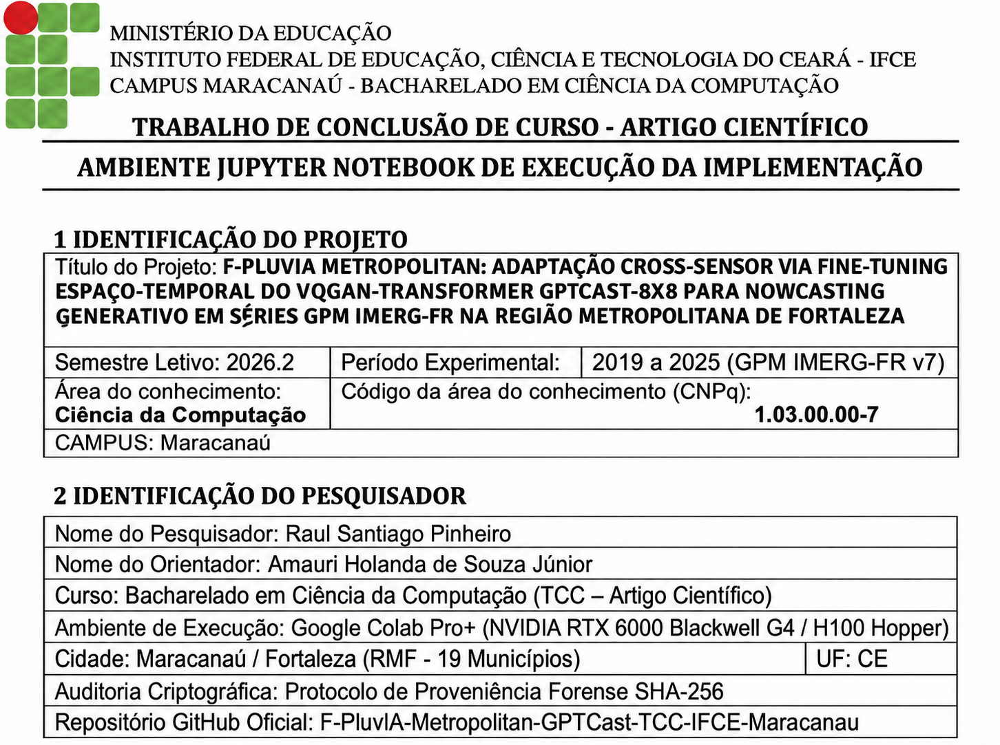

#Agradecimentos e Dedicadória

À meus pais, familiares e comunidade
acadêmica, gratidão e muito obrigado; em especial a minha mãe,
historiadora de graduada de formação, a minha
primeira e mais profunda inspiração nos
estudos, e ao meu pai, falecido em 25
Dezembro de 2023, que me repassou a lição
do apreço por sempre prezar pelo foco no
trabalho quando exercido e ter me perguntado recorrentemente sobre
esse assunto mesmo quando por telefone nós conversavamos,
durante os seus últimos dias no leito do hospital antes de ir a óbito.

“As séries temporais por natureza são um dos
objetos de estudo mais fascinantes e
importantes da ciência da computação. Elas
representam o comportamento dinâmico e
caótico das precipitações pluviométricas como
as chuvas, ou dos mercados financeiros, que
são influenciados por múltiplas variáveis e
fatores
físicos,
políticos,
sociais
químicos,
econômicos,
ou até psicológicos,
dependendo de qual série esteja debruçando a
sua atenção. Prever essas séries é um desafio
fascinante que requer criatividade, intuição,
coragem e conhecimento.”

(Raul S. Pinheiro, trecho do projeto de pesquisa sobre modelos de IA para séries temporais financeiras, produto final da Disciplina Metodologia do Trabalho Científico - IFCE Maracanaú 2023.2 Prof. Darielson de Sousa)

# Sumário : Índice de Execução do Notebook: F-PluvIA Metropolitan

## 🖥️ Este índice consolida o fluxo metodológico, da identificação do hardware ao *deploy* e ao *backup* do modelo generativo de *nowcasting* de precipitação na Região Metropolitana de Fortaleza (RMF).

## 🛠️ I. Ambiente e Hardware
* **Célula 0:** cronômetro de ponta a ponta (tempo de máquina e unidades de computação).
* **Célula (Machine id):** detecção automática do acelerador e do identificador `ENV_TAG`, que separa checkpoints e resultados por GPU.
* **Célula (Security info):** verificação da GPU ativa (`nvidia-smi`).
* **Célula 1:** montagem do Google Drive, pastas da série 2019–2025 e isolamento dos artefatos por `ENV_TAG`.

## 📊 II. Dados (GPM IMERG-FR v7, 2019–2025, malha de 2 km)
* **Célula 2:** ETL mensal do IMERG-FR v7 para a malha de 2 km da RMF, com cache validado por metadados.
* **Célula 3:** janelas de 11 quadros e divisão cronológica estrita: treino 2019–2023, validação 2024 e teste 2025.

## 🧠 III. Ajuste Fino e Diagnóstico (validação de 2024)
* **Célula 4:** ajuste fino do Transformer do GPTCast-8x8 com a VQGAN congelada (tokenização empilhada, lr = 5 × 10⁻⁵, `bf16`, parada antecipada).
* **Célula 4.1:** perda nos *tokens* do modelo ajustado e do *Zero-Shot* nas mesmas janelas, com bootstrap por dias.
* **Célula 4.2:** curvas de treino e de validação e diagnóstico de sobreajuste.
* **Célula 4.3 (opcional):** ajuste fino suave (lr = 1 × 10⁻⁵, validação a cada ¼ de época), não promovido.
* **Célula 4.4:** teto de reconstrução da VQGAN congelada (localização, volume e textura).
* **Célula 4.5:** sensibilidade da decodificação (temperatura, *top-k*, gulosa, média de 8 sorteios) e escolha da decodificação.
* **Célula 4.6 (Cronus):** ajuste do codificador e do decodificador da VQGAN à RMF, com o dicionário fixo.
* **Célula 4.7 (Cronus):** F-PluvIA-VQ, o Transformer reajustado sobre os tokens da VQGAN nova.
* **Célula 4.8 (Cronus):** F-PluvIA-G (V1) × F-PluvIA-VQ na validação de 2024.
* **Célula (Activates Checkpoint):** conferência do checkpoint ativo, parâmetros do modelo e resumo das partições e tempos.

## 🗺️ IV. Estudo de Caso (18/03/2024, validação)
* **Célula 5:** mapas a 2 km sobre os 19 municípios da RMF.
* **Célula 6:** Estágio 1, fidelidade de reconstrução da VQGAN (Tabela 3).
* **Célula 7:** densidade espectral de potência (RAPSD).
* **Célula 8:** verificação orientada a objetos (SAL).
* **Célula 9:** Estágio 2, métricas por horizonte (+30 a +120 min).
* **Célula 10:** comparação de 5 métodos: GPTCast ajustado e *Zero-Shot*, LINDA, Lucas-Kanade e persistência (`pysteps`).
* **Célula 11:** *Fractions Skill Score* (FSS) multiescala.

## 🌧️ V. Teste Independente de 2025 (1.729 janelas, IMERG-FR)
* **Célula 12:** avaliação de F-PluvIA-G (gulosa), F-PluvIA-C8 (média de 8), *Zero-Shot* (*top-k* 10), LINDA, Lucas-Kanade e persistência, com bootstrap por dias.
* **Célula 12.1:** métricas de alerta (Precisão, POD, F1, FAR, CSI) por pixel e por município.
* **Célula 13:** tempo e custo medidos no Colab (unidades de computação).

## 🛰️ VI. Teste Cego de 2026 (fora do período de treino, IMERG-LR)
* **Célula 13.1:** série de fevereiro a maio de 2026 (2.108 janelas) e estudos de caso, comparados com 2025 nos mesmos meses.
* **Célula 13.2:** alertas por município em 2026 × 2025, com intervalos de confiança de 95%.
* **Célula 13.3:** volume de *tokens* processados pelo Transformer em cada etapa e variante.
* **Célula 13.4:** análise de complexidade (Big O) do F-PluvIA-G: recálculo × KV cache.
* **Célula 13.5:** exportação das previsões por município para a interface web.

## 🏁 VII. Duelo do Ambiente Cronus (F-PluvIA-G × F-PluvIA-VQ)
* **Célula 13.6:** troca do modelo ativo para o F-PluvIA-VQ, sem sobrescrever nada da V1.
* **Células 12, 12.1, 13.1 e 13.2 (de novo):** testes de 2025 e 2026 do F-PluvIA-VQ.
* **Célula 13.7:** duelo V1 × VQ, decidido em 2025, e a variante com KV cache dos dois modelos.
* **Célula 13.7.1:** análise de complexidade (Big O) dos dois modelos do duelo.

## 🔍 VIII. Proveniência, *Deploy* e *Backup*
* **Célula (Limpeza de Saídas Obsoletas):** execução única; arquiva as saídas de versões anteriores e as remove do repositório.
* **Célula Extra 1:** rastreabilidade do código original do GPTCast (`DSIP-FBK/GPTCast`).
* **Célula Full UMLs:** diagramas UML gerados do código de cada célula.
* **Célula Extra 2:** manifesto de integridade e proveniência (SHA-256).
* **Célula Base (Pseudo-vista):** pseudo-código de cada célula e cópia do notebook em HTML.
* **Célula (Deploy Automatizado):** envio dos artefatos para o repositório no GitHub.
* **Célula Backup:** pacote `.zip` com notebook, HTML, tabelas, figuras, manifesto e ambiente.
* **Célula (Encerramento do Ambiente Cronus):** resumo do cronômetro e desligamento do ambiente.

# 🛰️ Roteiro do Ambiente de Execução **Cronus** (fork de 22/11/2026): VQGAN ajustada à RMF

O **Cronus** é uma cópia deste notebook, rodada na mesma conta do Colab Pro+ da V1, numa **pasta própria do Drive (`GPTCast_RMF_Cronus`)** que não toca a pasta original `GPTCast_RMF`, para responder a uma pergunta que ficou aberta no TCC: **a VQGAN congelada, pré-treinada com radar italiano, é o gargalo do F-PluvIA?** A Célula 4.4 já indicava que a tradução IMERG → tokens → IMERG perde informação.

### Decisões fixadas antes de rodar (para não usar o resultado para escolher o método)
- **A V1 continua oficial.** O F-PluvIA-G desta cópia é reproduzido do zero e segue sendo o resultado do teste cego de 2026.
- **O modelo novo é um experimento adicional.** O F-PluvIA-VQ só muda a VQGAN: o Transformer parte do mesmo GPTCast-8x8 do Zenodo, com a mesma receita da Célula 4.
- **Toda escolha usa só a validação de 2024**: a época da VQGAN, a época do Transformer e a inclusão ou não do C8.
- **2025 decide o duelo.** O teste de 2026 é relatado com ressalva, porque a VQGAN foi ajustada depois de conhecido o resultado cego da V1.
- **Dados extraídos do zero** pela API (Células 2 e 4), com o cronômetro (Célula 0) medindo da extração aos testes.

### Ordem de execução
| # | Células | O que fazem | Tempo de GPU estimado |
|---|---|---|---|
| 1 | 0, Machine id, Security info, 1 | Cronômetro, Drive e ambiente (`ENV_TAG` com sufixo `_Cronus`) | minutos |
| 2 | 2, 3, 4 | Extração IMERG 2019–2025, partições e ajuste do Transformer da **V1** | ~6 h (ETL) + ~20 min |
| 3 | 4.1, 4.2, 4.4 | Conferências da V1 (4.3 e 4.5 podem ser puladas: as decisões já foram tomadas em 2024 na V1) | ~30 min |
| 4 | **4.6** | **Ajuste da VQGAN** (retomável) | ~2 a 5 h |
| 5 | **4.7** | **F-PluvIA-VQ**: Transformer sobre os tokens novos | ~20 a 40 min |
| 6 | **4.8** | V1 × VQ na validação de 2024 (reconstrução e previsão) | ~15 min |
| 7 | Activates, 5 a 11, 12, 12.1, 13, 13.1, 13.2, 13.3, 13.4, 13.5 | Caminho completo da **V1** (testes 2025 e 2026 com os 6 métodos) | ~12 h |
| 8 | **13.6** | Troca o modelo ativo para o F-PluvIA-VQ | segundos |
| 9 | 4.4 (opcional), 12, 12.1, 13.1, 13.2 | Testes do **F-PluvIA-VQ** (Zero-Shot, LINDA, LK e persistência reaproveitados da V1) | ~2 h (+ ~8 h se o C8 entrar) |
| 10 | **13.7** | **Duelo V1 × VQ** e a **variante com KV cache** do vencedor | ~30 min |
| 11 | Extras, Extra 2, Deploy, Backup | Manifesto, GitHub (repositório novo) e pacote no Drive, com as duas execuções | ~30 min |
| 12 | **Encerramento** | Resumo do cronômetro e desligamento do ambiente | segundos |

Total estimado: **~25 a 35 h de GPU**, cerca de **200 a 270 UC** a 7,7 UC/h, dentro do saldo de ~700 UC. Os tempos reais ficam no cronômetro.

### Segredos do Colab (nunca no código)
`PPS_USERNAME` (e-mail da NASA PPS) e `GITHUB_TOKEN` (token *fine-grained* com acesso de escrita **só** ao repositório `F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau`).


# ⏳ Célula 0: Cronômetro de ponta a ponta (tempo de máquina e unidades de computação)

Esta célula mede o custo computacional de todo o pipeline do **F-PluvIA Metropolitan**, da extração do dataset aos testes. Cada medição é gravada no Google Drive no momento em que acontece.

Ao ser executada, a célula também **monta o Google Drive**. A conta escolhida na janela de autorização é a que guarda os dados desta execução.

### O que é registrado

| Registro | Como | Arquivo no Drive |
|---|---|---|
| Toda célula executada | Automático, pelos eventos `pre_run_cell` / `post_run_cell` do IPython; cada célula recebe a categoria do pipeline a partir do próprio título | `cronometro_celulas.csv` |
| Etapas nomeadas do pipeline | Bloco `with etapa("nome", "categoria"):` | `cronometro_etapas.csv` |
| Saldo real de unidades de computação (UC) | `registrar_saldo_uc(saldo, "observação")`, com o valor lido no painel **Recursos** do Colab | `cronometro_saldo_uc.csv` |

Para cada etapa nomeada, a célula grava:

- início e fim, em UTC;

- duração, em segundos e em minutos;

- pico de memória da GPU, em GB;

- tempo por unidade (por janela ou por mês);

- modo (completo ou amostra);

- UC estimadas, calculadas como duração (h) × taxa (UC/h).

### Categorias (na ordem do pipeline)

1. `1_extracao`: ETL do IMERG Final Run (2019–2025) e do Late Run (2026), com download e reamostragem a 2 km

2. `2_dataset`: montagem das janelas de 11 quadros e das partições

3. `3_treino`: ajuste fino do Transformer

4. `4_validacao`: perdas *Fine-Tuned* × *Zero-Shot* e cada regra de decodificação (validação de 2024)

5. `5_teste_FR`: teste de 2025 (Final Run), com F-PluvIA-G, F-PluvIA-C8 e Zero-Shot

6. `6_teste_LR`: teste cego de 2026 (Late Run), com F-PluvIA-G, F-PluvIA-C8 e Zero-Shot

7. `7_baselines`: persistência, Lucas-Kanade e LINDA (CPU)

8. `8_metricas`: bootstrap, F1 municipal, figuras e tabelas

### Protocolo de medição

- A medição parte da pasta de dados **vazia, sem nenhum cache** (Ambiente de execução → Desconectar e excluir ambiente), para que o ETL seja medido em todos os meses.

- O saldo de UC (Unidades de Computação) é registrado **no início** e **ao fim de cada bloco**. A diferença entre o saldo inicial e o final é o custo **realmente cobrado**, que inclui o tempo de sessão ociosa. As UC por etapa são **estimativas**.

- A taxa usada nas estimativas é a lida no painel **Recursos** para a GPU desta execução: **10,05 UC/h**. Se o painel mostrar outro valor, basta ajustar `TAXA_UC_POR_HORA` (ou a variável de ambiente `FPLUVIA_TAXA_UC_H`). A taxa é a mesma da V1 (o código original da Célula 13 trazia 7,7 UC/h fixo, valor que não correspondia ao painel).

- Outros notebooks abertos na mesma conta do Colab durante a execução consomem do mesmo saldo de UC e distorcem a medição.

- Ao final, `resumo_cronometro()` mostra o total de horas e de UC por categoria e no pipeline inteiro.

### Modo amostra (estimativa em CPU)

O modo amostra estima o custo do pipeline num ambiente **só com CPU**, sem precisar rodá-lo por dias:

1. Num ambiente só com CPU, **antes** da execução desta célula, são definidas três variáveis:
   `FPLUVIA_MODO_AMOSTRA = "1"`, `FPLUVIA_TAXA_UC_H` com a taxa da CPU lida no painel **Recursos** e `FPLUVIA_CRONOMETRO_DIR` com uma pasta própria (por exemplo, `FPluvIA_cronometro_CPU`).

2. Os laços das etapas de GPU passam por `limitar(seq, categoria)`. Cada etapa roda só uma amostra: 20 passos de treino e 5 janelas na validação e em cada teste. A amostra usa **fp32** e **os mesmos nomes de etapa** da execução na GPU.

3. A função `tabela_extrapolacao(csv_gpu, csv_cpu)` compara as duas execuções:
   tempo estimado na CPU = (segundos por unidade na amostra) × (unidades da execução completa na GPU).

Etapas que já rodam em CPU (ETL, persistência, Lucas-Kanade, LINDA, bootstrap) dispensam a amostra: a tabela repete o tempo medido. O resultado é uma **estimativa por extrapolação linear**, válida porque o tempo cresce de forma linear com o número de janelas e de passos (R² ≥ 0,9999 na Célula 13.4).

### Observações

- Os registros são gravados a cada etapa, então nada se perde se a sessão cair.

- A célula não lê Secrets, tokens nem senhas.

- O treino em bf16 na GPU não é totalmente determinístico. Esta execução serve para **medir tempo e custo**; os resultados oficiais do artigo continuam sendo os da execução original.

In [4]:
import os; os.environ.pop("FPLUVIA_TAXA_UC_H", None)

In [5]:
# @title
# Célula 0: Cronômetro de Ponta a Ponta (F-PluvIA Metropolitan) — tempo de máquina e unidades de computação
# Cole no início do notebook e execute antes de qualquer outra célula.
#
# Registra, em CSV no Drive, gravado a cada etapa (nada se perde se a sessão cair):
#   (1) toda célula executada, automaticamente (início, fim, duração);
#   (2) etapas nomeadas, com o bloco  `with etapa("nome", categoria="..."):`
#   (3) o saldo de unidades de computação (UC) lido por você no painel do Colab.
# Sem credenciais: nada aqui lê Secrets, tokens ou senhas.
import csv
import os
import socket
import time
import uuid
from contextlib import contextmanager
# Apelidos privados: outras células fazem `import datetime` e `import time`, que trocariam os nomes globais
# usados pelos registros automáticos desta célula (o erro "module 'datetime' has no attribute 'now'").
from datetime import datetime as _dt_cron, timezone as _tz_cron
import time as _time_cron

# ---- Configuração -----------------------------------------------------------
PASTA_CRONOMETRO = os.environ.get(
    "FPLUVIA_CRONOMETRO_DIR", "/content/drive/MyDrive/GPTCast_RMF_Cronus/cronometro")  # Cronus: pasta própria
TAXA_UC_PADRAO = 10.05  # painel "Recursos" do Colab (G4, 22/11/2026)
_taxa_txt = os.environ.get("FPLUVIA_TAXA_UC_H", "").strip().replace(",", ".")
try:
    TAXA_UC_POR_HORA = float(_taxa_txt) if _taxa_txt else TAXA_UC_PADRAO
except ValueError:  # valor inválido na variável de ambiente (ex.: texto de exemplo): usa o padrão e avisa
    print(f"[cronômetro] FPLUVIA_TAXA_UC_H inválida ({_taxa_txt!r}); usando {TAXA_UC_PADRAO} UC/h.")
    os.environ.pop("FPLUVIA_TAXA_UC_H", None)
    TAXA_UC_POR_HORA = TAXA_UC_PADRAO
SESSAO_ID = _dt_cron.now(_tz_cron.utc).strftime("%Y%m%dT%H%MZ") + "_" + uuid.uuid4().hex[:6]

# MODO AMOSTRA: "1" = cada etapa roda só uma amostra (para medir a CPU e extrapolar).
#               "0" = execução completa (use na GPU).
MODO_AMOSTRA = os.environ.get("FPLUVIA_MODO_AMOSTRA", "0") == "1"
# Tamanho da amostra por categoria, na unidade da etapa (passos, janelas...).
AMOSTRA_N = {"3_treino": 20, "4_validacao": 5, "5_teste_FR": 5, "6_teste_LR": 5}

# Monta o Drive AQUI, antes de criar a pasta: criar /content/drive/... sem o Drive montado
# impediria a montagem da Célula 1 ("Mountpoint must not already contain files").
# A Célula 1 usa drive.mount('/content/drive') sem force_remount, então vira só um aviso.
if PASTA_CRONOMETRO.startswith("/content/drive") and not os.path.ismount("/content/drive"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")  # escolha aqui a conta do Drive desta execução
    except ImportError:
        raise RuntimeError("Fora do Colab: defina FPLUVIA_CRONOMETRO_DIR para uma pasta local.")

os.makedirs(PASTA_CRONOMETRO, exist_ok=True)
ARQ_ETAPAS = os.path.join(PASTA_CRONOMETRO, "cronometro_etapas.csv")
ARQ_CELULAS = os.path.join(PASTA_CRONOMETRO, "cronometro_celulas.csv")
ARQ_SALDO = os.path.join(PASTA_CRONOMETRO, "cronometro_saldo_uc.csv")

try:
    import torch
    _CUDA = torch.cuda.is_available()
except Exception:  # torch ausente ou sem GPU
    torch, _CUDA = None, False

GPU_NOME = torch.cuda.get_device_name(0) if _CUDA else f"CPU ({os.cpu_count()} núcleos lógicos)"
MODO = "amostra" if MODO_AMOSTRA else "completo"


def limitar(seq, categoria):
    """No modo amostra, devolve só os primeiros AMOSTRA_N[categoria] itens de `seq`.
    Uso:  for janela in limitar(janelas_teste, "5_teste_FR"): ...
    Fora do modo amostra (ou categoria sem limite), devolve `seq` inteira."""
    n = AMOSTRA_N.get(categoria) if MODO_AMOSTRA else None
    if n is None:
        return seq
    try:
        return seq[:n]
    except TypeError:  # geradores e iteradores
        import itertools
        return list(itertools.islice(seq, n))


def _agora():
    return _dt_cron.now(_tz_cron.utc).isoformat(timespec="seconds")


def _gravar(arquivo, linha):
    novo = not os.path.exists(arquivo)
    with open(arquivo, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(linha.keys()))
        if novo:
            w.writeheader()
        w.writerow(linha)


# ---- (2) Etapas nomeadas ----------------------------------------------------
@contextmanager
def etapa(nome, categoria="outros", quantidade=None, unidade=""):
    """Uso:
        with etapa("ETL Final Run 2019-2025", categoria="1_extracao", quantidade=28, unidade="meses"):
            ...código da etapa...
    """
    if _CUDA:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    inicio_iso, t0 = _agora(), _time_cron.perf_counter()
    status = "ok"
    try:
        yield
    except BaseException as e:  # registra também interrupções e erros
        status = f"erro: {type(e).__name__}"
        raise
    finally:
        if _CUDA:
            torch.cuda.synchronize()
        dur = _time_cron.perf_counter() - t0
        pico_gb = torch.cuda.max_memory_allocated() / 1e9 if _CUDA else 0.0
        linha = {
            "sessao": SESSAO_ID, "maquina": socket.gethostname(), "gpu": GPU_NOME,
            "modo": MODO, "taxa_uc_h": TAXA_UC_POR_HORA,
            "categoria": categoria, "etapa": nome, "status": status,
            "inicio_utc": inicio_iso, "fim_utc": _agora(),
            "duracao_s": round(dur, 3), "duracao_min": round(dur / 60, 3),
            "pico_vram_gb": round(pico_gb, 3),
            "quantidade": quantidade if quantidade is not None else "", "unidade": unidade,
            "s_por_unidade": round(dur / quantidade, 4) if quantidade else "",
            "uc_estimadas": round(dur / 3600 * TAXA_UC_POR_HORA, 3),
        }
        _gravar(ARQ_ETAPAS, linha)
        print(f"[cronômetro] {nome}: {dur/60:.1f} min | {linha['uc_estimadas']} UC (est.) | {status}")


# ---- (1) Toda célula, automaticamente ----------------------------------------
_estado_celula = {}


def _antes_celula(info=None):
    _estado_celula["t0"] = _time_cron.perf_counter()
    _estado_celula["inicio"] = _agora()
    src = getattr(info, "raw_cell", "") or ""
    # Primeira linha útil: pula o "# @title" que abre quase todas as células deste notebook
    _estado_celula["titulo"] = next((l.strip()[:90] for l in src.splitlines()
                                     if l.strip() and not l.strip().lower().startswith(("# @title", "#@title"))), "")


# Categoria de cada célula do notebook, pelo título (as etapas do pipeline sem precisar de `with etapa(...)`)
CATEGORIAS_POR_TITULO = [
    ("Célula 2:", "1_extracao"), ("Célula 13.1", "6_teste_LR"),
    ("Célula 3:", "2_dataset"),
    ("Célula 4.6", "3_treino"), ("Célula 4.7", "3_treino"), ("Célula 4.3", "3_treino"), ("Célula 4:", "3_treino"),
    ("Célula 4.1", "4_validacao"), ("Célula 4.2", "4_validacao"), ("Célula 4.4", "4_validacao"),
    ("Célula 4.5", "4_validacao"), ("Célula 4.8", "4_validacao"),
    ("Célula 12:", "5_teste_FR"),
    ("Célula 12.1", "8_metricas"), ("Célula 13.2", "8_metricas"), ("Célula 13.7", "8_metricas"),
    ("Célula 13.3", "8_metricas"), ("Célula 13.4", "8_metricas"),
]


def _categoria(titulo):
    for chave, cat in CATEGORIAS_POR_TITULO:
        if chave in titulo:
            return cat
    return "outros"


def _depois_celula(result=None):
    if "t0" not in _estado_celula:
        return
    dur = _time_cron.perf_counter() - _estado_celula.pop("t0")
    erro = getattr(result, "error_in_exec", None) or getattr(result, "error_before_exec", None)
    _gravar(ARQ_CELULAS, {
        "sessao": SESSAO_ID, "gpu": GPU_NOME, "categoria": _categoria(_estado_celula.get("titulo", "")),
        "inicio_utc": _estado_celula.get("inicio"),
        "fim_utc": _agora(), "duracao_s": round(dur, 3),
        "status": "ok" if erro is None else f"erro: {type(erro).__name__}",
        "primeira_linha": _estado_celula.get("titulo", ""),
        "uc_estimadas": round(dur / 3600 * TAXA_UC_POR_HORA, 4),
    })


try:
    _ip = get_ipython()  # noqa: F821 (existe no Colab/Jupyter)
    for ev, fn in (("pre_run_cell", _antes_celula), ("post_run_cell", _depois_celula)):
        try:
            _ip.events.unregister(ev, fn)
        except ValueError:
            pass
        _ip.events.register(ev, fn)
except NameError:
    pass  # fora do Jupyter: só o `with etapa(...)` funciona


# ---- (3) Saldo real de UC, lido no painel do Colab --------------------------
def registrar_saldo_uc(saldo, observacao=""):
    """Leia o saldo em 'Recursos' no Colab e registre: registrar_saldo_uc(487.3, "antes do ETL")."""
    _gravar(ARQ_SALDO, {"sessao": SESSAO_ID, "momento_utc": _agora(),
                        "saldo_uc": saldo, "observacao": observacao})
    print(f"[cronômetro] saldo registrado: {saldo} UC ({observacao})")


# ---- Resumo -------------------------------------------------------------------
def resumo_cronometro():
    import pandas as pd
    if os.path.exists(ARQ_ETAPAS):
        d = pd.read_csv(ARQ_ETAPAS)
    elif os.path.exists(ARQ_CELULAS):   # sem etapas nomeadas: usa o registro automático de cada célula
        d = pd.read_csv(ARQ_CELULAS)
        d = d.assign(etapa=d["primeira_linha"], pico_vram_gb=0.0)
        if "categoria" not in d:
            d["categoria"] = d["primeira_linha"].fillna("").map(_categoria)
        print("(resumo pelo registro automático das células)")
    else:
        print("Nenhuma etapa registrada ainda.")
        return None
    tab = (d.groupby("categoria")
             .agg(etapas=("etapa", "count"), horas=("duracao_s", lambda s: s.sum() / 3600),
                  uc_estimadas=("uc_estimadas", "sum"), pico_vram_gb=("pico_vram_gb", "max"))
             .round(3))
    tab.loc["TOTAL"] = [tab.etapas.sum(), tab.horas.sum(), tab.uc_estimadas.sum(), tab.pico_vram_gb.max()]
    print(tab.to_string())
    if os.path.exists(ARQ_SALDO):
        s = pd.read_csv(ARQ_SALDO)
        if len(s) >= 2:
            print(f"\nUC realmente debitadas (saldo inicial − atual): "
                  f"{s.saldo_uc.iloc[0] - s.saldo_uc.iloc[-1]:.2f} UC")
    return tab


def tabela_extrapolacao(csv_gpu, csv_cpu, taxa_uc_cpu=None):
    """Compara a execução completa na GPU com a amostra na CPU, etapa a etapa (pelo nome).
    Tempo extrapolado na CPU = (s por unidade na CPU) × (unidades totais da execução na GPU).
    Etapas sem `quantidade` não são extrapoladas (ficam com o tempo medido na GPU)."""
    import pandas as pd
    g = pd.read_csv(csv_gpu)
    c = pd.read_csv(csv_cpu)
    g = g[g.status == "ok"].groupby("etapa", sort=False).last()
    c = c[c.status == "ok"].groupby("etapa", sort=False).last()
    taxa_cpu = taxa_uc_cpu if taxa_uc_cpu is not None else float(c["taxa_uc_h"].iloc[0])
    linhas = []
    for etapa_nome, rg in g.iterrows():
        q = pd.to_numeric(rg.get("quantidade"), errors="coerce")
        s_gpu = rg["duracao_s"]
        if etapa_nome in c.index and pd.notna(q) and q > 0:
            rc = c.loc[etapa_nome]
            spu_cpu = pd.to_numeric(rc.get("s_por_unidade"), errors="coerce")
            s_cpu = spu_cpu * q if pd.notna(spu_cpu) else float("nan")
            origem = "extrapolado da amostra na CPU"
        else:
            s_cpu, origem = s_gpu, "sem amostra: tempo da GPU repetido"
        linhas.append({
            "categoria": rg["categoria"], "etapa": etapa_nome,
            "unidades": q, "h_gpu": s_gpu / 3600, "h_cpu_est": s_cpu / 3600,
            "razao_cpu_gpu": s_cpu / s_gpu if s_gpu else float("nan"),
            "uc_gpu": rg["uc_estimadas"], "uc_cpu_est": s_cpu / 3600 * taxa_cpu,
            "origem": origem,
        })
    t = pd.DataFrame(linhas)
    tot = t[["h_gpu", "h_cpu_est", "uc_gpu", "uc_cpu_est"]].sum()
    print(t.round(3).to_string(index=False))
    print(f"\nTOTAL  GPU: {tot.h_gpu:.1f} h, {tot.uc_gpu:.1f} UC  |  "
          f"CPU (estimado): {tot.h_cpu_est:.1f} h (≈ {tot.h_cpu_est/24:.1f} dias), {tot.uc_cpu_est:.1f} UC")
    return t


print(f"[cronômetro] ativo | sessão {SESSAO_ID} | {GPU_NOME} | taxa {TAXA_UC_POR_HORA} UC/h | modo {MODO}")
print(f"[cronômetro] registros em {PASTA_CRONOMETRO}")

# =============================================================================
# CATEGORIAS SUGERIDAS (use estes nomes para o resumo sair na ordem do pipeline)
#   1_extracao      ETL IMERG Final Run 2019-2025 e Late Run 2026 (download + 2 km)
#   2_dataset       montagem das janelas de 11 quadros e partições
#   3_treino        ajuste fino (e o ajuste alternativo, se rodar)
#   4_validacao     perdas Fine-Tuned × Zero-Shot e cada regra de decodificação
#   5_teste_FR      teste 2025 (Final Run): F-PluvIA-G, C8, Zero-Shot
#   6_teste_LR      teste cego 2026 (Late Run): F-PluvIA-G, C8, Zero-Shot
#   7_baselines     persistência, Lucas-Kanade, LINDA (CPU)
#   8_metricas      bootstrap, F1 municipal, figuras e tabelas
#
# EXEMPLOS
#   registrar_saldo_uc(500.0, "início, Drive vazio")
#   with etapa("ETL Final Run 2019-2025", "1_extracao", quantidade=28, unidade="meses"): ...
#   for regra in regras:
#       with etapa(f"Validação 2024 – {regra}", "4_validacao", quantidade=240, unidade="janelas"): ...
#   with etapa("Teste cego 2026 – F-PluvIA-C8", "6_teste_LR", quantidade=2110, unidade="janelas"): ...
#   resumo_cronometro()
#
# MODO AMOSTRA (ambiente só com CPU)
#   import os; os.environ["FPLUVIA_MODO_AMOSTRA"] = "1"; os.environ["FPLUVIA_TAXA_UC_H"] = "<taxa da CPU>"
#   os.environ["FPLUVIA_CRONOMETRO_DIR"] = "/content/drive/MyDrive/FPluvIA_cronometro_CPU"
#   (defina ANTES de executar esta célula; use os MESMOS nomes de etapa da execução na GPU)
#   with etapa("Teste 2025 – F-PluvIA-G", "5_teste_FR", quantidade=len(limitar(janelas, "5_teste_FR")), unidade="janelas"):
#       for j in limitar(janelas, "5_teste_FR"): ...
#   Na CPU, rode em fp32 (sem autocast bf16).
#
# EXTRAPOLAÇÃO (depois das duas execuções)
#   tabela_extrapolacao("/content/drive/MyDrive/FPluvIA_cronometro/cronometro_etapas.csv",
#                       "/content/drive/MyDrive/FPluvIA_cronometro_CPU/cronometro_etapas.csv")
# =============================================================================


Mounted at /content/drive
[cronômetro] ativo | sessão 20261124T1056Z_56df08 | NVIDIA RTX PRO 6000 Blackwell Server Edition | taxa 10.05 UC/h | modo completo
[cronômetro] registros em /content/drive/MyDrive/GPTCast_RMF_Cronus/cronometro


In [6]:
registrar_saldo_uc(557.09, "reinício do cronômetro, antes da Célula 2")

[cronômetro] saldo registrado: 557.09 UC (reinício do cronômetro, antes da Célula 2)


In [7]:
# @title
# Célula auxiliar (Cronus) — Diagnóstico de retomada após desconexão (só leitura)
# Não grava nem apaga nada. Rode logo depois de montar o Drive (Célula 0 ou 1).
import os, glob, json, time
import pandas as pd
from google.colab import drive
if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/GPTCast_RMF_Cronus'
HORAS = 14   # janela: arquivos alterados nas últimas HORAS horas
agora = time.time()

def ler_json(padrao):
    achados = sorted(glob.glob(os.path.join(BASE, '**', padrao), recursive=True))
    for a in achados:
        print(f'\n--- {a.replace(BASE, "…")}')
        try:
            with open(a) as f:
                d = json.load(f)
            for k, v in d.items():
                if not isinstance(v, (list, dict)):
                    print(f'  {k}: {v}')
        except Exception as e:
            print('  (não foi possível ler)', e)
    if not achados:
        print(f'\n--- nenhum arquivo {padrao}')

print('=== 1. Arquivos alterados nas últimas', HORAS, 'h (mais recentes primeiro) ===')
recentes = []
for raiz, _, arqs in os.walk(BASE):
    for a in arqs:
        p = os.path.join(raiz, a)
        try:
            m = os.path.getmtime(p)
        except OSError:
            continue
        if agora - m < HORAS * 3600:
            recentes.append((m, p, os.path.getsize(p)))
for m, p, s in sorted(recentes, reverse=True)[:40]:
    print(f'{time.strftime("%d/%m %H:%M", time.localtime(m - 3 * 3600))}  {s / 1e6:9.1f} MB  {p.replace(BASE, "…")}')

print('\n=== 2. Célula 4.6 (VQGAN) ===')
for padrao in ('vqgan_rmf_2km_*_melhor.pt', 'vqgan_rmf_2km_*_ultima.pt'):
    for a in glob.glob(os.path.join(BASE, '**', padrao), recursive=True):
        print(f'{padrao.split("_")[-1]:10s} {os.path.getsize(a) / 1e6:8.1f} MB  '
              f'{time.strftime("%d/%m %H:%M", time.localtime(os.path.getmtime(a) - 3 * 3600))}')
ler_json('registro_vqgan_*.json')
for a in glob.glob(os.path.join(BASE, '**', 'curva_ajuste_vqgan_*.csv'), recursive=True):
    print('\nCurva por época:')
    print(pd.read_csv(a).to_string(index=False))

print('\n=== 3. Célula 4.7 (Transformer do F-PluvIA-VQ) ===')
ler_json('registro_treino_fpluvia_vq_*.json')

print('\n=== 4. Célula 4.8 (validação 2024, V1 × VQ) ===')
ler_json('cronus_previsao_v1_vs_vq_validacao2024_*.json')

print('\n=== 5. Cronômetro (últimas células registradas) ===')
for a in glob.glob(os.path.join(BASE, 'cronometro', '*celulas*.csv')):
    df = pd.read_csv(a)
    print(df.tail(15).to_string(index=False))


=== 1. Arquivos alterados nas últimas 14 h (mais recentes primeiro) ===
24/11 07:56        0.0 MB  …/cronometro/cronometro_saldo_uc.csv
24/11 07:56        0.0 MB  …/cronometro/cronometro_celulas.csv
24/11 03:28       12.6 MB  …/Pseudo-códigos/exec_Cronus_F_PluvIA_VQGAN_RMF_pseudo_vista.html
24/11 03:28        0.0 MB  …/Pseudo-códigos/50_celula_encerramento_do_ambiente_cronus.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/49_celula_backup.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/48_celula_deploy_automatizado.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/47_celula_base_pseudo_vista.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/46_celula_extra_2.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/45_celula_full_umls.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/44_celula_extra_1.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/43_celula_13_7_1_cronus.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/42_celula_13_7_cronus.txt
24/11 03:28        0.0 MB  …/Pseudo-códigos/41

# 🚩Célula (Machine id): Detecção Automática do Ambiente de Execução - Identidade de Hardware e Isolamento de Artefatos na Memória (`ENV_TAG`)

- **Identificação Dinâmica da Arquitetura de GPU na Memória Global**: Consulta em tempo de execução a interface CUDA via PyTorch (`torch.cuda.get_device_name(0)` e `torch.cuda.get_device_properties(0)`) e o driver NVIDIA (`nvidia-smi`), definindo automaticamente na memória global os identificadores canônicos do acelerador ativo (`ENV_TAG`, como `G4_RTX6000_Blackwell_95GB` ou `H100_Hopper_80GB`, e o rótulo descritivo `ENV_LABEL`).

- **Auditoria de VRAM Dedicada e Precisão Nativa (`BF16` / `FP32`)**: Mede a capacidade total de memória de vídeo em GiB, verifica o suporte nativo de hardware ao formato de ponto flutuante `bfloat16` (`torch.cuda.is_bf16_supported()`) e fixa o dispositivo de computação (`device = 'cuda'`), parametrizando a alocação de tensores do modelo **GPTCast-8x8** nas etapas subsequentes.

- **Roteamento e Isolamento de Diretórios de Exportação (`RESULTS_ENV_DIR`)**: Inicializa em disco o diretório exclusivo para a placa detectada (`RESULTS_ENV_DIR = os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}')`), evitando a sobrescrita cruzada de tabelas (`.csv`) e painéis cartográficos (`300 dpi`) entre execuções comparativas realizadas em GPUs distintas no Google Colab Pro+.

- **Rastreabilidade Forense Intercélulas**: Propaga a identidade do ambiente ativo para todas as células de *fine-tuning*, inferência, avaliação comparativa e geração do certificado de proveniência SHA-256 (Célula Extra 2), assegurando reprodutibilidade auditável para esse Trabalho de Conclusão de Curso - TCC de Graduação em Ciência da Computação no IFCE Campus Maracanaú.

In [7]:
# @title
# Célula (Machine id): Detecção Automática do Ambiente de Execução - Identidade de Hardware e Isolamento de Artefatos na Memória (`ENV_TAG`)
import torch

if torch.cuda.is_available():
  dev_name = torch.cuda.get_device_name(0)
  vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)

  if 'H100' in dev_name:
    ENV_TAG = 'H100_Hopper_80GB'
    ENV_LABEL = 'NVIDIA H100 (Hopper 80 GB)'
  elif '6000' in dev_name or 'Blackwell' in dev_name:
    ENV_TAG = 'G4_RTX6000_Blackwell_95GB'
    ENV_LABEL = 'NVIDIA RTX PRO 6000 Blackwell (95 GB)'
  else:
    ENV_TAG = dev_name.replace(' ', '_')
    ENV_LABEL = dev_name
else:
  ENV_TAG = 'CPU_Padrao'
  ENV_LABEL = 'CPU Padrão'

print(f'[Rastreabilidade Ativa] Ambiente detectado: {ENV_LABEL}')
print(f'[Rastreabilidade Ativa] Tag de identificação: {ENV_TAG}')

[Rastreabilidade Ativa] Ambiente detectado: NVIDIA RTX PRO 6000 Blackwell (95 GB)
[Rastreabilidade Ativa] Tag de identificação: G4_RTX6000_Blackwell_95GB


### 🖥️ Célula (Security info) : Verificação de Hardware e Unidade de Processamento Ativa (`nvidia-smi`)

Esta célula realiza a telemetria do ambiente de execução do Google Colab Pro+, validando a presença de aceleradores NVIDIA (como a **NVIDIA H100 Hopper** ou a **RTX 6000 Blackwell G4**), a capacidade total de VRAM dedicada e o status operacional dos drivers CUDA.

In [10]:
# @title
# Célula (Security info) : Verificação de Hardware e Unidade de Processamento Ativa (`nvidia-smi`)
# ==============================================================================
# AUDITORIA DE HARDWARE: Verificação de Unidade de Processamento (GPU / CUDA)
# ==============================================================================

import subprocess
import torch

print("=" * 70)
print("RELATÓRIO DE TELEMETRIA DO AMBIENTE DE EXECUÇÃO COLAB")
print("=" * 70)

cuda_status = torch.cuda.is_available()
print(f"[*] CUDA Disponível: {cuda_status}")

if cuda_status:
  device_name = torch.cuda.get_device_name(0)
  total_vram_gb = round(
      torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
  )
  bf16_support = torch.cuda.is_bf16_supported()

  print(f"[*] GPU Atribuída (PyTorch): {device_name}")
  print(f"[*] VRAM Total Dedicada: {total_vram_gb} GiB")
  print(f"[*] Suporte Nativo a BF16: {bf16_support}")
  print("-" * 70)
  print("[*] Relatório Detalhado do Driver (nvidia-smi):")
  try:
    subprocess.run(["nvidia-smi"], check=True)
  except Exception as e:
    print(f"[AVISO] Não foi possível executar o nvidia-smi: {e}")
else:
  print(
      "[!] ATENÇÃO: Nenhuma GPU detectada. O ambiente está rodando apenas em"
      " CPU."
  )
print("=" * 70)

RELATÓRIO DE TELEMETRIA DO AMBIENTE DE EXECUÇÃO COLAB
[*] CUDA Disponível: True
[*] GPU Atribuída (PyTorch): NVIDIA RTX PRO 6000 Blackwell Server Edition
[*] VRAM Total Dedicada: 94.97 GiB
[*] Suporte Nativo a BF16: True
----------------------------------------------------------------------
[*] Relatório Detalhado do Driver (nvidia-smi):


# Célula 1: Preparação do Ambiente, Isolamento no Google Drive (Série 2019–2025) e Rastreabilidade por Hardware (GPU G4 Blackwell vs. GPU H100 Hopper)

* **Padronização Cronológica (2019–2025)**: Define o diretório oficial `series_2019_2025_2km` para armazenar os 28 meses das quadras chuvosas (Treino: 2019–2023 | Validação: 2024 | Teste: 2025).

* **Identificação Automática do Ambiente (`ENV_TAG` e `ENV_LABEL`)**: Detecta o acelerador ativo (`G4_RTX6000_Blackwell_95GB`, `H100_Hopper_80GB` ou `CPU_Padrao`) e isola os checkpoints e relatórios de cada GPU em pastas próprias, sem sobrescrever resultados anteriores.

* **Isolamento do Ambiente Cronus**: Neste fork, a pasta de trabalho é `GPTCast_RMF_Cronus` e o `ENV_TAG` recebe o sufixo `_Cronus`. A pasta do F-PluvIA-G (`GPTCast_RMF`) é só lida, nunca gravada.

In [1]:
# @title
# Célula 1: Preparação do Ambiente, Montagem do Google Drive (2019-2025) e Rastreabilidade por Hardware (G4 vs. H100)
import functools
import glob
import os
import shutil
import subprocess
import sys
from google.colab import drive

# 1. Montagem do Google Drive
drive.mount('/content/drive')

# 2. Definição estrita das pastas dedicadas para a Série Plurianual (2019-2025)
# Cronus: raiz PRÓPRIA no mesmo Drive da V1. Nada é lido nem gravado em GPTCast_RMF (a pasta original do TCC):
# a série é extraída do zero, e checkpoints, previsões e tabelas ficam todos dentro de GPTCast_RMF_Cronus.
BASE_WORK_DIR = '/content/drive/MyDrive/GPTCast_RMF_Cronus'
PASTA_V1_PROTEGIDA = '/content/drive/MyDrive/GPTCast_RMF'
if os.path.realpath(BASE_WORK_DIR) == os.path.realpath(PASTA_V1_PROTEGIDA):
  raise RuntimeError('BASE_WORK_DIR aponta para a pasta da V1: o Cronus não pode gravar em GPTCast_RMF.')
OLD_SERIES_DIR = os.path.join(BASE_WORK_DIR, 'series_2020_2026_2km')
SERIES_CACHE_DIR = os.path.join(BASE_WORK_DIR, 'series_2019_2025_2km')
CHECKPOINTS_DIR = os.path.join(BASE_WORK_DIR, 'checkpoints_rmf_finetuned')
GPM_RAW_TEMP_DIR = '/content/tmp_gpm_raw/GPM'  # SSD local da VM (terminado em /GPM conforme exigido pela gpm-api)

# Migração transparente caso a pasta antiga ainda exista no Drive
if os.path.exists(OLD_SERIES_DIR) and not os.path.exists(SERIES_CACHE_DIR):
  os.rename(OLD_SERIES_DIR, SERIES_CACHE_DIR)

for directory in [
    BASE_WORK_DIR,
    SERIES_CACHE_DIR,
    CHECKPOINTS_DIR,
    GPM_RAW_TEMP_DIR,
]:
  os.makedirs(directory, exist_ok=True)

# 3. Clonagem do repositório oficial GPTCast e inclusão no path de execução
if not os.path.exists('/content/GPTCast'):
  subprocess.run(
      [
          'git',
          'clone',
          'https://github.com/DSIP-FBK/GPTCast.git',
          '/content/GPTCast',
      ],
      check=True,
  )
if '/content/GPTCast' not in sys.path:
  sys.path.append('/content/GPTCast')

# 4. Instalação consolidada de todas as dependências científicas e geoespaciais
try:
  import cartopy
  import geopandas
  import gpm
  import lightning
  import pysteps

  print('[Setup] Bibliotecas científicas e geoespaciais já instaladas na VM.')
except ImportError:
  print(
      '[Setup] A instalar bibliotecas científicas, utilitários geoespaciais e'
      ' Lightning...'
  )
  subprocess.run(
      [
          sys.executable,
          '-m',
          'pip',
          'install',
          '-q',
          'pandas==2.2.3',
          'python-dateutil>=2.8.2,<3',
          'gpm-api',
          'xarray',
          'netCDF4',
          'h5netcdf',
          'scipy',
          'einops',
          'lightning',
          'pytorch-lightning',
          'hydra-core',
          'omegaconf',
          'cartopy',
          'geopandas',
          'pysteps',
      ],
      check=True,
  )

# 5. Desbloqueio do PyTorch 2.6+ para carregar checkpoints do Zenodo/Lightning
import torch

os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'

if not getattr(torch.load, '_is_patched_for_gptcast', False):
  _orig_torch_load = torch.load

  @functools.wraps(_orig_torch_load)
  def _trusted_torch_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return _orig_torch_load(*args, **kwargs)

  _trusted_torch_load._is_patched_for_gptcast = True
  torch.load = _trusted_torch_load
  torch.serialization.load = _trusted_torch_load

# 6. Deteção de Hardware (G4 Blackwell vs. H100 Hopper vs. CPU) e Isolamento de Artefatos
gpu_available = torch.cuda.is_available()
if gpu_available:
  torch.set_float32_matmul_precision('high')
  torch.backends.cudnn.benchmark = True
  gpu_device_name = torch.cuda.get_device_name(0)
  vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
  bf16_ok = torch.cuda.is_bf16_supported()

  if 'H100' in gpu_device_name.upper():
    ENV_TAG = 'H100_Hopper_80GB'
    ENV_LABEL = f'{gpu_device_name} ({vram_gb:.1f} GB)'
  elif '6000' in gpu_device_name.upper() or 'BLACKWELL' in gpu_device_name.upper():
    ENV_TAG = 'G4_RTX6000_Blackwell_95GB'
    ENV_LABEL = f'{gpu_device_name} ({vram_gb:.1f} GB)'
  elif 'A100' in gpu_device_name.upper():
    ENV_TAG = f'A100_{int(round(vram_gb))}GB'
    ENV_LABEL = f'{gpu_device_name} ({vram_gb:.1f} GB)'
  elif 'L4' in gpu_device_name.upper():
    ENV_TAG = 'L4_Ada_24GB'
    ENV_LABEL = f'{gpu_device_name} ({vram_gb:.1f} GB)'
  else:
    ENV_TAG = (
        gpu_device_name.replace(' ', '_').replace('-', '_')
        + f'_{int(round(vram_gb))}GB'
    )
    ENV_LABEL = f'{gpu_device_name} ({vram_gb:.1f} GB)'
else:
  gpu_device_name = 'Nenhuma GPU detetada (CPU Padrão)'
  vram_gb = 0.0
  bf16_ok = False
  ENV_TAG = 'CPU_Padrao'
  ENV_LABEL = 'CPU Padrão (Google Colab VM)'

# Ambiente de execução Cronus (fork de 22/11/2026, conta nova do Drive, VAZIA): tudo do zero — extração do IMERG pela
# API, partições, ajuste da V1 (reprodução do F-PluvIA-G com a mesma receita) e o F-PluvIA-VQ. O sufixo separa as
# saídas desta execução das da V1 original. Use SUFIXO_CRONUS = '' só se a pasta GPTCast_RMF da V1 for copiada para
# esta conta (aí a Célula 4 carrega o checkpoint oficial e as Células 12 e 13.1 reaproveitam as previsões da V1).
AMBIENTE_EXECUCAO = 'Cronus'
SUFIXO_CRONUS = '_Cronus'
# Se o Colab der outra GPU, a etiqueta mudaria e a V1 copiada não seria encontrada (a Célula 4 retreinaria tudo).
# Por isso a etiqueta da V1 é mantida quando a pasta dela existe; o ENV_LABEL continua mostrando a GPU real.
ENV_TAG_V1 = 'G4_RTX6000_Blackwell_95GB'
if not SUFIXO_CRONUS and ENV_TAG != ENV_TAG_V1 and os.path.isdir(os.path.join(CHECKPOINTS_DIR, ENV_TAG_V1)):
  print(f'[Aviso Cronus] GPU desta sessão: {ENV_LABEL}. Mantendo a etiqueta da V1 ({ENV_TAG_V1}) para usar o '
        'checkpoint e as previsões copiados; os tempos medidos agora não são comparáveis com os da V1.')
  ENV_TAG = ENV_TAG_V1
ENV_TAG = f'{ENV_TAG}{SUFIXO_CRONUS}'
ENV_LABEL = f'{ENV_LABEL} · {AMBIENTE_EXECUCAO}'
CRONUS_TEMPO_MAX_MIN = 10**6   # Célula 13.1: todas as janelas de 2026 numa execução só (sem o orçamento de 120 min)

# Subpastas isoladas por Ambiente de Execução (evita sobrescrever pesos e tabelas entre G4 e H100)
CHECKPOINTS_ENV_DIR = os.path.join(CHECKPOINTS_DIR, ENV_TAG)
RESULTS_ENV_DIR = os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}')
os.makedirs(CHECKPOINTS_ENV_DIR, exist_ok=True)
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)

# Preserva na subpasta da G4 o checkpoint já treinado na raiz de CHECKPOINTS_DIR
if ENV_TAG == 'G4_RTX6000_Blackwell_95GB':
  for ckpt_f in glob.glob(os.path.join(CHECKPOINTS_DIR, '*.ckpt')):
    dst_ckpt = os.path.join(CHECKPOINTS_ENV_DIR, os.path.basename(ckpt_f))
    if not os.path.exists(dst_ckpt):
      shutil.copy2(ckpt_f, dst_ckpt)

print('\n=== Ambiente Model_Annual_Full_Training_Series (2019–2025) Pronto ===')
print(f'Diretório Base: {BASE_WORK_DIR}  (a pasta da V1, {PASTA_V1_PROTEGIDA}, não é tocada)')
print(f'Cache da Série (2 km): {SERIES_CACHE_DIR}')
print(f'Checkpoints do Ambiente ({ENV_TAG}): {CHECKPOINTS_ENV_DIR}')
print(f'Resultados do Ambiente ({ENV_TAG}): {RESULTS_ENV_DIR}')
print(f'Diretório Temporário Local: {GPM_RAW_TEMP_DIR}')
print(
    f'Acelerador Ativo: {gpu_device_name} | Tag: {ENV_TAG} | VRAM:'
    f' {vram_gb:.1f} GB | Suporte BF16: {bf16_ok}'
)

Mounted at /content/drive
[Setup] A instalar bibliotecas científicas, utilitários geoespaciais e Lightning...

=== Ambiente Model_Annual_Full_Training_Series (2019–2025) Pronto ===
Diretório Base: /content/drive/MyDrive/GPTCast_RMF_Cronus  (a pasta da V1, /content/drive/MyDrive/GPTCast_RMF, não é tocada)
Cache da Série (2 km): /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km
Checkpoints do Ambiente (G4_RTX6000_Blackwell_95GB_Cronus): /content/drive/MyDrive/GPTCast_RMF_Cronus/checkpoints_rmf_finetuned/G4_RTX6000_Blackwell_95GB_Cronus
Resultados do Ambiente (G4_RTX6000_Blackwell_95GB_Cronus): /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus
Diretório Temporário Local: /content/tmp_gpm_raw/GPM
Acelerador Ativo: NVIDIA RTX PRO 6000 Blackwell Server Edition | Tag: G4_RTX6000_Blackwell_95GB_Cronus | VRAM: 95.0 GB | Suporte BF16: True


### 🧪 Célula auxiliar (Cronus): cópia somente-leitura dos caches da V1

O arquivo de produção do NASA PPS (`arthurhou`) ficou indisponível durante a extração. Por isso, esta célula copia os arquivos `.npz` já processados da série 2019–2025 a partir da pasta da V1 (`GPTCast_RMF`) para a pasta do Cronus (`GPTCast_RMF_Cronus`).

A cópia apenas lê da pasta da V1. Ela não sobrescreve arquivos já existentes no destino e grava cada arquivo primeiro como `.part`, renomeando só ao final, para evitar cópias incompletas.

Assim, V1 e F-PluvIA-VQ partem exatamente da mesma série de dados. O tempo de extração considerado é o já registrado na execução da V1.

In [9]:
# @title
# Célula auxiliar (Cronus - Somente Leitura) — Cópia dos caches .npz da V1
# Lê de GPTCast_RMF (V1) e grava apenas em GPTCast_RMF_Cronus.
# Nunca sobrescreve: arquivo já existente no destino é mantido.
import os, glob, shutil, time

ORIGEM_V1 = '/content/drive/MyDrive/GPTCast_RMF'
DESTINO   = BASE_WORK_DIR  # definido na Célula 1 (GPTCast_RMF_Cronus)

if os.path.realpath(DESTINO) == os.path.realpath(ORIGEM_V1):
    raise RuntimeError('Destino igual à pasta da V1: abortado.')

# Subpastas de cache a copiar (só .npz). Ajuste se o listado abaixo mostrar outro nome.
SUBPASTAS = ['series_2019_2025_2km']
SO_LISTAR = True   # 1ª execução: só lista. Depois mude para False e rode de novo.

print('Pastas de primeiro nível na V1:')
for p in sorted(os.listdir(ORIGEM_V1)):
    if os.path.isdir(os.path.join(ORIGEM_V1, p)):
        n = len(glob.glob(os.path.join(ORIGEM_V1, p, '*.npz')))
        print(f'  {p:45s} {n:5d} .npz')

t0 = time.time()
for sub in SUBPASTAS:
    src_dir = os.path.join(ORIGEM_V1, sub)
    dst_dir = os.path.join(DESTINO, sub)
    arquivos = sorted(glob.glob(os.path.join(src_dir, '*.npz')))
    tam_gb = sum(os.path.getsize(a) for a in arquivos) / 1e9
    print(f'\n[{sub}] {len(arquivos)} arquivos .npz, {tam_gb:.2f} GB')
    if SO_LISTAR or not arquivos:
        continue
    os.makedirs(dst_dir, exist_ok=True)
    copiados = pulados = 0
    for a in arquivos:
        alvo = os.path.join(dst_dir, os.path.basename(a))
        if os.path.exists(alvo) and os.path.getsize(alvo) == os.path.getsize(a):
            pulados += 1
            continue
        shutil.copy2(a, alvo + '.part')
        os.replace(alvo + '.part', alvo)
        copiados += 1
    print(f'  copiados: {copiados} | já existiam: {pulados}')
    n_dst = len(glob.glob(os.path.join(dst_dir, '*.npz')))
    assert n_dst >= len(arquivos), f'Destino com {n_dst} de {len(arquivos)} arquivos.'

print(f'\nTempo: {(time.time() - t0) / 60:.1f} min'
      + (' (modo listagem: nada foi copiado)' if SO_LISTAR else ''))


Pastas de primeiro nível na V1:
  GPM                                               0 .npz
  Pseudo-códigos                                   0 .npz
  checkpoints_rmf_finetuned                         0 .npz
  gpm_data                                          0 .npz
  miarad_adapted                                    4 .npz
  series_2019_2025_2km                             30 .npz

[series_2019_2025_2km] 30 arquivos .npz, 1.39 GB

Tempo: 0.0 min (modo listagem: nada foi copiado)


# 🧹 Célula (Limpeza de Saídas Obsoletas): Arquivamento no Drive e Remoção do Repositório Público das Saídas de Versões Anteriores (`ENV_TAG` | execução única)

* **Por que existe**: A pasta de resultados ainda guardava **38 saídas de versões anteriores** do projeto, geradas antes do checkpoint atual (`20261116T2123Z`) ou por células removidas: a avaliação antiga de 30 janelas, a comparação com órgãos e instituições (célula removida; números não verificados), versões antigas do teste cego de 2026 e diagnósticos de 11/11/2026. O Deploy e o Backup copiam tudo o que está na pasta, então essas saídas continuavam indo para o repositório público e para os pacotes.

* **O que faz no Drive**: Move esses arquivos para `arquivo_versoes_anteriores_<ENV_TAG>`, **fora** de `RESULTS_ENV_DIR`, com um registro `.csv` do que foi movido e um `LEIA-ME.txt`. **Nada é apagado.** Um arquivo com data posterior ao checkpoint atual nunca é tocado, mesmo que o nome esteja na lista.

* **O que faz no GitHub**: Remove os mesmos arquivos de `results/<ENV_TAG>/` num único *commit* explicativo. O histórico do Git continua mostrando as versões antigas, como registro.

* **Segurança**: Lista fixa de 38 nomes exatos (nenhum resultado da execução final, com sufixo `_amostragem2024_media8`, pode entrar nela). A primeira execução, com `SO_LISTAR = True`, **só mostra** o que seria feito; para executar, mude para `False` e rode de novo. O token vem dos Segredos do Colab (`GITHUB_TOKEN`) e nunca aparece na saída.

* **No ambiente Cronus**: A pasta `GPTCast_RMF_Cronus` começou vazia, então não há saídas antigas a arquivar. A célula fica em modo de listagem (`SO_LISTAR = True`, `LIMPAR_GITHUB = False`) e só confirma isso.

In [ ]:
# @title
# Célula (Limpeza de Saídas Obsoletas): arquiva no Drive e remove do repositório público as 38 saídas de versões
# anteriores do projeto (antes do checkpoint atual 20261116T2123Z): avaliação antiga de 30 janelas, comparação com
# órgãos/instituições (célula removida), versões antigas do teste cego de 2026 e diagnósticos de 11/11/2026.
# Nada é apagado do Drive: os arquivos vão para arquivo_versoes_anteriores_<ENV_TAG>, fora da pasta de resultados,
# e deixam de entrar no Deploy, no Backup e no manifesto SHA-256.
import base64
import datetime
import os
import shutil
import subprocess
from pathlib import Path

import pandas as pd

ENV_TAG = globals().get('ENV_TAG', 'G4_RTX6000_Blackwell_95GB')
SERIES_CACHE_DIR = globals().get('SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
RESULTS_ENV_DIR = Path(globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}')))

# ------------------------------------------------------------------- 1. configuração
SO_LISTAR = True   # Cronus: só lista (a limpeza já foi feita na V1)
_SO_LISTAR_V1 = False            # 1ª execução: só mostra o que seria feito. Confira e rode de novo com False.
LIMPAR_GITHUB = False   # Cronus: repositório novo, nada a limpar
_LIMPAR_GITHUB_V1 = True        # também remove os mesmos arquivos do repositório público (um commit)
REPO_URL = 'https://github.com/raulspinheiro/F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau.git'   # Cronus
GIT_USER_NAME = 'raulspinheiro'
GIT_USER_EMAIL = 'raulspinheiro@users.noreply.github.com'
ARQUIVO_DIR = Path(SERIES_CACHE_DIR) / f'arquivo_versoes_anteriores_{ENV_TAG}'
CORTE_UTC = datetime.datetime(2026, 11, 16, 21, 23)   # treino do checkpoint ativo; arquivo mais novo que isso não é tocado

OBSOLETOS = [n.format(ENV=ENV_TAG) for n in (
    # avaliação antiga com 30 janelas (substituída pela Célula 12 com 1.729 janelas)
    'benchmark_agregado_teste2025_imerg_fr_2km_{ENV}_N30.csv', 'velocidade_inferencia_teste2025_{ENV}_N30.csv',
    'fpluvia_metricas_ml_teste2025_2km_{ENV}_N30.csv', 'fpluvia_resumo_medio_ml_teste2025_{ENV}_N30.csv',
    'painel_agregado_teste2025_2km_{ENV}_N30.png',
    # comparação com órgãos/instituições (célula removida do projeto; números não verificados)
    'comparativo_interinstitucional_leadtime_teste2025_{ENV}_N30.csv',
    'quadro_sintese_interinstitucional_tcc_teste2025_{ENV}_N30.csv',
    'painel_interinstitucional_fpluvia_6orgaos_teste2025_{ENV}_N30.png',
    'tabela_benchmark_6_orgaos_teste_2025_real_{ENV}.csv',
    'metricas_classificacao_benchmark_6_orgaos_teste_2025_{ENV}.png',
    'teste_cego_2026_04_metricas_classificacao_6_orgaos_{ENV}.png',
    # versões antigas do teste cego de 2026 (antes da Célula 13.1 reformulada)
    'tabela_teste_cego_operacional_imerg_rt_2026_{ENV}.csv',
    'teste_cego_2026_01_estratiforme_{ENV}.png', 'teste_cego_2026_01_estratiforme_late_run_20260516_17_{ENV}.png',
    'teste_cego_2026_02_convectivo_{ENV}.png', 'teste_cego_2026_02_convectivo_late_run_20260910_{ENV}.png',
    'teste_cego_2026_03_corrente_{ENV}.png',
    *[f'teste_cego_2026_03_dia_corrente_early_run_{t}_{{ENV}}.png' for t in (
        '20261112_1632', '20261112_1942', '20261112_2033', '20261112_2249', '20261113_0116', '20261113_0130',
        '20261113_0140', '20261113_0153', '20261113_0315', '20261114_0952', '20261114_1005', '20261114_1125',
        '20261114_1127', '20261114_2321', '20261115_1406')],
    # estudo de caso e diagnósticos de versões anteriores (substituídos pelas Células 5 a 11 atuais)
    'fpluvia_metricas_ml_estudo_caso_2km_{ENV}.csv', 'painel_fpluvia_acuracia_precisao_f1_{ENV}.png',
    'diagnostico_vqgan_estagio1_{ENV}.csv', 'painel_vqgan_reconstrucao_{ENV}.png',
    'evolucao_temporal_estudo_caso_{ENV}.csv', 'painel_evolucao_temporal_{ENV}.png',
)]
assert len(OBSOLETOS) == len(set(OBSOLETOS)) == 38, 'lista de obsoletos alterada'
assert not any('_amostragem2024' in n for n in OBSOLETOS), 'a lista não pode conter resultados da execução final'
ALVO = set(OBSOLETOS)
print(f"[Limpeza] Modo: {'SÓ LISTAR (nada será alterado)' if SO_LISTAR else 'EXECUTAR'} | ENV_TAG = {ENV_TAG}")

# ------------------------------------------------- 2. Drive: localizar e arquivar
achados, pulados = [], []
if RESULTS_ENV_DIR.is_dir():
  for p in sorted(RESULTS_ENV_DIR.rglob('*')):
    if p.is_file() and p.name in ALVO:
      mod = datetime.datetime.fromtimestamp(p.stat().st_mtime, datetime.timezone.utc).replace(tzinfo=None)
      (achados if mod < CORTE_UTC else pulados).append((p, mod))
else:
  print(f'[Aviso] Pasta de resultados não encontrada: {RESULTS_ENV_DIR} (rode a Célula 1 e confira o ENV_TAG).')
print(f'[1/3] Drive: {len(achados)} de {len(OBSOLETOS)} obsoletos encontrados em {RESULTS_ENV_DIR.name}'
      + (f'; {len(pulados)} com data posterior ao checkpoint atual, mantidos' if pulados else '') + '.')
for p, mod in pulados:
  print(f'      mantido (mais novo que o corte): {p.relative_to(RESULTS_ENV_DIR)} | {mod:%d/%m/%Y %H:%M} UTC')

registro = []
if achados and not SO_LISTAR:
  ARQUIVO_DIR.mkdir(parents=True, exist_ok=True)
  for p, mod in achados:
    rel = p.relative_to(RESULTS_ENV_DIR)
    dst = ARQUIVO_DIR / rel
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.move(str(p), str(dst))
    registro.append({'arquivo': rel.as_posix(), 'data_original_utc': f'{mod:%Y-%m-%d %H:%M}', 'movido_para': str(dst)})
  agora = datetime.datetime.now(datetime.timezone.utc)
  pd.DataFrame(registro).to_csv(ARQUIVO_DIR / f'registro_arquivamento_{agora:%Y%m%dT%H%MZ}.csv', index=False)
  (ARQUIVO_DIR / 'LEIA-ME.txt').write_text(
      'Saídas de versões anteriores do F-PluvIA Metropolitan, geradas antes do checkpoint atual (20261116T2123Z)\n'
      'ou por células removidas/reformuladas. Guardadas só como histórico: não usar no artigo nem na apresentação.\n'
      'Os resultados válidos estão em ' + str(RESULTS_ENV_DIR) + '.\n', encoding='utf-8')
  print(f'      {len(registro)} arquivos movidos para {ARQUIVO_DIR} (registro CSV e LEIA-ME gravados).')
elif achados:
  for p, mod in achados[:6]:
    print(f'      seria movido: {p.relative_to(RESULTS_ENV_DIR)} | {mod:%d/%m/%Y %H:%M} UTC')
  if len(achados) > 6:
    print(f'      ... e mais {len(achados) - 6}.')

# ------------------------------------------- 3. GitHub: remover os mesmos arquivos
if LIMPAR_GITHUB:
  try:
    from google.colab import userdata
    TOKEN = (userdata.get('GITHUB_TOKEN') or '').strip()
  except Exception:
    TOKEN = os.environ.get('GITHUB_TOKEN', '').strip()
  if not TOKEN and REPO_URL.startswith('https://'):
    raise RuntimeError("Defina 'GITHUB_TOKEN' nos Segredos do Colab (ícone de chave) com 'Notebook access' ativado.")
  AUTH = (['-c', 'http.https://github.com/.extraheader=AUTHORIZATION: basic '
           + base64.b64encode(f'x-access-token:{TOKEN}'.encode()).decode()] if TOKEN else [])
  CLONE = Path('/content/github_limpeza' if os.path.isdir('/content') else '/tmp/github_limpeza')

  def git(*args, cwd=CLONE, auth=False):
    r = subprocess.run(['git', *(AUTH if auth else []), *args], cwd=cwd, text=True, capture_output=True)
    if r.returncode:
      msg = (r.stderr + r.stdout).replace(TOKEN, '***') if TOKEN else (r.stderr + r.stdout)
      raise RuntimeError(f'git {args[0]} falhou:\n{msg.strip()}')
    return r.stdout.strip()

  shutil.rmtree(CLONE, ignore_errors=True)
  git('clone', '--depth', '1', REPO_URL, str(CLONE), cwd=None, auth=True)
  base = f'results/{ENV_TAG}/'
  alvo_repo = ALVO - {p.name for p, _ in pulados}       # o que ficou no Drive também fica no repositório
  no_repo = [f for f in git('ls-files').splitlines() if f.startswith(base) and Path(f).name in alvo_repo]
  print(f'[2/3] GitHub: {len(no_repo)} obsoletos encontrados em {base}.')
  if no_repo and not SO_LISTAR:
    git('config', 'user.name', GIT_USER_NAME)
    git('config', 'user.email', GIT_USER_EMAIL)
    git('rm', '-q', '--', *no_repo)
    git('commit', '-q', '-m', 'chore(results): remove saídas obsoletas de versões anteriores',
        '-m', f'{len(no_repo)} arquivos gerados antes do checkpoint atual (20261116T2123Z) ou por células removidas: '
              'avaliação de 30 janelas, comparação com órgãos (não verificada) e versões antigas do teste cego 2026. '
              'Os originais ficam arquivados fora da pasta de resultados.')
    git('push', 'origin', 'HEAD', auth=True)
    print(f'      Commit enviado: {git("rev-parse", "HEAD")[:12]} ({len(no_repo)} arquivos removidos do repositório).')
  elif no_repo:
    for f in no_repo[:6]:
      print(f'      seria removido: {f}')
    if len(no_repo) > 6:
      print(f'      ... e mais {len(no_repo) - 6}.')
  shutil.rmtree(CLONE, ignore_errors=True)
else:
  print('[2/3] GitHub: não alterado (LIMPAR_GITHUB = False).')

print('[3/3] ' + ('Nada foi alterado. Se a lista estiver certa, mude SO_LISTAR para False e rode de novo.' if SO_LISTAR
                  else 'Concluído. Rode depois a Célula Extra 2, a Pseudo-vista, o Deploy e o Backup.'))


[Limpeza] Modo: SÓ LISTAR (nada será alterado) | ENV_TAG = G4_RTX6000_Blackwell_95GB_Cronus
[1/3] Drive: 0 de 38 obsoletos encontrados em resultados_G4_RTX6000_Blackwell_95GB_Cronus.
[2/3] GitHub: não alterado (LIMPAR_GITHUB = False).
[3/3] Nada foi alterado. Se a lista estiver certa, mude SO_LISTAR para False e rode de novo.


# Célula 2: Pipeline ETL Plurianual (2019–2025) em Lotes Mensais com Interpolação Bicúbica de 2 km, Cache Validado por Metadados, Limpeza Automática (Auto-Purge) e Rastreabilidade de Ambiente (`ENV_TAG`)

* **Extração Plurianual Consolidada (2019–2025)**: Processa as quadras chuvosas de fevereiro de 2019 a maio de 2025 (`IMERG-FR v7`, 0,1° e 30 min) no disco temporário local (`/content/tmp_gpm_raw/GPM`), recorta a Região Metropolitana de Fortaleza (RMF) com margem de 0,5°, interpola para 2 km (128 × 128 pixels) por spline cúbica separável, converte para refletividade equivalente (Z = 200·R^1,6, faixa de 0 a 60 dBZ) e guarda os arquivos `.npz` em `series_2019_2025_2km`.

* **Seleção de Janelas Chuvosas (Contexto + Previsão)**: Extrai sequências de 11 quadros consecutivos (7 de contexto e 4 previstos) com ao menos 5 quadros úmidos (média de pelo menos 0,02 mm/h e pico de pelo menos 1,0 mm/h). O passo entre janelas é `stride` × 30 min; a Célula 4 usa `stride=2`, ou seja, 60 min de uma janela para a outra. As janelas não atravessam a virada do mês.

* **Cache Validado por Metadados (Reprodutibilidade)**: Cada `.npz` guarda os parâmetros com que foi gerado (malha, centro, limiares, `stride` e método de interpolação) e a completude do mês (passos esperados, passos obtidos e fração de NaN). Um cache com parâmetros diferentes é recusado e refeito; arquivos anteriores a esta versão são aceitos e marcados como **legado**.

* **Duplo Registro de Tempos (Histórico Mestre + Sessão por Hardware)**: Mantém o relatório mestre `log_tempos_etl_imerg_2019_2025.csv` apenas com o tempo real de download e processamento (leituras de cache aparecem como **não medido**) e grava o log da sessão (`log_tempos_etl_sessao_<ENV_TAG>.csv`) na subpasta `RESULTS_ENV_DIR`, registrando o que cada execução fez no acelerador ativo.

* **Limite Metodológico (Reamostragem Espacial)**: A malha de 2 km é uma reamostragem de um produto de cerca de 11 km e não acrescenta detalhe físico; a spline cúbica pode criar picos acima dos valores originais.

In [ ]:
# @title
# Célula 2: Adaptee Plurianual IMERG-FR v7 (2019–2025) -> malha de 2 km da RMF, com
# cache validado por metadados, log de ETL sem mistura de leituras de cache e
# relatório de completude dos dados.
#
#
import calendar
import datetime
import json
import os
import shutil
import time
import uuid
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import xarray as xr

try:
  import gpm  # gpm-api
except ImportError:  # permite importar a célula fora do Colab (testes)
  gpm = None

ETL_VERSION = '2.0'
SLOT_MIN = 30  # resolução temporal do IMERG (min)

# Parâmetros que, se mudarem, invalidam um .npz em cache.
_CACHE_KEYS = (
    'product', 'version', 'grid_size', 'res_km', 'center_lat', 'center_lon',
    'seq_len', 'stride', 'wet_mean_thr_mmh', 'wet_max_thr_mmh', 'min_wet_frames',
)

_MASTER_COLS = [
    'Ano_Mes', 'Origem', 'Sequencias_Extraidas', 'Tempo_Download_s',
    'Tempo_Processamento_2km_s', 'Tempo_Total_s', 'Tempo_Total_Formatado',
    'Passos_Esperados', 'Passos_Obtidos', 'Fracao_NaN', 'Metodo_Interp',
    'Stride', 'Data_Processamento_UTC', 'Ambiente_Tag', 'Hardware_Ativo',
]


class IMERGExtractorAdaptee:
  """Adaptee (padrão GoF Adapter) da série IMERG-FR para o formato do GPTCast-8x8.

  Para cada mês: baixa os grânulos IMERG-FR v7 (0,1°, 30 min) via gpm-api,
  recorta a RMF com margem de 0,5°, interpola para 128 x 128 pixels de 2 km,
  converte para dBZ (Z = 200 R^1,6, faixa 0–60 dBZ), seleciona janelas de
  `seq_len` quadros consecutivos com chuva e grava um .npz por mês no Drive.

  Observações:
    * a malha de 2 km é reamostragem de um produto de ~11 km: não acrescenta
      detalhe físico; a spline cúbica pode criar picos acima do original
      (valores negativos são zerados);
    * as janelas não atravessam a virada do mês;
    * o passo entre janelas é `stride` x 30 min (stride=2 -> 60 min).
  """

  def __init__(
      self,
      username_pps: Optional[str] = None,
      password_pps: Optional[str] = None,
      raw_temp_dir: Optional[str] = None,
      cache_dir: Optional[str] = None,
      results_env_dir: Optional[str] = None,
      env_tag: Optional[str] = None,
      env_label: Optional[str] = None,
      product: str = 'IMERG-FR',
      version: int = 7,
      grid_size: int = 128,
      res_km: float = 2.0,
      center_lat: float = -3.80,
      center_lon: float = -38.52,
      seq_len: int = 11,
      wet_mean_thr_mmh: float = 0.02,
      wet_max_thr_mmh: float = 1.0,
      strict_cache: bool = False,
      sanitize_master_log: bool = True,
  ):
    g = globals()
    raw_temp_dir = raw_temp_dir or g.get('GPM_RAW_TEMP_DIR', '/content/tmp_gpm_raw/GPM')
    cache_dir = cache_dir or g.get(
        'SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
    # A gpm-api exige que o diretório base termine em '/GPM'.
    if os.path.basename(os.path.normpath(raw_temp_dir)) != 'GPM':
      raw_temp_dir = os.path.join(raw_temp_dir, 'GPM')

    self.raw_temp_dir = raw_temp_dir
    self.cache_dir = cache_dir
    self.env_tag = env_tag or g.get('ENV_TAG', 'Ambiente_Ativo')
    self.env_label = env_label or g.get('ENV_LABEL', 'Hardware Ativo')
    self.results_env_dir = results_env_dir or g.get(
        'RESULTS_ENV_DIR', os.path.join(cache_dir, f'resultados_{self.env_tag}'))

    self.product = product
    self.version = int(version)
    self.grid_size = int(grid_size)
    self.res_km = float(res_km)
    self.res_deg = self.res_km / 111.12
    self.center_lat = float(center_lat)
    self.center_lon = float(center_lon)
    self.seq_len = int(seq_len)
    self.wet_mean_thr = float(wet_mean_thr_mmh)
    self.wet_max_thr = float(wet_max_thr_mmh)
    self.min_wet_frames = max(3, self.seq_len // 2)
    self.strict_cache = bool(strict_cache)
    self.session_id = datetime.datetime.utcnow().strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
    self.session_records: List[Dict] = []

    for d in (self.raw_temp_dir, self.cache_dir, self.results_env_dir):
      os.makedirs(d, exist_ok=True)

    self.log_csv_path = os.path.join(self.cache_dir, 'log_tempos_etl_imerg_2019_2025.csv')
    old_csv = os.path.join(self.cache_dir, 'log_tempos_etl_imerg_2020_2026.csv')
    if os.path.exists(old_csv) and not os.path.exists(self.log_csv_path):
      os.rename(old_csv, self.log_csv_path)
    self.env_log_csv_path = os.path.join(
        self.results_env_dir, f'log_tempos_etl_sessao_{self.env_tag}_2019_2025.csv')
    if sanitize_master_log:
      self._sanitize_master_log()

    # Credenciais: argumentos ou variáveis de ambiente (nunca impressas).
    # Na NASA PPS o usuário e a senha são o e-mail cadastrado.
    self._user = username_pps or os.environ.get('PPS_USERNAME')
    self._pwd = password_pps or os.environ.get('PPS_PASSWORD') or self._user
    self._configured = False

    # Malha alvo: 128 x 128 pixels de 2 km (256 x 256 km) centrada na RMF.
    half = (self.grid_size * self.res_deg) / 2.0
    self.target_lats = np.linspace(
        self.center_lat + half, self.center_lat - half, self.grid_size).astype(np.float32)
    self.target_lons = np.linspace(
        self.center_lon - half, self.center_lon + half, self.grid_size).astype(np.float32)
    # Margem de 0,5° evita efeito de borda na spline.
    self.raw_extent = [
        float(self.target_lons.min() - 0.5), float(self.target_lons.max() + 0.5),
        float(self.target_lats.min() - 0.5), float(self.target_lats.max() + 0.5),
    ]

  # ------------------------------------------------------------------ utilitários
  @staticmethod
  def _fmt(seconds: float) -> str:
    if seconds is None or not np.isfinite(seconds):
      return 'não medido'
    m, s = divmod(float(seconds), 60)
    h, m = divmod(int(m), 60)
    return f'{h:02d}h:{m:02d}m:{s:05.2f}s'

  @staticmethod
  def rainfall_to_dbz(rain_rate: np.ndarray) -> np.ndarray:
    """Marshall-Palmer inversa (Z = 200 R^1,6), R limitado a 0–205 mm/h, saída 0–60 dBZ."""
    rain = np.clip(np.nan_to_num(rain_rate, nan=0.0), 0.0, 205.0)
    dbz = np.zeros_like(rain, dtype=np.float32)
    wet = rain > 0.0365  # abaixo disso dBZ seria negativo
    dbz[wet] = 10.0 * np.log10(200.0 * np.power(rain[wet], 1.6))
    return np.round(np.clip(dbz, 0.0, 60.0), 1).astype(np.float32)

  def _config(self, stride: int) -> Dict:
    return {
        'product': self.product, 'version': self.version, 'grid_size': self.grid_size,
        'res_km': self.res_km, 'center_lat': self.center_lat, 'center_lon': self.center_lon,
        'seq_len': self.seq_len, 'stride': int(stride), 'wet_mean_thr_mmh': self.wet_mean_thr,
        'wet_max_thr_mmh': self.wet_max_thr, 'min_wet_frames': self.min_wet_frames,
    }

  def _ensure_gpm_configured(self) -> None:
    if self._configured:
      return
    if gpm is None:
      raise ImportError('gpm-api não está instalada (Célula 1).')
    if not self._user:
      raise ValueError('Credencial PPS ausente: passe username_pps ou defina PPS_USERNAME.')
    gpm.define_configs(
        username_pps=self._user, password_pps=self._pwd,
        username_earthdata=self._user, password_earthdata=self._pwd,
        base_dir=self.raw_temp_dir,
    )
    self._configured = True

  # ------------------------------------------------------------- transformação
  def _interpolate_to_high_res_grid(self, ds: xr.Dataset) -> Tuple[xr.DataArray, str, float]:
    """Interpola ~11 km -> 2 km por spline cúbica separável. Devolve (campo, método, fração NaN)."""
    da = ds['precipitation'].transpose('time', 'lat', 'lon')
    nan_frac = float(np.isnan(da.values).mean()) if da.size else 0.0
    da = da.fillna(0.0)
    method = 'cubic'
    try:
      out = da.interp(lat=self.target_lats, method='cubic').interp(
          lon=self.target_lons, method='cubic')
    except Exception as e:  # registrado, nunca silencioso
      method = 'linear'
      print(f'[Aviso Célula 2] Spline cúbica falhou ({type(e).__name__}: {e}); usando interpolação linear.')
      out = da.interp(lat=self.target_lats, lon=self.target_lons, method='linear')
    out = out.clip(min=0.0, max=205.0).fillna(0.0).astype(np.float32)
    return out, method, nan_frac

  def _extract_valid_sequences(
      self, da_rain: xr.DataArray, stride: int = 1
  ) -> Tuple[np.ndarray, np.ndarray]:
    """Janelas de seq_len quadros contínuos (30 min) com >= min_wet_frames quadros úmidos.

    Quadro úmido: média espacial >= wet_mean_thr e pico >= wet_max_thr (mm/h).
    O timestamp gravado é o do último quadro da janela.
    """
    rain = da_rain.values
    times = da_rain['time'].values.astype('datetime64[m]')
    empty = (np.empty((0, self.seq_len, self.grid_size, self.grid_size), np.float32),
             np.empty((0,), 'datetime64[m]'))
    if rain.shape[0] < self.seq_len:
      return empty
    is_wet = (rain.mean(axis=(1, 2)) >= self.wet_mean_thr) & (rain.max(axis=(1, 2)) >= self.wet_max_thr)
    step_ok = np.diff(times) == np.timedelta64(SLOT_MIN, 'm')

    seqs, v_times = [], []
    for i in range(0, len(times) - self.seq_len + 1, max(1, int(stride))):
      if is_wet[i:i + self.seq_len].sum() >= self.min_wet_frames and step_ok[i:i + self.seq_len - 1].all():
        seqs.append(self.rainfall_to_dbz(rain[i:i + self.seq_len]))
        v_times.append(times[i + self.seq_len - 1])
    if not seqs:
      return empty
    return np.stack(seqs).astype(np.float32), np.array(v_times, dtype='datetime64[m]')

  # ------------------------------------------------------------------- cache
  def _cache_path(self, year: int, month: int) -> str:
    tag = f'RMF_{year}_{month:02d}_{int(self.res_km)}km_{self.grid_size}x{self.grid_size}_seq{self.seq_len}.npz'
    return os.path.join(self.cache_dir, tag)

  def _check_cache(self, npz_path: str, stride: int) -> Tuple[bool, int, str]:
    """(utilizável, nº de sequências, situação). Situação: 'valido', 'legado' ou o motivo da recusa."""
    with np.load(npz_path, allow_pickle=False) as z:
      n = int(len(z['timestamps']))
      shape = z['sequences_dbz'].shape
      meta = json.loads(str(z['etl_meta'])) if 'etl_meta' in z.files else None
    if len(shape) != 4 or shape[1:] != (self.seq_len, self.grid_size, self.grid_size):
      return False, n, f'formato {shape} incompatível'
    if meta is None:
      # .npz anterior à versão 2.0: sem metadados para conferir.
      return (not self.strict_cache), n, 'legado'
    want = self._config(stride)
    diff = [k for k in _CACHE_KEYS if meta.get('config', {}).get(k) != want[k]]
    if diff:
      return False, n, 'parâmetros diferentes: ' + ', '.join(diff)
    return True, n, 'valido'

  # --------------------------------------------------------------------- logs
  def _sanitize_master_log(self) -> None:
    """Leituras de cache não são tempo de ETL: zera (NaN) esses tempos no CSV mestre.

    Uma cópia do arquivo original é guardada antes da primeira alteração.
    """
    if not os.path.exists(self.log_csv_path):
      return
    df = pd.read_csv(self.log_csv_path)
    if 'Origem' not in df.columns:
      return
    mask = df['Origem'].astype(str).str.startswith('Cache') & df['Tempo_Total_s'].notna()
    if not mask.any():
      return
    backup = self.log_csv_path.replace('.csv', '_antes_etl_v2.csv')
    if not os.path.exists(backup):
      shutil.copy2(self.log_csv_path, backup)
    for c in ('Tempo_Download_s', 'Tempo_Processamento_2km_s', 'Tempo_Total_s'):
      if c in df.columns:
        df.loc[mask, c] = np.nan
    df.loc[mask, 'Tempo_Total_Formatado'] = 'não medido'
    df.loc[mask, 'Origem'] = 'Cache Drive (tempo de ETL não registrado)'
    df.to_csv(self.log_csv_path, index=False)
    print(f'[Célula 2] Log mestre saneado: {int(mask.sum())} meses com tempo de leitura de cache '
          f'passaram a "não medido" (cópia em {os.path.basename(backup)}).')

  def _upsert_master(self, rec: Dict) -> None:
    """CSV mestre = uma linha por mês com o tempo REAL de download + processamento.

    Uma leitura de cache só cria linha se o mês ainda não constar, e com tempos NaN.
    """
    df = pd.read_csv(self.log_csv_path) if os.path.exists(self.log_csv_path) else pd.DataFrame(columns=_MASTER_COLS)
    exists = rec['Ano_Mes'] in set(df.get('Ano_Mes', pd.Series(dtype=str)).astype(str))
    is_cache = str(rec['Origem']).startswith('Cache')
    if exists and is_cache:
      return
    if exists:
      df = df[df['Ano_Mes'].astype(str) != rec['Ano_Mes']]
    df = pd.concat([df, pd.DataFrame([rec])], ignore_index=True)
    df = df.sort_values('Ano_Mes').reset_index(drop=True)
    df.to_csv(self.log_csv_path, index=False)

  def _append_session(self, rec: Dict) -> None:
    """CSV do ambiente = o que aconteceu NESTA sessão, mês a mês (cache ou download)."""
    row = dict(rec, Sessao_ID=self.session_id)
    self.session_records.append(row)
    df_new = pd.DataFrame([row])
    if os.path.exists(self.env_log_csv_path):
      df_old = pd.read_csv(self.env_log_csv_path)
      if 'Sessao_ID' not in df_old.columns:  # arquivo antigo: recomeça com o novo formato
        df_old = pd.DataFrame()
      df_new = pd.concat([df_old, df_new], ignore_index=True)
    df_new.to_csv(self.env_log_csv_path, index=False)

  def _record(self, **kw) -> Dict:
    rec = {c: np.nan for c in _MASTER_COLS}
    rec.update(kw)
    rec['Tempo_Total_Formatado'] = self._fmt(rec.get('Tempo_Total_s'))
    rec['Ambiente_Tag'] = self.env_tag
    rec['Hardware_Ativo'] = self.env_label
    rec['Data_Processamento_UTC'] = datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M:%S')
    return rec

  # ------------------------------------------------------------------- etapas
  def fetch_and_process_month(
      self, year: int, month: int, stride: int = 1,
      force_reprocess: bool = False, purge_raw: bool = True,
  ) -> str:
    """Download -> recorte -> 2 km -> dBZ -> janelas -> .npz -> limpeza -> logs, para um mês."""
    npz_path = self._cache_path(year, month)
    ym = f'{year}-{month:02d}'

    if os.path.exists(npz_path) and not force_reprocess:
      t0 = time.perf_counter()
      ok, n_seqs, status = self._check_cache(npz_path, stride)
      t_read = time.perf_counter() - t0
      if ok:
        print(f'[Célula 2 | cache {status}] {ym}: {n_seqs} sequências ({t_read:.2f} s de leitura)')
        self._upsert_master(self._record(
            Ano_Mes=ym, Origem='Cache Drive (tempo de ETL não registrado)',
            Sequencias_Extraidas=n_seqs, Stride=stride))
        self._append_session(self._record(
            Ano_Mes=ym, Origem=f'Cache Drive ({status})', Sequencias_Extraidas=n_seqs,
            Tempo_Download_s=0.0, Tempo_Processamento_2km_s=round(t_read, 2),
            Tempo_Total_s=round(t_read, 2), Stride=stride))
        return npz_path
      print(f'[Célula 2] Cache de {ym} recusado ({status}); reprocessando.')

    self._ensure_gpm_configured()
    last_day = calendar.monthrange(year, month)[1]
    start = datetime.datetime(year, month, 1, 0, 0)
    end = datetime.datetime(year, month, last_day, 23, 59)
    expected = last_day * 24 * 60 // SLOT_MIN

    t0 = time.perf_counter()
    print(f'\n[Célula 2] {ym}: baixando {self.product} v{self.version} ({start:%d/%m} a {end:%d/%m})...')
    gpm.download(product=self.product, product_type='RS', version=self.version,
                 start_time=start, end_time=end, force_download=False, n_threads=4)
    t_dl = time.perf_counter() - t0

    t1 = time.perf_counter()
    ds = gpm.open_dataset(product=self.product, product_type='RS', version=self.version,
                          start_time=start, end_time=end, variables=['precipitation'])
    try:
      ds_crop = ds.gpm.crop(extent=self.raw_extent).load()
      obtained = int(ds_crop.sizes.get('time', 0))
      da2, method, nan_frac = self._interpolate_to_high_res_grid(ds_crop)
      seqs, times = self._extract_valid_sequences(da2, stride=stride)
    finally:
      ds.close()

    meta = {
        'etl_version': ETL_VERSION, 'config': self._config(stride), 'interp_method': method,
        'steps_expected': expected, 'steps_obtained': obtained, 'nan_fraction': round(nan_frac, 6),
        'created_utc': datetime.datetime.utcnow().isoformat(timespec='seconds') + 'Z',
        'env_tag': self.env_tag,
    }
    tmp_path = npz_path + '.tmp.npz'  # escrita atômica: nunca deixa .npz corrompido no Drive
    np.savez_compressed(tmp_path, sequences_dbz=seqs, timestamps=times,
                        target_lats=self.target_lats, target_lons=self.target_lons,
                        etl_meta=np.array(json.dumps(meta)))
    os.replace(tmp_path, npz_path)
    del ds_crop, da2

    if purge_raw:
      shutil.rmtree(self.raw_temp_dir, ignore_errors=True)
      os.makedirs(self.raw_temp_dir, exist_ok=True)

    t_proc = time.perf_counter() - t1
    t_tot = time.perf_counter() - t0
    rec = self._record(
        Ano_Mes=ym, Origem='Download NASA + Interp 2km', Sequencias_Extraidas=int(len(seqs)),
        Tempo_Download_s=round(t_dl, 2), Tempo_Processamento_2km_s=round(t_proc, 2),
        Tempo_Total_s=round(t_tot, 2), Passos_Esperados=expected, Passos_Obtidos=obtained,
        Fracao_NaN=round(nan_frac, 6), Metodo_Interp=method, Stride=stride)
    self._upsert_master(rec)
    self._append_session(rec)

    alerta = '' if obtained == expected else f' | ATENÇÃO: {obtained}/{expected} passos de 30 min'
    print(f'[Célula 2] {ym}: {len(seqs)} sequências | download {self._fmt(t_dl)} | '
          f'processamento {self._fmt(t_proc)} | interp {method} | NaN {nan_frac:.2%}{alerta}')
    return npz_path

  def build_period_series(
      self, start_ym: Tuple[int, int] = (2019, 2), end_ym: Tuple[int, int] = (2025, 5),
      months_filter: Optional[List[int]] = None, stride: int = 1,
  ) -> List[str]:
    """Percorre o período mês a mês e imprime um resumo que separa sessão e histórico."""
    files, falhas = [], []
    t0 = time.perf_counter()
    y, m = start_ym
    while (y, m) <= end_ym:
      if months_filter is None or m in months_filter:
        try:
          files.append(self.fetch_and_process_month(y, m, stride=stride, purge_raw=True))
        except Exception as e:
          falhas.append(f'{y}-{m:02d}')
          print(f'[Erro Célula 2] {y}-{m:02d}: {type(e).__name__}: {e}')
      m, y = (1, y + 1) if m == 12 else (m + 1, y)
    t_sess = time.perf_counter() - t0

    sess = pd.DataFrame(self.session_records)
    n_cache = int(sess['Origem'].astype(str).str.startswith('Cache').sum()) if len(sess) else 0
    n_dl = len(sess) - n_cache
    n_seqs = int(sess['Sequencias_Extraidas'].sum()) if len(sess) else 0
    hist = pd.read_csv(self.log_csv_path) if os.path.exists(self.log_csv_path) else pd.DataFrame()
    medido = hist['Tempo_Total_s'].dropna() if 'Tempo_Total_s' in hist else pd.Series(dtype=float)

    print(f'\n=== Resumo da Célula 2 ({self.env_label}) ===')
    print(f'Meses nesta sessão: {len(files)} ({n_dl} baixados, {n_cache} lidos do cache) | '
          f'{n_seqs} sequências | passo entre janelas: {stride * SLOT_MIN} min')
    print(f'Tempo desta sessão: {self._fmt(t_sess)}')
    print(f'Tempo de ETL medido no histórico: {self._fmt(medido.sum()) if len(medido) else "não medido"} '
          f'em {len(medido)} de {len(hist)} meses; os demais não têm tempo registrado.')
    if falhas:
      print(f'Meses com falha: {", ".join(falhas)}')
    print(f'Log mestre: {self.log_csv_path}\nLog da sessão: {self.env_log_csv_path}')
    return files


print(f'Célula 2 carregada: IMERGExtractorAdaptee v{ETL_VERSION} '
      f'(ambiente {globals().get("ENV_TAG", "não definido")}).')


Célula 2 carregada: IMERGExtractorAdaptee v2.0 (ambiente G4_RTX6000_Blackwell_95GB_Cronus).


# Célula 3: O Target e o Adapter Plurianual (2019–2025) com Divisão Cronológica Estrita por Ano, Pré-Alocação de RAM (Zero-Copy), Validação dos Lotes `.npz` e Compatibilidade Block-Size 8 Quadros no Treino e 11 no Teste

**Unificação do `GPTCastDataTarget`, `AdaptedMiaradDataset` e `IMERGToMiaradAdapter` como `LightningDataModule` para o fine-tuning do GPTCast-8x8**

* **Dupla Compatibilidade de Escala (−1 a 1 no Treino vs. 0 a 60 dBZ na Inferência)**: O codificador VQGAN do GPTCast exige tensores na faixa de −1 a 1 durante o `trainer.fit()`, enquanto o método `gpt8.forecast()` exige entrada de 0 a 60 dBZ. A classe aplica `(0.0, 60.0, -1.0, 1.0)` nos lotes de treino e validação e mantém 0 a 60 dBZ no lote de teste e no método `get_forecast_input()`.

* **Divisão Cronológica Plurianual (Anti-Data Leakage, 2019 a 2025)**: Separa as sequências pelo ano do último quadro (**Treino: 2019–2023 | Validação: 2024 | Teste: 2025**) por fatiamento contíguo *Zero-Copy* do buffer único em RAM. Se faltar algum ano, a célula para com erro em vez de trocar silenciosamente para uma divisão proporcional; o resumo das partições (sequências, meses e datas) é gravado em `resumo_particoes_<ENV_TAG>_2019_2025.csv`.

* **Validação dos Lotes Mensais (Integridade da Série)**: Confere o formato de cada `.npz` (11 × 128 × 128), a malha geográfica comum a todos os meses, a coerência dos parâmetros gravados pela Célula 2 e a existência de timestamps repetidos.

* **Janelas de Treino e Validação (Block-Size 8 Quadros = 512 Tokens)**: No treino, a janela de 8 quadros é cortada em posição aleatória dentro dos 11. Na validação, o padrão da classe é `val_crop='start'` (quadros 0 a 7, contando do zero). A opção `val_crop='end'` usa os quadros 3 a 10, que contêm os 4 alvos de +30 a +120 min; é a que a Célula 4 usa.

* **Localização do Estudo de Caso (Rastreabilidade de Partição)**: O método `get_sequence_by_datetime()` informa a partição da janela encontrada e avisa quando não existe janela no horário pedido; o evento de **18/03/2024 10:30 UTC** pertence à partição de **validação**.

In [ ]:
# @title
# Célula 3: Target + Adapter Plurianual (2019–2025) — divisão cronológica estrita por ano,
# pré-alocação contígua em RAM (zero-copy), validação dos lotes .npz e resumo das partições.
#
from abc import ABC, abstractmethod
import datetime
import gc
import glob
import json
import os
from typing import Dict, List, Optional, Tuple

from einops import rearrange
import lightning.pytorch as pl
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset

# Protocolo do TCC: treino 2019–2023, validação 2024, teste 2025.
SPLIT_YEARS = {'train': (2019, 2023), 'val': (2024, 2024), 'test': (2025, 2025)}


# 1. TARGET (contrato do padrão GoF Adapter)
class GPTCastDataTarget(ABC):

  @abstractmethod
  def setup(self, stage: Optional[str] = None) -> None: ...

  @abstractmethod
  def train_dataloader(self) -> DataLoader: ...

  @abstractmethod
  def val_dataloader(self) -> DataLoader: ...

  @abstractmethod
  def test_dataloader(self) -> DataLoader: ...

  @abstractmethod
  def get_forecast_input(self, batch: Dict[str, torch.Tensor]) -> np.ma.MaskedArray: ...


# 2. DATASET
class AdaptedMiaradDataset(Dataset):
  """Sequências em dBZ da RMF -> dicionário no formato do GPTCast.

  Treino/validação: janelas de `target_seq_len` quadros (8 = 512 tokens) em [-1, 1].
  Teste: a janela completa de 11 quadros (7 de contexto + 4 de verdade) em [0, 60] dBZ.
  `crop` escolhe onde a janela de 8 quadros é cortada dentro dos 11:
    'random' (treino), 'start' (quadros 0–7) ou 'end' (quadros 3–10, contém os 4 alvos).
  """

  def __init__(
      self,
      sequences_dbz: np.ndarray,
      timestamps: np.ndarray,
      clip_and_normalize: Tuple[float, float, float, float] = (0.0, 60.0, -1.0, 1.0),
      return_single_frame: bool = False,
      target_seq_len: Optional[int] = None,
      random_window_crop: bool = False,
      crop: Optional[str] = None,
  ):
    self.sequences_dbz = sequences_dbz  # view do buffer único: nenhuma cópia
    self.timestamps = np.asarray(timestamps, dtype='datetime64[m]')
    self.min_in, self.max_in, self.min_out, self.max_out = clip_and_normalize
    self.return_single_frame = return_single_frame
    self.target_seq_len = target_seq_len
    self.crop = crop or ('random' if random_window_crop else 'start')
    if self.crop not in ('random', 'start', 'end'):
      raise ValueError(f"crop deve ser 'random', 'start' ou 'end' (recebido: {self.crop}).")

  def __len__(self) -> int:
    if self.return_single_frame:
      return len(self.sequences_dbz) * self.sequences_dbz.shape[1]
    return len(self.sequences_dbz)

  def _normalize(self, x: np.ndarray) -> np.ndarray:
    x = np.clip(x, self.min_in, self.max_in)
    return ((x - self.min_in) / (self.max_in - self.min_in)
            * (self.max_out - self.min_out) + self.min_out).astype(np.float32)

  def __getitem__(self, idx: int) -> Dict[str, object]:
    if self.return_single_frame:  # modo 'vqgan': um quadro por item
      n_f = self.sequences_dbz.shape[1]
      seq_idx, frame_idx = divmod(idx, n_f)
      image_hws = self._normalize(self.sequences_dbz[seq_idx, frame_idx])[:, :, None]
    else:
      seq_idx = idx
      raw = self.sequences_dbz[idx]
      L = self.target_seq_len
      if L is not None and raw.shape[0] > L:
        max_start = raw.shape[0] - L
        start = {'random': np.random.randint(0, max_start + 1), 'start': 0, 'end': max_start}[self.crop]
        raw = raw[start:start + L]
      image_hws = np.transpose(self._normalize(raw), (1, 2, 0))

    h, w, _ = image_hws.shape
    ts = self.timestamps[seq_idx]
    file_code = 'COMP_' + np.datetime_as_string(ts, unit='m').replace('-', '').replace('T', '').replace(':', '')
    return {
        'image': torch.from_numpy(np.ascontiguousarray(image_hws)),
        'mask': torch.zeros((h, w), dtype=torch.bool),
        'file_path_': file_code,
    }


# 3. ADAPTER (GoF Adapter + LightningDataModule)
class IMERGToMiaradAdapter(pl.LightningDataModule, GPTCastDataTarget):
  """Carrega os lotes mensais .npz (Célula 2) num buffer único em RAM e divide por ano.

  A divisão é sempre cronológica por ano (SPLIT_YEARS). Se faltar algum ano, a célula
  para com erro, a menos que `allow_proportional_fallback=True` seja passado de propósito.
  """

  def __init__(
      self,
      adaptee=None,
      cache_dir: Optional[str] = None,
      seq_len: int = 11,
      train_seq_len: int = 8,
      grid_size: int = 128,
      res_km: float = 2.0,
      center_lat: float = -3.80,
      center_lon: float = -38.52,
      train_norm: Tuple[float, float, float, float] = (0.0, 60.0, -1.0, 1.0),
      test_norm: Tuple[float, float, float, float] = (0.0, 60.0, 0.0, 60.0),
      batch_size: int = 16,
      num_workers: Optional[int] = None,
      stage_mode: str = 'gptcast',
      env_tag: Optional[str] = None,
      env_label: Optional[str] = None,
      val_crop: str = 'start',
      allow_proportional_fallback: bool = False,
  ):
    super().__init__()
    # batch_size em self.hparams: exigido por GPTCast.configure_optimizers
    self.save_hyperparameters(ignore=['adaptee'])
    g = globals()
    self.adaptee = adaptee
    self.cache_dir = cache_dir or g.get(
        'SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
    self.seq_len = int(seq_len)
    self.train_seq_len = int(train_seq_len)
    self.grid_size = int(grid_size)
    self.res_km = float(res_km)
    self.res_deg = self.res_km / 111.12
    self.center_lat = float(center_lat)
    self.center_lon = float(center_lon)
    self.train_norm = tuple(train_norm)
    self.test_norm = tuple(test_norm)
    self.batch_size = int(batch_size)
    self.num_workers = num_workers if num_workers is not None else min(4, os.cpu_count() or 2)
    self.return_single_frame = stage_mode == 'vqgan'
    self.val_crop = val_crop
    self.allow_proportional_fallback = allow_proportional_fallback
    self.env_tag = env_tag or g.get('ENV_TAG', 'Ambiente_Ativo')
    self.env_label = env_label or g.get('ENV_LABEL', 'Hardware Ativo')
    self.results_env_dir = g.get('RESULTS_ENV_DIR', os.path.join(self.cache_dir, f'resultados_{self.env_tag}'))

    self.target_lats, self.target_lons = None, None
    self.all_sequences_dbz, self.all_timestamps = None, None
    self.splits: Dict[str, AdaptedMiaradDataset] = {}
    self.split_summary: Optional[pd.DataFrame] = None
    self.file_report: List[Dict] = []

  # ------------------------------------------------------------- carga e validação
  def _list_files(self) -> List[str]:
    pattern = os.path.join(
        self.cache_dir, f'RMF_*_{int(self.res_km)}km_{self.grid_size}x{self.grid_size}_seq{self.seq_len}.npz')
    files = sorted(glob.glob(pattern))
    if not files:
      raise FileNotFoundError(f'Nenhum lote .npz em {self.cache_dir}. Execute a Célula 2 antes.')
    return files

  def setup(self, stage: Optional[str] = None) -> None:
    if self.all_sequences_dbz is not None and self.splits:
      return
    files = self._list_files()
    self.all_sequences_dbz = self.all_timestamps = None
    gc.collect()

    metas, total, configs = [], 0, set()
    ref_lats = ref_lons = None
    self.file_report = []
    for f in files:
      with np.load(f, allow_pickle=False) as z:
        ts = z['timestamps'].astype('datetime64[m]')
        shape = z['sequences_dbz'].shape
        lats, lons = z['target_lats'], z['target_lons']
        meta = json.loads(str(z['etl_meta'])) if 'etl_meta' in z.files else None
      name = os.path.basename(f)
      if len(shape) != 4 or shape[1:] != (self.seq_len, self.grid_size, self.grid_size) or shape[0] != len(ts):
        raise ValueError(f'{name}: formato {shape} incompatível com {len(ts)} timestamps e a malha esperada.')
      if ref_lats is None:
        ref_lats, ref_lons = lats.copy(), lons.copy()
      elif not (np.allclose(lats, ref_lats, atol=1e-4) and np.allclose(lons, ref_lons, atol=1e-4)):
        raise ValueError(f'{name}: malha geográfica diferente dos demais lotes.')
      if meta is not None:
        configs.add(json.dumps(meta.get('config', {}), sort_keys=True))
      self.file_report.append({'arquivo': name, 'sequencias': len(ts),
                               'metadados': 'v2' if meta else 'legado'})
      if len(ts):
        metas.append((f, len(ts), ts))
        total += len(ts)
    if len(configs) > 1:
      raise ValueError('Lotes .npz gerados com parâmetros diferentes (ex.: stride). Refaça a Célula 2.')
    if total == 0:
      raise ValueError('Os lotes .npz não contêm sequências válidas.')
    self.target_lats, self.target_lons = ref_lats, ref_lons

    # Buffer único pré-alocado (13.893 x 11 x 128 x 128 float32 ≈ 9,3 GB na série completa)
    self.all_sequences_dbz = np.empty((total, self.seq_len, self.grid_size, self.grid_size), np.float32)
    self.all_timestamps = np.empty((total,), 'datetime64[m]')
    cur = 0
    for f, n, ts in metas:
      with np.load(f, allow_pickle=False) as z:
        self.all_sequences_dbz[cur:cur + n] = z['sequences_dbz']
      self.all_timestamps[cur:cur + n] = ts
      cur += n
    del metas
    gc.collect()

    if np.any(np.diff(self.all_timestamps.astype(np.int64)) < 0):
      order = np.argsort(self.all_timestamps, kind='stable')
      self.all_sequences_dbz = self.all_sequences_dbz[order]
      self.all_timestamps = self.all_timestamps[order]
    dup = int(np.sum(np.diff(self.all_timestamps.astype(np.int64)) == 0))
    if dup:
      print(f'[Aviso Célula 3] {dup} timestamps repetidos entre os lotes .npz.')
    n_legacy = sum(r['metadados'] == 'legado' for r in self.file_report)
    print(f'[Célula 3] {len(files)} lotes lidos ({n_legacy} legados, sem metadados da Célula 2 v2).')
    self.create_gptcast_splits()

  # ---------------------------------------------------------------------- divisão
  def create_gptcast_splits(self, val_ratio: float = 0.15, test_ratio: float = 0.15) -> Dict[str, DataLoader]:
    """Divide por ano (SPLIT_YEARS). val_ratio/test_ratio só valem no modo de contingência."""
    if self.all_sequences_dbz is None:
      self.setup()
      return self._loaders()

    years = self.all_timestamps.astype('datetime64[Y]').astype(int) + 1970
    bounds = {}
    for name, (y0, y1) in SPLIT_YEARS.items():
      i0 = int(np.searchsorted(years, y0, side='left'))
      i1 = int(np.searchsorted(years, y1, side='right'))
      bounds[name] = (i0, i1)
    missing = [k for k, (i0, i1) in bounds.items() if i1 <= i0]
    extra = int(np.sum((years < SPLIT_YEARS['train'][0]) | (years > SPLIT_YEARS['test'][1])))

    if missing:
      if not self.allow_proportional_fallback:
        raise ValueError(f'Partições sem dados: {missing}. A série precisa cobrir 2019–2025 '
                         '(ou passe allow_proportional_fallback=True, fora do protocolo do TCC).')
      n = len(years)
      n_te, n_va = max(1, int(n * test_ratio)), max(1, int(n * val_ratio))
      bounds = {'train': (0, n - n_va - n_te), 'val': (n - n_va - n_te, n - n_te), 'test': (n - n_te, n)}
      mode = 'CONTINGÊNCIA proporcional (fora do protocolo do TCC)'
    else:
      mode = 'Cronológico anual (Treino 2019–2023 | Validação 2024 | Teste 2025)'
    if extra:
      print(f'[Aviso Célula 3] {extra} sequências fora de 2019–2025 ficaram de fora das partições.')

    sl = {k: slice(*v) for k, v in bounds.items()}
    S, T = self.all_sequences_dbz, self.all_timestamps
    self.splits = {
        'train': AdaptedMiaradDataset(S[sl['train']], T[sl['train']], self.train_norm,
                                      self.return_single_frame, self.train_seq_len, crop='random'),
        'val': AdaptedMiaradDataset(S[sl['val']], T[sl['val']], self.train_norm,
                                    self.return_single_frame, self.train_seq_len, crop=self.val_crop),
        'test': AdaptedMiaradDataset(S[sl['test']], T[sl['test']], self.test_norm,
                                     False, self.seq_len, crop='start'),
    }
    self._summarize(mode, bounds)
    return self._loaders()

  def _summarize(self, mode: str, bounds: Dict[str, Tuple[int, int]]) -> None:
    total = len(self.all_timestamps)
    rows = []
    for name, rotulo in (('train', 'Treino'), ('val', 'Validação'), ('test', 'Teste')):
      i0, i1 = bounds[name]
      ts = self.all_timestamps[i0:i1]
      n = i1 - i0
      months = sorted({str(t)[:7] for t in ts.astype('datetime64[M]')}) if n else []
      rows.append({
          'Particao': rotulo, 'Sequencias': n, 'Proporcao_pct': round(100 * n / total, 1),
          'Meses': len(months), 'Primeira_janela': str(ts[0]) if n else '', 'Ultima_janela': str(ts[-1]) if n else '',
          'Quadros_por_item': self.seq_len if name == 'test' else self.train_seq_len,
          'Corte_janela': 'completa' if name == 'test' else self.splits[name].crop,
      })
    self.split_summary = pd.DataFrame(rows)
    gb = self.all_sequences_dbz.nbytes / 1024**3
    print(f'[Adapter Split | {self.env_tag} - {mode}]')
    print(f'  -> Total: {total} sequências ({self.res_km} km | buffer único: {gb:.2f} GB) | '
          f'batch {self.batch_size} | workers {self.num_workers}')
    for r in rows:
      print(f"  -> {r['Particao']}: {r['Sequencias']} ({r['Proporcao_pct']}%) | {r['Meses']} meses | "
            f"{r['Primeira_janela']} a {r['Ultima_janela']} | {r['Quadros_por_item']} quadros ({r['Corte_janela']})")
    try:
      os.makedirs(self.results_env_dir, exist_ok=True)
      self.split_summary.to_csv(
          os.path.join(self.results_env_dir, f'resumo_particoes_{self.env_tag}_2019_2025.csv'), index=False)
    except OSError as e:
      print(f'[Aviso Célula 3] Resumo das partições não gravado: {e}')

  # ------------------------------------------------------------------ dataloaders
  def _loader(self, split: str, shuffle: bool) -> DataLoader:
    ds = self.splits[split]
    nw = self.num_workers if (self.num_workers > 0 and len(ds) >= self.batch_size) else 0
    return DataLoader(ds, batch_size=self.batch_size, shuffle=shuffle, num_workers=nw,
                      pin_memory=torch.cuda.is_available(), persistent_workers=nw > 0,
                      prefetch_factor=2 if nw > 0 else None)

  def _loaders(self) -> Dict[str, DataLoader]:
    return {'train': self.train_dataloader(), 'val': self.val_dataloader(), 'test': self.test_dataloader()}

  def train_dataloader(self) -> DataLoader:
    return self._loader('train', shuffle=True)

  def val_dataloader(self) -> DataLoader:
    return self._loader('val', shuffle=False)

  def test_dataloader(self) -> DataLoader:
    # batch 1 e ordem cronológica: cada item é uma janela de 11 quadros em dBZ
    return DataLoader(self.splits['test'], batch_size=1, shuffle=False, num_workers=1)

  # ----------------------------------------------------------- acesso à inferência
  def get_forecast_input(self, batch: Dict[str, torch.Tensor]) -> np.ma.MaskedArray:
    """Lote (1 item) -> MaskedArray (S, H, W) em dBZ [0, 60], como pede gpt8.forecast()."""
    mask = batch['mask'].cpu().numpy().squeeze()
    data = rearrange(batch['image'].cpu().numpy().squeeze(), 'h w s -> s h w')
    if np.nanmin(data) < -0.01:  # veio normalizado em [-1, 1]
      data = (data + 1.0) * 30.0
    data = np.clip(data, 0.0, 60.0)
    return np.ma.array(data, mask=np.broadcast_to(mask, data.shape))

  def partition_of(self, ts: np.datetime64) -> str:
    y = int(np.datetime64(ts, 'Y').astype(int) + 1970)
    for name, rotulo in (('train', 'treino'), ('val', 'validação'), ('test', 'teste')):
      y0, y1 = SPLIT_YEARS[name]
      if y0 <= y <= y1:
        return rotulo
    return 'fora da série'

  def get_sequence_by_datetime(
      self, target_iso_str: str = '2024-03-18T10:30', tolerance_min: int = 30,
  ) -> Tuple[np.ma.MaskedArray, datetime.datetime]:
    """Janela cujo último quadro é o mais próximo de `target_iso_str`.

    Avisa se a janela encontrada estiver a mais de `tolerance_min` minutos do pedido
    e informa a partição a que pertence (o estudo de caso de 18/03/2024 é de validação).
    """
    if self.all_sequences_dbz is None:
      self.setup()
    target = np.datetime64(target_iso_str, 'm')
    diffs = np.abs((self.all_timestamps - target).astype('timedelta64[m]').astype(np.int64))
    i = int(np.argmin(diffs))
    found = self.all_timestamps[i]
    if diffs[i] > tolerance_min:
      print(f'[Aviso Célula 3] Não há janela terminando em {target_iso_str}; '
            f'usando a mais próxima, {found} ({diffs[i]} min de diferença).')
    print(f'[Célula 3] Janela {found} pertence à partição de {self.partition_of(found)}.')
    seq = np.clip(self.all_sequences_dbz[i], 0.0, 60.0)
    dt = datetime.datetime.strptime(np.datetime_as_string(found, unit='m'), '%Y-%m-%dT%H:%M')
    return np.ma.array(seq, mask=np.zeros_like(seq, dtype=bool)), dt


if 'md_rmf' in globals() and md_rmf is not None:
  md_rmf.cache_dir = globals().get('SERIES_CACHE_DIR', md_rmf.cache_dir)
  md_rmf.env_tag = globals().get('ENV_TAG', md_rmf.env_tag)
  md_rmf.env_label = globals().get('ENV_LABEL', md_rmf.env_label)

print(f'Célula 3 carregada: IMERGToMiaradAdapter (ambiente {globals().get("ENV_TAG", "não definido")}).')


Célula 3 carregada: IMERGToMiaradAdapter (ambiente G4_RTX6000_Blackwell_95GB_Cronus).


# Célula 4: Montagem da Série (2019–2025), Fine-Tuning Auto-Escalável (`BF16`) do Modelo GPTCast-8x8 na RMF com Isolamento por GPU (`ENV_TAG`), Registro de Treino Rastreável e Inferência Comparativa Cronometrada

* **Montagem da Série Plurianual (2019–2025)**: Chama a Célula 2 para as quadras chuvosas de fevereiro de 2019 a maio de 2025 (`IMERG-FR v7` a 2 km, passo de 60 min entre janelas) e a Célula 3 para a divisão cronológica (**Treino: 2019–2023 | Validação: 2024 | Teste: 2025**). As credenciais da NASA PPS são lidas de variáveis de ambiente ou dos Segredos do Colab (`PPS_USERNAME`), nunca do código.

* **Fine-Tuning Direcionado com Isolamento por Hardware (`CHECKPOINTS_ENV_DIR`)**: Congela o autoencoder espacial VQGAN (`first_stage_model`, 90,71 M parâmetros) e ajusta o Transformer temporal GPT-2 (304,93 M parâmetros) com semente fixa (`seed_everything(42)`), taxa de aprendizado efetiva de 5 × 10⁻⁵, lote efetivo de 16, até 15 épocas e parada antecipada com paciência 4 em `val/loss`. A curva por época é salva pelo `CSVLogger` (`curva_treino_<ENV_TAG>/.../metrics.csv`).

* **Tokenização Empilhada, Igual à da Previsão**: No treino, os 8 quadros de cada janela são **empilhados na vertical** numa imagem de 1024 × 128 pixels antes de passar pelo VQGAN, como no treino original do GPTCast (`stack_seq: v`) e como o `forecast()` faz com o contexto na previsão. Um checkpoint treinado quadro a quadro **não é carregado**: a célula faz um novo *fine-tuning* e mantém o antigo no Drive (`USAR_CHECKPOINT_QUADRO_A_QUADRO = True` o carrega, só para reproduzir números antigos).

* **Validação com os Quadros a Prever (`VAL_CROP = 'end'`)**: A `val/loss` de 2024 usa os quadros 3 a 10 de cada janela (do 4º ao 11º), que incluem os 4 quadros previstos. Assim, a parada antecipada e a escolha do melhor checkpoint olham para a parte da janela que importa na previsão.

* **Aceleração na GPU G4 (CUDA / Tensor Cores)**: Além da precisão mista `bf16-mixed` do `Trainer`, a célula ativa `TF32` nas multiplicações de matrizes e convoluções que ficam em `float32` (`torch.set_float32_matmul_precision('high')`, `allow_tf32`), a escolha automática do algoritmo de convolução mais rápido (`cudnn.benchmark`) e até 8 processos de CPU preparando os lotes em memória fixada (`pin_memory`). A inferência do estudo de caso roda em `torch.inference_mode()`. O lote efetivo continua em 16 (16 × 1 na G4) para não alterar a taxa de aprendizado efetiva; o pico de VRAM do treino fica registrado (`pico_vram_treino_gb`). Ao final, `gpt8` e `gpt8_zeroshot` ficam na GPU, em modo de avaliação, para as células seguintes.

* **Registro de Treino e Origem do Modelo (Rastreabilidade)**: Cada treino grava `registro_treino_<ENV_TAG>.json` (checkpoint, data, épocas, melhor época, melhor `val/loss`, tempo, semente, corte de validação e tokenização). Ao reaproveitar um checkpoint, o log informa **checkpoint carregado do Drive** e cita a data do treino que o gerou; um checkpoint cujo arquivo não contém os pesos do Transformer interrompe a execução em vez de virar, sem aviso, o modelo zero-shot.

* **Estudo de Caso e Inferência Cronometrada (`18/03/2024 10:30 UTC`)**: Gera a previsão do modelo ajustado (`forecast8_rain`) e do modelo original zero-shot (`forecast8_zeroshot_rain`) de +30 a +120 min, com clipping físico de 0 a 60 dBZ antes de Marshall-Palmer (`dbz_to_rainfall`). O tempo é a média de 5 repetições após uma execução de aquecimento. O evento pertence à partição de **validação**.

In [ ]:
# @title
# Célula 4: Montagem da Série (2019–2025), Fine-Tuning do GPTCast-8x8 na RMF (BF16), Registro
# Ponta a Ponta da Origem do Modelo e Inferência Cronometrada do Estudo de Caso (18/03/2024).
#
#
import copy
import datetime
import glob
import json
import os
import re
import shutil
import time

import numpy as np
import pandas as pd
import torch
import lightning.pytorch as pl_modern
import pytorch_lightning as pl_legacy
from gptcast.models import GPTCast
from gptcast.utils.converters import dbz_to_rainfall

# ------------------------------------------------------------------ 1. parâmetros
CONTEXT_STEPS = 7          # 3,5 h de contexto
FORECAST_STEPS = 4         # +30, +60, +90, +120 min
TOTAL_WINDOW = CONTEXT_STEPS + FORECAST_STEPS
RES_KM = 2.0
GRID_SIZE = 128
STRIDE_JANELAS = 2         # passo entre janelas = 2 x 30 min = 60 min (deve casar com o cache da Célula 2)
SEED = 42
CASE_STUDY_ISO = '2024-03-18T10:30'   # evento da partição de VALIDAÇÃO (2024)
FORCE_RETRAIN = False                 # True = refaz o fine-tuning mesmo havendo checkpoint válido
VAL_CROP = 'end'                      # validação com os quadros 4 a 11 (inclui os 4 a prever); 'start' = quadros 1 a 8
USAR_CHECKPOINT_QUADRO_A_QUADRO = False  # True = carrega o checkpoint antigo, treinado com tokenização quadro a
                                         # quadro (incompatível com a previsão); só para reproduzir números antigos
TOKENIZACAO_TREINO = 'empilhada'      # quadros empilhados na vertical, como no GPTCast original e no forecast()
N_TIMING_REPEATS = 5                  # repetições cronometradas da inferência (após 1 aquecimento)

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
CHECKPOINTS_ENV_DIR = globals().get('CHECKPOINTS_ENV_DIR', os.path.join(CHECKPOINTS_DIR, ENV_TAG))
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(CHECKPOINTS_ENV_DIR, exist_ok=True)
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)

# Checkpoints antigos na pasta raiz são copiados (uma vez) para a pasta deste ambiente.
for ckpt_f in glob.glob(os.path.join(CHECKPOINTS_DIR, 'gptcast8_rmf_2km*.ckpt')):
  dst = os.path.join(CHECKPOINTS_ENV_DIR, os.path.basename(ckpt_f))
  if not os.path.exists(dst):
    shutil.copy2(ckpt_f, dst)

# ------------------------------------------------------- 2. série (Célula 2 -> Célula 3)
#
# Credenciais NASA PPS por Segurança para evitar vazamento de informaçõ de Login e Senha, ela foram alocadas em variáveis privadas
# Secret Keys fora do Ambiente de Execução desse Jupyter Notebook em questão ['PPS_USERNAME'] = 'e-mail cadastrado na PPS'..
#
try:
  from google.colab import userdata  # Segredos do Colab, se configurados
  os.environ.setdefault('PPS_USERNAME', userdata.get('PPS_USERNAME') or '')
except Exception:
  pass

adaptee = IMERGExtractorAdaptee(
    username_pps=os.environ.get('PPS_USERNAME') or None,
    password_pps=os.environ.get('PPS_PASSWORD') or None,
    raw_temp_dir=GPM_RAW_TEMP_DIR, cache_dir=SERIES_CACHE_DIR, results_env_dir=RESULTS_ENV_DIR,
    env_tag=ENV_TAG, env_label=ENV_LABEL, product='IMERG-FR', version=7,
    grid_size=GRID_SIZE, res_km=RES_KM, seq_len=TOTAL_WINDOW,
)

_ram_cache_ready = (
    'md_rmf' in globals() and getattr(md_rmf, 'all_sequences_dbz', None) is not None
    and len(md_rmf.all_sequences_dbz) > 0
)
t_etl0 = time.perf_counter()
if _ram_cache_ready:
  print(f'[Célula 4] Série já carregada na RAM desta sessão ({len(md_rmf.all_sequences_dbz)} sequências).')
else:
  adaptee.build_period_series(start_ym=(2019, 2), end_ym=(2025, 5),
                              months_filter=[2, 3, 4, 5], stride=STRIDE_JANELAS)
t_etl_elapsed_s = time.perf_counter() - t_etl0

# Lote por memória de GPU (a taxa de aprendizado efetiva é mantida em 5e-5 pelo acúmulo).
# O lote efetivo (lote x acúmulo) fica em 16 mesmo com VRAM sobrando: aumentá-lo mudaria a dinâmica do
# otimizador e a taxa de aprendizado efetiva (Célula 4, planilha da taxa de aprendizado).
if torch.cuda.is_available():
  total_vram_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
  BATCH_SIZE_AUTO, ACCUM_STEPS_AUTO = (16, 1) if total_vram_gb >= 65 else (4, 4) if total_vram_gb >= 20 else (2, 8)
  # Processos da CPU que preparam os próximos lotes enquanto a GPU calcula o atual (memória fixada e
  # workers persistentes já vêm da Célula 3).
  NUM_WORKERS_AUTO = min(8, os.cpu_count() or 2)
else:
  total_vram_gb, BATCH_SIZE_AUTO, ACCUM_STEPS_AUTO = 0.0, 2, 8
  NUM_WORKERS_AUTO = None

t_split0 = time.perf_counter()
_prev = None
if _ram_cache_ready:
  _prev = (md_rmf.all_sequences_dbz, md_rmf.all_timestamps, md_rmf.target_lats, md_rmf.target_lons)
md_rmf = IMERGToMiaradAdapter(
    adaptee=adaptee, cache_dir=SERIES_CACHE_DIR, seq_len=TOTAL_WINDOW, grid_size=GRID_SIZE, res_km=RES_KM,
    train_norm=(0.0, 60.0, -1.0, 1.0), test_norm=(0.0, 60.0, 0.0, 60.0), batch_size=BATCH_SIZE_AUTO,
    stage_mode='gptcast', env_tag=ENV_TAG, env_label=ENV_LABEL, val_crop=VAL_CROP,
    num_workers=NUM_WORKERS_AUTO,
)
if _prev is not None:
  md_rmf.all_sequences_dbz, md_rmf.all_timestamps, md_rmf.target_lats, md_rmf.target_lons = _prev
  del _prev
dataloaders_rmf = md_rmf.create_gptcast_splits()
t_split_elapsed_s = time.perf_counter() - t_split0

if not torch.cuda.is_available():
  print('\n' + '=' * 78)
  print(f'[Célula 4] Série pronta em CPU ({adaptee._fmt(t_etl_elapsed_s)}); DataLoaders em {t_split_elapsed_s:.2f} s.')
  print('Treino e inferência pausados para não rodar em CPU.')
  print('Próximo passo: "Ambiente de execução" -> "Alterar o tipo de ambiente" -> GPU, e rode as Células 1 a 4 de novo.')
  print('=' * 78)
else:
  device = 'cuda'

  # ------------------------------------------- aceleração na GPU (CUDA / Tensor Cores)
  # O Trainer com precision='bf16-mixed' já roda as operações pesadas em bf16 (autocast). Estas opções
  # cuidam do que sobra: multiplicações de matrizes e convoluções em float32 passam a usar TF32 nos Tensor
  # Cores, e a cuDNN escolhe uma vez o algoritmo de convolução mais rápido (as imagens têm tamanho fixo).
  # Nenhuma delas muda a tokenização, o lote efetivo ou a taxa de aprendizado, então não força novo treino.
  torch.set_float32_matmul_precision('high')
  torch.backends.cuda.matmul.allow_tf32 = True
  torch.backends.cudnn.allow_tf32 = True
  torch.backends.cudnn.benchmark = True
  ACELERACAO_CUDA = (f'bf16 (autocast) + TF32 + cudnn.benchmark | {NUM_WORKERS_AUTO} workers, memória fixada | '
                     f'CUDA {torch.version.cuda}')

  def _sync_timer() -> float:
    torch.cuda.synchronize()
    return time.perf_counter()

  # ------------------------------------------- 3. tokenização espaço-temporal (patch)
  # O lote de treino chega como (B, T, H, W). O GPTCast original treina com os T quadros EMPILHADOS na
  # vertical numa imagem (T*H) x W (stack_seq='v' em configs/experiment/gptcast_8x8.yaml) e o forecast()
  # codifica o contexto do mesmo jeito (gptcast.py: "s h w -> (s h) w"). Codificar quadro a quadro dá outros
  # tokens (em 16/11/2026, só 13,7 % iguais), porque as convoluções e a autoatenção do VQGAN enxergam os
  # quadros vizinhos na imagem empilhada. Aqui o treino empilha, igual à previsão. A ordem dos 512 tokens
  # (quadro a quadro, linha a linha) é a mesma nos dois casos.
  _orig_encode_to_z = getattr(GPTCast, '_orig_encode_to_z', GPTCast.encode_to_z)
  GPTCast._orig_encode_to_z = _orig_encode_to_z

  @torch.no_grad()
  def _spatiotemporal_encode_to_z(self, x: torch.Tensor):
    if x.ndim == 4 and x.shape[1] > 1:
      b, t, h, w = x.shape
      x = x.reshape(b, 1, t * h, w).contiguous()      # (B, T, H, W) -> (B, 1, T*H, W), quadro 1 no topo
    quant_z, _, info = self.first_stage_model.encode(x)
    return quant_z, info.view(quant_z.shape[0], -1)

  GPTCast.encode_to_z = _spatiotemporal_encode_to_z

  # ------------------------------------------------------------ 4. registro de tempos
  timing_log_json = os.path.join(RESULTS_ENV_DIR, f'log_tempos_treino_e_inferencia_{ENV_TAG}_2019_2025.json')
  timing_log_csv = timing_log_json.replace('.json', '.csv')
  training_record_json = os.path.join(CHECKPOINTS_ENV_DIR, f'registro_treino_{ENV_TAG}.json')

  # Log anterior: lido só para reconstruir, uma vez, o registro do checkpoint antigo.
  _old_log = {}
  if os.path.exists(timing_log_json):
    try:
      with open(timing_log_json) as f:
        _old_log = json.load(f)
    except Exception:
      _old_log = {}

  # O log é reconstruído a cada sessão: nada de herdar silenciosamente números de sessões anteriores.
  timing_gpu_log = {
      'ambiente_tag': ENV_TAG,
      'gpu_utilizada': torch.cuda.get_device_name(0),
      'vram_total_gb': round(total_vram_gb, 2),
      'aceleracao_cuda': ACELERACAO_CUDA,
      'data_sessao_utc': datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M:%S'),
      'serie_cronologica': '2019-2025 (Treino: 2019-2023 | Val: 2024 | Teste: 2025)',
      'passo_entre_janelas_min': STRIDE_JANELAS * 30,
      'datamodule_split_setup_s': round(t_split_elapsed_s, 3),
      'etl_tempo_sessao_atual_s': round(t_etl_elapsed_s, 2),
  }
  if os.path.exists(adaptee.log_csv_path):
    df_etl = pd.read_csv(adaptee.log_csv_path)
    medidos = df_etl['Tempo_Total_s'].dropna()
    timing_gpu_log['etl_meses_processados'] = int(len(df_etl))
    timing_gpu_log['etl_meses_com_tempo_medido'] = int(len(medidos))
    timing_gpu_log['etl_tempo_acumulado_total_s'] = round(float(medidos.sum()), 2)

  # ------------------------------------------------------------ 5. modelo base (Zenodo)
  t0 = _sync_timer()
  if globals().get('gpt8_zeroshot') is not None:
    gpt8_base = copy.deepcopy(gpt8_zeroshot).to(device)
    timing_gpu_log['origem_modelo_base'] = 'reaproveitado da VRAM desta sessão'
  else:
    gpt8_base = GPTCast.load_from_zenodo('gptcast_8', device=device)
    gpt8_zeroshot = copy.deepcopy(gpt8_base).to(device).eval()
    timing_gpu_log['origem_modelo_base'] = 'Zenodo (gptcast_8)'
    timing_gpu_log['carregamento_modelo_base_zenodo_s'] = round(_sync_timer() - t0, 3)

  def _find_best_checkpoint():
    """Checkpoint registrado pelo último treino; senão, o de menor val/loss no nome; senão, o mais recente.

    Para o checkpoint antigo (sem registro), cria uma vez um registro reconstruído do log de tempos
    anterior, marcado como tal.
    """
    if os.path.exists(training_record_json):
      with open(training_record_json) as f:
        rec = json.load(f)
      p = os.path.join(CHECKPOINTS_ENV_DIR, rec.get('checkpoint', ''))
      if os.path.isfile(p):
        return p, rec
    cands = glob.glob(os.path.join(CHECKPOINTS_ENV_DIR, 'gptcast8_rmf_2km*best*.ckpt'))
    if not cands:
      return None, None
    def _key(p):
      m = re.search(r'best-\d+-([0-9]+\.[0-9]+)\.ckpt$', os.path.basename(p))
      return (float(m.group(1)) if m else np.inf, -os.path.getmtime(p))
    best = sorted(cands, key=_key)[0]
    if _old_log.get('finetuning_tempo_total_s') is not None:
      rec = {k: _old_log[k] for k in ('epocas_executadas', 'melhor_val_loss_2024', 'finetuning_tempo_total_s',
                                      'finetuning_tempo_total_min', 'finetuning_tempo_medio_por_epoca_s',
                                      'precisao_numerica', 'batch_size_treino') if k in _old_log}
      m = re.search(r'epoch=(\d+)', os.path.basename(best))
      rec.update({'checkpoint': os.path.basename(best), 'melhor_epoca': int(m.group(1)) if m else None,
                  'data_treino_utc': 'data não registrada (reconstruído do log de tempos antigo)',
                  'semente_treino': 'não fixada no treino original'})
      with open(training_record_json, 'w') as f:
        json.dump(rec, f, indent=2, ensure_ascii=False)
      return best, rec
    return best, None

  def _load_weights(model, path):
    state = torch.load(path, map_location=device)['state_dict']
    res = model.load_state_dict(state, strict=False)
    tr_missing = [k for k in res.missing_keys if k.startswith('transformer.')]
    if tr_missing:
      raise RuntimeError(f'Checkpoint {os.path.basename(path)} não contém {len(tr_missing)} pesos do Transformer '
                         f'(ex.: {tr_missing[0]}). O modelo seria o zero-shot: abortando.')
    if res.missing_keys or res.unexpected_keys:
      print(f'[Aviso Célula 4] Chaves ausentes: {len(res.missing_keys)} | inesperadas: {len(res.unexpected_keys)}.')
    return model

  best_ckpt_path, train_rec = (None, None) if FORCE_RETRAIN else _find_best_checkpoint()
  if best_ckpt_path and (train_rec or {}).get('tokenizacao_treino') != TOKENIZACAO_TREINO:
    if USAR_CHECKPOINT_QUADRO_A_QUADRO:
      print(f'[Aviso Célula 4] Carregando {os.path.basename(best_ckpt_path)}, treinado com tokenização QUADRO A QUADRO, '
            'diferente da usada na previsão. Use só para reproduzir números antigos.')
      train_rec = dict(train_rec or {}, tokenizacao_treino='quadro a quadro (incompatível com a previsão)')
    else:
      print(f'[Célula 4] O checkpoint {os.path.basename(best_ckpt_path)} foi treinado com tokenização quadro a quadro, '
            'incompatível com a previsão. Um novo fine-tuning (tokenização empilhada) será feito agora; o checkpoint '
            'antigo continua no Drive.')
      best_ckpt_path, train_rec = None, None

  if best_ckpt_path:
    # -------------------------------------------------------- 6a. checkpoint existente
    t0 = _sync_timer()
    gpt8 = _load_weights(gpt8_base, best_ckpt_path).to(device).eval()
    timing_gpu_log['carregamento_checkpoint_drive_s'] = round(_sync_timer() - t0, 3)
    timing_gpu_log['checkpoint_ativo'] = os.path.basename(best_ckpt_path)
    timing_gpu_log['modo_obtencao_modelo'] = f'Checkpoint carregado do Drive ({ENV_TAG})'
    if train_rec:  # números do treino que GEROU este checkpoint, com a data dele
      for k in ('epocas_executadas', 'melhor_epoca', 'melhor_val_loss_2024', 'finetuning_tempo_total_s',
                'finetuning_tempo_total_min', 'finetuning_tempo_medio_por_epoca_s', 'precisao_numerica',
                'batch_size_treino', 'learning_rate_efetiva', 'semente_treino', 'tokenizacao_treino'):
        if k in train_rec:
          timing_gpu_log[k] = train_rec[k]
      timing_gpu_log['finetuning_origem'] = f"treino de {train_rec.get('data_treino_utc', 'data não registrada')}"
    else:
      timing_gpu_log['finetuning_origem'] = 'checkpoint sem registro de treino (tempos e épocas desconhecidos)'
    print(f'[Célula 4] Checkpoint carregado: {os.path.basename(best_ckpt_path)} | {timing_gpu_log["finetuning_origem"]}')
  else:
    # ------------------------------------------------------------- 6b. fine-tuning
    pl_active = pl_modern if issubclass(GPTCast, pl_modern.LightningModule) else pl_legacy
    pl_active.seed_everything(SEED, workers=True)
    precision_mode = 'bf16-mixed' if torch.cuda.is_bf16_supported() else '16-mixed'
    gpt8 = gpt8_base

    # Estágio 1 (VQGAN) congelado; Estágio 2 (GPT-2) treinável
    gpt8.train()
    gpt8.first_stage_model.eval()
    for p in gpt8.first_stage_model.parameters():
      p.requires_grad = False
    for p in gpt8.transformer.parameters():
      p.requires_grad = True

    target_lr = 5e-5  # GPTCast: lr = base_lr x batch x acúmulo x nº de GPUs
    gpt8.base_learning_rate = target_lr / (BATCH_SIZE_AUTO * ACCUM_STEPS_AUTO)
    gpt8.learning_rate = target_lr

    run_tag = datetime.datetime.utcnow().strftime('%Y%m%dT%H%MZ')
    checkpoint_cb = pl_active.callbacks.ModelCheckpoint(
        dirpath=CHECKPOINTS_ENV_DIR,
        filename=f'gptcast8_rmf_2km_{ENV_TAG}_{run_tag}_best-{{epoch:02d}}-{{val/loss:.4f}}',
        auto_insert_metric_name=False, monitor='val/loss', mode='min', save_top_k=1, save_last=True,
    )
    early_stop_cb = pl_active.callbacks.EarlyStopping(monitor='val/loss', patience=4, mode='min', verbose=True)
    csv_logger = pl_active.loggers.CSVLogger(save_dir=RESULTS_ENV_DIR, name=f'curva_treino_{ENV_TAG}', version=run_tag)

    trainer = pl_active.Trainer(
        accelerator='gpu', devices=1, max_epochs=15, precision=precision_mode,
        accumulate_grad_batches=ACCUM_STEPS_AUTO, callbacks=[checkpoint_cb, early_stop_cb],
        logger=csv_logger, log_every_n_steps=5, deterministic=False,
    )
    print(f'[Célula 4] Fine-tuning: lote {BATCH_SIZE_AUTO} x acúmulo {ACCUM_STEPS_AUTO}, {precision_mode}, '
          f'lr {target_lr}, semente {SEED}, validação com corte "{VAL_CROP}".')
    print(f'[Célula 4] Aceleração: {ACELERACAO_CUDA}.')
    torch.cuda.reset_peak_memory_stats(0)
    t0 = _sync_timer()
    trainer.fit(gpt8, datamodule=md_rmf)
    t_fit = _sync_timer() - t0
    pico_vram_treino_gb = round(torch.cuda.max_memory_allocated(0) / 1024**3, 2)
    epochs_ran = int(trainer.current_epoch)

    best_ckpt_path = checkpoint_cb.best_model_path
    if not best_ckpt_path or not os.path.exists(best_ckpt_path):
      raise RuntimeError('O treino terminou sem checkpoint de melhor val/loss.')
    best_val = float(checkpoint_cb.best_model_score.cpu().item())
    m = re.search(r'best-(\d+)-', os.path.basename(best_ckpt_path))
    best_epoch = int(m.group(1)) if m else None
    gpt8 = _load_weights(gpt8, best_ckpt_path).to(device).eval()

    train_rec = {
        'data_treino_utc': run_tag, 'checkpoint': os.path.basename(best_ckpt_path),
        'epocas_executadas': epochs_ran, 'melhor_epoca': best_epoch,
        'melhor_val_loss_2024': round(best_val, 4), 'finetuning_tempo_total_s': round(t_fit, 2),
        'finetuning_tempo_total_min': round(t_fit / 60, 2),
        'finetuning_tempo_medio_por_epoca_s': round(t_fit / max(epochs_ran, 1), 2),
        'precisao_numerica': precision_mode, 'batch_size_treino': BATCH_SIZE_AUTO,
        'acumulo_gradiente': ACCUM_STEPS_AUTO, 'learning_rate_efetiva': target_lr, 'semente_treino': SEED,
        'corte_validacao': VAL_CROP, 'tokenizacao_treino': TOKENIZACAO_TREINO, 'gpu': torch.cuda.get_device_name(0),
        'aceleracao_cuda': ACELERACAO_CUDA, 'pico_vram_treino_gb': pico_vram_treino_gb,
        'curva_por_epoca_csv': os.path.join(csv_logger.log_dir, 'metrics.csv'),
    }
    with open(training_record_json, 'w') as f:
      json.dump(train_rec, f, indent=2, ensure_ascii=False)
    timing_gpu_log.update({k: v for k, v in train_rec.items() if k not in ('checkpoint', 'data_treino_utc')})
    timing_gpu_log['checkpoint_ativo'] = os.path.basename(best_ckpt_path)
    timing_gpu_log['modo_obtencao_modelo'] = f'Fine-tuning executado nesta sessão ({ENV_TAG})'
    timing_gpu_log['finetuning_origem'] = f'esta sessão ({run_tag})'
    print(f'[Célula 4] Fine-tuning concluído: {epochs_ran} épocas em {t_fit / 60:.2f} min | '
          f'melhor val/loss {best_val:.4f} na época {best_epoch} | pico de VRAM {pico_vram_treino_gb} GB '
          f'de {total_vram_gb:.0f} GB | curva em {train_rec["curva_por_epoca_csv"]}')

  # Os dois modelos ficam na GPU e em modo de avaliação para as células seguintes (4.1, 5 a 13.1).
  gpt8 = gpt8.to(device).eval()
  gpt8_zeroshot = gpt8_zeroshot.to(device).eval()

  # ------------------------------------------------------- 7. estudo de caso (validação)
  full_sequence_dbz, dt = md_rmf.get_sequence_by_datetime(CASE_STUDY_ISO)
  input_data_dbz = full_sequence_dbz[:CONTEXT_STEPS]
  ground_truth_dbz = full_sequence_dbz[CONTEXT_STEPS:]
  ground_truth_rain = dbz_to_rainfall(np.clip(ground_truth_dbz.data, 0.0, 60.0))
  clean_in_dbz = np.ma.masked_invalid(np.clip(input_data_dbz, 0.0, 60.0))
  print(f'\n[Célula 4] Janela terminando em {dt} | entrada {input_data_dbz.shape} | verdade {ground_truth_dbz.shape}')

  # --------------------------------------------- 8. inferência (+30 a +120 min), cronometrada
  @torch.inference_mode()                    # sem registro de gradientes: menos memória e menos trabalho na GPU
  def _forecast(model):
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    raw = model.forecast(clean_in_dbz, steps=FORECAST_STEPS, units='dbz', verbosity=0)
    raw = raw.filled(0.0) if isinstance(raw, np.ma.MaskedArray) else np.asarray(raw)
    return np.clip(np.nan_to_num(raw, nan=0.0), 0.0, 60.0).astype(np.float32)

  def _timed(model):
    out = _forecast(model)  # aquecimento (kernels CUDA, cache): não entra no tempo
    times = []
    for _ in range(N_TIMING_REPEATS):
      t0 = _sync_timer()
      out = _forecast(model)
      times.append(_sync_timer() - t0)
    return out, float(np.mean(times)), float(np.std(times))

  forecast8_dbz, t_ft, sd_ft = _timed(gpt8)
  forecast8_zs_dbz, t_zs, sd_zs = _timed(gpt8_zeroshot)
  forecast8_rain = dbz_to_rainfall(forecast8_dbz)
  forecast8_zeroshot_rain = dbz_to_rainfall(forecast8_zs_dbz)

  timing_gpu_log.update({
      'inferencia_4passos_finetuned_s': round(t_ft, 4),
      'inferencia_4passos_finetuned_desvio_s': round(sd_ft, 4),
      'inferencia_por_passo_finetuned_s': round(t_ft / FORECAST_STEPS, 4),
      'inferencia_4passos_zeroshot_s': round(t_zs, 4),
      'inferencia_4passos_zeroshot_desvio_s': round(sd_zs, 4),
      'inferencia_por_passo_zeroshot_s': round(t_zs / FORECAST_STEPS, 4),
      'inferencia_repeticoes': N_TIMING_REPEATS,
      'estudo_de_caso': f'{dt:%Y-%m-%d %H:%M} UTC ({md_rmf.partition_of(np.datetime64(dt, "m"))})',
  })

  with open(timing_log_json, 'w') as f:
    json.dump(timing_gpu_log, f, indent=2, ensure_ascii=False, default=str)
  pd.DataFrame([timing_gpu_log]).to_csv(timing_log_csv, index=False)

  print(f'\n=== Célula 4: tempos e origem do modelo ({ENV_LABEL}) ===')
  display(pd.DataFrame([timing_gpu_log]).T.rename(columns={0: f'Valor ({ENV_TAG})'}))
  print(f'Pico previsto (ajustado / zero-shot) a +30 min: {forecast8_rain[0].max():.2f} / '
        f'{forecast8_zeroshot_rain[0].max():.2f} mm/h | observado: {ground_truth_rain[0].max():.2f} mm/h')
  print(f'Relatório salvo em: {timing_log_csv}')


/tmp/ipykernel_812/2762179891.py:106: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  self.session_id = datetime.datetime.utcnow().strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]


[Célula 2 | cache legado] 2019-02: 533 sequências (3.94 s de leitura)


/tmp/ipykernel_812/2762179891.py:304: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  rec['Data_Processamento_UTC'] = datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M:%S')
/tmp/ipykernel_812/2762179891.py:304: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  rec['Data_Processamento_UTC'] = datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M:%S')


[Célula 2 | cache legado] 2019-03: 668 sequências (7.90 s de leitura)


/tmp/ipykernel_812/2762179891.py:304: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  rec['Data_Processamento_UTC'] = datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M:%S')
/tmp/ipykernel_812/2762179891.py:304: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  rec['Data_Processamento_UTC'] = datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M:%S')


[Célula 2 | cache legado] 2019-04: 676 sequências (8.00 s de leitura)


... (52 outputs left out)

/tmp/ipykernel_812/1311138639.py:177: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  'data_sessao_utc': datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M:%S'),


[Célula 4] Checkpoint carregado: gptcast8_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus_20261123T0028Z_best-00-4.7158.ckpt | treino de 20261123T0028Z
[Célula 3] Janela 2024-03-18T10:30 pertence à partição de validação.

[Célula 4] Janela terminando em 2024-03-18 10:30:00 | entrada (7, 128, 128) | verdade (4, 128, 128)
Using window size of 8x8 tokens
Working with z of shape torch.Size([1, 8, 56, 8]) = 3584 dimensions.
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Working with z of shape torch.Size([1, 8, 56, 8]) = 3584 dimensions.
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens

=== Célula 4: tempos e origem do modelo (NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus) ===


,Valor (G4_RTX6000_Blackwell_95GB_Cronus)
ambiente_tag,G4_RTX6000_Blackwell_95GB_Cronus
gpu_utilizada,NVIDIA RTX PRO 6000 Blackwell Server Edition
vram_total_gb,94.97
aceleracao_cuda,bf16 (autocast) + TF32 + cudnn.benchmark | 8 w...
data_sessao_utc,2026-11-23 16:17:46
serie_cronologica,2019-2025 (Treino: 2019-2023 | Val: 2024 | Tes...
passo_entre_janelas_min,60
datamodule_split_setup_s,40.228
etl_tempo_sessao_atual_s,149.32
etl_meses_processados,28


Pico previsto (ajustado / zero-shot) a +30 min: 6.30 / 7.56 mm/h | observado: 11.04 mm/h
Relatório salvo em: /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/log_tempos_treino_e_inferencia_G4_RTX6000_Blackwell_95GB_Cronus_2019_2025.csv


# Célula 4 (conferência rápida): registro de treino e perda por época

In [ ]:
# Célula 4 (conferência rápida): registro de treino e perda por época
import json, pandas as pd
rec = json.load(open(training_record_json))
print({k: rec.get(k) for k in ('epocas_executadas', 'melhor_epoca', 'melhor_val_loss_2024', 'tokenizacao_treino')})
m = pd.read_csv(rec['curva_por_epoca_csv'])
print(m.groupby('epoch')[['train/loss_epoch', 'val/loss_epoch']].mean().round(4))

{'epocas_executadas': 5, 'melhor_epoca': 0, 'melhor_val_loss_2024': 4.7158, 'tokenizacao_treino': 'empilhada'}
       train/loss_epoch  val/loss_epoch
epoch                                  
0.0              4.5683          4.7158
1.0              4.3133          4.7650
2.0              4.0623          4.9225
3.0              3.7665          5.1544
4.0              3.4376          5.3943


## ⚠️ Célula 4.1 (Validação Fine-Tuned × Zero-Shot): Perda de Validação de 2024 dos Dois Modelos nas Mesmas Janelas, por Quadro e por Janela, com Intervalo de Confiança da Diferença (`ENV_TAG`)

⚠️ Opcional: as saídas desta célula já estão no Drive; pode ser pulada no fluxo de publicação. A 4.3 refaz o ajuste fino e não deve ser executada sem necessidade.

Esta célula responde à pergunta que decide se o *fine-tuning* da Célula 4 serviu: **o modelo ajustado prevê os tokens de 2024 melhor que o modelo de partida (Zero-Shot)?** Ela roda os dois modelos nas **mesmas 2.224 janelas de validação**, com o mesmo corte (`VAL_CROP`) e a mesma tokenização empilhada, e gera **uma imagem PNG com o título *Validação Fine-Tuned × Zero-Shot* e dois gráficos**. O contexto, as tabelas e o diagnóstico ficam na **saída de texto** da célula, fora da imagem.

* **Contexto da Validação (na saída da célula, fora da imagem)**:

  - ambiente, GPU, precisão e tempo gasto pelos dois modelos;

  - dados: número de janelas e de dias de 2024, corte de validação e quadros usados da janela de 11;

  - modelos comparados: Zero-Shot (pesos do Zenodo) e Fine-Tuned (nome do checkpoint);

  - tokenização registrada no treino (`empilhada` confirma o treino corrigido).

* **Gráfico 1 - Perda por Quadro da Janela**: a entropia cruzada média dos 64 tokens de cada quadro, para os dois modelos, isto é, L = −(1/N) · Σ log p(zᵢ | tokens anteriores). A faixa azul marca os **quadros 8 a 11**, os que o modelo precisa prever na inferência. Assim dá para ver se o ganho do ajuste aparece justamente onde importa.

* **Gráfico 2 - Diferença por Janela** (Δ = perda do Fine-Tuned − perda do Zero-Shot, em cada janela): o histograma dessa diferença. **Valores negativos** indicam janelas em que o ajustado foi melhor. A linha vermelha é a média, e a faixa vermelha, o **IC de 95%** obtido por *bootstrap* de **dias inteiros** (2.000 reamostragens), porque janelas do mesmo dia compartilham quadros.

* **Tabelas na Saída**:
  - `val/loss` e perplexidade (e elevado à perda) de cada modelo, no total e só nos quadros 8 a 11;
  - Δ com o IC de 95%, o ganho em perplexidade (%) com o IC e a porcentagem de janelas em que o ajustado foi melhor;
  - perda média por quadro dos dois modelos e a diferença.

* **Aceleração na GPU (CUDA)**: com os modelos na G4, a validação usa os recursos de aceleração da placa.
  - **Autocast `bf16`** nas camadas do Transformer e **TF32** nas operações restantes, ambos nos *Tensor Cores*;
  - **modo de inferência** (`torch.inference_mode`), sem gradientes nem registro de operações;
  - **lote de inferência maior** que o do treino (64 janelas quando há 65 GB ou mais de VRAM), já que sem gradientes cada janela ocupa bem menos memória;
  - **memória fixada** e cópia assíncrona CPU → GPU, com as perdas mantidas na GPU até o fim e uma única transferência de volta;
  - `cudnn.benchmark` para escolher as convoluções mais rápidas da VQGAN.

  A saída mostra o dispositivo, a versão do CUDA, o lote, o tempo de cada modelo (cronometrado com sincronização da GPU) e o pico de VRAM. Se os modelos não estiverem na GPU, a célula avisa e roda na CPU.

* **Conferência com o Registro do Treino**: se a perda do Fine-Tuned medida aqui diferir em mais de 0,02 da melhor `val/loss` registrada na Célula 4, a célula avisa: o checkpoint carregado ou o corte de validação podem não ser os do treino.

* **Diagnóstico Automático (na saída da célula, fora da imagem)**: o **IC de 95% da diferença** é o único critério, e a regra é impressa junto.
  - IC todo **abaixo de zero**: ajustado **melhor**, pode seguir para as Células 5 a 13.1;
  - IC **contendo zero**: **sem diferença comprovada**, ajuste a Célula 4;
  - IC todo **acima de zero**: ajustado **pior**, ajuste a Célula 4.

  Ao lado vem o **ganho em perplexidade**, 100 × (1 − e^Δ) %, com o seu IC. Ele é informativo e não tem limiar: na literatura não há um valor padrão de diferença relevante na perda por token, e a prática é decidir pela significância estatística e pelas métricas da tarefa.

**Adendo**: a perda de validação mede o quanto o Transformer acerta os tokens reais, não a chuva prevista. Uma perda menor é condição para previsões melhores, mas não garante: a qualidade da chuva é medida nas Células 9 a 13.1.

**Saídas**:
- `validacao_finetuned_vs_zeroshot_<ENV_TAG>.png`;
- `validacao_resumo_finetuned_vs_zeroshot_<ENV_TAG>.csv` e `validacao_por_janela_finetuned_vs_zeroshot_<ENV_TAG>.csv`;
- a variável `CELL4_1_VALIDACAO`, com as perdas, a diferença, o IC e o ganho em perplexidade.

**Requisito**: rodar antes a **Célula 4**. A célula usa a GPU por alguns minutos e trabalha sobre o modelo treinado na Célula 4.

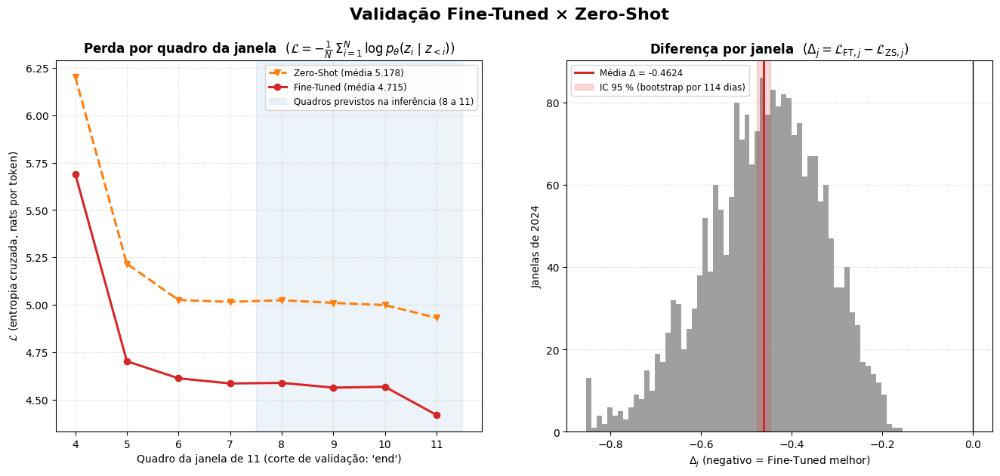

=== Contexto da validação (F-PluvIA Metropolitan — Célula 4.1) ===
  Ambiente: NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus  |  dispositivo: NVIDIA RTX PRO 6000 Blackwell Server Edition  |  CUDA 13.0  |  autocast bf16 + TF32  |  lote de inferência 64
  Tempo: Zero-Shot 24.0 s, Fine-Tuned 22.0 s (total 0.8 min)  |  pico de VRAM alocada 24.2 GB
  Dados: validação 2024 — 2224 janelas em 114 dias, corte 'end' (quadros 4 a 11 de 11), 512 tokens por janela
  Modelos: Zero-Shot (pesos do Zenodo) × Fine-Tuned (checkpoint gptcast8_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus_20261123T0028Z_best-00-4.7158.ckpt)
  Tokenização: quadros empilhados (igual à previsão) nos dois modelos; tokenização do treino registrada: empilhada

[Célula 4.1] Figura -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/validacao_finetuned_vs_zeroshot_G4_RTX6000_Blackwell_95GB_Cronus.png

            val/loss (nats/token)  Perplexidade (exp L)  val

In [ ]:
# @title
# Célula 4.1: Validação Fine-Tuned × Zero-Shot — perda de validação de 2024 dos dois modelos, nas mesmas
# janelas, por janela e por posição de quadro, com intervalo de confiança da diferença (bootstrap por dias).
# Responde se o fine-tuning da Célula 4 melhorou o modelo de partida.
#
# Eesuisito de Execução: Rodar depois da Célula 4.
#
import json
import os
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
SEED = int(globals().get('SEED', 42))
N_BOOT = 2000                # reamostragens de dias inteiros
TOL_REGISTRO = 0.02          # tolerância entre a perda medida aqui e a melhor val/loss registrada no treino
TOKENS_QUADRO = 64           # 8 x 8 tokens por quadro

faltam = [n for n in ('gpt8', 'gpt8_zeroshot', 'md_rmf') if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes a Célula 4. Faltam: {", ".join(faltam)}')

ds_val = md_rmf.splits['val']
crop = getattr(ds_val, 'crop', globals().get('VAL_CROP', '?'))
n_ctx_frames = int(getattr(ds_val, 'target_seq_len', 8) or 8)
n_win_frames = int(ds_val.sequences_dbz.shape[1])
inicio = {'start': 0, 'end': n_win_frames - n_ctx_frames}.get(crop, 0)
quadros = np.arange(inicio + 1, inicio + n_ctx_frames + 1)           # números dos quadros na janela de 11
CONTEXT = int(globals().get('CONTEXT_STEPS', 7))
previstos = quadros > CONTEXT                                        # quadros 8 a 11 = os previstos na inferência


# ------------------------------------------------------------- aceleração na GPU (CUDA)
# Ao fim do trainer.fit o Lightning devolve o modelo para a CPU, e o checkpoint do Zero-Shot é carregado na CPU.
# Por isso os dois modelos são levados à GPU aqui, antes de medir; eles continuam nela para as células seguintes.
if torch.cuda.is_available():
  for _nome in ('gpt8', 'gpt8_zeroshot'):
    _m = globals()[_nome]
    if _m.device.type != 'cuda':
      print(f'[Célula 4.1] Movendo {_nome} da {_m.device.type.upper()} para a GPU.')
      globals()[_nome] = _m.to('cuda')
  gpt8, gpt8_zeroshot = globals()['gpt8'], globals()['gpt8_zeroshot']
USA_CUDA = torch.cuda.is_available() and gpt8.device.type == 'cuda' and gpt8_zeroshot.device.type == 'cuda'
if torch.cuda.is_available() and not USA_CUDA:
  print('[Aviso Célula 4.1] Não foi possível levar os modelos à GPU: a validação vai rodar na CPU, bem mais devagar.')
if USA_CUDA:
  torch.backends.cuda.matmul.allow_tf32 = True          # operações fora do autocast usam TF32 nos Tensor Cores
  torch.backends.cudnn.allow_tf32 = True
  torch.backends.cudnn.benchmark = True                 # escolhe o algoritmo de convolução mais rápido (formato fixo)
  vram_gb = torch.cuda.get_device_properties(0).total_memory / 2 ** 30
  # Sem gradientes a memória por janela é bem menor que no treino: lotes maiores aproveitam a GPU.
  BATCH_INF = 64 if vram_gb >= 65 else 32 if vram_gb >= 20 else 8
  _nw = min(8, os.cpu_count() or 2)
  loader_val = DataLoader(ds_val, batch_size=BATCH_INF, shuffle=False, num_workers=_nw, pin_memory=True,
                          persistent_workers=False, prefetch_factor=4)
  torch.cuda.reset_peak_memory_stats(0)
else:
  BATCH_INF = getattr(md_rmf, 'batch_size', '?')
  loader_val = None                                     # usa o carregador da Célula 3


@torch.inference_mode()
def perdas_por_janela(model):
  """Entropia cruzada por token, igual ao shared_step do GPTCast, mas sem fazer a média do lote:
  devolve (janelas, posições de token) para tirar médias por janela e por quadro.
  Na GPU: modo de inferência, autocast bf16, cópia assíncrona da memória fixada e resultados mantidos na GPU
  até o fim (uma única transferência para a CPU)."""
  model.eval()
  dev = model.device
  out = []
  amp = torch.autocast('cuda', dtype=torch.bfloat16) if dev.type == 'cuda' else torch.autocast('cpu', enabled=False)
  for batch in (loader_val if loader_val is not None else md_rmf.val_dataloader()):   # ordem = ds_val.timestamps
    batch = {k: (v.to(dev, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}
    x, c = model.get_xc(batch)
    with amp:
      logits, target = model(x, c)
    ce = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), target.reshape(-1), reduction='none')
    out.append(ce.view(target.shape))
  return torch.cat(out).cpu().numpy()                    # (N, 512)


def _sync():
  if USA_CUDA:
    torch.cuda.synchronize()
  return time.perf_counter()


t_ini = _sync()
t0 = _sync(); ce_zs = perdas_por_janela(gpt8_zeroshot); t_zs = _sync() - t0
t0 = _sync(); ce_ft = perdas_por_janela(gpt8); t_ft = _sync() - t0
t_total = _sync() - t_ini
pico_vram = torch.cuda.max_memory_allocated(0) / 2 ** 30 if USA_CUDA else 0.0
N, L = ce_ft.shape
if L != n_ctx_frames * TOKENS_QUADRO:
  print(f'[Aviso Célula 4.1] {L} tokens por janela; esperado {n_ctx_frames * TOKENS_QUADRO}.')

win_zs, win_ft = ce_zs.mean(1), ce_ft.mean(1)                        # perda por janela
delta = win_ft - win_zs                                              # Δ_j < 0: ajustado melhor
fr_zs = ce_zs.reshape(N, -1, TOKENS_QUADRO).mean(2)                  # (N, 8) perda por quadro
fr_ft = ce_ft.reshape(N, -1, TOKENS_QUADRO).mean(2)
L_zs, L_ft = float(win_zs.mean()), float(win_ft.mean())
D = L_ft - L_zs

# Bootstrap por dias inteiros (janelas do mesmo dia compartilham quadros)
ts = np.asarray(ds_val.timestamps)[:N]
dias = pd.to_datetime(ts).normalize().values
ud, inv = np.unique(dias, return_inverse=True)
soma_d, cont_d = np.bincount(inv, delta, len(ud)), np.bincount(inv, minlength=len(ud))
rng = np.random.default_rng(SEED)
am = rng.integers(0, len(ud), (N_BOOT, len(ud)))
boot = soma_d[am].sum(1) / cont_d[am].sum(1)
ic = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
frac_melhor = float(np.mean(delta < 0))
D_prev = float((fr_ft[:, previstos] - fr_zs[:, previstos]).mean()) if previstos.any() else np.nan

# Conferência com o registro do treino
rec = {}
if 'training_record_json' in globals() and os.path.isfile(training_record_json):
  rec = json.load(open(training_record_json, encoding='utf-8'))
melhor_reg = rec.get('melhor_val_loss_2024')

# Diagnóstico: o IC 95 % da diferença é o único critério; o ganho em perplexidade vem ao lado, sem limiar.
# Perplexidade = exp(L); a razão FT/ZS é exp(Δ), então o ganho (%) = 100 · (1 − exp(Δ)).
ganho_pp = 100 * (1 - np.exp(D))
ganho_ic = (100 * (1 - np.exp(ic[1])), 100 * (1 - np.exp(ic[0])))
_n = lambda v: f'{v:+.4f}'.replace('.', ',')
_p = lambda v: f'{v:.1f}'.replace('.', ',') + ' %'
_txt_d = f'Δ = {_n(D)} nats por token, IC 95 % de {_n(ic[0])} a {_n(ic[1])}'
if ic[1] < 0:
  diag = (f'O ajustado é melhor que o Zero-Shot ({_txt_d}): perplexidade {_p(ganho_pp)} menor '
          f'(IC 95 % de {_p(ganho_ic[0])} a {_p(ganho_ic[1])}). O checkpoint pode seguir para as Células 5 a 13.1, '
          'onde o ganho precisa aparecer também nas métricas da chuva.')
elif ic[0] > 0:
  diag = (f'O ajustado é PIOR que o Zero-Shot ({_txt_d}): perplexidade {_p(-ganho_pp)} maior '
          f'(IC 95 % de {_p(-ganho_ic[1])} a {_p(-ganho_ic[0])}). O fine-tuning atual não serve: ajuste a Célula 4 '
          'antes de rodar as Células 5 a 13.1.')
else:
  diag = (f'Não há diferença comprovada entre o ajustado e o Zero-Shot ({_txt_d}, que inclui zero): variação de '
          f'perplexidade de {_p(ganho_ic[0])} a {_p(ganho_ic[1])} a favor do ajustado. O fine-tuning atual não trouxe '
          'ganho comprovado: ajuste a Célula 4.')

# ------------------------------------------------------------------- figura
fig = plt.figure(figsize=(16, 6.4))
gs = fig.add_gridspec(1, 2, wspace=0.2)
fig.suptitle('Validação Fine-Tuned × Zero-Shot', fontsize=16, fontweight='bold', y=0.99)

ax1 = fig.add_subplot(gs[0, 0])
for nome, fr, cor, mk in (('Zero-Shot', fr_zs, '#ff7f0e', 'v--'), ('Fine-Tuned', fr_ft, '#d62728', 'o-')):
  m = fr.mean(0)
  ax1.plot(quadros, m, mk, color=cor, lw=2.2, label=f'{nome} (média {fr.mean():.3f})')
if previstos.any():
  ax1.axvspan(quadros[previstos][0] - 0.5, quadros[previstos][-1] + 0.5, color='#1f77b4', alpha=0.08,
              label='Quadros previstos na inferência (8 a 11)')
ax1.set_title(r'Perda por quadro da janela  $(\mathcal{L} = -\frac{1}{N}\,\Sigma_{i=1}^{N}\, \log p_\theta(z_i \mid z_{<i}))$',
              fontweight='bold')
ax1.set_xlabel(f'Quadro da janela de {n_win_frames} (corte de validação: {crop!r})')
ax1.set_ylabel(r'$\mathcal{L}$ (entropia cruzada, nats por token)')
ax1.set_xticks(quadros)
ax1.grid(True, ls=':', alpha=0.6)
ax1.legend(fontsize=8.5)

ax2 = fig.add_subplot(gs[0, 1])
lim = np.percentile(np.abs(delta), 99.5)
ax2.hist(np.clip(delta, -lim, lim), bins=60, color='#7f7f7f', alpha=0.75)
ax2.axvline(0, color='k', lw=1)
ax2.axvline(D, color='#d62728', lw=2.2, label=f'Média Δ = {D:+.4f}')
ax2.axvspan(ic[0], ic[1], color='#d62728', alpha=0.18, label=f'IC 95 % (bootstrap por {len(ud)} dias)')
ax2.set_title(r'Diferença por janela  $(\Delta_j = \mathcal{L}_{\mathrm{FT},j} - \mathcal{L}_{\mathrm{ZS},j})$',
              fontweight='bold')
ax2.set_xlabel(r'$\Delta_j$ (negativo = Fine-Tuned melhor)')
ax2.set_ylabel('Janelas de 2024')
ax2.grid(True, axis='y', ls=':', alpha=0.6)
ax2.legend(fontsize=8.5)

RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR') or os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}')
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
png = os.path.join(RESULTS_ENV_DIR, f'validacao_finetuned_vs_zeroshot_{ENV_TAG}.png')
fig.savefig(png, dpi=200, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------- saída de texto
resumo = pd.DataFrame([
    {'Modelo': 'Zero-Shot', 'val/loss (nats/token)': round(L_zs, 4), 'Perplexidade (exp L)': round(float(np.exp(L_zs)), 1),
     'val/loss quadros 8–11': round(float(fr_zs[:, previstos].mean()), 4) if previstos.any() else np.nan},
    {'Modelo': 'Fine-Tuned', 'val/loss (nats/token)': round(L_ft, 4), 'Perplexidade (exp L)': round(float(np.exp(L_ft)), 1),
     'val/loss quadros 8–11': round(float(fr_ft[:, previstos].mean()), 4) if previstos.any() else np.nan},
])
por_quadro = pd.DataFrame({'Quadro': quadros, 'Zero-Shot': fr_zs.mean(0).round(4), 'Fine-Tuned': fr_ft.mean(0).round(4),
                           'Δ (FT − ZS)': (fr_ft.mean(0) - fr_zs.mean(0)).round(4),
                           'Previsto na inferência': np.where(previstos, 'sim', '')})
pd.DataFrame({'t0_fim_janela': ts, 'val_loss_zero_shot': win_zs, 'val_loss_fine_tuned': win_ft, 'delta': delta}).to_csv(
    os.path.join(RESULTS_ENV_DIR, f'validacao_por_janela_finetuned_vs_zeroshot_{ENV_TAG}.csv'), index=False)
resumo.assign(Delta=round(D, 4), IC95_inf=round(ic[0], 4), IC95_sup=round(ic[1], 4),
              Ganho_perplexidade_pct=round(float(ganho_pp), 2), Janelas=N, Dias=len(ud),
              Frac_janelas_FT_melhor=round(frac_melhor, 3)).to_csv(
    os.path.join(RESULTS_ENV_DIR, f'validacao_resumo_finetuned_vs_zeroshot_{ENV_TAG}.csv'), index=False)

print('=== Contexto da validação (F-PluvIA Metropolitan — Célula 4.1) ===')
for ln in (
    f"Ambiente: {ENV_LABEL}  |  dispositivo: {torch.cuda.get_device_name(0) if USA_CUDA else 'CPU'}  |  "
    + (f"CUDA {torch.version.cuda}  |  autocast bf16 + TF32  |  " if USA_CUDA else "sem aceleração  |  ")
    + f"lote de inferência {BATCH_INF}",
    f"Tempo: Zero-Shot {t_zs:.1f} s, Fine-Tuned {t_ft:.1f} s (total {t_total / 60:.1f} min)"
    + (f"  |  pico de VRAM alocada {pico_vram:.1f} GB" if USA_CUDA else ''),
    f"Dados: validação 2024 — {N} janelas em {len(ud)} dias, corte {crop!r} (quadros {quadros[0]} a {quadros[-1]} "
    f"de {n_win_frames}), {L} tokens por janela",
    f"Modelos: Zero-Shot (pesos do Zenodo) × Fine-Tuned (checkpoint "
    f"{os.path.basename(str(globals().get('best_ckpt_path') or rec.get('checkpoint', '?')))})",
    f"Tokenização: quadros empilhados (igual à previsão) nos dois modelos; tokenização do treino registrada: "
    f"{rec.get('tokenizacao_treino', 'não registrada')}",
):
  print('  ' + ln)
print(f'\n[Célula 4.1] Figura -> {png}\n')
print(resumo.set_index('Modelo').to_string())
print(f'\nΔ = val/loss(Fine-Tuned) − val/loss(Zero-Shot) = {D:+.4f} | IC 95 %: {ic[0]:+.4f} a {ic[1]:+.4f} '
      f'(bootstrap de {N_BOOT} reamostragens de {len(ud)} dias)')
print(f'Ganho em perplexidade: {ganho_pp:.1f} % (IC 95 %: {ganho_ic[0]:.1f} a {ganho_ic[1]:.1f} %; positivo = Fine-Tuned melhor)')
print(f'Fine-Tuned melhor em {100 * frac_melhor:.1f} % das {N} janelas' +
      (f' | Δ só nos quadros previstos (8 a 11): {D_prev:+.4f}' if previstos.any() else ''))
print('\n--- Perda média por quadro da janela ---')
print(por_quadro.set_index('Quadro').to_string())
if melhor_reg is not None and abs(L_ft - float(melhor_reg)) > TOL_REGISTRO:
  print(f'\n[Aviso Célula 4.1] A perda do Fine-Tuned medida aqui ({L_ft:.4f}) difere da melhor val/loss registrada no '
        f'treino ({float(melhor_reg):.4f}). Confira se o checkpoint carregado e o corte de validação são os do treino.')
print('\n=== Diagnóstico automático (regras desta célula, não substitui a avaliação das Células 9 a 13.1) ===')
print(textwrap.fill(diag, 110))
print(textwrap.fill('Regra: o IC 95 % da diferença (bootstrap por dias) é o único critério. IC todo abaixo de zero = '
                    'ajustado melhor; todo acima = pior; contendo zero = sem diferença comprovada. O ganho em '
                    'perplexidade, 100 · (1 − e^Δ), é informativo e não tem limiar.', 110))
CELL4_1_VALIDACAO = {'val_loss_zero_shot': L_zs, 'val_loss_fine_tuned': L_ft, 'delta': D, 'ic95': ic,
                     'ganho_perplexidade_pct': float(ganho_pp), 'ganho_perplexidade_ic95_pct': ganho_ic,
                     'janelas': N, 'dias': len(ud)}


## ⚠️ Célula 4.2 (Curva de Treino do Fine-Tuning): Perda de Treino × Validação por Época, Diferença entre Elas e Diagnóstico de *Overfitting* (`ENV_TAG`)

⚠️ Opcional: as saídas desta célula já estão no Drive; pode ser pulada no fluxo de publicação. A 4.3 refaz o ajuste fino e não deve ser executada sem necessidade.

Esta célula mostra **como o *fine-tuning* da Célula 4 evoluiu época a época**. Ela lê o registro do treino (`registro_treino_<ENV_TAG>.json`) e a curva gravada pelo `CSVLogger` (`curva_treino_<ENV_TAG>/.../metrics.csv`) e gera **uma imagem PNG com o título *Curva de Treino do Fine-Tuning* e dois gráficos**. O contexto do treino e o diagnóstico ficam na **saída de texto** da célula, fora da imagem.

* **Treino Ativo, da Célula 4 ou da Célula 4.3**: A célula lê sempre o treino registrado como ativo. Hoje é o da Célula 4, com validação **por época**. Se a **Célula 4.3** promover o treino alternativo, com validação **a cada 1/4 de época** (`val_check_interval = 0.25`), a célula percebe isso pelo registro e mostra **cada ponto de validação** no eixo de épocas fracionárias (0,25; 0,50; …). Nesse caso, a perda de treino de cada ponto é a média dos passos desde a validação anterior, e a paciência é contada em validações. A melhor validação marcada é exatamente a do checkpoint guardado.

* **Contexto do Treino (na saída da célula, fora da imagem)**:

  - ambiente, GPU, precisão numérica e data do treino;

  - modelo: VQGAN congelada (90,71 M) e Transformer GPT-2 ajustado (304,93 M);

  - **tokenização do treino** (`empilhada` confirma o treino corrigido em 16/11/2026);

  - dados: treino **2019–2023** (9.940 janelas) e validação **2024** (2.224 janelas, com o corte `VAL_CROP`);

  - otimização: AdamW, taxa de aprendizado do treino ativo (5 × 10⁻⁵ na Célula 4, 1 × 10⁻⁵ na 4.3), lote × acúmulo, semente, frequência da validação e paciência da parada antecipada;

  - resultado: épocas, tempo total, melhor validação, melhor `val/loss`, nome do checkpoint e origem do treino (Célula 4 ou 4.3).

* **Gráfico 1 - Perda por Época**: a perda de treino e a de validação, que é a entropia cruzada média do próximo token, L = −(1/N) · Σ log p(zᵢ | tokens anteriores). N é o número de tokens previstos, zᵢ o token real na posição i e p(zᵢ | tokens anteriores) a probabilidade que o Transformer deu a ele a partir dos tokens anteriores. A **melhor época**, cujo checkpoint vira o F-PluvIA, aparece com um círculo verde. As **épocas sem melhora**, que a paciência de 4 épocas deixa rodar antes de parar, ficam sombreadas. Com o treino da Célula 4.3, o título passa a *Perda ao longo do treino* e cada ponto é uma validação a cada 1/4 de época.

* **Gráfico 2 - Diferença Validação − Treino** (Δ = perda de validação − perda de treino): a distância entre as duas perdas em cada época. Se ela **cresce depois da melhor época**, o modelo passou a decorar o treino em vez de generalizar (*overfitting*).

* **Diagnóstico Automático (na saída da célula, fora da imagem)**: um texto impresso depois da figura diz se houve sinal de *overfitting* depois da melhor época e quanto a validação subiu, ou se ela só estacionou. Também avisa se a melhor validação veio cedo demais, o que indicaria um ajuste forte demais. As regras vêm desta célula, não de um teste estatístico, e são impressas junto: sinal de *overfitting* se a `val/loss` da última época ficou mais de 1% acima da melhor e a perda de treino continuou caindo.

**Adendo**:
- O checkpoint guardado é sempre o da **melhor época**, não o da última. As épocas depois dela só servem para detectar que o modelo parou de melhorar.
- É normal a diferença começar **negativa**: a perda de treino de cada época é a média ao longo da época, com o modelo ainda melhorando, e a de validação é medida no fim dela.
- A melhor época do gráfico conta a partir de 1. No nome do checkpoint, o Lightning conta a partir de 0, então os dois podem diferir em 1.
- A curva mostra **quando** o ajuste foi melhor, mas não se ele supera o modelo de partida: essa comparação com o Zero-Shot é feita na **Célula 4.1**.

**Saídas**:

- `curva_finetuning_<ENV_TAG>.png` em `RESULTS_ENV_DIR`;

- contexto do treino, tabela por época (treino, validação e diferença), diagnóstico e regras usadas, impressos na saída da célula.

**Requisito**: rodar antes a **Célula 4**; rode de novo depois de uma promoção na **Célula 4.3**.

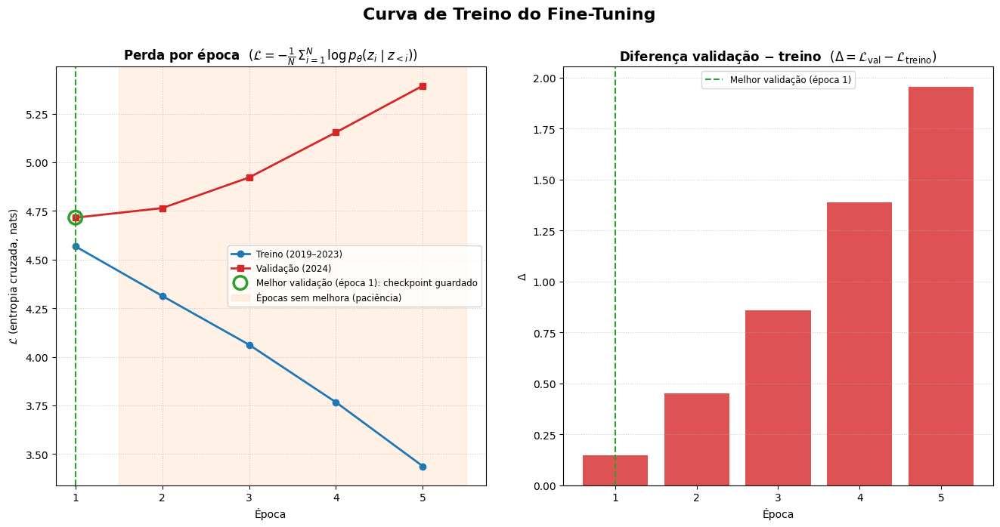

=== Contexto do treino (F-PluvIA Metropolitan — Célula 4.2) ===
  Ambiente: NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus  |  GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition  |  Precisão: bf16-mixed  |  Data do treino (UTC): 20261123T0028Z  |  Origem: Célula 4
  Modelo: GPTCast-8x8 (Zenodo) — VQGAN congelada (90,71 M) + Transformer GPT-2 ajustado (304,93 M)  |  Tokenização do treino: empilhada
  Dados: IMERG-FR v7 a 2 km, RMF — treino 2019–2023 (9.940 janelas, corte de 8 quadros sorteado)  |  validação 2024 (2.224 janelas, corte 'end')
  Otimização: AdamW (β 0,9/0,95, weight decay 0,01), lr 5e-05 constante  |  lote 16 × acúmulo 1  |  semente 42  |  validação por época  |  parada antecipada: paciência 4 épocas em val/loss
  Resultado: 5 épocas em 16.8 min  |  melhor validação na época 1 (val/loss 4.7158)  |  checkpoint: gptcast8_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus_20261123T0028Z_best-00-4.7158.ckpt

[Célula 4.2] Figura -> /content/drive/MyDrive/GPTCast_RMF_Cronu

In [ ]:
# @title
# Célula 4.2: Curva de Treino do Fine-Tuning — perda de treino x validação e diferença entre elas, com cabeçalho
# do contexto do treino. Lê o treino registrado como ativo: o da Célula 4 ou, se promovido, o da Célula 4.3
# (validação a cada fração de época).
#
# Requisito de Execução: rodar depois da Célula 4.
#
import json
import os
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rec = json.load(open(training_record_json, encoding='utf-8'))
m = pd.read_csv(rec['curva_por_epoca_csv'])

col_v = next((c for c in ('val/loss_epoch', 'val/loss') if c in m.columns), None)
col_te = 'train/loss_epoch' if 'train/loss_epoch' in m.columns else None
col_ts = next((c for c in ('train/loss_step', 'train/loss') if c in m.columns), None)
if col_v is None or (col_te is None and col_ts is None):
  raise RuntimeError(f'O metrics.csv não tem as colunas de perda esperadas; encontradas: {list(m.columns)}')

# Validação por época (Célula 4) ou a cada fração de época (Célula 4.3, val_check_interval < 1).
VC = float(rec.get('val_check_interval') or 1.0)
v = m.dropna(subset=[col_v])[['epoch', 'step', col_v]].drop_duplicates('step').sort_values('step').reset_index(drop=True)
FRACAO = VC < 1.0 or v.groupby('epoch').size().max() > 1
if FRACAO:
  v['x'] = v['epoch'] + (v.groupby('epoch').cumcount() + 1) * VC       # 0,25; 0,50; ...; 1,00 = fim da época 1
  if col_ts is not None:
    # Treino no trecho entre uma validação e a anterior (média dos passos desse trecho).
    t = m.dropna(subset=[col_ts])[['step', col_ts]]
    lim = [-1] + v['step'].tolist()
    v['treino'] = [t.loc[(t['step'] > a) & (t['step'] <= b), col_ts].mean() for a, b in zip(lim[:-1], lim[1:])]
  else:
    v['treino'] = v['epoch'].map(m.groupby('epoch')[col_te].mean())
  passo_x = VC
else:
  curva_ep = m.groupby('epoch')[[c for c in (col_te, col_v) if c]].mean().dropna(how='all')
  v = pd.DataFrame({'x': curva_ep.index.astype(int) + 1, col_v: curva_ep[col_v].values,
                    'treino': curva_ep[col_te].values if col_te else np.nan})
  passo_x = 1.0
v = v.dropna(subset=[col_v])
x, va, tr = v['x'].to_numpy(float), v[col_v].to_numpy(float), v['treino'].to_numpy(float)
gap = va - tr

ib = int(np.argmin(va))
x_best, best_val = float(x[ib]), float(va[ib])
paciencia = int(rec.get('paciencia_validacoes') or 4)
un_pac = 'validações' if FRACAO else 'épocas'
_x = lambda z: (f'{z:.2f}'.replace('.', ',') if FRACAO else f'{int(z)}')
rotulo_best = f'época {_x(x_best)}'

# Diagnóstico automático a partir da curva (mesma regra nos dois formatos, por ponto de validação)
_pct = lambda z: f'{100 * z:.1f}'.replace('.', ',') + ' %'
va_d, tr_d = va[ib:], tr[ib:]
if len(va_d) <= 1:
  diag = f'O treino parou na melhor validação ({rotulo_best}): não há pontos depois dela para avaliar overfitting.'
elif va_d[-1] > best_val * 1.01 and np.isfinite(tr_d).all() and tr_d[-1] < tr_d[0]:
  diag = (f'Sinal de overfitting depois da {rotulo_best}: a perda de treino continuou caindo e a de validação '
          f'subiu {_pct(va_d[-1] / best_val - 1)}. O checkpoint guardado é o da {rotulo_best}, anterior a isso.')
else:
  diag = (f'Sem overfitting relevante: depois da {rotulo_best} a validação estacionou '
          f'(variação de {_pct(va_d.max() / best_val - 1)}) e a parada antecipada encerrou o treino.')
if x_best <= 2 and len(va_d) > 3:
  diag += ' A melhor validação veio muito cedo: o ajuste pode estar forte demais (taxa de aprendizado).'

# ------------------------------------------------------------------- figura
fig = plt.figure(figsize=(16, 7.2))
gs = fig.add_gridspec(1, 2, wspace=0.18)


def _fmt_t(s):
  try:
    s = float(s)
    return f'{s / 3600:.2f} h' if s >= 3600 else f'{s / 60:.1f} min'
  except (TypeError, ValueError):
    return 'não registrado'


tok = rec.get('tokenizacao_treino', 'não registrada (treino anterior à correção de 16/11/2026)')
origem = 'Célula 4.3 (promovido)' if rec.get('promovido_pela_celula_4_3') else 'Célula 4'
val_txt = f'validação a cada {VC:g} de época' if FRACAO else 'validação por época'
linhas = [
    f"Ambiente: {globals().get('ENV_LABEL', '?')}  |  GPU: {rec.get('gpu', '?')}  |  Precisão: {rec.get('precisao_numerica', '?')}"
    f"  |  Data do treino (UTC): {rec.get('data_treino_utc', '?')}  |  Origem: {origem}",
    f"Modelo: GPTCast-8x8 (Zenodo) — VQGAN congelada (90,71 M) + Transformer GPT-2 ajustado (304,93 M)  |  "
    f"Tokenização do treino: {tok}",
    f"Dados: IMERG-FR v7 a 2 km, RMF — treino 2019–2023 (9.940 janelas, corte de 8 quadros sorteado)  |  "
    f"validação 2024 (2.224 janelas, corte '{rec.get('corte_validacao', '?')}')",
    f"Otimização: AdamW (β 0,9/0,95, weight decay 0,01), lr {rec.get('learning_rate_efetiva', '?')} constante  |  "
    f"lote {rec.get('batch_size_treino', '?')} × acúmulo {rec.get('acumulo_gradiente', 1)}  |  semente {rec.get('semente_treino', '?')}"
    f"  |  {val_txt}  |  parada antecipada: paciência {paciencia} {un_pac} em val/loss",
    f"Resultado: {rec.get('epocas_executadas', '?')} épocas em {_fmt_t(rec.get('finetuning_tempo_total_s'))}  |  "
    f"melhor validação na {rotulo_best} (val/loss {best_val:.4f})  |  checkpoint: {rec.get('checkpoint', '?')}",
]
fig.suptitle('Curva de Treino do Fine-Tuning', fontsize=16, fontweight='bold', y=0.99)

# Gráfico 1: perdas
mk = 4 if FRACAO else 6
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(x, tr, 'o-', color='#1f77b4', lw=2, ms=mk,
         label='Treino (2019–2023)' + (' — média do trecho' if FRACAO else ''))
ax1.plot(x, va, 's-', color='#d62728', lw=2, ms=mk, label='Validação (2024)')
ax1.axvline(x_best, color='#2ca02c', ls='--', lw=1.5)
ax1.scatter([x_best], [best_val], s=160, facecolors='none', edgecolors='#2ca02c', lw=2.5, zorder=5,
            label=f'Melhor validação ({rotulo_best}): checkpoint guardado')
if x.max() > x_best:
  ax1.axvspan(x_best + passo_x / 2, x.max() + passo_x / 2, color='#ff7f0e', alpha=0.10,
              label=f'Validações sem melhora (paciência)' if FRACAO else 'Épocas sem melhora (paciência)')
tit = 'Perda ao longo do treino' if FRACAO else 'Perda por época'
ax1.set_title(tit + r'  $(\mathcal{L} = -\frac{1}{N}\,\Sigma_{i=1}^{N}\, \log p_\theta(z_i \mid z_{<i}))$', fontweight='bold')
ax1.set_xlabel('Época (fração)' if FRACAO else 'Época')
ax1.set_ylabel(r'$\mathcal{L}$ (entropia cruzada, nats)')
ax1.set_xticks(np.arange(1, int(np.ceil(x.max())) + 1) if FRACAO else x)
ax1.grid(True, ls=':', alpha=0.6)
ax1.legend(fontsize=8.5)

# Gráfico 2: diferença validação − treino
ax2 = fig.add_subplot(gs[0, 1])
cores = ['#d62728' if g > 0 else '#1f77b4' for g in gap]
ax2.bar(x, gap, width=0.8 * passo_x, color=cores, alpha=0.8)
ax2.axhline(0, color='k', lw=0.8)
ax2.axvline(x_best, color='#2ca02c', ls='--', lw=1.5, label=f'Melhor validação ({rotulo_best})')
ax2.set_title(r'Diferença validação − treino  $(\Delta = \mathcal{L}_{\mathrm{val}} - \mathcal{L}_{\mathrm{treino}})$', fontweight='bold')
ax2.set_xlabel('Época (fração)' if FRACAO else 'Época')
ax2.set_ylabel(r'$\Delta$')
ax2.set_xticks(np.arange(1, int(np.ceil(x.max())) + 1) if FRACAO else x)
ax2.grid(True, axis='y', ls=':', alpha=0.6)
ax2.legend(fontsize=8.5)

png = os.path.join(RESULTS_ENV_DIR, f"curva_finetuning_{globals().get('ENV_TAG', 'Ambiente_Ativo')}.png")
fig.savefig(png, dpi=200, bbox_inches='tight')
plt.show()

tabela = pd.DataFrame({'Época (fração)' if FRACAO else 'Época': [_x(z) for z in x],
                       'treino' + (' (trecho)' if FRACAO else ''): tr.round(4), 'validação': va.round(4),
                       'val − treino': gap.round(4)}).set_index('Época (fração)' if FRACAO else 'Época')
print('=== Contexto do treino (F-PluvIA Metropolitan — Célula 4.2) ===')
for ln in linhas:
  print('  ' + ln)
print(f'\n[Célula 4.2] Figura -> {png}\n')
print(tabela.to_string())
print('\n=== Diagnóstico automático (regras desta célula, não é um teste estatístico) ===')
print(textwrap.fill(diag, 110))
print(textwrap.fill(f'Regras: "sinal de overfitting" se a val/loss do último ponto de validação ficou mais de 1 % acima '
                    'da melhor e a perda de treino continuou caindo; "sem overfitting relevante" nos demais casos; aviso '
                    'extra se a melhor validação veio até o fim da 2ª época.'
                    + (' Com validação a cada fração de época, o treino em cada ponto é a média dos passos desde a '
                       'validação anterior.' if FRACAO else ''), 110))


## ⚠️ Célula 4.3 (Opcional - Fine-Tuning Suave - Adds Another Dimension of Search): Treino Alternativo com Taxa de Aprendizado 1 × 10⁻⁵ e Validação a Cada 1/4 de Época, Comparado ao Treino Atual da Célula 4 por Intervalo de Confiança

⚠️ Opcional: as saídas desta célula já estão no Drive; pode ser pulada no fluxo de publicação. Esta célula refaz o ajuste fino e não deve ser executada sem necessidade.

* **Por que uma nova busca pelo ponto de ajuste**: No treino atual da Célula 4 (lr = 5 × 10⁻⁵), a melhor `val/loss` veio já na primeira época e subiu depois (Célula 4.2). Isso sugere que o ajuste pode estar forte demais e que o melhor ponto talvez esteja **dentro** da primeira época, onde a validação por época não enxerga. Esta célula testa as duas correções juntas: taxa de aprendizado 5 vezes menor (1 × 10⁻⁵) e validação a cada 1/4 de época (`val_check_interval = 0.25`).

* **Mesmas Condições do Treino Atual**: Parte dos mesmos pesos do Zenodo (`gpt8_zeroshot`), congela a VQGAN, treina só o Transformer GPT-2, com o mesmo lote efetivo, semente, precisão (`bf16-mixed`), corte de validação e **tokenização empilhada**. Muda apenas a taxa de aprendizado e a frequência da validação. A parada antecipada usa paciência de 4 validações (1 época sem melhora), até 5 épocas.

* **Isolamento do Projeto (`checkpoints/<ENV_TAG>/alternativos/`)**: O checkpoint e o registro (`registro_treino_alternativo_lr1e-5_val0.25_<ENV_TAG>.json`) ficam numa subpasta que a busca da Célula 4 não enxerga. O modelo em uso (`gpt8`) **não muda**. Ao rodar de novo, o checkpoint alternativo é reaproveitado sem novo treino (`FORCAR_TREINO_ALT = True` treina outra vez).

* **Comparação nas Mesmas Janelas (Igual à Célula 4.1)**: Mede a entropia cruzada por token do Zero-Shot, do treino atual e do alternativo nas 2.224 janelas de validação de 2024, na GPU (`bf16` + `TF32`, lote 64). A diferença por janela é Δ = perda do alternativo − perda do atual, com intervalo de confiança de 95% por *bootstrap* de dias inteiros (2.000 reamostragens).

* **Regra de Decisão (IC de 95% como único critério)**:
  - IC todo **abaixo de zero**: o alternativo é melhor e vale promovê-lo.
  - IC **contendo zero**: sem diferença comprovada; mantém-se o treino atual, que já foi avaliado nas células seguintes.
  - IC todo **acima de zero**: o treino atual é melhor e é mantido.

  O ganho em perplexidade, 100 × (1 − e^Δ) %, aparece ao lado, sem limiar.

* **Promoção (`PROMOVER_SE_MELHOR = False` por padrão)**: Só com `True` **e** o alternativo comprovadamente melhor, a célula guarda uma cópia do registro atual e reescreve `registro_treino_<ENV_TAG>.json` para apontar o checkpoint alternativo. Nesse caso `gpt8` e `best_ckpt_path` passam a ser o alternativo, e é preciso rodar de novo a Célula (Activates Checkpoint), a 4.1, a 4.2 e as Células 5 a 13.1. As Células 12 e 13.1 refazem as previsões, porque a impressão digital do modelo muda.

* **Saídas**: Figura `treino_alternativo_lr1e-5_val0.25_vs_atual_<ENV_TAG>.png`, com dois painéis: a perda ao longo do treino alternativo com as linhas do treino atual e do Zero-Shot, e o histograma de Δ por janela com o IC. Também gera as tabelas `..._resumo_<ENV_TAG>.csv` e `..._por_janela_<ENV_TAG>.csv` e a variável `CELL4_3_TREINO_ALT`.

* **Ressalva Metodológica**: Os dois treinos são escolhidos pela mesma validação de 2024, então a vantagem de um sobre o outro nessa validação é levemente otimista. A confirmação final vem do teste de 2025, nas Células 9 a 13.1.

In [ ]:
# @title
# Célula 4.3 (Opcional - Fine-Tuning Suave - Adds Another Dimension of Search): novo fine-tuning com taxa de aprendizado 1e-5 e validação a cada
# 1/4 de época, comparado ao treino atual da Célula 4 nas mesmas janelas de 2024 (IC 95 % por bootstrap de dias).
# Decide qual dos dois treinamentos fica. Não altera o modelo em uso, a não ser que PROMOVER_SE_MELHOR = True e o
# alternativo seja comprovadamente melhor.
#
# Requisito de Execução: rodar depois da Célula 4;
#
import copy
import datetime
import glob
import json
import os
import re
import shutil
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

# ------------------------------------------------------------------ 1. parâmetros
LR_ALT = 1e-5                 # taxa de aprendizado efetiva do treino alternativo (Célula 4: 5e-5)
VAL_CHECK = 0.25              # validação a cada 1/4 de época
MAX_EPOCAS_ALT = 5
PACIENCIA_VAL = 4             # em validações: 4 x 1/4 = 1 época sem melhora
FORCAR_TREINO_ALT = False     # True = treina de novo mesmo havendo checkpoint alternativo com estes parâmetros
PROMOVER_SE_MELHOR = False    # True = se o alternativo for comprovadamente melhor, ele passa a ser o modelo do projeto
N_BOOT = 2000
TOKENS_QUADRO = 64

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
SEED = int(globals().get('SEED', 42))

faltam = [n for n in ('gpt8', 'gpt8_zeroshot', 'md_rmf', 'GPTCast', 'CHECKPOINTS_ENV_DIR', 'RESULTS_ENV_DIR',
                      'training_record_json') if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes a Célula 4. Faltam: {", ".join(faltam)}')
if not torch.cuda.is_available():
  raise RuntimeError('A Célula 4.3 treina um modelo: rode com GPU.')
if getattr(GPTCast.encode_to_z, '__name__', '') != '_spatiotemporal_encode_to_z':
  raise RuntimeError('A tokenização empilhada da Célula 4 não está ativa nesta sessão: rode a Célula 4 antes.')

device = 'cuda'
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

rec_atual = json.load(open(training_record_json, encoding='utf-8'))
if rec_atual.get('tokenizacao_treino') != 'empilhada':
  raise RuntimeError('O treino atual não está registrado com tokenização empilhada: rode a Célula 4 antes.')
BATCH = int(rec_atual.get('batch_size_treino') or globals().get('BATCH_SIZE_AUTO', 16))
ACUM = int(rec_atual.get('acumulo_gradiente') or globals().get('ACCUM_STEPS_AUTO', 1))
ckpt_atual = os.path.join(CHECKPOINTS_ENV_DIR, rec_atual['checkpoint'])

# Pasta própria: a busca de checkpoints da Célula 4 não a enxerga, então nada muda no projeto por acidente.
ALT_DIR = os.path.join(CHECKPOINTS_ENV_DIR, 'alternativos')
os.makedirs(ALT_DIR, exist_ok=True)
TAG_ALT = f'lr{LR_ALT:.0e}_val{VAL_CHECK:g}'.replace('e-0', 'e-')
registro_alt_json = os.path.join(ALT_DIR, f'registro_treino_alternativo_{TAG_ALT}_{ENV_TAG}.json')


def _carregar_pesos(model, path):
  state = torch.load(path, map_location=device)['state_dict']
  res = model.load_state_dict(state, strict=False)
  if any(k.startswith('transformer.') for k in res.missing_keys):
    raise RuntimeError(f'{os.path.basename(path)} não contém os pesos do Transformer.')
  return model.to(device).eval()


def _sync():
  torch.cuda.synchronize()
  return time.perf_counter()


# ------------------------------------------------------------------ 2. treino alternativo (ou reaproveitamento)
rec_alt = None
if not FORCAR_TREINO_ALT and os.path.isfile(registro_alt_json):
  _r = json.load(open(registro_alt_json, encoding='utf-8'))
  if os.path.isfile(os.path.join(CHECKPOINTS_ENV_DIR, _r.get('checkpoint', ''))):
    rec_alt = _r

if rec_alt is not None:
  ckpt_alt = os.path.join(CHECKPOINTS_ENV_DIR, rec_alt['checkpoint'])
  gpt8_alt = _carregar_pesos(copy.deepcopy(gpt8_zeroshot), ckpt_alt)
  print(f'[Célula 4.3] Treino alternativo já existe ({rec_alt["data_treino_utc"]}): {rec_alt["checkpoint"]}. '
        'Reaproveitado (FORCAR_TREINO_ALT = True treina de novo).')
else:
  import lightning.pytorch as pl_modern
  import pytorch_lightning as pl_legacy
  pl_active = pl_modern if issubclass(GPTCast, pl_modern.LightningModule) else pl_legacy
  pl_active.seed_everything(SEED, workers=True)
  precision_mode = 'bf16-mixed' if torch.cuda.is_bf16_supported() else '16-mixed'

  # Mesmo ponto de partida da Célula 4: pesos do Zenodo, VQGAN congelada, Transformer treinável.
  gpt8_alt = copy.deepcopy(gpt8_zeroshot).to(device)
  gpt8_alt.train()
  gpt8_alt.first_stage_model.eval()
  for p in gpt8_alt.first_stage_model.parameters():
    p.requires_grad = False
  for p in gpt8_alt.transformer.parameters():
    p.requires_grad = True
  gpt8_alt.base_learning_rate = LR_ALT / (BATCH * ACUM)
  gpt8_alt.learning_rate = LR_ALT

  run_tag = datetime.datetime.utcnow().strftime('%Y%m%dT%H%MZ')
  ckpt_cb = pl_active.callbacks.ModelCheckpoint(
      dirpath=ALT_DIR,
      filename=f'gptcast8_rmf_2km_{ENV_TAG}_{run_tag}_{TAG_ALT}_best-{{epoch:02d}}-{{step:05d}}-{{val/loss:.4f}}',
      auto_insert_metric_name=False, monitor='val/loss', mode='min', save_top_k=1, save_last=False,
  )
  stop_cb = pl_active.callbacks.EarlyStopping(monitor='val/loss', patience=PACIENCIA_VAL, mode='min', verbose=False)
  logger = pl_active.loggers.CSVLogger(save_dir=RESULTS_ENV_DIR, name=f'curva_treino_alternativo_{ENV_TAG}',
                                       version=f'{run_tag}_{TAG_ALT}')
  trainer = pl_active.Trainer(
      accelerator='gpu', devices=1, max_epochs=MAX_EPOCAS_ALT, precision=precision_mode,
      accumulate_grad_batches=ACUM, val_check_interval=VAL_CHECK, callbacks=[ckpt_cb, stop_cb],
      logger=logger, log_every_n_steps=5, deterministic=False, enable_model_summary=False,
  )
  print(f'[Célula 4.3] Treino alternativo: lr {LR_ALT:g} (atual {rec_atual.get("learning_rate_efetiva")}), '
        f'validação a cada {VAL_CHECK:g} de época, até {MAX_EPOCAS_ALT} épocas, paciência {PACIENCIA_VAL} validações, '
        f'lote {BATCH} x acúmulo {ACUM}, {precision_mode}, semente {SEED}.')
  torch.cuda.reset_peak_memory_stats(0)
  t0 = _sync()
  trainer.fit(gpt8_alt, datamodule=md_rmf)
  t_fit = _sync() - t0
  ckpt_alt = ckpt_cb.best_model_path
  if not ckpt_alt or not os.path.isfile(ckpt_alt):
    raise RuntimeError('O treino alternativo terminou sem checkpoint de melhor val/loss.')
  gpt8_alt = _carregar_pesos(gpt8_alt, ckpt_alt)
  m = re.search(r'best-(\d+)-(\d+)-', os.path.basename(ckpt_alt))
  rec_alt = {
      'data_treino_utc': run_tag, 'checkpoint': os.path.relpath(ckpt_alt, CHECKPOINTS_ENV_DIR),
      'epocas_executadas': int(trainer.current_epoch), 'melhor_epoca': int(m.group(1)) if m else None,
      'melhor_passo': int(m.group(2)) if m else None,
      'melhor_val_loss_2024': round(float(ckpt_cb.best_model_score.cpu().item()), 4),
      'finetuning_tempo_total_s': round(t_fit, 2), 'finetuning_tempo_total_min': round(t_fit / 60, 2),
      'finetuning_tempo_medio_por_epoca_s': round(t_fit / max(int(trainer.current_epoch), 1), 2),
      'precisao_numerica': precision_mode, 'batch_size_treino': BATCH, 'acumulo_gradiente': ACUM,
      'learning_rate_efetiva': LR_ALT, 'val_check_interval': VAL_CHECK, 'paciencia_validacoes': PACIENCIA_VAL,
      'semente_treino': SEED, 'corte_validacao': rec_atual.get('corte_validacao'), 'tokenizacao_treino': 'empilhada',
      'gpu': torch.cuda.get_device_name(0), 'pico_vram_treino_gb': round(torch.cuda.max_memory_allocated(0) / 2**30, 2),
      'curva_por_epoca_csv': os.path.join(logger.log_dir, 'metrics.csv'),
  }
  with open(registro_alt_json, 'w') as f:
    json.dump(rec_alt, f, indent=2, ensure_ascii=False)
  print(f'[Célula 4.3] Treino alternativo concluído em {t_fit / 60:.1f} min | melhor val/loss '
        f'{rec_alt["melhor_val_loss_2024"]:.4f} (época {rec_alt["melhor_epoca"]}, passo {rec_alt["melhor_passo"]}).')

gpt8 = gpt8.to(device).eval()
gpt8_zeroshot = gpt8_zeroshot.to(device).eval()


# ------------------------------------------------------------------ 3. mesma medição da Célula 4.1, três modelos
ds_val = md_rmf.splits['val']
loader_val = DataLoader(ds_val, batch_size=64, shuffle=False, num_workers=min(8, os.cpu_count() or 2),
                        pin_memory=True, prefetch_factor=4)


@torch.inference_mode()
def perdas_por_janela(model):
  model.eval()
  out = []
  for batch in loader_val:
    batch = {k: (v.to(device, non_blocking=True) if torch.is_tensor(v) else v) for k, v in batch.items()}
    x, c = model.get_xc(batch)
    with torch.autocast('cuda', dtype=torch.bfloat16):
      logits, target = model(x, c)
    ce = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), target.reshape(-1), reduction='none')
    out.append(ce.view(target.shape))
  return torch.cat(out).cpu().numpy()


t0 = _sync()
ce = {'zs': perdas_por_janela(gpt8_zeroshot), 'atual': perdas_por_janela(gpt8), 'alt': perdas_por_janela(gpt8_alt)}
t_med = _sync() - t0
N = ce['atual'].shape[0]
win = {k: v.mean(1) for k, v in ce.items()}
L = {k: float(v.mean()) for k, v in win.items()}

ts = np.asarray(ds_val.timestamps)[:N]
ud, inv = np.unique(pd.to_datetime(ts).normalize().values, return_inverse=True)
cont_d = np.bincount(inv, minlength=len(ud))
am = np.random.default_rng(SEED).integers(0, len(ud), (N_BOOT, len(ud)))


def _ic(delta):
  soma = np.bincount(inv, delta, len(ud))
  boot = soma[am].sum(1) / cont_d[am].sum(1)
  return float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


delta = win['alt'] - win['atual']                       # < 0: alternativo melhor
D, ic = float(delta.mean()), _ic(delta)
ic_alt_zs = _ic(win['alt'] - win['zs'])
ganho = 100 * (1 - np.exp(D))
ganho_ic = (100 * (1 - np.exp(ic[1])), 100 * (1 - np.exp(ic[0])))
frac_alt = float(np.mean(delta < 0))

ctx = int(globals().get('CONTEXT_STEPS', 7))
n_win = int(ds_val.sequences_dbz.shape[1])
n_ctx = ce['atual'].shape[1] // TOKENS_QUADRO
ini = {'start': 0, 'end': n_win - n_ctx}.get(getattr(ds_val, 'crop', 'end'), 0)
quadros = np.arange(ini + 1, ini + n_ctx + 1)
prev = quadros > ctx
fr = {k: v.reshape(N, -1, TOKENS_QUADRO).mean(2) for k, v in ce.items()}
D_prev = float((fr['alt'][:, prev] - fr['atual'][:, prev]).mean())

# ------------------------------------------------------------------ 4. decisão (IC 95 % como único critério)
_n = lambda v: f'{v:+.4f}'.replace('.', ',')
_p = lambda v: f'{v:.1f}'.replace('.', ',') + ' %'
txt_d = f'Δ = {_n(D)} nats por token, IC 95 % de {_n(ic[0])} a {_n(ic[1])}'
alt_melhor = ic[1] < 0
if alt_melhor:
  diag = (f'O treino alternativo (lr {LR_ALT:g}) é melhor que o atual ({txt_d}): perplexidade {_p(ganho)} menor '
          f'(IC 95 % de {_p(ganho_ic[0])} a {_p(ganho_ic[1])}). Vale promovê-lo a modelo do projeto.')
elif ic[0] > 0:
  diag = (f'O treino atual (lr {rec_atual.get("learning_rate_efetiva")}) é melhor que o alternativo ({txt_d}). '
          'Mantenha o treino atual; nada muda no projeto.')
else:
  diag = (f'Não há diferença comprovada entre os dois treinos ({txt_d}, que inclui zero). Mantenha o treino atual, '
          'que já foi avaliado nas células seguintes; nada muda no projeto.')

promovido = False
if alt_melhor and PROMOVER_SE_MELHOR:
  bkp = training_record_json.replace('.json', f'_antes_celula43_{datetime.datetime.utcnow():%Y%m%dT%H%MZ}.json')
  shutil.copy2(training_record_json, bkp)
  with open(training_record_json, 'w') as f:
    json.dump(dict(rec_alt, promovido_pela_celula_4_3=True, registro_anterior=os.path.basename(bkp)), f,
              indent=2, ensure_ascii=False)
  gpt8, best_ckpt_path, promovido = gpt8_alt, ckpt_alt, True
elif not alt_melhor:
  del gpt8_alt
  torch.cuda.empty_cache()

# ------------------------------------------------------------------ 5. figura
curva = None
try:
  mcsv = pd.read_csv(rec_alt['curva_por_epoca_csv'])
  col_v = next(c for c in ('val/loss_epoch', 'val/loss') if c in mcsv.columns)
  v = mcsv.dropna(subset=[col_v])[['epoch', 'step', col_v]].drop_duplicates('step')
  v['x'] = v['epoch'] + (v.groupby('epoch').cumcount() + 1) * VAL_CHECK
  curva = v
  col_t = next((c for c in ('train/loss_step', 'train/loss') if c in mcsv.columns), None)
  passos_epoca = max(1, len(md_rmf.train_dataloader()) // ACUM)
  tr = mcsv.dropna(subset=[col_t])[['step', col_t]] if col_t else None
except Exception as e:
  print(f'[Aviso Célula 4.3] Curva do treino alternativo indisponível ({e}).')
  tr = None

fig = plt.figure(figsize=(16, 6.4))
gs = fig.add_gridspec(1, 2, wspace=0.2)
fig.suptitle('Treino Alternativo × Treino Atual', fontsize=16, fontweight='bold', y=0.99)

ax1 = fig.add_subplot(gs[0, 0])
if tr is not None and len(tr):
  y = tr[tr.columns[1]].rolling(25, min_periods=1).mean()
  ax1.plot(tr['step'] / passos_epoca, y, color='#1f77b4', lw=1.4, alpha=0.8, label='Treino alternativo (média móvel)')
if curva is not None:
  ax1.plot(curva['x'], curva[curva.columns[2]], 's-', color='#9467bd', lw=2,
           label=f'Validação alternativo (lr {LR_ALT:g}, a cada {VAL_CHECK:g} época)')
  i = curva[curva.columns[2]].idxmin()
  ax1.scatter([curva.loc[i, 'x']], [curva.loc[i, curva.columns[2]]], s=160, facecolors='none',
              edgecolors='#2ca02c', lw=2.5, zorder=5, label='Melhor validação do alternativo')
ax1.axhline(L['atual'], color='#d62728', ls='--', lw=1.8, label=f'Treino atual (lr {rec_atual.get("learning_rate_efetiva")}): {L["atual"]:.4f}')
ax1.axhline(L['zs'], color='#ff7f0e', ls=':', lw=1.8, label=f'Zero-Shot: {L["zs"]:.4f}')
ax1.set_title(r'Perda ao longo do treino  $(\mathcal{L} = -\frac{1}{N}\,\Sigma_{i=1}^{N}\, \log p_\theta(z_i \mid z_{<i}))$',
              fontweight='bold')
ax1.set_xlabel('Época (fração)')
ax1.set_ylabel(r'$\mathcal{L}$ (entropia cruzada, nats por token)')
ax1.grid(True, ls=':', alpha=0.6)
ax1.legend(fontsize=8.5)

ax2 = fig.add_subplot(gs[0, 1])
lim = np.percentile(np.abs(delta), 99.5)
ax2.hist(np.clip(delta, -lim, lim), bins=60, color='#7f7f7f', alpha=0.75)
ax2.axvline(0, color='k', lw=1)
ax2.axvline(D, color='#9467bd', lw=2.2, label=f'Média Δ = {D:+.4f}')
ax2.axvspan(ic[0], ic[1], color='#9467bd', alpha=0.2, label=f'IC 95 % (bootstrap por {len(ud)} dias)')
ax2.set_title(r'Diferença por janela  $(\Delta_j = \mathcal{L}_{\mathrm{alt},j} - \mathcal{L}_{\mathrm{atual},j})$',
              fontweight='bold')
ax2.set_xlabel(r'$\Delta_j$ (negativo = alternativo melhor)')
ax2.set_ylabel('Janelas de 2024')
ax2.grid(True, axis='y', ls=':', alpha=0.6)
ax2.legend(fontsize=8.5)

png = os.path.join(RESULTS_ENV_DIR, f'treino_alternativo_{TAG_ALT}_vs_atual_{ENV_TAG}.png')
fig.savefig(png, dpi=200, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ 6. saída de texto
resumo = pd.DataFrame([
    {'Modelo': nome, 'lr': lr, 'val/loss (nats/token)': round(L[k], 4), 'Perplexidade (exp L)': round(float(np.exp(L[k])), 1),
     'val/loss quadros 8–11': round(float(fr[k][:, prev].mean()), 4)}
    for k, nome, lr in (('zs', 'Zero-Shot', '—'), ('atual', 'Treino atual', rec_atual.get('learning_rate_efetiva')),
                        ('alt', 'Treino alternativo', LR_ALT))
]).set_index('Modelo')
resumo.assign(Delta_alt_menos_atual=round(D, 4), IC95_inf=round(ic[0], 4), IC95_sup=round(ic[1], 4),
              Janelas=N, Dias=len(ud), Promovido=promovido).to_csv(
    os.path.join(RESULTS_ENV_DIR, f'treino_alternativo_{TAG_ALT}_resumo_{ENV_TAG}.csv'))
pd.DataFrame({'t0_fim_janela': ts, 'val_loss_zero_shot': win['zs'], 'val_loss_atual': win['atual'],
              'val_loss_alternativo': win['alt'], 'delta_alt_menos_atual': delta}).to_csv(
    os.path.join(RESULTS_ENV_DIR, f'treino_alternativo_{TAG_ALT}_por_janela_{ENV_TAG}.csv'), index=False)

print('=== Contexto (F-PluvIA Metropolitan — Célula 4.3, treino alternativo) ===')
for ln in (
    f'Ambiente: {ENV_LABEL}  |  CUDA {torch.version.cuda}  |  medição em bf16 + TF32, lote 64, {t_med:.0f} s para os 3 modelos',
    f'Treino atual: {os.path.basename(ckpt_atual)}  |  lr {rec_atual.get("learning_rate_efetiva")}  |  validação por época  |  '
    f'{rec_atual.get("epocas_executadas")} épocas, melhor época {rec_atual.get("melhor_epoca")}',
    f'Treino alternativo: {os.path.basename(ckpt_alt)}  |  lr {LR_ALT:g}  |  validação a cada {VAL_CHECK:g} época  |  '
    f'{rec_alt.get("epocas_executadas")} épocas em {rec_alt.get("finetuning_tempo_total_min")} min, melhor na época '
    f'{rec_alt.get("melhor_epoca")} (passo {rec_alt.get("melhor_passo")})',
    f'Dados: validação 2024 — {N} janelas em {len(ud)} dias; mesmo ponto de partida (Zenodo), lote, semente e tokenização empilhada',
):
  print('  ' + ln)
print(f'\n[Célula 4.3] Figura -> {png}\n')
print(resumo.to_string())
print(f'\nΔ = val/loss(alternativo) − val/loss(atual) = {D:+.4f} | IC 95 %: {ic[0]:+.4f} a {ic[1]:+.4f} '
      f'(bootstrap de {N_BOOT} reamostragens de {len(ud)} dias)')
print(f'Ganho em perplexidade do alternativo sobre o atual: {ganho:.1f} % (IC 95 %: {ganho_ic[0]:.1f} a {ganho_ic[1]:.1f} %)')
print(f'Alternativo melhor em {100 * frac_alt:.1f} % das janelas | Δ nos quadros previstos (8 a 11): {D_prev:+.4f}')
print(f'Alternativo × Zero-Shot: {L["alt"] - L["zs"]:+.4f} (IC 95 %: {ic_alt_zs[0]:+.4f} a {ic_alt_zs[1]:+.4f})')
print('\n=== Decisão (regra desta célula) ===')
print(textwrap.fill(diag, 110))
if alt_melhor and not promovido:
  print(textwrap.fill('Para promover: mude PROMOVER_SE_MELHOR para True e rode esta célula de novo (o checkpoint é '
                      'reaproveitado, sem novo treino).', 110))
if promovido:
  print(textwrap.fill(f'PROMOVIDO: registro_treino_{ENV_TAG}.json agora aponta para {rec_alt["checkpoint"]} (cópia do '
                      'registro anterior guardada ao lado). gpt8 e best_ckpt_path já são o alternativo nesta sessão. '
                      'Rode de novo a Célula Activates Checkpoint, a 4.1, a 4.2 e as Células 5 a 13.1; as Células 12 e '
                      '13.1 refazem as previsões, porque a impressão digital do modelo mudou.', 110))
print(textwrap.fill('Regra: o IC 95 % da diferença (bootstrap por dias) é o único critério. Observação: os dois treinos '
                    'foram escolhidos pela mesma validação de 2024, então a comparação final entre eles deve ser '
                    'confirmada no teste de 2025 (Células 9 a 13.1).', 110))

CELL4_3_TREINO_ALT = {'lr_alternativo': LR_ALT, 'val_check_interval': VAL_CHECK, 'val_loss': L, 'delta_alt_atual': D,
                      'ic95': ic, 'ganho_perplexidade_pct': float(ganho), 'promovido': promovido,
                      'checkpoint_alternativo': ckpt_alt}


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
/tmp/ipykernel_858/1658141935.py:112: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  run_tag = datetime.datetime.utcnow().strftime('%Y%m%dT%H%MZ')
INFO:pytorch_lightning.utilities.rank_zero:Using bfloat16 Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCA

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

[Célula 4.3] Treino alternativo: lr 1e-05 (atual 5e-05), validação a cada 0.25 de época, até 5 épocas, paciência 4 validações, lote 16 x acúmulo 1, bf16-mixed, semente 42.


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 284 module(s) in eval mode 
at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can 
ignore this warning.

INFO:pytorch_lightning.utilities.rank_zero:
Detected KeyboardInterrupt, attempting graceful shutdown ...


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/call.py", line 49, in _call_and_handle_interrupt
    return trainer_fn(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 630, in _fit_impl
    self._run(model, ckpt_path=ckpt_path, weights_only=weights_only)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 1079, in _run
    results = self._run_stage()
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 1123, in _run_stage
    self.fit_loop.run()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py", line 217, in run
    self.advance()
    ~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py", line 469, in advance
    self.

TypeError: object of type 'NoneType' has no len()

## ⚠️ Célula 4.4 (Teto de Reconstrução da VQGAN): Codificação e Decodificação de Quadros Observados da Validação de 2024 pela VQGAN Congelada, Comparadas ao Original e à Persistência (`ENV_TAG`)

⚠️ Opcional: as saídas desta célula já estão no Drive; pode ser pulada no fluxo de publicação. A 4.3 refaz o ajuste fino e não deve ser executada sem necessidade.

* **Por que existe**: No teste de 2025 (Células 12 e 12.1), os dois GPTCast ficaram abaixo da extrapolação por fluxo óptico e até da persistência. Já em +30 min o CSI deles fica bem abaixo do da persistência, e o componente S do SAL é fortemente negativo (objetos de chuva pequenos e pontudos demais). Esta célula separa as duas causas possíveis: a perda já acontece na **tradução IMERG → tokens → IMERG** feita pela VQGAN, treinada com radar europeu e congelada, ou na **geração autorregressiva** do Transformer?

* **O que faz**: Passa pela VQGAN quadros **observados** da validação de 2024, sem prever nada. Cada quadro, de 0 a 60 dBZ normalizado para a faixa de −1 a 1 como no treino, é codificado em tokens do *codebook* e decodificado de volta. O resultado é comparado ao quadro original. Isso dá o **teto** de qualidade: nenhum Transformer, ajustado ou não, gera um campo melhor do que a VQGAN consegue reconstruir.
  - **Quadro isolado**: cada quadro passa sozinho (fidelidade pura da VQGAN).
  - **Empilhado**: os 11 quadros da janela empilhados na vertical, como na tokenização da previsão; mostra se as convoluções misturam informação entre quadros vizinhos.

* **Referência na Mesma Base**: A **persistência** do último quadro de contexto é calculada nas mesmas janelas de 2024, de +30 a +120 min. As métricas usam os quatro quadros-alvo (posições 8 a 11), convertidos para mm/h como na Célula 12: CSI e BIAS em 0,5; 1,0; 5,0 e 10,0 mm/h, MAE, PCC, razão de volume, FSS (Célula 11) e SAL (Célula 8, em 1 de cada `SAL_STRIDE` janelas).

* **Regra de Diagnóstico**: compara o melhor CSI da reconstrução no limiar de 0,5 mm/h com a persistência de +30 min.
  - Reconstrução **abaixo** da persistência: a **VQGAN é gargalo**; o teto já está abaixo de um método trivial.
  - Até 0,05 **acima**: a VQGAN **limita, mas não explica tudo**; parte da perda vem da geração.
  - Mais que isso: a VQGAN reconstrói bem e o **gargalo está na geração autorregressiva**.

  Se o S do SAL da reconstrução ficar abaixo de −0,3, a própria VQGAN deforma a estrutura da chuva, como visto nos dois GPTCast.

* **Isolamento do Teste**: Usa só a validação de 2024. O teste de 2025 continua intocado. As curvas dos GPTCast na figura, quando a Célula 12 já rodou, vêm do teste de 2025 e servem apenas de referência visual.

* **Aceleração na GPU**: VQGAN em `float32` com `TF32`, `torch.inference_mode()` e lotes de 16 janelas (176 quadros); a VQGAN é a mesma no Zero-Shot e no Fine-Tuned, porque está congelada.

* **Saídas**: Figura `teto_reconstrucao_vqgan_validacao2024_<ENV_TAG>.png`, com o CSI da reconstrução e da persistência por horizonte e um exemplo lado a lado (observado, reconstrução isolada e empilhada). Também gera as tabelas `teto_vqgan_metricas_...csv`, `teto_vqgan_fss_...csv` e `teto_vqgan_sal_...csv` e a variável `CELL4_4_TETO_VQGAN`. O contexto, as tabelas e o diagnóstico ficam na saída de texto.

* **Requisito**: rodar antes a Célula 4 e as Células 8 e 11 (funções de SAL e FSS). A célula não altera o modelo, os checkpoints nem as previsões.

[Célula 4.4] Reconstrução de 2224 janelas (8896 quadros-alvo, dois modos) em 101 s. Calculando FSS e SAL (alguns minutos) ...


/tmp/ipykernel_858/54311624.py:158: RuntimeWarning: All-NaN axis encountered
  S_rec = np.nanmin([_sal('Reconstrução VQGAN (quadro isolado)', 'S mediana'),


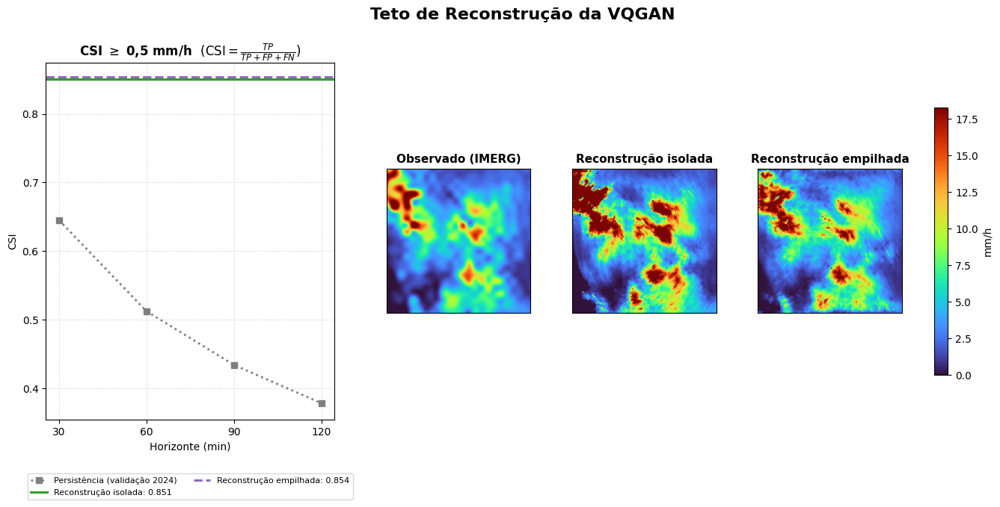

=== Contexto (F-PluvIA Metropolitan — Célula 4.4, teto de reconstrução da VQGAN) ===
  Ambiente: NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus  |  CUDA 13.0  |  VQGAN congelada em float32 + TF32  |  pico de VRAM 75.4 GB
  Dados: validação 2024 — 2224 janelas, 8896 quadros-alvo (posições 8 a 11 da janela), 114 dias  |  teste 2025 não usado
  Modos: quadro isolado (cada quadro sozinho) e empilhado (11 quadros na vertical, como na previsão)
  Decodificação: first_stage_model.decode(quant)
  Exemplo da figura: janela com t final 2024-03-27T11:30 (maior área de chuva no 1º quadro-alvo)

[Célula 4.4] Figura -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/teto_reconstrucao_vqgan_validacao2024_G4_RTX6000_Blackwell_95GB_Cronus.png

                                                    CSI @ 0.5  CSI @ 1.0  CSI @ 5.0  CSI @ 10.0  BIAS @ 0.5  MAE [mm/h]     PCC  Volume Prev/Obs
Método                              Quadro

In [ ]:
# @title
# Célula 4.4: Teto de Reconstrução da VQGAN — codifica e decodifica pela VQGAN congelada quadros OBSERVADOS da
# validação de 2024, sem previsão nenhuma, e compara a reconstrução com o original (CSI, BIAS, MAE, PCC, FSS e SAL).
# Responde: a perda de qualidade dos dois GPTCast já acontece na tradução IMERG -> tokens -> IMERG (gargalo da
# VQGAN) ou na geração autorregressiva do Transformer? Usa só 2024: o teste de 2025 continua intocado.
# Rode depois da Célula 4 e das Células 8 e 11 (SAL e FSS). Não altera modelo, checkpoints nem previsões.
import os
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gptcast.utils.converters import dbz_to_rainfall

# ------------------------------------------------------------------ 1. parâmetros
N_MAX = None            # None = todas as janelas de validação de 2024
LOTE = 16               # janelas por lote na GPU (11 quadros cada)
SAL_STRIDE = 2          # SAL em 1 de cada SAL_STRIDE janelas (o SAL é a etapa mais lenta)
THRESHOLDS = (0.5, 1.0, 5.0, 10.0)
STEP_MIN = 30
ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')

faltam = [n for n in ('gpt8', 'md_rmf', 'RESULTS_ENV_DIR', 'CONTEXT_STEPS', 'FORECAST_STEPS') if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes a Célula 4. Faltam: {", ".join(faltam)}')
if not torch.cuda.is_available():
  raise RuntimeError('A Célula 4.4 passa milhares de quadros pela VQGAN: ative a GPU.')
DEVICE = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

# VQGAN congelada (VAEGANVQ do pacote gptcast): idêntica no Zero-Shot e no Fine-Tuned. Atenção: o GPTCast troca o
# train() da VQGAN por uma função que devolve o próprio argumento, então .eval() nela devolve False, e não o modelo.
# Por isso não se encadeia .eval() aqui; a VQGAN já fica em modo de avaliação desde a criação do GPTCast.
vq = gpt8.first_stage_model
vq.to(DEVICE)
if not hasattr(vq, 'encode'):
  raise RuntimeError('A VQGAN do GPTCast não expõe encode() nesta versão do pacote.')


def _metodos(obj):
  return sorted(n for n in dir(obj) if not n.startswith('_') and callable(getattr(obj, n, None)))


# No código do GPTCast (gptcast/models/vaegan.py), a VQGAN decodifica com decode(z) = decoder(emb_to_z(z)), que é o
# caminho usado na previsão (decode_to_img). As alternativas abaixo só entram se outra versão do pacote mudar isso.
# O caminho usado é impresso na saída.
def _escolher_decodificador():
  for nome in ('decode', 'decode_quant', 'decode_from_quant', 'decode_latent'):
    if callable(getattr(vq, nome, None)):
      return f'first_stage_model.{nome}(quant)', lambda q, idx: getattr(vq, nome)(q)
  if isinstance(getattr(vq, 'decoder', None), torch.nn.Module):
    pq = getattr(vq, 'post_quant_conv', None)
    if isinstance(pq, torch.nn.Module):
      return 'first_stage_model.decoder(post_quant_conv(quant))', lambda q, idx: vq.decoder(pq(q))
    return 'first_stage_model.decoder(quant)', lambda q, idx: vq.decoder(q)
  if callable(getattr(gpt8, 'decode_to_img', None)):
    return 'gpt8.decode_to_img(índices, forma)', lambda q, idx: gpt8.decode_to_img(idx, q.shape)
  raise RuntimeError('Não encontrei como decodificar a VQGAN. Métodos da VQGAN: '
                     f'{_metodos(vq)} | submódulos: {[n for n, _ in vq.named_children()]} | '
                     f'métodos do GPTCast com "decod": {[m for m in _metodos(gpt8) if "decod" in m.lower()]}')


CAMINHO_DECODE, _decode = _escolher_decodificador()

ds = md_rmf.splits['val']
S = ds.sequences_dbz if N_MAX is None else ds.sequences_dbz[:N_MAX]
N, T, H, W = S.shape
C, F = int(CONTEXT_STEPS), int(FORECAST_STEPS)
ts = np.asarray(ds.timestamps)[:N]


def _rain(dbz):
  return np.clip(dbz_to_rainfall(np.clip(np.asarray(dbz, dtype=np.float64), 0.0, 60.0)), 0.0, 205.0).astype(np.float32)


# ------------------------------------------------------------------ 2. reconstrução na GPU
# Mesma normalização do treino (Célula 3): dBZ [0, 60] -> [-1, 1]. Dois modos:
#  - quadro isolado: cada quadro passa sozinho pela VQGAN (fidelidade pura da VQGAN);
#  - empilhado: os 11 quadros da janela empilhados na vertical, como na tokenização da previsão.
@torch.inference_mode()
def reconstruir(lote_dbz, empilhado):
  x = torch.from_numpy(np.clip(lote_dbz, 0, 60) / 30.0 - 1.0).float().to(DEVICE, non_blocking=True)   # (B, T, H, W)
  b, t, h, w = x.shape
  x = x.reshape(b, 1, t * h, w) if empilhado else x.reshape(b * t, 1, h, w)
  quant, _, info = vq.encode(x)
  idx = info.view(quant.shape[0], -1) if torch.is_tensor(info) else (info[2].view(quant.shape[0], -1)
                                                                       if isinstance(info, (tuple, list)) else None)
  rec = _decode(quant, idx)
  rec = (rec[0] if isinstance(rec, (tuple, list)) else rec).float().clamp(-1, 1)
  return ((rec.reshape(b, t, h, w) + 1.0) * 30.0).cpu().numpy()


obs_t = _rain(S[:, C:C + F])                                     # quadros-alvo observados (N, 4, H, W), mm/h
rec_iso = np.empty_like(obs_t)
rec_stk = np.empty_like(obs_t)
torch.cuda.reset_peak_memory_stats(0)
torch.cuda.synchronize()
t0 = time.perf_counter()
for a in range(0, N, LOTE):
  bloco = np.asarray(S[a:a + LOTE], dtype=np.float32)
  rec_iso[a:a + LOTE] = _rain(reconstruir(bloco, False)[:, C:C + F])
  rec_stk[a:a + LOTE] = _rain(reconstruir(bloco, True)[:, C:C + F])
torch.cuda.synchronize()
t_rec = time.perf_counter() - t0
pers = np.repeat(_rain(S[:, C - 1:C]), F, axis=1)               # persistência do último quadro de contexto

METODOS = {'Reconstrução VQGAN (quadro isolado)': rec_iso, 'Reconstrução VQGAN (empilhada)': rec_stk,
           'Persistência (referência)': pers}


# ------------------------------------------------------------------ 3. métricas por pixel
def _linha(o, p, nome, rotulo):
  o64, p64 = o.astype(np.float64), p.astype(np.float64)
  r = {'Método': nome, 'Quadros': rotulo, 'MAE [mm/h]': float(np.mean(np.abs(p64 - o64))),
       'PCC': float(np.corrcoef(o64.ravel(), p64.ravel())[0, 1]), 'Volume Prev/Obs': float(p64.sum() / o64.sum())}
  for thr in THRESHOLDS:
    ob, pb = o >= thr, p >= thr
    tp, fp, fn = float(np.sum(ob & pb)), float(np.sum(~ob & pb)), float(np.sum(ob & ~pb))
    r[f'CSI @ {thr}'] = tp / (tp + fp + fn) if tp + fp + fn else np.nan
    r[f'BIAS @ {thr}'] = (tp + fp) / (tp + fn) if tp + fn else np.nan
  return r


linhas = []
for nome, P in METODOS.items():
  if nome.startswith('Persist'):
    for s in range(F):
      linhas.append(_linha(obs_t[:, s], P[:, s], nome, f'+{STEP_MIN * (s + 1)} min'))
  else:
    linhas.append(_linha(obs_t, P, nome, 'todos os alvos'))
df = pd.DataFrame(linhas)

csi_iso = float(df.loc[df['Método'].str.contains('isolado'), 'CSI @ 0.5'].iloc[0])
csi_stk = float(df.loc[df['Método'].str.contains('empilhada'), 'CSI @ 0.5'].iloc[0])
pers_csi = df.loc[df['Método'].str.startswith('Persist'), 'CSI @ 0.5'].to_numpy(float)
csi_rec = max(csi_iso, csi_stk)

# ------------------------------------------------------------------ 4. FSS e SAL (Células 11 e 8)
print(f'[Célula 4.4] Reconstrução de {N} janelas ({N * F} quadros-alvo, dois modos) em {t_rec:.0f} s. '
      'Calculando FSS e SAL (alguns minutos) ...', flush=True)
df_fss = fss_over_set(obs_t, METODOS, thr=0.5) if 'fss_over_set' in globals() else pd.DataFrame()
sel = slice(None, None, SAL_STRIDE)
df_sal = (sal_over_set(obs_t[sel], {n: p[sel] for n, p in METODOS.items()})
          if 'sal_over_set' in globals() else pd.DataFrame())


def _sal(nome, col):
  if not len(df_sal) or col not in df_sal.columns:
    return np.nan
  return float(pd.to_numeric(df_sal.loc[df_sal['Modelo'] == nome, col], errors='coerce').median())


S_rec = np.nanmin([_sal('Reconstrução VQGAN (quadro isolado)', 'S mediana'),
                   _sal('Reconstrução VQGAN (empilhada)', 'S mediana')])

# ------------------------------------------------------------------ 5. diagnóstico
_c = lambda v: f'{v:.3f}'.replace('.', ',')
if csi_rec < pers_csi[0]:
  diag = (f'A VQGAN é um gargalo: reconstruindo quadros observados, sem prever nada, o CSI ≥ 0,5 mm/h fica em '
          f'{_c(csi_rec)}, abaixo da persistência de +30 min ({_c(pers_csi[0])}). Nenhum Transformer, ajustado ou não, '
          'pode superar esse teto; isso explica boa parte do desempenho dos dois GPTCast no teste de 2025.')
elif csi_rec < pers_csi[0] + 0.05:
  diag = (f'A VQGAN limita, mas não explica tudo sozinha: a reconstrução (CSI {_c(csi_rec)}) fica no nível da '
          f'persistência de +30 min ({_c(pers_csi[0])}). Sobra pouca margem para o Transformer superar a extrapolação; '
          'parte da perda dos GPTCast vem também da geração autorregressiva.')
else:
  diag = (f'A VQGAN reconstrói bem: CSI {_c(csi_rec)}, acima da persistência de +30 min ({_c(pers_csi[0])}). O '
          'gargalo dos GPTCast está na geração autorregressiva (sorteio de tokens e deriva ao longo do horizonte), '
          'não na tradução IMERG -> tokens.')
if np.isfinite(S_rec) and S_rec < -0.3:
  diag += (f' O componente S do SAL da reconstrução ({_c(S_rec)}) é fortemente negativo, como nos dois GPTCast: '
           'a própria VQGAN deixa os objetos de chuva menores e mais pontudos.')
elif np.isfinite(S_rec):
  diag += (f' O componente S do SAL da reconstrução ({_c(S_rec)}) é pequeno: a deformação de estrutura vista nos '
           'GPTCast não vem da VQGAN, e sim da geração.')
if abs(csi_iso - csi_stk) > 0.02:
  diag += (f' O empilhamento muda a reconstrução (isolado {_c(csi_iso)} × empilhado {_c(csi_stk)}): as convoluções '
           'misturam informação entre quadros vizinhos na pilha.')

# ------------------------------------------------------------------ 6. figura
fig = plt.figure(figsize=(17, 6.2))
gs = fig.add_gridspec(1, 4, width_ratios=[1.6, 1, 1, 1], wspace=0.25)
fig.suptitle('Teto de Reconstrução da VQGAN', fontsize=16, fontweight='bold', y=1.0)

ax = fig.add_subplot(gs[0, 0])
hz = np.arange(1, F + 1) * STEP_MIN
ax.plot(hz, pers_csi, 's:', color='#7f7f7f', lw=2, label='Persistência (validação 2024)')
ax.axhline(csi_iso, color='#2ca02c', lw=2.2, label=f'Reconstrução isolada: {csi_iso:.3f}')
ax.axhline(csi_stk, color='#9467bd', lw=2.2, ls='--', label=f'Reconstrução empilhada: {csi_stk:.3f}')
r12 = globals().get('CELL12_FULL_2025_RESULTS')
if isinstance(r12, dict) and 'ft_rain' in r12:
  for k, nome, cor, mk in (('ft_rain', 'Fine-Tuned', '#d62728', 'o'), ('zs_rain', 'Zero-Shot', '#ff7f0e', 'v')):
    v = [_linha(r12['obs_rain'][:, s], r12[k][:, s], nome, '')['CSI @ 0.5'] for s in range(F)]
    ax.plot(hz, v, marker=mk, color=cor, lw=1.2, alpha=0.55, label=f'GPTCast {nome} (teste 2025, referência)')
ax.set_title(r'CSI $\geq$ 0,5 mm/h  $(\mathrm{CSI} = \frac{TP}{TP + FP + FN})$', fontweight='bold')
ax.set_xlabel('Horizonte (min)')
ax.set_ylabel('CSI')
ax.set_xticks(hz)
ax.grid(True, ls=':', alpha=0.6)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)   # abaixo do gráfico: não cobre as linhas

i_ex = int(np.argmax((obs_t[:, 0] >= 0.5).sum(axis=(1, 2))))   # janela com maior área de chuva no 1º alvo
vmax = float(np.percentile(obs_t[i_ex, 0][obs_t[i_ex, 0] > 0], 99)) if (obs_t[i_ex, 0] > 0).any() else 10.0
for j, (img, tit) in enumerate(((obs_t[i_ex, 0], 'Observado (IMERG)'), (rec_iso[i_ex, 0], 'Reconstrução isolada'),
                                (rec_stk[i_ex, 0], 'Reconstrução empilhada'))):
  a = fig.add_subplot(gs[0, j + 1])
  im = a.imshow(img, cmap='turbo', vmin=0, vmax=vmax)
  a.set_title(tit, fontweight='bold', fontsize=11)
  a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=fig.axes[1:], shrink=0.75, label='mm/h')

png = os.path.join(RESULTS_ENV_DIR, f'teto_reconstrucao_vqgan_validacao2024_{ENV_TAG}.png')
fig.savefig(png, dpi=200, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ 7. saída de texto e arquivos
df.round(4).to_csv(os.path.join(RESULTS_ENV_DIR, f'teto_vqgan_metricas_validacao2024_{ENV_TAG}.csv'), index=False)
if len(df_fss):
  df_fss.to_csv(os.path.join(RESULTS_ENV_DIR, f'teto_vqgan_fss_validacao2024_{ENV_TAG}.csv'), index=False)
if len(df_sal):
  df_sal.to_csv(os.path.join(RESULTS_ENV_DIR, f'teto_vqgan_sal_validacao2024_{ENV_TAG}.csv'), index=False)

print('=== Contexto (F-PluvIA Metropolitan — Célula 4.4, teto de reconstrução da VQGAN) ===')
for ln in (
    f'Ambiente: {ENV_LABEL}  |  CUDA {torch.version.cuda}  |  VQGAN congelada em float32 + TF32  |  '
    f'pico de VRAM {torch.cuda.max_memory_allocated(0) / 2**30:.1f} GB',
    f'Dados: validação 2024 — {N} janelas, {N * F} quadros-alvo (posições {C + 1} a {C + F} da janela), '
    f'{len(np.unique(pd.to_datetime(ts).normalize()))} dias  |  teste 2025 não usado',
    'Modos: quadro isolado (cada quadro sozinho) e empilhado (11 quadros na vertical, como na previsão)',
    f'Decodificação: {CAMINHO_DECODE}',
    f'Exemplo da figura: janela com t final {str(ts[i_ex])[:16]} (maior área de chuva no 1º quadro-alvo)',
):
  print('  ' + ln)
print(f'\n[Célula 4.4] Figura -> {png}\n')
cols = ['Método', 'Quadros', 'CSI @ 0.5', 'CSI @ 1.0', 'CSI @ 5.0', 'CSI @ 10.0', 'BIAS @ 0.5', 'MAE [mm/h]', 'PCC',
        'Volume Prev/Obs']
print(df[cols].round(4).set_index(['Método', 'Quadros']).to_string())
if len(df_fss):
  cf = [c for c in df_fss.columns if c.startswith('FSS @')][:6] + [c for c in df_fss.columns if 'Escala' in c]
  print('\n--- FSS (≥ 0,5 mm/h) ---')
  print(df_fss.set_index(['Modelo', 'Lead Time'])[cf].round(4).to_string())
if len(df_sal):
  cs = [c for c in ('S mediana', 'A mediana', 'L mediana', 'Shift_km mediana', 'Razao_Volume mediana') if c in df_sal.columns]
  print(f'\n--- SAL (mediana; 1 de cada {SAL_STRIDE} janelas) ---')
  print(df_sal.set_index(['Modelo', 'Lead Time'])[cs].to_string())
print('\nNa reconstrução, "Lead Time" é só a posição do quadro-alvo: a VQGAN não prevê nada, apenas reconstrói o quadro observado.')
print('\n=== Diagnóstico automático (regras desta célula) ===')
print(textwrap.fill(diag, 110))
print(textwrap.fill('Regras: compara o melhor CSI ≥ 0,5 mm/h da reconstrução com a persistência de +30 min na mesma '
                    'validação de 2024. Abaixo dela = VQGAN é gargalo; até 0,05 acima = limita, mas não explica tudo; '
                    'mais que isso = gargalo na geração. S do SAL da reconstrução abaixo de −0,3 = a VQGAN deforma a '
                    'estrutura da chuva. As curvas do GPTCast na figura são do teste de 2025 e servem só de referência '
                    'visual (anos diferentes).', 110))

CELL4_4_TETO_VQGAN = {'csi05_reconstrucao_isolada': csi_iso, 'csi05_reconstrucao_empilhada': csi_stk,
                      'csi05_persistencia_por_horizonte': pers_csi.tolist(), 'sal_S_reconstrucao': S_rec,
                      'n_janelas': N, 'diagnostico': diag}


## ⚠️ Célula 4.5 (Sensibilidade da Amostragem do GPTCast): Temperatura, *Top-k*, Escolha Gulosa e Média de Sorteios na Validação de 2024, Comparadas ao Padrão do `forecast()` e à Persistência (`ENV_TAG`)

⚠️ Opcional: as saídas desta célula já estão no Drive; pode ser pulada no fluxo de publicação. A 4.3 refaz o ajuste fino e não deve ser executada sem necessidade.

* **Contexto**: A Célula 4.4 mostrou que a VQGAN reconstrói bem o IMERG a 2 km (CSI de cerca de 0,85), então a perda dos GPTCast está na **geração dos tokens**. O código do pacote `gptcast` mostra que o `forecast()` sorteia cada token de **toda** a distribuição (temperatura 1, sem *top-k*), e a Célula 12 usa **um único sorteio** por janela. Um sorteio puro espalha a chuva ao acaso e é punido pelo CSI e pelo FSS diante de métodos determinísticos. Esta célula mede quanto da diferença vem dessa escolha.

* **Configurações Comparadas** (no Fine-Tuned e no Zero-Shot):
  - **Padrão** (temperatura 1, sem *top-k*): o mesmo do `forecast()` e da Célula 12;
  - ***top-k* 50** e ***top-k* 10**: sorteia só entre os k tokens mais prováveis;
  - **temperatura 0,7**: concentra a distribuição nos tokens mais prováveis;
  - **gulosa (*top-k* 1)**: sempre o token mais provável, sem sorteio;
  - **média de 8 sorteios**: pequeno *ensemble* gerado num só lote na GPU, com a média feita em mm/h.

* **Gerador**: Reproduz o `predict_sequence()` do pacote (contexto de 7 quadros empilhado e codificado pela VQGAN em `float32`; tokens gerados pelo Transformer em `bf16` na janela espacial do modelo; cada quadro previsto decodificado isolado), expondo temperatura e *top-k*. Uma conferência inicial compara o padrão desta célula com o `forecast()` do pacote na mesma janela e semente.

* **Amostra e Retomada**: 240 janelas da validação de 2024 sorteadas com semente fixa (cerca de 20 s por janela na G4, cerca de 80 min no total). Cada janela é salva no Drive ao terminar; com `TEMPO_MAX_MIN` atingido, a célula para, mostra o resultado **parcial** e continua de onde parou na próxima execução.

* **Métricas e Regra de Decisão**: CSI em 0,5; 1,0; 5,0 e 10,0 mm/h, BIAS, MAE, razão de volume, FSS a 2 km (Célula 11) e deslocamento e S do SAL (Célula 8), contra a **persistência** nas mesmas janelas. Uma amostragem só substitui o padrão se o IC de 95% do ΔCSI no limiar de 0,5 mm/h contra o padrão (*bootstrap* por dias) ficar todo **acima de zero**; entre as que passam, vale a de maior CSI. A célula também informa se a escolhida supera a persistência.

* **Cuidado com a Média de Sorteios**: o campo médio é suavizado. Costuma melhorar o acerto por pixel, mas não é um cenário de chuva realista e tende a atenuar a chuva forte. Por isso a tabela mostra também o CSI em 5 e 10 mm/h e o S do SAL.

* **Isolamento do Teste**: a escolha usa só 2024. Aplicá-la ao teste de 2025 exige rodar a Célula 12 com a amostragem escolhida, numa pasta de previsões nova.

* **Saídas**: Figura `sensibilidade_amostragem_validacao2024_<ENV_TAG>.png` (CSI por horizonte de cada configuração, Fine-Tuned e Zero-Shot, com a persistência), as tabelas `sensibilidade_amostragem_...csv` e a variável `CELL4_5_AMOSTRAGEM`. O contexto, a tabela e a decisão ficam na saída de texto.

* **Requisito**: rodar antes a Célula 4 e as Células 8 e 11. A célula não altera modelos, checkpoints nem as previsões da Célula 12.

[Célula 4.5] Conferência com o forecast() do pacote: diferença máxima 0.00e+00 mm/h -> idêntico.
[Célula 4.5] 240 janelas sorteadas da validação de 2024 | 0 já prontas | faltam 240 | 6 configurações x 2 modelos | orçamento 150 min
  1/240 janelas | 31.5 s/janela | faltam ~126 min
  10/240 janelas | 30.9 s/janela | faltam ~118 min
  20/240 janelas | 30.8 s/janela | faltam ~113 min
  30/240 janelas | 30.8 s/janela | faltam ~108 min
  40/240 janelas | 30.8 s/janela | faltam ~103 min
  50/240 janelas | 30.8 s/janela | faltam ~98 min
  60/240 janelas | 30.8 s/janela | faltam ~92 min
  70/240 janelas | 30.8 s/janela | faltam ~87 min
  80/240 janelas | 30.8 s/janela | faltam ~82 min
  90/240 janelas | 30.8 s/janela | faltam ~77 min
  100/240 janelas | 30.8 s/janela | faltam ~72 min
  110/240 janelas | 30.8 s/janela | faltam ~67 min
  120/240 janelas | 30.8 s/janela | faltam ~62 min
  130/240 janelas | 30.8 s/janela | faltam ~56 min
  140/240 janelas | 30.8 s/janela | faltam ~51 min
  150/240 

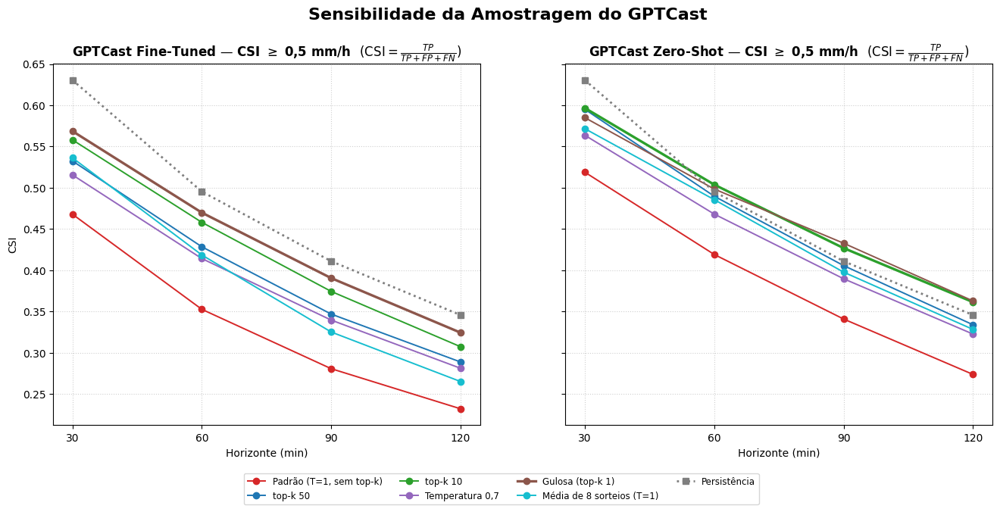

=== Contexto (F-PluvIA Metropolitan — Célula 4.5, sensibilidade da amostragem) ===
  Ambiente: NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus  |  CUDA 13.0  |  Transformer em bf16, VQGAN em float32 (padrões do gptcast)
  Dados: validação 2024 — 240 de 240 janelas sorteadas (semente 42), 92 dias  |  teste 2025 não usado
  Gerador: igual ao predict_sequence() do pacote, com temperatura e top-k expostos; janela espacial 8x8 tokens; conferência com o forecast(): idêntico
  Média de sorteios: 8 membros gerados num só lote, média em mm/h  |  previsões em amostragem_val2024_5f137bdbd4_9a0d75b9

[Célula 4.5] Figura -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/sensibilidade_amostragem_validacao2024_G4_RTX6000_Blackwell_95GB_Cronus.png

                                        CSI @ 0.5  CSI @ 5.0  CSI @ 10.0  BIAS @ 0.5  MAE [mm/h]  Volume Prev/Obs  FSS 2 km (média dos horizontes)  Deslocamento SAL [km] (média das 

In [ ]:
# @title
# Célula 4.5: Sensibilidade da Amostragem do GPTCast — na validação de 2024, compara a forma de sortear os tokens
# (padrão do forecast(): temperatura 1 e sem top-k; top-k 50 e 10; temperatura 0,7; escolha gulosa; e a média de
# 8 sorteios) no Fine-Tuned e no Zero-Shot, contra a persistência. Escolhe a configuração em 2024 para depois
# aplicá-la no teste de 2025, sem usar 2025 na escolha. Retomável por janela; não altera modelos nem checkpoints.
import contextlib
import glob
import hashlib
import io
import json
import math
import os
import textwrap
import time
import warnings

import einops
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gptcast.utils.converters import dbz_to_rainfall

# ------------------------------------------------------------------ 1. parâmetros
N_JANELAS = 240          # janelas da validação de 2024 sorteadas (semente fixa); cerca de 20 s por janela na G4
N_MEMBROS = 8            # sorteios da média (gerados juntos, num só lote na GPU)
TEMPO_MAX_MIN = 150      # orçamento desta execução; o que ficar pronto é salvo e a próxima continua
SAL_STRIDE = 1
SEED = 42
STEP_MIN = 30
THRESHOLDS = (0.5, 1.0, 5.0, 10.0)
N_BOOT = 2000
# nome -> (temperatura, top_k, membros)
CONFIGS = {
    'Padrão (T=1, sem top-k)': (1.0, None, 1),
    'top-k 50': (1.0, 50, 1),
    'top-k 10': (1.0, 10, 1),
    'Temperatura 0,7': (0.7, None, 1),
    'Gulosa (top-k 1)': (1.0, 1, 1),
    f'Média de {N_MEMBROS} sorteios (T=1)': (1.0, None, N_MEMBROS),
}
PADRAO = 'Padrão (T=1, sem top-k)'
ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')

faltam = [n for n in ('gpt8', 'gpt8_zeroshot', 'md_rmf', 'RESULTS_ENV_DIR', 'CONTEXT_STEPS', 'FORECAST_STEPS')
          if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes a Célula 4. Faltam: {", ".join(faltam)}')
if not torch.cuda.is_available():
  raise RuntimeError('A Célula 4.5 gera milhares de previsões do GPTCast: ative a GPU.')
DEVICE = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
gpt8, gpt8_zeroshot = gpt8.to(DEVICE).eval(), gpt8_zeroshot.to(DEVICE).eval()
MODELOS = {'Fine-Tuned': gpt8, 'Zero-Shot': gpt8_zeroshot}
C, F = int(CONTEXT_STEPS), int(FORECAST_STEPS)
WS = int(math.sqrt(gpt8.transformer.config.block_size // 8))     # janela espacial do GPT, como no forecast()

ds = md_rmf.splits['val']
rng0 = np.random.default_rng(SEED)
SEL = np.sort(rng0.choice(len(ds.sequences_dbz), size=min(N_JANELAS, len(ds.sequences_dbz)), replace=False))
ts_sel = np.asarray(ds.timestamps)[SEL]


def _rain(dbz):
  return np.clip(dbz_to_rainfall(np.clip(np.asarray(dbz, dtype=np.float64), 0.0, 60.0)), 0.0, 205.0).astype(np.float32)


def _digest(model):
  h = hashlib.sha256()
  for k, v in sorted(model.state_dict().items()):
    if k.startswith('transformer.'):
      h.update(k.encode())
      h.update(v.detach().float().cpu().numpy().tobytes())
  return h.hexdigest()[:10]


TAG = hashlib.sha256(json.dumps([list(CONFIGS.items()), SEL.tolist(), SEED]).encode()).hexdigest()[:8]
CACHE = os.path.join(RESULTS_ENV_DIR, f'amostragem_val2024_{_digest(gpt8)}_{TAG}')
os.makedirs(CACHE, exist_ok=True)


# ------------------------------------------------------------------ 2. gerador com controle da amostragem
# Reproduz o predict_sequence() do pacote gptcast (o mesmo que o forecast() chama): contexto de 7 quadros empilhado
# e codificado pela VQGAN em float32, tokens do próximo quadro gerados pelo Transformer em bf16 dentro da janela
# espacial WS x WS, cada quadro previsto decodificado isolado. A diferença é expor temperatura e top-k e gerar
# vários sorteios de uma vez (o código do GPTCast já aceita a dimensão de lote).
# O predict_next_frame_indices() do pacote grava cada token com predicted_indices[:, i, j] = res, e o
# predict_next_index() devolve res com forma (lote, 1). Com lote 1 isso passa, mas com vários sorteios no mesmo lote
# dá erro de forma. Durante a geração em lote, o predict_next_index() deste modelo é envolvido para devolver (lote,),
# sem mudar o sorteio; ao sair, o método original volta (as outras células não são afetadas).
@contextlib.contextmanager
def _lote(model, n):
  if n == 1:
    yield
    return
  original = model.predict_next_index
  model.predict_next_index = lambda contexto, temperature=1.0, top_k=None: original(contexto, temperature, top_k)[:, 0]
  try:
    yield
  finally:
    del model.predict_next_index


@torch.inference_mode()
def gerar(model, ctx_dbz, temperatura, top_k, n, seed):
  torch.manual_seed(seed)
  x = torch.tensor(np.clip(ctx_dbz, 0, 60) / 30.0 - 1.0, dtype=torch.float32, device=DEVICE)   # (s, h, w)
  s = x.shape[0]
  xs = einops.rearrange(x, 's h w -> (s h) w')[None, None].contiguous()
  quant, idx = model.encode_to_z(xs)
  _, c_idx = model.encode_to_c(xs)
  qs = quant.shape
  ind = idx.reshape(qs[0], s, qs[2] // s, qs[3]).repeat(n, 1, 1, 1)
  c_idx = c_idx.repeat(n, 1)
  ih, iw = ind.shape[2], ind.shape[3]
  quadros = []
  for _ in range(F):
    with torch.autocast('cuda', dtype=torch.bfloat16), _lote(model, n):
      p = model.predict_next_frame_indices(ind[:, -s:], c_idx, WS, temperature=temperatura, top_k=top_k,
                                           show_progress=False)
    quadros.append(model.decode_to_img(p.reshape(n, -1), torch.Size([n, qs[1], ih, iw])))
    ind = torch.cat((ind, p[:, None]), dim=1)
  y = torch.cat(quadros, dim=1).float().cpu().numpy().clip(-1, 1)                             # (n, F, h, w)
  return _rain((y + 1.0) * 30.0)


@contextlib.contextmanager
def _silencio():
  with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
    warnings.simplefilter('ignore')
    yield


# Conferência: com 1 sorteio e a mesma semente, o gerador deve repetir o forecast() do pacote.
ctx0 = np.clip(np.asarray(ds.sequences_dbz[SEL[0], :C], dtype=np.float32), 0, 60)
torch.manual_seed(SEED)
with _silencio():
  ref = gpt8.forecast(ctx0, steps=F, units='dbz', verbosity=0)
ref = _rain(np.asarray(ref.filled(0.0) if isinstance(ref, np.ma.MaskedArray) else ref))
dif_ref = float(np.max(np.abs(gerar(gpt8, ctx0, 1.0, None, 1, SEED)[0] - ref)))
CONFERE = dif_ref < 1e-3
print(f'[Célula 4.5] Conferência com o forecast() do pacote: diferença máxima {dif_ref:.2e} mm/h -> '
      + ('idêntico.' if CONFERE else 'NÃO idêntico (o padrão desta célula pode diferir da Célula 12).'))

# ------------------------------------------------------------------ 3. execução retomável
feitas = {int(os.path.basename(p)[7:12]) for p in glob.glob(os.path.join(CACHE, 'janela_*.npz'))}
pend = [i for i in SEL if int(i) not in feitas]
print(f'[Célula 4.5] {len(SEL)} janelas sorteadas da validação de 2024 | {len(SEL) - len(pend)} já prontas | '
      f'faltam {len(pend)} | {len(CONFIGS)} configurações x {len(MODELOS)} modelos | orçamento {TEMPO_MAX_MIN} min')
t_ini, tempos = time.perf_counter(), []
for n_f, i in enumerate(pend, 1):
  if (time.perf_counter() - t_ini) / 60 > TEMPO_MAX_MIN:
    print(f'[Célula 4.5] Orçamento de {TEMPO_MAX_MIN} min atingido: rode de novo para continuar.')
    break
  t_j = time.perf_counter()
  ctx = np.clip(np.asarray(ds.sequences_dbz[i, :C], dtype=np.float32), 0, 60)
  out = {}
  with _silencio():
    for nm, model in MODELOS.items():
      for k, (temp, topk, n) in enumerate(CONFIGS.values()):
        p = gerar(model, ctx, temp, topk, n, SEED + int(i) + (0 if n == 1 else 100_000))
        out[f'{nm}|{k}'] = (p.mean(axis=0) if n > 1 else p[0]).astype(np.float16)
  np.savez_compressed(os.path.join(CACHE, f'janela_{int(i):05d}.npz'), **{k.replace('|', '__'): v for k, v in out.items()})
  tempos.append(time.perf_counter() - t_j)
  if n_f == 1 or n_f % 10 == 0:
    m = float(np.mean(tempos[-20:]))
    print(f'  {len(SEL) - len(pend) + n_f}/{len(SEL)} janelas | {m:.1f} s/janela | faltam ~{(len(pend) - n_f) * m / 60:.0f} min',
          flush=True)

# ------------------------------------------------------------------ 4. montagem (só janelas prontas)
prontas = np.array(sorted(i for i in SEL if os.path.exists(os.path.join(CACHE, f'janela_{int(i):05d}.npz'))))
if len(prontas) == 0:
  raise RuntimeError('Nenhuma janela pronta ainda.')
PARCIAL = len(prontas) < len(SEL)
obs = _rain(np.asarray(ds.sequences_dbz[prontas, C:C + F]))
pers = np.repeat(_rain(np.asarray(ds.sequences_dbz[prontas, C - 1:C])), F, axis=1)
P = {}
for nm in MODELOS:
  for k, cfg in enumerate(CONFIGS):
    P[(nm, cfg)] = np.stack([np.load(os.path.join(CACHE, f'janela_{int(i):05d}.npz'))[f'{nm}__{k}'] for i in prontas]).astype(np.float32)
ts_p = np.asarray(ds.timestamps)[prontas]


# ------------------------------------------------------------------ 5. métricas
def _cont(o, p, thr):
  ob, pb = o >= thr, p >= thr
  return float(np.sum(ob & pb)), float(np.sum(~ob & pb)), float(np.sum(ob & ~pb))


def _csi(tp, fp, fn):
  return tp / (tp + fp + fn) if tp + fp + fn else np.nan


def _resumo(o, p):
  r = {}
  for thr in THRESHOLDS:
    tp, fp, fn = _cont(o, p, thr)
    r[f'CSI @ {thr}'] = _csi(tp, fp, fn)
  tp, fp, fn = _cont(o, p, 0.5)
  r['BIAS @ 0.5'] = (tp + fp) / (tp + fn) if tp + fn else np.nan
  r['MAE [mm/h]'] = float(np.mean(np.abs(p.astype(np.float64) - o)))
  r['Volume Prev/Obs'] = float(p.sum(dtype=np.float64) / o.sum(dtype=np.float64))
  return r


dias = pd.to_datetime(ts_p).normalize().values
ud, inv = np.unique(dias, return_inverse=True)
am = np.random.default_rng(SEED).integers(0, len(ud), (N_BOOT, len(ud)))


def _por_janela(p):
  ob, pb = obs >= 0.5, p >= 0.5
  return [np.bincount(inv, np.sum(a, axis=(1, 2, 3)).astype(float), len(ud)) for a in (ob & pb, ~ob & pb, ob & ~pb)]


def _boot_csi(p):
  tp, fp, fn = _por_janela(p)
  return tp[am].sum(1) / (tp[am].sum(1) + fp[am].sum(1) + fn[am].sum(1))


csi_pers_boot = _boot_csi(pers)
linhas, lead_rows = [], []
for nm in MODELOS:
  base = _boot_csi(P[(nm, PADRAO)])
  for cfg in CONFIGS:
    p = P[(nm, cfg)]
    r = {'Modelo': nm, 'Amostragem': cfg, **_resumo(obs, p)}
    b = _boot_csi(p)
    d, dp = b - base, b - csi_pers_boot
    r['ΔCSI vs padrão (IC 95%)'] = '—' if cfg == PADRAO else f'{np.percentile(d, 2.5):+.3f} a {np.percentile(d, 97.5):+.3f}'
    r['_d_lo'], r['_d_hi'] = (np.nan, np.nan) if cfg == PADRAO else (np.percentile(d, 2.5), np.percentile(d, 97.5))
    r['ΔCSI vs persistência (IC 95%)'] = f'{np.percentile(dp, 2.5):+.3f} a {np.percentile(dp, 97.5):+.3f}'
    r['_p_lo'] = np.percentile(dp, 2.5)
    linhas.append(r)
    for s in range(F):
      lead_rows.append({'Modelo': nm, 'Amostragem': cfg, 'Horizonte': STEP_MIN * (s + 1),
                        'CSI @ 0.5': _csi(*_cont(obs[:, s], p[:, s], 0.5))})
r_p = {'Modelo': 'Persistência', 'Amostragem': '—', **_resumo(obs, pers), 'ΔCSI vs padrão (IC 95%)': '—',
       'ΔCSI vs persistência (IC 95%)': '—'}
linhas.append(r_p)
for s in range(F):
  lead_rows.append({'Modelo': 'Persistência', 'Amostragem': '—', 'Horizonte': STEP_MIN * (s + 1),
                    'CSI @ 0.5': _csi(*_cont(obs[:, s], pers[:, s], 0.5))})
df = pd.DataFrame(linhas)
df_lead = pd.DataFrame(lead_rows)

print('[Célula 4.5] Previsões prontas. Calculando FSS e SAL (alguns minutos) ...', flush=True)
nomes = {f'{nm} | {cfg}': P[(nm, cfg)] for nm in MODELOS for cfg in CONFIGS}
nomes['Persistência'] = pers
df_fss = fss_over_set(obs, nomes, thr=0.5) if 'fss_over_set' in globals() else pd.DataFrame()
sel = slice(None, None, SAL_STRIDE)
df_sal = sal_over_set(obs[sel], {n: p[sel] for n, p in nomes.items()}) if 'sal_over_set' in globals() else pd.DataFrame()


def _med(dfx, nome, col):
  if not len(dfx) or col not in dfx.columns:
    return np.nan
  return float(pd.to_numeric(dfx.loc[dfx['Modelo'] == nome, col], errors='coerce').mean())


df['Chave'] = [f'{m} | {a}' if m != 'Persistência' else 'Persistência' for m, a in zip(df['Modelo'], df['Amostragem'])]
df['FSS 2 km (média dos horizontes)'] = [_med(df_fss, k, 'FSS @ 2 km') for k in df['Chave']]
df['Deslocamento SAL [km] (média das medianas)'] = [_med(df_sal, k, 'Shift_km mediana') for k in df['Chave']]
df['S do SAL (média das medianas)'] = [_med(df_sal, k, 'S mediana') for k in df['Chave']]

# ------------------------------------------------------------------ 6. decisão
_c = lambda v: f'{v:.3f}'.replace('.', ',')
textos = []
ESCOLHA = {}
for nm in MODELOS:
  d = df[(df['Modelo'] == nm) & (df['Amostragem'] != PADRAO)]
  melhores = d[d['_d_lo'] > 0].sort_values('CSI @ 0.5', ascending=False)
  base = float(df[(df['Modelo'] == nm) & (df['Amostragem'] == PADRAO)]['CSI @ 0.5'].iloc[0])
  if len(melhores):
    m = melhores.iloc[0]
    ESCOLHA[nm] = m['Amostragem']
    t = (f'{nm}: a melhor amostragem é "{m["Amostragem"]}" (CSI ≥ 0,5 mm/h {_c(m["CSI @ 0.5"])} contra {_c(base)} no '
         f'padrão; ΔCSI IC 95 % {m["ΔCSI vs padrão (IC 95%)"]}).')
    t += (' Ela supera a persistência (IC todo acima de zero).' if m['_p_lo'] > 0 else
          f' Mesmo assim não supera a persistência (CSI {_c(r_p["CSI @ 0.5"])}; ΔCSI IC 95 % {m["ΔCSI vs persistência (IC 95%)"]}).')
  else:
    ESCOLHA[nm] = PADRAO
    t = f'{nm}: nenhuma amostragem é comprovadamente melhor que o padrão (CSI {_c(base)}).'
  textos.append(t)
diag = ' '.join(textos)
if any('Média' in v for v in ESCOLHA.values()):
  diag += (' Atenção: a média de sorteios é um campo suavizado (melhora o acerto por pixel, mas não é um cenário de '
           'chuva realista; a chuva forte tende a ser atenuada). Confira o CSI ≥ 5 e 10 mm/h e o S do SAL antes de adotá-la.')

# ------------------------------------------------------------------ 7. figura
cores = dict(zip(CONFIGS, ['#d62728', '#1f77b4', '#2ca02c', '#9467bd', '#8c564b', '#17becf']))
fig, axs = plt.subplots(1, 2, figsize=(16, 6.2), sharey=True)
fig.suptitle('Sensibilidade da Amostragem do GPTCast', fontsize=16, fontweight='bold', y=1.0)
hz = np.arange(1, F + 1) * STEP_MIN
for ax, nm in zip(axs, MODELOS):
  for cfg in CONFIGS:
    v = df_lead[(df_lead['Modelo'] == nm) & (df_lead['Amostragem'] == cfg)]['CSI @ 0.5'].to_numpy()
    ax.plot(hz, v, 'o-', color=cores[cfg], lw=2.4 if cfg == ESCOLHA[nm] else 1.4, label=cfg)
  vp = df_lead[df_lead['Modelo'] == 'Persistência']['CSI @ 0.5'].to_numpy()
  ax.plot(hz, vp, 's:', color='#7f7f7f', lw=2, label='Persistência')
  ax.set_title(rf'GPTCast {nm} — CSI $\geq$ 0,5 mm/h  $(\mathrm{{CSI}} = \frac{{TP}}{{TP + FP + FN}})$', fontweight='bold')
  ax.set_xlabel('Horizonte (min)')
  ax.set_xticks(hz)
  ax.grid(True, ls=':', alpha=0.6)
axs[0].set_ylabel('CSI')
axs[0].legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(1.05, -0.12), ncol=4)   # abaixo dos gráficos
png = os.path.join(RESULTS_ENV_DIR, f'sensibilidade_amostragem_validacao2024_{ENV_TAG}.png')
fig.savefig(png, dpi=200, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------ 8. saída de texto e arquivos
cols = ['Modelo', 'Amostragem', 'CSI @ 0.5', 'CSI @ 5.0', 'CSI @ 10.0', 'BIAS @ 0.5', 'MAE [mm/h]', 'Volume Prev/Obs',
        'FSS 2 km (média dos horizontes)', 'Deslocamento SAL [km] (média das medianas)', 'S do SAL (média das medianas)',
        'ΔCSI vs padrão (IC 95%)', 'ΔCSI vs persistência (IC 95%)']
df[cols].round(4).to_csv(os.path.join(RESULTS_ENV_DIR, f'sensibilidade_amostragem_validacao2024_{ENV_TAG}.csv'), index=False)
df_lead.to_csv(os.path.join(RESULTS_ENV_DIR, f'sensibilidade_amostragem_por_horizonte_validacao2024_{ENV_TAG}.csv'), index=False)
print('=== Contexto (F-PluvIA Metropolitan — Célula 4.5, sensibilidade da amostragem) ===')
for ln in (
    f'Ambiente: {ENV_LABEL}  |  CUDA {torch.version.cuda}  |  Transformer em bf16, VQGAN em float32 (padrões do gptcast)',
    f'Dados: validação 2024 — {len(prontas)} de {len(SEL)} janelas sorteadas (semente {SEED}), {len(ud)} dias'
    + ('  |  RESULTADO PARCIAL: rode de novo para completar' if PARCIAL else '') + '  |  teste 2025 não usado',
    f'Gerador: igual ao predict_sequence() do pacote, com temperatura e top-k expostos; janela espacial {WS}x{WS} tokens; '
    f'conferência com o forecast(): {"idêntico" if CONFERE else "diferente"}',
    f'Média de sorteios: {N_MEMBROS} membros gerados num só lote, média em mm/h  |  previsões em {os.path.basename(CACHE)}',
):
  print('  ' + ln)
print(f'\n[Célula 4.5] Figura -> {png}\n')
with pd.option_context('display.width', 250, 'display.max_columns', 20):
  print(df[cols].round(3).set_index(['Modelo', 'Amostragem']).to_string())
print('\n=== Decisão (regra desta célula) ===')
print(textwrap.fill(diag, 110))
print(textwrap.fill('Regra: uma amostragem só substitui o padrão se o IC 95 % do ΔCSI ≥ 0,5 mm/h contra o padrão (bootstrap '
                    f'por dias, {N_BOOT} reamostragens) ficar todo acima de zero; entre as que passam, vale a de maior CSI. '
                    'A escolha é feita só em 2024; aplicá-la no teste de 2025 exige rodar a Célula 12 com essa amostragem.', 110))

CELL4_5_AMOSTRAGEM = {'escolha': ESCOLHA, 'n_janelas': int(len(prontas)), 'parcial': PARCIAL,
                      'tabela': df[cols], 'por_horizonte': df_lead, 'confere_forecast': CONFERE}


## 🧪 Célula 4.6 (Cronus - Fine-tuning VQGAN): Ajuste da VQGAN à RMF (`ENV_TAG`)

* **Por que existe**: A Célula 4.4 mostrou que a reconstrução da VQGAN, congelada e treinada com radar europeu, já perde parte da chuva do IMERG antes de qualquer previsão. Esta célula adapta a VQGAN ao IMERG da RMF.

* **O que treina**: Treina o **codificador** e o **decodificador** da VQGAN, partindo dos pesos originais com taxa de aprendizado baixa (1e-5).
  - O **dicionário de 1.024 códigos fica fixo**, então os tokens mantêm o significado e o Transformer continua comparável.
  - A cópia treinada é separada: o Zero-Shot e a V1 seguem com a VQGAN original intacta.

* **Entrada**: 8 quadros consecutivos empilhados na vertical (1.024 × 128 px), exatamente o formato que o Transformer recebe. O ponto de início é sorteado entre os quadros 1 e 4 da janela de 11.

* **Perda**: É a mesma da VQGAN `vae_mwae` do GPTCast, **sem o discriminador (GAN)**. Tem quatro partes:
  - MWAE com peso 10, que dá mais peso à chuva forte;
  - LPIPS com peso 0,1;
  - a mesma MWAE para **cada quadro decodificado sozinho**, como no `forecast()`;
  - o termo de quantização.
  - Se o LPIPS não baixar os pesos da VGG, a célula segue só com a MWAE e avisa.

* **Precisão**: `float32` com TF32. Nada de bf16 ou fp16, como recomenda o próprio GPTCast para a VQGAN.

* **Parada**: Até 20 épocas, com paciência de 3 épocas na perda de validação de 2024 e teto de 5 h de relógio. O teste de 2025 e o teste cego de 2026 **não são usados**.

* **Retomável**: A célula salva a última época e a melhor no Drive (`checkpoints_rmf_finetuned/<ENV_TAG>/vqgan_rmf/`). Se a sessão cair, basta rodar de novo.

* **Saídas**: A variável `vq_rmf` (a melhor época), o registro `registro_vqgan_<ENV_TAG>.json` e a curva `curva_ajuste_vqgan_<ENV_TAG>.csv`. O registro traz:
  - a perda de validação da VQGAN original e da ajustada;
  - a redução percentual;
  - a **fração de tokens iguais** às da VQGAN original em 2024;
  - o tempo total.

* **Requisito**: Células 1 a 4 nesta sessão, com GPU.

In [ ]:
# @title
# Célula 4.6 (Cronus - Fine-tuning VQGAN): Ajuste da VQGAN do GPTCast-8x8 à RMF — codificador e decodificador treináveis, dicionário
# (codebook) de 1.024 códigos fixo, treino 2019–2023, escolha da época na validação de 2024, FP32 + TF32, sem
# discriminador (GAN). Teste 2025 e teste cego 2026 intocados. Retomável: se a sessão cair, continua da última época.
import copy
import datetime
import json
import os
import time
import types

import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------------ 1. parâmetros
SEED_VQ = 42
QUADROS_EMPILHADOS = 8         # 8 quadros na vertical (1.024 × 128 px → 64 × 8 = 512 tokens), como no treino do Transformer
LOTE_VQ = 8                    # pilhas por lote (8 × 8 = 64 quadros)
LR_VQ = 1e-5                   # baixa: parte da VQGAN original e só a adapta (o GPTCast treinou do zero com 4,5e-6 × lote)
BETAS_VQ = (0.5, 0.9)          # Adam, como no treino original da VQGAN
MAX_EPOCAS_VQ = 20
PACIENCIA_VQ = 3               # épocas sem melhora na validação de 2024 antes de parar
TEMPO_MAX_H_VQ = 5.0           # orçamento de relógio para o ajuste (h); ao estourar, fica a melhor época até ali
PESO_PIXEL, PESO_PERCEPTUAL = 10.0, 0.1   # mesmos pesos da VQGAN "vae_mwae" do GPTCast (perda MWAE + LPIPS)
PESO_QUADRO_ISOLADO = 1.0      # reconstrução de cada quadro decodificado sozinho, como no forecast()
CONGELAR_DICIONARIO = True     # mantém o significado dos 1.024 tokens (o Transformer continua comparável)
N_VAL_VQ = None                # None = todas as janelas de validação de 2024
FORCE_RETRAIN_VQ = False       # True = descarta o ajuste anterior desta pasta e treina de novo

faltam = [n for n in ('md_rmf', 'gpt8_zeroshot', 'CHECKPOINTS_ENV_DIR', 'RESULTS_ENV_DIR', 'ENV_TAG') if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes as Células 1 a 4. Faltam: {", ".join(faltam)}')
if not torch.cuda.is_available():
  raise RuntimeError('A Célula 4.6 treina a VQGAN: ative a GPU (Ambiente de execução -> GPU).')
DEVICE = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

PASTA_VQ = os.path.join(CHECKPOINTS_ENV_DIR, 'vqgan_rmf')
os.makedirs(PASTA_VQ, exist_ok=True)
ARQ_MELHOR = os.path.join(PASTA_VQ, f'vqgan_rmf_2km_{ENV_TAG}_melhor.pt')
ARQ_ULTIMA = os.path.join(PASTA_VQ, f'vqgan_rmf_2km_{ENV_TAG}_ultima.pt')
ARQ_REGISTRO = os.path.join(PASTA_VQ, f'registro_vqgan_{ENV_TAG}.json')
ARQ_CURVA = os.path.join(RESULTS_ENV_DIR, f'curva_ajuste_vqgan_{ENV_TAG}.csv')
if FORCE_RETRAIN_VQ:
  for _f in (ARQ_MELHOR, ARQ_ULTIMA, ARQ_REGISTRO, ARQ_CURVA):
    if os.path.exists(_f):
      os.replace(_f, _f + f'.descartado_{datetime.datetime.utcnow():%Y%m%dT%H%MZ}')

_cron = globals().get('etapa')   # Célula 0 (cronômetro), se estiver na sessão
_ctx_cron = (lambda nome, cat: _cron(nome, categoria=cat)) if callable(_cron) else None

# ------------------------------------------------------------------ 2. VQGAN treinável
# O GPTCast troca o train() da VQGAN por uma função que não faz nada (disabled_train) e congela os pesos.
# Aqui se trabalha numa CÓPIA: o Zero-Shot e o F-PluvIA (V1) continuam com a VQGAN original intacta.
vq_orig = gpt8_zeroshot.first_stage_model
vq = copy.deepcopy(vq_orig).to(DEVICE).float()
vq.train = types.MethodType(torch.nn.Module.train, vq)
for p in vq.parameters():
  p.requires_grad = True
if CONGELAR_DICIONARIO:
  vq.quantize.embedding.weight.requires_grad = False
treinaveis = [p for p in vq.parameters() if p.requires_grad]
N_TREINAVEIS = sum(p.numel() for p in treinaveis)
N_TOTAL_VQ = sum(p.numel() for p in vq.parameters())

# Perda de reconstrução do próprio GPTCast (MWAE ponderada + LPIPS). Sem discriminador: a disputa gerador ×
# discriminador fica instável e não caberia no prazo. Se o LPIPS não baixar os pesos, segue só com a MWAE.
from gptcast.models.components.vaegan.losses.discriminator import mwae
try:
  from gptcast.models.components.vaegan.losses import LPIPS
  lpips = LPIPS().eval().to(DEVICE)
  for p in lpips.parameters():
    p.requires_grad = False
except Exception as e:  # noqa: BLE001
  lpips, PESO_PERCEPTUAL = None, 0.0
  print(f'[Aviso Célula 4.6] LPIPS indisponível ({type(e).__name__}: {e}); perda só com MWAE.')


def _norm(dbz):
  """dBZ [0, 60] -> [-1, 1], como no treino e na previsão do GPTCast."""
  return np.clip(np.nan_to_num(dbz, nan=0.0), 0.0, 60.0) / 30.0 - 1.0


def _pilhas(seqs, rng):
  """(N, 11, H, W) dBZ -> (N, 1, 8·H, W): 8 quadros consecutivos empilhados, início sorteado (0 a 3)."""
  n, t = seqs.shape[0], seqs.shape[1]
  ini = rng.integers(0, t - QUADROS_EMPILHADOS + 1, size=n)
  out = np.stack([seqs[i, s:s + QUADROS_EMPILHADOS] for i, s in zip(range(n), ini)])
  return out.reshape(n, 1, QUADROS_EMPILHADOS * out.shape[-2], out.shape[-1])


def _perda(x):
  """Pilha inteira (codifica junto, como no forecast) + cada quadro decodificado sozinho (como no forecast)."""
  quant, dif, _ = vq.encode(x)
  rec = vq.decode(quant)
  l_pix = PESO_PIXEL * mwae(x, rec).mean()
  l_per = PESO_PERCEPTUAL * lpips(x, rec).mean() if lpips is not None and PESO_PERCEPTUAL > 0 else x.new_zeros(())
  # quadros isolados: (B, C, 8·h, w) -> (B·8, C, h, w), decodificados um a um
  b, c, hh, w = quant.shape
  q_iso = quant.reshape(b, c, QUADROS_EMPILHADOS, hh // QUADROS_EMPILHADOS, w).permute(0, 2, 1, 3, 4)
  q_iso = q_iso.reshape(b * QUADROS_EMPILHADOS, c, hh // QUADROS_EMPILHADOS, w)
  rec_iso = vq.decode(q_iso)
  x_iso = x.reshape(b, 1, QUADROS_EMPILHADOS, x.shape[-2] // QUADROS_EMPILHADOS, x.shape[-1]).permute(0, 2, 1, 3, 4)
  x_iso = x_iso.reshape(b * QUADROS_EMPILHADOS, 1, x.shape[-2] // QUADROS_EMPILHADOS, x.shape[-1])
  l_iso = PESO_QUADRO_ISOLADO * PESO_PIXEL * mwae(x_iso, rec_iso).mean()
  l_vq = dif.mean()
  return l_pix + l_per + l_iso + l_vq, {'pixel': float(l_pix), 'perceptual': float(l_per),
                                        'quadro_isolado': float(l_iso), 'quantizacao': float(l_vq)}


# ------------------------------------------------------------------ 3. dados (só treino e validação)
tr_seq = md_rmf.splits['train'].sequences_dbz
va_seq = md_rmf.splits['val'].sequences_dbz
if N_VAL_VQ:
  va_seq = va_seq[:N_VAL_VQ]
rng_val = np.random.default_rng(SEED_VQ + 1)
X_VAL = _pilhas(np.asarray(va_seq), rng_val).astype(np.float32)     # pilhas de validação fixas


@torch.no_grad()
def _avaliar(modelo, X):
  modelo_estava = modelo.training
  modelo.eval()
  tot, n = 0.0, 0
  for i in range(0, len(X), LOTE_VQ):
    x = torch.from_numpy(_norm(X[i:i + LOTE_VQ])).to(DEVICE)
    if modelo is vq:
      l, _ = _perda(x)
    else:  # VQGAN original, mesma perda
      quant, dif, _ = modelo.encode(x)
      rec = modelo.decode(quant)
      l = PESO_PIXEL * mwae(x, rec).mean() + dif.mean()
      if lpips is not None and PESO_PERCEPTUAL > 0:
        l = l + PESO_PERCEPTUAL * lpips(x, rec).mean()
      b, c, hh, w = quant.shape
      q_iso = quant.reshape(b, c, QUADROS_EMPILHADOS, hh // QUADROS_EMPILHADOS, w).permute(0, 2, 1, 3, 4).reshape(
          b * QUADROS_EMPILHADOS, c, hh // QUADROS_EMPILHADOS, w)
      x_iso = x.reshape(b, 1, QUADROS_EMPILHADOS, x.shape[-2] // QUADROS_EMPILHADOS, x.shape[-1]).permute(
          0, 2, 1, 3, 4).reshape(b * QUADROS_EMPILHADOS, 1, x.shape[-2] // QUADROS_EMPILHADOS, x.shape[-1])
      l = l + PESO_QUADRO_ISOLADO * PESO_PIXEL * mwae(x_iso, modelo.decode(q_iso)).mean()
    tot += float(l) * len(x)
    n += len(x)
  if modelo_estava:
    modelo.train()
  return tot / max(n, 1)


# ------------------------------------------------------------------ 4. treino retomável
opt = torch.optim.Adam(treinaveis, lr=LR_VQ, betas=BETAS_VQ)
estado = {'epoca': 0, 'melhor_val': None, 'melhor_epoca': None, 'sem_melhora': 0, 'tempo_s': 0.0, 'curva': []}
if os.path.exists(ARQ_ULTIMA):
  ck = torch.load(ARQ_ULTIMA, map_location=DEVICE)
  vq.load_state_dict(ck['vq'])
  opt.load_state_dict(ck['opt'])
  estado = ck['estado']
  print(f'[Célula 4.6] Retomando depois da época {estado["epoca"]} (melhor val {estado["melhor_val"]:.5f} '
        f'na época {estado["melhor_epoca"]}).')

val_original = estado.get('val_vqgan_original')
if val_original is None:
  val_original = _avaliar(vq_orig.to(DEVICE), X_VAL)
  estado['val_vqgan_original'] = val_original
print(f'[Célula 4.6] VQGAN: {N_TOTAL_VQ:,} parâmetros, {N_TREINAVEIS:,} treináveis '.replace(',', '.') +
      f'({"dicionário fixo" if CONGELAR_DICIONARIO else "dicionário treinável"}) | {len(tr_seq)} janelas de treino, '
      f'{len(X_VAL)} pilhas de validação | perda de validação da VQGAN original: {val_original:.5f}')

terminou = estado.get('terminou', False)
t_ini_sessao = time.perf_counter()
torch.manual_seed(SEED_VQ)
while not terminou and estado['epoca'] < MAX_EPOCAS_VQ:
  ep = estado['epoca'] + 1
  rng = np.random.default_rng(SEED_VQ + ep)
  ordem = rng.permutation(len(tr_seq))
  vq.train()
  t0 = time.perf_counter()
  soma, n, comp = 0.0, 0, {}
  for i in range(0, len(ordem), LOTE_VQ):
    idx = np.sort(ordem[i:i + LOTE_VQ])
    x = torch.from_numpy(_norm(_pilhas(np.asarray(tr_seq[idx]), rng)).astype(np.float32)).to(DEVICE)
    perda, partes = _perda(x)
    opt.zero_grad(set_to_none=True)
    perda.backward()
    torch.nn.utils.clip_grad_norm_(treinaveis, 1.0)
    opt.step()
    soma += float(perda) * len(x)
    n += len(x)
    for k, v in partes.items():
      comp[k] = comp.get(k, 0.0) + v * len(x)
    if (i // LOTE_VQ) % 200 == 0:
      print(f'  época {ep} | {min(i + LOTE_VQ, len(ordem))}/{len(ordem)} | perda {soma / n:.5f}', flush=True)
  val = _avaliar(vq, X_VAL)
  dt = time.perf_counter() - t0
  estado['tempo_s'] += dt
  estado['curva'].append({'epoca': ep, 'perda_treino': soma / n, 'perda_val_2024': val, 'tempo_s': dt,
                          **{f'treino_{k}': v / n for k, v in comp.items()}})
  melhorou = estado['melhor_val'] is None or val < estado['melhor_val']
  if melhorou:
    estado.update(melhor_val=val, melhor_epoca=ep, sem_melhora=0)
    torch.save({k: v.detach().cpu() for k, v in vq.state_dict().items()}, ARQ_MELHOR)
  else:
    estado['sem_melhora'] += 1
  estado['epoca'] = ep
  horas = (time.perf_counter() - t_ini_sessao) / 3600
  terminou = estado['sem_melhora'] >= PACIENCIA_VQ or horas >= TEMPO_MAX_H_VQ
  estado['terminou'] = terminou or ep >= MAX_EPOCAS_VQ
  torch.save({'vq': vq.state_dict(), 'opt': opt.state_dict(), 'estado': estado}, ARQ_ULTIMA)
  pd.DataFrame(estado['curva']).to_csv(ARQ_CURVA, index=False)
  situacao = 'melhor até aqui' if melhorou else f"sem melhora há {estado['sem_melhora']} época(s)"
  print(f'[Célula 4.6] época {ep}: treino {soma / n:.5f} | val 2024 {val:.5f} ({situacao}) | {dt / 60:.1f} min',
        flush=True)

# ------------------------------------------------------------------ 5. melhor época e registro
vq_rmf = copy.deepcopy(vq_orig).to(DEVICE)              # mesma classe e mesmo disabled_train da original
vq_rmf.load_state_dict(torch.load(ARQ_MELHOR, map_location=DEVICE))
for p in vq_rmf.parameters():
  p.requires_grad = False


@torch.no_grad()
def _fracao_tokens_iguais(X):
  iguais, total = 0, 0
  for i in range(0, len(X), LOTE_VQ):
    x = torch.from_numpy(_norm(X[i:i + LOTE_VQ])).to(DEVICE)
    a = vq_orig.encode(x)[2].reshape(-1)
    b = vq_rmf.encode(x)[2].reshape(-1)
    iguais += int((a == b).sum())
    total += a.numel()
  return iguais / max(total, 1)


FRAC_TOKENS_IGUAIS_2024 = _fracao_tokens_iguais(X_VAL)
registro_vq = {
    'ambiente': ENV_TAG, 'data_utc': datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M'),
    'arquivo_melhor': os.path.basename(ARQ_MELHOR), 'melhor_epoca': estado['melhor_epoca'],
    'epocas_executadas': estado['epoca'], 'perda_val_2024_melhor': round(estado['melhor_val'], 6),
    'perda_val_2024_vqgan_original': round(val_original, 6),
    'reducao_perda_val_pct': round(100 * (1 - estado['melhor_val'] / val_original), 2),
    'fracao_tokens_iguais_val_2024': round(FRAC_TOKENS_IGUAIS_2024, 4),
    'tempo_total_ajuste_min': round(estado['tempo_s'] / 60, 2),
    'parametros_vqgan': N_TOTAL_VQ, 'parametros_treinados': N_TREINAVEIS,
    'dicionario_congelado': CONGELAR_DICIONARIO, 'lr': LR_VQ, 'lote_pilhas': LOTE_VQ,
    'quadros_por_pilha': QUADROS_EMPILHADOS, 'pesos_perda': {'pixel_mwae': PESO_PIXEL, 'lpips': PESO_PERCEPTUAL,
                                                            'quadro_isolado': PESO_QUADRO_ISOLADO, 'vq': 1.0},
    'precisao': 'float32 com TF32 (sem bf16/fp16, sem discriminador)', 'semente': SEED_VQ,
    'dados': 'treino 2019–2023 (ajuste) e validação 2024 (escolha da época); 2025 e 2026 não usados',
    'gpu': torch.cuda.get_device_name(0),
}
with open(ARQ_REGISTRO, 'w') as f:
  json.dump(registro_vq, f, indent=2, ensure_ascii=False)
CELL4_6_VQGAN = registro_vq

print('\n=== Célula 4.6: VQGAN ajustada à RMF ===')
display(pd.DataFrame([registro_vq]).T.rename(columns={0: 'valor'}))
print(f'Curva por época: {ARQ_CURVA}')
print('Próximo passo: Célula 4.7 (Transformer reajustado sobre os tokens da VQGAN nova).')


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 243MB/s]


loaded pretrained LPIPS loss from /content/GPTCast/gptcast/models/components/vaegan/losses/lpips.pth
[Célula 4.6] Retomando depois da época 10 (melhor val 0.08854 na época 7).
[Célula 4.6] VQGAN: 90.707.737 parâmetros. 90.699.545 treináveis (dicionário fixo) | 9940 janelas de treino, 2224 pilhas de validação | perda de validação da VQGAN original: 0.15251

=== Célula 4.6: VQGAN ajustada à RMF ===


/tmp/ipykernel_812/385147307.py:236: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  'ambiente': ENV_TAG, 'data_utc': datetime.datetime.utcnow().strftime('%Y-%m-%d %H:%M'),


,valor
ambiente,G4_RTX6000_Blackwell_95GB_Cronus
data_utc,2026-11-23 16:47
arquivo_melhor,vqgan_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus...
melhor_epoca,7
epocas_executadas,10
perda_val_2024_melhor,0.088535
perda_val_2024_vqgan_original,0.152509
reducao_perda_val_pct,41.95
fracao_tokens_iguais_val_2024,0.067
tempo_total_ajuste_min,150.62


Curva por época: /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/curva_ajuste_vqgan_G4_RTX6000_Blackwell_95GB_Cronus.csv
Próximo passo: Célula 4.7 (Transformer reajustado sobre os tokens da VQGAN nova).


## 🧪 Célula 4.7 (Cronus - Fine-tuning Transformer): F-PluvIA-VQ — Transformer reajustado sobre os tokens da VQGAN nova

* **O que faz**: Repete o ajuste fino da Célula 4 com a VQGAN da Célula 4.6 no lugar da original. O resto é igual: o GPTCast-8x8 do Zenodo como ponto de partida, BF16, lr 5e-5, lote efetivo 16, até 15 épocas, parada antecipada com paciência 4, semente 42 e tokenização empilhada. Como **só a VQGAN muda**, a comparação com a V1 é uma ablação limpa.

* **Aviso sobre a `val/loss`**: ela **não é comparável** com a da V1, porque os tokens-alvo são outros. A comparação justa é a da Célula 4.8, nas previsões em mm/h.

* **Saídas**: A variável `gpt8_vq`, o checkpoint em `checkpoints_rmf_finetuned/<ENV_TAG>/fpluvia_vq/` e o registro `registro_treino_fpluvia_vq_<ENV_TAG>.json`. Se o registro já existir, a célula só carrega o checkpoint.

* **Requisito**: Células 1 a 4 e 4.6 nesta sessão.

In [ ]:
# @title
# Célula 4.7 (Cronus - Fine-tuning Transformer): F-PluvIA-VQ — o mesmo ajuste fino da Célula 4 (Transformer do GPTCast-8x8 do Zenodo, BF16,
# lr 5e-5, lote efetivo 16, até 15 épocas, parada antecipada com paciência 4, semente 42), agora sobre os tokens da
# VQGAN ajustada na Célula 4.6. Só a VQGAN muda em relação ao F-PluvIA-G (V1): é uma ablação limpa.
import copy
import datetime
import json
import os
import re
import time

import pandas as pd
import torch
import lightning.pytorch as pl_modern
import pytorch_lightning as pl_legacy
from gptcast.models import GPTCast

FORCE_RETRAIN_VQT = False      # True = refaz o ajuste do Transformer mesmo havendo checkpoint registrado

faltam = [n for n in ('md_rmf', 'gpt8_zeroshot', 'vq_rmf', 'CHECKPOINTS_ENV_DIR', 'RESULTS_ENV_DIR', 'ENV_TAG',
                      'BATCH_SIZE_AUTO', 'ACCUM_STEPS_AUTO', 'SEED', 'VAL_CROP', 'TOKENIZACAO_TREINO')
          if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes as Células 1 a 4 e a 4.6. Faltam: {", ".join(faltam)}')
if not hasattr(GPTCast, '_orig_encode_to_z'):
  raise RuntimeError('A tokenização empilhada da Célula 4 não está ativa: rode a Célula 4 nesta sessão.')
if not torch.cuda.is_available():
  raise RuntimeError('A Célula 4.7 treina o Transformer: ative a GPU.')
DEVICE = 'cuda'

PASTA_VQT = os.path.join(CHECKPOINTS_ENV_DIR, 'fpluvia_vq')
os.makedirs(PASTA_VQT, exist_ok=True)
REGISTRO_VQT = os.path.join(PASTA_VQT, f'registro_treino_fpluvia_vq_{ENV_TAG}.json')


def _montar_vq():
  """GPTCast-8x8 do Zenodo (mesmo ponto de partida da V1) com a VQGAN da Célula 4.6 no lugar da original."""
  m = copy.deepcopy(gpt8_zeroshot).to(DEVICE)
  m.first_stage_model.load_state_dict(vq_rmf.state_dict())
  for p in m.first_stage_model.parameters():
    p.requires_grad = False
  return m


def _carregar(model, path):
  state = torch.load(path, map_location=DEVICE)['state_dict']
  res = model.load_state_dict(state, strict=False)
  if any(k.startswith('transformer.') for k in res.missing_keys):
    raise RuntimeError(f'{os.path.basename(path)} não tem os pesos do Transformer: abortando.')
  # a VQGAN do checkpoint tem de ser a da Célula 4.6 (o Lightning salva o modelo inteiro)
  for k, v in vq_rmf.state_dict().items():
    if not torch.equal(model.first_stage_model.state_dict()[k].to(v.device), v):
      raise RuntimeError(f'A VQGAN do checkpoint difere da Célula 4.6 em {k}: o checkpoint é de outro ajuste.')
  return model


gpt8_vq = _montar_vq()
rec_vqt = None
if not FORCE_RETRAIN_VQT and os.path.exists(REGISTRO_VQT):
  with open(REGISTRO_VQT) as f:
    rec_vqt = json.load(f)
  ck = os.path.join(PASTA_VQT, rec_vqt['checkpoint'])
  if os.path.isfile(ck):
    gpt8_vq = _carregar(gpt8_vq, ck).eval()
    print(f'[Célula 4.7] Checkpoint do F-PluvIA-VQ carregado: {rec_vqt["checkpoint"]} '
          f'(treino de {rec_vqt["data_treino_utc"]}).')
  else:
    rec_vqt = None

if rec_vqt is None:
  pl_active = pl_modern if issubclass(GPTCast, pl_modern.LightningModule) else pl_legacy
  pl_active.seed_everything(SEED, workers=True)
  precision_mode = 'bf16-mixed' if torch.cuda.is_bf16_supported() else '16-mixed'
  gpt8_vq.train()
  for p in gpt8_vq.transformer.parameters():
    p.requires_grad = True
  target_lr = 5e-5
  gpt8_vq.base_learning_rate = target_lr / (BATCH_SIZE_AUTO * ACCUM_STEPS_AUTO)
  gpt8_vq.learning_rate = target_lr
  run_tag = datetime.datetime.utcnow().strftime('%Y%m%dT%H%MZ')
  ck_cb = pl_active.callbacks.ModelCheckpoint(
      dirpath=PASTA_VQT, filename=f'fpluvia_vq_rmf_2km_{ENV_TAG}_{run_tag}_best-{{epoch:02d}}-{{val/loss:.4f}}',
      auto_insert_metric_name=False, monitor='val/loss', mode='min', save_top_k=1, save_last=True)
  es_cb = pl_active.callbacks.EarlyStopping(monitor='val/loss', patience=4, mode='min', verbose=True)
  logger = pl_active.loggers.CSVLogger(save_dir=RESULTS_ENV_DIR, name=f'curva_treino_fpluvia_vq_{ENV_TAG}', version=run_tag)
  trainer = pl_active.Trainer(accelerator='gpu', devices=1, max_epochs=15, precision=precision_mode,
                              accumulate_grad_batches=ACCUM_STEPS_AUTO, callbacks=[ck_cb, es_cb], logger=logger,
                              log_every_n_steps=5, deterministic=False)
  print(f'[Célula 4.7] Ajuste do Transformer sobre os tokens da VQGAN nova: lote {BATCH_SIZE_AUTO} x acúmulo '
        f'{ACCUM_STEPS_AUTO}, {precision_mode}, lr {target_lr}, semente {SEED} (mesma receita da Célula 4).')
  torch.cuda.reset_peak_memory_stats(0)
  torch.cuda.synchronize()
  t0 = time.perf_counter()
  trainer.fit(gpt8_vq, datamodule=md_rmf)
  torch.cuda.synchronize()
  t_fit = time.perf_counter() - t0
  best = ck_cb.best_model_path
  if not best or not os.path.exists(best):
    raise RuntimeError('O ajuste terminou sem checkpoint de melhor val/loss.')
  m = re.search(r'best-(\d+)-', os.path.basename(best))
  rec_vqt = {
      'data_treino_utc': run_tag, 'checkpoint': os.path.basename(best),
      'epocas_executadas': int(trainer.current_epoch), 'melhor_epoca': int(m.group(1)) if m else None,
      'melhor_val_loss_2024': round(float(ck_cb.best_model_score.cpu().item()), 4),
      'observacao_val_loss': 'não comparável com a da V1: os tokens (o vocabulário do alvo) são outros',
      'finetuning_tempo_total_min': round(t_fit / 60, 2), 'precisao_numerica': precision_mode,
      'batch_size_treino': BATCH_SIZE_AUTO, 'acumulo_gradiente': ACCUM_STEPS_AUTO, 'learning_rate_efetiva': target_lr,
      'semente_treino': SEED, 'corte_validacao': VAL_CROP, 'tokenizacao_treino': TOKENIZACAO_TREINO,
      'vqgan': (globals().get('CELL4_6_VQGAN') or {}).get('arquivo_melhor'),
      'pico_vram_treino_gb': round(torch.cuda.max_memory_allocated(0) / 1024**3, 2),
      'curva_por_epoca_csv': os.path.join(logger.log_dir, 'metrics.csv'), 'gpu': torch.cuda.get_device_name(0),
  }
  with open(REGISTRO_VQT, 'w') as f:
    json.dump(rec_vqt, f, indent=2, ensure_ascii=False)
  gpt8_vq = _carregar(gpt8_vq, best)

gpt8_vq = gpt8_vq.to(DEVICE).eval()
best_ckpt_path_vq = os.path.join(PASTA_VQT, rec_vqt['checkpoint'])
CELL4_7_FPLUVIA_VQ = rec_vqt
print('\n=== Célula 4.7: F-PluvIA-VQ pronto (gpt8_vq) ===')
display(pd.DataFrame([rec_vqt]).T.rename(columns={0: 'valor'}))
print('O F-PluvIA-G (V1) continua em gpt8, e o Zero-Shot em gpt8_zeroshot. Próximo passo: Célula 4.8.')


[Célula 4.7] Checkpoint do F-PluvIA-VQ carregado: fpluvia_vq_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus_20261123T0717Z_best-00-4.8038.ckpt (treino de 20261123T0717Z).

=== Célula 4.7: F-PluvIA-VQ pronto (gpt8_vq) ===


,valor
data_treino_utc,20261123T0717Z
checkpoint,fpluvia_vq_rmf_2km_G4_RTX6000_Blackwell_95GB_C...
epocas_executadas,5
melhor_epoca,0
melhor_val_loss_2024,4.8038
observacao_val_loss,não comparável com a da V1: os tokens (o vocab...
finetuning_tempo_total_min,16.98
precisao_numerica,bf16-mixed
batch_size_treino,16
acumulo_gradiente,1


O F-PluvIA-G (V1) continua em gpt8, e o Zero-Shot em gpt8_zeroshot. Próximo passo: Célula 4.8.


## 🧪 Célula 4.8 (Cronus - V1 vs VQ - Validação 2024): F-PluvIA-G (V1) × F-PluvIA-VQ na validação de 2024

* **(a) Teto de reconstrução**: Passa pelas duas VQGAN, a original e a ajustada, os quadros **observados** de 240 janelas sorteadas de 2024. Cada quadro é testado isolado e empilhado, como na Célula 4.4. A célula mede CSI em 0,5, 1 e 5 mm/h, o MAE e a razão de volume nos quadros de +30 a +120 min.

* **(b) Previsão**: Gera a previsão gulosa dos dois modelos nas **mesmas 240 janelas**, com o mesmo gerador da Célula 12. Calcula:
  - o **F1 municipal** de Atenção, Alerta e Severo;
  - o CSI por pixel, o MAE e a razão de volume;
  - o **IC de 95% da diferença** (VQ − V1) por **bootstrap pareado em blocos diários**.

* **Decisão**: Se o IC de 95% do ganho no F1 de Atenção ficar todo acima de zero, o **F-PluvIA-C8 também é refeito** com a VQGAN nova nos testes. Caso contrário, só o guloso é testado, o que economiza cerca de 8 h. Nada de 2025 ou 2026 entra aqui.

* **Saídas**: `cronus_teto_reconstrucao_v1_vs_vq_validacao2024_<ENV_TAG>.csv`, `cronus_previsao_v1_vs_vq_validacao2024_<ENV_TAG>.csv` (com um `.json` de resumo) e as variáveis `VEREDITO_2024` e `INCLUIR_C8_VQ`.

* **Requisito**: Células 4.6 e 4.7. Também precisa dos limites municipais: se a Célula 5 ainda não rodou, a célula baixa a mesma malha do IBGE (geodata-br).

In [ ]:
# @title
# Célula 4.8 (Cronus - V1 vs VQ - Validação 2024): F-PluvIA-G (V1) × F-PluvIA-VQ na validação de 2024 — (a) teto de reconstrução das duas VQGAN
# nos quadros observados e (b) previsão gulosa nas mesmas janelas sorteadas, com F1 municipal dos alertas, CSI, MAE e
# razão de volume, e IC 95 % da diferença por bootstrap pareado em blocos diários. Decide se o F-PluvIA-C8 também é
# refeito com a VQGAN nova. Só usa 2024: o teste de 2025 e o teste cego de 2026 continuam intocados.
import contextlib
import io
import json
import math
import os
import urllib.request
import warnings

import einops
import numpy as np
import pandas as pd
import torch
from gptcast.utils.converters import dbz_to_rainfall
from matplotlib.path import Path as MplPath

N_JANELAS_VAL = 240            # janelas de 2024 sorteadas (as mesmas para os dois modelos); None = todas
SEED_VAL = 42
N_BOOT = 1000
NIVEIS_ALERTA = {'Atenção': 0.5, 'Alerta': 1.0, 'Severo': 5.0}   # mm/h, média do município
LIMIARES_PIXEL = (0.5, 1.0, 5.0)
STEP_MIN = 30

faltam = [n for n in ('md_rmf', 'gpt8', 'gpt8_vq', 'vq_rmf', 'CONTEXT_STEPS', 'FORECAST_STEPS', 'RESULTS_ENV_DIR', 'ENV_TAG')
          if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes as Células 1 a 4, 4.6 e 4.7. Faltam: {", ".join(faltam)}')
DEVICE = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True


def _rain(dbz):
  return np.clip(dbz_to_rainfall(np.clip(np.asarray(dbz, dtype=np.float64), 0.0, 60.0)), 0.0, 205.0).astype(np.float32)


def mascaras_municipais_rmf():
  """Máscaras dos 19 municípios na malha de 2 km, com a mesma regra das Células 12.1 e 13.2 (≥ 4 pixels)."""
  if globals().get('mun_masks'):
    return dict(globals()['mun_masks'])
  gdf = globals().get('gdf_rmf')
  if gdf is None:
    import geopandas as gpd
    rmf = ['Aquiraz', 'Cascavel', 'Caucaia', 'Chorozinho', 'Eusébio', 'Fortaleza', 'Guaiúba', 'Horizonte', 'Itaitinga',
           'Maracanaú', 'Maranguape', 'Pacajus', 'Pacatuba', 'Paracuru', 'Paraipaba', 'Pindoretama',
           'São Gonçalo do Amarante', 'São Luís do Curu', 'Trairi']
    local = os.path.join(globals().get('BASE_WORK_DIR', '/content'), 'ceara_municipios_ibge.json')
    if not os.path.exists(local):
      urllib.request.urlretrieve('https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-23-mun.json', local)
    gdf_ce = gpd.read_file(local)
    gdf = gdf_ce[gdf_ce['name'].isin(rmf)]
  lon_g, lat_g = np.meshgrid(md_rmf.target_lons, md_rmf.target_lats)
  pts = np.column_stack([lon_g.ravel(), lat_g.ravel()])
  out = {}
  for _, r in gdf.iterrows():
    polys = list(r.geometry.geoms) if r.geometry.geom_type == 'MultiPolygon' else [r.geometry]
    m = np.zeros(pts.shape[0], bool)
    for pg in polys:
      m |= MplPath(np.asarray(pg.exterior.coords)).contains_points(pts)
    if m.sum() >= 4:
      out[r['name']] = m.reshape(lon_g.shape)
  return out


MASCARAS = mascaras_municipais_rmf()
M_STACK = np.stack(list(MASCARAS.values()))
print(f'[Célula 4.8] {len(MASCARAS)} municípios com máscara na malha de 2 km.')


def medias_municipais(r):
  """(..., H, W) -> (..., M)"""
  return np.stack([r[..., m].mean(axis=-1) for m in M_STACK], axis=-1)


# ------------------------------------------------------------------ janelas de 2024 (fixas)
va = md_rmf.splits['val']
n_tot = len(va.sequences_dbz)
rng = np.random.default_rng(SEED_VAL)
IDX = np.sort(rng.choice(n_tot, size=min(N_JANELAS_VAL or n_tot, n_tot), replace=False))
SEQS = np.clip(np.nan_to_num(np.asarray(va.sequences_dbz[IDX], dtype=np.float32), nan=0.0), 0.0, 60.0)
TS_FIM = np.asarray(va.timestamps)[IDX].astype('datetime64[m]')
DIAS = TS_FIM.astype('datetime64[D]')
OBS = _rain(SEQS[:, CONTEXT_STEPS:CONTEXT_STEPS + FORECAST_STEPS])            # (N, 4, H, W)

# ------------------------------------------------------------------ (a) teto de reconstrução das duas VQGAN
@torch.inference_mode()
def _reconstruir(vqm, seqs, empilhado):
  out = np.empty((len(seqs), FORECAST_STEPS) + seqs.shape[-2:], np.float32)
  for i in range(0, len(seqs), 8):
    x = torch.from_numpy(seqs[i:i + 8] / 30.0 - 1.0).to(DEVICE)                 # (b, 11, H, W)
    b, t, h, w = x.shape
    if empilhado:
      z, _, _ = vqm.encode(x.reshape(b, 1, t * h, w))
      rec = vqm.decode(z).reshape(b, t, h, w)
    else:
      z, _, _ = vqm.encode(x.reshape(b * t, 1, h, w))
      rec = vqm.decode(z).reshape(b, t, h, w)
    y = rec[:, CONTEXT_STEPS:CONTEXT_STEPS + FORECAST_STEPS].float().cpu().numpy().clip(-1, 1)
    out[i:i + b] = _rain((y + 1.0) * 30.0)
  return out


def _csi(o, p, thr):
  ob, pb = o >= thr, p >= thr
  tp, fp, fn = np.sum(ob & pb), np.sum(~ob & pb), np.sum(ob & ~pb)
  return float(tp / (tp + fp + fn)) if (tp + fp + fn) else float('nan')


linhas_rec = []
for nome, vqm in (('VQGAN original (V1)', gpt8.first_stage_model), ('VQGAN ajustada à RMF', vq_rmf)):
  for modo in (False, True):
    R = _reconstruir(vqm, SEQS, modo)
    linhas_rec.append({'VQGAN': nome, 'Modo': 'empilhado (11 quadros)' if modo else 'quadro isolado',
                       **{f'CSI ≥ {t:g}': _csi(OBS, R, t) for t in LIMIARES_PIXEL},
                       'MAE (mm/h)': float(np.mean(np.abs(R - OBS))),
                       'Razão de volume': float(R.sum() / max(OBS.sum(), 1e-9))})
df_rec = pd.DataFrame(linhas_rec)

# ------------------------------------------------------------------ (b) previsão gulosa (a mesma da Célula 12)
WS = int(math.sqrt(gpt8.transformer.config.block_size // 8))


@torch.inference_mode()
def prever_guloso(model, ctx_dbz):
  x = torch.tensor(ctx_dbz / 30.0 - 1.0, dtype=torch.float32, device=DEVICE)
  s = x.shape[0]
  xs = einops.rearrange(x, 's h w -> (s h) w')[None, None].contiguous()
  quant, idx = model.encode_to_z(xs)
  _, c_idx = model.encode_to_c(xs)
  qs = quant.shape
  ind = idx.reshape(qs[0], s, qs[2] // s, qs[3])
  ih, iw = ind.shape[2], ind.shape[3]
  quadros = []
  for _ in range(FORECAST_STEPS):
    with torch.autocast('cuda', dtype=torch.bfloat16):
      p = model.predict_next_frame_indices(ind[:, -s:], c_idx, WS, temperature=1.0, top_k=1, show_progress=False)
    quadros.append(model.decode_to_img(p.reshape(1, -1), torch.Size([1, qs[1], ih, iw])))
    ind = torch.cat((ind, p[:, None]), dim=1)
  y = torch.cat(quadros, dim=1).float().cpu().numpy().clip(-1, 1)
  return _rain((y + 1.0) * 30.0)[0]


PRED = {}
for nome, model in (('F-PluvIA-G (V1)', gpt8), ('F-PluvIA-VQ', gpt8_vq)):
  P = np.empty_like(OBS)
  with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
    warnings.simplefilter('ignore')
    for j in range(len(SEQS)):
      torch.manual_seed(SEED_VAL + int(IDX[j]))
      P[j] = prever_guloso(model, SEQS[j, :CONTEXT_STEPS])
  PRED[nome] = P
  print(f'[Célula 4.8] {nome}: {len(SEQS)} previsões gulosas de 2024 prontas.', flush=True)


# ------------------------------------------------------------------ métricas e bootstrap pareado por dia
def _contagens_mun(o_mun, p_mun, thr):
  ob, pb = o_mun >= thr, p_mun >= thr
  return np.array([np.sum(ob & pb), np.sum(~ob & pb), np.sum(ob & ~pb)], float)   # tp, fp, fn por janela somados


def _f1(c):
  tp, fp, fn = c
  return 100 * 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else float('nan')


O_MUN = medias_municipais(OBS)                                  # (N, 4, M)
P_MUN = {k: medias_municipais(v) for k, v in PRED.items()}
dias_u, inv = np.unique(DIAS, return_inverse=True)


def _por_dia(fn):
  """Soma por dia de uma estatística aditiva por janela: (D, ...)"""
  vals = np.stack([fn(j) for j in range(len(SEQS))])
  out = np.zeros((len(dias_u),) + vals.shape[1:])
  np.add.at(out, inv, vals)
  return out


nomes = list(PRED)
linhas, boots = [], {}
rng_b = np.random.default_rng(SEED_VAL)
amostras = rng_b.integers(0, len(dias_u), size=(N_BOOT, len(dias_u)))
for nivel, thr in NIVEIS_ALERTA.items():
  cd = {k: _por_dia(lambda j, k=k: _contagens_mun(O_MUN[j], P_MUN[k][j], thr)) for k in nomes}
  pontos = {k: _f1(cd[k].sum(0)) for k in nomes}
  dif = np.array([_f1(cd[nomes[1]][a].sum(0)) - _f1(cd[nomes[0]][a].sum(0)) for a in amostras])
  lo, hi = np.nanpercentile(dif, [2.5, 97.5])
  linhas.append({'Métrica': f'F1 municipal {nivel} (%)', nomes[0]: pontos[nomes[0]], nomes[1]: pontos[nomes[1]],
                 'Δ (VQ − V1)': pontos[nomes[1]] - pontos[nomes[0]], 'IC 95% Δ inf': lo, 'IC 95% Δ sup': hi})
for thr in LIMIARES_PIXEL:
  cd = {k: _por_dia(lambda j, k=k: _contagens_mun(OBS[j], PRED[k][j], thr)) for k in nomes}
  csi = lambda c: 100 * c[0] / (c[0] + c[1] + c[2]) if c.sum() else float('nan')
  pontos = {k: csi(cd[k].sum(0)) for k in nomes}
  dif = np.array([csi(cd[nomes[1]][a].sum(0)) - csi(cd[nomes[0]][a].sum(0)) for a in amostras])
  lo, hi = np.nanpercentile(dif, [2.5, 97.5])
  linhas.append({'Métrica': f'CSI pixel ≥ {thr:g} mm/h (%)', nomes[0]: pontos[nomes[0]], nomes[1]: pontos[nomes[1]],
                 'Δ (VQ − V1)': pontos[nomes[1]] - pontos[nomes[0]], 'IC 95% Δ inf': lo, 'IC 95% Δ sup': hi})
linhas.append({'Métrica': 'MAE pixel (mm/h)', **{k: float(np.mean(np.abs(PRED[k] - OBS))) for k in nomes}})
linhas.append({'Métrica': 'Razão de volume (prev./obs.)', **{k: float(PRED[k].sum() / max(OBS.sum(), 1e-9)) for k in nomes}})
for r in linhas[-2:]:
  r['Δ (VQ − V1)'] = r[nomes[1]] - r[nomes[0]]
df_val = pd.DataFrame(linhas)

f1a = df_val.iloc[0]
if f1a['IC 95% Δ inf'] > 0:
  VEREDITO_2024 = 'F-PluvIA-VQ melhor que a V1 no F1 de Atenção em 2024 (IC 95% do ganho todo acima de zero)'
  INCLUIR_C8_VQ = True
elif f1a['IC 95% Δ sup'] < 0:
  VEREDITO_2024 = 'F-PluvIA-VQ pior que a V1 no F1 de Atenção em 2024 (IC 95% todo abaixo de zero)'
  INCLUIR_C8_VQ = False
else:
  VEREDITO_2024 = 'empate técnico no F1 de Atenção em 2024 (IC 95% da diferença contém o zero)'
  INCLUIR_C8_VQ = False

arq_rec = os.path.join(RESULTS_ENV_DIR, f'cronus_teto_reconstrucao_v1_vs_vq_validacao2024_{ENV_TAG}.csv')
arq_val = os.path.join(RESULTS_ENV_DIR, f'cronus_previsao_v1_vs_vq_validacao2024_{ENV_TAG}.csv')
df_rec.to_csv(arq_rec, index=False)
df_val.to_csv(arq_val, index=False)
CELL4_8_VALIDACAO = {'veredito_2024': VEREDITO_2024, 'incluir_c8_vq': INCLUIR_C8_VQ, 'n_janelas': int(len(SEQS)),
                     'n_dias': int(len(dias_u)), 'reconstrucao_csv': arq_rec, 'previsao_csv': arq_val}
with open(arq_val.replace('.csv', '.json'), 'w') as f:
  json.dump(CELL4_8_VALIDACAO, f, indent=2, ensure_ascii=False)

print('\n=== Célula 4.8 (a): teto de reconstrução em 2024 (quadros-alvo +30 a +120 min) ===')
display(df_rec)
print(f'\n=== Célula 4.8 (b): previsão gulosa em {len(SEQS)} janelas de 2024 ({len(dias_u)} dias) ===')
display(df_val)
print(f'\nVeredito em 2024: {VEREDITO_2024}.')
print(f'F-PluvIA-C8 com a VQGAN nova nos testes: {"SIM" if INCLUIR_C8_VQ else "NÃO (só o guloso, economiza ~8 h)"}.')
print('Próximo passo: rodar o caminho da V1 (Células 5 a 13.2) e depois a Célula 13.6.')


[Célula 4.8] 19 municípios com máscara na malha de 2 km.
[Célula 4.8] F-PluvIA-G (V1): 240 previsões gulosas de 2024 prontas.
[Célula 4.8] F-PluvIA-VQ: 240 previsões gulosas de 2024 prontas.

=== Célula 4.8 (a): teto de reconstrução em 2024 (quadros-alvo +30 a +120 min) ===


,VQGAN,Modo,CSI ≥ 0.5,CSI ≥ 1,CSI ≥ 5,MAE (mm/h),Razão de volume
0,VQGAN original (V1),quadro isolado,0.845751,0.783534,0.546549,0.212183,1.342144
1,VQGAN original (V1),empilhado (11 quadros),0.849637,0.796589,0.603244,0.152934,1.164916
2,VQGAN ajustada à RMF,quadro isolado,0.896463,0.867033,0.738361,0.085914,0.989992
3,VQGAN ajustada à RMF,empilhado (11 quadros),0.900781,0.870525,0.738412,0.080643,0.968898



=== Célula 4.8 (b): previsão gulosa em 240 janelas de 2024 (92 dias) ===


,Métrica,F-PluvIA-G (V1),F-PluvIA-VQ,Δ (VQ − V1),IC 95% Δ inf,IC 95% Δ sup
0,F1 municipal Atenção (%),67.650901,69.291553,1.640652,-0.058226,3.281814
1,F1 municipal Alerta (%),64.824021,66.857376,2.033356,0.235442,3.923727
2,F1 municipal Severo (%),49.315068,57.440476,8.125408,-0.496429,14.741447
3,CSI pixel ≥ 0.5 mm/h (%),43.377479,47.970490,4.593012,2.290828,6.482297
4,CSI pixel ≥ 1 mm/h (%),38.591611,43.641241,5.049630,2.612284,7.154075
5,CSI pixel ≥ 5 mm/h (%),21.565641,28.348299,6.782657,3.203656,9.873116
6,MAE pixel (mm/h),0.513326,0.393835,-0.119491,NaN,NaN
7,Razão de volume (prev./obs.),1.179632,0.983223,-0.196409,NaN,NaN



Veredito em 2024: empate técnico no F1 de Atenção em 2024 (IC 95% da diferença contém o zero).
F-PluvIA-C8 com a VQGAN nova nos testes: NÃO (só o guloso, economiza ~8 h).
Próximo passo: rodar o caminho da V1 (Células 5 a 13.2) e depois a Célula 13.6.


# 🚩 Célula (Activates Checkpoint): Conferência do Checkpoint Ativo, Auditoria de Parâmetros do Modelo e Quadro-Resumo de Partições e Tempos por Ambiente (`ENV_TAG`)

* **Conferência do Checkpoint Ótimo (Impressão Digital SHA-256)**: Compara a impressão digital dos pesos do Transformer do `gpt8` em memória com a do checkpoint escolhido pela Célula 4 (`best_ckpt_path`) e com a do modelo zero-shot. Se não conferirem, ou se forem iguais aos do zero-shot, a célula interrompe a execução. Não recarrega pesos nem refaz a previsão `forecast8_rain`.

* **Auditoria de Arquitetura Medida no Modelo**: Conta os parâmetros e módulos diretamente no `gpt8` (`395,64 M` no total: Transformer GPT-2 com `304,93 M` ajustados e VQGAN com `90,71 M` congelados) e exporta o quadro para `arquitetura_parametros_gptcast8_<ENV_TAG>.csv` na pasta `RESULTS_ENV_DIR`.

* **Quadro-Resumo de Partições e Tempos (Somente Leitura)**: Reúne as partições efetivamente carregadas pela Célula 3 (sequências, meses e datas), o tempo de ETL medido (com a contagem de meses que têm tempo registrado), o tempo de fine-tuning com a origem do checkpoint e a inferência média dos 4 passos. Valores ausentes aparecem como **não registrado**; o log de ETL da Célula 2 é apenas lido, nunca reescrito.

In [ ]:
# @title
# Célula (Activates Checkpoint): Conferência do Checkpoint Ativo, Auditoria de Parâmetros Medida no Modelo e
# Quadro-Resumo de Partições e Tempos.
import hashlib
import json
import os

import numpy as np
import pandas as pd
import torch

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
CHECKPOINTS_ENV_DIR = globals().get('CHECKPOINTS_ENV_DIR', os.path.join(CHECKPOINTS_DIR, ENV_TAG))
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
CSV_LOG_PATH = os.path.join(SERIES_CACHE_DIR, 'log_tempos_etl_imerg_2019_2025.csv')
GPU_LOG_JSON = os.path.join(RESULTS_ENV_DIR, f'log_tempos_treino_e_inferencia_{ENV_TAG}_2019_2025.json')
GPU_LOG_CSV = GPU_LOG_JSON.replace('.json', '.csv')


def fmt_seconds(sec) -> str:
  if sec is None or (isinstance(sec, float) and not np.isfinite(sec)):
    return 'não registrado'
  m, s = divmod(float(sec), 60)
  h, m = divmod(int(m), 60)
  return f'{h:02d}h:{m:02d}m:{s:05.2f}s'


def fmt_params(n: int) -> str:
  return f'{n:,}'.replace(',', '.') + f' ({n / 1e6:.2f} M)'


def _transformer_digest(state: dict) -> str:
  """Impressão digital (SHA-256) dos pesos do Transformer, independente do dispositivo."""
  h = hashlib.sha256()
  for k in sorted(k for k in state if k.startswith('transformer.')):
    h.update(k.encode())
    h.update(state[k].detach().float().cpu().numpy().tobytes())
  return h.hexdigest()[:16]


if 'gpt8' not in globals() or 'best_ckpt_path' not in globals():
  raise RuntimeError('Rode a Célula 4 antes: gpt8 e best_ckpt_path não existem nesta sessão.')

# ------------------------------------------------- 1. o gpt8 em memória é o checkpoint ativo?
ckpt_state = torch.load(best_ckpt_path, map_location='cpu')['state_dict']
dig_ckpt = _transformer_digest(ckpt_state)
dig_mem = _transformer_digest(gpt8.state_dict())
dig_zs = _transformer_digest(gpt8_zeroshot.state_dict()) if globals().get('gpt8_zeroshot') is not None else None
del ckpt_state

if dig_mem != dig_ckpt:
  raise RuntimeError(f'O gpt8 em memória não corresponde a {os.path.basename(best_ckpt_path)} '
                     f'(impressões {dig_mem} x {dig_ckpt}). Rode a Célula 4 de novo.')
if dig_zs is not None and dig_zs == dig_mem:
  raise RuntimeError('O gpt8 tem os mesmos pesos do zero-shot: o ajuste fino não foi aplicado.')
print(f'[Célula Activates Checkpoint] gpt8 confere com {os.path.basename(best_ckpt_path)} '
      f'(impressão do Transformer {dig_mem}; zero-shot {dig_zs}).')

# ------------------------------------------------------- 2. parâmetros medidos no modelo
n_total = sum(p.numel() for p in gpt8.parameters())
n_vqgan = sum(p.numel() for p in gpt8.first_stage_model.parameters())
n_gpt = sum(p.numel() for p in gpt8.transformer.parameters())
n_other = n_total - n_vqgan - n_gpt
n_mod_vqgan = sum(1 for _ in gpt8.first_stage_model.modules())
n_mod_gpt = sum(1 for _ in gpt8.transformer.modules())

def _row(nome, status, n, n_mod=None):
  return {
      'Ambiente de Execução': ENV_LABEL, 'Hardware_Tag': ENV_TAG,
      'Componente da Arquitetura GPTCast-8x8': nome, 'Status no Fine-Tuning': status,
      'Quantidade de Parâmetros': fmt_params(n), 'Proporção (%)': f'{100 * n / n_total:.2f}%',
      'Módulos': n_mod if n_mod is not None else '',
      'Peso em Memória (FP32 / BF16)': f'{n * 4 / 1024**2:.2f} MB / {n * 2 / 1024**2:.2f} MB',
  }

rows = [
    _row('Modelo completo (Estágio 1 + Estágio 2)', 'VQGAN congelado + GPT-2 ajustado', n_total),
    _row(' -> Estágio 2: Transformer temporal (GPT-2)', 'Ajustado na RMF (treino 2019–2023, validação 2024)', n_gpt, n_mod_gpt),
    _row(' -> Estágio 1: Autoencoder espacial (VQGAN)', 'Congelado (pesos originais do GPTCast)', n_vqgan, n_mod_vqgan),
]
if n_other:
  rows.append(_row(' -> Outros parâmetros', 'conforme o GPTCast', n_other))
df_params = pd.DataFrame(rows)
df_params.to_csv(os.path.join(RESULTS_ENV_DIR, f'arquitetura_parametros_gptcast8_{ENV_TAG}.csv'), index=False)
print(f'\n=== Parâmetros do GPTCast-8x8 ({ENV_LABEL}) ===')
display(df_params.drop(columns=['Hardware_Tag']))

# ------------------------------------------------------------ 3. log da sessão (acréscimo)
gpu_log = dict(globals().get('timing_gpu_log') or {})
if not gpu_log and os.path.exists(GPU_LOG_JSON):
  with open(GPU_LOG_JSON) as f:
    gpu_log = json.load(f)
gpu_log.update({
    'parametros_totais_modelo': int(n_total), 'parametros_treinados_transformer': int(n_gpt),
    'parametros_congelados_vqgan': int(n_vqgan),
    'proporcao_parametros_treinados_pct': round(100 * n_gpt / n_total, 2),
    'impressao_transformer_sha256_16': dig_mem,
})
timing_gpu_log = gpu_log
with open(GPU_LOG_JSON, 'w') as f:
  json.dump(gpu_log, f, indent=2, ensure_ascii=False, default=str)
pd.DataFrame([gpu_log]).to_csv(GPU_LOG_CSV, index=False)

# --------------------------------------------- 4. quadro-resumo: partições e tempos registrados
resumo = [('Hardware / ambiente de execução', ENV_LABEL, f'Tag: {ENV_TAG}'),
          ('Checkpoint ativo', os.path.basename(best_ckpt_path), gpu_log.get('finetuning_origem', ''))]

split = getattr(globals().get('md_rmf'), 'split_summary', None)
if split is not None:  # contagens do conjunto efetivamente carregado (Célula 3)
  total = int(split['Sequencias'].sum())
  resumo.append(('Sequências de 11 quadros a 2 km', f'{total}',
                 f"passo de {gpu_log.get('passo_entre_janelas_min', '?')} min entre janelas"))
  for _, r in split.iterrows():
    resumo.append((f" -> {r['Particao']}", f"{int(r['Sequencias'])} ({r['Proporcao_pct']}%)",
                   f"{int(r['Meses'])} meses | {r['Primeira_janela']} a {r['Ultima_janela']}"))

if os.path.exists(CSV_LOG_PATH):
  df_etl = pd.read_csv(CSV_LOG_PATH)  # só leitura: a Célula 2 é a dona deste arquivo
  medidos = df_etl['Tempo_Total_s'].dropna()
  resumo.append(('ETL medido (download + interpolação a 2 km)', f'{medidos.sum():.2f} s',
                 f'{fmt_seconds(medidos.sum())} em {len(medidos)} de {len(df_etl)} meses'))

ft_s = gpu_log.get('finetuning_tempo_total_s')
ep = gpu_log.get('epocas_executadas')
resumo.append(('Fine-tuning na GPU',
               f'{ft_s:.2f} s' if isinstance(ft_s, (int, float)) else 'não registrado',
               f"{fmt_seconds(ft_s)} | {ep if ep is not None else '?'} épocas | melhor época "
               f"{gpu_log.get('melhor_epoca', '?')} | val/loss {gpu_log.get('melhor_val_loss_2024', '?')}"))
inf_ft, inf_zs = gpu_log.get('inferencia_4passos_finetuned_s'), gpu_log.get('inferencia_4passos_zeroshot_s')
if inf_ft is not None and inf_zs is not None:
  resumo.append(('Inferência 4 passos (ajustado / zero-shot)', f'{inf_ft:.4f} s / {inf_zs:.4f} s',
                 f"média de {gpu_log.get('inferencia_repeticoes', 1)} repetições | "
                 f'{inf_ft / 4:.4f} / {inf_zs / 4:.4f} s por passo'))

df_resumo = pd.DataFrame(resumo, columns=['Métrica Consolidada (Série 2019–2025 IMERG-FR)',
                                          'Valor Numérico', 'Tempo Formatado / Proporção'])
df_resumo.insert(0, 'Ambiente_Tag', ENV_TAG)
df_resumo.to_csv(os.path.join(RESULTS_ENV_DIR, f'resumo_dataset_e_tempos_{ENV_TAG}_2019_2025.csv'), index=False)
print(f'\n=== Quadro-resumo: partições e tempos ({ENV_LABEL}) ===')
display(df_resumo.drop(columns=['Ambiente_Tag']))

if os.path.exists(CSV_LOG_PATH):
  print(f'\n=== Log de ETL por mês ({os.path.basename(CSV_LOG_PATH)}) ===')
  pd.set_option('display.max_rows', 35)
  cols = [c for c in ('Ano_Mes', 'Origem', 'Sequencias_Extraidas', 'Tempo_Download_s',
                      'Tempo_Processamento_2km_s', 'Tempo_Total_Formatado', 'Passos_Obtidos',
                      'Passos_Esperados', 'Metodo_Interp') if c in df_etl.columns]
  display(df_etl[cols])


[Célula Activates Checkpoint] gpt8 confere com gptcast8_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus_20261123T0028Z_best-00-4.7158.ckpt (impressão do Transformer 5f137bdbd4638377; zero-shot 8e3c7f61491d32a6).

=== Parâmetros do GPTCast-8x8 (NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus) ===


,Ambiente de Execução,Componente da Arquitetura GPTCast-8x8,Status no Fine-Tuning,Quantidade de Parâmetros,Proporção (%),Módulos,Peso em Memória (FP32 / BF16)
0,NVIDIA RTX PRO 6000 Blackwell Server Edition (...,Modelo completo (Estágio 1 + Estágio 2),VQGAN congelado + GPT-2 ajustado,395.640.601 (395.64 M),100.00%,,1509.25 MB / 754.62 MB
1,NVIDIA RTX PRO 6000 Blackwell Server Edition (...,-> Estágio 2: Transformer temporal (GPT-2),"Ajustado na RMF (treino 2019–2023, validação 2...",304.932.864 (304.93 M),77.07%,366,1163.23 MB / 581.61 MB
2,NVIDIA RTX PRO 6000 Blackwell Server Edition (...,-> Estágio 1: Autoencoder espacial (VQGAN),Congelado (pesos originais do GPTCast),90.707.737 (90.71 M),22.93%,284,346.02 MB / 173.01 MB



=== Quadro-resumo: partições e tempos (NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus) ===


,Métrica Consolidada (Série 2019–2025 IMERG-FR),Valor Numérico,Tempo Formatado / Proporção
0,Hardware / ambiente de execução,NVIDIA RTX PRO 6000 Blackwell Server Edition (...,Tag: G4_RTX6000_Blackwell_95GB_Cronus
1,Checkpoint ativo,gptcast8_rmf_2km_G4_RTX6000_Blackwell_95GB_Cro...,treino de 20261123T0028Z
2,Sequências de 11 quadros a 2 km,13893,passo de 60 min entre janelas
3,-> Treino,9940 (71.5%),20 meses | 2019-02-01T05:30 a 2023-05-30T12:30
4,-> Validação,2224 (16.0%),4 meses | 2024-02-02T15:30 a 2024-05-31T23:30
5,-> Teste,1729 (12.4%),4 meses | 2025-02-02T00:30 a 2025-05-31T20:30
6,ETL medido (download + interpolação a 2 km),0.00 s,00h:00m:00.00s em 0 de 28 meses
7,Fine-tuning na GPU,1009.95 s,00h:16m:49.95s | 5 épocas | melhor época 0 | v...
8,Inferência 4 passos (ajustado / zero-shot),1.6890 s / 1.6727 s,média de 5 repetições | 0.4223 / 0.4182 s por ...



=== Log de ETL por mês (log_tempos_etl_imerg_2019_2025.csv) ===


,Ano_Mes,Origem,Sequencias_Extraidas,Tempo_Download_s,Tempo_Processamento_2km_s,Tempo_Total_Formatado,Passos_Obtidos,Passos_Esperados,Metodo_Interp
0,2019-02,Cache Drive (tempo de ETL não registrado),533,NaN,NaN,não medido,NaN,NaN,NaN
1,2019-03,Cache Drive (tempo de ETL não registrado),668,NaN,NaN,não medido,NaN,NaN,NaN
2,2019-04,Cache Drive (tempo de ETL não registrado),676,NaN,NaN,não medido,NaN,NaN,NaN
3,2019-05,Cache Drive (tempo de ETL não registrado),448,NaN,NaN,não medido,NaN,NaN,NaN
4,2020-02,Cache Drive (tempo de ETL não registrado),521,NaN,NaN,não medido,NaN,NaN,NaN
5,2020-03,Cache Drive (tempo de ETL não registrado),590,NaN,NaN,não medido,NaN,NaN,NaN
6,2020-04,Cache Drive (tempo de ETL não registrado),610,NaN,NaN,não medido,NaN,NaN,NaN
7,2020-05,Cache Drive (tempo de ETL não registrado),466,NaN,NaN,não medido,NaN,NaN,NaN
8,2021-02,Cache Drive (tempo de ETL não registrado),277,NaN,NaN,não medido,NaN,NaN,NaN
9,2021-03,Cache Drive (tempo de ETL não registrado),529,NaN,NaN,não medido,NaN,NaN,NaN


# Célula 5: Visualização Cartográfica a $2\text{ km}$ sobre os 19 Municípios da Região Metropolitana de Fortaleza - RMF com Painel Comparativo (Observado vs. Fine-tuned vs. Zero-Shot) e Horário de Validade por Quadro

* **Limites dos 19 Municípios da RMF (Malha Municipal do IBGE via `geodata-br`)**: Baixa uma vez e guarda no Drive (`BASE_WORK_DIR`) a malha municipal do IBGE redistribuída em GeoJSON pelo projeto `geodata-br`, confere se os 19 municípios foram encontrados e destaca Fortaleza em contorno vermelho sobre a grade reamostrada de $2\text{ km}$ ($128 \times 128$).

* **Painel Comparativo com Horário de Validade (`mapa_00_comparativo`)**: Reúne numa só figura o último quadro observado ($t_0$) e os $4$ passos de previsão ($+30, +60, +90\text{ e }+120\text{ min}$) do **Observado (IMERG-FR v7)**, do **GPTCast-8x8 Fine-tuned na RMF** e do **GPTCast-8x8 zero-shot**, na mesma escala de cores. Cada quadro informa o horário de validade em UTC e BRT; no estudo de caso, $t_0$ é **18/03/2024 08:30 UTC** e a janela termina às **10:30 UTC**.

* **Painéis Individuais e Rastreabilidade (`RESULTS_ENV_DIR`)**: Mantém os três painéis de $4$ mapas (`mapa_01` a `mapa_03`, `300 dpi`) e a função `plot_rmf_spatial()` usada pelas Células 6 e 10, com uma cor por classe de intensidade ($0{,}1$ a $80\text{ mm/h}$) e cor própria acima de $80\text{ mm/h}$.

[Célula 5] Limites municipais: 19 de 19 municípios da RMF


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


[Célula 5] Painel salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/mapa_00_comparativo_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


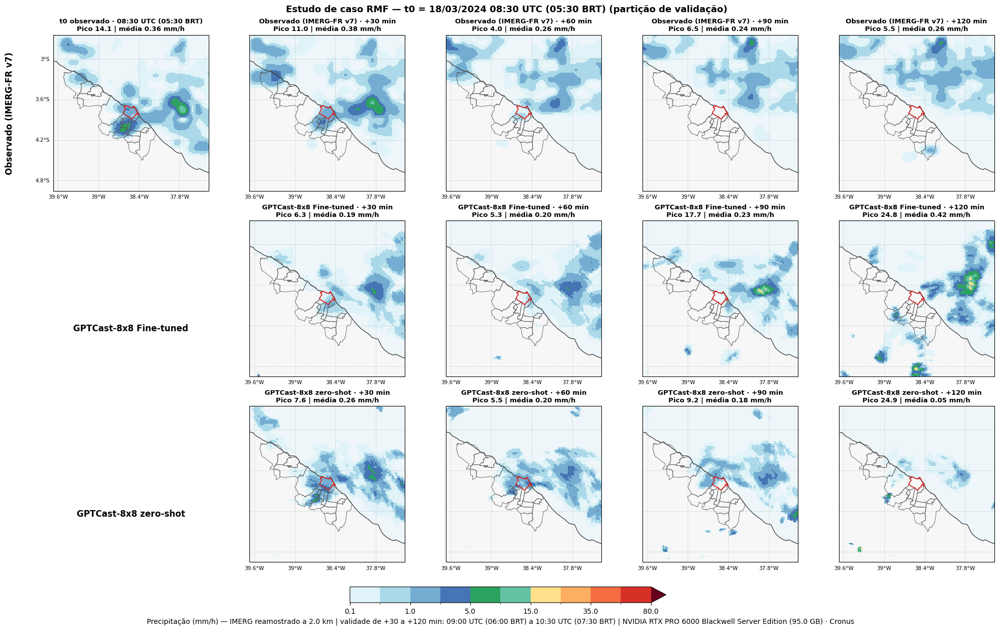

[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/mapa_01_ground_truth_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


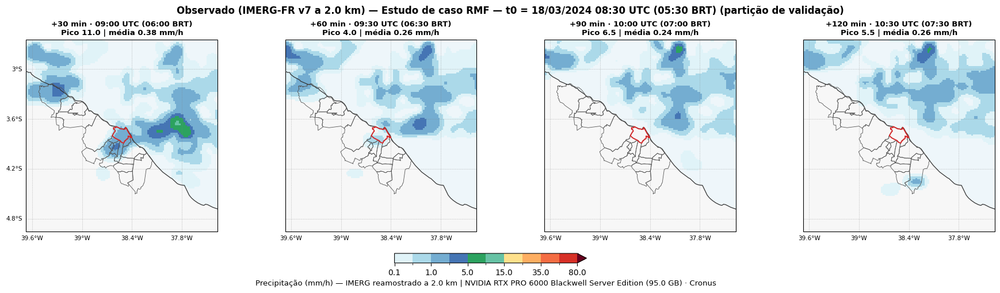

[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/mapa_02_gptcast8_finetuned_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


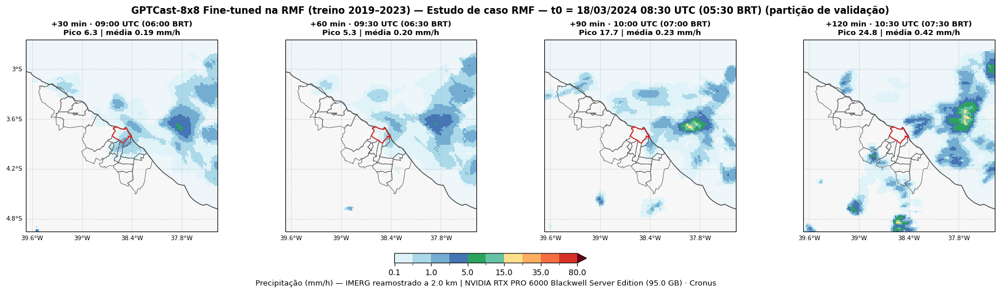

[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/mapa_03_gptcast8_zeroshot_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


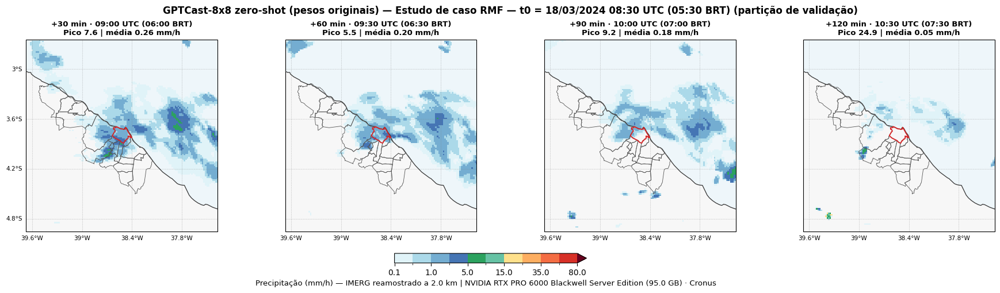

In [ ]:
# @title
# Célula 5: Mapas de Precipitação a 2 km sobre os 19 Municípios da RMF — Painel Comparativo
# (Observado x Fine-tuned x Zero-Shot) com Horário de Validade de Cada Quadro.
#
import datetime
import os
import urllib.request
import warnings

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
import numpy as np
from gptcast.utils.converters import dbz_to_rainfall

warnings.filterwarnings('ignore', category=UserWarning)

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
STEP_MIN = 30
N_LEADS = globals().get('FORECAST_STEPS', 4)

# ---------------------------------------------- 1. limites municipais (19 municípios da RMF)
# Lei Complementar estadual do Ceará; Fortaleza destacada em vermelho.
RMF_MUNICIPIOS = [
    'Aquiraz', 'Cascavel', 'Caucaia', 'Chorozinho', 'Eusébio', 'Fortaleza', 'Guaiúba', 'Horizonte',
    'Itaitinga', 'Maracanaú', 'Maranguape', 'Pacajus', 'Pacatuba', 'Paracuru', 'Paraipaba',
    'Pindoretama', 'São Gonçalo do Amarante', 'São Luís do Curu', 'Trairi',
]
# Malha municipal do IBGE redistribuída em GeoJSON pelo projeto geodata-br (tbrugz/geodata-br).
GEOJSON_CE_URL = 'https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-23-mun.json'
GEOJSON_LOCAL = os.path.join(globals().get('BASE_WORK_DIR', '/content'), 'ceara_municipios_ibge.json')

if not os.path.exists(GEOJSON_LOCAL):
  try:
    urllib.request.urlretrieve(GEOJSON_CE_URL, GEOJSON_LOCAL)
  except Exception as e:
    print(f'[Aviso Célula 5] Malha municipal não baixada ({e}); os mapas sairão sem limites municipais.')

gdf_rmf = gdf_fortaleza = None
if os.path.exists(GEOJSON_LOCAL):
  gdf_ce = gpd.read_file(GEOJSON_LOCAL)
  gdf_rmf = gdf_ce[gdf_ce['name'].isin(RMF_MUNICIPIOS)].copy()
  gdf_fortaleza = gdf_rmf[gdf_rmf['name'] == 'Fortaleza'].copy()
  faltando = sorted(set(RMF_MUNICIPIOS) - set(gdf_rmf['name']))
  print(f'[Célula 5] Limites municipais: {len(gdf_rmf)} de {len(RMF_MUNICIPIOS)} municípios da RMF'
        + (f' | faltando: {", ".join(faltando)}' if faltando else ''))

# ---------------------------------------------------------- 2. malha e escala de cores
lats = md_rmf.target_lats
lons = md_rmf.target_lons
extent_rmf = [float(lons.min()), float(lons.max()), float(lats.min()), float(lats.max())]
lon_grid, lat_grid = np.meshgrid(lons, lats)

rain_levels = [0.1, 0.5, 1.0, 2.5, 5.0, 10.0, 15.0, 25.0, 35.0, 50.0, 80.0]   # 10 classes
rain_colors = ['#e0f3f8', '#abd9e9', '#74add1', '#4575b4', '#2ca25f',
               '#66c2a4', '#fee08b', '#fdae61', '#f46d43', '#d73027']         # 1 cor por classe
cmap_rain = mcolors.ListedColormap(rain_colors)
cmap_rain.set_under((1, 1, 1, 0))   # abaixo de 0,1 mm/h: transparente
cmap_rain.set_over('#67001f')       # acima de 80 mm/h
norm_rain = mcolors.BoundaryNorm(rain_levels, cmap_rain.N)


def _valid_times(base_dt, n=N_LEADS):
  """base_dt = horário do ÚLTIMO quadro da janela (o +120 min). Devolve (t0, [validades])."""
  if isinstance(base_dt, np.datetime64):
    base_dt = datetime.datetime.strptime(np.datetime_as_string(base_dt, unit='m'), '%Y-%m-%dT%H:%M')
  if not isinstance(base_dt, datetime.datetime):
    return None, [None] * n
  t0 = base_dt - datetime.timedelta(minutes=STEP_MIN * n)
  return t0, [t0 + datetime.timedelta(minutes=STEP_MIN * (i + 1)) for i in range(n)]


def _fmt_t(t):
  if t is None:
    return ''
  brt = t - datetime.timedelta(hours=3)
  return f'{t:%H:%M} UTC ({brt:%H:%M} BRT)'


def _draw_map(ax, field, title, show_left=True):
  ax.set_extent(extent_rmf, crs=ccrs.PlateCarree())
  ax.add_feature(cfeature.LAND, facecolor='#f7f7f7', zorder=0)
  ax.add_feature(cfeature.OCEAN, facecolor='#eef6fa', zorder=0)
  ax.add_feature(cfeature.COASTLINE, linewidth=0.9, edgecolor='#333333', zorder=3)
  if gdf_rmf is not None:
    gdf_rmf.boundary.plot(ax=ax, edgecolor='#555555', linewidth=0.6, zorder=4)
  if gdf_fortaleza is not None:
    gdf_fortaleza.boundary.plot(ax=ax, edgecolor='#d62728', linewidth=1.3, zorder=5)
  f = np.clip(np.nan_to_num(field, nan=0.0), 0.0, 205.0)
  im = ax.pcolormesh(lon_grid, lat_grid, np.ma.masked_less(f, 0.1), cmap=cmap_rain, norm=norm_rain,
                     shading='nearest', transform=ccrs.PlateCarree(), zorder=2)
  ax.set_title(f'{title}\nPico {f.max():.1f} | média {f.mean():.2f} mm/h', fontsize=9.5, fontweight='bold')
  gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray', alpha=0.5, linestyle='--')
  gl.top_labels = gl.right_labels = False
  gl.left_labels = show_left
  gl.xlocator = mticker.MultipleLocator(0.6)
  gl.ylocator = mticker.MultipleLocator(0.6)
  gl.xlabel_style = gl.ylabel_style = {'size': 7.5}
  return im


def plot_rmf_spatial(data_4steps, base_dt, panel_title: str, save_filename: str = None):
  """Uma linha de 4 mapas (+30 a +120 min) com o horário de validade de cada quadro."""
  data = np.asarray(data_4steps)
  _, valid = _valid_times(base_dt, data.shape[0])
  fig, axes = plt.subplots(1, data.shape[0], figsize=(4.5 * data.shape[0], 5.0),
                           subplot_kw={'projection': ccrs.PlateCarree()}, constrained_layout=True)
  axes = np.atleast_1d(axes)
  for i, ax in enumerate(axes):
    im = _draw_map(ax, data[i], f'+{STEP_MIN * (i + 1)} min · {_fmt_t(valid[i])}', show_left=(i == 0))
  cb = fig.colorbar(im, ax=axes.tolist(), orientation='horizontal', fraction=0.05, pad=0.06, extend='max')
  cb.set_label(f'Precipitação (mm/h) — IMERG reamostrado a {RES_KM} km | {ENV_LABEL}', fontsize=9.5)
  fig.suptitle(panel_title, fontsize=12, fontweight='bold')
  if save_filename:
    path = os.path.join(RESULTS_ENV_DIR, save_filename)
    fig.savefig(path, dpi=300, bbox_inches='tight')
    print(f'[Célula 5] Mapa salvo -> {path}')
  plt.show()


def plot_rmf_comparison(rows: dict, context_rain, base_dt, panel_title: str, save_filename: str = None):
  """Grade: 1ª coluna = último quadro observado (t0); demais = +30 a +120 min; 1 linha por fonte."""
  t0, valid = _valid_times(base_dt)
  n_rows = len(rows)
  fig, axes = plt.subplots(n_rows, N_LEADS + 1, figsize=(4.0 * (N_LEADS + 1), 4.1 * n_rows),
                           subplot_kw={'projection': ccrs.PlateCarree()}, constrained_layout=True)
  axes = np.atleast_2d(axes)
  for r, (label, data) in enumerate(rows.items()):
    if r == 0:
      im = _draw_map(axes[r, 0], context_rain, f't0 observado · {_fmt_t(t0)}')
    else:
      axes[r, 0].axis('off')
      axes[r, 0].text(0.5, 0.5, label, ha='center', va='center', fontsize=12, fontweight='bold',
                      transform=axes[r, 0].transAxes)
    for i in range(N_LEADS):
      im = _draw_map(axes[r, i + 1], data[i], f'{label} · +{STEP_MIN * (i + 1)} min', show_left=False)
  axes[0, 0].text(-0.28, 0.5, list(rows)[0], rotation=90, ha='center', va='center', fontsize=12,
                  fontweight='bold', transform=axes[0, 0].transAxes)
  cb = fig.colorbar(im, ax=axes.ravel().tolist(), orientation='horizontal', fraction=0.03, pad=0.03, extend='max')
  cb.set_label(f'Precipitação (mm/h) — IMERG reamostrado a {RES_KM} km | validade de +30 a +120 min: '
               f'{_fmt_t(valid[0])} a {_fmt_t(valid[-1])} | {ENV_LABEL}', fontsize=10)
  fig.suptitle(panel_title, fontsize=13, fontweight='bold')
  if save_filename:
    path = os.path.join(RESULTS_ENV_DIR, save_filename)
    fig.savefig(path, dpi=300, bbox_inches='tight')
    print(f'[Célula 5] Painel salvo -> {path}')
  plt.show()


# --------------------------------------------------------------------- 3. figuras
t0_case, _ = _valid_times(dt)
context_rain_t0 = dbz_to_rainfall(np.clip(np.asarray(input_data_dbz)[-1], 0.0, 60.0))
caso = f'Estudo de caso RMF — t0 = {t0_case:%d/%m/%Y} {_fmt_t(t0_case)} (partição de validação)'

linhas = {'Observado (IMERG-FR v7)': ground_truth_rain, 'GPTCast-8x8 Fine-tuned': forecast8_rain}
if 'forecast8_zeroshot_rain' in globals():
  linhas['GPTCast-8x8 zero-shot'] = forecast8_zeroshot_rain
plot_rmf_comparison(linhas, context_rain_t0, dt, caso, save_filename=f'mapa_00_comparativo_rmf_2km_{ENV_TAG}.png')

# Painéis individuais (mesmos nomes de arquivo usados no backup e no artigo)
plot_rmf_spatial(ground_truth_rain, dt, f'Observado (IMERG-FR v7 a {RES_KM} km) — {caso}',
                 save_filename=f'mapa_01_ground_truth_rmf_2km_{ENV_TAG}.png')
plot_rmf_spatial(forecast8_rain, dt, f'GPTCast-8x8 Fine-tuned na RMF (treino 2019–2023) — {caso}',
                 save_filename=f'mapa_02_gptcast8_finetuned_rmf_2km_{ENV_TAG}.png')
if 'forecast8_zeroshot_rain' in globals():
  plot_rmf_spatial(forecast8_zeroshot_rain, dt, f'GPTCast-8x8 zero-shot (pesos originais) — {caso}',
                   save_filename=f'mapa_03_gptcast8_zeroshot_rmf_2km_{ENV_TAG}.png')


# Célula 6: Avaliação Quantitativa do Estágio 1 - Reconstrução Espacial do Autoencoder VQGAN Congelado na Malha de 2 km (Tabela 3) sobre Todos os Quadros Distintos do Teste de 2025, com Rastreabilidade de Hardware (`ENV_TAG`)

- **Validação da Compressão Latente (Piso do Estágio 1)**: Mede a perda de codificar e decodificar cada quadro de 128 × 128 pixels (256 × 256 km) em 8 × 8 = 64 tokens do codebook de 1.024 códigos. Cada token cobre 16 × 16 pixels, ou seja, 32 × 32 km. Esse erro é um piso: nenhuma previsão do Transformer pode ser mais fiel do que a reconstrução do VQGAN.

- **Teste de 2025 sem Quadros Repetidos (Cobertura Integral)**: As janelas de teste se sobrepõem (passo de 60 min, 11 quadros de 30 min), então o mesmo horário aparece em várias janelas. A célula reconstrói **cada quadro de 30 min uma única vez**, cobrindo toda a partição de fevereiro a maio de 2025, e repete a avaliação só nos quadros com pico observado de pelo menos 1 mm/h.

- **Métricas Contínuas, Categóricas e de Volume**: Calcula MAE e RMSE (mm/h e dBZ), SSIM em dBZ com faixa fixa de 60 dBZ, Correlação de Pearson (PCC), razão de volume reconstruído/observado, picos e CSI/BIAS em 0,5; 1,0; 5,0 e 10,0 mm/h, além do tempo de GPU (com aquecimento descartado) e dos milissegundos por quadro. O CSV consolidado vai para `RESULTS_ENV_DIR`.

- **Inspeção Visual e Espacial Lado a Lado**: Salva em `300 dpi` os mapas do estudo de caso (`18/03/2024`, partição de validação) com o campo observado a 2 km, a reconstrução pelo VQGAN-8x8 e o resíduo absoluto (|Reconstruído − Observado|).

=== Tabela 3 — Reconstrução do VQGAN-8x8 congelado (NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus) ===
Cada token cobre 16 x 16 pixels = 32 x 32 km. Teste 2025: 3927 quadros distintos de 30 min (de 1729 janelas).


Quadros Avaliados  \
Ambiente_Execucao                                  Conjunto Avaliado                                                       
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024 (validação, 4 quadros...                  4   
                                                   Teste 2025 — todos os quadros distintos (2025-0...               3927   
                                                   Teste 2025 — quadros com pico observado >= 1 mm/h                3463   

                                                                                                       MAE [mm/h] (↓)  \
Ambiente_Execucao                                  Conjunto Avaliado                                                    
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024 (validação, 4 quadros...          0.1077   
                                                   Teste 2025 — todos os quadros distintos (2025-0...          0.1564   
                                                   Teste 2025 — quadros com pico observado >= 1 mm/h           0.1769   

                                                                                                       RMSE [mm/h] (↓)  \
Ambiente_Execucao                                  Conjunto Avaliado                                                     
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024 (validação, 4 quadros...           0.2836   
                                                   Teste 2025 — todos os quadros distintos (2025-0...           0.9699   
                                                   Teste 2025 — quadros com pico observado >= 1 mm/h            1.0327   

                                                                                                       MAE [dBZ] (↓)  \
Ambiente_Execucao                                  Conjunto Avaliado                                                   
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024 (validação, 4 quadros...          1.265   
                                                   Teste 2025 — todos os quadros distintos (2025-0...          0.978   
                                                   Teste 2025 — quadros com pico observado >= 1 mm/h           1.072   

                                                                                                       RMSE [dBZ] (↓)  \
Ambiente_Execucao                                  Conjunto Avaliado                                                    
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024 (validação, 4 quadros...           2.484   
                                                   Teste 2025 — todos os quadros distintos (2025-0...           2.214   
                                                   Teste 2025 — quadros com pico observado >= 1 mm/h            2.345   

                                                                                                       SSIM dBZ (↑)  \
Ambiente_Execucao                                  Conjunto Avaliado                                                  
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024 (validação, 4 quadros...        0.8398   
                                                   Teste 2025 — todos os quadros distintos (2025-0...        0.8504   
                                                   Teste 2025 — quadros com pico observado >= 1 mm/h         0.8419   

                                                                                                       PCC (↑)  \
Ambiente_Execucao                                  Conjunto Avaliado                                             
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024 (validação, 4 quadros...   0.9386   
                                                   Teste 2025 — todos os quadros distintos (2025-0...   0.8889   
      

[Célula 6] Tabela 3 salva -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/tabela3_estagio1_vqgan_2km_G4_RTX6000_Blackwell_95GB_Cronus_2019_2025.csv
[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/estagio1_01_observado_vqgan_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


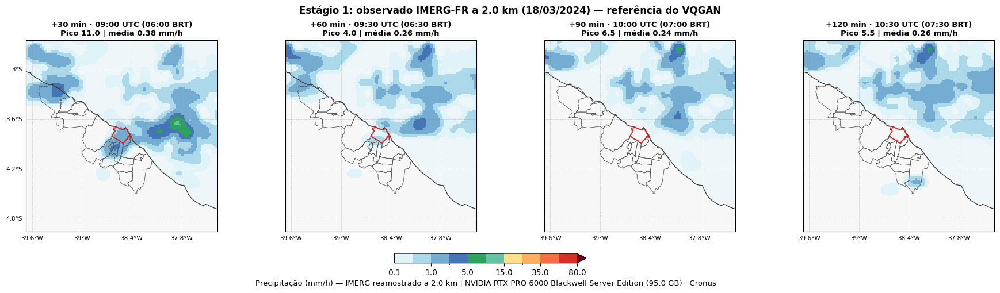

[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/estagio1_02_reconstruido_vqgan_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


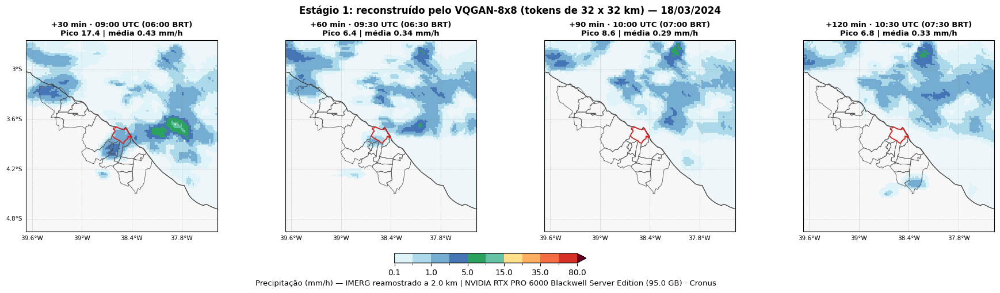

[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/estagio1_03_residuo_absoluto_vqgan_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


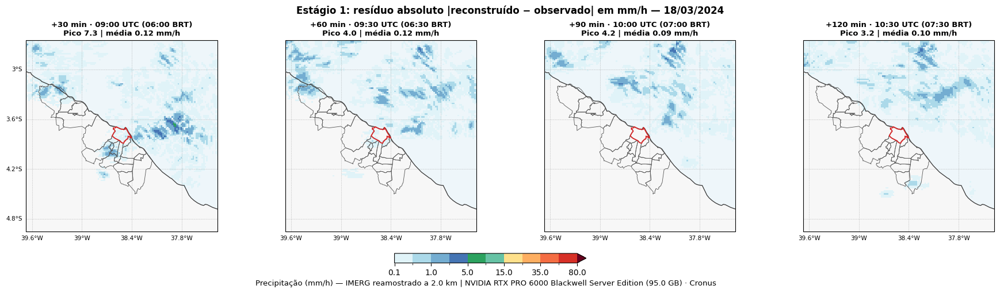

In [ ]:
# @title
# Célula 6: Estágio 1 — Fidelidade de Reconstrução do VQGAN Congelado a 2 km (Tabela 3):
# estudo de caso + TODOS os quadros distintos da partição de teste de 2025.
#
import datetime
import os
import time
from typing import Dict, Tuple

import numpy as np
import pandas as pd
import torch
from gptcast.utils.converters import dbz_to_rainfall
from skimage.metrics import structural_similarity as ssim

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
STEP_MIN = 30
TOKEN_KM = GRID_SIZE // 8 * RES_KM    # 128 px / 8 tokens = 16 px por token = 32 km
THRESHOLDS = (0.5, 1.0, 5.0, 10.0)
BATCH_FRAMES = 128

# Horário do estudo de caso (dt = último quadro da janela, +120 min)
t0_history_end = dt - datetime.timedelta(minutes=STEP_MIN * FORECAST_STEPS)
t0_brt = t0_history_end - datetime.timedelta(hours=3)
data_str = t0_brt.strftime('%d/%m/%Y')


def _sync() -> float:
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


def _to_rain(dbz: np.ndarray) -> np.ndarray:
  return np.clip(dbz_to_rainfall(np.clip(dbz, 0.0, 60.0).astype(np.float64)), 0.0, 205.0).astype(np.float32)


# --------------------------------------------------------------- 1. reconstrução
@torch.no_grad()
def reconstruct_sequence_vqgan(model_gptcast, seq_dbz, device: str = device,
                               batch_frames: int = BATCH_FRAMES) -> Tuple[np.ndarray, np.ndarray, float]:
  """(S, H, W) em dBZ [0, 60] -> codificador -> codebook (1.024 códigos, 8 x 8 tokens) -> decodificador.

  Devolve (reconstrução em dBZ, em mm/h, tempo de GPU em s), processando em lotes.
  """
  vae = model_gptcast.first_stage_model.to(device)
  vae.eval()
  vdtype = next(vae.parameters()).dtype
  raw = seq_dbz.filled(0.0) if isinstance(seq_dbz, np.ma.MaskedArray) else np.nan_to_num(seq_dbz, nan=0.0)
  raw = np.clip(raw, 0.0, 60.0).astype(np.float32)
  out = np.empty_like(raw)
  t0 = _sync()
  for i in range(0, raw.shape[0], batch_frames):
    x = torch.from_numpy(raw[i:i + batch_frames, None] / 30.0 - 1.0).to(device=device, dtype=vdtype)
    quant, _, _ = vae.encode(x)
    out[i:i + batch_frames] = vae.decode(quant).squeeze(1).float().cpu().numpy()
  t_gpu = _sync() - t0
  rec_dbz = np.clip((out + 1.0) * 30.0, 0.0, 60.0).astype(np.float32)
  return rec_dbz, _to_rain(rec_dbz), float(t_gpu)


# ------------------------------------------------------------------- 2. métricas
def compute_stage1_metrics(obs_rain, rec_rain, obs_dbz, rec_dbz, gpu_time_s: float = 0.0,
                           label: str = 'VQGAN-8x8 (RMF 2 km)') -> Dict:
  """MAE/RMSE (mm/h e dBZ), SSIM em dBZ (faixa fixa de 60 dBZ), PCC, volume, picos, CSI/BIAS."""
  o_r, p_r = obs_rain.astype(np.float64), rec_rain.astype(np.float64)
  o_d, p_d = obs_dbz.astype(np.float64), rec_dbz.astype(np.float64)
  ssim_d = float(np.mean([ssim(o_d[i], p_d[i], data_range=60.0) for i in range(o_d.shape[0])]))
  pcc = float(np.corrcoef(o_r.ravel(), p_r.ravel())[0, 1]) if o_r.std() > 1e-6 and p_r.std() > 1e-6 else np.nan
  row = {
      'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG, 'Conjunto Avaliado': label,
      'Quadros Avaliados': int(o_r.shape[0]),
      'MAE [mm/h] (↓)': round(float(np.mean(np.abs(p_r - o_r))), 4),
      'RMSE [mm/h] (↓)': round(float(np.sqrt(np.mean((p_r - o_r) ** 2))), 4),
      'MAE [dBZ] (↓)': round(float(np.mean(np.abs(p_d - o_d))), 3),
      'RMSE [dBZ] (↓)': round(float(np.sqrt(np.mean((p_d - o_d) ** 2))), 3),
      'SSIM dBZ (↑)': round(ssim_d, 4),
      'PCC (↑)': round(pcc, 4),
      'Razão de Volume Rec/Obs (=1)': round(float(p_r.sum() / max(o_r.sum(), 1e-9)), 3),
      'Pico Obs [mm/h]': round(float(o_r.max()), 2),
      'Pico Rec [mm/h]': round(float(p_r.max()), 2),
  }
  for thr in THRESHOLDS:
    ob, rb = o_r >= thr, p_r >= thr
    tp, fp, fn = int(np.sum(ob & rb)), int(np.sum(~ob & rb)), int(np.sum(ob & ~rb))
    csi = tp / (tp + fp + fn) if tp + fp + fn else np.nan
    bias = (tp + fp) / (tp + fn) if tp + fn else np.nan
    row[f'CSI/BIAS @ {thr} mm/h'] = f'{csi:.3f} / {bias:.2f}' if np.isfinite(csi) else 'sem eventos'
  row['Tempo Reconstrução GPU [s] (↓)'] = round(float(gpu_time_s), 4)
  row['ms por Quadro (↓)'] = round(1000 * gpu_time_s / max(o_r.shape[0], 1), 3)
  return row


# ------------------------------------------------- 3. quadros distintos do teste de 2025
def unique_test_frames(dataset) -> Tuple[np.ndarray, np.ndarray]:
  """As janelas de teste se sobrepõem (passo de 60 min, 11 quadros de 30 min): cada horário aparece
  em várias janelas. Devolve cada quadro de 30 min uma única vez, com o seu horário."""
  S, T = dataset.sequences_dbz, dataset.timestamps
  n_f = S.shape[1]
  offsets = np.array([(k - (n_f - 1)) * STEP_MIN for k in range(n_f)], dtype='timedelta64[m]')
  times = (T[:, None] + offsets[None, :]).ravel()
  _, first = np.unique(times, return_index=True)
  seq_idx, frame_idx = np.divmod(first, n_f)
  return np.clip(S[seq_idx, frame_idx], 0.0, 60.0).astype(np.float32), times[first]


# ------------------------------------------------------------------ 4. avaliação
_ = reconstruct_sequence_vqgan(gpt8, np.zeros((2, GRID_SIZE, GRID_SIZE), np.float32))  # aquecimento

obs_4_dbz = np.clip(np.asarray(ground_truth_dbz.data if hasattr(ground_truth_dbz, 'data') else ground_truth_dbz), 0.0, 60.0)
obs_4_rain = _to_rain(obs_4_dbz)
rec_4_dbz, rec_4_rain, t_vq_case = reconstruct_sequence_vqgan(gpt8, obs_4_dbz)
rows_stage1 = [compute_stage1_metrics(obs_4_rain, rec_4_rain, obs_4_dbz, rec_4_dbz, t_vq_case,
                                      label=f'Estudo de caso {data_str} (validação, 4 quadros alvo)')]

test_dbz, test_times = unique_test_frames(md_rmf.splits['test'])
rec_t_dbz, rec_t_rain, t_vq_test = reconstruct_sequence_vqgan(gpt8, test_dbz)
obs_t_rain = _to_rain(test_dbz)
periodo = f'{str(test_times[0])[:10]} a {str(test_times[-1])[:10]}'
rows_stage1.append(compute_stage1_metrics(
    obs_t_rain, rec_t_rain, test_dbz, rec_t_dbz, t_vq_test,
    label=f'Teste 2025 — todos os quadros distintos ({periodo})'))

wet = (obs_t_rain.max(axis=(1, 2)) >= 1.0)  # quadros com pico observado >= 1 mm/h
if wet.any():
  rows_stage1.append(compute_stage1_metrics(
      obs_t_rain[wet], rec_t_rain[wet], test_dbz[wet], rec_t_dbz[wet], t_vq_test * wet.mean(),
      label='Teste 2025 — quadros com pico observado >= 1 mm/h'))

df_stage1_raw = pd.DataFrame(rows_stage1)
stage1_csv_path = os.path.join(RESULTS_ENV_DIR, f'tabela3_estagio1_vqgan_2km_{ENV_TAG}_2019_2025.csv')
df_stage1_raw.to_csv(stage1_csv_path, index=False)

print(f'=== Tabela 3 — Reconstrução do VQGAN-8x8 congelado ({ENV_LABEL}) ===')
print(f'Cada token cobre {GRID_SIZE // 8} x {GRID_SIZE // 8} pixels = {TOKEN_KM:.0f} x {TOKEN_KM:.0f} km. '
      f'Teste 2025: {len(test_dbz)} quadros distintos de 30 min (de {md_rmf.splits["test"].sequences_dbz.shape[0]} janelas).')
display(df_stage1_raw.drop(columns=['Hardware_Tag']).set_index(['Ambiente_Execucao', 'Conjunto Avaliado']))
print(f'[Célula 6] Tabela 3 salva -> {stage1_csv_path}')

# ------------------------------------------------------------------- 5. mapas
res_abs_rain = np.abs(rec_4_rain - obs_4_rain)
if 'plot_rmf_spatial' in globals():
  plot_rmf_spatial(obs_4_rain, dt, f'Estágio 1: observado IMERG-FR a {RES_KM} km ({data_str}) — referência do VQGAN',
                   save_filename=f'estagio1_01_observado_vqgan_2km_{ENV_TAG}.png')
  plot_rmf_spatial(rec_4_rain, dt, f'Estágio 1: reconstruído pelo VQGAN-8x8 (tokens de {TOKEN_KM:.0f} x {TOKEN_KM:.0f} km) — {data_str}',
                   save_filename=f'estagio1_02_reconstruido_vqgan_2km_{ENV_TAG}.png')
  plot_rmf_spatial(res_abs_rain, dt, f'Estágio 1: resíduo absoluto |reconstruído − observado| em mm/h — {data_str}',
                   save_filename=f'estagio1_03_residuo_absoluto_vqgan_2km_{ENV_TAG}.png')


# Célula 7: Análise de Densidade Espectral de Potência - Radially Averaged Power Spectral Density (RAPSD) na Malha de 2 km com Bandas Definidas pela Resolução Nativa do IMERG (cerca de 11 km) e Rastreabilidade por Hardware (`ENV_TAG`)

* **Escalas de Referência (Malha, Resolução Nativa e Token)**: Na grade de 128 × 128 pixels a 2 km, o menor comprimento de onda representável é 4 km, mas o IMERG nativo (0,1°, cerca de 11 km) só resolve escalas a partir de cerca de 22 km; abaixo disso, o campo observado é suavizado pela reamostragem. Cada token 8 × 8 do VQGAN cobre 32 km.

* **Comparação Espectral Multicamadas e Rastreabilidade por Hardware (`ENV_TAG`)**: Confronta o espectro do campo observado (IMERG-FR) com a reconstrução do VQGAN (Estágio 1), o GPTCast-8x8 ajustado na RMF e o GPTCast-8x8 zero-shot nos quatro horizontes (+30 a +120 min) do estudo de caso. Também entram o Lucas-Kanade e o LINDA determinístico, calculados em variáveis locais: campo de movimento LK nos últimos 4 quadros em dBZ, extrapolação semi-lagrangiana e LINDA-D com `ari_order=1`, sem perturbações. O gráfico e o CSV são exportados para `RESULTS_ENV_DIR`.

* **Razões de Energia e de Forma por Banda (abaixo de 22 km, de 22 a 64 km e acima de 64 km)**: A **razão de energia** compara a potência total do modelo com a observada em cada banda (mistura intensidade e nitidez); a **razão de forma** repete a conta com os espectros normalizados pela potência total, isolando a distribuição de energia entre escalas. O valor ideal é 1,0. Na banda abaixo de 22 km, as razões descrevem textura criada pelo modelo, não fidelidade ao observado.

* **Espectro do Estágio 1 no Teste de 2025**: Soma os espectros de todos os quadros distintos de 2025 com pico de pelo menos 1 mm/h reconstruídos na Célula 6, dando uma referência estatística além do estudo de caso único.

Computing LINDA nowcast
-----------------------

Inputs
------
dimensions:           128x128
number of time steps: 3

Methods
-------
nowcast type:         deterministic
feature detector:     domain
extrapolator:         semilagrangian
kernel type:          anisotropic

Parameters
----------
number of time steps:     4
ARI model order:            1
localization window radius: 25.6
Rain fraction is: 0.442138671875, while minimum fraction is 0.0
Transforming to Lagrangian coordinates... done.
Estimating the first convolution kernel... done.
Estimating the ARI(p,1) parameters... done.
Estimating the second convolution kernel... done.
Computing nowcast for time step 1... done.
Computing nowcast for time step 2... done.
Computing nowcast for time step 3... done.
Computing nowcast for time step 4... done.
[Célula 7] Lucas-Kanade e LINDA: calculados nesta célula (mesmas configurações da Célula 10).


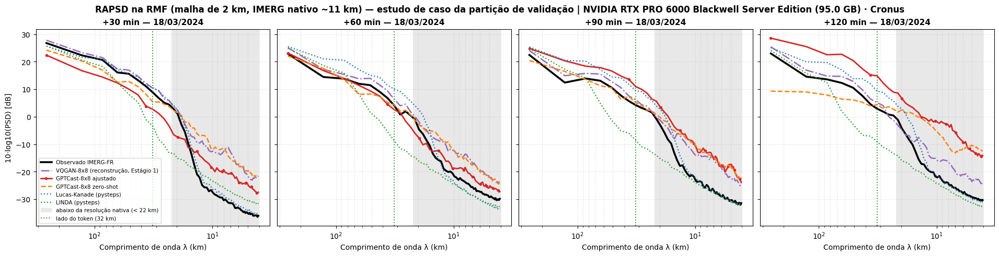

=== RAPSD por banda (NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus) — razão ideal = 1,0 ===
Energia: potência do modelo / observada na banda (mistura amplitude e forma). Forma: idem com os espectros normalizados pela potência total (só a distribuição entre escalas).
Abaixo de 22 km o observado é suavizado pela reamostragem de ~11 km para 2 km: razões ali descrevem textura criada pelo modelo, não fidelidade.


Energia < 22 km (abaixo da resolução nativa)  \
Ambiente_Execucao                                  Conjunto                                           Modelo                              Lead Time                                                 
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... Estudo de caso 18/03/2024                          VQGAN-8x8 (reconstrução, Estágio 1) +30 min                                           1.855   
                                                                                                      GPTCast-8x8 ajustado                +30 min                                           0.319   
                                                                                                      GPTCast-8x8 zero-shot               +30 min                                           2.018   
                                                                                                      Lucas-Kanade (pysteps)              +30 min                                           1.458   
                                                                                                      LINDA (pysteps)                     +30 min                                           0.069   
                                                                                                      VQGAN-8x8 (reconstrução, Estágio 1) +60 min                                           2.280   
                                                                                                      GPTCast-8x8 ajustado                +60 min                                           0.660   
                                                                                                      GPTCast-8x8 zero-shot               +60 min                                           2.286   
                                                                                                      Lucas-Kanade (pysteps)              +60 min                                           3.506   
                                                                                                      LINDA (pysteps)                     +60 min                                           0.116   
                                                                                                      VQGAN-8x8 (reconstrução, Estágio 1) +90 min                                           2.254   
                                                                                                      GPTCast-8x8 ajustado                +90 min                                           5.969   
                                                                                                      GPTCast-8x8 zero-shot               +90 min                                           3.184   
                                                                                                      Lucas-Kanade (pysteps)              +90 min                                           3.407   
                                                                                                      LINDA (pysteps)                     +90 min                                           0.126   
                                                                                                      VQGAN-8x8 (reconstrução, Estágio 1) +120 min                                          1.347   
                                                                                                      GPTCast-8x8 ajustado                +120 min                                         19.507   
                                                                                                      GPTCast-8x8 zero-shot               +120 min                                          9.071   
                                                                                                      Lucas-Kanade (pysteps)              +120 min                                          3.916   
            

[Célula 7] Painel -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/painel_rapsd_espectral_2km_G4_RTX6000_Blackwell_95GB_Cronus.png
[Célula 7] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/tabela_rapsd_bandas_espectrais_2km_G4_RTX6000_Blackwell_95GB_Cronus.csv


In [ ]:
# @title
# Célula 7: Densidade Espectral de Potência Radial (RAPSD) a 2 km — bandas definidas pela resolução
# NATIVA do IMERG (~11 km), razão de energia por banda (amplitude) e razão de forma (espectro normalizado).
#
import datetime
import os
from typing import Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pysteps.utils import spectral

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
if 'data_str' not in globals():
  data_str = (dt - datetime.timedelta(minutes=30 * FORECAST_STEPS + 180)).strftime('%d/%m/%Y')

# ------------------------------------------------------------ 1. escalas de referência
RES_GRID_KM = float(globals().get('RES_KM', 2.0))
NATIVE_KM = 11.1                       # IMERG 0,1° perto do equador
NYQUIST_GRID_KM = 2 * RES_GRID_KM      # 4 km: limite da malha reamostrada
NYQUIST_NATIVE_KM = 2 * NATIVE_KM      # ~22 km: menor escala que o IMERG de fato resolve
TOKEN_KM = (GRID_SIZE // 8) * RES_GRID_KM   # 32 km: lado de um token do VQGAN
BANDS = {
    f'< {NYQUIST_NATIVE_KM:.0f} km (abaixo da resolução nativa)': (NYQUIST_GRID_KM, NYQUIST_NATIVE_KM),
    f'{NYQUIST_NATIVE_KM:.0f}–64 km (mesoescala)': (NYQUIST_NATIVE_KM, 64.0),
    '> 64 km (regional)': (64.0, np.inf),
}


def compute_frame_rapsd(field_2d, res_km: float = RES_GRID_KM) -> Tuple[np.ndarray, np.ndarray]:
  """RAPSD de um campo (mm/h). Devolve comprimentos de onda (km) e potência, sem a componente DC."""
  f = field_2d.filled(0.0) if isinstance(field_2d, np.ma.MaskedArray) else np.nan_to_num(field_2d, nan=0.0)
  psd, freq = spectral.rapsd(np.clip(f, 0.0, 205.0).astype(np.float64), fft_method=np.fft,
                             return_freq=True, d=res_km, normalize=False)
  ok = freq > 0
  return 1.0 / freq[ok], psd[ok]


def band_ratios(wl, psd_model, psd_obs) -> dict:
  """Energia: soma da potência na banda (modelo / observado). Forma: o mesmo com cada espectro
  dividido pela sua potência total, isolando a distribuição entre escalas da amplitude do campo."""
  out = {}
  tot_m, tot_o = psd_model.sum(), psd_obs.sum()
  for name, (lo, hi) in BANDS.items():
    m = (wl >= lo) & (wl < hi)
    e_o = psd_obs[m].sum()
    out[f'Energia {name}'] = round(float(psd_model[m].sum() / e_o), 3) if e_o > 0 else np.nan
    out[f'Forma {name}'] = (round(float((psd_model[m].sum() / tot_m) / (e_o / tot_o)), 3)
                            if e_o > 0 and tot_m > 0 else np.nan)
  return out


# -------------------------------------------------------------- 2. séries comparadas
spectral_models = {'Observado IMERG-FR': (ground_truth_rain, 'black', '-', 2.6)}
if 'rec_4_rain' in globals():
  spectral_models['VQGAN-8x8 (reconstrução, Estágio 1)'] = (rec_4_rain, '#9467bd', '-.', 1.8)
spectral_models['GPTCast-8x8 ajustado'] = (forecast8_rain, '#d62728', 'o-', 2.0)
if 'forecast8_zeroshot_rain' in globals():
  spectral_models['GPTCast-8x8 zero-shot'] = (forecast8_zeroshot_rain, '#ff7f0e', '--', 1.8)
# Baselines físicos (Lucas-Kanade e LINDA determinístico): usa os da Célula 10 se ela já rodou; senão
# calcula aqui, com exatamente as mesmas configurações da Célula 10, em variáveis locais (_lk7, _linda7).
# Nenhuma variável da Célula 10 é criada nem alterada, então a ordem de execução não importa.
def _baselines_pysteps():
  from pysteps import motion, nowcasts
  from gptcast.utils.converters import dbz_to_rainfall as _d2r
  dbz = np.clip(np.nan_to_num(np.asarray(np.ma.filled(input_data_dbz, 0.0), dtype=np.float64), nan=0.0), 0.0, 60.0)
  rain = np.clip(_d2r(dbz), 0.0, 205.0)
  vel = motion.get_method('LK')(dbz[-4:])                                  # n_motion = 4, em dBZ
  lk = nowcasts.get_method('extrapolation')(rain[-1], vel, FORECAST_STEPS)
  lk = np.clip(np.nan_to_num(lk, nan=0.0), 0.0, 205.0).astype(np.float32)
  try:
    li = nowcasts.get_method('linda')(rain[-3:], vel, FORECAST_STEPS, feature_method='domain', ari_order=1,
                                      add_perturbations=False, kmperpixel=RES_GRID_KM, timestep=30.0,
                                      measure_time=False)
    li = li[0] if isinstance(li, tuple) else li
    li = li[0] if li.ndim == 4 else li
    li = np.clip(np.nan_to_num(li, nan=0.0), 0.0, 205.0).astype(np.float32)
    status = 'LINDA (pysteps)'
  except Exception as e:
    print(f'[Aviso Célula 7] LINDA falhou ({type(e).__name__}); a curva LINDA fica de fora.')
    li, status = None, None
  return lk, li, status


if 'lk_extrap_rain' in globals() and 'linda_rain' in globals():
  _lk7, _linda7, _nome_linda = lk_extrap_rain, linda_rain, 'LINDA (pysteps)'
  _origem_pysteps = 'Célula 10'
else:
  _lk7, _linda7, _nome_linda = _baselines_pysteps()
  _origem_pysteps = 'calculados nesta célula (mesmas configurações da Célula 10)'
spectral_models['Lucas-Kanade (pysteps)'] = (_lk7, '#1f77b4', ':', 1.6)
if _linda7 is not None:
  spectral_models[_nome_linda] = (_linda7, '#2ca02c', ':', 1.6)
print(f'[Célula 7] Lucas-Kanade e LINDA: {_origem_pysteps}.')

# ------------------------------------------------------ 3. estudo de caso, por horizonte
fig, axes = plt.subplots(1, FORECAST_STEPS, figsize=(19, 4.8), constrained_layout=True, sharey=True)
band_records = []
for s in range(FORECAST_STEPS):
  lead = 30 * (s + 1)
  ax = axes[s]
  wl, psd_obs = compute_frame_rapsd(ground_truth_rain[s])
  for name, (seq, color, style, lw) in spectral_models.items():
    wl_m, psd_m = compute_frame_rapsd(seq[s])
    ax.plot(wl_m, 10 * np.log10(np.maximum(psd_m, 1e-10)), style, color=color, lw=lw,
            markersize=3 if 'o' in style else 0, markevery=6, label=name)
    if name == 'Observado IMERG-FR':
      continue
    sel = wl_m >= NYQUIST_NATIVE_KM   # desvio em dB só onde o observado tem informação
    dev = np.abs(10 * np.log10(np.maximum(psd_m[sel], 1e-10)) - 10 * np.log10(np.maximum(psd_obs[sel], 1e-10)))
    band_records.append({'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG, 'Conjunto': f'Estudo de caso {data_str}',
                         'Modelo': name, 'Lead Time': f'+{lead} min', **band_ratios(wl_m, psd_m, psd_obs),
                         f'Desvio Médio ≥ {NYQUIST_NATIVE_KM:.0f} km [dB] (↓)': round(float(dev.mean()), 2)})
  ax.axvspan(NYQUIST_GRID_KM, NYQUIST_NATIVE_KM, color='0.85', alpha=0.6, lw=0,
             label=f'abaixo da resolução nativa (< {NYQUIST_NATIVE_KM:.0f} km)')
  ax.axvline(TOKEN_KM, color='#2ca02c', ls=':', lw=1.4, label=f'lado do token ({TOKEN_KM:.0f} km)')
  ax.set_xscale('log')
  ax.invert_xaxis()
  ax.set_title(f'+{lead} min — {data_str}', fontweight='bold', fontsize=11)
  ax.set_xlabel('Comprimento de onda λ (km)')
  if s == 0:
    ax.set_ylabel('10·log10(PSD) [dB]')
  ax.grid(True, which='both', ls=':', alpha=0.5)
axes[0].legend(loc='lower left', fontsize=7.5)
fig.suptitle(f'RAPSD na RMF (malha de {RES_GRID_KM:.0f} km, IMERG nativo ~{NATIVE_KM:.0f} km) — estudo de caso da '
             f'partição de validação | {ENV_LABEL}', fontsize=12, fontweight='bold')
rapsd_fig_path = os.path.join(RESULTS_ENV_DIR, f'painel_rapsd_espectral_2km_{ENV_TAG}.png')
fig.savefig(rapsd_fig_path, dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------ 4. Estágio 1 em todos os quadros distintos de 2025 (Célula 6)
if 'test_dbz' in globals() and 'rec_t_rain' in globals():
  obs_t = globals().get('obs_t_rain')
  wet = obs_t.max(axis=(1, 2)) >= 1.0
  psd_o = psd_r = None
  for i in np.flatnonzero(wet):
    wl_t, po = compute_frame_rapsd(obs_t[i])
    _, pr = compute_frame_rapsd(rec_t_rain[i])
    psd_o = po if psd_o is None else psd_o + po
    psd_r = pr if psd_r is None else psd_r + pr
  if psd_o is not None:
    band_records.append({'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG,
                         'Conjunto': f'Teste 2025 — {int(wet.sum())} quadros distintos com pico ≥ 1 mm/h',
                         'Modelo': 'VQGAN-8x8 (reconstrução, Estágio 1)', 'Lead Time': '—',
                         **band_ratios(wl_t, psd_r, psd_o)})

df_spectral_raw = pd.DataFrame(band_records)
rapsd_csv_path = os.path.join(RESULTS_ENV_DIR, f'tabela_rapsd_bandas_espectrais_2km_{ENV_TAG}.csv')
df_spectral_raw.to_csv(rapsd_csv_path, index=False)
print(f'=== RAPSD por banda ({ENV_LABEL}) — razão ideal = 1,0 ===')
print('Energia: potência do modelo / observada na banda (mistura amplitude e forma). '
      'Forma: idem com os espectros normalizados pela potência total (só a distribuição entre escalas).\n'
      f'Abaixo de {NYQUIST_NATIVE_KM:.0f} km o observado é suavizado pela reamostragem de ~{NATIVE_KM:.0f} km para '
      f'{RES_GRID_KM:.0f} km: razões ali descrevem textura criada pelo modelo, não fidelidade.')
display(df_spectral_raw.drop(columns=['Hardware_Tag']).set_index(['Ambiente_Execucao', 'Conjunto', 'Modelo', 'Lead Time']))
print(f'[Célula 7] Painel -> {rapsd_fig_path}\n[Célula 7] Tabela -> {rapsd_csv_path}')


# Célula 8: Verificação Espacial Orientada a Objetos através da Métrica SAL (Structure, Amplitude, Location - Wernli et al., 2008) na Malha de 2 km (256 × 256 km) sobre a RMF, com Razão de Volume e Função Reutilizável para o Teste de 2025 (`ENV_TAG`)

* **Decomposição Física Tridimensional do Erro**: Separa o erro da previsão em três componentes:
  - **Estrutura (S, de −2 a 2)**: objetos previstos maiores e achatados (S positivo) ou menores e pontudos (S negativo);
  - **Amplitude (A, de −2 a 2)**: subestimativa ou superestimativa do volume total;
  - **Localização (L, de 0 a 2)**: posição do centro de massa e dispersão dos objetos.

  Objetos são regiões contíguas acima de R95/15 (o percentil 95 da chuva dividido por 15). Quando um dos campos não tem chuva, o SAL é registrado como **indefinido**, em vez de valores artificiais.

* **Deslocamento em Quilômetros e Razão de Volume**: Além do índice L, informa o deslocamento do baricentro em km e a razão entre o volume previsto e o observado (por exemplo, A = +0,88 corresponde a cerca de 2,6 vezes o volume observado), confrontando **GPTCast-8x8 ajustado (Treino: 2019–2023)**, **zero-shot** e **Persistência**; Lucas-Kanade e LINDA entram quando a Célula 10 já rodou.

* **Estudo de Caso e Generalização (`sal_over_set`)**: O diagrama SAL e a tabela do estudo de caso (`18/03/2024`, partição de validação, um quadro por horizonte) são exportados para `RESULTS_ENV_DIR`. A função `sal_over_set()` calcula mediana e intervalo interquartil do SAL em muitas janelas e é usada pela Célula 12 no teste independente de 2025.

=== SAL no estudo de caso 18/03/2024 (partição de validação; 1 quadro por horizonte) | NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus ===
Menor |S|+|A|+L por horizonte: +30 min: Persistência; +60 min: GPTCast-8x8 ajustado; +90 min: Persistência; +120 min: Persistência
Um único evento não permite generalizar; o SAL do teste de 2025 sai da Célula 12 via sal_over_set().


Estrutura (S)  \
Ambiente_Execucao                                  Modelo                Lead Time                  
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 ajustado  +30 min           0.0661   
                                                                         +60 min          -0.0844   
                                                                         +90 min          -0.8850   
                                                                         +120 min         -1.1434   
                                                   GPTCast-8x8 zero-shot +30 min           0.1515   
                                                                         +60 min          -0.2213   
                                                                         +90 min          -0.4981   
                                                                         +120 min         -1.5473   
                                                   Persistência          +30 min          -0.2250   
                                                                         +60 min          -0.6411   
                                                                         +90 min          -0.3012   
                                                                         +120 min         -0.5707   

                                                                                    Amplitude (A)  \
Ambiente_Execucao                                  Modelo                Lead Time                  
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 ajustado  +30 min          -0.6976   
                                                                         +60 min          -0.2693   
                                                                         +90 min          -0.0155   
                                                                         +120 min          0.4605   
                                                   GPTCast-8x8 zero-shot +30 min          -0.3798   
                                                                         +60 min          -0.2830   
                                                                         +90 min          -0.2891   
                                                                         +120 min         -1.3224   
                                                   Persistência          +30 min          -0.0775   
                                                                         +60 min           0.3097   
                                                                         +90 min           0.4052   
                                                                         +120 min          0.2938   

                                                                                    Localização (L) [↓]  \
Ambiente_Execucao                                  Modelo                Lead Time                        
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 ajustado  +30 min                 0.3903   
                                                                         +60 min                 0.5111   
                                                                         +90 min                 0.2655   
                                                                         +120 min                0.3033   
                                                   GPTCast-8x8 zero-shot +30 min                 0.2797   
                                                                         +60 min                 0.4070   
                                                                         +90 min                 0.3428   
                                                                         +120 min                0.4618   
                                                   Persistência          +30 min                 0.1863   
                                                                         +60 

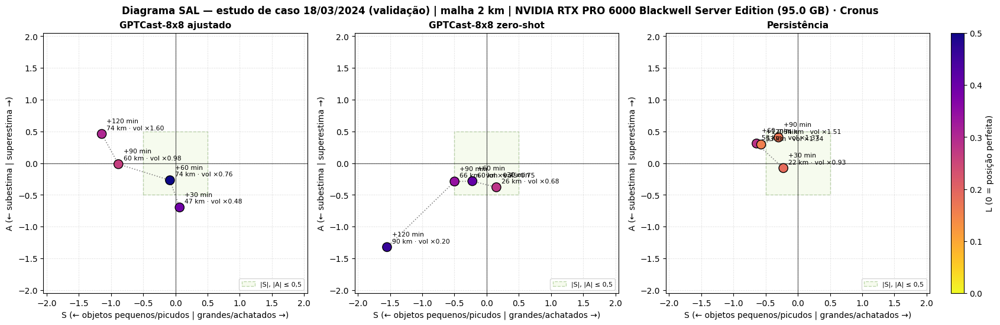

[Célula 8] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/tabela_sal_objetos_2km_G4_RTX6000_Blackwell_95GB_Cronus.csv
[Célula 8] Diagrama -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/diagrama_sal_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


In [ ]:
# @title
# Célula 8: Verificação Orientada a Objetos — SAL (Wernli et al., 2008) a 2 km, com casos sem chuva
# tratados como indefinidos, razão de volume explícita e função reutilizável para conjuntos (Célula 12).
#
import datetime
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import center_of_mass, label
from gptcast.utils.converters import dbz_to_rainfall

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
RES_GRID_KM = float(globals().get('RES_KM', 2.0))
SAL_MIN_RAIN = 0.1          # mm/h: pixel com chuva
SAL_OBJ_FRACTION = 1 / 15   # limiar de objeto = R95 / 15 (Wernli et al., 2009)
if 'data_str' not in globals():
  data_str = (dt - datetime.timedelta(minutes=30 * FORECAST_STEPS + 180)).strftime('%d/%m/%Y')


def _clean(f):
  f = f.filled(0.0) if isinstance(f, np.ma.MaskedArray) else np.nan_to_num(f, nan=0.0)
  return np.clip(f, 0.0, 205.0).astype(np.float64)


def _objects(field):
  """Objetos contíguos acima de R95/15: centro de massa global, dispersão r e volume escalado V."""
  wet = field[field >= SAL_MIN_RAIN]
  if wet.size == 0:
    return None
  thr = max(SAL_MIN_RAIN, np.percentile(wet, 95) * SAL_OBJ_FRACTION)
  lab, n = label(field >= thr)
  cm_glob = np.array(center_of_mass(field))
  num_r = num_v = mass = 0.0
  for k in range(1, n + 1):
    m = lab == k
    r_n = float(field[m].sum())
    v_n = r_n / float(field[m].max())
    d_n = float(np.linalg.norm(np.array(center_of_mass(field * m)) - cm_glob))
    num_r += r_n * d_n
    num_v += r_n * v_n
    mass += r_n
  return {'cm': cm_glob, 'r': num_r / mass, 'V': num_v / mass, 'n_obj': n}


def compute_sal_step(obs_2d, mod_2d, res_km: float = RES_GRID_KM, min_rain_thr: float = SAL_MIN_RAIN) -> dict:
  """S, A, L (Wernli et al., 2008) e deslocamento do centro de massa em km.

  SAL não é definido quando um dos campos não tem chuva: devolve NaN e o motivo.
  """
  R_o, R_m = _clean(obs_2d), _clean(mod_2d)
  out = {'S': np.nan, 'A': np.nan, 'L': np.nan, 'SAL_abs': np.nan, 'Shift_km': np.nan,
         'Razao_Volume': np.nan, 'N_obj_obs': 0, 'N_obj_mod': 0, 'Status': ''}
  o, m = _objects(R_o), _objects(R_m)
  if o is None or m is None:
    out['Status'] = 'indefinido: ' + ('sem chuva observada' if o is None else 'sem chuva prevista')
    return out
  h, w = R_o.shape
  d_max = float(np.hypot(h - 1, w - 1))
  mo, mm = R_o.mean(), R_m.mean()
  A = (mm - mo) / (0.5 * (mm + mo))
  S = (m['V'] - o['V']) / (0.5 * (m['V'] + o['V']))
  shift_px = float(np.linalg.norm(m['cm'] - o['cm']))
  L = min(2.0, shift_px / d_max + 2.0 * abs(m['r'] - o['r']) / d_max)
  out.update({'S': round(float(S), 4), 'A': round(float(A), 4), 'L': round(float(L), 4),
              'SAL_abs': round(float(abs(S) + abs(A) + L), 4), 'Shift_km': round(shift_px * res_km, 2),
              'Razao_Volume': round(float(mm / mo), 3), 'N_obj_obs': o['n_obj'], 'N_obj_mod': m['n_obj'],
              'Status': 'ok'})
  return out


def sal_over_set(obs_seqs, preds: dict) -> pd.DataFrame:
  """SAL em muitas janelas (ex.: teste 2025 na Célula 12): mediana e intervalo interquartil por modelo
  e horizonte, mais a contagem de casos indefinidos. obs_seqs: (N, 4, H, W); preds: nome -> (N, 4, H, W)."""
  rows = []
  for name, P in preds.items():
    for s in range(obs_seqs.shape[1]):
      r = pd.DataFrame([compute_sal_step(obs_seqs[i, s], P[i, s]) for i in range(obs_seqs.shape[0])])
      ok = r[r['Status'] == 'ok']
      row = {'Modelo': name, 'Lead Time': f'+{30 * (s + 1)} min', 'Janelas': len(r), 'Indefinidas': int(len(r) - len(ok))}
      for c in ('S', 'A', 'L', 'Shift_km', 'SAL_abs', 'Razao_Volume'):
        q = ok[c].quantile([0.25, 0.5, 0.75]) if len(ok) else pd.Series([np.nan] * 3, index=[0.25, 0.5, 0.75])
        row[f'{c} mediana'] = round(float(q[0.5]), 3)
        row[f'{c} IQR'] = f'{q[0.25]:.2f} a {q[0.75]:.2f}'
      rows.append(row)
  return pd.DataFrame(rows)


# --------------------------------------------------------- 1. persistência (baseline)
last_in_dbz = input_data_dbz[-1].filled(0.0) if isinstance(input_data_dbz[-1], np.ma.MaskedArray) else np.nan_to_num(input_data_dbz[-1], nan=0.0)
last_in_rain = np.clip(dbz_to_rainfall(np.clip(last_in_dbz, 0.0, 60.0)), 0.0, 205.0)
persistence_rain = np.repeat(last_in_rain[None], FORECAST_STEPS, axis=0)

# ----------------------------------------------------------- 2. SAL do estudo de caso
sal_models_dict = {'GPTCast-8x8 ajustado': forecast8_rain}
if 'forecast8_zeroshot_rain' in globals():
  sal_models_dict['GPTCast-8x8 zero-shot'] = forecast8_zeroshot_rain
sal_models_dict['Persistência'] = persistence_rain
for nome, var in (('Lucas-Kanade (pysteps)', 'lk_extrap_rain'), ('LINDA (pysteps)', 'linda_rain')):
  if var in globals():   # entram se a Célula 10 já rodou nesta sessão
    sal_models_dict[nome] = globals()[var]

sal_records = []
for name, pred in sal_models_dict.items():
  for s in range(FORECAST_STEPS):
    r = compute_sal_step(ground_truth_rain[s], pred[s])
    sal_records.append({
        'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG, 'Modelo': name,
        'Lead Time': f'+{30 * (s + 1)} min', 'Lead_num': 30 * (s + 1),
        'Estrutura (S)': r['S'], 'Amplitude (A)': r['A'], 'Localização (L) [↓]': r['L'],
        'Deslocamento Baricentro [km] (↓)': r['Shift_km'], '|S| + |A| + L (↓)': r['SAL_abs'],
        'Volume Previsto / Observado (=1)': r['Razao_Volume'],
        'Objetos Obs / Prev': f"{r['N_obj_obs']} / {r['N_obj_mod']}", 'Situação': r['Status'],
    })
df_sal = pd.DataFrame(sal_records)
sal_csv_path = os.path.join(RESULTS_ENV_DIR, f'tabela_sal_objetos_2km_{ENV_TAG}.csv')
df_sal.to_csv(sal_csv_path, index=False)

melhor = df_sal.groupby('Lead Time', sort=False)['|S| + |A| + L (↓)'].idxmin()
print(f'=== SAL no estudo de caso {data_str} (partição de validação; 1 quadro por horizonte) | {ENV_LABEL} ===')
print('Menor |S|+|A|+L por horizonte: ' + '; '.join(f"{lt}: {df_sal.loc[i, 'Modelo']}" for lt, i in melhor.items()))
print('Um único evento não permite generalizar; o SAL do teste de 2025 sai da Célula 12 via sal_over_set().')
display(df_sal.drop(columns=['Lead_num', 'Hardware_Tag']).set_index(['Ambiente_Execucao', 'Modelo', 'Lead Time']))

# ------------------------------------------------------------------- 3. diagrama SAL
n = len(sal_models_dict)
fig, axes = plt.subplots(1, n, figsize=(5.6 * n, 5.4), constrained_layout=True, squeeze=False)
for ax, name in zip(axes[0], sal_models_dict):
  sub = df_sal[(df_sal['Modelo'] == name) & (df_sal['Situação'] == 'ok')]
  ax.axhline(0, color='k', lw=0.9, alpha=0.6)
  ax.axvline(0, color='k', lw=0.9, alpha=0.6)
  ax.add_patch(plt.Rectangle((-0.5, -0.5), 1, 1, facecolor='#e6f5d0', edgecolor='#4d9221', ls='--',
                             alpha=0.35, zorder=1, label='|S|, |A| ≤ 0,5'))
  ax.plot(sub['Estrutura (S)'], sub['Amplitude (A)'], color='gray', ls=':', lw=1.2, zorder=2)
  sc = ax.scatter(sub['Estrutura (S)'], sub['Amplitude (A)'], c=sub['Localização (L) [↓]'], cmap='plasma_r',
                  vmin=0, vmax=0.5, s=120, edgecolors='k', linewidths=1, zorder=3)
  for _, r in sub.iterrows():
    ax.annotate(f"+{int(r['Lead_num'])} min\n{r['Deslocamento Baricentro [km] (↓)']:.0f} km · vol ×{r['Volume Previsto / Observado (=1)']:.2f}",
                (r['Estrutura (S)'], r['Amplitude (A)']), textcoords='offset points', xytext=(6, 5), fontsize=7.8)
  ax.set_xlim(-2.05, 2.05)
  ax.set_ylim(-2.05, 2.05)
  ax.set_title(name, fontweight='bold', fontsize=11)
  ax.set_xlabel('S (← objetos pequenos/picudos | grandes/achatados →)')
  ax.set_ylabel('A (← subestima | superestima →)')
  ax.grid(True, ls=':', alpha=0.5)
  ax.legend(loc='lower right', fontsize=8)
cb = fig.colorbar(sc, ax=axes[0].tolist(), fraction=0.02, pad=0.02)
cb.set_label('L (0 = posição perfeita)')
fig.suptitle(f'Diagrama SAL — estudo de caso {data_str} (validação) | malha {RES_GRID_KM:.0f} km | {ENV_LABEL}',
             fontsize=12, fontweight='bold')
sal_fig_path = os.path.join(RESULTS_ENV_DIR, f'diagrama_sal_2km_{ENV_TAG}.png')
fig.savefig(sal_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[Célula 8] Tabela -> {sal_csv_path}\n[Célula 8] Diagrama -> {sal_fig_path}')


# Célula 9: Avaliação Quantitativa do Estágio 2 - Previsão Autorregressiva do Transformer por Horizonte (+30 a +120 min) na Malha de 2 km (Tabelas 4 e 5) com Variabilidade entre Sorteios do GPTCast (`ENV_TAG`)

* **Métricas Contínuas e Categóricas por Lead Time**: Calcula MAE, RMSE, SSIM (em dBZ, com faixa fixa de 60 dBZ), Correlação de Pearson (PCC), razão de volume previsto/observado, CSI e BIAS (limiares de 0,5; 1,0; 5,0 e 10,0 mm/h) passo a passo (+30, +60, +90 e +120 min) para o **GPTCast-8x8 ajustado na RMF (Treino: 2019–2023)**, o **GPTCast-8x8 zero-shot** e a **Persistência Euleriana**. Escores sem eventos aparecem como **sem eventos**, em vez de zero.

* **Variabilidade entre Sorteios (Amostragem Estocástica de Tokens)**: O GPTCast sorteia cada token a partir das probabilidades do Transformer, então cada previsão é uma amostra. A célula gera 10 sorteios por modelo para o mesmo contexto (sementes 42 a 51; o sorteio 42 é o da Célula 4), informa média ± desvio-padrão das métricas e avalia também a média dos sorteios como previsão. Uma segunda tabela mostra, para cada modelo, métrica e horizonte, o **melhor e o pior sorteio com a semente** que os gerou, ao lado do valor da semente 42.

* **Painel por Horizonte (Leitura pela Média dos Sorteios)**: Em cada painel (RMSE, MAE, SSIM e CSI no limiar de 0,5 mm/h), cada GPTCast aparece com:

  - **linha grossa**: a **média** da métrica nos 10 sorteios;

  - **faixa escura**: média ± 1 desvio-padrão;

  - **faixa clara**: do menor ao maior valor entre os sorteios;

  - **rótulo `sNN`**: a semente do pior sorteio do horizonte, escrita só quando ele se afasta mais de 1,5 desvio-padrão da média.

  A Persistência, que não tem sorteio, aparece como linha pontilhada cinza. Para ver o mapa de um sorteio específico, basta fixar a semente (`torch.manual_seed`) e repetir o `forecast`.

* **Rastreabilidade por Ambiente (`ENV_TAG`) e Exportação Direta**: Exporta as Tabelas 4 e 5, a tabela de dispersão e a de melhor e pior semente (`.csv`) e o painel por horizonte (`.png` a `300 dpi`), para `RESULTS_ENV_DIR`, deixando `evaluate_nowcast_by_leadtime`, `df_gpt8` e `df_pers` prontos em memória para a **Célula 10**. Os resultados referem-se a um único evento da partição de validação (`18/03/2024`).

Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
Using window size of 8x8 tokens
=== Tabelas 4 e 5 — Estágio 2 por horizonte no estudo de caso 18/03/2024 (validação) | NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus ===
SSIM em dBZ com faixa fixa de 60 dBZ. "sem eventos" = nenhum pixel acima do limiar em nenhum dos campos.


MAE (↓) [mm/h]  \
Ambiente_Execucao                                  Modelo                                             Lead Time                   
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF)                       +30 min            0.2910   
                                                                                                      +60 min            0.3025   
                                                                                                      +90 min            0.3395   
                                                                                                      +120 min           0.5559   
                                                   GPTCast-8x8 (Zero-Shot)                            +30 min            0.3236   
                                                                                                      +60 min            0.3273   
                                                                                                      +90 min            0.3073   
                                                                                                      +120 min           0.2858   
                                                   Persistência (Baseline)                            +30 min            0.2574   
                                                                                                      +60 min            0.4104   
                                                                                                      +90 min            0.4396   
                                                                                                      +120 min           0.4674   
                                                   GPTCast-8x8 (Fine-Tuned RMF) — média de 10 sort... +30 min            0.3054   
                                                                                                      +60 min            0.3215   
                                                                                                      +90 min            0.4755   
                                                                                                      +120 min           0.5530   
                                                   GPTCast-8x8 (Zero-Shot) — média de 10 sorteios     +30 min            0.3244   
                                                                                                      +60 min            0.3008   
                                                                                                      +90 min            0.2606   
                                                                                                      +120 min           0.2886   

                                                                                                                 RMSE (↓) [mm/h]  \
Ambiente_Execucao                                  Modelo                                             Lead Time                    
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF)                       +30 min             0.6595   
                                                                                                      +60 min             0.6171   
                                                                                                      +90 min             0.9693   
                                                                                                      +120 min            1.4983   
                                                   GPTCast-8x8 (Zero-Shot)                            +30 min             0.7289   
                                                                                                      +60 min             0.6363   
                                                                                                      +90 min             0.6747   
                                          


=== Variabilidade entre 10 sorteios do GPTCast (mesmo contexto, sementes 42–51) ===


Sorteios MAE (↓) [mm/h]  \
Modelo                       Lead Time                            
GPTCast-8x8 (Fine-Tuned RMF) +30 min          10  0.362 ± 0.074   
                             +60 min          10  0.359 ± 0.080   
                             +90 min          10  0.535 ± 0.318   
                             +120 min         10  0.625 ± 0.203   
GPTCast-8x8 (Zero-Shot)      +30 min          10  0.383 ± 0.056   
                             +60 min          10  0.352 ± 0.090   
                             +90 min          10  0.291 ± 0.046   
                             +120 min         10  0.324 ± 0.072   

                                             SSIM (↑)        CSI_0.5  \
Modelo                       Lead Time                                 
GPTCast-8x8 (Fine-Tuned RMF) +30 min    0.500 ± 0.030  0.328 ± 0.062   
                             +60 min    0.418 ± 0.041  0.183 ± 0.053   
                             +90 min    0.382 ± 0.079  0.129 ± 0.053   
                             +120 min   0.300 ± 0.061  0.127 ± 0.074   
GPTCast-8x8 (Zero-Shot)      +30 min    0.486 ± 0.018  0.331 ± 0.082   
                             +60 min    0.460 ± 0.040  0.173 ± 0.083   
                             +90 min    0.485 ± 0.053  0.111 ± 0.090   
                             +120 min   0.425 ± 0.074  0.058 ± 0.068   

                                              CSI_1.0 Pico Prev [mm/h]  \
Modelo                       Lead Time                                   
GPTCast-8x8 (Fine-Tuned RMF) +30 min    0.204 ± 0.044    6.929 ± 3.718   
                             +60 min    0.095 ± 0.034  17.409 ± 32.360   
                             +90 min    0.062 ± 0.031  33.592 ± 60.910   
                             +120 min   0.047 ± 0.044  26.850 ± 25.331   
GPTCast-8x8 (Zero-Shot)      +30 min    0.259 ± 0.063   15.763 ± 9.845   
                             +60 min    0.095 ± 0.056  21.574 ± 32.465   
                             +90 min    0.038 ± 0.057    8.366 ± 6.468   
                             +120 min   0.025 ± 0.043  14.505 ± 14.439   

                                       Volume Prev/Obs (=1)  
Modelo                       Lead Time                       
GPTCast-8x8 (Fine-Tuned RMF) +30 min          0.606 ± 0.208  
                             +60 min          0.931 ± 0.338  
                             +90 min          1.771 ± 1.406  
                             +120 min         1.855 ± 0.915  
GPTCast-8x8 (Zero-Shot)      +30 min          0.773 ± 0.294  
                             +60 min          0.839 ± 0.508  
                             +90 min          0.602 ± 0.390  
                             +120 min         0.439 ± 0.444


=== Melhor e pior sorteio por métrica e horizonte (semente entre parênteses) ===
Para ver o mapa de um sorteio: torch.manual_seed(semente); np.random.seed(semente); model.forecast(...)


Média ± dp  \
Modelo                       Métrica            Lead Time                  
GPTCast-8x8 (Fine-Tuned RMF) RMSE (mm/h, ↓)     +30 min    0.879 ± 0.189   
                                                +60 min    0.887 ± 0.573   
                                                +90 min    1.684 ± 2.064   
                                                +120 min   1.526 ± 0.652   
                             MAE (mm/h, ↓)      +30 min    0.362 ± 0.074   
                                                +60 min    0.359 ± 0.080   
                                                +90 min    0.535 ± 0.318   
                                                +120 min   0.625 ± 0.203   
                             SSIM em dBZ (↑)    +30 min    0.500 ± 0.030   
                                                +60 min    0.418 ± 0.041   
                                                +90 min    0.382 ± 0.079   
                                                +120 min   0.300 ± 0.061   
                             CSI ≥ 0,5 mm/h (↑) +30 min    0.328 ± 0.062   
                                                +60 min    0.183 ± 0.053   
                                                +90 min    0.129 ± 0.053   
                                                +120 min   0.127 ± 0.074   
GPTCast-8x8 (Zero-Shot)      RMSE (mm/h, ↓)     +30 min    0.976 ± 0.239   
                                                +60 min    0.883 ± 0.413   
                                                +90 min    0.683 ± 0.177   
                                                +120 min   0.772 ± 0.258   
                             MAE (mm/h, ↓)      +30 min    0.383 ± 0.056   
                                                +60 min    0.352 ± 0.090   
                                                +90 min    0.291 ± 0.046   
                                                +120 min   0.324 ± 0.072   
                             SSIM em dBZ (↑)    +30 min    0.486 ± 0.018   
                                                +60 min    0.460 ± 0.040   
                                                +90 min    0.485 ± 0.053   
                                                +120 min   0.425 ± 0.074   
                             CSI ≥ 0,5 mm/h (↑) +30 min    0.331 ± 0.082   
                                                +60 min    0.173 ± 0.083   
                                                +90 min    0.111 ± 0.090   
                                                +120 min   0.058 ± 0.068   

                                                          Melhor (semente)  \
Modelo                       Métrica            Lead Time                    
GPTCast-8x8 (Fine-Tuned RMF) RMSE (mm/h, ↓)     +30 min         0.659 (42)   
                                                +60 min         0.558 (45)   
                                                +90 min         0.612 (44)   
                                                +120 min        0.671 (45)   
                             MAE (mm/h, ↓)      +30 min         0.289 (45)   
                                                +60 min         0.267 (45)   
                                                +90 min         0.300 (46)   
                                                +120 min        0.333 (45)   
                             SSIM em dBZ (↑)    +30 min         0.557 (48)   
                                                +60 min         0.473 (45)   
                                                +90 min         0.478 (46)   
                                                +120 min        0.365 (44)   
                             CSI ≥ 0,5 mm/h (↑) +30 min         0.432 (48)   
                                                +60 min         0.254 (45)   
                                                +90 min         0.208 (47)   
                                                +120 min        0.282 (47)   
GPTCast-8x8 (Zero-Shot)      RMSE (mm/h, ↓)     +30 min         0.729 (42

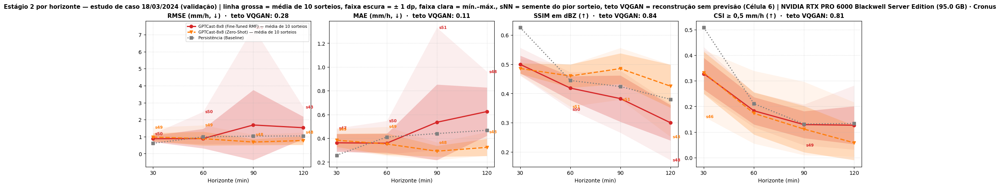

[Célula 9] Tabelas -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/tabelas4e5_estagio2_leadtime_2km_G4_RTX6000_Blackwell_95GB_Cronus_2019_2025.csv
[Célula 9] Painel -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/painel_estagio2_leadtime_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


In [ ]:
# @title
# Célula 9: Estágio 2 — Métricas por Horizonte (+30 a +120 min) no Estudo de Caso (Tabelas 4 e 5),
# com SSIM em faixa fixa, escores indefinidos marcados como NaN e variabilidade entre sorteios do GPTCast.
#
import datetime
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gptcast.utils.converters import dbz_to_rainfall, rainfall_to_dbz
from skimage.metrics import structural_similarity as ssim

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
THRESHOLDS = (0.5, 1.0, 5.0, 10.0)
N_MEMBERS = 10           # sorteios do GPTCast por modelo (a amostragem de tokens é aleatória)
MEMBER_SEEDS = [42 + k for k in range(N_MEMBERS)]   # o membro 42 é o mesmo da Célula 4
if 'data_str' not in globals():
  data_str = (dt - datetime.timedelta(minutes=30 * FORECAST_STEPS + 180)).strftime('%d/%m/%Y')

if 'persistence_rain' not in globals():
  _last = np.asarray(np.ma.filled(input_data_dbz[-1], 0.0))
  last_in_rain = np.clip(dbz_to_rainfall(np.clip(_last, 0.0, 60.0)), 0.0, 205.0)
  persistence_rain = np.repeat(last_in_rain[None], FORECAST_STEPS, axis=0)


def _to_dbz(rain):
  r = np.clip(np.asarray(rain, dtype=np.float64), 0.0, 205.0)
  out = np.zeros_like(r)
  wet = r > 0.0365
  out[wet] = rainfall_to_dbz(r[wet])
  return np.clip(out, 0.0, 60.0)


# -------------------------------------------------- 1. métricas por horizonte (reutilizada)
def evaluate_nowcast_by_leadtime(obs_seq, pred_seq, model_name: str, step_minutes: int = 30,
                                 thresholds: tuple = THRESHOLDS) -> pd.DataFrame:
  """MAE, RMSE, SSIM (em dBZ, faixa fixa de 60 dBZ), PCC, CSI e BIAS por passo futuro.

  Escores sem eventos (ex.: CSI sem chuva acima do limiar em nenhum dos campos) ficam NaN.
  """
  o_all = np.clip(np.nan_to_num(np.asarray(obs_seq), nan=0.0), 0.0, 205.0).astype(np.float64)
  p_all = np.clip(np.nan_to_num(np.asarray(pred_seq), nan=0.0), 0.0, 205.0).astype(np.float64)
  rows = []
  for i in range(o_all.shape[0]):
    o, p = o_all[i], p_all[i]
    row = {
        'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG, 'Modelo': model_name,
        'Lead Time': f'+{(i + 1) * step_minutes} min', 'Lead_min_num': (i + 1) * step_minutes,
        'MAE (↓) [mm/h]': round(float(np.mean(np.abs(p - o))), 4),
        'RMSE (↓) [mm/h]': round(float(np.sqrt(np.mean((p - o) ** 2))), 4),
        'SSIM (↑)': round(float(ssim(_to_dbz(o), _to_dbz(p), data_range=60.0)), 4),
        'PCC (↑)': round(float(np.corrcoef(o.ravel(), p.ravel())[0, 1]), 4) if o.std() > 1e-6 and p.std() > 1e-6 else np.nan,
        'Volume Prev/Obs (=1)': round(float(p.sum() / o.sum()), 3) if o.sum() > 0 else np.nan,
        'Pico Obs [mm/h]': round(float(o.max()), 2), 'Pico Prev [mm/h]': round(float(p.max()), 2),
    }
    for thr in thresholds:
      ob, pb = o >= thr, p >= thr
      tp, fp, fn = int(np.sum(ob & pb)), int(np.sum(~ob & pb)), int(np.sum(ob & ~pb))
      csi = tp / (tp + fp + fn) if tp + fp + fn else np.nan
      bias = (tp + fp) / (tp + fn) if tp + fn else np.nan
      row[f'CSI_{thr}'] = round(csi, 4) if np.isfinite(csi) else np.nan
      row[f'BIAS_{thr}'] = round(bias, 3) if np.isfinite(bias) else np.nan
      if not np.isfinite(csi):
        row[f'CSI/BIAS @ {thr} mm/h'] = 'sem eventos'
      elif not np.isfinite(bias):
        row[f'CSI/BIAS @ {thr} mm/h'] = f'{csi:.3f} / sem obs'
      else:
        row[f'CSI/BIAS @ {thr} mm/h'] = f'{csi:.3f} / {bias:.2f}'
    rows.append(row)
  return pd.DataFrame(rows)


# --------------------------------------------- 2. variabilidade entre sorteios do GPTCast
def forecast_members(model, seeds):
  """N previsões do mesmo contexto, uma por semente: (N, passos, H, W) em mm/h."""
  out = []
  for sd in seeds:
    torch.manual_seed(sd)
    np.random.seed(sd)
    raw = model.forecast(clean_in_dbz, steps=FORECAST_STEPS, units='dbz', verbosity=0)
    raw = raw.filled(0.0) if isinstance(raw, np.ma.MaskedArray) else np.asarray(raw)
    out.append(dbz_to_rainfall(np.clip(np.nan_to_num(raw, nan=0.0), 0.0, 60.0)))
  return np.stack(out).astype(np.float32)


members = {'GPTCast-8x8 (Fine-Tuned RMF)': forecast_members(gpt8, MEMBER_SEEDS)}
if 'gpt8_zeroshot' in globals():
  members['GPTCast-8x8 (Zero-Shot)'] = forecast_members(gpt8_zeroshot, MEMBER_SEEDS)

# ------------------------------------------------------------ 3. tabelas 4 e 5
df_gpt8 = evaluate_nowcast_by_leadtime(ground_truth_rain, forecast8_rain, 'GPTCast-8x8 (Fine-Tuned RMF)')
df_pers = evaluate_nowcast_by_leadtime(ground_truth_rain, persistence_rain, 'Persistência (Baseline)')
dfs = [df_gpt8]
if 'forecast8_zeroshot_rain' in globals():
  df_gpt8_zs = evaluate_nowcast_by_leadtime(ground_truth_rain, forecast8_zeroshot_rain, 'GPTCast-8x8 (Zero-Shot)')
  dfs.append(df_gpt8_zs)
dfs.append(df_pers)
for name, M in members.items():   # média do conjunto de sorteios como previsão adicional
  dfs.append(evaluate_nowcast_by_leadtime(ground_truth_rain, M.mean(axis=0), f'{name} — média de {N_MEMBERS} sorteios'))
df_stage2_eval = pd.concat(dfs, ignore_index=True)
stage2_csv_path = os.path.join(RESULTS_ENV_DIR, f'tabelas4e5_estagio2_leadtime_2km_{ENV_TAG}_2019_2025.csv')
df_stage2_eval.to_csv(stage2_csv_path, index=False)

# Métricas de cada sorteio (calculadas uma vez e usadas na tabela, no ranking de sementes e no painel)
PAINEL = [('RMSE (↓) [mm/h]', 'RMSE (mm/h, ↓)', False), ('MAE (↓) [mm/h]', 'MAE (mm/h, ↓)', False),
          ('SSIM (↑)', 'SSIM em dBZ (↑)', True), ('CSI_0.5', 'CSI ≥ 0,5 mm/h (↑)', True)]
TAB_COLS = ['MAE (↓) [mm/h]', 'RMSE (↓) [mm/h]', 'SSIM (↑)', 'CSI_0.5', 'CSI_1.0', 'Pico Prev [mm/h]', 'Volume Prev/Obs (=1)']
per_member = {name: [evaluate_nowcast_by_leadtime(ground_truth_rain, M[k], name) for k in range(len(M))]
              for name, M in members.items()}
vals = {name: {c: np.array([pd.to_numeric(d[c], errors='coerce').values for d in dfs], dtype=float)
               for c in TAB_COLS} for name, dfs in per_member.items()}       # (sorteios, horizontes)
leads_txt = list(per_member[next(iter(per_member))][0]['Lead Time'])

# Dispersão das métricas entre os sorteios (média ± desvio-padrão)
spread_rows = []
for name, V in vals.items():
  for j, lt in enumerate(leads_txt):
    r = {'Modelo': name, 'Lead Time': lt, 'Sorteios': len(MEMBER_SEEDS)}
    for c in ('MAE (↓) [mm/h]', 'SSIM (↑)', 'CSI_0.5', 'CSI_1.0', 'Pico Prev [mm/h]', 'Volume Prev/Obs (=1)'):
      r[c] = f'{np.nanmean(V[c][:, j]):.3f} ± {np.nanstd(V[c][:, j], ddof=1):.3f}'
    spread_rows.append(r)
df_stage2_spread = pd.DataFrame(spread_rows)
df_stage2_spread.to_csv(os.path.join(RESULTS_ENV_DIR, f'tabela_estagio2_dispersao_sorteios_{ENV_TAG}.csv'), index=False)

# Melhor e pior semente por modelo, métrica e horizonte
seed_rows = []
for name, V in vals.items():
  for c, titulo, maior_melhor in PAINEL:
    for j, lt in enumerate(leads_txt):
      v = V[c][:, j]
      if np.all(np.isnan(v)):
        continue
      ib, iw = (np.nanargmax(v), np.nanargmin(v)) if maior_melhor else (np.nanargmin(v), np.nanargmax(v))
      seed_rows.append({'Modelo': name, 'Métrica': titulo, 'Lead Time': lt,
                        'Média ± dp': f'{np.nanmean(v):.3f} ± {np.nanstd(v, ddof=1):.3f}',
                        'Melhor (semente)': f'{v[ib]:.3f} ({MEMBER_SEEDS[ib]})',
                        'Pior (semente)': f'{v[iw]:.3f} ({MEMBER_SEEDS[iw]})',
                        'Semente 42': f'{v[MEMBER_SEEDS.index(42)]:.3f}' if 42 in MEMBER_SEEDS else '—'})
df_stage2_seeds = pd.DataFrame(seed_rows)
df_stage2_seeds.to_csv(os.path.join(RESULTS_ENV_DIR, f'tabela_estagio2_melhor_pior_semente_{ENV_TAG}.csv'), index=False)

cols = ['Ambiente_Execucao', 'Modelo', 'Lead Time', 'MAE (↓) [mm/h]', 'RMSE (↓) [mm/h]', 'SSIM (↑)', 'PCC (↑)',
        'Volume Prev/Obs (=1)'] + [f'CSI/BIAS @ {t} mm/h' for t in THRESHOLDS] + ['Pico Obs [mm/h]', 'Pico Prev [mm/h]']
print(f'=== Tabelas 4 e 5 — Estágio 2 por horizonte no estudo de caso {data_str} (validação) | {ENV_LABEL} ===')
print('SSIM em dBZ com faixa fixa de 60 dBZ. "sem eventos" = nenhum pixel acima do limiar em nenhum dos campos.')
display(df_stage2_eval[cols].set_index(['Ambiente_Execucao', 'Modelo', 'Lead Time']))
print(f'\n=== Variabilidade entre {N_MEMBERS} sorteios do GPTCast (mesmo contexto, sementes {MEMBER_SEEDS[0]}–{MEMBER_SEEDS[-1]}) ===')
display(df_stage2_spread.set_index(['Modelo', 'Lead Time']))
print('\n=== Melhor e pior sorteio por métrica e horizonte (semente entre parênteses) ===')
print('Para ver o mapa de um sorteio: torch.manual_seed(semente); np.random.seed(semente); model.forecast(...)')
display(df_stage2_seeds.set_index(['Modelo', 'Métrica', 'Lead Time']))

# ------------------------------------------------------------------ 4. painel
# Para cada GPTCast: faixa clara = mín.–máx.; faixa escura = média ± 1 dp;
# linha grossa = média dos sorteios; a semente do pior sorteio de cada horizonte é escrita ao lado do ponto.
# Teto da VQGAN (Estágio 1, Célula 6) nos mesmos 4 quadros-alvo, escrito só no título de cada painel
_s1 = globals().get('df_stage1_raw')
if _s1 is None:
  _p1 = os.path.join(RESULTS_ENV_DIR, f'tabela3_estagio1_vqgan_2km_{ENV_TAG}_2019_2025.csv')
  _s1 = pd.read_csv(_p1) if os.path.isfile(_p1) else None
TETO_VQGAN = {}
if _s1 is not None and len(_s1):
  _caso = _s1[_s1['Conjunto Avaliado'].astype(str).str.startswith('Estudo de caso')]
  _r = (_caso if len(_caso) else _s1).iloc[0]
  for c, c1 in {'RMSE (↓) [mm/h]': 'RMSE [mm/h] (↓)', 'MAE (↓) [mm/h]': 'MAE [mm/h] (↓)',
                'SSIM (↑)': 'SSIM dBZ (↑)', 'CSI_0.5': 'CSI/BIAS @ 0.5 mm/h'}.items():
    try:
      TETO_VQGAN[c] = float(str(_r[c1]).split('/')[0])
    except (KeyError, ValueError):
      pass
else:
  print('[Célula 9] Tabela do Estágio 1 não encontrada: os títulos saem sem o teto da VQGAN (rode a Célula 6).')

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), constrained_layout=True)
cores = {'GPTCast-8x8 (Fine-Tuned RMF)': ('#d62728', 'o-'), 'GPTCast-8x8 (Zero-Shot)': ('#ff7f0e', 'v--')}
x = np.arange(1, FORECAST_STEPS + 1) * 30
for name, V in vals.items():
  color, ls = cores.get(name, ('#1f77b4', 'o-'))
  for ax, (c, _, maior_melhor) in zip(axes, PAINEL):
    v = V[c]
    med, dp = np.nanmean(v, 0), np.nanstd(v, 0, ddof=1)
    ax.fill_between(x, np.nanmin(v, 0), np.nanmax(v, 0), color=color, alpha=0.08, lw=0, zorder=0)
    ax.fill_between(x, med - dp, med + dp, color=color, alpha=0.22, lw=0, zorder=1)
    ax.plot(x, med, ls, color=color, lw=2.2, zorder=3, label=f'{name} — média de {len(v)} sorteios')
    for j in range(len(x)):          # semente do pior sorteio, só onde ele se afasta da média
      col = v[:, j]
      if np.all(np.isnan(col)):
        continue
      iw = np.nanargmin(col) if maior_melhor else np.nanargmax(col)
      if abs(col[iw] - med[j]) > 1.5 * (dp[j] if dp[j] > 0 else np.inf):
        ax.annotate(f's{MEMBER_SEEDS[iw]}', (x[j], col[iw]), xytext=(4, 0), textcoords='offset points',
                    fontsize=7.5, color=color, fontweight='bold', va='center')
sub = df_stage2_eval[df_stage2_eval['Modelo'] == 'Persistência (Baseline)']
for ax, (c, titulo, _) in zip(axes, PAINEL):
  if not sub.empty:
    ax.plot(sub['Lead_min_num'], pd.to_numeric(sub[c], errors='coerce'), 's:', color='#7f7f7f', lw=2,
            zorder=4, label='Persistência (Baseline)')
  ax.set_title(titulo + (f'  ·  teto VQGAN: {TETO_VQGAN[c]:.2f}' if c in TETO_VQGAN else ''),
               fontweight='bold', fontsize=11)
  ax.set_xlabel('Horizonte (min)')
  ax.set_xticks(x)
  ax.grid(True, ls=':', alpha=0.6)
axes[0].legend(fontsize=7.5)
fig.suptitle(f'Estágio 2 por horizonte — estudo de caso {data_str} (validação) | linha grossa = média de '
             f'{len(MEMBER_SEEDS)} sorteios, faixa escura = ± 1 dp, faixa clara = mín.–máx., sNN = semente do pior '
             f'sorteio, teto VQGAN = reconstrução sem previsão (Célula 6) | {ENV_LABEL}', fontsize=11, fontweight='bold')
stage2_fig_path = os.path.join(RESULTS_ENV_DIR, f'painel_estagio2_leadtime_2km_{ENV_TAG}.png')
fig.savefig(stage2_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[Célula 9] Tabelas -> {stage2_csv_path}\n[Célula 9] Painel -> {stage2_fig_path}')


# Célula 10: Benchmark Operacional Integrado - Modelos de Inteligência Artificial (GPTCast-8x8 Ajustado e Zero-Shot) vs. Modelos Físicos Lagrangianos (`pysteps`: LINDA Determinístico e Fluxo Óptico de Lucas-Kanade) e Persistência na Malha de 2 km (`ENV_TAG`)

* **Comparação Multimetodológica no Estudo de Caso**: Avalia 5 métodos nos quatro passos (+30, +60, +90 e +120 min) sobre o evento da RMF (`18/03/2024`, partição de validação):

  1. **GPTCast-8x8 ajustado** (Transformer adaptado à RMF, treino 2019–2023);

  2. **GPTCast-8x8 zero-shot** (pesos originais, pré-treinados em radar italiano);

  3. **LINDA (`pysteps`)** (Lagrangian INtegroDifference with Autoregression, versão `domain` determinística, sem perturbações aleatórias, portanto reproduzível);

  4. **Fluxo Óptico Lucas-Kanade (`pysteps`)** (campo de movimento estimado nos últimos 4 quadros e extrapolação semi-lagrangiana);

  5. **Persistência** (repetição do último quadro observado).

* **Ordenação por Horizonte e Tempos Medidos**: Exibe a posição de cada método (1 = melhor) em MAE e CSI (limiares de 0,5 e 1,0 mm/h) por horizonte, a velocidade de deslocamento estimada pelo fluxo óptico (km/h) e o tempo de cada método com o dispositivo usado (GPTCast em GPU; `pysteps` e Persistência em CPU). Se o LINDA falhar, a linha é rotulada como substituída por Lucas-Kanade.

* **Exportação e Rastreabilidade (`ENV_TAG`)**: Salva os mapas do LINDA e do Lucas-Kanade, o painel de métricas comparativas (`.png` a `300 dpi`) e o CSV consolidado em `RESULTS_ENV_DIR`. Por ser um único evento, a comparação ilustra o comportamento dos métodos; o benchmark estatístico sobre 2025 é feito na Célula 12.

Computing LINDA nowcast
-----------------------

Inputs
------
dimensions:           128x128
number of time steps: 3

Methods
-------
nowcast type:         deterministic
feature detector:     domain
extrapolator:         semilagrangian
kernel type:          anisotropic

Parameters
----------
number of time steps:     4
ARI model order:            1
localization window radius: 25.6
Rain fraction is: 0.442138671875, while minimum fraction is 0.0
Transforming to Lagrangian coordinates... done.
Estimating the first convolution kernel... done.
Estimating the ARI(p,1) parameters... done.
Estimating the second convolution kernel... done.
Computing nowcast for time step 1... done.
Computing nowcast for time step 2... done.
Computing nowcast for time step 3... done.
Computing nowcast for time step 4... done.
[Célula 10] Movimento LK: mediana 14.5 km/h, máximo 32.1 km/h | LK 0.037 s | LINDA 0.776 s (LINDA-D determinístico)

=== Benchmark de 5 métodos — estudo de caso 18/03/2024 (validação; 1 eve

MAE (↓) [mm/h]  \
Ambiente_Execucao                                  Modelo                       Lead Time                   
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF) +30 min            0.2910   
                                                                                +60 min            0.3025   
                                                                                +90 min            0.3395   
                                                                                +120 min           0.5559   
                                                   GPTCast-8x8 (Zero-Shot)      +30 min            0.3236   
                                                                                +60 min            0.3273   
                                                                                +90 min            0.3073   
                                                                                +120 min           0.2858   
                                                   LINDA (pysteps)              +30 min            0.2821   
                                                                                +60 min            0.3226   
                                                                                +90 min            0.3131   
                                                                                +120 min           0.2982   
                                                   Fluxo Óptico LK (pysteps)    +30 min            0.2647   
                                                                                +60 min            0.3533   
                                                                                +90 min            0.3456   
                                                                                +120 min           0.3522   
                                                   Persistência (Baseline)      +30 min            0.2574   
                                                                                +60 min            0.4104   
                                                                                +90 min            0.4396   
                                                                                +120 min           0.4674   

                                                                                           RMSE (↓) [mm/h]  \
Ambiente_Execucao                                  Modelo                       Lead Time                    
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF) +30 min             0.6595   
                                                                                +60 min             0.6171   
                                                                                +90 min             0.9693   
                                                                                +120 min            1.4983   
                                                   GPTCast-8x8 (Zero-Shot)      +30 min             0.7289   
                                                                                +60 min             0.6363   
                                                                                +90 min             0.6747   
                                                                                +120 min            0.7184   
                                                   LINDA (pysteps)              +30 min             0.5658   
                                                                                +60 min             0.5710   
                                                                                +90 min             0.5732   
                                                                                +120 min            0.5459   
                                                   Fluxo Óptico LK (pysteps)    +30 min             0.6059   
                                          


=== Posição de cada método por horizonte (1 = melhor) ===


Pos. MAE                          Pos. CSI 0,5  \
                              +30 min +60 min +90 min +120 min      +30 min   
Modelo                                                                        
Fluxo Óptico LK (pysteps)           2       4       4        3            1   
GPTCast-8x8 (Fine-Tuned RMF)        4       1       3        5            5   
GPTCast-8x8 (Zero-Shot)             5       3       1        1            4   
LINDA (pysteps)                     3       2       2        2            3   
Persistência (Baseline)             1       5       5        4            2   

                                                      Pos. CSI 1,0          \
                             +60 min +90 min +120 min      +30 min +60 min   
Modelo                                                                       
Fluxo Óptico LK (pysteps)          1       2        2            3       2   
GPTCast-8x8 (Fine-Tuned RMF)       3       3        3            5       5   
GPTCast-8x8 (Zero-Shot)            5       4        5            4       3   
LINDA (pysteps)                    2       1        1            2       1   
Persistência (Baseline)            4       5        4            1       4   

                                               
                             +90 min +120 min  
Modelo                                         
Fluxo Óptico LK (pysteps)          2        2  
GPTCast-8x8 (Fine-Tuned RMF)       3        3  
GPTCast-8x8 (Zero-Shot)            5        5  
LINDA (pysteps)                    1        1  
Persistência (Baseline)            4        4

[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/mapa_04_linda_pysteps_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


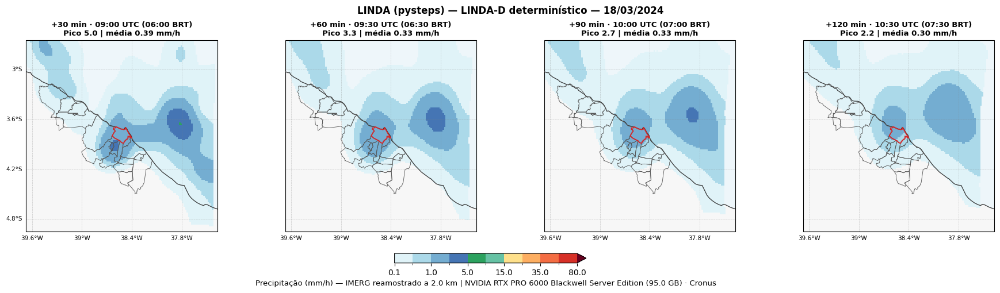

[Célula 5] Mapa salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/mapa_05_fluxo_optico_lk_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


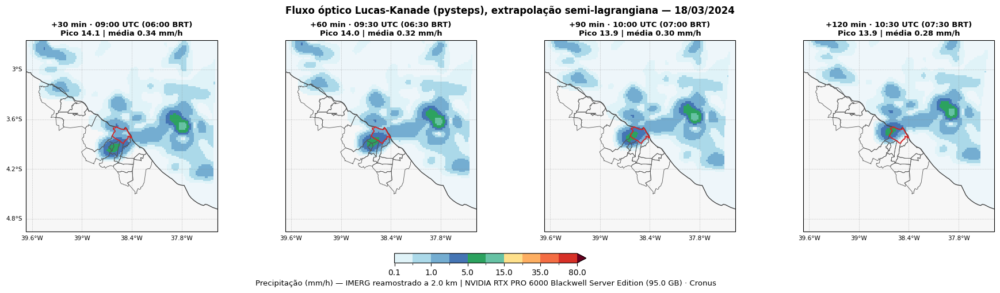

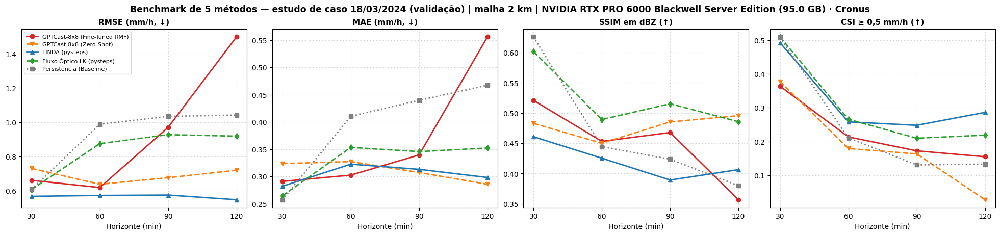

[Célula 10] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/benchmark_completo_pysteps_2km_G4_RTX6000_Blackwell_95GB_Cronus.csv
[Célula 10] Painel -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/painel_benchmark_5modelos_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


In [ ]:
# @title
# Célula 10: Benchmark de 5 Métodos no Estudo de Caso — GPTCast-8x8 (ajustado e zero-shot) x pysteps
# (Lucas-Kanade e LINDA determinístico) x Persistência, com tempos medidos e ordenação por horizonte.
#
import datetime
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gptcast.utils.converters import dbz_to_rainfall
from pysteps import motion, nowcasts

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
RES_GRID_KM = float(globals().get('RES_KM', 2.0))
STEP_MIN = 30
if 'data_str' not in globals():
  data_str = (dt - datetime.timedelta(minutes=STEP_MIN * FORECAST_STEPS + 180)).strftime('%d/%m/%Y')


# ------------------------------------------------------------ 1. adapter do pysteps
class PyStepsNowcastAdapter:
  """Lucas-Kanade (campo de movimento + extrapolação semi-lagrangiana) e LINDA (pysteps).

  LINDA roda na versão determinística (add_perturbations=False): uma única previsão reproduzível,
  comparável às demais. O campo de movimento é estimado em dBZ nos últimos `n_motion` quadros.
  """

  def __init__(self, oflow_method: str = 'LK', n_motion: int = 4):
    self.oflow_fn = motion.get_method(oflow_method)
    self.extrap_fn = nowcasts.get_method('extrapolation')
    self.linda_fn = nowcasts.get_method('linda')
    self.n_motion = n_motion
    self.linda_status = 'não executado'

  def compute_motion_field(self, in_dbz_seq) -> np.ndarray:
    seq = np.asarray(np.ma.filled(in_dbz_seq, 0.0), dtype=np.float64)
    return self.oflow_fn(np.clip(np.nan_to_num(seq[-self.n_motion:], nan=0.0), 0.0, 60.0))

  def forecast_extrapolation_lk(self, last_frame_rain, velocity_field, steps: int = 4) -> np.ndarray:
    r = np.clip(np.nan_to_num(last_frame_rain, nan=0.0), 0.0, 205.0).astype(np.float64)
    out = self.extrap_fn(r, velocity_field, steps)
    return np.clip(np.nan_to_num(out, nan=0.0), 0.0, 205.0).astype(np.float32)

  def forecast_linda(self, rain_seq_context, velocity_field, steps: int = 4, res_km: float = RES_GRID_KM,
                     feature_method: str = 'domain', ari_order: int = 1) -> np.ndarray:
    r = np.clip(np.nan_to_num(rain_seq_context[-(ari_order + 2):], nan=0.0), 0.0, 205.0).astype(np.float64)
    try:
      out = self.linda_fn(r, velocity_field, steps, feature_method=feature_method, ari_order=ari_order,
                          add_perturbations=False, kmperpixel=res_km, timestep=float(STEP_MIN),
                          measure_time=False)
      out = out[0] if isinstance(out, tuple) else out
      out = out[0] if out.ndim == 4 else out
      self.linda_status = f'LINDA-{"D" if feature_method == "domain" else "F"} determinístico'
      return np.clip(np.nan_to_num(out, nan=0.0), 0.0, 205.0).astype(np.float32)
    except Exception as e:
      self.linda_status = f'FALHOU ({type(e).__name__}): substituído por Lucas-Kanade'
      print(f'[Aviso Célula 10] LINDA falhou ({e}); a linha "LINDA" será a extrapolação Lucas-Kanade.')
      return self.forecast_extrapolation_lk(rain_seq_context[-1], velocity_field, steps)


# ------------------------------------------------------ 2. métodos físicos, cronometrados
pysteps_adapter = PyStepsNowcastAdapter('LK')
raw_in_dbz_all = np.asarray(np.ma.filled(input_data_dbz, 0.0), dtype=np.float64)
context_rain_all = np.clip(dbz_to_rainfall(np.clip(raw_in_dbz_all, 0.0, 60.0)), 0.0, 205.0)

t0 = time.perf_counter()
velocity_field = pysteps_adapter.compute_motion_field(raw_in_dbz_all)
t_of_s = time.perf_counter() - t0
t0 = time.perf_counter()
lk_extrap_rain = pysteps_adapter.forecast_extrapolation_lk(context_rain_all[-1], velocity_field, FORECAST_STEPS)
t_lk_total_s = t_of_s + time.perf_counter() - t0
t0 = time.perf_counter()
linda_rain = pysteps_adapter.forecast_linda(context_rain_all, velocity_field, FORECAST_STEPS)
t_linda_total_s = t_of_s + time.perf_counter() - t0
t0 = time.perf_counter()
_ = np.repeat(context_rain_all[-1:], FORECAST_STEPS, axis=0)
t_pers_s = time.perf_counter() - t0
speed = np.hypot(velocity_field[0], velocity_field[1])
print(f'[Célula 10] Movimento LK: mediana {np.median(speed) * RES_GRID_KM * 60 / STEP_MIN:.1f} km/h, '
      f'máximo {speed.max() * RES_GRID_KM * 60 / STEP_MIN:.1f} km/h | LK {t_lk_total_s:.3f} s | '
      f'LINDA {t_linda_total_s:.3f} s ({pysteps_adapter.linda_status})')

# ---------------------------------------------------------------- 3. tabela conjunta
t_ft = timing_gpu_log.get('inferencia_4passos_finetuned_s', np.nan) if 'timing_gpu_log' in globals() else np.nan
t_zs = timing_gpu_log.get('inferencia_4passos_zeroshot_s', np.nan) if 'timing_gpu_log' in globals() else np.nan
linha_linda = 'LINDA (pysteps)' if 'FALHOU' not in pysteps_adapter.linda_status else 'LINDA (pysteps) [falhou: é LK]'
blocos = [(df_gpt8, t_ft, 'GPU'),
          (df_gpt8_zs if 'df_gpt8_zs' in globals() else None, t_zs, 'GPU'),
          (evaluate_nowcast_by_leadtime(ground_truth_rain, linda_rain, linha_linda), t_linda_total_s, 'CPU'),
          (evaluate_nowcast_by_leadtime(ground_truth_rain, lk_extrap_rain, 'Fluxo Óptico LK (pysteps)'), t_lk_total_s, 'CPU'),
          (df_pers, t_pers_s, 'CPU')]
parts = []
for df_m, t_m, dev in blocos:
  if df_m is None:
    continue
  d = df_m.copy()
  d['Tempo_Inferência_4Passos [s]'] = round(float(t_m), 4)
  d['Dispositivo'] = dev
  parts.append(d)
df_full_benchmark = pd.concat(parts, ignore_index=True)
bench_csv_path = os.path.join(RESULTS_ENV_DIR, f'benchmark_completo_pysteps_2km_{ENV_TAG}.csv')
df_full_benchmark.to_csv(bench_csv_path, index=False)

# Ordenação por horizonte (1 = melhor) em MAE, CSI ≥ 0,5 e CSI ≥ 1,0 mm/h
rank = df_full_benchmark[['Modelo', 'Lead Time', 'MAE (↓) [mm/h]', 'CSI_0.5', 'CSI_1.0']].copy()
rank['Pos. MAE'] = rank.groupby('Lead Time')['MAE (↓) [mm/h]'].rank(method='min').astype('Int64')
rank['Pos. CSI 0,5'] = rank.groupby('Lead Time')['CSI_0.5'].rank(ascending=False, method='min').astype('Int64')
rank['Pos. CSI 1,0'] = rank.groupby('Lead Time')['CSI_1.0'].rank(ascending=False, method='min').astype('Int64')
df_rank = rank.pivot(index='Modelo', columns='Lead Time', values=['Pos. MAE', 'Pos. CSI 0,5', 'Pos. CSI 1,0'])
_leads = list(dict.fromkeys(df_full_benchmark['Lead Time']))
df_rank = df_rank.reindex(columns=pd.MultiIndex.from_product([['Pos. MAE', 'Pos. CSI 0,5', 'Pos. CSI 1,0'], _leads]))

cols = ['Ambiente_Execucao', 'Modelo', 'Lead Time', 'MAE (↓) [mm/h]', 'RMSE (↓) [mm/h]', 'SSIM (↑)', 'PCC (↑)',
        'Volume Prev/Obs (=1)', 'CSI/BIAS @ 0.5 mm/h', 'CSI/BIAS @ 1.0 mm/h', 'CSI/BIAS @ 5.0 mm/h',
        'Tempo_Inferência_4Passos [s]', 'Dispositivo']
cols = [c for c in cols if c in df_full_benchmark.columns]
print(f'\n=== Benchmark de 5 métodos — estudo de caso {data_str} (validação; 1 evento) | {ENV_LABEL} ===')
print('Tempos: GPTCast em GPU (média de repetições, Célula 4); pysteps e Persistência em CPU, numa execução.')
display(df_full_benchmark[cols].set_index(['Ambiente_Execucao', 'Modelo', 'Lead Time']))
print('\n=== Posição de cada método por horizonte (1 = melhor) ===')
display(df_rank)

# ------------------------------------------------------------------ 4. mapas e painel
if 'plot_rmf_spatial' in globals():
  plot_rmf_spatial(linda_rain, dt, f'{linha_linda} — {pysteps_adapter.linda_status} — {data_str}',
                   save_filename=f'mapa_04_linda_pysteps_2km_{ENV_TAG}.png')
  plot_rmf_spatial(lk_extrap_rain, dt, f'Fluxo óptico Lucas-Kanade (pysteps), extrapolação semi-lagrangiana — {data_str}',
                   save_filename=f'mapa_05_fluxo_optico_lk_2km_{ENV_TAG}.png')

styles = {'GPTCast-8x8 (Fine-Tuned RMF)': ('#d62728', 'o-'), 'GPTCast-8x8 (Zero-Shot)': ('#ff7f0e', 'v--'),
          linha_linda: ('#1f77b4', '^-'), 'Fluxo Óptico LK (pysteps)': ('#2ca02c', 'd--'),
          'Persistência (Baseline)': ('#7f7f7f', 's:')}
metrics = [('RMSE (↓) [mm/h]', 'RMSE (mm/h, ↓)'), ('MAE (↓) [mm/h]', 'MAE (mm/h, ↓)'),
           ('SSIM (↑)', 'SSIM em dBZ (↑)'), ('CSI_0.5', 'CSI ≥ 0,5 mm/h (↑)')]
fig, axes = plt.subplots(1, 4, figsize=(19.5, 4.5), constrained_layout=True)
for name in df_full_benchmark['Modelo'].unique():
  sub = df_full_benchmark[df_full_benchmark['Modelo'] == name]
  color, ls = styles.get(name, ('k', 'o-'))
  for ax, (c, _) in zip(axes, metrics):
    ax.plot(sub['Lead_min_num'], sub[c], ls, color=color, lw=2, label=name)
for ax, (_, title) in zip(axes, metrics):
  ax.set_title(title, fontweight='bold', fontsize=11)
  ax.set_xlabel('Horizonte (min)')
  ax.set_xticks([30, 60, 90, 120])
  ax.grid(True, ls=':', alpha=0.6)
axes[0].legend(fontsize=8)
fig.suptitle(f'Benchmark de 5 métodos — estudo de caso {data_str} (validação) | malha {RES_GRID_KM:.0f} km | {ENV_LABEL}',
             fontsize=12.5, fontweight='bold')
bench_fig_path = os.path.join(RESULTS_ENV_DIR, f'painel_benchmark_5modelos_2km_{ENV_TAG}.png')
fig.savefig(bench_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[Célula 10] Tabela -> {bench_csv_path}\n[Célula 10] Painel -> {bench_fig_path}')


# Célula 11: Verificação Espacial Multiescala - Fractions Skill Score (FSS - Roberts & Lean, 2008) na Malha de 2 km, de 2 a 98 km, para Determinação da Escala Mínima Útil na RMF (`ENV_TAG`)

* **Superação da Dupla Penalidade (*Double Penalty*)**: Compara a fração de pixels com chuva acima do limiar (0,5 e 1,0 mm/h) dentro de janelas quadradas de 2, 6, 10, 18, 26, 34, 50, 66 e 98 km de lado, identificando a menor escala em que cada modelo atinge a habilidade útil (FSS útil = 0,5 + f₀/2, em que f₀ é a fração de pixels com chuva observada). Quando nenhum dos campos atinge o limiar, o FSS é registrado como **indefinido**.

* **Escalas de Referência: Resolução Nativa e Token (Rastreabilidade `ENV_TAG`)**: O painel destaca as escalas abaixo de cerca de 22 km, menores do que o IMERG nativo (cerca de 11 km) consegue resolver, e marca o lado de um token do VQGAN (16 × 16 pixels = 32 km), confrontando **GPTCast-8x8 ajustado**, **zero-shot**, **LINDA**, **Fluxo Óptico LK** e **Persistência** nos horizontes de +30 a +120 min e exportando o CSV e o painel (`.png` a `300 dpi`) para `RESULTS_ENV_DIR`.

* **Estudo de Caso e Agregação no Teste de 2025 (`fss_over_set`)**: A tabela e o painel referem-se ao evento de `18/03/2024` (partição de validação). A função `fss_over_set()` soma os erros das frações de todas as janelas antes de calcular o FSS, como recomendado para conjuntos, e é usada pela Célula 12 no teste independente de 2025.

=== FSS multiescala — estudo de caso 18/03/2024 (validação; 1 evento) | NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus ===
Escalas abaixo de ~22 km estão abaixo da resolução nativa do IMERG; o lado de um token do VQGAN é 32 km. O FSS do teste de 2025 sai da Célula 12 via fss_over_set().

--- Limiar ≥ 0.5 mm/h ---


FSS @ 2 km  \
Ambiente_Execucao                                  Modelo                       Lead Time               
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF) +30 min        0.5332   
                                                                                +60 min        0.3523   
                                                                                +90 min        0.2945   
                                                                                +120 min       0.2687   
                                                   GPTCast-8x8 (Zero-Shot)      +30 min        0.5483   
                                                                                +60 min        0.3043   
                                                                                +90 min        0.2814   
                                                                                +120 min       0.0550   
                                                   LINDA (pysteps)              +30 min        0.6596   
                                                                                +60 min        0.4104   
                                                                                +90 min        0.3975   
                                                                                +120 min       0.4450   
                                                   Fluxo Óptico LK (pysteps)    +30 min        0.6747   
                                                                                +60 min        0.4202   
                                                                                +90 min        0.3470   
                                                                                +120 min       0.3592   
                                                   Persistência (Baseline)      +30 min        0.6736   
                                                                                +60 min        0.3482   
                                                                                +90 min        0.2321   
                                                                                +120 min       0.2354   

                                                                                           FSS @ 6 km  \
Ambiente_Execucao                                  Modelo                       Lead Time               
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF) +30 min        0.5796   
                                                                                +60 min        0.3853   
                                                                                +90 min        0.3314   
                                                                                +120 min       0.2984   
                                                   GPTCast-8x8 (Zero-Shot)      +30 min        0.5973   
                                                                                +60 min        0.3420   
                                                                                +90 min        0.3193   
                                                                                +120 min       0.0644   
                                                   LINDA (pysteps)              +30 min        0.7012   
                                                                                +60 min        0.4403   
                                                                                +90 min        0.4252   
                                                                                +120 min       0.4729   
                                                   Fluxo Óptico LK (pysteps)    +30 min        0.7321   
                                                                                +60 min        0.4636   
                                                                                +90 min        0.384


--- Limiar ≥ 1.0 mm/h ---


FSS @ 2 km  \
Ambiente_Execucao                                  Modelo                       Lead Time               
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF) +30 min        0.3261   
                                                                                +60 min        0.1314   
                                                                                +90 min        0.1445   
                                                                                +120 min       0.0906   
                                                   GPTCast-8x8 (Zero-Shot)      +30 min        0.4330   
                                                                                +60 min        0.1907   
                                                                                +90 min        0.0568   
                                                                                +120 min       0.0000   
                                                   LINDA (pysteps)              +30 min        0.5456   
                                                                                +60 min        0.2854   
                                                                                +90 min        0.2778   
                                                                                +120 min       0.1968   
                                                   Fluxo Óptico LK (pysteps)    +30 min        0.5361   
                                                                                +60 min        0.2472   
                                                                                +90 min        0.2132   
                                                                                +120 min       0.1373   
                                                   Persistência (Baseline)      +30 min        0.5822   
                                                                                +60 min        0.1659   
                                                                                +90 min        0.0740   
                                                                                +120 min       0.0178   

                                                                                           FSS @ 6 km  \
Ambiente_Execucao                                  Modelo                       Lead Time               
NVIDIA RTX PRO 6000 Blackwell Server Edition (9... GPTCast-8x8 (Fine-Tuned RMF) +30 min        0.3712   
                                                                                +60 min        0.1606   
                                                                                +90 min        0.1721   
                                                                                +120 min       0.1062   
                                                   GPTCast-8x8 (Zero-Shot)      +30 min        0.4981   
                                                                                +60 min        0.2352   
                                                                                +90 min        0.0719   
                                                                                +120 min       0.0000   
                                                   LINDA (pysteps)              +30 min        0.5937   
                                                                                +60 min        0.3162   
                                                                                +90 min        0.3051   
                                                                                +120 min       0.2182   
                                                   Fluxo Óptico LK (pysteps)    +30 min        0.6091   
                                                                                +60 min        0.2917   
                                                                                +90 min        0.246

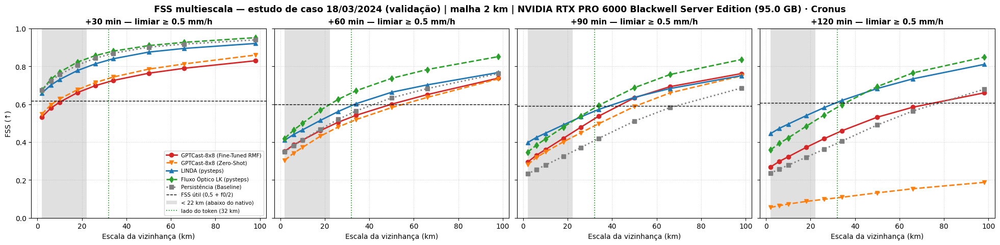

[Célula 11] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/tabela_fss_multiescala_2km_G4_RTX6000_Blackwell_95GB_Cronus.csv
[Célula 11] Painel -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus/painel_fss_multiescala_2km_G4_RTX6000_Blackwell_95GB_Cronus.png


In [ ]:
# @title
# Célula 11: Fractions Skill Score (FSS — Roberts & Lean, 2008) Multiescala a 2 km, até 98 km,
# com escalas abaixo da resolução nativa do IMERG identificadas e casos sem chuva como indefinidos.
#
import datetime
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import uniform_filter

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
RES_GRID_KM = float(globals().get('RES_KM', 2.0))
NYQUIST_NATIVE_KM = 22.2                    # 2 x ~11,1 km do IMERG
TOKEN_KM = (GRID_SIZE // 8) * RES_GRID_KM   # 32 km
FSS_WINDOWS_PX = [1, 3, 5, 9, 13, 17, 25, 33, 49]   # 2 a 98 km
FSS_THRESHOLDS = (0.5, 1.0)                 # mm/h
fss_windows_px = FSS_WINDOWS_PX
fss_scales_km = [int(round(w * RES_GRID_KM)) for w in FSS_WINDOWS_PX]
if 'data_str' not in globals():
  data_str = (dt - datetime.timedelta(minutes=30 * FORECAST_STEPS + 180)).strftime('%d/%m/%Y')


def compute_fss_2d(obs_2d, pred_2d, thr_mmh: float = 0.5, window_px: int = 1) -> float:
  """FSS para um limiar e uma janela quadrada de `window_px` pixels (borda preenchida com zero).

  Indefinido (NaN) quando nenhum dos dois campos atinge o limiar.
  """
  o = np.nan_to_num(np.ma.filled(obs_2d, 0.0), nan=0.0) >= thr_mmh
  p = np.nan_to_num(np.ma.filled(pred_2d, 0.0), nan=0.0) >= thr_mmh
  if not o.any() and not p.any():
    return np.nan
  fo = uniform_filter(o.astype(np.float64), size=window_px, mode='constant', cval=0.0)
  fp = uniform_filter(p.astype(np.float64), size=window_px, mode='constant', cval=0.0)
  ref = float(np.mean(fo ** 2 + fp ** 2))
  return float(np.clip(1.0 - np.mean((fo - fp) ** 2) / ref, 0.0, 1.0)) if ref > 0 else np.nan


def _useful(obs_2d, thr):
  return 0.5 + float(np.mean(np.nan_to_num(np.ma.filled(obs_2d, 0.0)) >= thr)) / 2.0


def _min_scale(values, useful):
  for v, s in zip(values, fss_scales_km):
    if np.isfinite(v) and v >= useful:
      return f'{s} km'
  return f'> {fss_scales_km[-1]} km'


def fss_over_set(obs_seqs, preds: dict, thr: float = 0.5) -> pd.DataFrame:
  """FSS agregado em muitas janelas (ex.: teste 2025, Célula 12): para cada escala, soma os erros
  quadráticos das frações de todas as janelas antes da razão (forma recomendada por Roberts & Lean
  para conjuntos), por modelo e horizonte. obs_seqs: (N, 4, H, W); preds: nome -> (N, 4, H, W)."""
  rows = []
  for name, P in preds.items():
    for s in range(obs_seqs.shape[1]):
      row = {'Modelo': name, 'Lead Time': f'+{30 * (s + 1)} min', 'Limiar [mm/h]': thr, 'Janelas': obs_seqs.shape[0]}
      f0 = float(np.mean(obs_seqs[:, s] >= thr))
      vals = []
      for w, km in zip(FSS_WINDOWS_PX, fss_scales_km):
        num = den = 0.0
        for i in range(obs_seqs.shape[0]):
          fo = uniform_filter((obs_seqs[i, s] >= thr).astype(np.float64), size=w, mode='constant')
          fp = uniform_filter((P[i, s] >= thr).astype(np.float64), size=w, mode='constant')
          num += np.sum((fo - fp) ** 2)
          den += np.sum(fo ** 2 + fp ** 2)
        v = 1.0 - num / den if den > 0 else np.nan
        vals.append(v)
        row[f'FSS @ {km} km'] = round(float(v), 4)
      row['FSS útil (0,5 + f0/2)'] = round(0.5 + f0 / 2, 4)
      row['Escala Mínima Útil (↓)'] = _min_scale(vals, 0.5 + f0 / 2)
      rows.append(row)
  return pd.DataFrame(rows)


# ------------------------------------------------------------ 1. modelos avaliados
fss_models = {'GPTCast-8x8 (Fine-Tuned RMF)': forecast8_rain}
for nome, var in (('GPTCast-8x8 (Zero-Shot)', 'forecast8_zeroshot_rain'), ('LINDA (pysteps)', 'linda_rain'),
                  ('Fluxo Óptico LK (pysteps)', 'lk_extrap_rain'), ('Persistência (Baseline)', 'persistence_rain')):
  if var in globals():
    fss_models[nome] = globals()[var]

# --------------------------------------------------------- 2. FSS do estudo de caso
fss_rows = []
for thr in FSS_THRESHOLDS:
  for name, pred in fss_models.items():
    for s in range(FORECAST_STEPS):
      useful = _useful(ground_truth_rain[s], thr)
      vals = [compute_fss_2d(ground_truth_rain[s], pred[s], thr, w) for w in FSS_WINDOWS_PX]
      row = {'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG, 'Modelo': name,
             'Lead Time': f'+{30 * (s + 1)} min', 'Lead_min_num': 30 * (s + 1), 'Limiar [mm/h]': thr,
             'FSS_Useful (0.5 + f0/2)': round(useful, 4)}
      for v, km in zip(vals, fss_scales_km):
        row[f'FSS @ {km} km'] = round(v, 4) if np.isfinite(v) else np.nan
      row['Escala Mínima Útil (↓)'] = _min_scale(vals, useful) if np.isfinite(vals).any() else 'indefinido (sem chuva)'
      fss_rows.append(row)
df_fss = pd.DataFrame(fss_rows)
fss_csv_path = os.path.join(RESULTS_ENV_DIR, f'tabela_fss_multiescala_2km_{ENV_TAG}.csv')
df_fss.to_csv(fss_csv_path, index=False)

print(f'=== FSS multiescala — estudo de caso {data_str} (validação; 1 evento) | {ENV_LABEL} ===')
print(f'Escalas abaixo de ~{NYQUIST_NATIVE_KM:.0f} km estão abaixo da resolução nativa do IMERG; '
      f'o lado de um token do VQGAN é {TOKEN_KM:.0f} km. O FSS do teste de 2025 sai da Célula 12 via fss_over_set().')
for thr in FSS_THRESHOLDS:
  sub = df_fss[df_fss['Limiar [mm/h]'] == thr]
  cols = ['Ambiente_Execucao', 'Modelo', 'Lead Time'] + [f'FSS @ {k} km' for k in fss_scales_km] + \
         ['FSS_Useful (0.5 + f0/2)', 'Escala Mínima Útil (↓)']
  print(f'\n--- Limiar ≥ {thr} mm/h ---')
  display(sub[cols].set_index(['Ambiente_Execucao', 'Modelo', 'Lead Time']))

# ------------------------------------------------------------------- 3. painel
palette = {'GPTCast-8x8 (Fine-Tuned RMF)': ('#d62728', 'o-'), 'GPTCast-8x8 (Zero-Shot)': ('#ff7f0e', 'v--'),
           'LINDA (pysteps)': ('#1f77b4', '^-'), 'Fluxo Óptico LK (pysteps)': ('#2ca02c', 'd--'),
           'Persistência (Baseline)': ('#7f7f7f', 's:')}
thr0 = FSS_THRESHOLDS[0]
fig, axes = plt.subplots(1, FORECAST_STEPS, figsize=(19.5, 4.7), constrained_layout=True, sharey=True)
for s, ax in enumerate(axes):
  sub = df_fss[(df_fss['Lead_min_num'] == 30 * (s + 1)) & (df_fss['Limiar [mm/h]'] == thr0)]
  for name in fss_models:
    r = sub[sub['Modelo'] == name]
    if r.empty:
      continue
    color, ls = palette.get(name, ('k', 'o-'))
    ax.plot(fss_scales_km, [r.iloc[0][f'FSS @ {k} km'] for k in fss_scales_km], ls, color=color, lw=2, label=name)
  ax.axhline(sub['FSS_Useful (0.5 + f0/2)'].iloc[0], color='k', ls='--', lw=1, label='FSS útil (0,5 + f0/2)')
  ax.axvspan(fss_scales_km[0], NYQUIST_NATIVE_KM, color='0.88', lw=0, label=f'< {NYQUIST_NATIVE_KM:.0f} km (abaixo do nativo)')
  ax.axvline(TOKEN_KM, color='#2ca02c', ls=':', lw=1.3, label=f'lado do token ({TOKEN_KM:.0f} km)')
  ax.set_title(f'+{30 * (s + 1)} min — limiar ≥ {thr0} mm/h', fontweight='bold', fontsize=11)
  ax.set_xlabel('Escala da vizinhança (km)')
  ax.set_ylim(0, 1)
  ax.grid(True, ls=':', alpha=0.6)
axes[0].set_ylabel('FSS (↑)')
axes[0].legend(fontsize=7.5, loc='lower right')
fig.suptitle(f'FSS multiescala — estudo de caso {data_str} (validação) | malha {RES_GRID_KM:.0f} km | {ENV_LABEL}',
             fontsize=12.5, fontweight='bold')
fss_fig_path = os.path.join(RESULTS_ENV_DIR, f'painel_fss_multiescala_2km_{ENV_TAG}.png')
fig.savefig(fss_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'[Célula 11] Tabela -> {fss_csv_path}\n[Célula 11] Painel -> {fss_fig_path}')


In [ ]:
import os; d='/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km/teste_cego_2026'; print(sorted(os.listdir(d))[:60] if os.path.isdir(d) else 'não existe')

['RMF_2026_02_s2.npz', 'RMF_2026_03_s2.npz', 'RMF_2026_04_s2.npz', 'RMF_2026_05_s2.npz', 'caso_20260516_20260517_s1.npz', 'caso_20260910_20260910_s1.npz', 'dia_corrente_20261118T1430_s1.npz', 'dia_corrente_20261118T1700_s1.npz', 'dia_corrente_20261118T1800_s1.npz', 'previsoes']


In [ ]:
# @title
# Célula auxiliar (Cronus) — Cópia somente-leitura das janelas observadas de 2026 da V1 (sem as previsões)
# Lê de GPTCast_RMF (V1) e grava só em GPTCast_RMF_Cronus. Nunca sobrescreve.
# Copia só as entradas observadas que a Célula 13.1 reaproveita como cache (RMF_2026_MM_s2.npz e caso_*_s1.npz).
# NÃO copia a pasta previsoes/ (previsões da V1): a 13.1 do Cronus gera as próprias com o modelo desta execução.
# NÃO copia os dia_corrente_* (a 13.1 procura o dia corrente pelo horário de agora; com a NASA PPS fora, ele é omitido).
import os, glob, shutil

ORIGEM = '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km/teste_cego_2026'
DESTINO = os.path.join(SERIES_CACHE_DIR, 'teste_cego_2026')      # SERIES_CACHE_DIR vem da Célula 1 (pasta do Cronus)
if '/GPTCast_RMF/' in DESTINO + '/' and '/GPTCast_RMF_Cronus/' not in DESTINO + '/':
    raise RuntimeError('Destino aponta para a pasta da V1: abortado.')
os.makedirs(DESTINO, exist_ok=True)

arquivos = sorted(glob.glob(os.path.join(ORIGEM, 'RMF_2026_*_s2.npz')) + glob.glob(os.path.join(ORIGEM, 'caso_*_s1.npz')))
copiados = pulados = 0
for a in arquivos:
    alvo = os.path.join(DESTINO, os.path.basename(a))
    if os.path.exists(alvo) and os.path.getsize(alvo) == os.path.getsize(a):
        pulados += 1
        continue
    shutil.copy2(a, alvo + '.part')
    os.replace(alvo + '.part', alvo)
    copiados += 1
    print(f'  copiado: {os.path.basename(a)} ({os.path.getsize(a) / 1e6:.1f} MB)')
print(f'[Cópia 2026] {copiados} copiados | {pulados} já existiam | destino: {DESTINO}')
print('Conteúdo do destino:', sorted(os.listdir(DESTINO)))


  copiado: RMF_2026_02_s2.npz (22.7 MB)
  copiado: RMF_2026_03_s2.npz (40.2 MB)
  copiado: RMF_2026_04_s2.npz (53.6 MB)
  copiado: RMF_2026_05_s2.npz (35.1 MB)
  copiado: caso_20260516_20260517_s1.npz (9.0 MB)
  copiado: caso_20260910_20260910_s1.npz (0.8 MB)
[Cópia 2026] 6 copiados | 0 já existiam | destino: /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/teste_cego_2026
Conteúdo do destino: ['RMF_2026_02_s2.npz', 'RMF_2026_03_s2.npz', 'RMF_2026_04_s2.npz', 'RMF_2026_05_s2.npz', 'caso_20260516_20260517_s1.npz', 'caso_20260910_20260910_s1.npz']


In [ ]:
CRONUS_INCLUIR_MEDIA = False

# Célula 12: Avaliação Sistemática Integral na Partição de Teste Independente de 2025 (`MAX_TEST_SAMPLES = None` | N = 1.729 Janelas / 6.916 Quadros Preditos) com os 5 Métodos Executados de Fato, Checkpoint Incremental e Intervalos de Confiança (`ENV_TAG`)

- **Cobertura Integral e Execução Real dos 5 Métodos**: Para cada uma das 1.729 janelas de teste de 2025 (7 quadros de contexto → 4 previstos, de +30 a +120 min), executa de fato o **F-PluvIA Metropolitan (`GPTCast-8x8` ajustado)**, o **`GPTCast-8x8` zero-shot**, o **`LINDA` determinístico**, o **`Fluxo Óptico de Lucas-Kanade`** (`pysteps`) e a **`Persistência`**. O GPTCast usa a semente 42 + i na janela i, o que torna toda a execução reproduzível.

- **Amostragem dos Tokens Escolhida na Validação de 2024 (Célula 4.5)**: O `forecast()` do pacote sorteia cada token de toda a distribuição (temperatura 1, sem *top-k*), o que se mostrou a pior configuração nos dois modelos. Pela regra da Célula 4.5 (maior CSI no limiar de 0,5 mm/h, com o IC de 95% do ganho todo acima de zero), o **Fine-Tuned usa a escolha gulosa** (*top-k* 1) e o **Zero-Shot usa *top-k* 10**. A **média de 8 sorteios** do Fine-Tuned (temperatura 1) entra como 6º método por ter sido, em 2024, o único acima da persistência no CSI de 10 mm/h. A escolha não usou 2025. O gerador reproduz o `predict_sequence()` do pacote, conferido como idêntico ao `forecast()` na Célula 4.5. `AMOSTRAGEM = 'padrao'` refaz a execução antiga; `INCLUIR_MEDIA = False` dispensa a média.

- **Reaproveitamento entre Execuções**: LINDA, Lucas-Kanade e persistência são determinísticos e independem da amostragem do GPTCast; vêm da pasta da execução padrão quando ela existe. Com a média, o Fine-Tuned guloso e o Zero-Shot *top-k* 10 vêm da pasta sem a média, se já gerada. Cada execução tem pasta própria (`cell12_previsoes_<RUN_ID>`, `..._amostragem2024`, `..._amostragem2024_media8`) e tabelas com sufixo próprio, sem sobrescrever as anteriores.

- **Checkpoint Incremental no Google Drive (Retomada Automática)**: Grava as previsões em blocos de 50 janelas numa pasta identificada pela impressão digital dos pesos do modelo (`cell12_previsoes_<RUN_ID>`). Se a sessão cair, a célula recomeça do primeiro bloco ausente; trocar o checkpoint gera uma pasta nova, sem misturar resultados. O cache da versão anterior, que continha previsões emuladas, é renomeado como inválido. O laço tem fim certo (as 1.729 janelas) e pode ser interrompido a qualquer momento sem perder os blocos já salvos.

- **Execução na GPU G4 (CUDA) e Origem dos Blocos**: A célula exige GPU e leva os dois GPTCast para ela antes de começar; na CPU cada janela levava dezenas de segundos, o que parecia um laço infinito. O `forecast()` roda em modo de inferência (`torch.inference_mode()`) com a precisão padrão do pacote `gptcast`: o Transformer em `bf16` e a VQGAN em `float32` com `TF32` nos Tensor Cores. As opções numéricas são as mesmas da Célula 4, fixadas aqui para que blocos de sessões diferentes usem a mesma configuração; os padrões do pacote não são alterados, para não mudar as previsões no meio da avaliação. Cada bloco grava o nome da GPU que o gerou. Blocos antigos sem esse registro cujo tempo do Fine-Tuned por janela passa de 5 vezes o tempo medido na GPU pela Célula 4 são considerados gerados na CPU, movidos para `_separados_gerados_na_cpu/` e refeitos na GPU (`SEPARAR_BLOCOS_CPU = True`), porque a CPU usa outro gerador aleatório e misturaria origens.

- **Progresso Visível e Saída Limpa**: As mensagens repetitivas do GPTCast e do LINDA (dezenas de linhas por janela) ficam escondidas. A cada 10 janelas a célula mostra quantas estão prontas, os segundos por janela e o **tempo que falta**; a cada bloco, confirma a gravação no Drive. As etapas finais (métricas e SSIM, bootstrap, FSS e SAL) também avisam quando começam.

- **Métricas Agregadas por Horizonte e no Total**: MAE, RMSE, SSIM (em dBZ, faixa fixa de 60 dBZ), PCC, razão de volume e, a partir da tabela de contingência acumulada, CSI, BIAS, POD, FAR, HSS e ETS em 0,5; 1,0; 5,0 e 10,0 mm/h, além do tempo médio de cada método. FSS (Célula 11) e SAL (Célula 8) são calculados sobre o conjunto inteiro.

- **Significância Estatística (Bootstrap em Blocos Diários)**: Como janelas consecutivas compartilham quadros, a incerteza é estimada reamostrando **dias inteiros** (1.000 reamostragens). A tabela informa o IC de 95% do CSI (limiar de 0,5 mm/h) e do MAE de cada método e as diferenças pareadas entre o modelo ajustado e cada um dos outros, indicando se a diferença é significativa.

- **Exportação para as Células 12.1 e 13.1**: Publica `CELL12_FULL_2025_RESULTS` (mesmas chaves da versão anterior) e grava em `RESULTS_ENV_DIR` a tabela integral, a tabela por horizonte, o bootstrap, o FSS, o SAL e os tempos de inferência.

In [ ]:
# @title
# Célula 12: Teste Independente de 2025 — os métodos REALMENTE executados em todas as janelas
# (N = 1.729), com checkpoint incremental no Drive, métricas agregadas por horizonte, HSS/ETS,
# FSS e SAL em conjunto, e intervalos de confiança por bootstrap em blocos diários.
# Amostragem dos tokens do GPTCast escolhida na validação de 2024 (Célula 4.5): Fine-Tuned gulosa, Zero-Shot
# top-k 10 e, como 6º método, a média de 8 sorteios do Fine-Tuned. AMOSTRAGEM = 'padrao' refaz a execução antiga.
#
import contextlib
import datetime
import glob
import hashlib
import io
import json
import math
import os
import time
import warnings

import einops
import numpy as np
import pandas as pd
import torch
from gptcast.utils.converters import dbz_to_rainfall, rainfall_to_dbz
from skimage.metrics import structural_similarity as ssim

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)

# ------------------------------------------------------------------- 1. configuração
MAX_TEST_SAMPLES = None    # None = partição de teste inteira
SEPARAR_BLOCOS_CPU = True  # blocos antigos que parecem ter sido gerados na CPU são movidos e refeitos na GPU
SEED = 42                  # semente do GPTCast na janela i = SEED + i (reproduzível)
CHUNK = 50                 # janelas por arquivo de checkpoint
THRESHOLDS = (0.5, 1.0, 5.0, 10.0)
N_BOOT = 1000              # reamostragens do bootstrap em blocos diários
SAL_STRIDE = 1             # SAL em 1 de cada SAL_STRIDE janelas (1 = todas)
STEP_MIN = 30

# Amostragem dos tokens do GPTCast: (temperatura, top_k, sorteios). Escolhida na validação de 2024 pela regra da
# Célula 4.5 (maior CSI ≥ 0,5 mm/h com IC 95 % do ganho sobre o padrão todo acima de zero), sem usar 2025.
AMOSTRAGEM = 'escolhida_2024'      # 'escolhida_2024' (atual) ou 'padrao' (forecast() do pacote, execução antiga)
INCLUIR_MEDIA = bool(globals().get('CRONUS_INCLUIR_MEDIA', True))  # 6º método: média de 8 sorteios do Fine-Tuned (cerca de 3x o tempo da execução) (Cronus: a 13.6 decide para o VQ)
AMOSTRAGENS = {
    'padrao': {'ft': (1.0, None, 1), 'zs': (1.0, None, 1)},
    'escolhida_2024': {'ft': (1.0, 1, 1), 'zs': (1.0, 10, 1), 'ft_media': (1.0, None, 8)},
}
CFG = {k: v for k, v in AMOSTRAGENS[AMOSTRAGEM].items() if k != 'ft_media' or INCLUIR_MEDIA}
DESC = {'ft': {(1.0, None, 1): 'padrão (T=1, sem top-k)', (1.0, 1, 1): 'gulosa (top-k 1)'},
        'zs': {(1.0, None, 1): 'padrão (T=1, sem top-k)', (1.0, 10, 1): 'top-k 10'}}
AMOSTRAGEM_TXT = (f"Fine-Tuned {DESC['ft'][CFG['ft']]}, Zero-Shot {DESC['zs'][CFG['zs']]}"
                  + (f", média de {CFG['ft_media'][2]} sorteios do Fine-Tuned" if 'ft_media' in CFG else ''))
METHODS = ['GPTCast-8x8 (Fine-Tuned RMF)', 'GPTCast-8x8 (Zero-Shot)', 'LINDA (pysteps)',
           'Fluxo Óptico LK (pysteps)', 'Persistência (Baseline)']
KEYS = {'GPTCast-8x8 (Fine-Tuned RMF)': 'ft', 'GPTCast-8x8 (Zero-Shot)': 'zs', 'LINDA (pysteps)': 'linda',
        'Fluxo Óptico LK (pysteps)': 'lk', 'Persistência (Baseline)': 'pers'}
NOME_MEDIA = 'GPTCast-8x8 (Fine-Tuned RMF, média de 8)'
if 'ft_media' in CFG:
  METHODS.insert(1, NOME_MEDIA)
  KEYS[NOME_MEDIA] = 'ft_media'

# ------------------------------------------------------------- aceleração na GPU (CUDA)
# Os dois GPTCast precisam estar na GPU: na CPU cada janela leva dezenas de segundos (parecia um laço infinito).
# As opções numéricas são as mesmas da Célula 4, fixadas aqui para que blocos gerados em sessões diferentes usem
# exatamente a mesma configuração. A precisão é a do próprio pacote gptcast (predict_sequence): o Transformer roda em
# bf16 (gpt_precision padrão) e a VQGAN em float32 (ae_precision padrão), como no estudo de caso da Célula 4. A célula
# não muda esses padrões, para não alterar as previsões no meio da avaliação.
if not torch.cuda.is_available():
  raise RuntimeError('A Célula 12 roda o GPTCast em 1.729 janelas: ative a GPU (Ambiente de execução -> GPU).')
DEVICE = 'cuda'
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True
for _nome in ('gpt8', 'gpt8_zeroshot'):
  _m = globals()[_nome]
  if next(_m.parameters()).device.type != 'cuda' or getattr(_m, 'device', torch.device('cuda')).type != 'cuda':
    print(f'[Célula 12] Movendo {_nome} para a GPU.')
  globals()[_nome] = _m.to(DEVICE).eval()
gpt8, gpt8_zeroshot = globals()['gpt8'], globals()['gpt8_zeroshot']
GPU_NOME = torch.cuda.get_device_name(0)

test_ds = md_rmf.splits['test']
seqs_dbz = test_ds.sequences_dbz if MAX_TEST_SAMPLES is None else test_ds.sequences_dbz[:MAX_TEST_SAMPLES]
ts_end = test_ds.timestamps[:len(seqs_dbz)]
N_EVAL = len(seqs_dbz)
ts_t0 = ts_end - np.timedelta64(STEP_MIN * FORECAST_STEPS, 'm')

# Cache legado (versão antiga desta célula): os arquivos cache_cell12_full_1729_test2025_*.npz guardavam
# previsões EMULADAS, não geradas pelos modelos de fato. Eles são renomeados (sufixo _INVALIDO_versao_emulada),
# não apagados: ficam no Drive como registro, mas nenhuma célula volta a lê-los. As previsões reais ficam nos
# blocos de cell12_previsoes_<RUN_ID>/. Sem arquivos antigos, o laço não faz nada.
for old in glob.glob(os.path.join(RESULTS_ENV_DIR, 'cache_cell12_full_1729_test2025_*.npz')):
  if '_INVALIDO_' in os.path.basename(old):     # já renomeado numa execução anterior
    continue
  os.rename(old, old.replace('.npz', '_INVALIDO_versao_emulada.npz'))
  print(f'[Célula 12] Cache antigo (previsões emuladas) renomeado: {os.path.basename(old)}')


def _digest(model) -> str:
  h = hashlib.sha256()
  for k, v in sorted(model.state_dict().items()):
    if k.startswith('transformer.'):
      h.update(k.encode())
      h.update(v.detach().float().cpu().numpy().tobytes())
  return h.hexdigest()[:12]


RUN_BASE = f'{_digest(gpt8)}_n{N_EVAL}_s{SEED}'
RUN_A = f'{RUN_BASE}_amostragem2024'
RUN_ID = RUN_BASE if AMOSTRAGEM == 'padrao' else (f'{RUN_A}_media8' if 'ft_media' in CFG else RUN_A)
CKPT_DIR = os.path.join(RESULTS_ENV_DIR, f'cell12_previsoes_{RUN_ID}')
# Reaproveitamento entre execuções (as previsões são as mesmas, então não há motivo para gerar de novo):
#  - LINDA, Lucas-Kanade e persistência são determinísticos e não dependem da amostragem do GPTCast: vêm da pasta da
#    execução padrão, quando existe;
#  - com a média de 8, o Fine-Tuned guloso e o Zero-Shot top-k 10 vêm da pasta sem a média, quando já existe.
BASE_DIR = os.path.join(RESULTS_ENV_DIR, f'cell12_previsoes_{RUN_BASE}')
A_DIR = os.path.join(RESULTS_ENV_DIR, f'cell12_previsoes_{RUN_A}')
REUSO = [] if AMOSTRAGEM == 'padrao' else [(BASE_DIR, ('linda', 'lk', 'pers'))] + \
        ([(A_DIR, ('ft', 'zs'))] if 'ft_media' in CFG else [])
REUSO = REUSO + list(globals().get('CRONUS_REUSO_12') or [])   # Cronus: métodos da V1 que não mudam com a VQGAN
SUF = '' if AMOSTRAGEM == 'padrao' else ('_amostragem2024_media8' if 'ft_media' in CFG else '_amostragem2024')
os.makedirs(CKPT_DIR, exist_ok=True)
with open(os.path.join(CKPT_DIR, 'config.json'), 'w') as f:
  json.dump({'run_id': RUN_ID, 'checkpoint_modelo': os.path.basename(globals().get('best_ckpt_path', '?')),
             'dispositivo': GPU_NOME, 'cuda': torch.version.cuda, 'precisao_forecast': 'Transformer bf16 (padrão do gptcast) + VQGAN float32/TF32',
             'amostragem': AMOSTRAGEM, 'amostragem_detalhe': {k: list(v) for k, v in CFG.items()}, 'amostragem_texto': AMOSTRAGEM_TXT,
             'n_janelas': N_EVAL, 'semente_base': SEED, 'metodos': METHODS, 'chunk': CHUNK,
             'primeira_janela_t0': str(ts_t0[0]), 'ultima_janela_t0': str(ts_t0[-1])}, f, indent=2, ensure_ascii=False)


@contextlib.contextmanager
def _silencio():
  """Esconde as mensagens repetitivas do GPTCast e do LINDA (dezenas de linhas por janela)."""
  with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
    warnings.simplefilter('ignore')
    yield


def _sync() -> float:
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


def _rain(dbz):
  return np.clip(dbz_to_rainfall(np.clip(np.asarray(dbz, dtype=np.float64), 0.0, 60.0)), 0.0, 205.0).astype(np.float32)


# Gerador do GPTCast com a amostragem exposta: reproduz o predict_sequence() do pacote (o que o forecast() chama;
# a Célula 4.5 conferiu que, com temperatura 1 e sem top-k, o resultado é idêntico ao forecast()). Contexto de 7
# quadros empilhado e codificado pela VQGAN em float32, tokens do Transformer em bf16 na janela espacial do modelo,
# cada quadro previsto decodificado isolado. Com vários sorteios, gera todos num só lote na GPU.
WS = int(math.sqrt(gpt8.transformer.config.block_size // 8))


@contextlib.contextmanager
def _lote(model, n):
  # O pacote grava cada token com predicted_indices[:, i, j] = res, e res vem com forma (lote, 1): com lote > 1 isso
  # falha. Só durante a geração em lote, o predict_next_index() deste modelo devolve (lote,); depois volta ao original.
  if n == 1:
    yield
    return
  original = model.predict_next_index
  model.predict_next_index = lambda contexto, temperature=1.0, top_k=None: original(contexto, temperature, top_k)[:, 0]
  try:
    yield
  finally:
    del model.predict_next_index


@torch.inference_mode()                       # sem registro de gradientes: menos memória e trabalho na GPU
def _gptcast(model, ctx_dbz, seed, cfg=(1.0, None, 1)):
  temperatura, top_k, n = cfg
  torch.manual_seed(seed)
  np.random.seed(seed)
  x = torch.tensor(np.clip(np.nan_to_num(ctx_dbz, nan=0.0), 0, 60) / 30.0 - 1.0, dtype=torch.float32, device=DEVICE)
  s = x.shape[0]
  xs = einops.rearrange(x, 's h w -> (s h) w')[None, None].contiguous()
  quant, idx = model.encode_to_z(xs)
  _, c_idx = model.encode_to_c(xs)
  qs = quant.shape
  ind = idx.reshape(qs[0], s, qs[2] // s, qs[3]).repeat(n, 1, 1, 1)
  c_idx = c_idx.repeat(n, 1)
  ih, iw = ind.shape[2], ind.shape[3]
  quadros = []
  for _ in range(FORECAST_STEPS):
    with torch.autocast('cuda', dtype=torch.bfloat16), _lote(model, n):
      p = model.predict_next_frame_indices(ind[:, -s:], c_idx, WS, temperature=temperatura, top_k=top_k,
                                           show_progress=False)
    quadros.append(model.decode_to_img(p.reshape(n, -1), torch.Size([n, qs[1], ih, iw])))
    ind = torch.cat((ind, p[:, None]), dim=1)
  y = torch.cat(quadros, dim=1).float().cpu().numpy().clip(-1, 1)
  r = _rain((y + 1.0) * 30.0)                 # (n, passos, H, W)
  return r.mean(axis=0) if n > 1 else r[0]


# ------------------------------------------------- 2. execução real, retomável por blocos
_pys = PyStepsNowcastAdapter('LK')
with _silencio():
  _ = _gptcast(gpt8, np.clip(seqs_dbz[0, :CONTEXT_STEPS], 0, 60), SEED, CFG['ft'])   # aquecimento da GPU
chunks = list(range(0, N_EVAL, CHUNK))

# Blocos antigos sem registro de dispositivo: os gerados na CPU (antes da correção de 17/11/2026) usam outro gerador
# aleatório e são separados para não misturar origens. O critério é o tempo do Fine-Tuned por janela: acima de 5x o
# tempo medido na GPU pela Célula 4 (ou de 20 s, sem essa medida), o bloco é considerado da CPU.
_t_gpu = (globals().get('timing_gpu_log') or {}).get('inferencia_4passos_finetuned_s')
LIMIAR_CPU_S = 5 * float(_t_gpu) if _t_gpu else 20.0
if SEPARAR_BLOCOS_CPU:
  _sep = os.path.join(CKPT_DIR, '_separados_gerados_na_cpu')
  for c in chunks:
    _p = os.path.join(CKPT_DIR, f'bloco_{c:05d}.npz')
    if not os.path.exists(_p):
      continue
    with np.load(_p) as z:
      _disp = str(z['dispositivo']) if 'dispositivo' in z.files else None
      _t_ft = float(np.median(np.abs(z['tempo_ft'])))
    if _disp is None and _t_ft > LIMIAR_CPU_S:
      os.makedirs(_sep, exist_ok=True)
      os.replace(_p, os.path.join(_sep, os.path.basename(_p)))
      print(f'[Célula 12] Bloco {c // CHUNK + 1} separado: {_t_ft:.1f} s por janela no Fine-Tuned (limiar {LIMIAR_CPU_S:.1f} s), '
            'provavelmente gerado na CPU. Será refeito na GPU.')

done = [c for c in chunks if os.path.exists(os.path.join(CKPT_DIR, f'bloco_{c:05d}.npz'))]
faltam = N_EVAL - sum(min(CHUNK, N_EVAL - c) for c in done)
print(f'[Célula 12] Amostragem do GPTCast: {AMOSTRAGEM_TXT} ({AMOSTRAGEM})')
for _d, _ks in REUSO:
  if os.path.isdir(_d):
    print(f'[Célula 12] Reaproveita {", ".join(_ks)} de {os.path.basename(_d)} nos blocos que existirem lá.')
print(f'[Célula 12] Dispositivo: {GPU_NOME} | CUDA {torch.version.cuda} | GPTCast com a precisão padrão do pacote (Transformer bf16, VQGAN float32 + TF32), modo de inferência')
print(f'[Célula 12] {N_EVAL} janelas de teste (t0 de {str(ts_t0[0])[:16]} a {str(ts_t0[-1])[:16]}) | '
      f'{len(done)} de {len(chunks)} blocos já no Drive | faltam {faltam} janelas | pasta {os.path.basename(CKPT_DIR)}')
if faltam:
  print('[Célula 12] O laço tem fim certo: para ao completar as janelas que faltam. Pode interromper quando quiser; '
        'os blocos salvos ficam no Drive e a próxima execução continua do primeiro bloco ausente.')

t_run0, n_feitas, tempos_j = time.perf_counter(), 0, []
for c in chunks:
  path = os.path.join(CKPT_DIR, f'bloco_{c:05d}.npz')
  if os.path.exists(path):
    continue
  idx = np.arange(c, min(c + CHUNK, N_EVAL))
  preds = {k: np.empty((len(idx), FORECAST_STEPS, GRID_SIZE, GRID_SIZE), np.float16) for k in KEYS.values()}
  times = {k: np.empty(len(idx), np.float64) for k in KEYS.values()}
  reuso = {}
  for _d, _ks in REUSO:
    _bp = os.path.join(_d, f'bloco_{c:05d}.npz')
    if os.path.exists(_bp):
      with np.load(_bp) as z:
        if np.array_equal(z['idx'], idx) and all(f'pred_{k}' in z.files for k in _ks):
          reuso.update({k: (z[f'pred_{k}'], z[f'tempo_{k}']) for k in _ks})
  for k, (pv, tv) in reuso.items():
    preds[k][:], times[k][:] = pv, tv
  for j, i in enumerate(idx):
    t_j = time.perf_counter()
    ctx = np.clip(np.asarray(seqs_dbz[i, :CONTEXT_STEPS], dtype=np.float32), 0.0, 60.0)
    with _silencio():
      for k, model, sem in (('ft', gpt8, 0), ('zs', gpt8_zeroshot, 0), ('ft_media', gpt8, 100_000)):
        if k in CFG and k not in reuso:
          t0 = _sync(); preds[k][j] = _gptcast(model, ctx, SEED + int(i) + sem, CFG[k]); times[k][j] = _sync() - t0
      if 'linda' not in reuso:
        ctx_rain = _rain(ctx)
        t0 = time.perf_counter()
        vel = _pys.compute_motion_field(ctx)
        t_of = time.perf_counter() - t0
        t0 = time.perf_counter(); preds['lk'][j] = _pys.forecast_extrapolation_lk(ctx_rain[-1], vel, FORECAST_STEPS); times['lk'][j] = t_of + time.perf_counter() - t0
        t0 = time.perf_counter(); preds['linda'][j] = _pys.forecast_linda(ctx_rain, vel, FORECAST_STEPS); times['linda'][j] = t_of + time.perf_counter() - t0
        if 'FALHOU' in _pys.linda_status:
          times['linda'][j] = -times['linda'][j]   # tempo negativo marca janela em que o LINDA caiu para o LK
        t0 = time.perf_counter(); preds['pers'][j] = np.repeat(ctx_rain[-1:], FORECAST_STEPS, axis=0); times['pers'][j] = time.perf_counter() - t0
    n_feitas += 1
    tempos_j.append(time.perf_counter() - t_j)
    if n_feitas == 1 or n_feitas % 10 == 0:
      media = float(np.mean(tempos_j[-50:]))
      print(f'  {N_EVAL - faltam + n_feitas}/{N_EVAL} janelas ({100 * (N_EVAL - faltam + n_feitas) / N_EVAL:.1f} %) | '
            f'{media:.1f} s/janela | faltam ~{(faltam - n_feitas) * media / 3600:.2f} h', flush=True)
  tmp = path.replace('.npz', '.tmp.npz')
  np.savez_compressed(tmp, idx=idx, dispositivo=np.array(GPU_NOME), **{f'pred_{k}': v for k, v in preds.items()}, **{f'tempo_{k}': v for k, v in times.items()})
  os.replace(tmp, path)
  feitos = len([f for f in glob.glob(os.path.join(CKPT_DIR, 'bloco_*.npz')) if not f.endswith('.tmp.npz')])
  print(f'  bloco {c // CHUNK + 1}/{len(chunks)} salvo no Drive ({feitos} de {len(chunks)} | '
        f'{(time.perf_counter() - t_run0) / 60:.1f} min nesta sessão)', flush=True)

# ------------------------------------------------------------------ 3. montagem
obs_rain_all = _rain(seqs_dbz[:, CONTEXT_STEPS:])
pred_all = {k: np.empty((N_EVAL, FORECAST_STEPS, GRID_SIZE, GRID_SIZE), np.float32) for k in KEYS.values()}
time_all = {k: np.empty(N_EVAL, np.float64) for k in KEYS.values()}
for c in chunks:
  with np.load(os.path.join(CKPT_DIR, f'bloco_{c:05d}.npz')) as z:
    for k in KEYS.values():
      pred_all[k][z['idx']] = z[f'pred_{k}'].astype(np.float32)
      time_all[k][z['idx']] = z[f'tempo_{k}']
n_linda_fail = int(np.sum(time_all['linda'] < 0))
time_all['linda'] = np.abs(time_all['linda'])

CELL12_FULL_2025_RESULTS = {
    'obs_rain': obs_rain_all, 'ft_rain': pred_all['ft'], 'zs_rain': pred_all['zs'],
    'linda_rain': pred_all['linda'], 'lk_rain': pred_all['lk'], 'pers_rain': pred_all['pers'],
    'timestamps_t0': ts_t0, 'timestamps_fim': ts_end, 'n_sequences': N_EVAL, 'run_id': RUN_ID,
    'amostragem': AMOSTRAGEM, 'amostragem_texto': AMOSTRAGEM_TXT,
}
if 'ft_media' in pred_all:
  CELL12_FULL_2025_RESULTS['ft_media_rain'] = pred_all['ft_media']


# ----------------------------------------------------------------------- 4. métricas
def _dbz(r):
  out = np.zeros_like(r, dtype=np.float64)
  w = r > 0.0365
  out[w] = rainfall_to_dbz(r[w].astype(np.float64))
  return np.clip(out, 0.0, 60.0)


def _cont(o, p, thr):
  ob, pb = o >= thr, p >= thr
  tp = float(np.sum(ob & pb)); fp = float(np.sum(~ob & pb)); fn = float(np.sum(ob & ~pb)); tn = float(ob.size) - tp - fp - fn
  return tp, fp, fn, tn


def _scores(tp, fp, fn, tn):
  n = tp + fp + fn + tn
  csi = tp / (tp + fp + fn) if tp + fp + fn else np.nan
  bias = (tp + fp) / (tp + fn) if tp + fn else np.nan
  pod = tp / (tp + fn) if tp + fn else np.nan
  far = fp / (tp + fp) if tp + fp else np.nan
  hss_den = (tp + fn) * (fn + tn) + (tp + fp) * (fp + tn)
  hss = 2 * (tp * tn - fp * fn) / hss_den if hss_den else np.nan
  tpr = (tp + fn) * (tp + fp) / n if n else np.nan
  ets = (tp - tpr) / (tp + fp + fn - tpr) if n and (tp + fp + fn - tpr) else np.nan
  return csi, bias, pod, far, hss, ets


def metrics_block(o, p, name, lead_label, ssim_vals):
  """o, p: (N, H, W) ou (N, passos, H, W) em mm/h; ssim_vals: SSIM já calculado de cada quadro."""
  o64, p64 = o.astype(np.float64), p.astype(np.float64)
  d = p64 - o64
  n_frames = int(np.prod(o.shape[:-2]))
  row = {'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG, 'Modelo': name, 'Lead Time': lead_label,
         'Janelas': N_EVAL, 'Quadros': n_frames,
         'MAE [mm/h] (↓)': round(float(np.mean(np.abs(d))), 4),
         'RMSE [mm/h] (↓)': round(float(np.sqrt(np.mean(d ** 2))), 4),
         'SSIM dBZ (↑)': round(float(np.mean(ssim_vals)), 4),
         'PCC (↑)': round(float(np.corrcoef(o64.ravel(), p64.ravel())[0, 1]), 4),
         'Volume Prev/Obs (=1)': round(float(p64.sum() / o64.sum()), 3)}
  for thr in THRESHOLDS:
    csi, bias, pod, far, hss, ets = _scores(*_cont(o, p, thr))
    row[f'CSI @ {thr}'] = round(csi, 4)
    row[f'BIAS @ {thr}'] = round(bias, 3)
    row[f'POD @ {thr}'] = round(pod, 4)
    row[f'FAR @ {thr}'] = round(far, 4)
    row[f'HSS @ {thr}'] = round(hss, 4)
    row[f'ETS @ {thr}'] = round(ets, 4)
  return row


print('[Célula 12] Previsões completas. Etapa 1/3: métricas e SSIM por método (alguns minutos) ...', flush=True)
obs_dbz_frames = np.stack([_dbz(obs_rain_all[i]) for i in range(N_EVAL)])   # (N, passos, H, W)
rows_lead, rows_all = [], []
for name in METHODS:
  P = pred_all[KEYS[name]]
  ss = np.array([[ssim(obs_dbz_frames[i, s], _dbz(P[i, s]), data_range=60.0) for s in range(FORECAST_STEPS)]
                 for i in range(N_EVAL)])
  for s in range(FORECAST_STEPS):
    rows_lead.append(metrics_block(obs_rain_all[:, s], P[:, s], name, f'+{STEP_MIN * (s + 1)} min', ss[:, s]))
  r = metrics_block(obs_rain_all, P, name, '+30 a +120 min', ss)
  r['Tempo médio 4 passos [s]'] = round(float(time_all[KEYS[name]].mean()), 4)
  r['Tempo total [s]'] = round(float(time_all[KEYS[name]].sum()), 1)
  rows_all.append(r)
  print(f'  métricas prontas: {name}', flush=True)
df_lead = pd.DataFrame(rows_lead)
df_cell12_full = pd.DataFrame(rows_all)

# --------------------------------------- 5. bootstrap em blocos diários (janelas se sobrepõem)
print('[Célula 12] Etapa 2/3: bootstrap em blocos diários ...', flush=True)
days = pd.to_datetime(ts_t0).normalize().values
uniq_days = np.unique(days)
day_idx = [np.flatnonzero(days == d) for d in uniq_days]
thr_b = 0.5
per_win = {}
for name in METHODS:
  P = pred_all[KEYS[name]]
  ob, pb = obs_rain_all >= thr_b, P >= thr_b
  per_win[name] = {
      'tp': np.sum(ob & pb, axis=(1, 2, 3)).astype(np.float64), 'fp': np.sum(~ob & pb, axis=(1, 2, 3)).astype(np.float64),
      'fn': np.sum(ob & ~pb, axis=(1, 2, 3)).astype(np.float64),
      'ae': np.sum(np.abs(P.astype(np.float64) - obs_rain_all), axis=(1, 2, 3)),
  }
npx = FORECAST_STEPS * GRID_SIZE * GRID_SIZE
rng = np.random.default_rng(SEED)
boot = {name: {'csi': [], 'mae': []} for name in METHODS}
for _ in range(N_BOOT):
  pick = np.concatenate([day_idx[k] for k in rng.integers(0, len(day_idx), len(day_idx))])
  for name in METHODS:
    w = per_win[name]
    tp, fp, fn = w['tp'][pick].sum(), w['fp'][pick].sum(), w['fn'][pick].sum()
    boot[name]['csi'].append(tp / (tp + fp + fn) if tp + fp + fn else np.nan)
    boot[name]['mae'].append(w['ae'][pick].sum() / (len(pick) * npx))
ref = 'GPTCast-8x8 (Fine-Tuned RMF)'
rows_boot = []
for name in METHODS:
  c, m = np.array(boot[name]['csi']), np.array(boot[name]['mae'])
  r = {'Modelo': name, f'CSI ≥ {thr_b} (IC 95%)': f'{np.nanpercentile(c, 2.5):.3f} a {np.nanpercentile(c, 97.5):.3f}',
       'MAE mm/h (IC 95%)': f'{np.percentile(m, 2.5):.4f} a {np.percentile(m, 97.5):.4f}'}
  if name != ref:
    dc = np.array(boot[ref]['csi']) - c
    dm = np.array(boot[ref]['mae']) - m
    r[f'Ajustado − este: ΔCSI (IC 95%)'] = f'{np.nanpercentile(dc, 2.5):+.3f} a {np.nanpercentile(dc, 97.5):+.3f}'
    r['Ajustado − este: ΔMAE (IC 95%)'] = f'{np.percentile(dm, 2.5):+.4f} a {np.percentile(dm, 97.5):+.4f}'
    r['Leitura'] = ('ajustado melhor em CSI' if np.nanpercentile(dc, 2.5) > 0 else
                    'ajustado pior em CSI' if np.nanpercentile(dc, 97.5) < 0 else 'diferença de CSI não significativa')
  rows_boot.append(r)
df_boot = pd.DataFrame(rows_boot)

# ------------------------------------------------- 6. FSS e SAL no conjunto (Células 11 e 8)
print('[Célula 12] Etapa 3/3: FSS e SAL no conjunto (alguns minutos) ...', flush=True)
preds_named = {name: pred_all[KEYS[name]] for name in METHODS}
df_fss_2025 = fss_over_set(obs_rain_all, preds_named, thr=0.5) if 'fss_over_set' in globals() else pd.DataFrame()
sel = slice(None, None, SAL_STRIDE)
df_sal_2025 = (sal_over_set(obs_rain_all[sel], {n: p[sel] for n, p in preds_named.items()})
               if 'sal_over_set' in globals() else pd.DataFrame())

# ---------------------------------------------------------------- 7. exportação
def _save(df, nome):
  path = os.path.join(RESULTS_ENV_DIR, nome)
  df.to_csv(path, index=False)
  return path

p_all = _save(df_cell12_full, f'tabela_avaliacao_integral_1729_seq_teste_2025_{ENV_TAG}{SUF}.csv')
_save(df_lead, f'benchmark_agregado_teste2025_imerg_fr_2km_{ENV_TAG}_N{N_EVAL}{SUF}.csv')
_save(df_boot, f'bootstrap_diario_teste2025_{ENV_TAG}_N{N_EVAL}{SUF}.csv')
if len(df_fss_2025):
  _save(df_fss_2025, f'fss_conjunto_teste2025_{ENV_TAG}_N{N_EVAL}{SUF}.csv')
if len(df_sal_2025):
  _save(df_sal_2025, f'sal_conjunto_teste2025_{ENV_TAG}_N{N_EVAL}{SUF}.csv')
_save(pd.DataFrame([{'Ambiente_Execucao': ENV_LABEL, 'Hardware_Tag': ENV_TAG, 'Modelo': n, 'Amostras_Teste_2025': N_EVAL,
                     'Tempo_Medio_4Passos_s': round(float(time_all[KEYS[n]].mean()), 4),
                     'Desvio_Padrao_4Passos_s': round(float(time_all[KEYS[n]].std()), 4),
                     'Tempo_Medio_Por_Passo_s': round(float(time_all[KEYS[n]].mean() / FORECAST_STEPS), 4),
                     'Tempo_Total_Lote_s': round(float(time_all[KEYS[n]].sum()), 2),
                     'Dispositivo': f'GPU ({GPU_NOME})' if 'GPTCast' in n else 'CPU'} for n in METHODS]),
      f'velocidade_inferencia_teste2025_{ENV_TAG}_N{N_EVAL}{SUF}.csv')

print(f'\n=== Teste independente de 2025 — {N_EVAL} janelas, {N_EVAL * FORECAST_STEPS} quadros previstos, '
      f'{len(uniq_days)} dias | execução {RUN_ID} | {ENV_LABEL} ===')
print(f'Amostragem do GPTCast: {AMOSTRAGEM_TXT} (escolhida na validação de 2024, Célula 4.5)' if AMOSTRAGEM != 'padrao'
      else 'Amostragem do GPTCast: padrão do forecast() (temperatura 1, sem top-k), um sorteio por janela')
if n_linda_fail:
  print(f'[Aviso] O LINDA falhou em {n_linda_fail} janelas; nelas a previsão do LINDA é a do Lucas-Kanade.')
cols = ['Modelo', 'MAE [mm/h] (↓)', 'RMSE [mm/h] (↓)', 'SSIM dBZ (↑)', 'PCC (↑)', 'Volume Prev/Obs (=1)'] + \
       [f'CSI @ {t}' for t in THRESHOLDS] + ['HSS @ 0.5', 'ETS @ 0.5', 'BIAS @ 0.5', 'Tempo médio 4 passos [s]']
display(df_cell12_full[cols].set_index('Modelo'))
print('\n--- Por horizonte (CSI, BIAS e HSS em ≥ 0,5 mm/h) ---')
display(df_lead.pivot(index='Modelo', columns='Lead Time', values=['MAE [mm/h] (↓)', 'CSI @ 0.5', 'HSS @ 0.5', 'BIAS @ 0.5'])
        .reindex(columns=[f'+{STEP_MIN * (s + 1)} min' for s in range(FORECAST_STEPS)], level=1))
print(f'\n--- Bootstrap em blocos diários ({N_BOOT} reamostragens de {len(uniq_days)} dias): IC 95% e diferenças pareadas ---')
display(df_boot.set_index('Modelo'))
if len(df_fss_2025):
  print('\n--- FSS no conjunto (≥ 0,5 mm/h) ---')
  display(df_fss_2025.set_index(['Modelo', 'Lead Time']))
if len(df_sal_2025):
  print(f'\n--- SAL no conjunto (mediana e IQR; 1 de cada {SAL_STRIDE} janelas) ---')
  display(df_sal_2025.set_index(['Modelo', 'Lead Time']))
print(f'\n[Célula 12] Tabelas em {RESULTS_ENV_DIR} | previsões em {CKPT_DIR}')


[Célula 12] Amostragem do GPTCast: Fine-Tuned gulosa (top-k 1), Zero-Shot top-k 10 (escolhida_2024)
[Célula 12] Reaproveita zs, linda, lk, pers de cell12_previsoes_5f137bdbd463_n1729_s42_amostragem2024 nos blocos que existirem lá.
[Célula 12] Dispositivo: NVIDIA RTX PRO 6000 Blackwell Server Edition | CUDA 13.0 | GPTCast com a precisão padrão do pacote (Transformer bf16, VQGAN float32 + TF32), modo de inferência
[Célula 12] 1729 janelas de teste (t0 de 2025-02-01T22:30 a 2025-05-31T18:30) | 0 de 35 blocos já no Drive | faltam 1729 janelas | pasta cell12_previsoes_242867fd02c3_n1729_s42_amostragem2024
[Célula 12] O laço tem fim certo: para ao completar as janelas que faltam. Pode interromper quando quiser; os blocos salvos ficam no Drive e a próxima execução continua do primeiro bloco ausente.
  1/1729 janelas (0.1 %) | 1.7 s/janela | faltam ~0.81 h
  10/1729 janelas (0.6 %) | 1.7 s/janela | faltam ~0.80 h
  20/1729 janelas (1.2 %) | 1.7 s/janela | faltam ~0.79 h
  30/1729 janelas (1.7 

,MAE [mm/h] (↓),RMSE [mm/h] (↓),SSIM dBZ (↑),PCC (↑),Volume Prev/Obs (=1),CSI @ 0.5,CSI @ 1.0,CSI @ 5.0,CSI @ 10.0,HSS @ 0.5,ETS @ 0.5,BIAS @ 0.5,Tempo médio 4 passos [s]
Modelo,,,,,,,,,,,,,
GPTCast-8x8 (Fine-Tuned RMF),0.3323,1.1673,0.6547,0.6680,0.883,0.4792,0.4621,0.3568,0.2411,0.5911,0.4196,0.789,1.6306
GPTCast-8x8 (Zero-Shot),0.8142,5.1423,0.6104,0.2427,2.079,0.4609,0.4200,0.2055,0.0842,0.5623,0.3911,0.991,1.6547
LINDA (pysteps),0.3301,1.0872,0.6183,0.7168,1.020,0.5036,0.4867,0.3874,0.2958,0.6081,0.4369,1.001,0.7439
Fluxo Óptico LK (pysteps),0.3118,1.0638,0.6657,0.7067,0.890,0.5013,0.4754,0.3730,0.2794,0.6105,0.4394,0.878,0.0314
Persistência (Baseline),0.3726,1.1851,0.5933,0.6492,1.001,0.4635,0.4259,0.3037,0.2163,0.5648,0.3935,1.003,0.0001



--- Por horizonte (CSI, BIAS e HSS em ≥ 0,5 mm/h) ---


MAE [mm/h] (↓)                           \
Lead Time                           +30 min +60 min +90 min +120 min   
Modelo                                                                 
Fluxo Óptico LK (pysteps)            0.1877  0.2867  0.3616   0.4114   
GPTCast-8x8 (Fine-Tuned RMF)         0.2435  0.3116  0.3677   0.4065   
GPTCast-8x8 (Zero-Shot)              0.7681  0.8917  0.6771   0.9198   
LINDA (pysteps)                      0.2045  0.3003  0.3801   0.4355   
Persistência (Baseline)              0.2422  0.3518  0.4233   0.4730   

                             CSI @ 0.5                          HSS @ 0.5  \
Lead Time                      +30 min +60 min +90 min +120 min   +30 min   
Modelo                                                                      
Fluxo Óptico LK (pysteps)       0.6814  0.5381  0.4387   0.3694    0.7761   
GPTCast-8x8 (Fine-Tuned RMF)    0.6070  0.5083  0.4343   0.3782    0.7141   
GPTCast-8x8 (Zero-Shot)         0.5837  0.4861  0.4221   0.3616    0.6863   
LINDA (pysteps)                 0.6625  0.5392  0.4484   0.3882    0.7585   
Persistência (Baseline)         0.6234  0.4880  0.4110   0.3574    0.7244   

                                                      BIAS @ 0.5          \
Lead Time                    +60 min +90 min +120 min    +30 min +60 min   
Modelo                                                                     
Fluxo Óptico LK (pysteps)     0.6470  0.5436   0.4643      0.942   0.900   
GPTCast-8x8 (Fine-Tuned RMF)  0.6206  0.5428   0.4798      0.839   0.809   
GPTCast-8x8 (Zero-Shot)       0.5891  0.5196   0.4472      1.051   1.012   
LINDA (pysteps)               0.6446  0.5478   0.4785      1.012   1.004   
Persistência (Baseline)       0.5914  0.5044   0.4384      0.998   1.003   

                                               
Lead Time                    +90 min +120 min  
Modelo                                         
Fluxo Óptico LK (pysteps)      0.854    0.814  
GPTCast-8x8 (Fine-Tuned RMF)   0.771    0.737  
GPTCast-8x8 (Zero-Shot)        0.956    0.946  
LINDA (pysteps)                1.003    0.982  
Persistência (Baseline)        1.002    1.010


--- Bootstrap em blocos diários (1000 reamostragens de 99 dias): IC 95% e diferenças pareadas ---


,CSI ≥ 0.5 (IC 95%),MAE mm/h (IC 95%),Ajustado − este: ΔCSI (IC 95%),Ajustado − este: ΔMAE (IC 95%),Leitura
Modelo,,,,,
GPTCast-8x8 (Fine-Tuned RMF),0.420 a 0.529,0.2706 a 0.4032,NaN,NaN,NaN
GPTCast-8x8 (Zero-Shot),0.411 a 0.504,0.6476 a 1.0077,-0.001 a +0.032,-0.6289 a -0.3528,diferença de CSI não significativa
LINDA (pysteps),0.464 a 0.538,0.2714 a 0.3940,-0.057 a -0.001,-0.0091 a +0.0169,ajustado pior em CSI
Fluxo Óptico LK (pysteps),0.462 a 0.537,0.2522 a 0.3783,-0.053 a -0.000,+0.0091 a +0.0353,ajustado pior em CSI
Persistência (Baseline),0.417 a 0.505,0.3051 a 0.4461,-0.012 a +0.037,-0.0577 a -0.0236,diferença de CSI não significativa



--- FSS no conjunto (≥ 0,5 mm/h) ---


Limiar [mm/h]  Janelas  FSS @ 2 km  \
Modelo                       Lead Time                                       
GPTCast-8x8 (Fine-Tuned RMF) +30 min              0.5     1729      0.7554   
                             +60 min              0.5     1729      0.6740   
                             +90 min              0.5     1729      0.6056   
                             +120 min             0.5     1729      0.5488   
GPTCast-8x8 (Zero-Shot)      +30 min              0.5     1729      0.7372   
                             +60 min              0.5     1729      0.6542   
                             +90 min              0.5     1729      0.5937   
                             +120 min             0.5     1729      0.5312   
LINDA (pysteps)              +30 min              0.5     1729      0.7970   
                             +60 min              0.5     1729      0.7007   
                             +90 min              0.5     1729      0.6192   
                             +120 min             0.5     1729      0.5593   
Fluxo Óptico LK (pysteps)    +30 min              0.5     1729      0.8105   
                             +60 min              0.5     1729      0.6997   
                             +90 min              0.5     1729      0.6098   
                             +120 min             0.5     1729      0.5395   
Persistência (Baseline)      +30 min              0.5     1729      0.7680   
                             +60 min              0.5     1729      0.6559   
                             +90 min              0.5     1729      0.5826   
                             +120 min             0.5     1729      0.5266   

                                        FSS @ 6 km  FSS @ 10 km  FSS @ 18 km  \
Modelo                       Lead Time                                         
GPTCast-8x8 (Fine-Tuned RMF) +30 min        0.7918       0.8137       0.8448   
                             +60 min        0.7087       0.7322       0.7693   
                             +90 min        0.6377       0.6606       0.6994   
                             +120 min       0.5781       0.5998       0.6376   
GPTCast-8x8 (Zero-Shot)      +30 min        0.7803       0.8050       0.8392   
                             +60 min        0.6944       0.7198       0.7597   
                             +90 min        0.6313       0.6564       0.6987   
                             +120 min       0.5650       0.5880       0.6278   
LINDA (pysteps)              +30 min        0.8360       0.8584       0.8899   
                             +60 min        0.7371       0.7612       0.7996   
                             +90 min        0.6517       0.6746       0.7132   
                             +120 min       0.5887       0.6101       0.6473   
Fluxo Óptico LK (pysteps)    +30 min        0.8529       0.8759       0.9069   
                             +60 min        0.7414       0.7681       0.8091   
                             +90 min        0.6482       0.6748       0.7186   
                             +120 min       0.5743       0.5994       0.6423   
Persistência (Baseline)      +30 min        0.8104       0.8398       0.8839   
                             +60 min        0.6937       0.7218       0.7703   
                             +90 min        0.6169       0.6428       0.6888   
                             +120 min       0.5579       0.5818       0.6249   

                                        FSS @ 26 km  FSS @ 34 km  FSS @ 50 km  \
Modelo                       Lead Time                                          
GPTCast-8x8 (Fine-Tuned RMF) +30 min         0.8655       0.8802       0.9005   
                             +60 min         0.7969       0.8178       0.8480   
                             +90 min         0.7301       0.7548       0.7923   
                             +120 min        0.6689       0.6950       0.7364   
GPTCast-8x8 (Zero-Shot)      +30 min         0.8613       0.8762       0.895


--- SAL no conjunto (mediana e IQR; 1 de cada 1 janelas) ---


Janelas  Indefinidas  S mediana  \
Modelo                       Lead Time                                    
GPTCast-8x8 (Fine-Tuned RMF) +30 min       1729           19     -0.038   
                             +60 min       1729           26     -0.115   
                             +90 min       1729           27     -0.155   
                             +120 min      1729           44     -0.225   
GPTCast-8x8 (Zero-Shot)      +30 min       1729           17     -0.470   
                             +60 min       1729           15     -0.533   
                             +90 min       1729           18     -0.555   
                             +120 min      1729           28     -0.563   
LINDA (pysteps)              +30 min       1729           32      0.232   
                             +60 min       1729           65      0.373   
                             +90 min       1729           69      0.462   
                             +120 min      1729           98      0.531   
Fluxo Óptico LK (pysteps)    +30 min       1729           10     -0.027   
                             +60 min       1729           19     -0.060   
                             +90 min       1729           28     -0.089   
                             +120 min      1729           38     -0.133   
Persistência (Baseline)      +30 min       1729           10      0.002   
                             +60 min       1729           18      0.002   
                             +90 min       1729           19      0.001   
                             +120 min      1729           31      0.011   

                                                S IQR  A mediana  \
Modelo                       Lead Time                             
GPTCast-8x8 (Fine-Tuned RMF) +30 min     -0.50 a 0.26     -0.293   
                             +60 min     -0.63 a 0.30     -0.507   
                             +90 min     -0.77 a 0.34     -0.715   
                             +120 min    -0.91 a 0.33     -0.899   
GPTCast-8x8 (Zero-Shot)      +30 min    -0.97 a -0.00      0.079   
                             +60 min     -1.03 a 0.02      0.018   
                             +90 min     -1.13 a 0.03     -0.030   
                             +120 min    -1.16 a 0.07     -0.082   
LINDA (pysteps)              +30 min     -0.02 a 0.63      0.011   
                             +60 min     -0.02 a 0.83      0.018   
                             +90 min     -0.01 a 0.94      0.035   
                             +120 min    -0.01 a 1.03      0.006   
Fluxo Óptico LK (pysteps)    +30 min     -0.24 a 0.19     -0.071   
                             +60 min     -0.38 a 0.28     -0.125   
                             +90 min     -0.50 a 0.33     -0.189   
                             +120 min    -0.57 a 0.37     -0.244   
Persistência (Baseline)      +30 min     -0.22 a 0.23     -0.003   
                             +60 min     -0.31 a 0.36      0.013   
                             +90 min     -0.39 a 0.44      0.013   
                             +120 min    -0.42 a 0.53     -0.001   

                                                A IQR  L mediana        L IQR  \
Modelo                       Lead Time                                          
GPTCast-8x8 (Fine-Tuned RMF) +30 min     -1.02 a 0.04      0.161  0.07 a 0.33   
                             +60 min     -1.37 a 0.03      0.227  0.10 a 0.39   
                             +90 min    -1.59 a -0.02      0.263  0.13 a 0.41   
                             +120 min   -1.70 a -0.07      0.302  0.16 a 0.45   
GPTCast-8x8 (Zero-Shot)      +30 min     -0.50 a 0.51      0.160  0.08 a 0.31   
                             +60 min     -0.87 a 0.61      0.240  0.12 a 0.41   
                             +90 min     -1.02 a 0.66      0.288  0.16 a 0.48   
                             +120 min    -1.21 a 0.76      0.343  0.20 a 0.53   
LINDA (pysteps)              +30 min     -0.16 a 0.20      0.086  0.04 a 0.19   
 


[Célula 12] Tabelas em /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ | previsões em /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/cell12_previsoes_242867fd02c3_n1729_s42_amostragem2024


## ⚠️ Célula Estatísticas (Célula 12.1): Métricas de Classificação do Sistema F-PluvIA Metropolitan - Precisão (PPV), Recall (POD), F1-Score, FAR, CSI/IoU e Acurácia por Nível de Alerta, por Pixel e por Município da RMF (2 km | Teste 2025 | `ENV_TAG`)

⚠️ Pode ser pulada no fluxo de publicação quando as saídas já estiverem no Drive: o manifesto (Extra 2) e o Deploy as incluem do mesmo jeito. Para gerar ou atualizar os resultados, execute-a normalmente.

* **Ponte entre Ciência da Computação e Meteorologia Operacional**: Traduz a tabela de contingência (TP, FP, FN e TN) nas métricas clássicas de classificação — **Precisão / PPV**, **Recall / POD**, **F1-Score**, **FAR**, **CSI / IoU** e **Acurácia** — nos níveis de alerta **Atenção (a partir de 0,5 mm/h)**, **Alerta (a partir de 1,0 mm/h)** e **Severo (a partir de 5,0 mm/h)**, por horizonte (+30 a +120 min) e na média. Quando um denominador é zero (por exemplo, nenhum alerta emitido), a métrica fica indefinida.

* **Avaliação por Município (Unidade Operacional de Alerta)**: Além dos 16.384 pixels de cada quadro, avalia a **chuva média na área de cada um dos 19 municípios da RMF** (máscaras geradas a partir dos limites da Célula 5), que é a escala em que um alerta é efetivamente emitido.

* **Acurácia Trivial como Referência**: Como a maior parte dos pixels não tem chuva, uma previsão que **nunca** indica chuva já teria acurácia próxima de 100%. A tabela mostra essa acurácia trivial e a taxa base observada ao lado de cada modelo, deixando F1, CSI, POD e FAR como as métricas de comparação.

* **Reaproveitamento das Previsões da Célula 12 e Exportação**: Usa as previsões reais das 1.729 janelas de teste (`CELL12_FULL_2025_RESULTS`), sem nova inferência, e acrescenta o estudo de caso (`18/03/2024`, validação). Exporta a tabela completa (`.csv`) e o painel por horizonte (`.png` a `300 dpi`) para `RESULTS_ENV_DIR`.

[Célula 12.1] Amostragem do GPTCast na Célula 12: Fine-Tuned gulosa (top-k 1), Zero-Shot top-k 10
[Célula 12.1] 19 municípios da RMF com máscara na malha de 2 km.
=== Classificação por nível de alerta — teste 2025 (1729 janelas), média de +30 a +120 min | decodificação escolhida na validação de 2024 | NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus ===
A acurácia por pixel fica perto de 100% até para quem nunca prevê chuva (coluna "trivial"): use F1, CSI, POD e FAR para comparar.


F1 [%]  \
Unidade   Nível de alerta      Modelo                                         
pixel     Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)   64.79   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   63.21   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   52.60   
          Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Zero-Shot, top-k 10)      63.09   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      59.16   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      34.09   
          Atenção (≥ 0,5 mm/h) LINDA (pysteps)                        66.98   
          Alerta (≥ 1,0 mm/h)  LINDA (pysteps)                        65.47   
          Severo (≥ 5,0 mm/h)  LINDA (pysteps)                        55.84   
          Atenção (≥ 0,5 mm/h) Fluxo Óptico LK (pysteps)              66.79   
          Alerta (≥ 1,0 mm/h)  Fluxo Óptico LK (pysteps)              64.44   
          Severo (≥ 5,0 mm/h)  Fluxo Óptico LK (pysteps)              54.34   
          Atenção (≥ 0,5 mm/h) Persistência (Baseline)                63.34   
          Alerta (≥ 1,0 mm/h)  Persistência (Baseline)                59.73   
          Severo (≥ 5,0 mm/h)  Persistência (Baseline)                46.60   
município Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)   72.29   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   70.52   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   57.58   
          Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Zero-Shot, top-k 10)      70.38   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      67.39   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      40.89   
          Atenção (≥ 0,5 mm/h) LINDA (pysteps)                        72.39   
          Alerta (≥ 1,0 mm/h)  LINDA (pysteps)                        71.04   
          Severo (≥ 5,0 mm/h)  LINDA (pysteps)                        60.66   
          Atenção (≥ 0,5 mm/h) Fluxo Óptico LK (pysteps)              72.69   
          Alerta (≥ 1,0 mm/h)  Fluxo Óptico LK (pysteps)              70.51   
          Severo (≥ 5,0 mm/h)  Fluxo Óptico LK (pysteps)              58.78   
          Atenção (≥ 0,5 mm/h) Persistência (Baseline)                66.28   
          Alerta (≥ 1,0 mm/h)  Persistência (Baseline)                63.96   
          Severo (≥ 5,0 mm/h)  Persistência (Baseline)                49.94   

                                                                     CSI / IoU [%]  \
Unidade   Nível de alerta      Modelo                                                
pixel     Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)          47.92   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)          46.21   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)          35.68   
          Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Zero-Shot, top-k 10)             46.09   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)             42.00   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)             20.55   
          Atenção (≥ 0,5 mm/h) LINDA (pysteps)                               50.36   
          Alerta (≥ 1,0 mm/h)  LINDA (pysteps)                               48.67   
          Severo (≥ 5,0 mm/h)  LINDA (pysteps)                               38.74   
          Atenção (≥ 0,5 mm/h) Fluxo Óptico LK (pysteps)                     50.13   
          Alerta (≥ 1,0 mm/h)  Fluxo Óptico LK (pysteps)                     47.54   
          Severo (≥ 5,0 mm/h)  Fluxo Óptico LK (pysteps)                     37.30   
          Atenção (≥ 0,5 mm/h) Persistência (Baseline)                       46.35   
          Alerta (≥ 1,0 mm/h)  Persistência (Baseline)                       42.59   
          Severo (≥ 5,0 mm/h)  Persistência (Baseline)                       30.37   
município Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)          5

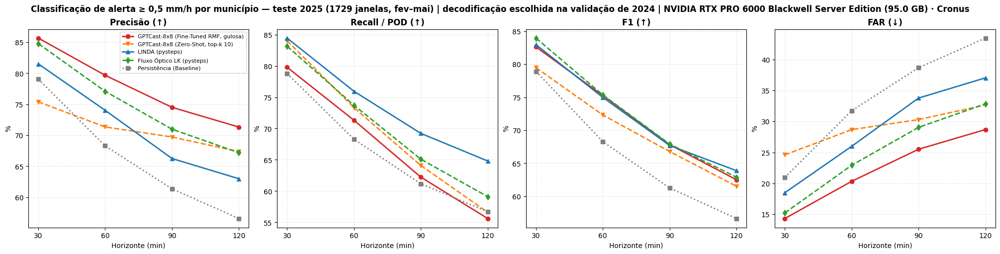

[Célula 12.1] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/fpluvia_metricas_classificacao_teste2025_G4_RTX6000_Blackwell_95GB_Cronus_VQ_N1729_amostragem2024.csv
[Célula 12.1] Painel -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/metricas_classificacao_particao_completa_1729_teste_2025_G4_RTX6000_Blackwell_95GB_Cronus_VQ_amostragem2024.png


In [ ]:
# @title
# Célula Estatísticas (Célula 12.1): Métricas de Classificação (Acurácia, Precisão, Recall/POD, F1, FAR, CSI) por Nível de
# Alerta — por pixel e por MUNICÍPIO da RMF (chuva média na área do município), no teste de 2025
# (Célula 12) e no estudo de caso, com a acurácia trivial de "nunca prever chuva" como referência.
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.path import Path as MplPath

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
ALERT_LEVELS = {0.5: 'Atenção (≥ 0,5 mm/h)', 1.0: 'Alerta (≥ 1,0 mm/h)', 5.0: 'Severo (≥ 5,0 mm/h)'}
LEADS = [30 * (s + 1) for s in range(FORECAST_STEPS)]

if 'CELL12_FULL_2025_RESULTS' not in globals():
  raise RuntimeError('Rode a Célula 12 (versão com execução real) antes desta.')
res_12 = CELL12_FULL_2025_RESULTS
obs_2025 = res_12['obs_rain']
preds_2025 = {'GPTCast-8x8 (Fine-Tuned RMF)': res_12['ft_rain'], 'GPTCast-8x8 (Zero-Shot)': res_12['zs_rain'],
              'LINDA (pysteps)': res_12['linda_rain'], 'Fluxo Óptico LK (pysteps)': res_12['lk_rain'],
              'Persistência (Baseline)': res_12['pers_rain']}
NOME_MEDIA = 'GPTCast-8x8 (Fine-Tuned RMF, média de 8)'
if 'ft_media_rain' in res_12:          # 6º método da Célula 12 (média de 8 sorteios do Fine-Tuned)
  preds_2025 = {'GPTCast-8x8 (Fine-Tuned RMF)': preds_2025['GPTCast-8x8 (Fine-Tuned RMF)'], NOME_MEDIA: res_12['ft_media_rain'],
                **{k: v for k, v in preds_2025.items() if k != 'GPTCast-8x8 (Fine-Tuned RMF)'}}
N_EVAL = int(res_12['n_sequences'])
print(f"[Célula 12.1] Amostragem do GPTCast na Célula 12: {res_12.get('amostragem_texto', 'padrão do forecast() (T=1, sem top-k)')}")
# Rótulos com a decodificação de cada GPTCast, para que tabela e figura se identifiquem sozinhas (o mesmo modelo com
# outra decodificação dá números bem diferentes). Arquivos com sufixo por execução: não sobrescrevem os anteriores.
AMOSTRAGEM_12 = res_12.get('amostragem', 'padrao')
_esc = AMOSTRAGEM_12 == 'escolhida_2024'
ROTULO = {'GPTCast-8x8 (Fine-Tuned RMF)': f"GPTCast-8x8 (Fine-Tuned RMF, {'gulosa' if _esc else 'sorteio padrão'})",
          'GPTCast-8x8 (Zero-Shot)': f"GPTCast-8x8 (Zero-Shot, {'top-k 10' if _esc else 'sorteio padrão'})"}
DECOD_TXT = ('decodificação escolhida na validação de 2024' if _esc else 'decodificação padrão do forecast() (T=1, sem top-k)')
SUF = '' if not _esc else ('_amostragem2024_media8' if 'ft_media_rain' in res_12 else '_amostragem2024')


def classification_scores(tp, fp, fn, tn) -> dict:
  """Métricas em %; NaN quando o denominador é zero (ex.: precisão sem nenhum alerta emitido)."""
  def pct(a, b):
    return 100.0 * a / b if b else np.nan
  ppv, pod = pct(tp, tp + fp), pct(tp, tp + fn)
  return {'Acurácia [%]': pct(tp + tn, tp + fp + fn + tn), 'Precisão / PPV [%]': ppv, 'Recall / POD [%]': pod,
          'F1 [%]': 2 * ppv * pod / (ppv + pod) if np.isfinite(ppv) and np.isfinite(pod) and ppv + pod else np.nan,
          'FAR [%]': pct(fp, tp + fp), 'CSI / IoU [%]': pct(tp, tp + fp + fn),
          'Acurácia trivial "nunca chove" [%]': pct(fp + tn, tp + fp + fn + tn),
          'Taxa base observada [%]': pct(tp + fn, tp + fp + fn + tn)}


def _counts(ob, pb):
  return (float(np.sum(ob & pb)), float(np.sum(~ob & pb)), float(np.sum(ob & ~pb)), float(np.sum(~ob & ~pb)))


# ------------------------------------------------ 1. máscaras dos municípios na malha de 2 km
mun_masks = {}
if globals().get('gdf_rmf') is not None:
  lon_g, lat_g = np.meshgrid(md_rmf.target_lons, md_rmf.target_lats)
  pts = np.column_stack([lon_g.ravel(), lat_g.ravel()])
  for _, r in gdf_rmf.iterrows():
    geom = r.geometry
    polys = list(geom.geoms) if geom.geom_type == 'MultiPolygon' else [geom]
    m = np.zeros(pts.shape[0], bool)
    for pg in polys:
      m |= MplPath(np.asarray(pg.exterior.coords)).contains_points(pts)
    if m.sum() >= 4:   # municípios com ao menos 4 pixels de 2 km (16 km²)
      mun_masks[r['name']] = m.reshape(lon_g.shape)
  print(f'[Célula 12.1] {len(mun_masks)} municípios da RMF com máscara na malha de 2 km.')
else:
  print('[Aviso Célula 12.1] Limites municipais indisponíveis (rode a Célula 5): só a avaliação por pixel será feita.')


def municipal_means(rain_4d):
  """(N, passos, H, W) -> (N, passos, M): chuva média na área de cada município."""
  return np.stack([rain_4d[..., m].mean(axis=-1) for m in mun_masks.values()], axis=-1)


# ---------------------------------------------------------------- 2. tabelas
rows = []
obs_mun = municipal_means(obs_2025) if mun_masks else None
for unidade in (['pixel', 'município'] if mun_masks else ['pixel']):
  o_src = obs_2025 if unidade == 'pixel' else obs_mun
  for name, P in preds_2025.items():
    p_src = P if unidade == 'pixel' else municipal_means(P)
    for thr, nivel in ALERT_LEVELS.items():
      for s, lead in enumerate(LEADS + ['todos']):
        sel = slice(None) if lead == 'todos' else s
        o_b, p_b = o_src[:, sel] >= thr, p_src[:, sel] >= thr
        rows.append({'Conjunto': f'Teste 2025 ({N_EVAL} janelas)', 'Unidade': unidade, 'Nível de alerta': nivel,
                     'Modelo': ROTULO.get(name, name), 'Lead Time': 'média +30 a +120' if lead == 'todos' else f'+{lead} min',
                     **{k: round(v, 2) for k, v in classification_scores(*_counts(o_b, p_b)).items()}})

if 'forecast8_rain' in globals():   # estudo de caso (validação), por pixel
  case = {'GPTCast-8x8 (Fine-Tuned RMF)': forecast8_rain, 'GPTCast-8x8 (Zero-Shot)': globals().get('forecast8_zeroshot_rain'),
          'LINDA (pysteps)': globals().get('linda_rain'), 'Fluxo Óptico LK (pysteps)': globals().get('lk_extrap_rain'),
          'Persistência (Baseline)': globals().get('persistence_rain')}
  for name, P in case.items():
    if P is None:
      continue
    for thr, nivel in ALERT_LEVELS.items():
      rows.append({'Conjunto': f'Estudo de caso {globals().get("data_str", "")} (validação)', 'Unidade': 'pixel',
                   'Nível de alerta': nivel, 'Modelo': name, 'Lead Time': 'média +30 a +120',
                   **{k: round(v, 2) for k, v in classification_scores(*_counts(np.asarray(ground_truth_rain) >= thr,
                                                                                  np.asarray(P) >= thr)).items()}})
df_cls = pd.DataFrame(rows)
cls_csv = os.path.join(RESULTS_ENV_DIR, f'fpluvia_metricas_classificacao_teste2025_{ENV_TAG}_N{N_EVAL}{SUF}.csv')
df_cls.to_csv(cls_csv, index=False)

resumo = df_cls[(df_cls['Lead Time'] == 'média +30 a +120') & df_cls['Conjunto'].str.startswith('Teste')]
cols = ['Unidade', 'Nível de alerta', 'Modelo', 'F1 [%]', 'CSI / IoU [%]', 'Precisão / PPV [%]', 'Recall / POD [%]',
        'FAR [%]', 'Acurácia [%]', 'Acurácia trivial "nunca chove" [%]']
print(f'=== Classificação por nível de alerta — teste 2025 ({N_EVAL} janelas), média de +30 a +120 min | {DECOD_TXT} | {ENV_LABEL} ===')
print('A acurácia por pixel fica perto de 100% até para quem nunca prevê chuva (coluna "trivial"): '
      'use F1, CSI, POD e FAR para comparar.')
with pd.option_context('display.max_rows', None):     # sem o "..." do Colab: mostra todas as linhas
  display(resumo[cols].set_index(['Unidade', 'Nível de alerta', 'Modelo']))

# ---------------------------------------------------------------- 3. painel
styles = [('GPTCast-8x8 (Fine-Tuned RMF)', '#d62728', 'o', '-'), (NOME_MEDIA, '#9467bd', 'P', '-.'),
          ('GPTCast-8x8 (Zero-Shot)', '#ff7f0e', 'v', '--'),
          ('LINDA (pysteps)', '#1f77b4', '^', '-'), ('Fluxo Óptico LK (pysteps)', '#2ca02c', 'd', '--'),
          ('Persistência (Baseline)', '#7f7f7f', 's', ':')]
unidade_plot = 'município' if mun_masks else 'pixel'
panels = [('Precisão / PPV [%]', 'Precisão (↑)'), ('Recall / POD [%]', 'Recall / POD (↑)'),
          ('F1 [%]', 'F1 (↑)'), ('FAR [%]', 'FAR (↓)')]
fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
base = df_cls[(df_cls['Conjunto'].str.startswith('Teste')) & (df_cls['Unidade'] == unidade_plot) &
              (df_cls['Nível de alerta'] == ALERT_LEVELS[0.5]) & (df_cls['Lead Time'] != 'média +30 a +120')]
for ax, (col, title) in zip(axes, panels):
  for name, color, mk, ls in styles:
    sub = base[base['Modelo'] == ROTULO.get(name, name)]
    if sub.empty:                       # método ausente (ex.: Célula 12 sem a média de 8)
      continue
    ax.plot(LEADS, sub[col].values, color=color, marker=mk, ls=ls, lw=2, label=ROTULO.get(name, name))
  ax.set_title(title, fontweight='bold')
  ax.set_xlabel('Horizonte (min)')
  ax.set_ylabel('%')
  ax.set_xticks(LEADS)
  ax.grid(True, ls=':', alpha=0.55)
axes[0].legend(fontsize=8)
fig.suptitle(f'Classificação de alerta ≥ 0,5 mm/h por {unidade_plot} — teste 2025 ({N_EVAL} janelas, fev–mai) | '
             f'{DECOD_TXT} | {ENV_LABEL}',
             fontsize=12, fontweight='bold')
png = os.path.join(RESULTS_ENV_DIR, f'metricas_classificacao_particao_completa_1729_teste_2025_{ENV_TAG}{SUF}.png')
fig.savefig(png, dpi=300, bbox_inches='tight')
plt.show()
print(f'[Célula 12.1] Tabela -> {cls_csv}\n[Célula 12.1] Painel -> {png}')



# ⚠️ Célula 13: Benchmark Comparativo de Hardware e Custo Operacional no Google Colab Pro Plus - Valores Medidos por Ambiente (`ENV_TAG`), com Comparação G4 (RTX PRO 6000 Blackwell) vs. H100 Somente Quando Ambos Forem Executados

⚠️ Pode ser pulada no fluxo de publicação quando as saídas já estiverem no Drive: o manifesto (Extra 2) e o Deploy as incluem do mesmo jeito. Para gerar ou atualizar os resultados, execute-a normalmente.

* **Fusão Automática Multi-Ambiente (`resultados_<ENV_TAG>`)**: Varre as pastas de resultados de cada ambiente no Google Drive e reúne apenas valores **medidos**: GPU e VRAM detectadas, montagem do `DataModule`, tempo e épocas do fine-tuning (do registro de treino da Célula 4), reconstrução do VQGAN em milissegundos por quadro (Célula 6) e o tempo de inferência de cada método nas 1.729 janelas de teste de 2025 (Célula 12, sempre o arquivo mais recente). Valores ausentes aparecem como **não registrado**.

* **Comparação e Aceleração (Sp) Condicionadas a Dois Ambientes**: A aceleração do fine-tuning e da inferência só é calculada quando existem resultados de pelo menos dois ambientes. Com um só ambiente (situação atual: apenas a G4), a célula informa que não há comparação entre GPUs; para incluir a H100, basta executar as Células 1 a 12 num ambiente H100.

* **Custo em Unidades de Computação (CU) do Colab**: O custo do fine-tuning e de 1.000 previsões é calculado a partir da taxa em CU por hora **informada pelo usuário** no dicionário `CU_POR_HORA`, copiada do painel *Recursos* do Colab no momento da execução, já que essas taxas podem mudar. Sem taxa informada, o custo não é estimado.

* **Tempos por Decodificação (Célula 12)**: A tabela de velocidade vem da execução mais recente da Célula 12 e mostra cada produto do GPTCast com a sua decodificação: **F-PluvIA-G** (gulosa, um único passo de geração), **F-PluvIA-C8** (média de 8 membros gerados num só lote na GPU, cerca de 4 vezes o tempo do F-PluvIA-G) e **Zero-Shot *top-k* 10**, ao lado do LINDA e do Lucas-Kanade (CPU) e da persistência. O tempo do *GPTCast ajustado, 4 passos* usado no custo de 1.000 previsões é o do F-PluvIA-G.

* **Sem Especificações Escritas à Mão**: Nenhuma característica de hardware (arquitetura, largura de banda, VRAM nominal) é digitada no código; só entram valores registrados pelas células anteriores. Especificações de fabricante, se citadas no texto do TCC, devem vir com a fonte.

=== Hardware: 1 ambiente(s) com resultados em /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km ===


Hardware_Tag,G4_RTX6000_Blackwell_95GB_Cronus
GPU (medida),NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM medida [GB],94.97
Origem do treino,20261123T0028Z
Épocas,5
Lote / precisão,16 / bf16-mixed
Fine-tuning [min] (↓),16.83
Tempo por época [s] (↓),202.0
Montagem do DataModule [s],40.228
VQGAN [ms/quadro] (↓),2.576
"GPTCast ajustado, 4 passos [s] (↓)",1.631



=== Tempo de inferência por modelo no teste de 2025 (Célula 12) ===


Amostras  \
Hardware_Tag                     Modelo                                           
G4_RTX6000_Blackwell_95GB_Cronus GPTCast-8x8 (Fine-Tuned RMF, gulosa)      1729   
                                 GPTCast-8x8 (Zero-Shot, top-k 10)         1729   
                                 LINDA (pysteps)                           1729   
                                 Fluxo Óptico LK (pysteps)                 1729   
                                 Persistência (Baseline)                   1729   

                                                                       Tempo médio 4 passos [s]  \
Hardware_Tag                     Modelo                                                           
G4_RTX6000_Blackwell_95GB_Cronus GPTCast-8x8 (Fine-Tuned RMF, gulosa)                    1.6310   
                                 GPTCast-8x8 (Zero-Shot, top-k 10)                       1.6547   
                                 LINDA (pysteps)                                         0.7439   
                                 Fluxo Óptico LK (pysteps)                               0.0314   
                                 Persistência (Baseline)                                 0.0001   

                                                                       Desvio [s]  \
Hardware_Tag                     Modelo                                             
G4_RTX6000_Blackwell_95GB_Cronus GPTCast-8x8 (Fine-Tuned RMF, gulosa)      0.0037   
                                 GPTCast-8x8 (Zero-Shot, top-k 10)         0.0036   
                                 LINDA (pysteps)                           0.4379   
                                 Fluxo Óptico LK (pysteps)                 0.0064   
                                 Persistência (Baseline)                   0.0000   

                                                                                                             Dispositivo  \
Hardware_Tag                     Modelo                                                                                    
G4_RTX6000_Blackwell_95GB_Cronus GPTCast-8x8 (Fine-Tuned RMF, gulosa)  GPU (NVIDIA RTX PRO 6000 Blackwell Server Edit...   
                                 GPTCast-8x8 (Zero-Shot, top-k 10)     GPU (NVIDIA RTX PRO 6000 Blackwell Server Edit...   
                                 LINDA (pysteps)                                                                     CPU   
                                 Fluxo Óptico LK (pysteps)                                                           CPU   
                                 Persistência (Baseline)                                                             CPU   

                                                                                                                 Arquivo  
Hardware_Tag                     Modelo                                                                                   
G4_RTX6000_Blackwell_95GB_Cronus GPTCast-8x8 (Fine-Tuned RMF, gulosa)  velocidade_inferencia_teste2025_G4_RTX6000_Bla...  
                                 GPTCast-8x8 (Zero-Shot, top-k 10)     velocidade_inferencia_teste2025_G4_RTX6000_Bla...  
                                 LINDA (pysteps)                       velocidade_inferencia_teste2025_G4_RTX6000_Bla...  
                                 Fluxo Óptico LK (pysteps)             velocidade_inferencia_teste2025_G4_RTX6000_Bla...  
                                 Persistência (Baseline)               velocidade_inferencia_teste2025_G4_RTX6000_Bla...


[Célula 13] Só há um ambiente: não existe comparação entre GPUs. Para comparar com a H100, rode as Células 1 a 12 num ambiente H100 (o ENV_TAG separa os resultados). Até lá, o artigo não deve citar a H100.


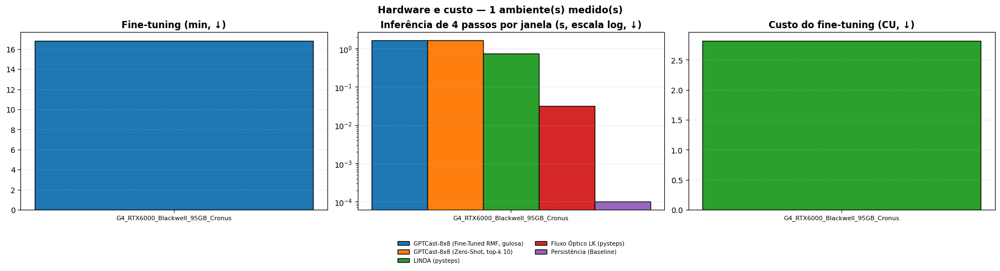

[Célula 13] Arquivos em /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/comparativo_hardware_G4_vs_H100


In [ ]:
# @title
# Célula 13: Comparativo de Hardware e Custo no Colab — somente valores MEDIDOS em cada ambiente
# (resultados_<ENV_TAG>/). Sem valores de reserva inventados; a comparação só é feita quando houver
# pelo menos dois ambientes com resultados.
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

COMPARATIVE_OUT_DIR = os.path.join(SERIES_CACHE_DIR, 'comparativo_hardware_G4_vs_H100')
os.makedirs(COMPARATIVE_OUT_DIR, exist_ok=True)

# Taxa de consumo de cada GPU em unidades de computação (CU) por hora, como aparece no painel
# "Recursos" do Colab no momento do uso. O Google pode mudar essas taxas: preencha com o que o
# painel mostrou na sua sessão. Ambiente sem taxa informada fica sem custo calculado.

CU_POR_HORA = {
    'G4_RTX6000_Blackwell_95GB': 10.05,   # painel "Recursos" do Colab; mesma taxa da V1 (o código original trazia 7,7)
    'G4_RTX6000_Blackwell_95GB_Cronus': 10.05,   # mesma GPU e mesma taxa, ambiente Cronus
    'H100_Hopper_80GB': None,
}

def _latest(folder, pattern):
  files = glob.glob(os.path.join(folder, pattern))
  return max(files, key=os.path.getmtime) if files else None


# Rótulos com a decodificação de cada GPTCast, lida do sufixo da tabela de velocidade da Célula 12.
def _rotulo(modelo, arquivo):
  esc = '_amostragem2024' in os.path.basename(arquivo or '')
  return {'GPTCast-8x8 (Fine-Tuned RMF)': f"GPTCast-8x8 (Fine-Tuned RMF, {'gulosa' if esc else 'sorteio padrão'})",
          'GPTCast-8x8 (Zero-Shot)': f"GPTCast-8x8 (Zero-Shot, {'top-k 10' if esc else 'sorteio padrão'})"}.get(modelo, modelo)


def _read_json(path):
  try:
    with open(path) as f:
      return json.load(f)
  except Exception:
    return {}


rows, speed_rows = [], []
for folder in sorted(glob.glob(os.path.join(SERIES_CACHE_DIR, 'resultados_*'))):
  tag = os.path.basename(folder).replace('resultados_', '')
  log = _read_json(_latest(folder, 'log_tempos_treino_e_inferencia_*.json') or '')
  treino = _read_json(os.path.join(CHECKPOINTS_DIR, tag, f'registro_treino_{tag}.json'))
  if not log:
    continue

  vq_ms = np.nan
  f_vq = _latest(folder, 'tabela3_estagio1_vqgan_*.csv')
  if f_vq:
    d = pd.read_csv(f_vq)
    if 'ms por Quadro (↓)' in d.columns:
      vq_ms = float(d['ms por Quadro (↓)'].iloc[-1])

  f_spd = _latest(folder, 'velocidade_inferencia_teste2025_*.csv')   # o mais recente (Célula 12)
  spd = pd.read_csv(f_spd) if f_spd else pd.DataFrame()
  for _, r in spd.iterrows():
    speed_rows.append({'Hardware_Tag': tag, 'Modelo': _rotulo(r['Modelo'], f_spd), 'Amostras': int(r['Amostras_Teste_2025']),
                       'Tempo médio 4 passos [s]': float(r['Tempo_Medio_4Passos_s']),
                       'Desvio [s]': float(r.get('Desvio_Padrao_4Passos_s', np.nan)),
                       'Dispositivo': r.get('Dispositivo', 'GPU' if 'GPTCast' in str(r['Modelo']) else 'CPU'),
                       'Arquivo': os.path.basename(f_spd)})
  t_ft_inf = next((s['Tempo médio 4 passos [s]'] for s in speed_rows
                   if s['Hardware_Tag'] == tag and 'Fine-Tuned' in s['Modelo'] and 'média' not in s['Modelo']),
                  log.get('inferencia_4passos_finetuned_s', np.nan))

  ft_s = treino.get('finetuning_tempo_total_s', log.get('finetuning_tempo_total_s'))
  ft_s = float(ft_s) if ft_s is not None else np.nan
  epocas = treino.get('epocas_executadas', log.get('epocas_executadas'))
  cu_h = CU_POR_HORA.get(tag)
  rows.append({
      'Hardware_Tag': tag,
      'GPU (medida)': log.get('gpu_utilizada', tag),
      'VRAM medida [GB]': log.get('vram_total_gb', np.nan),
      'Origem do treino': treino.get('data_treino_utc', log.get('finetuning_origem', 'não registrado')),
      'Épocas': epocas if epocas is not None else 'não registrado',
      'Lote / precisão': f"{treino.get('batch_size_treino', log.get('batch_size_treino', '?'))} / "
                         f"{treino.get('precisao_numerica', log.get('precisao_numerica', '?'))}",
      'Fine-tuning [min] (↓)': round(ft_s / 60, 2) if np.isfinite(ft_s) else np.nan,
      'Tempo por época [s] (↓)': round(ft_s / int(epocas), 1) if np.isfinite(ft_s) and isinstance(epocas, (int, float)) and epocas else np.nan,
      'Montagem do DataModule [s]': log.get('datamodule_split_setup_s', np.nan),
      'VQGAN [ms/quadro] (↓)': vq_ms,
      'GPTCast ajustado, 4 passos [s] (↓)': round(float(t_ft_inf), 4) if t_ft_inf is not None else np.nan,
      'Taxa informada [CU/h]': cu_h if cu_h is not None else 'não informada',
      'Custo do fine-tuning [CU]': round(ft_s / 3600 * cu_h, 2) if cu_h and np.isfinite(ft_s) else np.nan,
      'Custo de 1.000 previsões [CU]': round(float(t_ft_inf) * 1000 / 3600 * cu_h, 2) if cu_h and t_ft_inf else np.nan,
  })

df_hw_comp = pd.DataFrame(rows)
df_speed = pd.DataFrame(speed_rows)
df_hw_comp.to_csv(os.path.join(COMPARATIVE_OUT_DIR, 'tabela_comparativa_hardware_G4_vs_H100_2019_2025.csv'), index=False)
if len(df_speed):
  df_speed.to_csv(os.path.join(COMPARATIVE_OUT_DIR, 'comparativo_velocidade_inferencia_modelos_G4_vs_H100.csv'), index=False)

print(f'=== Hardware: {len(df_hw_comp)} ambiente(s) com resultados em {SERIES_CACHE_DIR} ===')
if len(df_hw_comp) == 0:
  print('Nenhum ambiente com log da Célula 4. Rode as Células 1 a 12 primeiro.')
else:
  display(df_hw_comp.set_index('Hardware_Tag').T)
  if len(df_speed):
    print('\n=== Tempo de inferência por modelo no teste de 2025 (Célula 12) ===')
    display(df_speed.set_index(['Hardware_Tag', 'Modelo']))

if len(df_hw_comp) < 2:
  print('\n[Célula 13] Só há um ambiente: não existe comparação entre GPUs. Para comparar com a H100, rode as '
        'Células 1 a 12 num ambiente H100 (o ENV_TAG separa os resultados). Até lá, o artigo não deve citar a H100.')
else:
  base = df_hw_comp.iloc[0]
  df_hw_comp['Aceleração do fine-tuning vs. ' + base['Hardware_Tag']] = (base['Fine-tuning [min] (↓)'] / df_hw_comp['Fine-tuning [min] (↓)']).round(2)
  df_hw_comp['Aceleração da inferência vs. ' + base['Hardware_Tag']] = (base['GPTCast ajustado, 4 passos [s] (↓)'] / df_hw_comp['GPTCast ajustado, 4 passos [s] (↓)']).round(2)
  df_hw_comp.to_csv(os.path.join(COMPARATIVE_OUT_DIR, 'tabela_comparativa_hardware_G4_vs_H100_2019_2025.csv'), index=False)
  print('\n=== Aceleração relativa ===')
  display(df_hw_comp.set_index('Hardware_Tag').iloc[:, -2:])

# ----------------------------------------------------------------------- painel
if len(df_hw_comp):
  labels = df_hw_comp['Hardware_Tag'].tolist()
  x = np.arange(len(labels))
  fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
  axes[0].bar(x, df_hw_comp['Fine-tuning [min] (↓)'], color='#1f77b4', edgecolor='k', width=0.5)
  axes[0].set_title('Fine-tuning (min, ↓)', fontweight='bold')
  if len(df_speed):
    modelos = df_speed['Modelo'].unique()
    w = 0.8 / len(modelos)
    for k, m in enumerate(modelos):
      vals = [df_speed[(df_speed['Hardware_Tag'] == t) & (df_speed['Modelo'] == m)]['Tempo médio 4 passos [s]'].mean() for t in labels]
      axes[1].bar(x - 0.4 + w * (k + 0.5), vals, width=w, label=m, edgecolor='k')
    axes[1].set_yscale('log')
    # Legenda abaixo do painel, para não cobrir as barras.
    axes[1].legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
  axes[1].set_title('Inferência de 4 passos por janela (s, escala log, ↓)', fontweight='bold')
  custos = pd.to_numeric(df_hw_comp['Custo do fine-tuning [CU]'], errors='coerce')
  axes[2].bar(x, custos, color='#2ca02c', edgecolor='k', width=0.5)
  axes[2].set_title('Custo do fine-tuning (CU, ↓)' + ('' if custos.notna().any() else ' — taxa não informada'), fontweight='bold')
  for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.grid(True, axis='y', ls=':', alpha=0.6)
  fig.suptitle(f'Hardware e custo — {len(labels)} ambiente(s) medido(s)', fontsize=12.5, fontweight='bold')
  path = os.path.join(COMPARATIVE_OUT_DIR, 'painel_benchmark_hardware_G4_vs_H100.png')
  fig.savefig(path, dpi=300, bbox_inches='tight')
  plt.show()
  print(f'[Célula 13] Arquivos em {COMPARATIVE_OUT_DIR}')


## ⚠️ Célula 13.1: Teste Cego Fora do Período (2026) - Mesma ETL do Treino, Mesmos Métodos e Mesma Decodificação da Célula 12

⚠️ Pode ser pulada no fluxo de publicação quando as saídas já estiverem no Drive: o manifesto (Extra 2) e o Deploy as incluem do mesmo jeito. Para gerar ou atualizar os resultados, execute-a normalmente.

Esta célula testa o **F-PluvIA Metropolitan (GPTCast-8x8 Fine-Tuned RMF)** em dados de **2026**, que o modelo nunca viu. O teste usa a **mesma ETL do treino**, a **mesma malha de 2 km** e o **mesmo critério de janela com chuva**. Compara os **mesmos métodos da Célula 12** (5, ou 6 com o F-PluvIA-C8), sem nenhum campo sintético.

* **Mesma decodificação da Célula 12**: o GPTCast usa a decodificação escolhida na validação de 2024 (Célula 4.5): **F-PluvIA-G** (ajuste fino com decodificação gulosa), **Zero-Shot com *top-k* 10** e, se a Célula 12 incluiu a média, **F-PluvIA-C8** (média de 8 membros amostrais). A célula segue automaticamente o que a Célula 12 usou na sessão (`AMOSTRAGEM`, `INCLUIR_MEDIA`) e avisa se as duas divergirem. O gerador é o mesmo da Célula 12, conferido como idêntico ao `forecast()` do pacote na Célula 4.5.

* **Pastas por decodificação e reaproveitamento**: as previsões ficam em `previsoes/janelas_<DIGEST>_s42` (padrão), `..._amostragem2024` e `..._amostragem2024_media8`. LINDA, Lucas-Kanade e persistência não dependem da decodificação e vêm da pasta padrão quando já calculados; com a média, o F-PluvIA-G e o Zero-Shot vêm da pasta sem média. Tabelas e figuras ganham o sufixo da execução e não sobrescrevem as anteriores.

* **Fonte de dados (acesso imediato)**: NASA PPS, pela `gpm-api`, com a mesma credencial `PPS_USERNAME` dos Segredos do Colab usada na Célula 2. Não precisa de novo cadastro.
* **Produto por período**: tenta primeiro o **IMERG Final v7** (o mesmo produto do treino). Antes de baixar, testa **um único dia** do período. Se o Final ainda não foi publicado, passa direto para o **IMERG Late v7**, sem testar dia por dia. Para o dia corrente usa o **IMERG Early v7**. O produto usado em cada mês e em cada caso aparece na saída.
* **Situação em 16/11/2026**: o IMERG Final de 2026 **ainda não está na NASA PPS**, então os 4 meses da série usam o **IMERG Late**. A célula avisa isso na saída.
* **Sem preenchimento**: se nenhum produto tiver dados suficientes, o período é **omitido**. Nada é completado com outra fonte, com modelo meteorológico ou com janelas de outros anos.
* **Série da quadra chuvosa (fev a mai/2026)**: todas as janelas de 11 quadros que passam no critério de chuva do treino, com passo de **60 min** (`stride=2`).
* **Comparação com 2025 nos mesmos meses**: as métricas de 2026 são postas ao lado das do teste de 2025 (Célula 12) **nos mesmos meses**, o que tira o efeito da estação. Enquanto 2026 usar o IMERG Late, a diferença ainda inclui a **troca de produto** (Late em 2026, Final em 2025).
* **Métricas**: MAE, RMSE, correlação, razão de volume, **CSI e BIAS** em 0,5, 1, 5 e 10 mm/h, e **POD (recall), precisão e F1** em 1 mm/h. Cada uma é dada por horizonte (+30 a +120 min) e no total.
* **Incerteza**: intervalos de confiança de 95% por **bootstrap de dias inteiros**, incluindo a diferença do GPTCast ajustado para cada outro método no CSI de 1 mm/h e no MAE.
* **Estudos de caso**:
  - **16–17/05/2026**: janela de maior chuva observada no período;
  - **10/09/2026**: janela de maior chuva observada no dia;
  - **dia corrente**: janela mais recente do IMERG Early.

  Cada caso gera um mapa com o observado e os métodos.
* **Orçamento de tempo (`TEMPO_MAX_MIN = 120`)**: cada execução calcula previsões novas por no máximo esse tempo e depois segue para as métricas.
  - As janelas são processadas em **ordem aleatória fixa**, então as que ficam prontas formam uma **amostra uniforme** da série. Um resultado parcial é válido para os 4 meses, não só para fevereiro.
  - Quando o resultado é parcial, a saída diz **"PARCIAL"** e mostra quantas janelas de quantas foram usadas. Rodar a célula de novo continua de onde parou, e a amostra cresce até completar a série.
  - `TEMPO_MAX_MIN = None` calcula tudo de uma vez.
* **Retomada**: cada janela prevista vira um arquivo no Drive em `SERIES_CACHE_DIR/teste_cego_2026/previsoes/`. Uma interrupção perde no máximo a janela em andamento. Na decodificação padrão, as previsões da execução anterior, em blocos de 50 janelas, são aproveitadas automaticamente; elas não servem às pastas da decodificação de 2024, porque foram geradas com o sorteio padrão.
* **Saída limpa**: as mensagens repetitivas da `gpm-api`, do GPTCast ("Using window size…") e do LINDA ficam escondidas. A célula mostra uma linha de progresso a cada 25 janelas, com segundos por janela e o tempo que falta. Se o LINDA falhar em alguma janela e for trocado pelo Lucas-Kanade, isso é contado e avisado no fim.

**Adendo**:
- O modelo foi treinado com o IMERG Final, que é calibrado com pluviômetros. Nos meses em que só existe o **Late** ou o **Early**, parte da queda de desempenho vem da **troca de produto**, e não do modelo.
- Os estudos de caso são **escolhidos pelo evento observado** e têm uma única janela cada. Eles ilustram o comportamento do modelo, mas não medem o desempenho.
- Com a decodificação escolhida em 2024, o **F-PluvIA-G é determinístico** (sempre o token mais provável); o **Zero-Shot *top-k* 10** e os membros do **F-PluvIA-C8** são amostras com semente fixa (`SEED + i`), reproduzíveis.

**Tempo**: a linha de progresso mostra o tempo real por janela e quanto falta. A série de fev a mai/2026 tem cerca de 2.100 janelas. `MAX_JANELAS` limita a série a uma amostra fixa, se preferir.

**Saídas** (em `RESULTS_ENV_DIR/teste_cego_2026/`; `<SUF>` é vazio na decodificação padrão, `_amostragem2024` ou `_amostragem2024_media8`):
- `teste_cego_2026_meses_e_produtos_<ENV_TAG><SUF>.csv`
- `teste_cego_2026_metricas_por_lead_<ENV_TAG><SUF>.csv`
- `teste_cego_2026_bootstrap_dias_<ENV_TAG><SUF>.csv`
- `teste_cego_2026_estudos_de_caso_<ENV_TAG><SUF>.csv`
- `painel_teste_cego_2026_vs_2025_<ENV_TAG><SUF>.png` e um mapa por estudo de caso

**Requisito**: rodar antes as **Células 2, 4, 5 e 10**. Para a comparação com 2025 e para seguir a mesma decodificação, rodar também a **Célula 12** na mesma sessão. Os arquivos da versão anterior desta célula são renomeados com o sufixo `_INVALIDO`.

[Célula 13.1] Decodificação do GPTCast: decodificação escolhida na validação de 2024 | GPTCast-8x8 (Fine-Tuned RMF, gulosa), GPTCast-8x8 (Zero-Shot, top-k 10) | previsões em janelas_242867fd02c3_s42_amostragem2024
[Célula 13.1] Série de 2026: 02/2026, 03/2026, 04/2026, 05/2026 | passo 60 min


,Produto,Quadros,Janelas
Mês,,,
02/2026,IMERG-LR v7 (NRT),1344/1344,381
03/2026,IMERG-LR v7 (NRT),1488/1488,550
04/2026,IMERG-LR v7 (NRT),1440/1440,672
05/2026,IMERG-LR v7 (NRT),1488/1488,505


[Célula 13.1] 2108 janelas de 2026 na série.
  série 2026: 0/2108 janelas já no Drive; 2108 a calcular (limite desta execução: 1000000 min).
  série 2026: 1/2108 prontas (0.0 %) | 1.7 s/janela | faltam ~1.0 h
  série 2026: 25/2108 prontas (1.2 %) | 1.7 s/janela | faltam ~1.0 h
  série 2026: 50/2108 prontas (2.4 %) | 1.7 s/janela | faltam ~0.9 h
  série 2026: 75/2108 prontas (3.6 %) | 1.6 s/janela | faltam ~0.9 h
  série 2026: 100/2108 prontas (4.7 %) | 1.6 s/janela | faltam ~0.9 h
  série 2026: 125/2108 prontas (5.9 %) | 1.6 s/janela | faltam ~0.9 h
  série 2026: 150/2108 prontas (7.1 %) | 1.6 s/janela | faltam ~0.9 h
  série 2026: 175/2108 prontas (8.3 %) | 1.6 s/janela | faltam ~0.9 h
  série 2026: 200/2108 prontas (9.5 %) | 1.6 s/janela | faltam ~0.9 h
  série 2026: 225/2108 prontas (10.7 %) | 1.6 s/janela | faltam ~0.9 h
  série 2026: 250/2108 prontas (11.9 %) | 1.6 s/janela | faltam ~0.8 h
  série 2026: 275/2108 prontas (13.0 %) | 1.6 s/janela | faltam ~0.8 h
  série 2026: 300/210

100%|██████████| 52/52 [01:25<00:00,  1.65s/it]


  dia_corrente_20261124T0100: IMERG-ER v7 — 52/61 quadros, 0 janelas com chuva (94 s)
[Célula 13.1] Dia corrente: IMERG Early sem janela com chuva nas últimas 30 h (ou indisponível); omitido.
  Estratiforme longo (16–17/05/2026): 0/1 janelas já no Drive; 1 a calcular.
  Estratiforme longo (16–17/05/2026): 1/1 prontas (100.0 %) | 1.7 s/janela | faltam ~0.0 h
[Célula 5] Painel salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/teste_cego_2026/caso_Estratiformelongo1617052026_G4_RTX6000_Blackwell_95GB_Cronus_VQ_amostragem2024.png


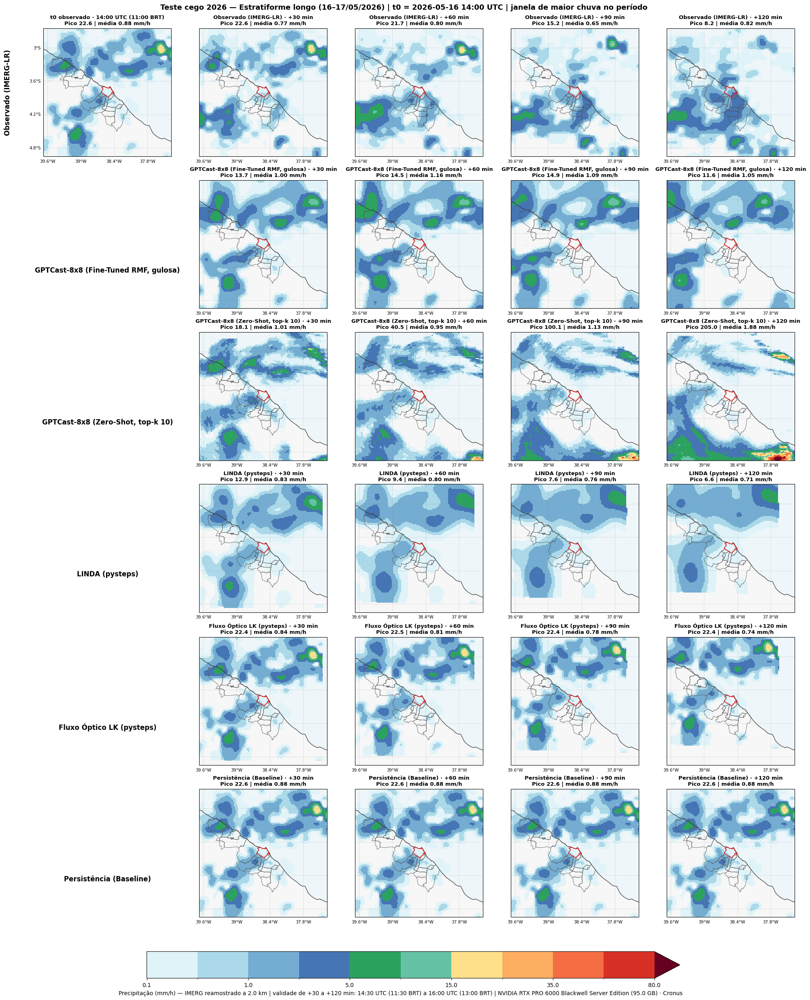

  Convectivo (10/09/2026): 0/1 janelas já no Drive; 1 a calcular.
  Convectivo (10/09/2026): 1/1 prontas (100.0 %) | 1.7 s/janela | faltam ~0.0 h
[Célula 5] Painel salvo -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/teste_cego_2026/caso_Convectivo10092026_G4_RTX6000_Blackwell_95GB_Cronus_VQ_amostragem2024.png


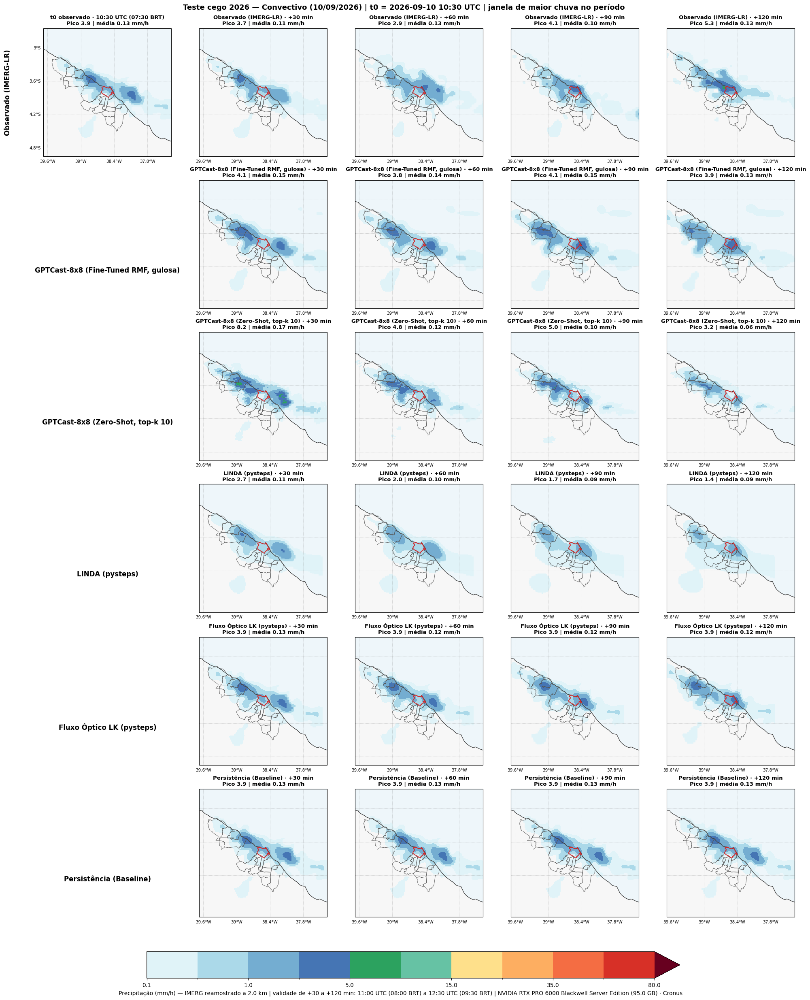


=== Teste cego 2026 (2108 de 2108 janelas, IMERG-LR) x teste 2025 (IMERG-FR) nos mesmos meses — todos os horizontes | decodificação escolhida na validação de 2024 | NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus ===


MAE [mm/h] (↓)  \
Período                                        2026   
Método                                                
GPTCast-8x8 (Fine-Tuned RMF, gulosa)          0.321   
GPTCast-8x8 (Zero-Shot, top-k 10)             0.634   
LINDA (pysteps)                               0.332   
Fluxo Óptico LK (pysteps)                     0.310   
Persistência (Baseline)                       0.347   

                                                                        \
Período                              2025 (mesmos meses, 1729 janelas)   
Método                                                                   
GPTCast-8x8 (Fine-Tuned RMF, gulosa)                             0.332   
GPTCast-8x8 (Zero-Shot, top-k 10)                                0.814   
LINDA (pysteps)                                                  0.330   
Fluxo Óptico LK (pysteps)                                        0.312   
Persistência (Baseline)                                          0.373   

                                     CSI_1.0  \
Período                                 2026   
Método                                         
GPTCast-8x8 (Fine-Tuned RMF, gulosa)   0.413   
GPTCast-8x8 (Zero-Shot, top-k 10)      0.366   
LINDA (pysteps)                        0.418   
Fluxo Óptico LK (pysteps)              0.414   
Persistência (Baseline)                0.385   

                                                                        \
Período                              2025 (mesmos meses, 1729 janelas)   
Método                                                                   
GPTCast-8x8 (Fine-Tuned RMF, gulosa)                             0.462   
GPTCast-8x8 (Zero-Shot, top-k 10)                                0.420   
LINDA (pysteps)                                                  0.487   
Fluxo Óptico LK (pysteps)                                        0.475   
Persistência (Baseline)                                          0.426   

                                     BIAS_1.0  \
Período                                  2026   
Método                                          
GPTCast-8x8 (Fine-Tuned RMF, gulosa)    0.890   
GPTCast-8x8 (Zero-Shot, top-k 10)       1.063   
LINDA (pysteps)                         1.018   
Fluxo Óptico LK (pysteps)               0.916   
Persistência (Baseline)                 1.005   

                                                                        \
Período                              2025 (mesmos meses, 1729 janelas)   
Método                                                                   
GPTCast-8x8 (Fine-Tuned RMF, gulosa)                             0.835   
GPTCast-8x8 (Zero-Shot, top-k 10)                                1.093   
LINDA (pysteps)                                                  0.969   
Fluxo Óptico LK (pysteps)                                        0.881   
Persistência (Baseline)                                          1.001   

                                     CSI_5.0  \
Período                                 2026   
Método                                         
GPTCast-8x8 (Fine-Tuned RMF, gulosa)   0.289   
GPTCast-8x8 (Zero-Shot, top-k 10)      0.177   
LINDA (pysteps)                        0.304   
Fluxo Óptico LK (pysteps)              0.295   
Persistência (Baseline)                0.254   

                                                                       F1_1.0  \
Período                              2025 (mesmos meses, 1729 janelas)   2026   
Método                                                                          
GPTCast-8x8 (Fine-Tuned RMF, gulosa)                             0.357  0.585   
GPTCast-8x8 (Zero-Shot, top-k 10)                                0.205  0.536   
LINDA (pysteps)                                                  0.387  0.590   
Fluxo Óptico LK (pysteps)                                        0.373  0.586   
Persistência (Baseline)                                          0.304  0.556   

     


=== 2026 por horizonte (CSI ≥ 1 mm/h) ===


Lead,+30 min,+60 min,+90 min,+120 min
Método,,,,
"GPTCast-8x8 (Fine-Tuned RMF, gulosa)",0.556,0.443,0.365,0.307
"GPTCast-8x8 (Zero-Shot, top-k 10)",0.488,0.392,0.328,0.265
LINDA (pysteps),0.589,0.453,0.363,0.299
Fluxo Óptico LK (pysteps),0.604,0.447,0.353,0.284
Persistência (Baseline),0.567,0.412,0.327,0.270



=== Intervalos de confiança de 95 % (bootstrap por dias, 1000 reamostragens) ===


,Dias,MAE IC95 [mm/h],CSI ≥ 1.0 IC95,ΔCSI ≥ 1.0 (FT − método) IC95,ΔMAE (FT − método) IC95,FT melhor no CSI?
Método,,,,,,
"GPTCast-8x8 (Fine-Tuned RMF, gulosa)",110,0.270 – 0.371,0.374 – 0.446,NaN,NaN,NaN
"GPTCast-8x8 (Zero-Shot, top-k 10)",110,0.497 – 0.782,0.335 – 0.392,+0.034 – +0.059,-0.423 – -0.218,sim
LINDA (pysteps),110,0.283 – 0.381,0.391 – 0.442,-0.020 – +0.008,-0.023 – +0.001,inconclusivo
Fluxo Óptico LK (pysteps),110,0.264 – 0.359,0.384 – 0.440,-0.014 – +0.009,-0.000 – +0.020,inconclusivo
Persistência (Baseline),110,0.297 – 0.400,0.351 – 0.415,+0.016 – +0.040,-0.040 – -0.015,sim



=== Estudos de caso (uma janela cada; F-PluvIA-G determinístico, Zero-Shot uma amostra top-k 10) ===


Lead                                                                     +30 min  \
Caso                               Método                                          
Estratiforme longo (16–17/05/2026) GPTCast-8x8 (Fine-Tuned RMF, gulosa)    0.466   
                                   GPTCast-8x8 (Zero-Shot, top-k 10)       0.416   
                                   LINDA (pysteps)                         0.430   
                                   Fluxo Óptico LK (pysteps)               0.428   
                                   Persistência (Baseline)                 0.361   
Convectivo (10/09/2026)            GPTCast-8x8 (Fine-Tuned RMF, gulosa)    0.615   
                                   GPTCast-8x8 (Zero-Shot, top-k 10)       0.552   
                                   LINDA (pysteps)                         0.612   
                                   Fluxo Óptico LK (pysteps)               0.620   
                                   Persistência (Baseline)                 0.422   

Lead                                                                     +60 min  \
Caso                               Método                                          
Estratiforme longo (16–17/05/2026) GPTCast-8x8 (Fine-Tuned RMF, gulosa)    0.325   
                                   GPTCast-8x8 (Zero-Shot, top-k 10)       0.289   
                                   LINDA (pysteps)                         0.259   
                                   Fluxo Óptico LK (pysteps)               0.250   
                                   Persistência (Baseline)                 0.219   
Convectivo (10/09/2026)            GPTCast-8x8 (Fine-Tuned RMF, gulosa)    0.402   
                                   GPTCast-8x8 (Zero-Shot, top-k 10)       0.434   
                                   LINDA (pysteps)                         0.403   
                                   Fluxo Óptico LK (pysteps)               0.513   
                                   Persistência (Baseline)                 0.383   

Lead                                                                     +90 min  \
Caso                               Método                                          
Estratiforme longo (16–17/05/2026) GPTCast-8x8 (Fine-Tuned RMF, gulosa)    0.182   
                                   GPTCast-8x8 (Zero-Shot, top-k 10)       0.185   
                                   LINDA (pysteps)                         0.174   
                                   Fluxo Óptico LK (pysteps)               0.158   
                                   Persistência (Baseline)                 0.145   
Convectivo (10/09/2026)            GPTCast-8x8 (Fine-Tuned RMF, gulosa)    0.214   
                                   GPTCast-8x8 (Zero-Shot, top-k 10)       0.301   
                                   LINDA (pysteps)                         0.157   
                                   Fluxo Óptico LK (pysteps)               0.287   
                                   Persistência (Baseline)                 0.311   

Lead                                                                     +120 min  
Caso                               Método                                          
Estratiforme longo (16–17/05/2026) GPTCast-8x8 (Fine-Tuned RMF, gulosa)     0.189  
                                   GPTCast-8x8 (Zero-Shot, top-k 10)        0.237  
                                   LINDA (pysteps)                          0.180  
                                   Fluxo Óptico LK (pysteps)                0.158  
                                   Persistência (Baseline)                  0.131  
Convectivo (10/09/2026)            GPTCast-8x8 (Fine-Tuned RMF, gulosa)     0.179  
                                   GPTCast-8x8 (Zero-Shot, top-k 10)        0.191  
                                   LINDA (pysteps)                          0.083  
                                   Fluxo Óptico LK (pysteps)                0.343  
                                   Persistência (

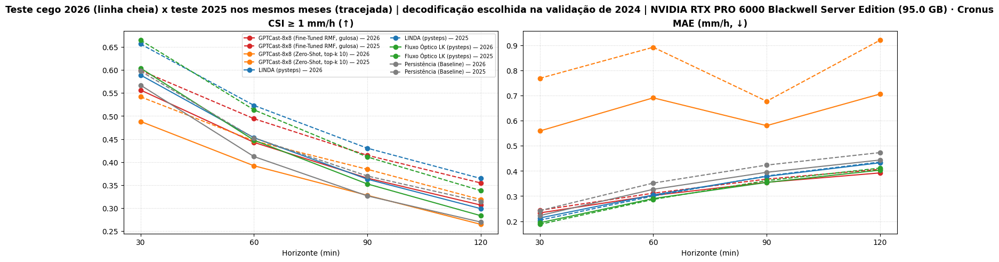

[Célula 13.1] Tabelas e figuras -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/teste_cego_2026


In [ ]:
# @title
# Célula 13.1: Teste Cego Fora do Período (2026) — mesma ETL do treino, mesmos métodos e mesma decodificação
# do GPTCast da Célula 12 (escolhida na validação de 2024: F-PluvIA-G gulosa, Zero-Shot top-k 10 e, opcional,
# F-PluvIA-C8 média de 8), série da quadra chuvosa de 2026 + estudos de caso, comparada com 2025 nos mesmos meses.
#
import calendar
import contextlib
import datetime
import einops
import glob
import hashlib
import io
import json
import math
import os
import shutil
import time
import unicodedata
import warnings

import gpm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gptcast.utils.converters import dbz_to_rainfall

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
DIR_2026 = os.path.join(SERIES_CACHE_DIR, 'teste_cego_2026')          # janelas e previsões (Drive)
OUT_DIR = os.path.join(RESULTS_ENV_DIR, 'teste_cego_2026')            # tabelas e figuras
os.makedirs(DIR_2026, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------------- 1. configuração
MESES_2026 = [(2026, m) for m in (2, 3, 4, 5)]          # quadra chuvosa de 2026
CASOS_2026 = {                                           # estudos de caso (janela de maior chuva no período)
    'Estratiforme longo (16–17/05/2026)': ('2026-05-16 00:00', '2026-05-17 23:59'),
    'Convectivo (10/09/2026)': ('2026-09-10 00:00', '2026-09-10 23:59'),
}
INCLUIR_DIA_CORRENTE = True                              # janela mais recente do IMERG Early
PRODUTOS_ARQUIVO = [('IMERG-FR', 'RS'), ('IMERG-LR', 'NRT')]   # Final primeiro; Late se o Final ainda não saiu
PRODUTOS_DIA_CORRENTE = [('IMERG-ER', 'NRT')]
COBERTURA_MIN = 0.90                                     # fração mínima de quadros de 30 min no período
STRIDE = int(globals().get('STRIDE_JANELAS', 2))         # mesmo passo do treino (60 min)
SEED = int(globals().get('SEED', 42))
TEMPO_MAX_MIN = int(globals().get('CRONUS_TEMPO_MAX_MIN', 120))                                     # orçamento desta execução para previsões novas (min)
                                                         # as janelas são processadas em ordem aleatória fixa:
                                                         # o que estiver pronto é uma amostra uniforme da série
MAX_JANELAS = None                                       # None = todas; um número = limita a série a uma amostra
THRESHOLDS = (0.5, 1.0, 5.0, 10.0)
N_BOOT = 1000
STEP_MIN = 30

# Decodificação do GPTCast: a MESMA da Célula 12, para que 2026 e 2025 sejam comparáveis. Por padrão segue o que a
# Célula 12 usou nesta sessão; sem ela, usa a escolhida na validação de 2024 (Célula 4.5).
_R12 = globals().get('CELL12_FULL_2025_RESULTS') or {}
AMOSTRAGEM = _R12.get('amostragem', 'escolhida_2024')      # 'escolhida_2024' ou 'padrao' (forecast() do pacote)
INCLUIR_MEDIA = 'ft_media_rain' in _R12                    # F-PluvIA-C8: cerca de 3x o tempo por janela
AMOSTRAGENS = {
    'padrao': {'ft': (1.0, None, 1), 'zs': (1.0, None, 1)},
    'escolhida_2024': {'ft': (1.0, 1, 1), 'zs': (1.0, 10, 1), 'ft_media': (1.0, None, 8)},
}
CFG = {k: v for k, v in AMOSTRAGENS[AMOSTRAGEM].items() if k != 'ft_media' or INCLUIR_MEDIA}
_esc = AMOSTRAGEM == 'escolhida_2024'
NOMES = {'ft': f"GPTCast-8x8 (Fine-Tuned RMF, {'gulosa' if _esc else 'sorteio padrão'})",
         'zs': f"GPTCast-8x8 (Zero-Shot, {'top-k 10' if _esc else 'sorteio padrão'})", 'linda': 'LINDA (pysteps)',
         'lk': 'Fluxo Óptico LK (pysteps)', 'pers': 'Persistência (Baseline)'}
if 'ft_media' in CFG:
  NOMES = {'ft': NOMES['ft'], 'ft_media': 'GPTCast-8x8 (Fine-Tuned RMF, média de 8)', **{k: v for k, v in NOMES.items() if k != 'ft'}}
SUF = '' if not _esc else ('_amostragem2024_media8' if 'ft_media' in CFG else '_amostragem2024')
DECOD_TXT = ('decodificação escolhida na validação de 2024' if _esc else 'decodificação padrão do forecast()')

faltam = [n for n in ('adaptee', 'gpt8', 'gpt8_zeroshot', 'PyStepsNowcastAdapter', 'plot_rmf_comparison',
                      'CONTEXT_STEPS', 'FORECAST_STEPS', 'GRID_SIZE') if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes as Células 2, 4, 5 e 10. Faltam: {", ".join(faltam)}')

# A versão anterior desta célula gravava como "dados reais" campos montados com a API Open-Meteo
# (modelo, não observação) e janelas de 2019–2025 rotuladas como 2026. Esses arquivos são renomeados.
antigos = [p for p in glob.glob(os.path.join(SERIES_CACHE_DIR, 'imerg_rt_2026', '*.np[yz]'))
           + glob.glob(os.path.join(SERIES_CACHE_DIR, 'rmf_imerg_rt_2026_2km_operational_cases.npz'))
           if '_INVALIDO' not in p]
for p in antigos:
  base, ext = os.path.splitext(p)
  os.rename(p, f'{base}_INVALIDO_versao_anterior{ext}')
if antigos:
  print(f'[Célula 13.1] {len(antigos)} arquivo(s) da versão anterior renomeado(s) com o sufixo _INVALIDO.')


# ------------------------------------------------- 2. ETL de 2026 (a mesma do treino)
def _rain(dbz):
  return np.clip(dbz_to_rainfall(np.clip(np.asarray(dbz, dtype=np.float64), 0.0, 60.0)), 0.0, 205.0).astype(np.float32)


GRADE = {'lat0': round(float(adaptee.target_lats[0]), 4), 'lon0': round(float(adaptee.target_lons[0]), 4),
         'n': int(adaptee.grid_size), 'res_km': float(adaptee.res_km), 'seq_len': int(adaptee.seq_len),
         'wet_mean': adaptee.wet_mean_thr, 'wet_max': adaptee.wet_max_thr}


@contextlib.contextmanager
def _silencio():
  """Esconde as mensagens repetitivas de bibliotecas (stdout e avisos); erros continuam aparecendo."""
  buf = io.StringIO()
  with warnings.catch_warnings(), contextlib.redirect_stdout(buf):
    warnings.simplefilter('ignore')
    yield buf


def _limpar_brutos():
  shutil.rmtree(adaptee.raw_temp_dir, ignore_errors=True)
  os.makedirs(adaptee.raw_temp_dir, exist_ok=True)


_DISPONIVEL = {}


def produto_disponivel(prod, ptype, inicio, fim) -> bool:
  """Testa um único dia (o do meio do período) antes de baixar o período inteiro."""
  meio = inicio + (fim - inicio) / 2
  dia0 = datetime.datetime(meio.year, meio.month, meio.day)
  chave = (prod, ptype, dia0.strftime('%Y-%m'))
  if chave not in _DISPONIVEL:
    try:
      with _silencio():
        gpm.download(product=prod, product_type=ptype, version=7, start_time=dia0,
                     end_time=dia0 + datetime.timedelta(hours=2), progress_bar=False, verbose=False)
        ds = gpm.open_dataset(product=prod, product_type=ptype, version=7, start_time=dia0,
                              end_time=dia0 + datetime.timedelta(hours=2), variables=['precipitation'])
        ds.close()
      _DISPONIVEL[chave] = True
    except Exception:
      _DISPONIVEL[chave] = False
    finally:
      _limpar_brutos()
  return _DISPONIVEL[chave]


def janelas_periodo(tag, inicio, fim, stride, produtos, cobertura_min):
  """Baixa o período na NASA PPS, recorta, interpola a 2 km e extrai as janelas de 11 quadros com o
  mesmo critério de chuva do treino (métodos do adaptee da Célula 2). Usa o primeiro produto disponível.
  Devolve (janelas em dBZ, horário do último quadro, metadados) ou None. Nunca preenche com outro dado."""
  cache = os.path.join(DIR_2026, f'{tag}_s{stride}.npz')
  if os.path.exists(cache):
    with np.load(cache) as z:
      meta = json.loads(str(z['meta']))
      if meta.get('grade') == GRADE:
        return z['seqs_dbz'].astype(np.float32), z['ts_fim'].astype('datetime64[m]'), meta
  adaptee._ensure_gpm_configured()
  esperados = int((fim - inicio).total_seconds() // (STEP_MIN * 60)) + 1
  for prod, ptype in produtos:
    if not produto_disponivel(prod, ptype, inicio, fim):
      print(f'  {tag}: {prod} ainda não publicado na NASA PPS para este período.')
      continue
    t0 = time.perf_counter()
    try:
      with _silencio():
        gpm.download(product=prod, product_type=ptype, version=7, start_time=inicio, end_time=fim,
                     force_download=False, n_threads=4, verbose=False)
        ds = gpm.open_dataset(product=prod, product_type=ptype, version=7, start_time=inicio, end_time=fim,
                              variables=['precipitation'])
        try:
          crop = ds.gpm.crop(extent=adaptee.raw_extent).load()
        finally:
          ds.close()
    except Exception as e:
      print(f'  {tag}: {prod} ({ptype}) falhou — {type(e).__name__}: {str(e)[:150]}')
      continue
    finally:
      _limpar_brutos()
    n = int(crop.sizes.get('time', 0))
    if n < max(cobertura_min * esperados, adaptee.seq_len):
      print(f'  {tag}: {prod} com {n} de {esperados} quadros (abaixo do mínimo); tentando o próximo produto.')
      continue
    da2, metodo, nan_frac = adaptee._interpolate_to_high_res_grid(crop)
    seqs, ts = adaptee._extract_valid_sequences(da2, stride=stride)
    meta = {'produto': prod, 'tipo': ptype, 'versao': 7, 'quadros_obtidos': n, 'quadros_esperados': esperados,
            'fracao_nan': round(nan_frac, 6), 'interp': metodo, 'stride': stride, 'grade': GRADE,
            'tempo_s': round(time.perf_counter() - t0, 1),
            'processado_utc': datetime.datetime.now(datetime.timezone.utc).strftime('%Y-%m-%d %H:%M')}
    np.savez_compressed(cache, seqs_dbz=seqs.astype(np.float16), ts_fim=ts.astype('datetime64[m]'),
                        meta=np.array(json.dumps(meta)))
    print(f'  {tag}: {prod} v7 — {n}/{esperados} quadros, {len(seqs)} janelas com chuva '
          f'({time.perf_counter() - t0:.0f} s)')
    return seqs.astype(np.float32), ts.astype('datetime64[m]'), meta
  return None


# --------------------------------------------- 3. previsões dos 5 métodos (retomáveis)
def _digest(model) -> str:
  h = hashlib.sha256()
  for k, v in sorted(model.state_dict().items()):
    if k.startswith('transformer.'):
      h.update(k.encode())
      h.update(v.detach().float().cpu().numpy().tobytes())
  return h.hexdigest()[:12]


def _sync() -> float:
  if torch.cuda.is_available():
    torch.cuda.synchronize()
  return time.perf_counter()


# Mesmo gerador da Célula 12 (reproduz o predict_sequence() do pacote, conferido como idêntico ao forecast() na
# Célula 4.5), com temperatura e top-k expostos e vários sorteios num só lote na GPU.
WS = int(math.sqrt(gpt8.transformer.config.block_size // 8))
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'


@contextlib.contextmanager
def _lote(model, n):
  if n == 1:
    yield
    return
  original = model.predict_next_index
  model.predict_next_index = lambda contexto, temperature=1.0, top_k=None: original(contexto, temperature, top_k)[:, 0]
  try:
    yield
  finally:
    del model.predict_next_index


@torch.inference_mode()
def _gptcast(model, ctx_dbz, seed, cfg=(1.0, None, 1)):
  temperatura, top_k, n = cfg
  torch.manual_seed(seed)
  np.random.seed(seed)
  x = torch.tensor(np.clip(np.nan_to_num(ctx_dbz, nan=0.0), 0, 60) / 30.0 - 1.0, dtype=torch.float32, device=DEV)
  s = x.shape[0]
  xs = einops.rearrange(x, 's h w -> (s h) w')[None, None].contiguous()
  quant, idx = model.encode_to_z(xs)
  _, c_idx = model.encode_to_c(xs)
  qs = quant.shape
  ind = idx.reshape(qs[0], s, qs[2] // s, qs[3]).repeat(n, 1, 1, 1)
  c_idx = c_idx.repeat(n, 1)
  ih, iw = ind.shape[2], ind.shape[3]
  quadros = []
  for _ in range(FORECAST_STEPS):
    with torch.autocast('cuda', dtype=torch.bfloat16, enabled=DEV == 'cuda'), _lote(model, n):
      p = model.predict_next_frame_indices(ind[:, -s:], c_idx, WS, temperature=temperatura, top_k=top_k,
                                           show_progress=False)
    quadros.append(model.decode_to_img(p.reshape(n, -1), torch.Size([n, qs[1], ih, iw])))
    ind = torch.cat((ind, p[:, None]), dim=1)
  y = torch.cat(quadros, dim=1).float().cpu().numpy().clip(-1, 1)
  r = _rain((y + 1.0) * 30.0)
  return r.mean(axis=0) if n > 1 else r[0]


DIGEST = _digest(gpt8)
_pys = PyStepsNowcastAdapter('LK')


# Uma pasta por decodificação (as previsões do GPTCast mudam com ela). LINDA, LK e persistência não dependem da
# decodificação e vêm da pasta padrão quando já existem lá; com a média, o guloso e o top-k 10 vêm da pasta sem média.
_BASE = os.path.join(DIR_2026, 'previsoes', f'janelas_{DIGEST}_s{SEED}')
_PASTA_A = _BASE + '_amostragem2024'
PASTA_PREV = _BASE if not _esc else (_PASTA_A + '_media8' if 'ft_media' in CFG else _PASTA_A)
REUSO = [] if not _esc else [(_BASE, ('linda', 'lk', 'pers'))] + ([(_PASTA_A, ('ft', 'zs'))] if 'ft_media' in CFG else [])
REUSO = REUSO + list(globals().get('CRONUS_REUSO_13_1') or [])   # Cronus: métodos da V1 que não mudam com a VQGAN
os.makedirs(PASTA_PREV, exist_ok=True)


def _arq(prod, ts_fim, pasta=None):
  return os.path.join(pasta or PASTA_PREV, f"{prod}_{np.datetime_as_string(ts_fim, unit='m').replace('-', '').replace(':', '')}.npz")


def _reaproveitar(prod, ts_fim):
  """Previsões e tempos já calculados em outras pastas para esta janela (métodos que não mudam aqui)."""
  out = {}
  for pasta, ks in REUSO:
    f = _arq(prod, ts_fim, pasta)
    if os.path.exists(f):
      with np.load(f) as z:
        if all(f'pred_{k}' in z.files for k in ks):
          out.update({k: (z[f'pred_{k}'].astype(np.float32), float(z[f'tempo_{k}']), bool(z['linda_ok'])) for k in ks})
  return out


def _uma_janela(seq_dbz, seed, reuso=None):
  """Os métodos numa janela, cronometrados, sem as mensagens do GPTCast e do LINDA; reaproveita o que já existe."""
  P, T, reuso = {}, {}, reuso or {}
  linda_ok = True
  for k, (pv, tv, ok) in reuso.items():
    P[k], T[k] = pv, tv
    if k == 'linda':
      linda_ok = ok
  ctx = np.clip(seq_dbz[:CONTEXT_STEPS].astype(np.float32), 0.0, 60.0)
  with _silencio():
    for k, model, sem in (('ft', gpt8, 0), ('zs', gpt8_zeroshot, 0), ('ft_media', gpt8, 100_000)):
      if k in CFG and k not in reuso:
        t = _sync(); P[k] = _gptcast(model, ctx, seed + sem, CFG[k]); T[k] = _sync() - t
    if 'linda' not in reuso:
      ctx_r = _rain(ctx)
      t = time.perf_counter(); vel = _pys.compute_motion_field(ctx); t_of = time.perf_counter() - t
      t = time.perf_counter(); P['lk'] = _pys.forecast_extrapolation_lk(ctx_r[-1], vel, FORECAST_STEPS); T['lk'] = t_of + time.perf_counter() - t
      t = time.perf_counter(); P['linda'] = _pys.forecast_linda(ctx_r, vel, FORECAST_STEPS); T['linda'] = t_of + time.perf_counter() - t
      t = time.perf_counter(); P['pers'] = np.repeat(ctx_r[-1:], FORECAST_STEPS, axis=0); T['pers'] = time.perf_counter() - t
      linda_ok = not str(getattr(_pys, 'linda_status', '')).startswith('FALHOU')
  return P, T, linda_ok


def prever(seqs_dbz, ts_fim, prods, seeds, rotulo, tempo_max_min=None):
  """Roda os 5 métodos nas janelas que ainda não têm previsão no Drive (um arquivo por janela), em ordem
  aleatória fixa, até acabar ou até o orçamento de tempo. Devolve previsões e máscara das prontas."""
  n = len(seqs_dbz)
  feitos = np.array([os.path.exists(_arq(prods[i], ts_fim[i])) for i in range(n)])
  ordem = [i for i in np.random.default_rng(SEED).permutation(n) if not feitos[i]]
  if ordem:
    print(f'  {rotulo}: {int(feitos.sum())}/{n} janelas já no Drive; {len(ordem)} a calcular'
          + (f' (limite desta execução: {tempo_max_min} min)' if tempo_max_min else '') + '.')
  t_ini, tempos, falhas_linda = time.perf_counter(), [], 0
  for k, i in enumerate(ordem, 1):
    t_j = time.perf_counter()
    P, T, ok = _uma_janela(seqs_dbz[i], int(seeds[i]), _reaproveitar(prods[i], ts_fim[i]))
    falhas_linda += (not ok)
    tmp = _arq(prods[i], ts_fim[i]).replace('.npz', '.tmp.npz')
    np.savez_compressed(tmp, seed=int(seeds[i]), linda_ok=ok,
                        **{f'pred_{m}': v.astype(np.float16) for m, v in P.items()},
                        **{f'tempo_{m}': v for m, v in T.items()})
    os.replace(tmp, _arq(prods[i], ts_fim[i]))
    feitos[i] = True
    tempos.append(time.perf_counter() - t_j)
    gasto = (time.perf_counter() - t_ini) / 60
    if k == 1 or k % 25 == 0 or k == len(ordem):
      resto = (len(ordem) - k) * np.mean(tempos[-50:]) / 3600
      print(f'  {rotulo}: {int(feitos.sum())}/{n} prontas ({100 * feitos.mean():.1f} %) | '
            f'{np.mean(tempos[-50:]):.1f} s/janela | faltam ~{resto:.1f} h', flush=True)
    if tempo_max_min and gasto >= tempo_max_min and k < len(ordem):
      print(f'  {rotulo}: limite de {tempo_max_min} min atingido. Rode a célula de novo para continuar; '
            f'as métricas abaixo usam as {int(feitos.sum())} janelas prontas (amostra aleatória da série).')
      break
  if falhas_linda:
    print(f'  [aviso] LINDA falhou em {falhas_linda} janela(s) e foi trocado pelo Lucas-Kanade nelas.')
  idx = np.flatnonzero(feitos)
  pred = {m: np.empty((len(idx), FORECAST_STEPS, GRID_SIZE, GRID_SIZE), np.float32) for m in NOMES}
  tempo = {m: np.empty(len(idx)) for m in NOMES}
  for j, i in enumerate(idx):
    with np.load(_arq(prods[i], ts_fim[i])) as z:
      for m in NOMES:
        pred[m][j] = z[f'pred_{m}'].astype(np.float32)
        tempo[m][j] = float(z[f'tempo_{m}'])
  return pred, tempo, feitos


def migrar_blocos_antigos(seqs_dbz, ts_fim, prods):
  """Aproveita as previsões da execução anterior (blocos de 50 janelas, mesma ordem da série completa)."""
  n, novos = len(seqs_dbz), 0
  if _esc:          # os blocos antigos foram gerados com o sorteio padrão: só servem à pasta padrão
    return
  for pasta in glob.glob(os.path.join(DIR_2026, 'previsoes', f'serie_*_{DIGEST}_n{n}_s{SEED}')):
    for f in sorted(glob.glob(os.path.join(pasta, 'bloco_*.npz'))):
      if f.endswith('.tmp.npz'):
        continue
      with np.load(f) as z:
        for j, i in enumerate(z['idx']):
          dst = _arq(prods[i], ts_fim[i])
          if not os.path.exists(dst):
            np.savez_compressed(dst, seed=SEED + int(i), linda_ok=True,
                                **{f'pred_{m}': z[f'pred_{m}'][j] for m in NOMES},
                                **{f'tempo_{m}': z[f'tempo_{m}'][j] for m in NOMES})
            novos += 1
  if novos:
    print(f'[Célula 13.1] {novos} previsões da execução anterior aproveitadas.')


# ---------------------------------------------------------------------- 4. métricas
def metricas(o, p):
  """o, p: (N, passos, H, W) em mm/h. Uma linha por horizonte e uma com todos."""
  rows = []
  for l in list(range(o.shape[1])) + [None]:
    oo = (o if l is None else o[:, l]).astype(np.float64)
    pp = (p if l is None else p[:, l]).astype(np.float64)
    d = pp - oo
    r = {'Lead': 'todos' if l is None else f'+{STEP_MIN * (l + 1)} min',
         'MAE [mm/h] (↓)': float(np.mean(np.abs(d))), 'RMSE [mm/h] (↓)': float(np.sqrt(np.mean(d ** 2))),
         'Volume Prev/Obs (=1)': float(pp.sum() / oo.sum()) if oo.sum() > 0 else np.nan}
    so, sp = oo.std(), pp.std()
    r['Correlação (↑)'] = float(np.mean((oo - oo.mean()) * (pp - pp.mean())) / (so * sp)) if so > 0 and sp > 0 else np.nan
    for thr in THRESHOLDS:
      ob, pb = oo >= thr, pp >= thr
      tp, fp, fn = float(np.sum(ob & pb)), float(np.sum(~ob & pb)), float(np.sum(ob & ~pb))
      r[f'CSI_{thr}'] = tp / (tp + fp + fn) if tp + fp + fn else np.nan
      r[f'BIAS_{thr}'] = (tp + fp) / (tp + fn) if tp + fn else np.nan
      if thr == 1.0:
        r['POD_1.0 (recall)'] = tp / (tp + fn) if tp + fn else np.nan
        r['Precisão_1.0'] = tp / (tp + fp) if tp + fp else np.nan
        r['F1_1.0'] = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else np.nan
    rows.append(r)
  return rows


def bootstrap_dias(o, preds, ts_t0, thr=1.0):
  """IC de 95 % por reamostragem de dias inteiros (as janelas do mesmo dia são correlacionadas)."""
  dias = pd.to_datetime(ts_t0).normalize().values
  ud, inv = np.unique(dias, return_inverse=True)
  por = {}
  for k, p in preds.items():
    ae = np.abs(p - o).reshape(len(o), -1).sum(1)
    ob, pb = o >= thr, p >= thr
    por[k] = np.stack([np.bincount(inv, ae, len(ud)),
                       np.bincount(inv, (ob & pb).reshape(len(o), -1).sum(1), len(ud)),
                       np.bincount(inv, (~ob & pb).reshape(len(o), -1).sum(1), len(ud)),
                       np.bincount(inv, (ob & ~pb).reshape(len(o), -1).sum(1), len(ud))])
  npx = np.bincount(inv, minlength=len(ud)) * o[0].size
  rng = np.random.default_rng(SEED)
  amostras = rng.integers(0, len(ud), (N_BOOT, len(ud)))
  out, est = [], {}
  for k, a in por.items():
    s = a[:, amostras].sum(-1)
    mae = s[0] / npx[amostras].sum(-1)
    csi = s[1] / np.maximum(s[1] + s[2] + s[3], 1)
    est[k] = (mae, csi)
  for k in por:
    mae, csi = est[k]
    linha = {'Método': NOMES[k], 'Dias': len(ud),
             'MAE IC95 [mm/h]': f'{np.percentile(mae, 2.5):.3f} – {np.percentile(mae, 97.5):.3f}',
             f'CSI ≥ {thr} IC95': f'{np.percentile(csi, 2.5):.3f} – {np.percentile(csi, 97.5):.3f}'}
    if k != 'ft':
      dcsi = est['ft'][1] - csi
      dmae = est['ft'][0] - mae
      linha[f'ΔCSI ≥ {thr} (FT − método) IC95'] = f'{np.percentile(dcsi, 2.5):+.3f} – {np.percentile(dcsi, 97.5):+.3f}'
      linha['ΔMAE (FT − método) IC95'] = f'{np.percentile(dmae, 2.5):+.3f} – {np.percentile(dmae, 97.5):+.3f}'
      linha['FT melhor no CSI?'] = 'sim' if np.percentile(dcsi, 2.5) > 0 else ('não' if np.percentile(dcsi, 97.5) < 0 else 'inconclusivo')
    out.append(linha)
  return pd.DataFrame(out)


# --------------------------------------------- 5. série da quadra chuvosa de 2026
print(f'[Célula 13.1] Decodificação do GPTCast: {DECOD_TXT} | ' + ', '.join(f'{NOMES[k]}' for k in CFG)
      + f' | previsões em {os.path.basename(PASTA_PREV)}')
print(f'[Célula 13.1] Série de 2026: {", ".join(f"{m:02d}/{y}" for y, m in MESES_2026)} | passo {STRIDE * STEP_MIN} min')
partes, info = [], []
for y, m in MESES_2026:
  ini = datetime.datetime(y, m, 1)
  fim = datetime.datetime(y, m, calendar.monthrange(y, m)[1], 23, 59)
  r = janelas_periodo(f'RMF_{y}_{m:02d}', ini, fim, STRIDE, PRODUTOS_ARQUIVO, COBERTURA_MIN)
  if r is None:
    info.append({'Mês': f'{m:02d}/{y}', 'Produto': 'sem dados disponíveis', 'Quadros': 0, 'Janelas': 0})
    continue
  s, t, meta = r
  partes.append((s, t, meta['produto']))
  info.append({'Mês': f'{m:02d}/{y}', 'Produto': f"{meta['produto']} v7 ({meta['tipo']})",
               'Quadros': f"{meta['quadros_obtidos']}/{meta['quadros_esperados']}", 'Janelas': len(s)})
df_meses = pd.DataFrame(info)
display(df_meses.set_index('Mês'))
if not partes:
  raise RuntimeError('Nenhum mês de 2026 disponível na NASA PPS para os produtos configurados.')

seqs26 = np.concatenate([p[0] for p in partes])
ts26_fim = np.concatenate([p[1] for p in partes])
prod26 = np.concatenate([[p[2]] * len(p[0]) for p in partes])
seeds26 = SEED + np.arange(len(seqs26))                  # semente fixa por janela da série completa
migrar_blocos_antigos(seqs26, ts26_fim, prod26)
if MAX_JANELAS and len(seqs26) > MAX_JANELAS:
  sel = np.unique(np.linspace(0, len(seqs26) - 1, MAX_JANELAS).astype(int))
  seqs26, ts26_fim, prod26, seeds26 = seqs26[sel], ts26_fim[sel], prod26[sel], seeds26[sel]
print(f'[Célula 13.1] {len(seqs26)} janelas de 2026 na série.')

pred26, tempo26, prontas = prever(seqs26, ts26_fim, prod26, seeds26, 'série 2026', TEMPO_MAX_MIN)
seqs26, ts26_fim, prod26 = seqs26[prontas], ts26_fim[prontas], prod26[prontas]
ts26_t0 = ts26_fim - np.timedelta64(STEP_MIN * FORECAST_STEPS, 'm')
N26, N26_TOTAL = int(prontas.sum()), len(prontas)
if N26 == 0:
  raise RuntimeError('Nenhuma janela de 2026 com previsão pronta. Aumente TEMPO_MAX_MIN e rode de novo.')
obs26 = _rain(seqs26[:, CONTEXT_STEPS:])
PARCIAL = N26 < N26_TOTAL
if PARCIAL:
  print(f'[Célula 13.1] Resultados PARCIAIS: {N26} de {N26_TOTAL} janelas ({100 * N26 / N26_TOTAL:.0f} %), '
        'sorteadas ao acaso na série. Rode a célula de novo para completar.')
if set(prod26) != {'IMERG-FR'}:
  print(f'[Célula 13.1] Atenção: 2026 usa {", ".join(sorted(set(prod26)))}, e o modelo foi treinado com o IMERG-FR '
        '(Final, calibrado com pluviômetros). A comparação com 2025 mistura o efeito do ano com o da troca de produto.')

rows = []
for k, nome in NOMES.items():
  for r in metricas(obs26, pred26[k]):
    rows.append({'Método': nome, 'Período': '2026', **r})
df26 = pd.DataFrame(rows)

# Mesmos meses do teste de 2025 (Célula 12), para separar o efeito do ano do efeito da estação.
meses_alvo = {m for _, m in MESES_2026}
if 'CELL12_FULL_2025_RESULTS' in globals():
  R12 = CELL12_FULL_2025_RESULTS
  ts25 = pd.to_datetime(np.asarray(R12['timestamps_t0']))
  m25 = np.isin(ts25.month, list(meses_alvo))
  if R12.get('amostragem', 'padrao') != AMOSTRAGEM:
    print(f"[Aviso Célula 13.1] A Célula 12 desta sessão usou a decodificação '{R12.get('amostragem', 'padrao')}' e esta "
          f"célula usa '{AMOSTRAGEM}': a comparação com 2025 mistura decodificações diferentes.")
  for k, nome in NOMES.items():
    if f'{k}_rain' not in R12:
      continue
    for r in metricas(R12['obs_rain'][m25], R12[f'{k}_rain'][m25]):
      rows.append({'Método': nome, 'Período': f'2025 (mesmos meses, {int(m25.sum())} janelas)', **r})
  df26 = pd.DataFrame(rows)
else:
  print('[Célula 13.1] CELL12_FULL_2025_RESULTS ausente: sem comparação com 2025 (rode a Célula 12).')

df_boot = bootstrap_dias(obs26, pred26, ts26_t0)

# ------------------------------------------------------------------- 6. estudos de caso
casos = {}
for nome_caso, (a, b) in CASOS_2026.items():
  ini, fim = pd.Timestamp(a).to_pydatetime(), pd.Timestamp(b).to_pydatetime()
  tag = 'caso_' + ini.strftime('%Y%m%d') + '_' + fim.strftime('%Y%m%d')
  r = janelas_periodo(tag, ini, fim, 1, PRODUTOS_ARQUIVO, COBERTURA_MIN)
  if r is None or len(r[0]) == 0:
    print(f'[Célula 13.1] {nome_caso}: sem dados ou sem janela com chuva pelo critério do treino; caso omitido.')
    continue
  s, t, meta = r
  i = int(np.argmax(_rain(s).sum(axis=(1, 2, 3))))      # janela de maior chuva observada (11 quadros)
  casos[nome_caso] = (s[i:i + 1], t[i], meta['produto'], 'janela de maior chuva no período')

if INCLUIR_DIA_CORRENTE:
  agora = datetime.datetime.now(datetime.timezone.utc).replace(tzinfo=None, second=0, microsecond=0)
  agora = agora.replace(minute=30 if agora.minute >= 30 else 0)
  ini = agora - datetime.timedelta(hours=30)
  r = janelas_periodo('dia_corrente_' + agora.strftime('%Y%m%dT%H%M'), ini, agora, 1, PRODUTOS_DIA_CORRENTE, 0.0)
  if r is None or len(r[0]) == 0:
    print('[Célula 13.1] Dia corrente: IMERG Early sem janela com chuva nas últimas 30 h (ou indisponível); omitido.')
  else:
    s, t, meta = r
    agora_brt = agora - datetime.timedelta(hours=3)
    casos[f'Dia corrente ({agora_brt:%d/%m/%Y}, horário de Brasília)'] = (s[-1:], t[-1], meta['produto'], 'janela mais recente disponível')

rows_casos = []
for nome_caso, (s, t_fim, prod, criterio) in casos.items():
  p, _, _ = prever(s, np.array([t_fim]), np.array([prod]), np.array([SEED]), nome_caso)
  o = _rain(s[:, CONTEXT_STEPS:])
  for k, nome in NOMES.items():
    for r in metricas(o, p[k]):
      if r['Lead'] != 'todos':
        rows_casos.append({'Caso': nome_caso, 'Produto': prod, 'Seleção': criterio, 'Método': nome, **r})
  t0_txt = np.datetime_as_string(t_fim - np.timedelta64(STEP_MIN * FORECAST_STEPS, 'm'), unit='m').replace('T', ' ')
  plot_rmf_comparison({f'Observado ({prod})': o[0], **{NOMES[k]: p[k][0] for k in NOMES}},
                      _rain(s[0, CONTEXT_STEPS - 1]), t_fim,
                      f'Teste cego 2026 — {nome_caso} | t0 = {t0_txt} UTC | {criterio}',
                      save_filename=os.path.join('teste_cego_2026', 'caso_' + ''.join(c for c in unicodedata.normalize('NFKD', nome_caso) if c.isascii() and c.isalnum())[:40] + f'_{ENV_TAG}{SUF}.png'))
df_casos = pd.DataFrame(rows_casos)

# ----------------------------------------------------------------- 7. saídas
def _salvar(df, nome):
  path = os.path.join(OUT_DIR, f'{nome}_{ENV_TAG}{SUF}.csv')
  df.to_csv(path, index=False)
  return path


_salvar(df_meses, 'teste_cego_2026_meses_e_produtos')
p_met = _salvar(df26, 'teste_cego_2026_metricas_por_lead')
_salvar(df_boot, 'teste_cego_2026_bootstrap_dias')
if len(df_casos):
  _salvar(df_casos, 'teste_cego_2026_estudos_de_caso')

cols = ['MAE [mm/h] (↓)', 'CSI_1.0', 'BIAS_1.0', 'CSI_5.0', 'F1_1.0', 'Volume Prev/Obs (=1)']
print(f'\n=== Teste cego 2026 ({N26} de {N26_TOTAL} janelas{" — PARCIAL" if PARCIAL else ""}, '
      f'{", ".join(sorted(set(prod26)))}) x teste 2025 (IMERG-FR) nos mesmos meses — todos os horizontes | {DECOD_TXT} | {ENV_LABEL} ===')
display(df26[df26['Lead'] == 'todos'].pivot_table(index='Método', columns='Período', values=cols, sort=False).round(3))
print('\n=== 2026 por horizonte (CSI ≥ 1 mm/h) ===')
display(df26[(df26['Período'] == '2026') & (df26['Lead'] != 'todos')]
        .pivot_table(index='Método', columns='Lead', values='CSI_1.0', sort=False).round(3))
print(f'\n=== Intervalos de confiança de 95 % (bootstrap por dias, {N_BOOT} reamostragens) ===')
display(df_boot.set_index('Método'))
if len(df_casos):
  print('\n=== Estudos de caso (uma janela cada; ' + ('F-PluvIA-G determinístico, Zero-Shot uma amostra top-k 10' if _esc
        else 'GPTCast é uma única amostra estocástica') + ') ===')
  display(df_casos.pivot_table(index=['Caso', 'Método'], columns='Lead', values='CSI_1.0', sort=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
cores = {'ft': '#d62728', 'ft_media': '#9467bd', 'zs': '#ff7f0e', 'linda': '#1f77b4', 'lk': '#2ca02c', 'pers': '#7f7f7f'}
x = [STEP_MIN * (i + 1) for i in range(FORECAST_STEPS)]
for k, nome in NOMES.items():
  for per, ls in (('2026', '-'), (None, '--')):
    g = df26[(df26['Método'] == nome) & (df26['Lead'] != 'todos')]
    g = g[g['Período'] == '2026'] if per else g[g['Período'] != '2026']
    if len(g):
      axes[0].plot(x, g['CSI_1.0'], ls, marker='o', color=cores[k], label=f'{nome} — {per or "2025"}')
      axes[1].plot(x, g['MAE [mm/h] (↓)'], ls, marker='o', color=cores[k])
for ax, t in zip(axes, ['CSI ≥ 1 mm/h (↑)', 'MAE (mm/h, ↓)']):
  ax.set_title(t, fontweight='bold')
  ax.set_xlabel('Horizonte (min)')
  ax.set_xticks(x)
  ax.grid(True, ls=':', alpha=0.6)
axes[0].legend(fontsize=7, ncol=2)
fig.suptitle(f'Teste cego 2026{" (parcial: " + str(N26) + " de " + str(N26_TOTAL) + " janelas)" if PARCIAL else ""} (linha cheia) x teste 2025 nos mesmos meses (tracejada) | {DECOD_TXT} | {ENV_LABEL}',
             fontsize=12.5, fontweight='bold')
png = os.path.join(OUT_DIR, f'painel_teste_cego_2026_vs_2025_{ENV_TAG}{SUF}.png')
fig.savefig(png, dpi=300, bbox_inches='tight')
plt.show()

CELL13_1_RESULTS = {'parcial': PARCIAL, 'janelas_prontas': N26, 'janelas_total': N26_TOTAL, 'obs_rain': obs26, **{f'{k}_rain': v for k, v in pred26.items()},
                    'timestamps_t0': ts26_t0, 'produto': prod26, 'metricas': df26, 'bootstrap': df_boot,
                    'casos': df_casos, 'amostragem': AMOSTRAGEM}
print(f'[Célula 13.1] Tabelas e figuras -> {OUT_DIR}')


### ⚠️ Célula Métricas (Célula 13.2) : Métricas de Classificação do Sistema F-PluvIA Metropolitan no Teste Cego de 2026 - Precisão (PPV), Recall (POD), F1-Score, FAR, CSI/IoU e Acurácia por Nível de Alerta, por Pixel e por Município da RMF, Comparadas com o Teste de 2025 ($2\text{ km}$ | IMERG-LR | `ENV_TAG`)

**Obs. Requer as Células 12 e 13.1 executadas na mesma sessão.**

⚠️ Pode ser pulada no fluxo de publicação quando as saídas já estiverem no Drive: o manifesto (Extra 2) e o Deploy as incluem do mesmo jeito. Para gerar ou atualizar os resultados, execute-a normalmente.

* **Equivalente da Célula 12.1 para o Ano Cego**: Aplica às $2.108$ janelas de **fevereiro a maio de 2026** (Célula 13.1) a mesma avaliação de alertas da Célula 12.1 - **Precisão / PPV**, **Recall / POD**, **F1-Score**, **FAR**, **CSI / IoU** e **Acurácia** — nos níveis **Atenção ($\geq 0{,}5\text{ mm/h}$)**, **Alerta ($\geq 1{,}0\text{ mm/h}$)** e **Severo ($\geq 5{,}0\text{ mm/h}$)**, por horizonte ($+30$ a $+120\text{ min}$) e na média.

* **Avaliação por Município da RMF**: Além dos pixels, avalia a **chuva média na área de cada município** (máscaras da Célula 5, recriadas aqui se a Célula 12.1 não tiver rodado na sessão), a escala em que um alerta é emitido de fato.

* **2025 x 2026 Lado a Lado**: Mostra o F1 de cada método e nível de alerta nos dois anos, a diferença ($\Delta$F1) e a **posição de cada método em 2026**. Isso responde se a vantagem do **F-PluvIA-C8** no nível Severo, observada em 2025, se repete no ano cego e com o IMERG-LR.

* **Intervalo de Confiança do F1 Municipal (Bootstrap por Dias)**: Reamostra **dias inteiros** $1.000$ vezes (as janelas do mesmo dia pertencem ao mesmo evento e não são independentes), com as mesmas reamostragens para todos os métodos (comparação pareada). Para cada nível de alerta e ano, mostra o **IC de 95 % do F1** e da diferença **$\Delta$F1 (F-PluvIA-G − método)**, classificando o resultado como **melhor**, **pior** ou **empate técnico** (quando o intervalo da diferença cruza zero).

* **Duas Figuras**: (1) o mesmo painel da Célula 12.1 (Precisão, POD, F1 e FAR por horizonte, nível Atenção, por município) para 2026; (2) uma **visão geral** com o F1 por nível de alerta, barras claras para 2025 e escuras para 2026, com **barras de erro do IC de 95 %**.

* **Sem Nova Inferência**: Usa `CELL13_1_RESULTS` e `CELL12_FULL_2025_RESULTS` já em memória (roda em segundos) e exporta as tabelas de classificação e de IC (`.csv`) e as figuras (`.png` a `300 dpi`) para a pasta `teste_cego_2026` em `RESULTS_ENV_DIR`, com o mesmo sufixo de decodificação da Célula 13.1. Requer as Células 12 e 13.1 executadas na mesma sessão.

[Célula 13.2] 19 municípios da RMF com máscara na malha de 2 km.
=== Classificação por nível de alerta — 2026 (2108 janelas, IMERG-LR), média de +30 a +120 min | decodificação escolhida na validação de 2024 | NVIDIA RTX PRO 6000 Blackwell Server Edition (95.0 GB) · Cronus ===
A acurácia por pixel fica perto de 100% até para quem nunca prevê chuva (coluna "trivial"): use F1, CSI, POD e FAR para comparar.


F1 [%]  \
Unidade   Nível de alerta      Modelo                                         
pixel     Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)   62.05   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   58.50   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   44.82   
          Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Zero-Shot, top-k 10)      59.08   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      53.58   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      30.09   
          Atenção (≥ 0,5 mm/h) LINDA (pysteps)                        62.49   
          Alerta (≥ 1,0 mm/h)  LINDA (pysteps)                        58.95   
          Severo (≥ 5,0 mm/h)  LINDA (pysteps)                        46.65   
          Atenção (≥ 0,5 mm/h) Fluxo Óptico LK (pysteps)              62.75   
          Alerta (≥ 1,0 mm/h)  Fluxo Óptico LK (pysteps)              58.60   
          Severo (≥ 5,0 mm/h)  Fluxo Óptico LK (pysteps)              45.60   
          Atenção (≥ 0,5 mm/h) Persistência (Baseline)                60.83   
          Alerta (≥ 1,0 mm/h)  Persistência (Baseline)                55.62   
          Severo (≥ 5,0 mm/h)  Persistência (Baseline)                40.53   
município Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)   64.78   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   59.77   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   42.53   
          Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Zero-Shot, top-k 10)      63.04   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      56.89   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)      27.70   
          Atenção (≥ 0,5 mm/h) LINDA (pysteps)                        64.10   
          Alerta (≥ 1,0 mm/h)  LINDA (pysteps)                        59.25   
          Severo (≥ 5,0 mm/h)  LINDA (pysteps)                        38.94   
          Atenção (≥ 0,5 mm/h) Fluxo Óptico LK (pysteps)              64.33   
          Alerta (≥ 1,0 mm/h)  Fluxo Óptico LK (pysteps)              58.75   
          Severo (≥ 5,0 mm/h)  Fluxo Óptico LK (pysteps)              40.45   
          Atenção (≥ 0,5 mm/h) Persistência (Baseline)                60.54   
          Alerta (≥ 1,0 mm/h)  Persistência (Baseline)                54.07   
          Severo (≥ 5,0 mm/h)  Persistência (Baseline)                35.90   

                                                                     CSI / IoU [%]  \
Unidade   Nível de alerta      Modelo                                                
pixel     Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)          44.98   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)          41.34   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)          28.88   
          Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Zero-Shot, top-k 10)             41.93   
          Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)             36.59   
          Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Zero-Shot, top-k 10)             17.71   
          Atenção (≥ 0,5 mm/h) LINDA (pysteps)                               45.44   
          Alerta (≥ 1,0 mm/h)  LINDA (pysteps)                               41.79   
          Severo (≥ 5,0 mm/h)  LINDA (pysteps)                               30.42   
          Atenção (≥ 0,5 mm/h) Fluxo Óptico LK (pysteps)                     45.72   
          Alerta (≥ 1,0 mm/h)  Fluxo Óptico LK (pysteps)                     41.44   
          Severo (≥ 5,0 mm/h)  Fluxo Óptico LK (pysteps)                     29.53   
          Atenção (≥ 0,5 mm/h) Persistência (Baseline)                       43.71   
          Alerta (≥ 1,0 mm/h)  Persistência (Baseline)                       38.53   
          Severo (≥ 5,0 mm/h)  Persistência (Baseline)                       25.41   
município Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)          4


=== F1 [%] por município: 2025 x 2026, média de +30 a +120 min (posição 1 = melhor no nível) ===


Conjunto                                                   2025 (1729 janelas, IMERG-FR)  \
Nível de alerta      Modelo                                                                
Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)                           72.3   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                              70.4   
                     LINDA (pysteps)                                                72.4   
                     Fluxo Óptico LK (pysteps)                                      72.7   
                     Persistência (Baseline)                                        66.3   
Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)                           70.5   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                              67.4   
                     LINDA (pysteps)                                                71.0   
                     Fluxo Óptico LK (pysteps)                                      70.5   
                     Persistência (Baseline)                                        64.0   
Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)                           57.6   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                              40.9   
                     LINDA (pysteps)                                                60.7   
                     Fluxo Óptico LK (pysteps)                                      58.8   
                     Persistência (Baseline)                                        49.9   

Conjunto                                                   2026 (2108 janelas, IMERG-LR)  \
Nível de alerta      Modelo                                                                
Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)                           64.8   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                              63.0   
                     LINDA (pysteps)                                                64.1   
                     Fluxo Óptico LK (pysteps)                                      64.3   
                     Persistência (Baseline)                                        60.5   
Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)                           59.8   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                              56.9   
                     LINDA (pysteps)                                                59.2   
                     Fluxo Óptico LK (pysteps)                                      58.8   
                     Persistência (Baseline)                                        54.1   
Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)                           42.5   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                              27.7   
                     LINDA (pysteps)                                                38.9   
                     Fluxo Óptico LK (pysteps)                                      40.4   
                     Persistência (Baseline)                                        35.9   

Conjunto                                                   Δ F1 (2026 − 2025)  \
Nível de alerta      Modelo                                                     
Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)                -7.5   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                   -7.3   
                     LINDA (pysteps)                                     -8.3   
                     Fluxo Óptico LK (pysteps)                           -8.4   
                     Persistência (Baseline)                             -5.7   
Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)               -10.7   
                     GPTCast-8x8 (Zero-Shot, top-k 10)                  -10.5   
                     LINDA (pysteps)                                    -11.8   
                     Fluxo Óptico LK (pysteps)              


=== F1 por município com IC de 95 % (bootstrap por dias, 1000 reamostragens), média de +30 a +120 min ===
"melhor"/"pior": o IC da diferença não cruza zero; "empate técnico": cruza zero (diferença não significativa).


Dias  \
Conjunto                      Nível de alerta      Modelo                                       
2026 (2108 janelas, IMERG-LR) Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)   110   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)      110   
                                                   LINDA (pysteps)                        110   
                                                   Fluxo Óptico LK (pysteps)              110   
                                                   Persistência (Baseline)                110   
                              Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   110   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)      110   
                                                   LINDA (pysteps)                        110   
                                                   Fluxo Óptico LK (pysteps)              110   
                                                   Persistência (Baseline)                110   
                              Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)   110   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)      110   
                                                   LINDA (pysteps)                        110   
                                                   Fluxo Óptico LK (pysteps)              110   
                                                   Persistência (Baseline)                110   
2025 (1729 janelas, IMERG-FR) Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)    99   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)       99   
                                                   LINDA (pysteps)                         99   
                                                   Fluxo Óptico LK (pysteps)               99   
                                                   Persistência (Baseline)                 99   
                              Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)    99   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)       99   
                                                   LINDA (pysteps)                         99   
                                                   Fluxo Óptico LK (pysteps)               99   
                                                   Persistência (Baseline)                 99   
                              Severo (≥ 5,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)    99   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)       99   
                                                   LINDA (pysteps)                         99   
                                                   Fluxo Óptico LK (pysteps)               99   
                                                   Persistência (Baseline)                 99   

                                                                                         F1 [%]  \
Conjunto                      Nível de alerta      Modelo                                         
2026 (2108 janelas, IMERG-LR) Atenção (≥ 0,5 mm/h) GPTCast-8x8 (Fine-Tuned RMF, gulosa)    64.8   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)       63.0   
                                                   LINDA (pysteps)                         64.1   
                                                   Fluxo Óptico LK (pysteps)               64.3   
                                                   Persistência (Baseline)                 60.5   
                              Alerta (≥ 1,0 mm/h)  GPTCast-8x8 (Fine-Tuned RMF, gulosa)    59.8   
                                                   GPTCast-8x8 (Zero-Shot, top-k 10)       56.9   
                                                   LINDA (pysteps)                         59

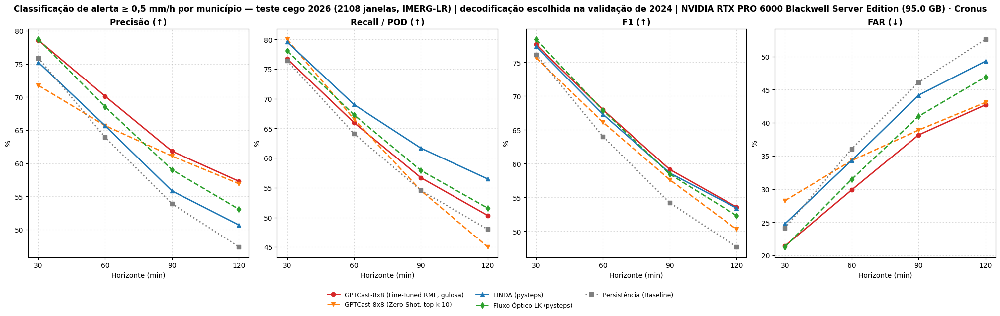

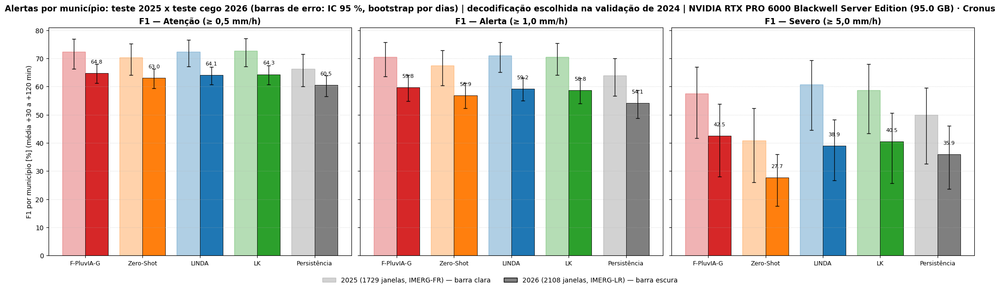

[Célula 13.2] Visão geral -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/teste_cego_2026/f1_alertas_2025_vs_2026_G4_RTX6000_Blackwell_95GB_Cronus_VQ_amostragem2024.png
[Célula 13.2] IC do F1 -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/teste_cego_2026/fpluvia_f1_municipio_bootstrap_dias_2025_2026_G4_RTX6000_Blackwell_95GB_Cronus_VQ_amostragem2024.csv
[Célula 13.2] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/teste_cego_2026/fpluvia_metricas_classificacao_teste_cego_2026_G4_RTX6000_Blackwell_95GB_Cronus_VQ_N2108_amostragem2024.csv
[Célula 13.2] Painel por horizonte -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/teste_cego_2026/metricas_classificacao_teste_cego_2026_por_horizonte_G4_RTX6000_Blackwell_95GB_Cronus_VQ_am

In [ ]:
# @title
# Célula Métricas (Célula 13.2): Métricas de Classificação por Nível de Alerta no TESTE CEGO DE 2026 (Célula 13.1), por pixel e por
# MUNICÍPIO da RMF, lado a lado com o teste de 2025 (Célula 12) — o equivalente da Célula 12.1 para 2026.
# Também sorteia os dias de novo, mil vezes, para ver se cada vantagem no F1 é de verdade ou só sorte (IC de 95 %).
# Não roda inferência: usa CELL13_1_RESULTS e CELL12_FULL_2025_RESULTS já em memória.
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.path import Path as MplPath

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
OUT_DIR = os.path.join(RESULTS_ENV_DIR, 'teste_cego_2026')
os.makedirs(OUT_DIR, exist_ok=True)
ALERT_LEVELS = {0.5: 'Atenção (≥ 0,5 mm/h)', 1.0: 'Alerta (≥ 1,0 mm/h)', 5.0: 'Severo (≥ 5,0 mm/h)'}
LEADS = [30 * (s + 1) for s in range(FORECAST_STEPS)]
N_BOOT = 1000                                   # reamostragens de dias inteiros
SEED = int(globals().get('SEED', 42))

if 'CELL13_1_RESULTS' not in globals():
  raise RuntimeError('Rode a Célula 13.1 antes desta (nesta mesma sessão).')
R13 = CELL13_1_RESULTS
R12 = globals().get('CELL12_FULL_2025_RESULTS')
if R13['parcial']:
  print(f"[Aviso Célula 13.2] A Célula 13.1 terminou PARCIAL ({R13['janelas_prontas']} de {R13['janelas_total']} janelas): "
        'os números abaixo são de uma amostra aleatória da série.')

# --------------------------------------------- 1. métodos, rótulos e sufixo (os mesmos da Célula 13.1)
_esc = R13.get('amostragem', 'padrao') == 'escolhida_2024'
NOMES = {'ft': f"GPTCast-8x8 (Fine-Tuned RMF, {'gulosa' if _esc else 'sorteio padrão'})",
         'ft_media': 'GPTCast-8x8 (Fine-Tuned RMF, média de 8)',
         'zs': f"GPTCast-8x8 (Zero-Shot, {'top-k 10' if _esc else 'sorteio padrão'})",
         'linda': 'LINDA (pysteps)', 'lk': 'Fluxo Óptico LK (pysteps)', 'pers': 'Persistência (Baseline)'}
NOMES = {k: v for k, v in NOMES.items() if f'{k}_rain' in R13}
SUF = '' if not _esc else ('_amostragem2024_media8' if 'ft_media' in NOMES else '_amostragem2024')
DECOD_TXT = 'decodificação escolhida na validação de 2024' if _esc else 'decodificação padrão do forecast()'
N26 = int(R13['janelas_prontas'])
PROD26 = ', '.join(sorted(set(np.asarray(R13['produto']).tolist())))

conjuntos = {f'2026 ({N26} janelas, {PROD26})': (R13['obs_rain'], {k: R13[f'{k}_rain'] for k in NOMES})}
datas = {list(conjuntos)[0]: np.asarray(R13['timestamps_t0'])}
if R12 is not None:
  if R12.get('amostragem', 'padrao') != R13.get('amostragem', 'padrao'):
    print('[Aviso Célula 13.2] Células 12 e 13.1 com decodificações diferentes: a comparação 2025 x 2026 as mistura.')
  m25 = np.isin(pd.to_datetime(np.asarray(R12['timestamps_t0'])).month, [2, 3, 4, 5])
  conjuntos[f'2025 ({int(m25.sum())} janelas, IMERG-FR)'] = (
      R12['obs_rain'][m25], {k: R12[f'{k}_rain'][m25] for k in NOMES if f'{k}_rain' in R12})
  datas[list(conjuntos)[1]] = np.asarray(R12['timestamps_t0'])[m25]
else:
  print('[Célula 13.2] CELL12_FULL_2025_RESULTS ausente: só 2026 (rode a Célula 12 para comparar com 2025).')
ROTULO_2026, ROTULO_2025 = list(conjuntos)[0], (list(conjuntos)[1] if len(conjuntos) > 1 else None)


def classification_scores(tp, fp, fn, tn) -> dict:
  """Métricas em %; NaN quando o denominador é zero (ex.: precisão sem nenhum alerta emitido)."""
  def pct(a, b):
    return 100.0 * a / b if b else np.nan
  ppv, pod = pct(tp, tp + fp), pct(tp, tp + fn)
  return {'Acurácia [%]': pct(tp + tn, tp + fp + fn + tn), 'Precisão / PPV [%]': ppv, 'Recall / POD [%]': pod,
          'F1 [%]': 2 * ppv * pod / (ppv + pod) if np.isfinite(ppv) and np.isfinite(pod) and ppv + pod else np.nan,
          'FAR [%]': pct(fp, tp + fp), 'CSI / IoU [%]': pct(tp, tp + fp + fn),
          'Acurácia trivial "nunca chove" [%]': pct(fp + tn, tp + fp + fn + tn),
          'Taxa base observada [%]': pct(tp + fn, tp + fp + fn + tn)}


def _counts(ob, pb):
  return (float(np.sum(ob & pb)), float(np.sum(~ob & pb)), float(np.sum(ob & ~pb)), float(np.sum(~ob & ~pb)))


# ------------------------------------------------ 2. máscaras dos municípios na malha de 2 km
mun_masks = globals().get('mun_masks') or {}
if not mun_masks and globals().get('gdf_rmf') is not None:      # a Célula 12.1 pode não ter rodado nesta sessão
  _grade = globals().get('md_rmf') or adaptee
  lon_g, lat_g = np.meshgrid(_grade.target_lons, _grade.target_lats)
  pts = np.column_stack([lon_g.ravel(), lat_g.ravel()])
  for _, r in gdf_rmf.iterrows():
    geom = r.geometry
    polys = list(geom.geoms) if geom.geom_type == 'MultiPolygon' else [geom]
    m = np.zeros(pts.shape[0], bool)
    for pg in polys:
      m |= MplPath(np.asarray(pg.exterior.coords)).contains_points(pts)
    if m.sum() >= 4:   # municípios com ao menos 4 pixels de 2 km (16 km²)
      mun_masks[r['name']] = m.reshape(lon_g.shape)
if mun_masks:
  print(f'[Célula 13.2] {len(mun_masks)} municípios da RMF com máscara na malha de 2 km.')
else:
  print('[Aviso Célula 13.2] Limites municipais indisponíveis (rode a Célula 5): só a avaliação por pixel será feita.')


def municipal_means(rain_4d):
  """(N, passos, H, W) -> (N, passos, M): chuva média na área de cada município."""
  return np.stack([rain_4d[..., m].mean(axis=-1) for m in mun_masks.values()], axis=-1)


# ---------------------------------------------------------------- 3. tabelas
rows = []
unidades = ['pixel', 'município'] if mun_masks else ['pixel']
mun_cache = {}                                   # médias municipais, reaproveitadas no bootstrap
for conj, (obs, preds) in conjuntos.items():
  if mun_masks:
    mun_cache[conj] = (municipal_means(obs), {k: municipal_means(P) for k, P in preds.items()})
  for unidade in unidades:
    o_src = obs if unidade == 'pixel' else mun_cache[conj][0]
    for k, P in preds.items():
      p_src = P if unidade == 'pixel' else mun_cache[conj][1][k]
      for thr, nivel in ALERT_LEVELS.items():
        for s, lead in enumerate(LEADS + ['todos']):
          sel = slice(None) if lead == 'todos' else s
          rows.append({'Conjunto': conj, 'Unidade': unidade, 'Nível de alerta': nivel, 'Modelo': NOMES[k],
                       'Lead Time': 'média +30 a +120' if lead == 'todos' else f'+{lead} min',
                       **{c: round(v, 2) for c, v in classification_scores(
                           *_counts(o_src[:, sel] >= thr, p_src[:, sel] >= thr)).items()}})
df_cls = pd.DataFrame(rows)
cls_csv = os.path.join(OUT_DIR, f'fpluvia_metricas_classificacao_teste_cego_2026_{ENV_TAG}_N{N26}{SUF}.csv')
df_cls.to_csv(cls_csv, index=False)

media = df_cls[df_cls['Lead Time'] == 'média +30 a +120']
cols = ['Unidade', 'Nível de alerta', 'Modelo', 'F1 [%]', 'CSI / IoU [%]', 'Precisão / PPV [%]', 'Recall / POD [%]',
        'FAR [%]', 'Acurácia [%]', 'Acurácia trivial "nunca chove" [%]']
print(f'=== Classificação por nível de alerta — {ROTULO_2026}, média de +30 a +120 min | {DECOD_TXT} | {ENV_LABEL} ===')
print('A acurácia por pixel fica perto de 100% até para quem nunca prevê chuva (coluna "trivial"): '
      'use F1, CSI, POD e FAR para comparar.')
with pd.option_context('display.max_rows', None):
  display(media[media['Conjunto'] == ROTULO_2026][cols].set_index(['Unidade', 'Nível de alerta', 'Modelo']))

if ROTULO_2025:      # F1 por município: 2025 x 2026 lado a lado, com a diferença
  comp = (media[media['Unidade'] == unidades[-1]]
          .pivot_table(index=['Nível de alerta', 'Modelo'], columns='Conjunto', values='F1 [%]', sort=False, dropna=False))
  comp = comp[[ROTULO_2025, ROTULO_2026]]
  comp['Δ F1 (2026 − 2025)'] = comp[ROTULO_2026] - comp[ROTULO_2025]
  comp['Posição em 2026'] = comp.groupby(level=0)[ROTULO_2026].rank(ascending=False, method='min').astype('Int64')
  print(f'\n=== F1 [%] por {unidades[-1]}: 2025 x 2026, média de +30 a +120 min (posição 1 = melhor no nível) ===')
  with pd.option_context('display.max_rows', None):
    display(comp.round(1))


# ------------------------------------------- 4. IC de 95 % do F1 (bootstrap por dias inteiros)
# As janelas de um mesmo dia pertencem ao mesmo evento de chuva e não são independentes: reamostra-se o dia
# inteiro. As mesmas reamostragens valem para todos os métodos (comparação pareada).
def bootstrap_f1(o, preds, ts):
  """o, preds[k]: (N, passos, ...). Devolve {(k, thr): array N_BOOT de F1 [%]} e a estimativa pontual."""
  _, inv = np.unique(pd.to_datetime(ts).normalize().values, return_inverse=True)
  n_dias = inv.max() + 1
  amostras = np.random.default_rng(SEED).integers(0, n_dias, (N_BOOT, n_dias))
  est, pontual = {}, {}
  for thr in ALERT_LEVELS:
    ob = (o >= thr).reshape(len(o), -1)
    for k, P in preds.items():
      pb = (P >= thr).reshape(len(P), -1)
      por_dia = [np.bincount(inv, x.sum(1), n_dias) for x in (ob & pb, ~ob & pb, ob & ~pb)]
      tp, fp, fn = (c[amostras].sum(1) for c in por_dia)
      est[(k, thr)] = 100 * 2 * tp / np.maximum(2 * tp + fp + fn, 1)
      t, f, m = (c.sum() for c in por_dia)
      pontual[(k, thr)] = 100 * 2 * t / max(2 * t + f + m, 1)
  return est, pontual, n_dias


unidade_boot = unidades[-1]
linhas_boot = []
for conj, (obs, preds) in conjuntos.items():
  o_b, p_b = (mun_cache[conj] if unidade_boot == 'município' else (obs, preds))
  est, pontual, n_dias = bootstrap_f1(o_b, p_b, datas[conj])
  for thr, nivel in ALERT_LEVELS.items():
    for k in p_b:
      lo, hi = np.percentile(est[(k, thr)], [2.5, 97.5])
      linha = {'Conjunto': conj, 'Nível de alerta': nivel, 'Modelo': NOMES[k], 'Dias': n_dias,
               'F1 [%]': round(pontual[(k, thr)], 1), 'F1 IC95 [%]': f'{lo:.1f} – {hi:.1f}',
               '_lo': lo, '_hi': hi}
      if k != 'ft':
        d = est[('ft', thr)] - est[(k, thr)]
        dlo, dhi = np.percentile(d, [2.5, 97.5])
        linha['ΔF1 (FT-G − método) IC95'] = f'{dlo:+.1f} – {dhi:+.1f}'
        linha['FT-G em relação ao método'] = ('melhor' if dlo > 0 else 'pior' if dhi < 0 else 'empate técnico')
      linhas_boot.append(linha)
df_boot = pd.DataFrame(linhas_boot)
boot_csv = os.path.join(OUT_DIR, f'fpluvia_f1_{unidade_boot.replace("í", "i")}_bootstrap_dias_2025_2026_{ENV_TAG}{SUF}.csv')
df_boot.drop(columns=['_lo', '_hi']).to_csv(boot_csv, index=False)
print(f'\n=== F1 por {unidade_boot} com IC de 95 % (bootstrap por dias, {N_BOOT} reamostragens), média de +30 a +120 min ===')
print('"melhor"/"pior": o IC da diferença não cruza zero; "empate técnico": cruza zero (diferença não significativa).')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
  display(df_boot.drop(columns=['_lo', '_hi']).fillna('—').set_index(['Conjunto', 'Nível de alerta', 'Modelo']))

# ---------------------------------------------------------------- 5. figuras
styles = {'ft': ('#d62728', 'o', '-'), 'ft_media': ('#9467bd', 'P', '-.'), 'zs': ('#ff7f0e', 'v', '--'),
          'linda': ('#1f77b4', '^', '-'), 'lk': ('#2ca02c', 'd', '--'), 'pers': ('#7f7f7f', 's', ':')}
unidade_plot = unidades[-1]

# 4a. o mesmo painel da Célula 12.1, agora para 2026 (Atenção, por horizonte)
panels = [('Precisão / PPV [%]', 'Precisão (↑)'), ('Recall / POD [%]', 'Recall / POD (↑)'),
          ('F1 [%]', 'F1 (↑)'), ('FAR [%]', 'FAR (↓)')]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.6), constrained_layout=True)
base = df_cls[(df_cls['Conjunto'] == ROTULO_2026) & (df_cls['Unidade'] == unidade_plot) &
              (df_cls['Nível de alerta'] == ALERT_LEVELS[0.5]) & (df_cls['Lead Time'] != 'média +30 a +120')]
for ax, (col, title) in zip(axes, panels):
  for k, nome in NOMES.items():
    sub = base[base['Modelo'] == nome]
    c, mk, ls = styles[k]
    ax.plot(LEADS, sub[col].values, color=c, marker=mk, ls=ls, lw=2, label=nome)
  ax.set_title(title, fontweight='bold')
  ax.set_xlabel('Horizonte (min)')
  ax.set_ylabel('%')
  ax.set_xticks(LEADS)
  ax.grid(True, ls=':', alpha=0.55)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9)
fig.suptitle(f'Classificação de alerta ≥ 0,5 mm/h por {unidade_plot} — teste cego {ROTULO_2026} | {DECOD_TXT} | {ENV_LABEL}',
             fontsize=12, fontweight='bold')
png_h = os.path.join(OUT_DIR, f'metricas_classificacao_teste_cego_2026_por_horizonte_{ENV_TAG}{SUF}.png')
fig.savefig(png_h, dpi=300, bbox_inches='tight')
plt.show()

# 4b. visão geral: F1 por nível de alerta, 2025 (claro) x 2026 (escuro), um painel por nível
if ROTULO_2025:
  fig, axes = plt.subplots(1, 3, figsize=(20, 5.6), constrained_layout=True, sharey=True)
  nomes = list(NOMES.values())
  CURTO = {'ft': 'F-PluvIA-G' if _esc else 'F-PluvIA-A', 'ft_media': 'F-PluvIA-C8', 'zs': 'Zero-Shot',
           'linda': 'LINDA', 'lk': 'LK', 'pers': 'Persistência'}
  xs = np.arange(len(nomes))
  for ax, nivel in zip(axes, ALERT_LEVELS.values()):
    if nivel not in comp.index.get_level_values(0):
      ax.set_title(f'F1 — {nivel} (sem casos)', fontweight='bold'); continue
    sub = comp.loc[nivel].reindex(nomes)
    cores = [styles[k][0] for k in NOMES]
    def _err(conj):   # barras de erro = IC de 95 % do bootstrap por dias
      g = df_boot[(df_boot['Conjunto'] == conj) & (df_boot['Nível de alerta'] == nivel)].set_index('Modelo').reindex(nomes)
      f1 = sub[conj].values
      return np.vstack([np.clip(f1 - g['_lo'].values, 0, None), np.clip(g['_hi'].values - f1, 0, None)])
    eb = {'ecolor': 'black', 'capsize': 3, 'elinewidth': 0.9}
    b25 = ax.bar(xs - 0.2, sub[ROTULO_2025], 0.4, color=cores, alpha=0.35, edgecolor=cores,
                 yerr=_err(ROTULO_2025) if unidade_boot == unidade_plot else None, error_kw=eb)
    b26 = ax.bar(xs + 0.2, sub[ROTULO_2026], 0.4, color=cores, edgecolor='black', lw=0.6,
                 yerr=_err(ROTULO_2026) if unidade_boot == unidade_plot else None, error_kw=eb)
    for b, v in zip(b26, sub[ROTULO_2026]):
      if np.isfinite(v):
        ax.text(b.get_x() + b.get_width() / 2, v + 3.5, f'{v:.1f}', ha='center', fontsize=8)
    ax.set_title(f'F1 — {nivel}', fontweight='bold')
    ax.set_xticks(xs)
    ax.set_xticklabels([CURTO[k] for k in NOMES], fontsize=9)
    ax.grid(True, axis='y', ls=':', alpha=0.55)
  axes[0].set_ylabel(f'F1 por {unidade_plot} [%] (média +30 a +120 min)')
  fig.legend([plt.Rectangle((0, 0), 1, 1, color='gray', alpha=0.35), plt.Rectangle((0, 0), 1, 1, color='gray', ec='black')],
             [ROTULO_2025 + ' — barra clara', ROTULO_2026 + ' — barra escura'],
             loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
  fig.suptitle(f'Alertas por {unidade_plot}: teste 2025 x teste cego 2026 (barras de erro: IC 95 %, bootstrap por dias) | '
               f'{DECOD_TXT} | {ENV_LABEL}',
               fontsize=12.5, fontweight='bold')
  png_n = os.path.join(OUT_DIR, f'f1_alertas_2025_vs_2026_{ENV_TAG}{SUF}.png')
  fig.savefig(png_n, dpi=300, bbox_inches='tight')
  plt.show()
  print(f'[Célula 13.2] Visão geral -> {png_n}')

CELL13_2_RESULTS = {'classificacao': df_cls, 'f1_2025_vs_2026': comp if ROTULO_2025 else None,
                    'f1_bootstrap': df_boot.drop(columns=['_lo', '_hi'])}
print(f'[Célula 13.2] IC do F1 -> {boot_csv}')
print(f'[Célula 13.2] Tabela -> {cls_csv}\n[Célula 13.2] Painel por horizonte -> {png_h}')


# ⚠️ Célula Extra (Célula 13.3): Volume de Tokens do Transformer do GPTCast-8x8 por Etapa e por Variante do F-PluvIA e do Zero-Shot - Treino, Validação, Escolha da Decodificação, Teste 2025, Teste Cego 2026 e Previsão de um Único Quadro (`ENV_TAG`)

⚠️ Pode ser pulada no fluxo de publicação quando as saídas já estiverem no Drive: o manifesto (Extra 2) e o Deploy as incluem do mesmo jeito. Para gerar ou atualizar os resultados, execute-a normalmente.

* **O que é um token aqui**: Um índice do *codebook* da VQGAN, que representa um bloco de 16 × 16 pixels (cerca de 32 km). Cada quadro de 128 × 128 pixels vira 8 × 8 = 64 tokens. Não é cobrança de API: é o **volume de trabalho do Transformer**.

* **Treino e validação (tokens lidos)**: Cada amostra tem 8 quadros, ou seja, 512 tokens. O Transformer recebe o token inicial (SOS) e 511 tokens da sequência e é avaliado nos 512, todos de uma vez. A célula soma as amostras vistas no ajuste fino (Célula 4), no ajuste fino suave (Célula 4.3, as duas rodadas) e nas validações (a cada época, a cada 1/4 de época e na Célula 4.1), lendo os `metrics.csv` e o registro de treino.

* **Previsão (tokens gerados)**: Cada quadro futuro tem 64 tokens gerados **um a um**. Para cada um, o Transformer relê todo o contexto: o SOS, os 7 quadros de entrada (448 tokens) e os tokens já gerados no quadro, de 449 a 512 posições. Como o pacote não usa cache de atenção, gerar um quadro custa 30.752 posições processadas. A média de 8 (F-PluvIA-C8) gera 8 × 64 = 512 tokens por quadro, em lote.

* **Por etapa e variante**: Escolha da decodificação na validação de 2024 (Célula 4.5: 6 decodificações × 2 modelos), teste de 2025 (Célula 12: F-PluvIA-A, F-PluvIA-G, F-PluvIA-C8 e Zero-Shot com sorteio padrão e *top-k* 10) e teste cego de 2026 (Célula 13.1: F-PluvIA-G, F-PluvIA-C8 e Zero-Shot *top-k* 10). Mostra também o tempo medido por quadro e os tokens gerados por segundo, comparados com a vazão do ajuste fino.

* **Fora da conta**: O primeiro ajuste fino (tokenização quadro a quadro, descartado), as previsões de versões anteriores (arquivadas), os estudos de caso de 18/03/2024 (uma janela, refeitos a cada sessão) e a checagem de sanidade do Lightning.

* **Saídas**: Duas tabelas (`.csv`) e um painel em escala logarítmica (`.png` a `300 dpi`) em `RESULTS_ENV_DIR`, incluídos no Deploy, no manifesto SHA-256 e no Backup.

In [ ]:
# @title
# Célula 13.3: Volume de Tokens por Etapa e por Variante — quantos tokens o Transformer do GPTCast-8x8 processou
# no ajuste fino, na validação e nas previsões de cada variante do F-PluvIA e do Zero-Shot, e quantos tokens custa
# prever um único quadro. Não roda nenhum modelo: usa a arquitetura do GPTCast e os registros já gravados no Drive.
#
# "Token" aqui é um índice do codebook da VQGAN (um bloco de 16 x 16 pixels, ~32 km):
# é o volume de trabalho do Transformer. Contagens conferidas no código do pacote gptcast:
#   - treino/validação: cada amostra tem 8 quadros x 64 tokens = 512; o Transformer recebe o token inicial (SOS)
#     + 511 tokens e é avaliado nos 512 tokens da sequência (shared_step);
#   - previsão: cada quadro futuro tem 64 tokens gerados um a um (predict_next_frame_indices), cada um com uma
#     passada completa do Transformer sobre SOS + 7 quadros de contexto (448 tokens) + os já gerados no quadro.
#     Não há cache de atenção (KV cache, ele evitaria processamento repetido dos mesmos tokens ): o contexto é reprocessado a cada token.
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ENV_TAG = globals().get('ENV_TAG', 'G4_RTX6000_Blackwell_95GB')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
SERIES_CACHE_DIR = globals().get('SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))

# ------------------------------------------------------------- 1. arquitetura e constantes
N_CTX = int(globals().get('CONTEXT_STEPS', 7))          # quadros de contexto na previsão
N_FUT = int(globals().get('FORECAST_STEPS', 4))         # quadros previstos (+30 a +120 min)
BLOCK = 512                                             # block_size do Transformer (8 quadros x 64 tokens)
TOK_QUADRO = 64                                         # 128 x 128 px / (16 x 16 px por token) = 8 x 8
_gpt = globals().get('gpt8')
if _gpt is not None:
  try:
    BLOCK = int(_gpt.transformer.config.block_size)
    TOK_QUADRO = BLOCK // 8
  except Exception:
    pass
TOK_AMOSTRA = BLOCK                                     # tokens da sequência por amostra de treino/validação
N_MEMBROS = 8                                           # F-PluvIA-C8 (média de 8 sorteios)
N_JANELAS_45 = 240                                      # Célula 4.5: janelas da validação de 2024 sorteadas
CTX_INI = 1 + N_CTX * TOK_QUADRO                        # SOS + contexto = 449 tokens no 1º token do quadro
POS_QUADRO = sum(CTX_INI + k for k in range(TOK_QUADRO))   # posições processadas para gerar 1 quadro (30.752)
assert CTX_INI + TOK_QUADRO - 1 <= BLOCK, 'contexto da previsão maior que o block_size'


def _achar(padrao):
  """Arquivo mais recente que casa com o padrão, em qualquer subpasta de RESULTS_ENV_DIR (ou None)."""
  achados = sorted(glob.glob(os.path.join(RESULTS_ENV_DIR, '**', padrao), recursive=True), key=os.path.getmtime)
  return achados[-1] if achados else None


fontes = {}
# ------------------------------------------------------------- 2. tamanhos das partições
N_TREINO, N_VAL, N_TESTE25 = 9940, 2224, 1729
f = _achar(f'resumo_particoes_{ENV_TAG}_*.csv')
if f:
  d = pd.read_csv(f).set_index('Particao')['Sequencias']
  N_TREINO, N_VAL, N_TESTE25 = int(d['Treino']), int(d['Validação']), int(d['Teste'])
  fontes['partições'] = os.path.basename(f)
reg = {}
f = _achar(f'log_tempos_treino_e_inferencia_{ENV_TAG}_*.json')
if f:
  reg = json.load(open(f, encoding='utf-8'))
  fontes['registro de treino'] = os.path.basename(f)
LOTE = int(reg.get('batch_size_treino', 16))
T_AJUSTE_S = float(reg.get('finetuning_tempo_total_s', np.nan))
PASSOS_EPOCA = -(-N_TREINO // LOTE)                     # 9.940 / 16 -> 622 passos (o último com 4 amostras)


def _amostras_e_validacoes(metrics_csv):
  """Amostras de treino vistas e validações completas, lidas do metrics.csv do Lightning."""
  m = pd.read_csv(metrics_csv)
  passos = int(m['step'].max()) + 1
  epocas_completas, resto = divmod(passos, PASSOS_EPOCA)
  amostras = epocas_completas * N_TREINO + min(resto * LOTE, N_TREINO)
  n_val = int(m['val/loss_epoch'].notna().sum()) if 'val/loss_epoch' in m else 0
  return amostras, n_val, passos


# ------------------------------------------------------------- 3. treino e validação
linhas = []


def add(etapa, modelo, variante, unidade, n, tok_unidade, gerados=False, obs=''):
  linhas.append({'Etapa': etapa, 'Modelo': modelo, 'Variante': variante, 'Unidade': unidade, 'Quantidade': int(n),
                 'Tokens por unidade': int(tok_unidade), 'Tokens': int(n * tok_unidade),
                 'Posições processadas pelo Transformer': int(n * tok_unidade * (POS_QUADRO / TOK_QUADRO) if gerados
                                                              else n * tok_unidade),
                 'Tipo': 'gerados (previsão)' if gerados else 'lidos (treino/validação)', 'Observação': obs})


tag = str(reg.get('finetuning_origem', '')).replace('treino de ', '').strip()
principais = [p for p in glob.glob(os.path.join(RESULTS_ENV_DIR, '**', 'metrics.csv'), recursive=True)
              if 'alternativo' not in p and (not tag or tag in p)]
if principais:
  amostras, n_val, passos = _amostras_e_validacoes(sorted(principais)[-1])
  fontes['curva do ajuste fino'] = os.path.relpath(sorted(principais)[-1], RESULTS_ENV_DIR)
else:
  amostras, n_val, passos = int(reg.get('epocas_executadas', 5)) * N_TREINO, int(reg.get('epocas_executadas', 5)), None
add('Ajuste fino (Célula 4)', 'F-PluvIA (lr 5e-5)', 'treino', 'amostra de 8 quadros', amostras, TOK_AMOSTRA,
    obs=f'{amostras // N_TREINO} épocas de {N_TREINO} janelas (recorte aleatório)')
add('Ajuste fino (Célula 4)', 'F-PluvIA (lr 5e-5)', 'validação a cada época', 'amostra de 8 quadros', n_val * N_VAL,
    TOK_AMOSTRA, obs=f'{n_val} validações completas de {N_VAL} janelas de 2024')

for p in sorted(glob.glob(os.path.join(RESULTS_ENV_DIR, '**', 'curva_treino_alternativo_*', '*', 'metrics.csv'),
                          recursive=True)):
  a, v, ps = _amostras_e_validacoes(p)
  rodada = os.path.basename(os.path.dirname(p))
  add('Ajuste fino suave (Célula 4.3)', 'F-PluvIA suave (lr 1e-5)', 'treino', 'amostra de 8 quadros', a, TOK_AMOSTRA,
      obs=f'rodada {rodada[:14]}: {ps} passos' + (' (interrompida no início)' if ps < PASSOS_EPOCA else ''))
  if v:
    add('Ajuste fino suave (Célula 4.3)', 'F-PluvIA suave (lr 1e-5)', 'validação a cada ¼ de época',
        'amostra de 8 quadros', v * N_VAL, TOK_AMOSTRA, obs=f'rodada {rodada[:14]}: {v} validações completas')
  fontes.setdefault('curvas da Célula 4.3', []).append(rodada)

add('Validação Fine-Tuned × Zero-Shot (Célula 4.1)', 'F-PluvIA (lr 5e-5)', 'perda nos tokens', 'amostra de 8 quadros',
    N_VAL, TOK_AMOSTRA, obs='uma passada sobre a validação de 2024')
add('Validação Fine-Tuned × Zero-Shot (Célula 4.1)', 'Zero-Shot', 'perda nos tokens', 'amostra de 8 quadros', N_VAL,
    TOK_AMOSTRA, obs='uma passada sobre a validação de 2024')

# ------------------------------------------------------------- 4. previsões (tokens gerados)
TOK_JANELA = N_FUT * TOK_QUADRO                          # 4 quadros x 64 = 256 tokens gerados por janela
n26, n_casos26 = 2108, 2
f = _achar(f'teste_cego_2026_meses_e_produtos_{ENV_TAG}*.csv')
if f:
  n26 = int(pd.read_csv(f)['Janelas'].sum())
  fontes['teste cego 2026'] = os.path.basename(f)
f = _achar(f'teste_cego_2026_estudos_de_caso_{ENV_TAG}*.csv')
if f:
  n_casos26 = int(pd.read_csv(f)['Caso'].nunique())

DEC_45 = [('Padrão (T=1, sem top-k)', 1), ('top-k 50', 1), ('top-k 10', 1), ('Temperatura 0,7', 1),
          ('Gulosa (top-k 1)', 1), (f'Média de {N_MEMBROS} sorteios', N_MEMBROS)]
for modelo in ('F-PluvIA (lr 5e-5)', 'Zero-Shot'):
  for nome, membros in DEC_45:
    add('Escolha da decodificação (Célula 4.5, validação 2024)', modelo, nome, 'janela (4 quadros)',
        N_JANELAS_45 * membros, TOK_JANELA, gerados=True,
        obs=f'{N_JANELAS_45} janelas' + (f' x {membros} membros' if membros > 1 else ''))

PREV = [  # (etapa, modelo, variante, janelas, membros, observação)
    ('Teste 2025 (Célula 12)', 'F-PluvIA (lr 5e-5)', 'F-PluvIA-A (sorteio padrão)', N_TESTE25, 1, 'rodada com a decodificação padrão do pacote'),
    ('Teste 2025 (Célula 12)', 'Zero-Shot', 'sorteio padrão', N_TESTE25, 1, 'rodada com a decodificação padrão do pacote'),
    ('Teste 2025 (Célula 12)', 'F-PluvIA (lr 5e-5)', 'F-PluvIA-G (gulosa)', N_TESTE25, 1, 'decodificação escolhida em 2024'),
    ('Teste 2025 (Célula 12)', 'Zero-Shot', 'top-k 10', N_TESTE25, 1, 'decodificação escolhida em 2024'),
    ('Teste 2025 (Célula 12)', 'F-PluvIA (lr 5e-5)', f'F-PluvIA-C{N_MEMBROS} (média de {N_MEMBROS})', N_TESTE25, N_MEMBROS, f'{N_MEMBROS} membros por janela'),
    ('Teste cego 2026 (Célula 13.1)', 'F-PluvIA (lr 5e-5)', 'F-PluvIA-G (gulosa)', n26 + n_casos26, 1, f'{n26} janelas da série + {n_casos26} estudos de caso'),
    ('Teste cego 2026 (Célula 13.1)', 'Zero-Shot', 'top-k 10', n26 + n_casos26, 1, f'{n26} janelas da série + {n_casos26} estudos de caso'),
    ('Teste cego 2026 (Célula 13.1)', 'F-PluvIA (lr 5e-5)', f'F-PluvIA-C{N_MEMBROS} (média de {N_MEMBROS})', n26 + n_casos26, N_MEMBROS, f'{N_MEMBROS} membros por janela'),
]
for etapa, modelo, variante, n, membros, obs in PREV:
  add(etapa, modelo, variante, 'janela (4 quadros)', n * membros, TOK_JANELA, gerados=True, obs=obs)

df = pd.DataFrame(linhas)

# ------------------------------------------------------------- 5. custo de um quadro
vel = {}
f = _achar(f'velocidade_inferencia_teste2025_{ENV_TAG}_N*_amostragem2024_media8.csv')
if f:
  v = pd.read_csv(f).set_index('Modelo')['Tempo_Medio_4Passos_s']
  vel = {'G': v.get('GPTCast-8x8 (Fine-Tuned RMF)'), 'C8': v.get('GPTCast-8x8 (Fine-Tuned RMF, média de 8)'),
         'ZS': v.get('GPTCast-8x8 (Zero-Shot)')}
  fontes['tempos de previsão'] = os.path.basename(f)
unid = []
for nome, membros, chave in (('F-PluvIA-A / F-PluvIA-G / Zero-Shot (1 sorteio)', 1, 'G'),
                             (f'F-PluvIA-C{N_MEMBROS} (média de {N_MEMBROS})', N_MEMBROS, 'C8')):
  t_quadro = vel.get(chave) / N_FUT if vel.get(chave) else np.nan
  unid.append({'Previsão de 1 quadro (+30 min)': nome, 'Tokens gerados': TOK_QUADRO * membros,
               'Passadas do Transformer': TOK_QUADRO, 'Contexto por passada [tokens]': f'{CTX_INI} a {CTX_INI + TOK_QUADRO - 1}',
               'Posições processadas': POS_QUADRO * membros, 'Tempo medido por quadro [s]': round(t_quadro, 3),
               'Tokens gerados por segundo': round(TOK_QUADRO * membros / t_quadro, 1) if t_quadro == t_quadro else np.nan})
df_unid = pd.DataFrame(unid)

tok_ajuste = df[(df['Etapa'] == 'Ajuste fino (Célula 4)')]['Tokens'].sum()
vazao_treino = tok_ajuste / T_AJUSTE_S if T_AJUSTE_S == T_AJUSTE_S and T_AJUSTE_S > 0 else np.nan

# ------------------------------------------------------------- 6. saídas
fmt = lambda x: f'{x:,.0f}'.replace(',', '.')
print(f'=== Volume de tokens do Transformer do GPTCast-8x8 | {ENV_LABEL} ===')
print(f'Arquitetura: {TOK_QUADRO} tokens por quadro | block_size {BLOCK} | contexto de previsão {N_CTX} quadros | '
      f'{N_FUT} quadros previstos | fontes: {fontes}')


def _bonito(d, inteiros):
  """Cópia só para exibir, com separador de milhar (os CSV guardam os números puros)."""
  d = d.copy()
  for c in inteiros:
    d[c] = d[c].map(fmt)
  return d


print('\n--- Previsão de um único quadro ---')
display(_bonito(df_unid, ['Tokens gerados', 'Passadas do Transformer', 'Posições processadas'])
        .set_index('Previsão de 1 quadro (+30 min)'))
print(f'Para gerar {TOK_QUADRO} tokens, o Transformer processa {fmt(POS_QUADRO)} posições ({POS_QUADRO / TOK_QUADRO:.1f} por '
      'token gerado): sem cache de atenção, o contexto inteiro é relido a cada token.')
if vazao_treino == vazao_treino:
  print(f'No ajuste fino (treino + validação), a vazão foi de ~{fmt(vazao_treino)} tokens/s: o treino lê a sequência '
        'inteira de uma vez, a previsão gera um token por vez.')

cols = ['Quantidade', 'Tokens por unidade', 'Tokens', 'Posições processadas pelo Transformer', 'Observação']
print('\n--- Por etapa e variante ---')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 70):
  display(_bonito(df, cols[:4]).set_index(['Etapa', 'Modelo', 'Variante'])[cols])

resumo = df.pivot_table(index='Modelo', columns='Tipo', values='Tokens', aggfunc='sum', fill_value=0, sort=False)
resumo['Total de tokens'] = resumo.sum(axis=1)
resumo['Posições processadas'] = df.groupby('Modelo', sort=False)['Posições processadas pelo Transformer'].sum()
print('\n--- Por modelo (todas as etapas) ---')
display(_bonito(resumo, list(resumo.columns)))
tot = df['Tokens'].sum()
print(f'Total no trabalho: {fmt(tot)} tokens ({fmt(df["Posições processadas pelo Transformer"].sum())} posições processadas).')
print('Fora da conta: o primeiro ajuste fino (tokenização quadro a quadro, descartado), as previsões de versões '
      'anteriores, os estudos de caso de 18/03/2024 (1 janela, refeitos a cada sessão) e a checagem de sanidade do Lightning.')

p_det = os.path.join(RESULTS_ENV_DIR, f'tokens_por_etapa_e_variante_{ENV_TAG}.csv')
p_uni = os.path.join(RESULTS_ENV_DIR, f'tokens_por_quadro_{ENV_TAG}.csv')
df.to_csv(p_det, index=False)
df_unid.to_csv(p_uni, index=False)

# figura: tokens por etapa e variante (escala log), cores por modelo
cores = {'F-PluvIA (lr 5e-5)': '#d62728', 'F-PluvIA suave (lr 1e-5)': '#ff9896', 'Zero-Shot': '#ff7f0e'}
g = df.groupby(['Etapa', 'Modelo', 'Variante'], sort=False)['Tokens'].sum().reset_index()
_curto = {'F-PluvIA (lr 5e-5)': 'F-PluvIA', 'F-PluvIA suave (lr 1e-5)': 'F-PluvIA suave', 'Zero-Shot': 'Zero-Shot'}
g['rótulo'] = [f"{e.split(' (')[0]} | " + (v if v.startswith('F-PluvIA') else f"{_curto.get(m, m)}, {v}")
               for e, m, v in zip(g['Etapa'], g['Modelo'], g['Variante'])]
fig, ax = plt.subplots(figsize=(12, 0.32 * len(g) + 1.6), constrained_layout=True)
y = np.arange(len(g))[::-1]
ax.barh(y, g['Tokens'], color=[cores.get(m, '#7f7f7f') for m in g['Modelo']])
for yi, t in zip(y, g['Tokens']):
  ax.text(t * 1.08, yi, fmt(t), va='center', fontsize=7.5)
ax.set_yticks(y)
ax.set_yticklabels(g['rótulo'], fontsize=8)
ax.set_xscale('log')
ax.set_xlim(left=max(1, g['Tokens'].min() / 3), right=g['Tokens'].max() * 6)
ax.set_xlabel('Tokens (escala logarítmica): lidos no treino/validação, gerados na previsão')
ax.grid(True, axis='x', ls=':', alpha=0.6)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()], list(cores), loc='lower right', fontsize=8)
ax.set_title(f'Volume de tokens do Transformer do GPTCast-8x8 por etapa e variante | {ENV_LABEL}', fontweight='bold')
p_fig = os.path.join(RESULTS_ENV_DIR, f'painel_tokens_por_etapa_{ENV_TAG}.png')
fig.savefig(p_fig, dpi=300, bbox_inches='tight')
plt.show()

CELL13_3_RESULTS = {'por_etapa': df, 'por_quadro': df_unid, 'por_modelo': resumo}
print(f'[Célula 13.3] Tabelas -> {p_det} | {p_uni}\n[Célula 13.3] Figura -> {p_fig}')


# Célula 13.4: Análise de Complexidade do F-PluvIA-G (Big O): Estudo de Caso Comparativo

Esta célula analisa a complexidade da previsão do **F-PluvIA-G** (decodificação gulosa) como um **estudo de caso comparativo**, com a mesma metodologia do estudo de Programação Dinâmica da *Edit Distance* da disciplina de Análise de Algoritmos - ANALG 2051.1 IFCE Maracanaú Profº Thiago Alves (top-down com memoização × bottom-up iterativo). Lá, duas implementações equivalentes de Θ(n·m) foram comparadas; aqui, comparamos duas implementações equivalentes do gerador de tokens.

* **Versão 1: Recálculo (sem cache).** É o gerador original do pacote GPTCast (`predict_next_frame_indices`). Cada um dos **T = 64** tokens do quadro reprocessa o contexto inteiro.

* **Versão 2: KV cache (memoização).** O contexto passa **uma única vez** pelo Transformer, e as chaves e valores da atenção de cada camada ficam guardados. Cada token novo processa só **1 posição** (`forward_with_past` do minGPT). É memoização no sentido exato da Programação Dinâmica: subproblemas já resolvidos (as chaves e valores das posições anteriores) não são recalculados.

## 1. Complexidade Teórica

Os parâmetros são: **S** passos de previsão (tamanho da entrada), **T** tokens por quadro (64), **n ≤ 512** tokens de contexto, e **L** camadas e **d** largura do Transformer.

* **Recálculo**: T passagens de n tokens por quadro, ou **O(S·T·L·(n·d² + n²·d))**. São **30.752 posições** por quadro.

* **KV cache**: 1 passagem do contexto mais (T − 1) passagens de 1 token, ou **O(S·L·(n·d² + n²·d))**: **um fator T a menos**. São **512 posições** por quadro (60× menos).

* **As duas versões são O(S)** no horizonte, porque a janela de contexto desliza e nunca passa de 512 tokens. A diferença está no custo de cada quadro.

## 2. Metodologia (a mesma do estudo de caso)

* **Reprodutibilidade**: `random.seed(42)`.

* **Tamanhos**: sorteia **k ∈ [6, 10]** tamanhos de entrada, **igualmente espaçados** em S ∈ [1, 12] passos (+30 a +360 min).

* **Instâncias**: sorteia **m ∈ [10, 20]** instâncias, o mesmo m para todos os tamanhos. Para cada tamanho, gera **uma única lista** de janelas do teste de 2025, e as **duas versões rodam sobre as mesmas instâncias**.

* **Tempo**: `time.perf_counter()` com sincronização da GPU antes e depois de cada medida. O resultado é o **tempo médio por instância** de cada tamanho, depois de 2 execuções de aquecimento.

* **Correção**: como o `assert d1 == d2` do estudo de caso. Em fp32, para cada um dos 64 tokens, as duas versões recebem o **mesmo contexto** e precisam escolher o **mesmo token**. Só um empate numérico entre os dois maiores logits é aceito. A célula também conta quantas previsões completas em bf16 saem idênticas.

* **Gráfico e tabela**: tempo × tamanho das duas versões, uma tabela de resultados e o tempo total de execução.

* **Constantes**: discussão da diferença entre o ganho teórico e o ganho medido.

## 3. Saídas (em `RESULTS_ENV_DIR`)

* `tabela_complexidade_bigO_fpluvia_g_<ENV_TAG>.csv`: tempos médios das duas versões, speedup, posições processadas, TFLOP/s e previsões idênticas, por tamanho.

* `tabela_verificacao_kvcache_fpluvia_g_<ENV_TAG>.csv`: verificação de correção token a token por instância.

* `painel_complexidade_bigO_fpluvia_g_<ENV_TAG>.png`, com dois painéis:

  * (a) comparação de tempo das duas versões, com as retas ajustadas;

  * (b) o ganho em posições (teórico) contra o ganho em tempo (medido).

## 4. Requisitos e Tempo

* **Requisitos**: Células 1 a 4 e a **(Activates Checkpoint)** na mesma sessão, para ter `gpt8` e `md_rmf`. Não depende da Célula 12.

* **Tempo**: cerca de **3 a 5 minutos** na GPU, conforme o k e o m sorteados.

* **Publicação**: as saídas ficam em `RESULTS_ENV_DIR`, então a **Extra 2**, o **Deploy** e o **Backup** as incluem automaticamente.

In [ ]:
# @title
# Célula 13.4: Análise de Complexidade do F-PluvIA-G (Big O) — estudo de caso comparativo entre duas implementações
# equivalentes do gerador guloso: recálculo integral (sem cache) × memoização das chaves e valores da atenção (KV cache).
# Metodologia do estudo de caso de Programação Dinâmica (Edit Distance, top-down com memoização × bottom-up) durante a discipina de
# ANALG 2051.1 IFCE Maracanaú Profº Thiago Alves .
# semente 42, k tamanhos sorteados e igualmente espaçados, m instâncias sorteadas e iguais para as duas versões,
# tempo médio por instância com perf_counter e verificação de correção com assert.
import math
import os
import random
import time

import einops
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# ------------------------------------------------------------------- 1. parâmetros do experimento
ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
SERIES_CACHE_DIR = globals().get('SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
SEED = 42                           # reprodutibilidade, como no estudo de caso
MIN_S, MAX_S = 1, 12                # intervalo dos tamanhos de entrada: passos de 30 min (+30 a +360 min)
K_RANGE = (6, 10)                   # nº de tamanhos distintos (sorteado)
M_RANGE = (10, 20)                  # nº de instâncias por tamanho (sorteado, o mesmo para todos os tamanhos)
CONTEXTO = 7                        # quadros observados, como na Célula 12
AQUECIMENTO = 2                     # execuções descartadas antes de medir (compilação de kernels na GPU)
TOL_EMPATE = 1e-3                   # diferença entre os 2 maiores logits abaixo da qual há empate numérico

if globals().get('CRONUS', {}).get('ativo') == 'vq':
  raise RuntimeError('O modelo ativo é o F-PluvIA-VQ (Célula 13.6): esta célula analisa só o F-PluvIA-G. '
                     'Rode-a antes da 13.6 ou depois de cronus_voltar_para_v1(); a análise dos dois modelos '
                     'do duelo fica na Célula 13.7.1.')
for _nome in ('gpt8', 'md_rmf'):
  if _nome not in globals():
    raise RuntimeError(f'"{_nome}" não está na sessão: rode as Células 1 a 4 e a (Activates Checkpoint) antes.')
DEVICE = next(gpt8.parameters()).device
if DEVICE.type != 'cuda':
  print('[aviso] O modelo está na CPU: os tempos não representam a execução na GPU usada no artigo.')
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
gpt8.eval()
TR = gpt8.transformer
BLOCK = int(TR.config.block_size)                         # contexto máximo do Transformer (512)
WS = int(math.sqrt(BLOCK // 8))                           # janela espacial em tokens (8 → 8×8 = 64 por quadro)
T_QUADRO = WS * WS
P_TRANSFORMER = sum(p.numel() for p in TR.parameters())
seqs = md_rmf.splits['test'].sequences_dbz


def br(n) -> str:
  return f'{int(n):,}'.replace(',', '.')


def cronometro():
  if DEVICE.type == 'cuda':
    torch.cuda.synchronize()
  return time.perf_counter()


# ------------------------------------------------------------------- 2. as duas implementações
def _proximo_token(logits):
  """Mesma regra de predict_next_index com temperatura 1 e top-k 1 (decodificação gulosa)."""
  lg = gpt8.top_k_logits(logits[:, -1, :] / 1.0, 1)
  _, res = torch.topk(F.softmax(lg, dim=-1), k=1, dim=-1)
  return res


def quadro_recalculo(ind_ctx, c_idx):
  """Versão 1, sem cache: o gerador original do pacote. Cada um dos T tokens do quadro
  reprocessa o contexto inteiro (condicionamento + quadros passados + tokens já gerados)."""
  return gpt8.predict_next_frame_indices(ind_ctx, c_idx, WS, temperature=1.0, top_k=1, show_progress=False)


def quadro_kv_cache(ind_ctx, c_idx):
  """Versão 2, com memoização: o contexto passa uma única vez pelo Transformer e as chaves e valores
  de cada camada ficam guardados (KV cache); cada token novo processa só 1 posição."""
  b, _, h, w = ind_ctx.shape
  if (h, w) != (WS, WS):
    raise RuntimeError(f'O KV cache exige que a janela ({WS}×{WS}) cubra o quadro inteiro; quadro de {h}×{w} tokens.')
  prefixo = torch.cat((c_idx.reshape(b, -1), ind_ctx.reshape(b, -1)), dim=1)
  logits, _, cache = TR.forward_with_past(prefixo)
  n = prefixo.shape[1]
  tok = _proximo_token(logits)
  tokens = [tok]
  for _ in range(h * w - 1):
    logits, _, novo = TR.forward_with_past(tok, past=[cache], past_length=n)
    cache = torch.cat((cache, novo), dim=-2)                # o pacote devolve só k e v da posição nova
    n += 1
    tok = _proximo_token(logits)
    tokens.append(tok)
  return torch.cat(tokens, dim=1).reshape(b, h, w)


GERADORES = {'Recálculo (sem cache)': quadro_recalculo, 'KV cache (memoização)': quadro_kv_cache}


@torch.inference_mode()
def codificar(ctx_dbz):
  x = torch.tensor(np.clip(np.nan_to_num(ctx_dbz, nan=0.0), 0, 60) / 30.0 - 1.0, dtype=torch.float32, device=DEVICE)
  s = x.shape[0]
  xs = einops.rearrange(x, 's h w -> (s h) w')[None, None].contiguous()
  quant, idx = gpt8.encode_to_z(xs)
  _, c_idx = gpt8.encode_to_c(xs)
  qs = quant.shape
  return idx.reshape(qs[0], s, qs[2] // s, qs[3]), c_idx, qs


@torch.inference_mode()
def prever(ctx_dbz, passos: int, gerador):
  """Previsão completa de S passos (a mesma da Célula 12): codifica, gera quadro a quadro com a janela
  deslizante dos últimos CONTEXTO quadros e decodifica cada quadro. Só o gerador de tokens muda."""
  ind, c_idx, qs = codificar(ctx_dbz)
  s, ih, iw = ind.shape[1], ind.shape[2], ind.shape[3]
  quadros = []
  for _ in range(passos):
    with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=DEVICE.type == 'cuda'):
      p = gerador(ind[:, -s:], c_idx)
    gpt8.decode_to_img(p.reshape(1, -1), torch.Size([1, qs[1], ih, iw]))
    ind = torch.cat((ind, p[:, None]), dim=1)
    quadros.append(p)
  return torch.stack(quadros, dim=1)


@torch.inference_mode()
def verificar_token_a_token(ctx_dbz):
  """Verificação de correção em fp32, sem divergência em cascata: em cada um dos T tokens do quadro, as duas
  versões recebem o MESMO contexto e devem escolher o mesmo token (logits iguais a menos de arredondamento)."""
  ind, c_idx, _ = codificar(ctx_dbz)
  ind_ctx = ind[:, -CONTEXTO:]
  b = ind_ctx.shape[0]
  prefixo = torch.cat((c_idx.reshape(b, -1), ind_ctx.reshape(b, -1)), dim=1)
  logits_kv, _, cache = TR.forward_with_past(prefixo)
  n, gerados, dif_max, divergentes, empates = prefixo.shape[1], [], 0.0, 0, 0
  for t in range(T_QUADRO):
    contexto = torch.cat([prefixo] + gerados, dim=1)
    l_rc = TR(contexto)[0][:, -1, :].float()
    l_kv = logits_kv[:, -1, :].float()
    dif_max = max(dif_max, float((l_rc - l_kv).abs().max()))
    if int(l_rc.argmax(-1)) != int(l_kv.argmax(-1)):
      divergentes += 1
      top2 = l_rc.topk(2, dim=-1).values[0]
      empates += int(float(top2[0] - top2[1]) < TOL_EMPATE)
    tok = _proximo_token(logits_kv)
    gerados.append(tok)
    if t < T_QUADRO - 1:
      logits_kv, _, novo = TR.forward_with_past(tok, past=[cache], past_length=n)
      cache = torch.cat((cache, novo), dim=-2)
      n += 1
  return dif_max, divergentes, empates


# ------------------------------------------------------------------- 3. sorteio de k, m e dos tamanhos
random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
k = random.randint(*K_RANGE)                              # sorteia k
m = random.randint(*M_RANGE)                              # sorteia m (o mesmo para todos os tamanhos)
passo = (MAX_S - MIN_S) / (k - 1)                          # tamanhos igualmente espaçados
tamanhos = sorted({int(MIN_S + i * passo + 1e-9) for i in range(k)})
_amostra = np.clip(seqs[0, :CONTEXTO], 0, 60)
P0 = int(codificar(_amostra)[1].numel() + CONTEXTO * T_QUADRO)            # tokens do contexto antes do 1º token
POS_RC = T_QUADRO * P0 + T_QUADRO * (T_QUADRO - 1) // 2   # posições por quadro, recálculo: Σ (P0 + t)
POS_KV = P0 + T_QUADRO - 1                                 # posições por quadro, KV cache: P0 + (T − 1)
print(f'Transformer: {P_TRANSFORMER / 1e6:.2f} M de parâmetros, {TR.config.n_layer} camadas, contexto máximo {BLOCK}, '
      f'{T_QUADRO} tokens por quadro, {P0} tokens de contexto inicial')
print(f'Sorteio (semente {SEED}): k = {k} tamanhos {tamanhos}, m = {m} instâncias por tamanho | '
      f'posições por quadro: {br(POS_RC)} (recálculo) × {br(POS_KV)} (KV cache), {POS_RC / POS_KV:.0f}× menos')

t0_total = time.perf_counter()

# ------------------------------------------------------------------- 4. verificação de correção (fp32, token a token)
_tf32 = (torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)
torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = False
janelas_verif = random.sample(range(len(seqs)), m)
verif = []
try:
  for jv in janelas_verif:
    verif.append(verificar_token_a_token(np.clip(seqs[jv, :CONTEXTO], 0, 60)))
finally:
  torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32 = _tf32
DIF_MAX = max(v[0] for v in verif)
N_DIV = sum(v[1] for v in verif)
N_EMP = sum(v[2] for v in verif)
assert N_DIV == N_EMP, (f'As versões divergem fora de empate numérico em {N_DIV - N_EMP} de {m * T_QUADRO} tokens: '
                        'o KV cache não reproduz o recálculo.')
print(f'Verificação (fp32): {m} instâncias × {T_QUADRO} tokens, mesmo token em {m * T_QUADRO - N_DIV} de '
      f'{m * T_QUADRO} ({N_EMP} empates numéricos), |Δ logit| máx. = {DIF_MAX:.2e}  OK')

# ------------------------------------------------------------------- 5. tempo médio por instância × tamanho
for _ in range(AQUECIMENTO):
  for _g in GERADORES.values():
    prever(_amostra, 1, _g)

linhas = []
for S in tamanhos:
  totais = {nome: 0.0 for nome in GERADORES}
  identicos = 0
  janelas = random.sample(range(len(seqs)), m)            # *uma única* lista de instâncias para este tamanho
  for j in janelas:                                       # as duas versões sobre as MESMAS instâncias
    ctx = np.clip(seqs[j, :CONTEXTO], 0, 60)
    saidas = {}
    for nome, g in GERADORES.items():
      inicio = cronometro()
      saidas[nome] = prever(ctx, S, g)
      totais[nome] += cronometro() - inicio
    identicos += int(torch.equal(*saidas.values()))
  t_rc, t_kv = (totais[nome] / m for nome in GERADORES)
  linhas.append({'Ambiente_Execucao': ENV_LABEL, 'Passos (S)': S, 'Horizonte [min]': 30 * S, 'Instâncias (m)': m,
                 'Tempo médio recálculo [s]': round(t_rc, 4), 'Tempo médio KV cache [s]': round(t_kv, 4),
                 'Speedup (recálculo / KV)': round(t_rc / t_kv, 2),
                 'Posições recálculo': S * POS_RC, 'Posições KV cache': S * POS_KV,
                 'TFLOP/s recálculo': round(2 * P_TRANSFORMER * S * POS_RC / t_rc / 1e12, 1),
                 'TFLOP/s KV cache': round(2 * P_TRANSFORMER * S * POS_KV / t_kv / 1e12, 1),
                 'Previsões idênticas (bf16)': f'{identicos}/{m}'})
  print(f'S = {S:2d} ({30 * S:3d} min)  OK  recálculo = {t_rc:.3f} s  KV cache = {t_kv:.3f} s  '
        f'speedup = {t_rc / t_kv:.2f}×  idênticas = {identicos}/{m}')
df = pd.DataFrame(linhas)

# Ajuste t = a + b·S para cada versão (O(S) nas duas: a janela desliza e o contexto nunca passa de BLOCK)
S_arr = df['Passos (S)'].to_numpy(float)
ajustes = {}
for nome, col in zip(GERADORES, ['Tempo médio recálculo [s]', 'Tempo médio KV cache [s]']):
  y = df[col].to_numpy(float)
  b_, a_ = np.polyfit(S_arr, y, 1)
  r2 = 1 - np.sum((y - (a_ + b_ * S_arr)) ** 2) / np.sum((y - y.mean()) ** 2)
  ajustes[nome] = (a_, b_, r2, np.polyfit(S_arr, y, 2)[0])
csv_path = os.path.join(RESULTS_ENV_DIR, f'tabela_complexidade_bigO_fpluvia_g_{ENV_TAG}.csv')
df.to_csv(csv_path, index=False)
verif_path = os.path.join(RESULTS_ENV_DIR, f'tabela_verificacao_kvcache_fpluvia_g_{ENV_TAG}.csv')
pd.DataFrame([{'Ambiente_Execucao': ENV_LABEL, 'Janela': jv, 'Tokens': T_QUADRO, 'Max |Δ logit|': v[0],
               'Tokens divergentes': v[1], 'Empates numéricos': v[2]}
              for jv, v in zip(janelas_verif, verif)]).to_csv(verif_path, index=False)

# ------------------------------------------------------------------- 6. painel
CORES = {'Recálculo (sem cache)': '#c0392b', 'KV cache (memoização)': '#2471a3'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
ax = axes[0]
xs_fit = np.linspace(0, max(tamanhos), 50)
for nome, col in zip(GERADORES, ['Tempo médio recálculo [s]', 'Tempo médio KV cache [s]']):
  a_, b_, r2, _ = ajustes[nome]
  ax.plot(S_arr, df[col], 'o-', color=CORES[nome], label=nome)
  ax.plot(xs_fit, a_ + b_ * xs_fit, ':', color=CORES[nome], alpha=0.7,
          label=f'  t ≈ {a_:.2f} + {b_:.3f}·S s (R² = {r2:.4f})')
ax.set_xlabel('Tamanho da entrada: passos de previsão S (× 30 min)')
ax.set_ylabel('Tempo médio por instância [s]')
ax.set_title(f'(a) Comparação de tempo – k = {k}, m = {m}', fontweight='bold')
ax.set_xticks(tamanhos)
ax.grid(True, ls=':', alpha=0.6)
ax.legend(fontsize=8.5)

ax = axes[1]
razao_pos = POS_RC / POS_KV
speedup_med = float(df['Speedup (recálculo / KV)'].mean())
barras = ax.bar(['Posições processadas\n(teórico, Θ)', 'Tempo medido\n(média dos tamanhos)'],
                [razao_pos, speedup_med], color=['#7f8c8d', CORES['KV cache (memoização)']])
for bar_, v in zip(barras, [razao_pos, speedup_med]):
  ax.annotate(f'{v:.1f}×', (bar_.get_x() + bar_.get_width() / 2, v), ha='center', va='bottom',
              fontsize=11, fontweight='bold')
ax.set_yscale('log')
ax.set_ylim(min(0.5, speedup_med / 2), razao_pos * 1.8)
ax.axhline(1, color='#555555', lw=0.8)
ax.set_ylabel('Razão recálculo / KV cache (escala log)')
ax.set_title('(b) Ganho assintótico × ganho real: o peso das constantes', fontweight='bold')
ax.grid(True, axis='y', ls=':', alpha=0.6)
fig.suptitle(f'F-PluvIA-G: recálculo O(S·T·L·(n·d² + n²·d)) × KV cache O(S·L·(n·d² + n²·d)), '
             f'n ≤ {BLOCK}, T = {T_QUADRO} | {ENV_LABEL}', fontsize=11, fontweight='bold')
fig_path = os.path.join(RESULTS_ENV_DIR, f'painel_complexidade_bigO_fpluvia_g_{ENV_TAG}.png')
fig.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------- 7. resultados e discussão
display(df.drop(columns=['Ambiente_Execucao']).set_index('Passos (S)'))
t_total = time.perf_counter() - t0_total
a_rc, b_rc, r2_rc, c2_rc = ajustes['Recálculo (sem cache)']
a_kv, b_kv, r2_kv, c2_kv = ajustes['KV cache (memoização)']
print('\nResumo do estudo de caso (F-PluvIA-G, decodificação gulosa):')
print(f'  • Correção: as duas versões escolhem o mesmo token em todas as posições verificadas fora de empates '
      f'numéricos (|Δ logit| máx. = {DIF_MAX:.1e}).')
print(f'  • Recálculo: t ≈ {a_rc:.3f} + {b_rc:.3f}·S s (R² = {r2_rc:.4f}, termo quadrático {c2_rc:+.4f}).')
print(f'  • KV cache:  t ≈ {a_kv:.3f} + {b_kv:.3f}·S s (R² = {r2_kv:.4f}, termo quadrático {c2_kv:+.4f}).')
print('    As duas são O(S) no horizonte; a diferença está no custo por quadro: Θ(T) passagens de n tokens '
      'no recálculo contra 1 passagem do contexto + (T − 1) passagens de 1 token com o cache.')
print(f'  • Trabalho: {br(POS_RC)} → {br(POS_KV)} posições por quadro ({razao_pos:.0f}× menos); tempo: '
      f'{speedup_med:.2f}× menos em média. A distância entre as duas razões são as constantes: com lote 1, cada '
      'passagem de 1 token é limitada pelo lançamento de kernels e pela leitura dos pesos da memória, não pelos FLOPs.')
print(f'[Célula 13.4] Tabela -> {csv_path}\n[Célula 13.4] Verificação -> {verif_path}\n'
      f'[Célula 13.4] Painel -> {fig_path}\n[Célula 13.4] Tempo total de execução: {t_total:.0f} s')


# Célula 13.5: Exportação somente leitura das previsões por município para a interface web (APS 2026.2)

Esta célula prepara os dados que a interface web do F-PluvIA Metropolitan mostra nas telas **Mapa** e **Previsões**. Ela **não altera o F-PluvIA**:

- não treina o modelo;

- não carrega pesos;

- não roda inferência;

- não usa GPU;

- não modifica nenhum arquivo existente.

Ela só **lê** o que a Célula 13.1 já salvou no Drive e escreve dois CSV numa pasta nova (`interface_web/`).

### O que ela lê

- As previsões do teste cego de 2026 e dos estudos de caso, que estão na pasta `teste_cego_2026/previsoes/janelas_…_amostragem2024_media8`. É um arquivo `.npz` por janela, com os 6 métodos:

  - F-PluvIA-G (`ft`), F-PluvIA-C8 (`ft_media`) e Zero-Shot (`zs`);

  - LINDA, Lucas-Kanade e persistência.

- As janelas observadas: os caches mensais `RMF_2026_MM_s2.npz` e os de estudo de caso `caso_*_s1.npz`.

### O que ela calcula

- A chuva **média de cada município da RMF** em +30, +60, +90 e +120 min, prevista por cada método e observada (IMERG Late Run).

- As máscaras municipais seguem a **mesma regra** das Células 12.1 e 13.2: o contorno do município na malha de 2 km, com no mínimo 4 pixels.

- A conversão de dBZ para mm/h é a mesma da Célula 13.1.

### O que ela grava em `<RESULTS_ENV_DIR>/interface_web/`
| Arquivo | Conteúdo |
|---|---|
| `previsoes_municipio_teste_cego_2026_completo_<ENV>.csv.gz` | Todas as janelas: janela × método × município × horizonte |
| `previsoes_municipio_destaques_interface_web_<ENV>.csv` | As **30 janelas de maior chuva observada** em 2026 e os **estudos de caso**. É este que vai para o banco da interface |

### Pré-requisitos
Rode antes a **Célula 1** (Drive e caminhos) e a **Célula 5** (limites dos 19 municípios). A célula não precisa de GPU.

In [ ]:
# @title
# Célula 13.5: Exportação SOMENTE LEITURA das previsões por município para a interface web (APS 2026.2)
#
# O que faz: lê as previsões JÁ SALVAS no Drive pela Célula 13.1 (um .npz por janela do teste cego de 2026 e dos
# estudos de caso) e as janelas observadas (caches mensais e de caso), calcula a chuva MÉDIA de cada município da
# RMF em cada horizonte (+30, +60, +90, +120 min) e grava dois CSV para a interface web.
#
# O que NÃO faz: não treina, não carrega o modelo, não roda inferência, não usa GPU e não altera nenhum arquivo
# existente. Só escreve na pasta nova  <RESULTS_ENV_DIR>/interface_web/.
#
# Pré-requisitos nesta sessão: Célula 1 (Drive e caminhos) e Célula 5 (limites dos 19 municípios: gdf_rmf, md_rmf).
# Se a Célula 12.1 ou 13.2 já rodou, as máscaras municipais (mun_masks) são reaproveitadas; senão, são refeitas
# com a MESMA regra (contorno externo do polígono, mínimo de 4 pixels de 2 km).

import glob
import os
import re

import numpy as np
import pandas as pd

SERIES_CACHE_DIR = globals()['SERIES_CACHE_DIR']
ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
DIR_2026 = os.path.join(SERIES_CACHE_DIR, 'teste_cego_2026')
OUT = os.path.join(RESULTS_ENV_DIR, 'interface_web')
os.makedirs(OUT, exist_ok=True)

CONTEXT_STEPS, FORECAST_STEPS, STEP_MIN = 7, 4, 30
N_DESTAQUE = 30                         # janelas de 2026 de maior chuva observada levadas ao banco da interface
SIGLA = {'ft': 'F-PluvIA-G', 'ft_media': 'F-PluvIA-C8', 'zs': 'Zero-Shot',
         'linda': 'LINDA', 'lk': 'Lucas-Kanade', 'pers': 'Persistência'}
CASOS = {'20260516_20260517': 'Estratiforme longo (16–17/05/2026)',
         '20260910_20260910': 'Convectivo (10/09/2026)'}

try:                                    # mesma conversão dBZ -> mm/h da Célula 13.1
  from gptcast.utils.converters import dbz_to_rainfall
except Exception:                       # Marshall–Palmer, Z = 200 R^1,6 (a mesma relação, sem o pacote)
  def dbz_to_rainfall(dbz):
    return (10 ** (np.asarray(dbz) / 10.0) / 200.0) ** (1 / 1.6)


def _rain(dbz):
  return np.clip(dbz_to_rainfall(np.clip(np.asarray(dbz, dtype=np.float64), 0.0, 60.0)), 0.0, 205.0).astype(np.float32)


# ----------------------------------------------------------- 1. máscaras municipais (mesma regra da Célula 12.1)
mun_masks = globals().get('mun_masks') or {}
if not mun_masks:
  from matplotlib.path import Path as MplPath
  gdf_rmf, md_rmf = globals().get('gdf_rmf'), globals().get('md_rmf')
  if gdf_rmf is None or md_rmf is None:
    raise RuntimeError('Rode a Célula 5 (limites municipais) antes desta célula.')
  lon_g, lat_g = np.meshgrid(md_rmf.target_lons, md_rmf.target_lats)
  pts = np.column_stack([lon_g.ravel(), lat_g.ravel()])
  for _, r in gdf_rmf.iterrows():
    polys = list(r.geometry.geoms) if r.geometry.geom_type == 'MultiPolygon' else [r.geometry]
    m = np.zeros(pts.shape[0], bool)
    for pg in polys:
      m |= MplPath(np.asarray(pg.exterior.coords)).contains_points(pts)
    if m.sum() >= 4:
      mun_masks[r['name']] = m.reshape(lon_g.shape)
NOMES_MUN = list(mun_masks)
MASKS = np.stack([mun_masks[n] for n in NOMES_MUN])            # (M, H, W)
print(f'[Célula 13.5] {len(NOMES_MUN)} municípios com máscara: {", ".join(NOMES_MUN)}')


def medias_municipais(campo_4xHxW):
  """(4, H, W) mm/h -> (4, M) chuva média na área de cada município."""
  c = np.asarray(campo_4xHxW, dtype=np.float32)
  return np.stack([c[:, m].mean(axis=1) for m in MASKS], axis=1)


# ----------------------------------------------------------- 2. janelas observadas (somente leitura)
OBS = {}                                                      # (produto não importa) ts_fim -> (seq_dbz, caso)
for f in sorted(glob.glob(os.path.join(DIR_2026, '*.npz'))):
  base = os.path.basename(f)
  if not (base.startswith('RMF_2026_') or base.startswith('caso_')):
    continue
  caso = next((v for k, v in CASOS.items() if k in base), None)
  with np.load(f) as z:
    for s, t in zip(z['seqs_dbz'], z['ts_fim'].astype('datetime64[m]')):
      OBS.setdefault(np.datetime64(t, 'm'), (s, caso))
print(f'[Célula 13.5] {len(OBS)} janelas observadas lidas dos caches de 2026.')

# ----------------------------------------------------------- 3. previsões salvas pela Célula 13.1 (somente leitura)
pastas = sorted(glob.glob(os.path.join(DIR_2026, 'previsoes', 'janelas_*_amostragem2024_media8')),
                key=os.path.getmtime)
if not pastas:
  raise RuntimeError('Pasta de previsões da Célula 13.1 (…_amostragem2024_media8) não encontrada no Drive.')
PASTA = pastas[-1]
print(f'[Célula 13.5] Previsões: {PASTA}')

linhas, sem_obs = [], 0
padrao = re.compile(r'^(?P<prod>.+)_(?P<ts>\d{8}T\d{4})\.npz$')
for f in sorted(glob.glob(os.path.join(PASTA, '*.npz'))):
  m = padrao.match(os.path.basename(f))
  if not m or f.endswith('.tmp.npz'):
    continue
  ts_fim = np.datetime64(pd.Timestamp(m['ts']).to_datetime64(), 'm')
  t0 = ts_fim - np.timedelta64(STEP_MIN * FORECAST_STEPS, 'm')
  if ts_fim not in OBS:
    sem_obs += 1
    continue
  seq, caso = OBS[ts_fim]
  obs_mun = medias_municipais(_rain(seq[CONTEXT_STEPS:CONTEXT_STEPS + FORECAST_STEPS]))
  with np.load(f) as z:
    for k, sigla in SIGLA.items():
      if f'pred_{k}' not in z.files:
        continue
      prev_mun = medias_municipais(z[f'pred_{k}'].astype(np.float32))
      for h in range(FORECAST_STEPS):
        for j, nome in enumerate(NOMES_MUN):
          linhas.append((str(t0), m['prod'], caso or '', sigla, nome, (h + 1) * STEP_MIN,
                         round(float(prev_mun[h, j]), 3), round(float(obs_mun[h, j]), 3)))

df = pd.DataFrame(linhas, columns=['t0_utc', 'produto', 'caso', 'metodo', 'municipio', 'horizonte_min',
                                   'chuva_prevista_mm_h', 'chuva_observada_mm_h'])
if df.empty:
  raise RuntimeError('Nenhuma previsão com observação correspondente foi encontrada.')
if sem_obs:
  print(f'[Aviso Célula 13.5] {sem_obs} arquivo(s) de previsão sem janela observada correspondente (ignorados).')

# ----------------------------------------------------------- 4. arquivos para a interface web
completo = os.path.join(OUT, f'previsoes_municipio_teste_cego_2026_completo_{ENV_TAG}.csv.gz')
df.to_csv(completo, index=False, compression='gzip')

serie = df[df['caso'] == '']
chuva_janela = (serie[serie['metodo'] == 'F-PluvIA-G'].groupby('t0_utc')['chuva_observada_mm_h'].mean()
                .sort_values(ascending=False))
destaque_t0 = set(chuva_janela.head(N_DESTAQUE).index) | set(df.loc[df['caso'] != '', 't0_utc'])
dest = df[df['t0_utc'].isin(destaque_t0)].copy()
dest.loc[dest['caso'] == '', 'caso'] = 'Destaque: maior chuva observada no teste cego de 2026'
destaque = os.path.join(OUT, f'previsoes_municipio_destaques_interface_web_{ENV_TAG}.csv')
dest.to_csv(destaque, index=False)

print(f'[Célula 13.5] Completo: {df["t0_utc"].nunique()} janelas × {df["metodo"].nunique()} métodos × '
      f'{len(NOMES_MUN)} municípios × 4 horizontes = {len(df)} linhas → {completo}')
print(f'[Célula 13.5] Para a interface web: {dest["t0_utc"].nunique()} janelas '
      f'({N_DESTAQUE} de maior chuva + estudos de caso), {len(dest)} linhas → {destaque}')
print('[Célula 13.5] Nenhum arquivo existente foi alterado. Envie o CSV de destaques (e, se quiser, o completo).')


## 🔁 Célula 13.6 (Cronus): Troca do modelo ativo para o F-PluvIA-VQ

* **Quando rodar**: Depois do caminho completo da V1, até a Célula 13.5.

* **O que faz**:
  - Guarda onde ficaram as previsões e as tabelas da V1.
  - Muda `ENV_TAG` para `<ENV_TAG>_VQ`, numa pasta de resultados própria. **Nada da V1 é sobrescrito.**
  - Põe o F-PluvIA-VQ em `gpt8`; a V1 continua na sessão como `gpt8_v1`.
  - Faz as Células 12 e 13.1 **reaproveitarem** da V1 o Zero-Shot, o LINDA, o Lucas-Kanade e a persistência. Esses métodos não dependem da VQGAN ajustada e dariam previsões idênticas, então o reaproveitamento economiza cerca de 2,5 h.

* **Depois dela, rode na ordem**: 4.4 (opcional), **12, 12.1, 13.1, 13.2** e, então, a **13.7**.

* **Para desfazer**: `cronus_voltar_para_v1()`.

In [ ]:
# @title
# Célula 13.6 (Cronus): Troca do modelo ativo — F-PluvIA-G (V1) → F-PluvIA-VQ, para rodar de novo as Células 4.4,
# 12, 12.1, 13.1 e 13.2 com a VQGAN ajustada. Guarda onde ficaram os resultados da V1, aponta as saídas para uma pasta
# própria (sufixo _VQ, nada da V1 é sobrescrito) e reaproveita o que não depende da VQGAN nova (Zero-Shot, LINDA,
# Lucas-Kanade e persistência), que é idêntico nas duas execuções.
import os

faltam = [n for n in ('gpt8', 'gpt8_vq', 'best_ckpt_path_vq', 'ENV_TAG', 'RESULTS_ENV_DIR', 'SERIES_CACHE_DIR')
          if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes as Células 4.6 a 4.8. Faltam: {", ".join(faltam)}')

if globals().get('CRONUS', {}).get('ativo') == 'vq':
  print('[Célula 13.6] O F-PluvIA-VQ já é o modelo ativo nesta sessão; nada a fazer.')
else:
  for n in ('CKPT_DIR', 'PASTA_PREV'):
    if n not in globals():
      raise RuntimeError(f'"{n}" não existe: rode antes o caminho da V1 até a Célula 13.2 (as Células 12 e 13.1 '
                         'definem onde ficaram as previsões da V1).')
  CRONUS = {
      'ativo': 'vq',
      'v1': {'env_tag': ENV_TAG, 'results_dir': RESULTS_ENV_DIR, 'cell12_dir': CKPT_DIR, 'pasta_2026': PASTA_PREV,
             'checkpoint': os.path.basename(globals().get('best_ckpt_path', '?')),
             'cell12': globals().get('CELL12_FULL_2025_RESULTS')},
  }
  gpt8_v1 = gpt8                                   # o F-PluvIA-G (V1) continua na sessão com este nome
  best_ckpt_path_v1 = globals().get('best_ckpt_path')
  ENV_TAG = f"{CRONUS['v1']['env_tag']}_VQ"
  RESULTS_ENV_DIR = os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}')
  os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
  gpt8 = gpt8_vq
  best_ckpt_path = best_ckpt_path_vq
  globals().pop('CELL12_FULL_2025_RESULTS', None)  # a 13.1 deve seguir a Célula 12 da execução VQ, não a da V1

  # Overrides lidos pelas Células 12 e 13.1 (versão Cronus)
  CRONUS_INCLUIR_MEDIA = bool(globals().get('INCLUIR_C8_VQ', False))
  CRONUS_REUSO_12 = [(CRONUS['v1']['cell12_dir'], ('zs', 'linda', 'lk', 'pers'))]
  CRONUS_REUSO_13_1 = [(CRONUS['v1']['pasta_2026'], ('zs', 'linda', 'lk', 'pers'))]
  CRONUS['vq'] = {'env_tag': ENV_TAG, 'results_dir': RESULTS_ENV_DIR, 'checkpoint': os.path.basename(best_ckpt_path_vq),
                  'incluir_c8': CRONUS_INCLUIR_MEDIA}

  print('=== Célula 13.6: modelo ativo agora é o F-PluvIA-VQ ===')
  print(f'V1 (guardada): {CRONUS["v1"]["results_dir"]}')
  print(f'VQ (nova):     {RESULTS_ENV_DIR}')
  print(f'F-PluvIA-C8 com a VQGAN nova: {"sim" if CRONUS_INCLUIR_MEDIA else "não"} (veredito da Célula 4.8).')
  print('Zero-Shot, LINDA, Lucas-Kanade e persistência serão reaproveitados das pastas da V1.')
  print('\nAgora rode, nesta ordem: Célula 4.4 (opcional), 12, 12.1, 13.1, 13.2. Depois, a Célula 13.7.')


def cronus_voltar_para_v1():
  """Desfaz a troca (para rodar de novo alguma célula com a V1)."""
  global gpt8, best_ckpt_path, ENV_TAG, RESULTS_ENV_DIR
  if globals().get('CRONUS', {}).get('ativo') != 'vq':
    print('A V1 já é o modelo ativo.')
    return
  gpt8, best_ckpt_path = gpt8_v1, best_ckpt_path_v1
  ENV_TAG, RESULTS_ENV_DIR = CRONUS['v1']['env_tag'], CRONUS['v1']['results_dir']
  for n in ('CRONUS_INCLUIR_MEDIA', 'CRONUS_REUSO_12', 'CRONUS_REUSO_13_1'):
    globals().pop(n, None)
  if CRONUS['v1'].get('cell12') is not None:
    globals()['CELL12_FULL_2025_RESULTS'] = CRONUS['v1']['cell12']
  CRONUS['ativo'] = 'v1'
  print('Modelo ativo voltou a ser o F-PluvIA-G (V1).')


=== Célula 13.6: modelo ativo agora é o F-PluvIA-VQ ===
V1 (guardada): /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus
VQ (nova):     /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ
F-PluvIA-C8 com a VQGAN nova: não (veredito da Célula 4.8).
Zero-Shot, LINDA, Lucas-Kanade e persistência serão reaproveitados das pastas da V1.

Agora rode, nesta ordem: Célula 4.4 (opcional), 12, 12.1, 13.1, 13.2. Depois, a Célula 13.7.


## 🏁 Célula 13.7 (Cronus): Duelo F-PluvIA-G (V1) × F-PluvIA-VQ e a variante com KV cache do vencedor

* **Duelo**: As duas previsões gulosas são comparadas nas mesmas janelas: no **teste de 2025** (1.729 janelas) e nas **janelas regulares do teste cego de 2026**, sem os estudos de caso. A célula calcula:
  - o F1 municipal de Atenção, Alerta e Severo, e o de Atenção por horizonte;
  - o CSI por pixel, o MAE e a razão de volume;
  - o **IC de 95% da diferença** por bootstrap pareado em blocos diários.

* **Regra do vencedor (fixada antes)**: decide o **2025**. O F-PluvIA-VQ só vence se o IC de 95% do ganho no F1 de Atenção ficar todo acima de zero. Num empate técnico, fica a V1, que tem o teste cego legítimo. O resultado de 2026 é relatado com a ressalva de que a VQGAN foi ajustada depois do teste cego da V1.

* **Variante com KV cache**: **Os dois modelos**, V1 e VQ, rodam de novo em **todas** as janelas dos dois anos, agora com o gerador com memoização das chaves e valores da atenção (KV cache), o mesmo das Células 13.4 e 13.7.1 (cerca de 15 min a mais por modelo). O KV cache não muda o modelo, só evita recálculo; por isso o esperado é ΔF1 ≈ 0. A célula mede três coisas para cada modelo:
  - a **aceleração**: o tempo médio por janela com e sem cache;
  - a **igualdade**: a fração de janelas com previsões idênticas e a maior diferença em mm/h;
  - se as **métricas mudam**: o ΔF1 com IC.
  - Pequenas diferenças vêm do bf16, porque a ordem das somas muda e empates de logits podem virar.

* **Saídas**: `cronus_duelo_v1_vs_vq_<ano>_<ENV_TAG>.csv`, `cronus_kvcache_*_<ENV_TAG>.csv`, `cronus_duelo_resumo_<ENV_TAG>.json` e a variável `CELL13_7_DUELO`.

* **Requisito**: Célula 13.6 e as Células 12, 12.1, 13.1 e 13.2 rodadas com o F-PluvIA-VQ ativo.

In [ ]:
# @title
# Célula 13.7 (Cronus): Duelo final — F-PluvIA-G (V1, VQGAN original) × F-PluvIA-VQ (VQGAN ajustada à RMF), ambos com
# decodificação gulosa, no teste de 2025 (1.729 janelas) e no teste cego de 2026 (janelas regulares de fev–mai), com
# IC 95 % da diferença por bootstrap pareado em blocos diários. O vencedor é decidido em 2025; 2026 é relatado com a
# ressalva de que a VQGAN foi ajustada depois de conhecido o resultado cego da V1. Em seguida, a variante com KV cache
# (memoização das chaves e valores da atenção, Célula 13.4) de CADA modelo (V1 e VQ) roda em todas as janelas dos dois anos:
# mede o ganho de tempo e confere se as previsões e as métricas ficam iguais às do gerador original.
import contextlib
import glob
import io
import json
import math
import os
import re
import time
import warnings

import einops
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from gptcast.utils.converters import dbz_to_rainfall

N_BOOT = 1000
SEED_DUELO = 42
NIVEIS_ALERTA = {'Atenção': 0.5, 'Alerta': 1.0, 'Severo': 5.0}
LIMIARES_PIXEL = (0.5, 1.0, 5.0)
STEP_MIN = 30
RODAR_KV = True                 # False = só o duelo, sem a variante com KV cache
KV_MODELOS = ('v1', 'vq')       # KV cache nos dois modelos (equivalência e aceleração de cada um)
TOL_IGUAL_MMH = 1e-2            # diferença máxima (mm/h) para considerar duas previsões iguais

faltam = [n for n in ('CRONUS', 'gpt8_v1', 'gpt8_vq', 'md_rmf', 'SERIES_CACHE_DIR', 'CONTEXT_STEPS', 'FORECAST_STEPS')
          if n not in globals()]
if faltam or 'vq' not in globals().get('CRONUS', {}):
  raise RuntimeError('Rode antes a Célula 13.6 e, com o F-PluvIA-VQ ativo, as Células 12, 12.1, 13.1 e 13.2. '
                     f'Faltam: {", ".join(faltam) or "a execução VQ"}')
for n in ('CKPT_DIR', 'PASTA_PREV'):
  if n not in globals():
    raise RuntimeError(f'"{n}" não existe: rode as Células 12 e 13.1 com o F-PluvIA-VQ ativo.')
CRONUS['vq'].update(cell12_dir=CKPT_DIR, pasta_2026=PASTA_PREV)
DEVICE = 'cuda'
SAIDA = CRONUS['vq']['results_dir']
TAG = CRONUS['vq']['env_tag']
_cron = globals().get('etapa')


def _rain(dbz):
  return np.clip(dbz_to_rainfall(np.clip(np.asarray(dbz, dtype=np.float64), 0.0, 60.0)), 0.0, 205.0).astype(np.float32)


# ------------------------------------------------------------------ 1. máscaras dos municípios
if 'mascaras_municipais_rmf' not in globals():
  raise RuntimeError('Rode a Célula 4.8 nesta sessão (ela define as máscaras municipais).')
M_STACK = np.stack(list(mascaras_municipais_rmf().values()))


def medias_municipais(r):
  return np.stack([r[..., m].mean(axis=-1) for m in M_STACK], axis=-1)


# ------------------------------------------------------------------ 2. previsões salvas (somente leitura)
def _carregar_2025(pasta):
  """{idx_janela: (pred_ft, tempo_ft)} a partir dos blocos da Célula 12."""
  out = {}
  for f in sorted(glob.glob(os.path.join(pasta, 'bloco_*.npz'))):
    if f.endswith('.tmp.npz'):
      continue
    with np.load(f) as z:
      for j, i in enumerate(z['idx']):
        out[int(i)] = (z['pred_ft'][j].astype(np.float32), float(abs(z['tempo_ft'][j])))
  return out


def _carregar_2026(pasta):
  """{(produto, ts_fim): (pred_ft, tempo_ft)} a partir dos arquivos por janela da Célula 13.1."""
  out = {}
  pad = re.compile(r'^(?P<prod>.+)_(?P<ts>\d{8}T\d{4})\.npz$')
  for f in glob.glob(os.path.join(pasta, '*.npz')):
    m = pad.match(os.path.basename(f))
    if not m or f.endswith('.tmp.npz'):
      continue
    ts = np.datetime64(pd.Timestamp(m['ts']).to_datetime64(), 'm')
    with np.load(f) as z:
      out[(m['prod'], ts)] = (z['pred_ft'].astype(np.float32), float(z['tempo_ft']))
  return out


# 2025: observação da partição de teste
te = md_rmf.splits['test']
P25 = {k: _carregar_2025(CRONUS[k]['cell12_dir']) for k in ('v1', 'vq')}
I25 = sorted(set(P25['v1']) & set(P25['vq']))
OBS25 = _rain(np.asarray(te.sequences_dbz)[I25][:, CONTEXT_STEPS:CONTEXT_STEPS + FORECAST_STEPS])
DIAS25 = np.asarray(te.timestamps)[I25].astype('datetime64[D]')
CTX25 = np.asarray(te.sequences_dbz)[I25][:, :CONTEXT_STEPS]

# 2026: só as janelas regulares de fev–mai (os caches RMF_2026_*); estudos de caso fora, como na Célula 13.2
DIR_2026 = os.path.join(SERIES_CACHE_DIR, 'teste_cego_2026')
SEQ26 = {}
for f in sorted(glob.glob(os.path.join(DIR_2026, 'RMF_2026_*.npz'))):
  with np.load(f) as z:
    for s, t in zip(z['seqs_dbz'], z['ts_fim'].astype('datetime64[m]')):
      SEQ26.setdefault(np.datetime64(t, 'm'), s)
P26 = {k: _carregar_2026(CRONUS[k]['pasta_2026']) for k in ('v1', 'vq')}
T26 = sorted(k for k in set(P26['v1']) & set(P26['vq']) if k[1] in SEQ26)   # (produto, ts_fim)
OBS26 = _rain(np.stack([SEQ26[t][CONTEXT_STEPS:CONTEXT_STEPS + FORECAST_STEPS] for _, t in T26]))
DIAS26 = np.array([t for _, t in T26], dtype='datetime64[m]').astype('datetime64[D]')
CTX26 = np.stack([SEQ26[t][:CONTEXT_STEPS] for _, t in T26])
print(f'[Célula 13.7] 2025: {len(I25)} janelas | 2026: {len(T26)} janelas regulares com as duas previsões.')

CONJ = {
    '2025': {'obs': OBS25, 'dias': DIAS25, 'ctx': CTX25,
             'pred': {k: np.stack([P25[k][i][0] for i in I25]) for k in ('v1', 'vq')},
             'tempo': {k: np.array([P25[k][i][1] for i in I25]) for k in ('v1', 'vq')}},
    '2026': {'obs': OBS26, 'dias': DIAS26, 'ctx': CTX26,
             'pred': {k: np.stack([P26[k][t][0] for t in T26]) for k in ('v1', 'vq')},
             'tempo': {k: np.array([P26[k][t][1] for t in T26]) for k in ('v1', 'vq')}},
}
NOME = {'v1': 'F-PluvIA-G (V1)', 'vq': 'F-PluvIA-VQ', 'kv_v1': 'F-PluvIA-G (V1) com KV cache',
        'kv_vq': 'F-PluvIA-VQ com KV cache'}


# ------------------------------------------------------------------ 3. métricas com bootstrap pareado por dia
def _contagens(o, p, thr):
  ob, pb = o >= thr, p >= thr
  eixo = tuple(range(1, o.ndim))
  return np.stack([np.sum(ob & pb, axis=eixo), np.sum(~ob & pb, axis=eixo), np.sum(ob & ~pb, axis=eixo)], -1).astype(float)


def _f1(c):
  tp, fp, fn = c[..., 0], c[..., 1], c[..., 2]
  with np.errstate(invalid='ignore', divide='ignore'):
    return 100 * 2 * tp / (2 * tp + fp + fn)


def _csi(c):
  tp, fp, fn = c[..., 0], c[..., 1], c[..., 2]
  with np.errstate(invalid='ignore', divide='ignore'):
    return 100 * tp / (tp + fp + fn)


def comparar(conj, a, b, preds=None):
  """Tabela de métricas de a e b e da diferença b − a, com IC 95 % por bootstrap em blocos diários."""
  P = preds or conj['pred']
  o, dias = conj['obs'], conj['dias']
  du, inv = np.unique(dias, return_inverse=True)
  amostras = np.random.default_rng(SEED_DUELO).integers(0, len(du), size=(N_BOOT, len(du)))
  o_mun = medias_municipais(o)
  linhas = []

  def _linha(nome_m, fn_cont, fn_met):
    cd = {}
    for k in (a, b):
      c = fn_cont(k)                                       # (N, 3) por janela
      d = np.zeros((len(du), 3))
      np.add.at(d, inv, c)
      cd[k] = d
    pa, pb = fn_met(cd[a].sum(0)), fn_met(cd[b].sum(0))
    dif = fn_met(cd[b][amostras].sum(1)) - fn_met(cd[a][amostras].sum(1))
    lo, hi = np.nanpercentile(dif, [2.5, 97.5])
    linhas.append({'Métrica': nome_m, NOME[a]: pa, NOME[b]: pb, 'Δ': pb - pa, 'IC 95% Δ inf': lo, 'IC 95% Δ sup': hi})

  for nivel, thr in NIVEIS_ALERTA.items():
    _linha(f'F1 municipal {nivel} (%)', lambda k: _contagens(o_mun, medias_municipais(P[k]), thr), _f1)
  for h in range(FORECAST_STEPS):
    _linha(f'F1 municipal Atenção +{(h + 1) * STEP_MIN} min (%)',
           lambda k: _contagens(o_mun[:, h], medias_municipais(P[k][:, h]), 0.5), _f1)
  for thr in LIMIARES_PIXEL:
    _linha(f'CSI pixel ≥ {thr:g} mm/h (%)', lambda k: _contagens(o, P[k], thr), _csi)
  linhas.append({'Métrica': 'MAE pixel (mm/h)', NOME[a]: float(np.mean(np.abs(P[a] - o))),
                 NOME[b]: float(np.mean(np.abs(P[b] - o)))})
  linhas.append({'Métrica': 'Razão de volume (prev./obs.)', NOME[a]: float(P[a].sum() / max(o.sum(), 1e-9)),
                 NOME[b]: float(P[b].sum() / max(o.sum(), 1e-9))})
  for r in linhas[-2:]:
    r['Δ'] = r[NOME[b]] - r[NOME[a]]
  return pd.DataFrame(linhas)


DUELO = {ano: comparar(CONJ[ano], 'v1', 'vq') for ano in ('2025', '2026')}


def _veredito(df):
  r = df.iloc[0]
  if r['IC 95% Δ inf'] > 0:
    return 'vq', 'F-PluvIA-VQ melhor (IC 95% do ganho no F1 de Atenção todo acima de zero)'
  if r['IC 95% Δ sup'] < 0:
    return 'v1', 'F-PluvIA-G (V1) melhor (IC 95% da diferença todo abaixo de zero)'
  return 'v1', 'empate técnico (o IC 95% contém o zero); fica a V1, que tem o teste cego legítimo'


VENCEDOR, TEXTO_2025 = _veredito(DUELO['2025'])
_, TEXTO_2026 = _veredito(DUELO['2026'])
for ano, df in DUELO.items():
  df.to_csv(os.path.join(SAIDA, f'cronus_duelo_v1_vs_vq_{ano}_{TAG}.csv'), index=False)
  print(f'\n=== Célula 13.7: {NOME["v1"]} × {NOME["vq"]} — {"teste 2025" if ano == "2025" else "teste cego 2026 (com ressalva)"} ===')
  display(df)
print(f'\nVeredito em 2025 (decide): {TEXTO_2025}.')
print(f'Em 2026 (só relatado): {TEXTO_2026}.')
print(f'Modelo vencedor em 2025: {NOME[VENCEDOR]}. KV cache medido em: {", ".join(NOME[m] for m in KV_MODELOS)}.')

# ------------------------------------------------------------------ 4. variante com KV cache do vencedor
RES_KV, TAB_KV = None, None
if RODAR_KV:
  RES_KV, TAB_KV = {}, []
  for MOD in KV_MODELOS:
    M = gpt8_v1 if MOD == 'v1' else gpt8_vq
    M.eval()
    TR = M.transformer
    WS = int(math.sqrt(int(TR.config.block_size) // 8))

    def _proximo_token(logits, M=M):
      lg = M.top_k_logits(logits[:, -1, :], 1)
      return torch.topk(F.softmax(lg, dim=-1), k=1, dim=-1)[1]

    def _quadro_kv(ind_ctx, c_idx, TR=TR, _proximo_token=_proximo_token):
      b, _, h, w = ind_ctx.shape
      prefixo = torch.cat((c_idx.reshape(b, -1), ind_ctx.reshape(b, -1)), dim=1)
      logits, _, cache = TR.forward_with_past(prefixo)
      n = prefixo.shape[1]
      tok = _proximo_token(logits)
      toks = [tok]
      for _ in range(h * w - 1):
        logits, _, novo = TR.forward_with_past(tok, past=[cache], past_length=n)
        cache = torch.cat((cache, novo), dim=-2)
        n += 1
        tok = _proximo_token(logits)
        toks.append(tok)
      return torch.cat(toks, dim=1).reshape(b, h, w)

    @torch.inference_mode()
    def prever_kv(ctx_dbz, M=M, _quadro_kv=_quadro_kv):
      x = torch.tensor(np.clip(np.nan_to_num(ctx_dbz, nan=0.0), 0, 60) / 30.0 - 1.0, dtype=torch.float32, device=DEVICE)
      s = x.shape[0]
      xs = einops.rearrange(x, 's h w -> (s h) w')[None, None].contiguous()
      quant, idx = M.encode_to_z(xs)
      _, c_idx = M.encode_to_c(xs)
      qs = quant.shape
      ind = idx.reshape(qs[0], s, qs[2] // s, qs[3])
      ih, iw = ind.shape[2], ind.shape[3]
      quadros = []
      for _ in range(FORECAST_STEPS):
        with torch.autocast('cuda', dtype=torch.bfloat16):
          p = _quadro_kv(ind[:, -s:], c_idx)
        quadros.append(M.decode_to_img(p.reshape(1, -1), torch.Size([1, qs[1], ih, iw])))
        ind = torch.cat((ind, p[:, None]), dim=1)
      y = torch.cat(quadros, dim=1).float().cpu().numpy().clip(-1, 1)
      return _rain((y + 1.0) * 30.0)[0]

    _ = prever_kv(CONJ['2025']['ctx'][0])                  # aquecimento
    chave = f'kv_{MOD}'
    for ano in ('2025', '2026'):
      ctx = CONJ[ano]['ctx']
      P_kv, T_kv = np.empty_like(CONJ[ano]['obs']), np.empty(len(ctx))
      with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
        warnings.simplefilter('ignore')
        for j in range(len(ctx)):
          torch.cuda.synchronize()
          t0 = time.perf_counter()
          P_kv[j] = prever_kv(ctx[j])
          torch.cuda.synchronize()
          T_kv[j] = time.perf_counter() - t0
          if (j + 1) % 250 == 0:
            print(f'  KV cache {NOME[MOD]} {ano}: {j + 1}/{len(ctx)} janelas', flush=True)
      P_rc = CONJ[ano]['pred'][MOD]
      dif = np.abs(P_kv - P_rc).reshape(len(ctx), -1).max(axis=1)
      CONJ[ano]['pred'][chave] = P_kv
      cmp = comparar(CONJ[ano], MOD, chave)
      cmp.to_csv(os.path.join(SAIDA, f'cronus_kvcache_{MOD}_{ano}_{TAG}.csv'), index=False)
      t_rc = CONJ[ano]['tempo'][MOD]
      RES_KV[(MOD, ano)] = cmp
      TAB_KV.append({'Modelo': NOME[MOD], 'Conjunto': ano, 'Janelas': len(ctx),
                     'Tempo médio sem cache (s)': float(np.mean(t_rc)),
                     'Tempo médio com KV cache (s)': float(np.mean(T_kv)),
                     'Aceleração (×)': float(np.mean(t_rc) / np.mean(T_kv)),
                     'Janelas idênticas (%)': float(100 * np.mean(dif <= TOL_IGUAL_MMH)),
                     'Maior diferença (mm/h)': float(dif.max()),
                     'Δ F1 Atenção (KV − sem cache)': float(cmp.iloc[0]['Δ']),
                     'IC 95% Δ': f"{cmp.iloc[0]['IC 95% Δ inf']:.2f} a {cmp.iloc[0]['IC 95% Δ sup']:.2f}"})
      CONJ[ano]['pred'].pop(chave)                         # libera memória
  TAB_KV = pd.DataFrame(TAB_KV)
  TAB_KV.to_csv(os.path.join(SAIDA, f'cronus_kvcache_resumo_{TAG}.csv'), index=False)
  print('\n=== Célula 13.7: sem cache × com KV cache, nos dois modelos e nos dois anos (todas as janelas) ===')
  display(TAB_KV)
  print('Esperado: Δ F1 ≈ 0 com o IC contendo o zero (o KV cache é a mesma conta, só sem recálculo). Diferenças '
        'pequenas vêm do bf16: a ordem das somas muda e empates entre os dois maiores logits podem virar. Um ganho '
        'claro de acerto com o cache indicaria erro de implementação, não um modelo melhor.')

CELL13_7_DUELO = {'vencedor_2025': NOME[VENCEDOR], 'veredito_2025': TEXTO_2025, 'veredito_2026': TEXTO_2026,
                  'janelas_2025': len(I25), 'janelas_2026': len(T26),
                  'kv_cache': None if TAB_KV is None else TAB_KV.to_dict(orient='records')}
with open(os.path.join(SAIDA, f'cronus_duelo_resumo_{TAG}.json'), 'w') as f:
  json.dump(CELL13_7_DUELO, f, indent=2, ensure_ascii=False, default=str)
print(f'\nResumo salvo em {SAIDA}. Próximo passo: Células Extra, Deploy, Backup e, por último, o Encerramento.')

# Para o Deploy e o Backup levarem também a pasta da V1 (o modelo ativo agora é o VQ)
CRONUS_PASTAS_RESULTADOS = {CRONUS['v1']['env_tag']: CRONUS['v1']['results_dir']}
CRONUS_PASTAS_EXTRAS = {f"resultados_{CRONUS['v1']['env_tag']}": CRONUS['v1']['results_dir']}


[Célula 13.7] 2025: 1729 janelas | 2026: 2108 janelas regulares com as duas previsões.

=== Célula 13.7: F-PluvIA-G (V1) × F-PluvIA-VQ — teste 2025 ===


,Métrica,F-PluvIA-G (V1),F-PluvIA-VQ,Δ,IC 95% Δ inf,IC 95% Δ sup
0,F1 municipal Atenção (%),70.184686,72.293185,2.108499,1.289235,2.962809
1,F1 municipal Alerta (%),67.961277,70.515178,2.553901,1.530767,3.688395
2,F1 municipal Severo (%),50.220408,57.575758,7.355349,3.829833,11.427300
3,F1 municipal Atenção +30 min (%),80.569685,82.612635,2.042950,1.170891,2.935254
4,F1 municipal Atenção +60 min (%),72.904048,75.259035,2.354986,1.364856,3.352880
5,F1 municipal Atenção +90 min (%),65.801502,67.817188,2.015687,0.867244,3.257297
6,F1 municipal Atenção +120 min (%),60.554988,62.498876,1.943888,0.417925,3.408798
7,CSI pixel ≥ 0.5 mm/h (%),42.251298,47.918349,5.667051,4.658784,6.552711
8,CSI pixel ≥ 1 mm/h (%),39.927678,46.207045,6.279366,5.108982,7.208843
9,CSI pixel ≥ 5 mm/h (%),24.579415,35.680994,11.101579,8.097186,12.978728



=== Célula 13.7: F-PluvIA-G (V1) × F-PluvIA-VQ — teste cego 2026 (com ressalva) ===


,Métrica,F-PluvIA-G (V1),F-PluvIA-VQ,Δ,IC 95% Δ inf,IC 95% Δ sup
0,F1 municipal Atenção (%),63.792360,64.784595,0.992235,0.249880,1.726401
1,F1 municipal Alerta (%),58.678121,59.769912,1.091791,0.295143,1.953082
2,F1 municipal Severo (%),35.025858,42.532268,7.506410,3.197403,10.527653
3,F1 municipal Atenção +30 min (%),75.860699,77.643569,1.782869,1.064103,2.614894
4,F1 municipal Atenção +60 min (%),67.559705,67.985096,0.425391,-0.586119,1.430832
5,F1 municipal Atenção +90 min (%),58.221289,59.150805,0.929517,-0.305228,2.039276
6,F1 municipal Atenção +120 min (%),52.329957,53.591449,1.261493,0.270576,2.281745
7,CSI pixel ≥ 0.5 mm/h (%),40.236593,44.977875,4.741282,3.807510,5.522287
8,CSI pixel ≥ 1 mm/h (%),36.110896,41.339945,5.229049,4.179790,6.135149
9,CSI pixel ≥ 5 mm/h (%),20.423874,28.881008,8.457135,6.143787,10.327363



Veredito em 2025 (decide): F-PluvIA-VQ melhor (IC 95% do ganho no F1 de Atenção todo acima de zero).
Em 2026 (só relatado): F-PluvIA-VQ melhor (IC 95% do ganho no F1 de Atenção todo acima de zero).
Modelo vencedor em 2025: F-PluvIA-VQ. KV cache medido em: F-PluvIA-G (V1), F-PluvIA-VQ.

=== Célula 13.7: sem cache × com KV cache, nos dois modelos e nos dois anos (todas as janelas) ===


,Modelo,Conjunto,Janelas,Tempo médio sem cache (s),Tempo médio com KV cache (s),Aceleração (×),Janelas idênticas (%),Maior diferença (mm/h),Δ F1 Atenção (KV − sem cache),IC 95% Δ
0,F-PluvIA-G (V1),2025,1729,1.631037,1.451741,1.123504,3.181029,205.000000,0.070444,-0.25 a 0.40
1,F-PluvIA-G (V1),2026,2108,1.631290,1.449184,1.125661,2.988615,205.000000,-0.054239,-0.45 a 0.34
2,F-PluvIA-VQ,2025,1729,1.630627,1.443985,1.129255,7.981492,46.053795,0.076926,-0.17 a 0.32
3,F-PluvIA-VQ,2026,2108,1.630411,1.450365,1.124138,9.629981,42.531250,0.276693,0.03 a 0.58


Esperado: Δ F1 ≈ 0 com o IC contendo o zero (o KV cache é a mesma conta, só sem recálculo). Diferenças pequenas vêm do bf16: a ordem das somas muda e empates entre os dois maiores logits podem virar. Um ganho claro de acerto com o cache indicaria erro de implementação, não um modelo melhor.

Resumo salvo em /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ. Próximo passo: Células Extra, Deploy, Backup e, por último, o Encerramento.


# Célula 13.7.1 (Cronus): Análise de Complexidade (Big O) dos Modelos do Duelo — F-PluvIA-G (V1) × F-PluvIA-VQ: Estudo de Caso Comparativo

Esta célula complementa a Célula 13.4, que analisa só o F-PluvIA-G (V1). Aqui, com a mesma função e outro domínio, analisa-se a complexidade da previsão dos **dois modelos do duelo da Célula 13.7**, ambos com decodificação gulosa:

* **F-PluvIA-G (V1):** Transformer ajustado sobre a VQGAN original.

* **F-PluvIA-VQ:** Transformer ajustado sobre a VQGAN ajustada à RMF.

A análise é um **estudo de caso comparativo**, com a mesma metodologia do estudo de Programação Dinâmica da *Edit Distance* da disciplina de Análise de Algoritmos – ANALG 2051.1, IFCE Maracanaú, Profº Thiago Alves (top-down com memoização × bottom-up iterativo). Lá, duas implementações equivalentes de Θ(n·m) foram comparadas. Aqui, comparamos duas implementações equivalentes do gerador de tokens, **em cada um dos dois modelos**:

* **Versão 1: Recálculo (sem cache).** É o gerador original do pacote GPTCast (`predict_next_frame_indices`). Cada um dos **T = 64** tokens do quadro reprocessa o contexto inteiro.

* **Versão 2: KV cache (memoização).** O contexto passa **uma única vez** pelo Transformer, e as chaves e valores da atenção de cada camada ficam guardados. Cada token novo processa só **1 posição** (`forward_with_past` do minGPT). É memoização no sentido exato da Programação Dinâmica: subproblemas já resolvidos (as chaves e valores das posições anteriores) não são recalculados.

## 1. Complexidade Teórica

Os parâmetros são: **S** passos de previsão (tamanho da entrada), **T** tokens por quadro (64), **n ≤ 512** tokens de contexto, e **L** camadas e **d** largura do Transformer.

* **Recálculo**: T passagens de n tokens por quadro, ou **O(S·T·L·(n·d² + n²·d))**. São **30.752 posições** por quadro.

* **KV cache**: 1 passagem do contexto mais (T − 1) passagens de 1 token, ou **O(S·L·(n·d² + n²·d))**: **um fator T a menos**. São **512 posições** por quadro (60× menos).

* **As duas versões são O(S)** no horizonte, porque a janela de contexto desliza e nunca passa de 512 tokens. A diferença está no custo de cada quadro.

* **Os dois modelos têm a mesma complexidade.** O F-PluvIA-VQ só muda os **pesos** do codificador e do decodificador da VQGAN. A arquitetura é a mesma (o mesmo Transformer, com os mesmos L, d e n, e a mesma VQGAN em formato), e a célula confere isso com um `assert` antes de medir. A pergunta empírica passa a ser: **as constantes também ficam iguais?** Ou seja, o ganho de acerto do VQ vem sem custo de tempo?

## 2. Metodologia (a mesma do estudo de caso)

* **Reprodutibilidade**: `random.seed(42)`.

* **Tamanhos**: sorteia **k ∈ [6, 10]** tamanhos de entrada, **igualmente espaçados** em S ∈ [1, 12] passos (+30 a +360 min).

* **Instâncias**: sorteia **m ∈ [10, 20]** instâncias, o mesmo m para todos os tamanhos. Para cada tamanho, gera **uma única lista** de janelas do teste de 2025. **Os dois modelos e as duas versões rodam sobre as mesmas instâncias.**

* **Tempo**: `time.perf_counter()` com sincronização da GPU antes e depois de cada medida. O resultado é o **tempo médio por instância** de cada modelo e versão, depois de 2 execuções de aquecimento.

* **Correção**: como o `assert d1 == d2` do estudo de caso, **em cada modelo**. Em fp32, para cada um dos 64 tokens, as duas versões recebem o **mesmo contexto** e precisam escolher o **mesmo token**. Só um empate numérico entre os dois maiores logits é aceito. A célula também conta quantas previsões completas em bf16 saem idênticas.

* **Ajustes**: reta t = a + b·S (com o termo quadrático para conferir que é O(S)) para cada modelo e versão. A razão b(VQ)/b(V1) mede se o custo por passo muda entre os modelos.

* **Conferência com a Célula 13.7**: se a tabela `TAB_KV` estiver na sessão, a célula mostra também a aceleração medida em **todas** as janelas de 2025 e 2026, com o horizonte fixo de 4 passos.

* **Constantes**: discussão da diferença entre o ganho teórico (60×) e o ganho medido.

## 3. Saídas (na pasta do duelo, `CRONUS['vq']['results_dir']`)

* `tabela_complexidade_bigO_v1_vs_vq_<ENV_TAG>.csv`: tempos médios das duas versões nos dois modelos, speedup, posições processadas, TFLOP/s e previsões idênticas, por tamanho.

* `tabela_ajustes_bigO_v1_vs_vq_<ENV_TAG>.csv`: coeficientes a, b, R² e termo quadrático de cada modelo e versão.

* `tabela_verificacao_kvcache_v1_vs_vq_<ENV_TAG>.csv`: verificação de correção token a token, por modelo e instância.

* `figura_comparacao_experimental_bigO_v1_vs_vq_<ENV_TAG>.png`: gráfico no mesmo formato da Figura 1 do repositório do estudo de caso de ANALG (*Comparação Experimental*, eixos log-log, uma linha com marcador por versão e a ordem de complexidade na legenda), com as duas versões nos dois modelos e barras de desvio padrão. Vem acompanhado de uma tabela no formato da Tabela 1 do estudo de caso: tempo médio, desvio e divergências por tamanho.

* `painel_complexidade_bigO_v1_vs_vq_<ENV_TAG>.png`, com dois painéis:

  * (a) tempo × tamanho dos dois modelos e das duas versões, com as retas ajustadas;

  * (b) o ganho em posições (teórico) contra o ganho em tempo (medido) de cada modelo.

## 4. Requisitos e Tempo

* **Requisitos**: Célula 13.6 e Célula 13.7 na mesma sessão, para ter `CRONUS`, `gpt8_v1`, `gpt8_vq` e `md_rmf`. A `TAB_KV` da 13.7 é opcional e só serve para a conferência.

* **Tempo**: cerca de **10 a 20 minutos** na GPU, conforme o k e o m sorteados. São 4 combinações (2 modelos × 2 versões), contra 2 na Célula 13.4.

* **Publicação**: as saídas ficam na pasta do duelo, que já entra na **Extra 2**, no **Deploy** e no **Backup** com as demais saídas do F-PluvIA-VQ.

Arquitetura (idêntica nos dois modelos): Transformer 304.93 M de parâmetros, L = 24 camadas, d = 1024, contexto máximo 512, 64 tokens por quadro, 449 tokens de contexto inicial | VQGAN 90.71 M
Sorteio (semente 42): k = 6 tamanhos [1, 3, 5, 7, 9, 12], m = 10 instâncias por tamanho, as MESMAS para os dois modelos e as duas versões | posições por quadro: 30.752 (recálculo) × 512 (KV cache), 60× menos
Verificação (fp32) F-PluvIA-G (V1): 10 instâncias × 64 tokens, mesmo token em 640 de 640 (0 empates numéricos), |Δ logit| máx. = 1.19e-05  OK
Verificação (fp32) F-PluvIA-VQ: 10 instâncias × 64 tokens, mesmo token em 640 de 640 (0 empates numéricos), |Δ logit| máx. = 1.02e-05  OK
S =  1 ( 30 min)  OK  F-PluvIA-G (V1): recálculo 0.414 s, KV 0.366 s (1.13×), idênticas 3/10 | F-PluvIA-VQ: recálculo 0.414 s, KV 0.366 s (1.13×), idênticas 3/10
S =  3 ( 90 min)  OK  F-PluvIA-G (V1): recálculo 1.226 s, KV 1.088 s (1.13×), idênticas 1/10 | F-PluvIA-VQ: recálculo 1.225 s, KV 1.089 s (1.12×), idênticas 

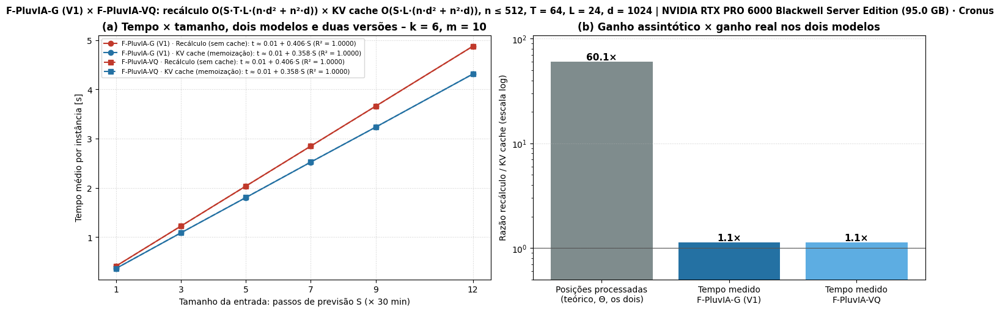

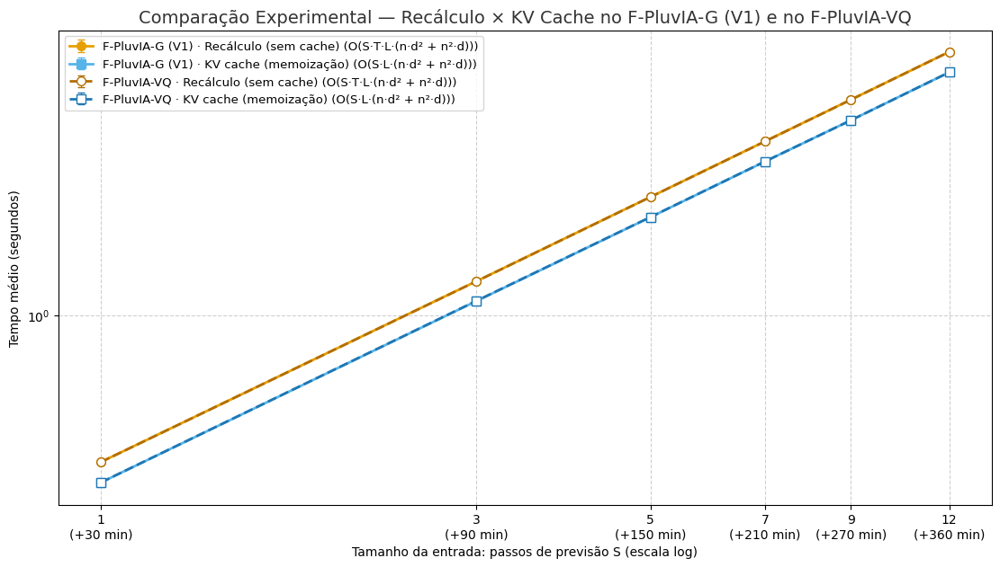

Tabela no formato do estudo de caso (divergências = previsões bf16 não idênticas; a correção é conferida em fp32, token a token, na seção 4):


,,Horizonte [min],Instâncias (m),Tempo médio recálculo [s],Desvio recálculo [s],Tempo médio KV cache [s],Desvio KV cache [s],Speedup (recálculo / KV),Divergências (bf16)
Modelo,Passos (S),,,,,,,,
F-PluvIA-G (V1),1,30,10,0.4139,0.0003,0.3659,0.0011,1.13,7
F-PluvIA-VQ,1,30,10,0.4138,0.0005,0.3660,0.0013,1.13,7
F-PluvIA-G (V1),3,90,10,1.2257,0.0007,1.0879,0.0015,1.13,9
F-PluvIA-VQ,3,90,10,1.2253,0.0002,1.0892,0.0026,1.12,10
F-PluvIA-G (V1),5,150,10,2.0366,0.0005,1.8037,0.0028,1.13,10
F-PluvIA-VQ,5,150,10,2.0362,0.0008,1.8048,0.0020,1.13,10
F-PluvIA-G (V1),7,210,10,2.8480,0.0010,2.5228,0.0072,1.13,10
F-PluvIA-VQ,7,210,10,2.8471,0.0010,2.5239,0.0047,1.13,10
F-PluvIA-G (V1),9,270,10,3.6581,0.0008,3.2324,0.0050,1.13,10


,,Horizonte [min],Instâncias (m),Tempo médio recálculo [s],Tempo médio KV cache [s],Desvio recálculo [s],Desvio KV cache [s],Speedup (recálculo / KV),Posições recálculo,Posições KV cache,TFLOP/s recálculo,TFLOP/s KV cache,Previsões idênticas (bf16),Divergências (bf16)
Modelo,Passos (S),,,,,,,,,,,,,
F-PluvIA-G (V1),1,30,10,0.4139,0.3659,0.0003,0.0011,1.13,30752,512,45.3,0.9,3/10,7
F-PluvIA-VQ,1,30,10,0.4138,0.3660,0.0005,0.0013,1.13,30752,512,45.3,0.9,3/10,7
F-PluvIA-G (V1),3,90,10,1.2257,1.0879,0.0007,0.0015,1.13,92256,1536,45.9,0.9,1/10,9
F-PluvIA-VQ,3,90,10,1.2253,1.0892,0.0002,0.0026,1.12,92256,1536,45.9,0.9,0/10,10
F-PluvIA-G (V1),5,150,10,2.0366,1.8037,0.0005,0.0028,1.13,153760,2560,46.0,0.9,0/10,10
F-PluvIA-VQ,5,150,10,2.0362,1.8048,0.0008,0.0020,1.13,153760,2560,46.1,0.9,0/10,10
F-PluvIA-G (V1),7,210,10,2.8480,2.5228,0.0010,0.0072,1.13,215264,3584,46.1,0.9,0/10,10
F-PluvIA-VQ,7,210,10,2.8471,2.5239,0.0010,0.0047,1.13,215264,3584,46.1,0.9,0/10,10
F-PluvIA-G (V1),9,270,10,3.6581,3.2324,0.0008,0.0050,1.13,276768,4608,46.1,0.9,0/10,10



Resumo do estudo de caso (decodificação gulosa, os dois modelos do duelo da Célula 13.7):
  • Arquitetura: os dois modelos têm o mesmo Transformer (304.93 M, L = 24, d = 1024) e a mesma VQGAN em formato; só os pesos mudam. Logo, a complexidade teórica é a mesma: recálculo O(S·T·L·(n·d² + n²·d)) e KV cache O(S·L·(n·d² + n²·d)), um fator T a menos.
  • F-PluvIA-G (V1): recálculo t ≈ 0.009 + 0.406·S s (R² = 1.0000, quadrático -0.0000); KV cache t ≈ 0.011 + 0.358·S s (R² = 1.0000, quadrático -0.0001); speedup médio 1.13×.
  • F-PluvIA-VQ: recálculo t ≈ 0.008 + 0.406·S s (R² = 1.0000, quadrático +0.0000); KV cache t ≈ 0.011 + 0.358·S s (R² = 1.0000, quadrático -0.0001); speedup médio 1.13×.
  • Custo por passo, F-PluvIA-VQ / F-PluvIA-G (V1): 1.000 (recálculo) e 1.000 (KV cache). Perto de 1 confirma que ajustar a VQGAN não muda o custo da previsão: o ganho de acerto do VQ vem sem custo de tempo.
  • Trabalho: 30.752 → 512 posições por quadro (60× menos); tempo: 1.13× (F-PluvIA-G (V1)) e 1.1

,Modelo,Conjunto,Janelas,Tempo médio sem cache (s),Tempo médio com KV cache (s),Aceleração (×),Janelas idênticas (%)
0,F-PluvIA-G (V1),2025,1729,1.631037,1.451741,1.123504,3.181029
1,F-PluvIA-G (V1),2026,2108,1.631290,1.449184,1.125661,2.988615
2,F-PluvIA-VQ,2025,1729,1.630627,1.443985,1.129255,7.981492
3,F-PluvIA-VQ,2026,2108,1.630411,1.450365,1.124138,9.629981


[Célula 13.7.1] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/tabela_complexidade_bigO_v1_vs_vq_G4_RTX6000_Blackwell_95GB_Cronus_VQ.csv
[Célula 13.7.1] Ajustes -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/tabela_ajustes_bigO_v1_vs_vq_G4_RTX6000_Blackwell_95GB_Cronus_VQ.csv
[Célula 13.7.1] Verificação -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/tabela_verificacao_kvcache_v1_vs_vq_G4_RTX6000_Blackwell_95GB_Cronus_VQ.csv
[Célula 13.7.1] Painel -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/painel_complexidade_bigO_v1_vs_vq_G4_RTX6000_Blackwell_95GB_Cronus_VQ.png
[Célula 13.7.1] Figura (estilo ANALG) -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/figura

In [ ]:
# @title
# Célula 13.7.1 (Cronus): Análise de Complexidade (Big O) dos dois modelos do duelo da Célula 13.7 — F-PluvIA-G (V1,
# VQGAN original) e F-PluvIA-VQ (VQGAN ajustada à RMF) — como estudo de caso comparativo entre duas implementações
# equivalentes do gerador guloso: recálculo integral (sem cache) × memoização das chaves e valores da atenção (KV cache).
# Metodologia do estudo de caso de Programação Dinâmica (Edit Distance, top-down com memoização × bottom-up) da disciplina
# ANALG 2051.1 IFCE Maracanaú Profº Thiago Alves: semente 42, k tamanhos sorteados e igualmente espaçados, m instâncias
# sorteadas e IGUAIS para os dois modelos e as duas versões, tempo médio por instância com perf_counter e verificação
# de correção com assert. Complementa a Célula 13.4 (que analisa só o F-PluvIA-G).
import math
import os
import random
import statistics
import time

import einops
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# ------------------------------------------------------------------- 1. parâmetros do experimento
SEED = 42                           # reprodutibilidade, como no estudo de caso
MIN_S, MAX_S = 1, 12                # intervalo dos tamanhos de entrada: passos de 30 min (+30 a +360 min)
K_RANGE = (6, 10)                   # nº de tamanhos distintos (sorteado)
M_RANGE = (10, 20)                  # nº de instâncias por tamanho (sorteado, o mesmo para todos os tamanhos)
CONTEXTO = 7                        # quadros observados, como nas Células 12 e 13.7
AQUECIMENTO = 2                     # execuções descartadas antes de medir (compilação de kernels na GPU)
TOL_EMPATE = 1e-3                   # diferença entre os 2 maiores logits abaixo da qual há empate numérico

faltam = [n for n in ('CRONUS', 'gpt8_v1', 'gpt8_vq', 'md_rmf') if n not in globals()]
if faltam or 'vq' not in globals().get('CRONUS', {}):
  raise RuntimeError('Rode antes a Célula 13.6 e a 13.7 (duelo) nesta sessão. '
                     f'Faltam: {", ".join(faltam) or "a execução VQ em CRONUS"}')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
SAIDA = CRONUS['vq']['results_dir']                       # mesma pasta do duelo (nada da V1 é sobrescrito)
TAG = CRONUS['vq']['env_tag']
os.makedirs(SAIDA, exist_ok=True)
MODELOS = {'F-PluvIA-G (V1)': gpt8_v1, 'F-PluvIA-VQ': gpt8_vq}
for _m in MODELOS.values():
  _m.eval()
DEVICE = next(gpt8_v1.parameters()).device
if DEVICE.type != 'cuda':
  print('[aviso] Os modelos estão na CPU: os tempos não representam a execução na GPU usada no artigo.')

# Mesma arquitetura nos dois modelos: a complexidade teórica é idêntica; só os pesos mudam.
_cfg = {nome: (int(m.transformer.config.n_layer), int(m.transformer.config.n_embd), int(m.transformer.config.block_size),
               sum(p.numel() for p in m.transformer.parameters()),
               sum(p.numel() for p in m.first_stage_model.parameters())) for nome, m in MODELOS.items()}
assert len(set(_cfg.values())) == 1, f'Os dois modelos deveriam ter a mesma arquitetura: {_cfg}'
L_CAM, D_LARG, BLOCK, P_TRANSFORMER, P_VQGAN = next(iter(_cfg.values()))
WS = int(math.sqrt(BLOCK // 8))                           # janela espacial em tokens (8 → 8×8 = 64 por quadro)
T_QUADRO = WS * WS
seqs = md_rmf.splits['test'].sequences_dbz                # teste de 2025, o conjunto que decide o duelo


def br(n) -> str:
  return f'{int(n):,}'.replace(',', '.')


def cronometro():
  if DEVICE.type == 'cuda':
    torch.cuda.synchronize()
  return time.perf_counter()


# ------------------------------------------------------------------- 2. as duas implementações (para qualquer modelo)
def _proximo_token(M, logits):
  """Mesma regra de predict_next_index com temperatura 1 e top-k 1 (decodificação gulosa)."""
  lg = M.top_k_logits(logits[:, -1, :] / 1.0, 1)
  _, res = torch.topk(F.softmax(lg, dim=-1), k=1, dim=-1)
  return res


def quadro_recalculo(M, ind_ctx, c_idx):
  """Versão 1, sem cache: o gerador original do pacote. Cada um dos T tokens do quadro
  reprocessa o contexto inteiro (condicionamento + quadros passados + tokens já gerados)."""
  return M.predict_next_frame_indices(ind_ctx, c_idx, WS, temperature=1.0, top_k=1, show_progress=False)


def quadro_kv_cache(M, ind_ctx, c_idx):
  """Versão 2, com memoização: o contexto passa uma única vez pelo Transformer e as chaves e valores
  de cada camada ficam guardados (KV cache); cada token novo processa só 1 posição."""
  TR = M.transformer
  b, _, h, w = ind_ctx.shape
  if (h, w) != (WS, WS):
    raise RuntimeError(f'O KV cache exige que a janela ({WS}×{WS}) cubra o quadro inteiro; quadro de {h}×{w} tokens.')
  prefixo = torch.cat((c_idx.reshape(b, -1), ind_ctx.reshape(b, -1)), dim=1)
  logits, _, cache = TR.forward_with_past(prefixo)
  n = prefixo.shape[1]
  tok = _proximo_token(M, logits)
  tokens = [tok]
  for _ in range(h * w - 1):
    logits, _, novo = TR.forward_with_past(tok, past=[cache], past_length=n)
    cache = torch.cat((cache, novo), dim=-2)                # o pacote devolve só k e v da posição nova
    n += 1
    tok = _proximo_token(M, logits)
    tokens.append(tok)
  return torch.cat(tokens, dim=1).reshape(b, h, w)


VERSOES = {'Recálculo (sem cache)': quadro_recalculo, 'KV cache (memoização)': quadro_kv_cache}


@torch.inference_mode()
def codificar(M, ctx_dbz):
  x = torch.tensor(np.clip(np.nan_to_num(ctx_dbz, nan=0.0), 0, 60) / 30.0 - 1.0, dtype=torch.float32, device=DEVICE)
  s = x.shape[0]
  xs = einops.rearrange(x, 's h w -> (s h) w')[None, None].contiguous()
  quant, idx = M.encode_to_z(xs)                          # cada modelo usa a SUA VQGAN (original ou ajustada)
  _, c_idx = M.encode_to_c(xs)
  qs = quant.shape
  return idx.reshape(qs[0], s, qs[2] // s, qs[3]), c_idx, qs


@torch.inference_mode()
def prever(M, ctx_dbz, passos: int, gerador):
  """Previsão completa de S passos (a mesma das Células 12 e 13.7): codifica, gera quadro a quadro com a janela
  deslizante dos últimos CONTEXTO quadros e decodifica cada quadro. Só o gerador de tokens muda."""
  ind, c_idx, qs = codificar(M, ctx_dbz)
  s, ih, iw = ind.shape[1], ind.shape[2], ind.shape[3]
  quadros = []
  for _ in range(passos):
    with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=DEVICE.type == 'cuda'):
      p = gerador(M, ind[:, -s:], c_idx)
    M.decode_to_img(p.reshape(1, -1), torch.Size([1, qs[1], ih, iw]))
    ind = torch.cat((ind, p[:, None]), dim=1)
    quadros.append(p)
  return torch.stack(quadros, dim=1)


@torch.inference_mode()
def verificar_token_a_token(M, ctx_dbz):
  """Verificação de correção em fp32, sem divergência em cascata: em cada um dos T tokens do quadro, as duas
  versões recebem o MESMO contexto e devem escolher o mesmo token (logits iguais a menos de arredondamento)."""
  TR = M.transformer
  ind, c_idx, _ = codificar(M, ctx_dbz)
  ind_ctx = ind[:, -CONTEXTO:]
  b = ind_ctx.shape[0]
  prefixo = torch.cat((c_idx.reshape(b, -1), ind_ctx.reshape(b, -1)), dim=1)
  logits_kv, _, cache = TR.forward_with_past(prefixo)
  n, gerados, dif_max, divergentes, empates = prefixo.shape[1], [], 0.0, 0, 0
  for t in range(T_QUADRO):
    contexto = torch.cat([prefixo] + gerados, dim=1)
    l_rc = TR(contexto)[0][:, -1, :].float()
    l_kv = logits_kv[:, -1, :].float()
    dif_max = max(dif_max, float((l_rc - l_kv).abs().max()))
    if int(l_rc.argmax(-1)) != int(l_kv.argmax(-1)):
      divergentes += 1
      top2 = l_rc.topk(2, dim=-1).values[0]
      empates += int(float(top2[0] - top2[1]) < TOL_EMPATE)
    tok = _proximo_token(M, logits_kv)
    gerados.append(tok)
    if t < T_QUADRO - 1:
      logits_kv, _, novo = TR.forward_with_past(tok, past=[cache], past_length=n)
      cache = torch.cat((cache, novo), dim=-2)
      n += 1
  return dif_max, divergentes, empates


# ------------------------------------------------------------------- 3. sorteio de k, m e dos tamanhos
random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
k = random.randint(*K_RANGE)                              # sorteia k
m = random.randint(*M_RANGE)                              # sorteia m (o mesmo para todos os tamanhos)
passo = (MAX_S - MIN_S) / (k - 1)                          # tamanhos igualmente espaçados
tamanhos = sorted({int(MIN_S + i * passo + 1e-9) for i in range(k)})
_amostra = np.clip(seqs[0, :CONTEXTO], 0, 60)
P0 = int(codificar(gpt8_v1, _amostra)[1].numel() + CONTEXTO * T_QUADRO)   # tokens do contexto antes do 1º token
POS_RC = T_QUADRO * P0 + T_QUADRO * (T_QUADRO - 1) // 2   # posições por quadro, recálculo: Σ (P0 + t)
POS_KV = P0 + T_QUADRO - 1                                 # posições por quadro, KV cache: P0 + (T − 1)
print(f'Arquitetura (idêntica nos dois modelos): Transformer {P_TRANSFORMER / 1e6:.2f} M de parâmetros, L = {L_CAM} '
      f'camadas, d = {D_LARG}, contexto máximo {BLOCK}, {T_QUADRO} tokens por quadro, {P0} tokens de contexto inicial | '
      f'VQGAN {P_VQGAN / 1e6:.2f} M')
print(f'Sorteio (semente {SEED}): k = {k} tamanhos {tamanhos}, m = {m} instâncias por tamanho, as MESMAS para os dois '
      f'modelos e as duas versões | posições por quadro: {br(POS_RC)} (recálculo) × {br(POS_KV)} (KV cache), '
      f'{POS_RC / POS_KV:.0f}× menos')

t0_total = time.perf_counter()

# ------------------------------------------------------------------- 4. verificação de correção (fp32, token a token)
_tf32 = (torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)
torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = False
janelas_verif = random.sample(range(len(seqs)), m)
verif = {}
try:
  for nome, M in MODELOS.items():
    verif[nome] = [verificar_token_a_token(M, np.clip(seqs[jv, :CONTEXTO], 0, 60)) for jv in janelas_verif]
finally:
  torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32 = _tf32
for nome, v in verif.items():
  dmax, ndiv, nemp = max(x[0] for x in v), sum(x[1] for x in v), sum(x[2] for x in v)
  assert ndiv == nemp, (f'{nome}: as versões divergem fora de empate numérico em {ndiv - nemp} de {m * T_QUADRO} '
                        'tokens: o KV cache não reproduz o recálculo.')
  print(f'Verificação (fp32) {nome}: {m} instâncias × {T_QUADRO} tokens, mesmo token em {m * T_QUADRO - ndiv} de '
        f'{m * T_QUADRO} ({nemp} empates numéricos), |Δ logit| máx. = {dmax:.2e}  OK')

# ------------------------------------------------------------------- 5. tempo médio por instância × tamanho
for _ in range(AQUECIMENTO):
  for M in MODELOS.values():
    for g in VERSOES.values():
      prever(M, _amostra, 1, g)

linhas = []
for S in tamanhos:
  janelas = random.sample(range(len(seqs)), m)            # *uma única* lista de instâncias para este tamanho
  totais = {(mod, ver): 0.0 for mod in MODELOS for ver in VERSOES}
  tempos = {(mod, ver): [] for mod in MODELOS for ver in VERSOES}   # por instância (média e desvio)
  identicos = {mod: 0 for mod in MODELOS}
  for j in janelas:                                       # os dois modelos e as duas versões sobre as MESMAS instâncias
    ctx = np.clip(seqs[j, :CONTEXTO], 0, 60)
    for mod, M in MODELOS.items():
      saidas = {}
      for ver, g in VERSOES.items():
        inicio = cronometro()
        saidas[ver] = prever(M, ctx, S, g)
        dt = cronometro() - inicio
        totais[(mod, ver)] += dt
        tempos[(mod, ver)].append(dt)
      identicos[mod] += int(torch.equal(*saidas.values()))
  for mod in MODELOS:
    t_rc, t_kv = (totais[(mod, ver)] / m for ver in VERSOES)
    linhas.append({'Ambiente_Execucao': ENV_LABEL, 'Modelo': mod, 'Passos (S)': S, 'Horizonte [min]': 30 * S,
                   'Instâncias (m)': m, 'Tempo médio recálculo [s]': round(t_rc, 4),
                   'Tempo médio KV cache [s]': round(t_kv, 4),
                   'Desvio recálculo [s]': round(statistics.pstdev(tempos[(mod, 'Recálculo (sem cache)')]), 4),
                   'Desvio KV cache [s]': round(statistics.pstdev(tempos[(mod, 'KV cache (memoização)')]), 4),
                   'Speedup (recálculo / KV)': round(t_rc / t_kv, 2),
                   'Posições recálculo': S * POS_RC, 'Posições KV cache': S * POS_KV,
                   'TFLOP/s recálculo': round(2 * P_TRANSFORMER * S * POS_RC / t_rc / 1e12, 1),
                   'TFLOP/s KV cache': round(2 * P_TRANSFORMER * S * POS_KV / t_kv / 1e12, 1),
                   'Previsões idênticas (bf16)': f'{identicos[mod]}/{m}',
                   'Divergências (bf16)': m - identicos[mod]})
  print(f'S = {S:2d} ({30 * S:3d} min)  OK  ' + ' | '.join(
      f'{mod}: recálculo {totais[(mod, "Recálculo (sem cache)")] / m:.3f} s, KV {totais[(mod, "KV cache (memoização)")] / m:.3f} s'
      f' ({totais[(mod, "Recálculo (sem cache)")] / totais[(mod, "KV cache (memoização)")]:.2f}×), idênticas {identicos[mod]}/{m}'
      for mod in MODELOS))
df = pd.DataFrame(linhas)

# Ajuste t = a + b·S para cada modelo e versão (O(S) em todos: a janela desliza e o contexto nunca passa de BLOCK)
COLS = {'Recálculo (sem cache)': 'Tempo médio recálculo [s]', 'KV cache (memoização)': 'Tempo médio KV cache [s]'}
ajustes = {}
for mod in MODELOS:
  sub = df[df['Modelo'] == mod]
  S_arr = sub['Passos (S)'].to_numpy(float)
  for ver, col in COLS.items():
    y = sub[col].to_numpy(float)
    b_, a_ = np.polyfit(S_arr, y, 1)
    r2 = 1 - np.sum((y - (a_ + b_ * S_arr)) ** 2) / np.sum((y - y.mean()) ** 2)
    ajustes[(mod, ver)] = (a_, b_, r2, np.polyfit(S_arr, y, 2)[0])
csv_path = os.path.join(SAIDA, f'tabela_complexidade_bigO_v1_vs_vq_{TAG}.csv')
df.to_csv(csv_path, index=False)
verif_path = os.path.join(SAIDA, f'tabela_verificacao_kvcache_v1_vs_vq_{TAG}.csv')
pd.DataFrame([{'Ambiente_Execucao': ENV_LABEL, 'Modelo': nome, 'Janela': jv, 'Tokens': T_QUADRO, 'Max |Δ logit|': x[0],
               'Tokens divergentes': x[1], 'Empates numéricos': x[2]}
              for nome, v in verif.items() for jv, x in zip(janelas_verif, v)]).to_csv(verif_path, index=False)
ajustes_path = os.path.join(SAIDA, f'tabela_ajustes_bigO_v1_vs_vq_{TAG}.csv')
pd.DataFrame([{'Modelo': mod, 'Versão': ver, 'a [s]': round(a, 4), 'b [s por passo]': round(b, 4), 'R²': round(r2, 5),
               'Termo quadrático': round(c2, 5)} for (mod, ver), (a, b, r2, c2) in ajustes.items()]
             ).to_csv(ajustes_path, index=False)

# ------------------------------------------------------------------- 6. painel
CORES = {'Recálculo (sem cache)': '#c0392b', 'KV cache (memoização)': '#2471a3'}
ESTILO = {'F-PluvIA-G (V1)': ('o', '-'), 'F-PluvIA-VQ': ('s', '--')}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
ax = axes[0]
xs_fit = np.linspace(0, max(tamanhos), 50)
for mod in MODELOS:
  sub = df[df['Modelo'] == mod]
  mk, ls = ESTILO[mod]
  for ver, col in COLS.items():
    a_, b_, r2, _ = ajustes[(mod, ver)]
    ax.plot(sub['Passos (S)'], sub[col], marker=mk, ls=ls, color=CORES[ver],
            label=f'{mod} · {ver}: t ≈ {a_:.2f} + {b_:.3f}·S (R² = {r2:.4f})')
ax.set_xlabel('Tamanho da entrada: passos de previsão S (× 30 min)')
ax.set_ylabel('Tempo médio por instância [s]')
ax.set_title(f'(a) Tempo × tamanho, dois modelos e duas versões – k = {k}, m = {m}', fontweight='bold')
ax.set_xticks(tamanhos)
ax.grid(True, ls=':', alpha=0.6)
ax.legend(fontsize=7.5)

ax = axes[1]
razao_pos = POS_RC / POS_KV
speed = {mod: float(df.loc[df['Modelo'] == mod, 'Speedup (recálculo / KV)'].mean()) for mod in MODELOS}
rotulos = ['Posições processadas\n(teórico, Θ, os dois)'] + [f'Tempo medido\n{mod}' for mod in MODELOS]
valores = [razao_pos] + list(speed.values())
barras = ax.bar(rotulos, valores, color=['#7f8c8d', '#2471a3', '#5dade2'])
for bar_, v in zip(barras, valores):
  ax.annotate(f'{v:.1f}×', (bar_.get_x() + bar_.get_width() / 2, v), ha='center', va='bottom',
              fontsize=11, fontweight='bold')
ax.set_yscale('log')
ax.set_ylim(min(0.5, min(speed.values()) / 2), razao_pos * 1.8)
ax.axhline(1, color='#555555', lw=0.8)
ax.set_ylabel('Razão recálculo / KV cache (escala log)')
ax.set_title('(b) Ganho assintótico × ganho real nos dois modelos', fontweight='bold')
ax.grid(True, axis='y', ls=':', alpha=0.6)
fig.suptitle(f'F-PluvIA-G (V1) × F-PluvIA-VQ: recálculo O(S·T·L·(n·d² + n²·d)) × KV cache O(S·L·(n·d² + n²·d)), '
             f'n ≤ {BLOCK}, T = {T_QUADRO}, L = {L_CAM}, d = {D_LARG} | {ENV_LABEL}', fontsize=10.5, fontweight='bold')
fig_path = os.path.join(SAIDA, f'painel_complexidade_bigO_v1_vs_vq_{TAG}.png')
fig.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()


# ------------------------------------------------------------------- 6b. gráfico no estilo do estudo de caso de ANALG
# Mesmo formato da Figura 1 do repositório ANALG-2025.2 (Comparação Experimental, eixos log-log, uma linha com
# marcador por versão e a ordem de complexidade na legenda), agora com as duas versões nos dois modelos.
ESTILO_ANALG = {
    ('F-PluvIA-G (V1)', 'Recálculo (sem cache)'): dict(color='#E69F00', marker='o', ls='-'),
    ('F-PluvIA-G (V1)', 'KV cache (memoização)'): dict(color='#56B4E9', marker='s', ls='-'),
    ('F-PluvIA-VQ', 'Recálculo (sem cache)'): dict(color='#B26E00', marker='o', ls='--', mfc='white'),
    ('F-PluvIA-VQ', 'KV cache (memoização)'): dict(color='#1F77B4', marker='s', ls='--', mfc='white'),
}
ORDEM = {'Recálculo (sem cache)': 'O(S·T·L·(n·d² + n²·d))', 'KV cache (memoização)': 'O(S·L·(n·d² + n²·d))'}
fig2, ax2 = plt.subplots(figsize=(11, 6.2), constrained_layout=True)
for mod in MODELOS:
  sub = df[df['Modelo'] == mod]
  for ver, col in COLS.items():
    desvio = sub['Desvio recálculo [s]' if ver.startswith('Recálculo') else 'Desvio KV cache [s]']
    ax2.errorbar(sub['Passos (S)'], sub[col], yerr=desvio, lw=2, ms=7, capsize=3, elinewidth=0.8,
                 label=f'{mod} · {ver} ({ORDEM[ver]})', **ESTILO_ANALG[(mod, ver)])
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xticks(tamanhos)
ax2.set_xticklabels([f'{S}\n(+{30 * S} min)' for S in tamanhos])
ax2.minorticks_off()
ax2.set_xlabel('Tamanho da entrada: passos de previsão S (escala log)')
ax2.set_ylabel('Tempo médio (segundos)')
ax2.set_title('Comparação Experimental — Recálculo × KV Cache no F-PluvIA-G (V1) e no F-PluvIA-VQ',
              fontsize=14, color='#333333')
ax2.grid(True, which='major', ls='--', alpha=0.6)
ax2.legend(fontsize=9.5, loc='upper left')
fig2_path = os.path.join(SAIDA, f'figura_comparacao_experimental_bigO_v1_vs_vq_{TAG}.png')
fig2.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()

# Tabela no mesmo formato da Tabela 1 do estudo de caso (média, desvio e divergências por tamanho)
TAB_ANALG = df[['Modelo', 'Passos (S)', 'Horizonte [min]', 'Instâncias (m)', 'Tempo médio recálculo [s]',
                'Desvio recálculo [s]', 'Tempo médio KV cache [s]', 'Desvio KV cache [s]', 'Speedup (recálculo / KV)',
                'Divergências (bf16)']].copy()
print('Tabela no formato do estudo de caso (divergências = previsões bf16 não idênticas; a correção é conferida '
      'em fp32, token a token, na seção 4):')
display(TAB_ANALG.set_index(['Modelo', 'Passos (S)']))

# ------------------------------------------------------------------- 7. resultados e discussão
display(df.drop(columns=['Ambiente_Execucao']).set_index(['Modelo', 'Passos (S)']))
t_total = time.perf_counter() - t0_total
print('\nResumo do estudo de caso (decodificação gulosa, os dois modelos do duelo da Célula 13.7):')
print(f'  • Arquitetura: os dois modelos têm o mesmo Transformer ({P_TRANSFORMER / 1e6:.2f} M, L = {L_CAM}, d = {D_LARG}) e a '
      'mesma VQGAN em formato; só os pesos mudam. Logo, a complexidade teórica é a mesma: recálculo '
      'O(S·T·L·(n·d² + n²·d)) e KV cache O(S·L·(n·d² + n²·d)), um fator T a menos.')
for mod in MODELOS:
  a_rc, b_rc, r2_rc, c2_rc = ajustes[(mod, 'Recálculo (sem cache)')]
  a_kv, b_kv, r2_kv, c2_kv = ajustes[(mod, 'KV cache (memoização)')]
  print(f'  • {mod}: recálculo t ≈ {a_rc:.3f} + {b_rc:.3f}·S s (R² = {r2_rc:.4f}, quadrático {c2_rc:+.4f}); '
        f'KV cache t ≈ {a_kv:.3f} + {b_kv:.3f}·S s (R² = {r2_kv:.4f}, quadrático {c2_kv:+.4f}); '
        f'speedup médio {speed[mod]:.2f}×.')
_rc = {mod: ajustes[(mod, 'Recálculo (sem cache)')][1] for mod in MODELOS}
_kv = {mod: ajustes[(mod, 'KV cache (memoização)')][1] for mod in MODELOS}
_m1, _m2 = list(MODELOS)
print(f'  • Custo por passo, {_m2} / {_m1}: {_rc[_m2] / _rc[_m1]:.3f} (recálculo) e {_kv[_m2] / _kv[_m1]:.3f} (KV cache). '
      'Perto de 1 confirma que ajustar a VQGAN não muda o custo da previsão: o ganho de acerto do VQ vem sem custo de tempo.')
print(f'  • Trabalho: {br(POS_RC)} → {br(POS_KV)} posições por quadro ({razao_pos:.0f}× menos); tempo: '
      + ' e '.join(f'{speed[mod]:.2f}× ({mod})' for mod in MODELOS)
      + '. A distância entre a razão teórica e a medida são as constantes: com lote 1, cada passagem de 1 token é '
        'limitada pelo lançamento de kernels e pela leitura dos pesos da memória, não pelos FLOPs.')
_tab_kv = globals().get('TAB_KV')
if isinstance(_tab_kv, pd.DataFrame) and len(_tab_kv):
  print('\nConferência com a Célula 13.7 (todas as janelas de 2025 e 2026, horizonte fixo de 4 passos):')
  display(_tab_kv[[c for c in ('Modelo', 'Conjunto', 'Janelas', 'Tempo médio sem cache (s)',
                                'Tempo médio com KV cache (s)', 'Aceleração (×)', 'Janelas idênticas (%)')
                   if c in _tab_kv.columns]])
else:
  print('\n(TAB_KV da Célula 13.7 não está na sessão: sem a conferência com todas as janelas.)')
print(f'[Célula 13.7.1] Tabela -> {csv_path}\n[Célula 13.7.1] Ajustes -> {ajustes_path}\n'
      f'[Célula 13.7.1] Verificação -> {verif_path}\n[Célula 13.7.1] Painel -> {fig_path}\n'
      f'[Célula 13.7.1] Figura (estilo ANALG) -> {fig2_path}\n'
      f'[Célula 13.7.1] Tempo total de execução: {t_total:.0f} s')


### 🎨 Célula Extra 1: Rastreabilidade do Código Original do GPTCast (`DSIP-FBK/GPTCast`, Franch et al., 2024)

Esta célula mostra **onde o notebook usa código da biblioteca original do GPTCast**. Cada nome que vem do pacote `gptcast` aparece com **texto vermelho (`#CC0000`) sobre fundo amarelo (`#FFEB3B`)**, mantendo a **paleta de sintaxe do editor do Colab** no resto do código.

* **Nomes lidos do próprio pacote**: a lista de nomes do GPTCast não é mais escrita à mão. A célula lê o código-fonte do `gptcast` instalado (sem importá-lo) e extrai módulos, classes, funções, métodos e atributos dos modelos.

* **Sem falsos positivos de nomes genéricos**: métodos com nomes comuns a outras bibliotecas (`encode`/`decode` de texto, `forward` do PyTorch, ganchos do Lightning, métodos do NumPy e do pandas) não são marcados. Variáveis do próprio notebook, como `gpt8`, também não. Elas são instâncias criadas aqui, não código do GPTCast.

* **Regras de destaque**:
  - módulos e nomes em linhas `import` / `from gptcast ...`;
  - nomes importados do `gptcast` quando usados depois, inclusive em outras células;
  - métodos e atributos específicos do modelo depois de um ponto (`.forecast`, `.encode_to_z`, `.first_stage_model`, `.load_from_zenodo`).

* **Alterações no original**: quando o notebook **reatribui** um nome do GPTCast (por exemplo `GPTCast.encode_to_z = ...` na Célula 4), o nome ganha uma **borda tracejada** e é listado na coluna "Reatribuídos no notebook".

* **Fonte das células**: a última execução de cada célula nesta sessão, identificada pelo rótulo `# Célula X:` da primeira linha. Para ler um arquivo `.ipynb`, defina `NOTEBOOK_PATH`.

* **Privacidade**: e-mails e valores atribuídos a senha, token ou chave aparecem como **[OCULTO]**. A saída desta célula fica gravada no `.ipynb`, no HTML do backup e no GitHub.

**Saídas**:
- painel HTML com o código de cada célula que usa o GPTCast (blocos recolhíveis);
- tabela-resumo por célula (ocorrências, nomes usados e nomes reatribuídos), gravada em `rastreabilidade_gptcast_por_celula_<ENV_TAG>.csv` dentro de `RESULTS_ENV_DIR`.

**Tempo**: menos de 1 segundo para o notebook inteiro. Use `MOSTRAR_CODIGO = False` para ver só a tabela.

In [ ]:
# @title
# Célula Extra 1: Rastreabilidade do Código Original do GPTCast (DSIP-FBK/GPTCast, Franch et al., 2024)
# Destaca, com texto vermelho (#CC0000) sobre fundo amarelo (#FFEB3B), cada nome que vem da biblioteca
# gptcast instalada, mantendo a paleta de sintaxe do editor do Colab. Os nomes são lidos do próprio
# pacote instalado (análise do código-fonte, sem importar nada), não de uma lista escrita à mão.
import ast
import builtins
import html
import importlib.util
import io
import os
import re
import time
import tokenize
import token as tok_mod
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

t_ini = time.perf_counter()
ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(globals().get('SERIES_CACHE_DIR', '/content'),
                                                               f'resultados_{ENV_TAG}'))
NOTEBOOK_PATH = None        # opcional: caminho de um .ipynb; se None, usa as células executadas nesta sessão
MOSTRAR_CODIGO = True       # False = só a tabela-resumo
COR_TEXTO, COR_FUNDO = '#CC0000', '#FFEB3B'


# ------------------------------------------------- 1. nomes do pacote gptcast instalado
def nomes_do_pacote(pacote: str = 'gptcast') -> dict:
  """Lê os .py do pacote e devolve módulos, classes/funções de topo e métodos/atributos das classes."""
  spec = importlib.util.find_spec(pacote)
  if spec is None or not spec.submodule_search_locations:
    raise RuntimeError('Pacote gptcast não encontrado. Rode a Célula 1 (instalação) antes.')
  raiz = Path(list(spec.submodule_search_locations)[0])
  modulos, topo, membros = {pacote}, set(), set()
  for py in raiz.rglob('*.py'):
    partes = py.relative_to(raiz.parent).with_suffix('').parts
    modulos.update(p for p in partes if p != '__init__')
    try:
      arvore = ast.parse(py.read_text(encoding='utf-8'))
    except (SyntaxError, UnicodeDecodeError):
      continue
    for no in arvore.body:
      if isinstance(no, (ast.FunctionDef, ast.ClassDef)) and not no.name.startswith('_'):
        topo.add(no.name)
      if isinstance(no, ast.ClassDef):
        for sub in ast.walk(no):
          if isinstance(sub, (ast.FunctionDef, ast.AsyncFunctionDef)) and not sub.name.startswith('_'):
            membros.add(sub.name)
          # atributos de instância só das classes de modelo (GPTCast, VAEGAN...), não de dados/utilitários
          if (py.parent.name == 'models' and isinstance(sub, ast.Attribute) and isinstance(sub.value, ast.Name)
              and sub.value.id == 'self' and isinstance(sub.ctx, ast.Store) and not sub.attr.startswith('_')):
            membros.add(sub.attr)
  # Métodos com nomes genéricos (str.encode, bytes.decode, forward do PyTorch, ganchos do Lightning)
  # não identificam o GPTCast quando aparecem depois de um ponto: ficam de fora.
  genericos = set(dir(str)) | set(dir(bytes)) | set(dir(dict)) | set(dir(list)) | set(dir(object))
  for mod, attr in (('torch.nn', 'Module'), ('torch', 'Tensor'), ('numpy', 'ndarray'), ('pandas', 'DataFrame'),
                    ('pandas', 'Series'), ('xarray', 'Dataset'), ('xarray', 'DataArray')):
    try:
      genericos |= set(dir(getattr(importlib.import_module(mod), attr)))
    except Exception:
      continue
  for mod in ('lightning.pytorch', 'pytorch_lightning'):
    try:
      genericos |= set(dir(importlib.import_module(mod).LightningModule))
      break
    except Exception:
      continue
  genericos |= {'forward', 'training_step', 'validation_step', 'test_step', 'configure_optimizers',
                'shared_step', 'get_input', 'log_images', 'hparams', 'config', 'model', 'models', 'data',
                'loss', 'name', 'params', 'state', 'utils', 'train', 'main', 'l', 'crop', 'seq_len', 'device', 'training'}
  return {'modulos': modulos, 'topo': topo, 'membros': membros - genericos, 'raiz': str(raiz)}


GPTCAST = nomes_do_pacote()


# ---------------------------------------------------------- 2. células a analisar
_ROTULO = re.compile(r'^#\s*(C[ée]lula\s+[^:\n]+)', re.M)


def _rotulo(src: str, padrao: str) -> str:
  m = _ROTULO.search(src)
  return m.group(1).strip() if m else padrao


def celulas() -> list:
  """Células desta sessão (última execução de cada uma, pelo rótulo '# Célula X:') ou de um .ipynb."""
  if NOTEBOOK_PATH:
    import json
    with open(NOTEBOOK_PATH, encoding='utf-8') as f:
      nb = json.load(f)
    out = []
    for i, c in enumerate(nb.get('cells', [])):
      if c.get('cell_type') == 'code':
        src = ''.join(c.get('source', [])) if isinstance(c.get('source'), list) else str(c.get('source', ''))
        if src.strip():
          out.append((_rotulo(src, f'Célula de código nº {i + 1}'), src))
    return out
  ip = get_ipython()
  hist = ip.user_ns.get('_ih', []) if ip is not None else []
  ultima = {}
  for i, src in enumerate(hist):
    if isinstance(src, str) and src.strip():
      ultima[_rotulo(src, f'Execução In[{i}] sem rótulo')] = (i, src)
  return [(k, s) for k, (i, s) in sorted(ultima.items(), key=lambda kv: kv[1][0])]


# ------------------------------------------- 3. privacidade: nada sensível vai para a saída
_EMAIL = re.compile(r'[\w.+-]+@[\w-]+(?:\.[\w-]+)+')
_SEGREDO = re.compile(r'''((?:pass(?:word)?|senha|pwd|token|secret|api_?key)\w*\s*=\s*)(['"])(.+?)\2''', re.I)


def ocultar(src: str) -> str:
  src = _SEGREDO.sub(lambda m: f'{m.group(1)}{m.group(2)}[OCULTO]{m.group(2)}', src)
  return _EMAIL.sub('[e-mail oculto]', src)


# -------------------------------------------------------------- 4. destaque sintático
KW_FLUXO = {'import', 'from', 'as', 'return', 'if', 'elif', 'else', 'for', 'while', 'try', 'except', 'finally',
            'with', 'raise', 'pass', 'break', 'continue', 'yield'}
KW_DECL = {'def', 'class', 'lambda', 'None', 'True', 'False', 'and', 'or', 'not', 'in', 'is', 'global',
           'nonlocal', 'assert', 'del', 'async', 'await', 'self', 'cls'}
BUILTINS = set(dir(builtins))


def importados_do_gptcast(src: str) -> set:
  """Nomes que a célula traz do gptcast (inclusive apelidos de 'as')."""
  nomes = set()
  try:
    arvore = ast.parse(src)
  except SyntaxError:
    arvore = None
  if arvore is not None:
    for no in ast.walk(arvore):
      if isinstance(no, ast.ImportFrom) and (no.module or '').split('.')[0] == 'gptcast':
        nomes.update(a.asname or a.name for a in no.names)
      elif isinstance(no, ast.Import):
        nomes.update((a.asname or a.name).split('.')[0] for a in no.names if a.name.split('.')[0] == 'gptcast')
  return nomes


def destacar(src: str, nomes_sessao: set) -> tuple:
  """Devolve (html, ocorrências, nomes encontrados, nomes do gptcast reatribuídos no notebook)."""
  linhas = src.splitlines(keepends=True)
  offs = [0]
  for ln in linhas:
    offs.append(offs[-1] + len(ln))
  partes, achados, alterados = [], [], set()
  pos, ant, ant2, linha_import, raiz_import = 0, '', '', False, ''
  toks = []
  try:
    toks = list(tokenize.generate_tokens(io.StringIO(src).readline))
  except (tokenize.TokenError, IndentationError, SyntaxError):
    pass                                           # células com %magic ou !shell: o resto fica sem cor
  for j, (tt, ts, (sr, sc), (er, ec), _) in enumerate(toks):
    if tt in (tok_mod.ENDMARKER, tok_mod.INDENT, tok_mod.DEDENT) or sr - 1 >= len(offs) - 1:
      continue
    if tt in (tok_mod.NEWLINE, tok_mod.NL):
      linha_import = False
    a, b = offs[sr - 1] + sc, offs[er - 1] + ec
    if a > pos:
      partes.append(html.escape(src[pos:a]))
    e = html.escape(ts)
    if tt == tok_mod.NAME:
      if linha_import and ant in ('from', 'import'):
        raiz_import = ts
      upstream = ((linha_import and raiz_import == 'gptcast' and (ts in GPTCAST['modulos'] or ts in GPTCAST['topo']))
                  or (ant not in ('.', 'def', 'class') and ts in nomes_sessao)
                  or (ant == '.' and (ts in GPTCAST['membros'] or (ant2 in nomes_sessao and ts in GPTCAST['topo']))))
      if ts in ('import', 'from') and ant == '':
        linha_import, raiz_import = True, ''
      if upstream:
        prox = toks[j + 1][1] if j + 1 < len(toks) else ''
        if ant == '.' and ant2 in nomes_sessao and prox == '=':
          alterados.add(f'{ant2}.{ts}')
          partes.append(f'<span class="gc-up gc-mod" title="nome do GPTCast reatribuído neste notebook">{e}</span>')
        else:
          partes.append(f'<span class="gc-up">{e}</span>')
        achados.append(ts)
      elif ts in KW_FLUXO:
        partes.append(f'<span class="k-fl">{e}</span>')
      elif ts in KW_DECL:
        partes.append(f'<span class="k-dc">{e}</span>')
      elif ant == 'class':
        partes.append(f'<span class="k-cl">{e}</span>')
      elif ant == 'def' or ts in BUILTINS:
        partes.append(f'<span class="k-fn">{e}</span>')
      else:
        partes.append(e)
    elif tt == tok_mod.COMMENT:
      partes.append(f'<span class="k-cm">{e}</span>')
    elif tt == tok_mod.STRING:
      partes.append(f'<span class="k-st">{e}</span>')
    elif tt == tok_mod.NUMBER:
      partes.append(f'<span class="k-nu">{e}</span>')
    else:
      partes.append(e)
    pos = b
    if tt not in (tok_mod.NL, tok_mod.NEWLINE, tok_mod.COMMENT):
      ant2, ant = ant, ts
    if tt in (tok_mod.NEWLINE, tok_mod.NL):
      ant2, ant = '', ''
  if pos < len(src):
    partes.append(html.escape(src[pos:]))
  return ''.join(partes), len(achados), sorted(set(achados)), sorted(alterados)


# --------------------------------------------------------------------- 5. execução
cels = [(r, ocultar(s)) for r, s in celulas() if not r.lower().startswith(('célula extra 1', 'celula extra 1'))]
nomes_sessao = {'gptcast'}
for _, s in cels:
  nomes_sessao |= importados_do_gptcast(s)

linhas_tab, blocos, total = [], [], 0
for rot, src in cels:
  h, n, uniq, alt = destacar(src, nomes_sessao)
  if n == 0:
    continue
  total += n
  linhas_tab.append({'Célula': rot, 'Ocorrências': n, 'Nomes do GPTCast usados': ', '.join(uniq),
                     'Reatribuídos no notebook': ', '.join(alt)})
  if MOSTRAR_CODIGO:
    badges = ' '.join(f'<span class="gc-badge">{html.escape(t)}</span>' for t in uniq)
    aviso = (f'<div class="gc-bar">Reatribuídos aqui (o notebook altera o original): '
             f'{", ".join(html.escape(a) for a in alt)}</div>') if alt else ''
    blocos.append(f'<details class="gc-box"><summary class="gc-head"><span>📄 <b>{html.escape(rot)}</b></span>'
                  f'<span class="gc-count">{n} ocorrências</span></summary>'
                  f'<div class="gc-bar">Nomes do GPTCast: {badges}</div>{aviso}'
                  f'<pre class="gc-code"><code>{h}</code></pre></details>')

df_rastro = pd.DataFrame(linhas_tab)
os.makedirs(RESULTS_ENV_DIR, exist_ok=True)
csv = os.path.join(RESULTS_ENV_DIR, f'rastreabilidade_gptcast_por_celula_{ENV_TAG}.csv')
df_rastro.to_csv(csv, index=False)
ms = (time.perf_counter() - t_ini) * 1000

CSS = f"""<style>
.gc-wrap{{font-family:'JetBrains Mono','Fira Code',Consolas,monospace;background:#1e1e1e;color:#d4d4d4;
  border:1px solid #333;border-radius:8px;padding:14px;margin-top:6px}}
.gc-title{{font-size:13.5px;font-weight:bold;color:#fff;border-bottom:1px solid #333;padding-bottom:9px;
  margin-bottom:10px;display:flex;justify-content:space-between;gap:12px;flex-wrap:wrap}}
.k-cm{{color:#6a9955;font-style:italic}} .k-fl{{color:#c586c0;font-weight:600}} .k-dc{{color:#569cd6;font-weight:600}}
.k-fn{{color:#dcdcaa}} .k-cl{{color:#4ec9b0}} .k-st{{color:#ce9178}} .k-nu{{color:#b5cea8}}
.gc-up{{color:{COR_TEXTO}!important;background:{COR_FUNDO}!important;font-weight:800;padding:0 3px;border-radius:2px}}
.gc-mod{{outline:2px dashed {COR_TEXTO};outline-offset:1px}}
.gc-badge,.gc-count{{display:inline-block;background:{COR_FUNDO};color:{COR_TEXTO};border:1px solid {COR_TEXTO};
  border-radius:4px;padding:1px 6px;margin:2px;font-size:11px;font-weight:800}}
.gc-box{{background:#252526;border:1px solid #3c3c3c;border-radius:6px;margin-bottom:9px;overflow:hidden}}
.gc-head{{cursor:pointer;padding:7px 12px;background:#2d2d30;font-size:12.5px;display:flex;justify-content:space-between}}
.gc-bar{{padding:5px 12px;background:#1e1e1e;border-bottom:1px solid #333;font-size:11.5px;color:#9cdcfe}}
.gc-code{{margin:0;padding:12px;font-size:12px;line-height:1.55;overflow-x:auto;background:#1e1e1e;color:#d4d4d4}}
</style>"""
fonte = 'arquivo ' + os.path.basename(NOTEBOOK_PATH) if NOTEBOOK_PATH else 'células executadas nesta sessão'
corpo = ''.join(blocos) if blocos else ('<p>Nenhuma célula com nomes do GPTCast. Execute as células do notebook '
                                        'ou defina NOTEBOOK_PATH.</p>' if not linhas_tab else '')
display(HTML(f'{CSS}<div class="gc-wrap"><div class="gc-title"><span>🔍 Código original '
             f'<span class="gc-badge">DSIP-FBK/GPTCast</span> no notebook ({fonte})</span>'
             f'<span class="gc-count">{total} ocorrências em {len(linhas_tab)} células · {ms:.0f} ms</span></div>'
             f'{corpo}</div>'))
print(f'[Célula Extra 1] Nomes lidos do pacote em {GPTCAST["raiz"]}: {len(GPTCAST["modulos"])} módulos, '
      f'{len(GPTCAST["topo"])} classes/funções, {len(GPTCAST["membros"])} métodos/atributos específicos.')
print('[Célula Extra 1] E-mails e valores atribuídos a senha/token/chave aparecem como [OCULTO] na saída.')
display(df_rastro.set_index('Célula') if len(df_rastro) else df_rastro)
print(f'[Célula Extra 1] Tabela -> {csv}')


[Célula Extra 1] Nomes lidos do pacote em /content/GPTCast/gptcast: 24 módulos, 73 classes/funções, 50 métodos/atributos específicos.
[Célula Extra 1] E-mails e valores atribuídos a senha/token/chave aparecem como [OCULTO] na saída.


,Ocorrências,Nomes do GPTCast usados,Reatribuídos no notebook
Célula,,,
Célula 4,26,"GPTCast, base_learning_rate, converters, dbz_t...",GPTCast.encode_to_z
Célula 4.6 (Cronus),20,"LPIPS, components, discriminator, first_stage_...",
Célula 4.7 (Cronus),11,"GPTCast, base_learning_rate, first_stage_model...",
Célula 4.8 (Cronus),11,"converters, dbz_to_rainfall, decode_to_img, en...",
Célula (Activates Checkpoint),4,"first_stage_model, transformer",
Célula 5,5,"converters, dbz_to_rainfall, gptcast, utils",
Célula 6,6,"converters, dbz_to_rainfall, first_stage_model...",
Célula 7,6,"_d2r, converters, dbz_to_rainfall, gptcast, utils",
Célula 8,5,"converters, dbz_to_rainfall, gptcast, utils",


[Célula Extra 1] Tabela -> /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/rastreabilidade_gptcast_por_celula_G4_RTX6000_Blackwell_95GB_Cronus_VQ.csv
Error in callback <function _depois_celula at 0x7b68a9b7b240> (for post_run_cell):


AttributeError: 'str' object has no attribute 'DictWriter'

# ⚙️⚙️ Célula auxiliar (Cronus - Retomada do Fechamento, Somente Leitura)

* **Quando usar**: se o ambiente de execução cair depois da Célula 13.7 e antes do fechamento. As Células 13.6 e 13.7 deixam na sessão as variáveis que a Extra 2, o Deploy, o Backup e o Encerramento usam, e uma desconexão apaga tudo.

* **O que faz**: refaz essas variáveis a partir do que já está no Drive, sem carregar modelos e sem usar a GPU:
  - `ENV_TAG` e `RESULTS_ENV_DIR` apontando para a pasta do F-PluvIA-VQ (`_VQ`), como depois da Célula 13.6;
  - o dicionário `CRONUS`, com as pastas de resultados da V1 e do VQ;
  - `CRONUS_PASTAS_RESULTADOS` e `CRONUS_PASTAS_EXTRAS`, para o Deploy e o Backup levarem também a pasta da V1;
  - `CELL13_7_DUELO`, lido do resumo `cronus_duelo_resumo_<ENV_TAG>.json`;
  - os caminhos da VQGAN ajustada e do registro do F-PluvIA-VQ, para a conferência do Encerramento.

* **Somente leitura**: não grava, não move e não apaga nada. Se faltar alguma pasta ou arquivo, para e lista o que não encontrou.

* **Etiqueta fixa**: usa a etiqueta da execução que treinou e testou os modelos (`G4_RTX6000_Blackwell_95GB_Cronus`), então funciona mesmo que o Colab entregue outra GPU ou só CPU.

* **Limite**: sem os modelos em memória, o manifesto da Extra 2 sai sem a impressão digital do Transformer. Os arquivos `.ckpt` continuam com o SHA-256 listado no manifesto.

* **Ordem**: Células 0 e 1 → esta célula → Ctrl+S → Full UMLs → Extra 2 → Ctrl+S → Pseudo-vista → Ctrl+S → Deploy (primeiro com `SO_PREPARAR=True`) → Backup → Encerramento.

In [2]:
# @title
# Célula auxiliar (Cronus - Retomada do Fechamento, Somente Leitura): refaz, sem carregar modelos nem usar a GPU,
# as variáveis que as Células 13.6 e 13.7 deixam para as Células Full UMLs, Extra 2, Pseudo-vista, Deploy, Backup e
# Encerramento, depois que o ambiente de execução foi desconectado. Só lê o Drive: não grava, não move e não apaga
# nada. Rode depois das Células 0 e 1.
import os, json

# Etiqueta da execução Cronus que treinou e testou os modelos (G4). Fica fixa para a célula funcionar em qualquer
# GPU ou na CPU: a Célula 1 daria outra etiqueta se o Colab entregasse outro acelerador.
ENV_TAG_BASE = 'G4_RTX6000_Blackwell_95GB_Cronus'

faltam = [n for n in ('SERIES_CACHE_DIR', 'CHECKPOINTS_DIR', 'BASE_WORK_DIR') if n not in globals()]
if faltam:
  raise RuntimeError(f'Rode antes as Células 0 e 1. Faltam: {", ".join(faltam)}')
if 'GPTCast_RMF_Cronus' not in BASE_WORK_DIR:
  raise RuntimeError(f'BASE_WORK_DIR aponta para {BASE_WORK_DIR}; esta célula só serve ao ambiente Cronus.')
if globals().get('CRONUS', {}).get('ativo') == 'vq' and 'CRONUS_PASTAS_RESULTADOS' in globals():
  print('[Retomada] As variáveis do fechamento já existem nesta sessão; nada a fazer.')
else:
  if globals().get('ENV_TAG') != ENV_TAG_BASE:
    print(f'[Retomada] A Célula 1 deu a etiqueta {globals().get("ENV_TAG")}; usando a da execução: {ENV_TAG_BASE}.')

  tag_v1, tag_vq = ENV_TAG_BASE, f'{ENV_TAG_BASE}_VQ'
  ckpt_dir = os.path.join(CHECKPOINTS_DIR, tag_v1)
  res_v1 = os.path.join(SERIES_CACHE_DIR, f'resultados_{tag_v1}')
  res_vq = os.path.join(SERIES_CACHE_DIR, f'resultados_{tag_vq}')
  ARQ_MELHOR = os.path.join(ckpt_dir, 'vqgan_rmf', f'vqgan_rmf_2km_{tag_v1}_melhor.pt')
  REGISTRO_VQT = os.path.join(ckpt_dir, 'fpluvia_vq', f'registro_treino_fpluvia_vq_{tag_v1}.json')
  resumo_duelo = os.path.join(res_vq, f'cronus_duelo_resumo_{tag_vq}.json')

  exigidos = {'Resultados da V1': res_v1, 'Resultados do F-PluvIA-VQ': res_vq,
              'VQGAN ajustada (Célula 4.6)': ARQ_MELHOR, 'Registro do F-PluvIA-VQ (Célula 4.7)': REGISTRO_VQT,
              'Resumo do duelo (Célula 13.7)': resumo_duelo}
  ausentes = [f'{k}: {v}' for k, v in exigidos.items() if not os.path.exists(v)]
  if ausentes:
    raise RuntimeError('Não encontrado no Drive (nada foi alterado):\n  - ' + '\n  - '.join(ausentes))

  with open(REGISTRO_VQT) as f:
    best_ckpt_path_vq = os.path.join(ckpt_dir, 'fpluvia_vq', json.load(f)['checkpoint'])
  with open(resumo_duelo) as f:
    CELL13_7_DUELO = json.load(f)

  # Mesmo estado que as Células 13.6 e 13.7 deixam na sessão (modelo ativo: F-PluvIA-VQ)
  CRONUS = {'ativo': 'vq',
            'v1': {'env_tag': tag_v1, 'results_dir': res_v1},
            'vq': {'env_tag': tag_vq, 'results_dir': res_vq, 'checkpoint': os.path.basename(best_ckpt_path_vq)}}
  ENV_TAG, RESULTS_ENV_DIR, CHECKPOINTS_ENV_DIR = tag_vq, res_vq, ckpt_dir
  best_ckpt_path = best_ckpt_path_vq
  CRONUS_PASTAS_RESULTADOS = {tag_v1: res_v1}
  CRONUS_PASTAS_EXTRAS = {f'resultados_{tag_v1}': res_v1}

  print('=== Retomada do fechamento (somente leitura) ===')
  print(f'ENV_TAG ativo:   {ENV_TAG}')
  print(f'Resultados V1:   {res_v1}')
  print(f'Resultados VQ:   {res_vq}')
  print(f'Checkpoint VQ:   {os.path.basename(best_ckpt_path_vq)} '
        f'({"encontrado" if os.path.exists(best_ckpt_path_vq) else "NÃO encontrado"})')
  print(f'Vencedor (2025): {CELL13_7_DUELO.get("vencedor_2025")}')
  print('Modelos não foram carregados: o manifesto da Extra 2 sai sem a impressão digital do Transformer em memória, '
        'mas os arquivos .ckpt continuam com o SHA-256 listado.')
  print('\nAgora: Ctrl+S → Full UMLs → Extra 2 → Ctrl+S → Pseudo-vista → Ctrl+S → Deploy (SO_PREPARAR=True) '
        '→ Deploy → Backup → Encerramento.')


=== Retomada do fechamento (somente leitura) ===
ENV_TAG ativo:   G4_RTX6000_Blackwell_95GB_Cronus_VQ
Resultados V1:   /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus
Resultados VQ:   /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ
Checkpoint VQ:   fpluvia_vq_rmf_2km_G4_RTX6000_Blackwell_95GB_Cronus_20261123T0717Z_best-00-4.8038.ckpt (encontrado)
Vencedor (2025): F-PluvIA-VQ
Modelos não foram carregados: o manifesto da Extra 2 sai sem a impressão digital do Transformer em memória, mas os arquivos .ckpt continuam com o SHA-256 listado.

Agora: Ctrl+S → Full UMLs → Extra 2 → Ctrl+S → Pseudo-vista → Ctrl+S → Deploy (SO_PREPARAR=True) → Deploy → Backup → Encerramento.


# 🧩 Célula Full UMLs: Diagramas UML Gerados do Código de Cada Célula

Esta célula lê o **notebook salvo** e gera, sem executar nenhum modelo, os **diagramas UML** de cada célula de código e um diagrama do **fluxo de dados entre as células**. O objetivo é facilitar a leitura do trabalho: mostrar o que cada célula cria, o que ela recebe das anteriores e como o pipeline se encadeia da ingestão ao Deploy.

## 1. Como Funciona

* **Leitura**: abre o `.ipynb` salvo no Drive e considera cada célula de código com o rótulo `# Célula X:`. Se a mesma célula aparecer duas vezes, vale a última versão.
* **Análise estática**: cada célula é lida com o módulo `ast` do Python, sem executar nada. Comandos do Colab (`!pip`, `%cd`) são ignorados.
* **Desenho**: os diagramas são escritos em **Graphviz** (`.dot`) e convertidos em **PNG** e **SVG**. Se o Graphviz não estiver instalado, a célula o instala; se a instalação falhar, grava só os `.dot`.
* **Custo**: roda em **CPU**, em poucos segundos. Não depende de GPU nem de outras células desta sessão.

## 2. O que é Gerado

| Arquivo | Conteúdo |
|---|---|
| `00_fluxo_entre_celulas` | **Diagrama de componentes** do pipeline: cada célula é um componente, e uma seta indica que a célula de destino usa variáveis criadas na de origem. Variáveis de configuração lidas por quase todas as células (`ENV_TAG`, `SERIES_CACHE_DIR` etc.) ficam numa nota à parte, para não poluir o desenho. |
| `celulas/NN_celula_X` | **Diagrama de classes** de cada célula: a célula como um módulo «célula», com as variáveis que deixa disponíveis e as funções que define; as **classes** que ela define, com atributos, métodos e herança; as **bibliotecas** importadas; as variáveis que **usa de outras células**; e os **arquivos** que cita. |
| `README.md` | Índice com o diagrama de fluxo, uma tabela com linhas, classes, funções e bibliotecas de cada célula e a legenda da notação. |

Todos os arquivos ficam em `SERIES_CACHE_DIR/diagramas_uml/`, e a pasta inteira é regravada a cada execução.

## 3. Notação

* **«célula»**: 1º compartimento com as variáveis produzidas (`+`); 2º com as funções (`+` pública, `-` interna, começando com `_`).
* **«classe»**: atributos e métodos; **losango** = a célula define a classe; **triângulo vazado** = herança.
* **Setas tracejadas**: `«import»` para bibliotecas e `«use»` para variáveis recebidas de outras células.

## 4. Limites

* **Leitura estática**: a análise estática identifica nomes, não valores. Uma variável criada dentro de um `exec` ou de outro mecanismo dinâmico pode não aparecer.

## 5. Ordem de Execução

**Ctrl+S → Célula Full UMLs → Célula Extra 2 → Ctrl+S → Célula Base (Pseudo-vista) → Ctrl+S → Deploy → Backup.**

Rode esta célula **antes da Extra 2**, para que os diagramas entrem no manifesto SHA-256. O **Deploy** publica a pasta em `docs/uml/` no repositório.

In [8]:
# @title
# Célula Full UMLs: Diagramas UML Gerados do Código de Cada Célula — classes, operações, variáveis produzidas,
# bibliotecas usadas e o fluxo de dados entre as células, lidos do notebook salvo (CTRL+S :necessita salvar o ambiente da execusão dessa célula).
import ast
import builtins
import html
import io
import json
import os
import re
import shutil
import subprocess
import tokenize
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

# ------------------------------------------------------------------- 1. configuração
NOTEBOOK_NAME = 'exec_Cronus_F_PluvIA_VQGAN_RMF.ipynb'   # Cronus (V1: Model_Annual_Full_Training_Series_TCC2_-_2026_2_-_RAUL_SANTIAGO_PINHEIRO.ipynb)
NOTEBOOK_PATH = globals().get('DETECTED_NB_PATH')          # se None, procura NOTEBOOK_NAME no Drive
SERIES_CACHE_DIR = globals().get('SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
UML_DIR = Path(SERIES_CACHE_DIR) / 'diagramas_uml'        # o Deploy publica esta pasta em docs/uml/
FORMATOS = ('png', 'svg')
MAX_ITENS = 14                                             # itens por compartimento antes de resumir em "+ N"
FRACAO_CONFIG = 0.5                                        # variável lida por >= 50% das células = configuração global
FONTE = 'Helvetica'

if not (NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH)):
  for cand in (Path('/content/drive/MyDrive/Colab Notebooks') / NOTEBOOK_NAME, Path('/content/drive/MyDrive') / NOTEBOOK_NAME):
    if cand.is_file():
      NOTEBOOK_PATH = str(cand)
      break
if not (NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH)):
  raise FileNotFoundError('Notebook salvo não encontrado: salve com Ctrl+S ou defina DETECTED_NB_PATH.')

# ------------------------------------------------------------------- 2. Graphviz
if not shutil.which('dot'):
  print('Instalando o Graphviz ...')
  subprocess.run('apt-get -qq install -y graphviz > /dev/null 2>&1', shell=True)
TEM_DOT = bool(shutil.which('dot'))
if not TEM_DOT:
  print('  [aviso] Graphviz indisponível: os diagramas serão gravados só como .dot (texto).')

if UML_DIR.is_dir():                                       # cada execução regrava o conjunto inteiro
  shutil.rmtree(UML_DIR)
(UML_DIR / 'celulas').mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------- 3. leitura das células
_ROTULO = re.compile(r'^#\s*(?:@title\s*#\s*)?C[ée]lula\s+([^:\n]+)', re.M)
fontes = [''.join(c.get('source', [])) for c in json.loads(Path(NOTEBOOK_PATH).read_text(encoding='utf-8'))['cells']
          if c.get('cell_type') == 'code']
celulas = {}                                               # rótulo -> (posição, código); vale a última versão
for pos, src in enumerate(fontes):
  m = _ROTULO.search(src or '')
  if m:
    celulas[m.group(1).strip()] = (pos, src)
ordem = sorted(celulas, key=lambda r: celulas[r][0])


def slug(rotulo: str) -> str:
  return re.sub(r'[^0-9A-Za-z]+', '_', unicodedata.normalize('NFKD', rotulo.lower())
                .encode('ascii', 'ignore').decode()).strip('_')[:40].rstrip('_')


def sem_magicas(src: str) -> str:
  """Converte comandos do Colab (!pip, %cd, x = !ls) em Python puro, como o próprio IPython faz."""
  try:
    from IPython.core.inputtransformer2 import TransformerManager
    return TransformerManager().transform_cell(src)
  except Exception:
    pass
  linhas, aceitas = [], []                                 # alternativa: comando só fora de parênteses e de textos

  def dentro_de_expressao(texto: str) -> bool:
    prof = 0
    try:
      for tok in tokenize.generate_tokens(io.StringIO(texto).readline):
        if tok.type == tokenize.OP and tok.string in '([{':
          prof += 1
        elif tok.type == tokenize.OP and tok.string in ')]}':
          prof -= 1
    except tokenize.TokenError as e:
      return 'string' in str(e) or prof > 0
    except (IndentationError, SyntaxError):
      pass
    return prof > 0

  for ln in src.split('\n'):
    t = ln.lstrip()
    if (t.startswith(('!', '%')) or re.match(r'^[\w\s,]+=\s*!', t)) and not dentro_de_expressao('\n'.join(aceitas) + '\n'):
      linhas.append(ln[:len(ln) - len(t)] + 'pass  # ' + t)
    else:
      linhas.append(ln)
      aceitas.append(ln)
  return '\n'.join(linhas)


# ------------------------------------------------------------------- 4. análise de cada célula (ast)
BUILTINS = set(dir(builtins)) | {'get_ipython', 'display', '__file__', '__name__'}
_ARQ_NOME = re.compile(r'^[\w\-.{}%*]{3,80}\.(csv|png|pdf|json|npz|npy|pt|pth|ckpt|md|txt|zip|html|nc4|h5)$', re.I)


def assinatura(fn) -> str:
  a = [x.arg for x in fn.args.posonlyargs + fn.args.args if x.arg not in ('self', 'cls')]
  if fn.args.vararg:
    a.append('*' + fn.args.vararg.arg)
  a += [x.arg for x in fn.args.kwonlyargs]
  if fn.args.kwarg:
    a.append('**' + fn.args.kwarg.arg)
  txt = ', '.join(a)
  return f"{fn.name}({txt if len(txt) <= 38 else txt[:35] + '…'})"


def nome_base(b) -> str:
  try:
    return ast.unparse(b)
  except Exception:
    return '?'


def alvos(no):
  if isinstance(no, ast.Name):
    yield no.id
  elif isinstance(no, (ast.Tuple, ast.List)):
    for e in no.elts:
      yield from alvos(e)
  elif isinstance(no, ast.Starred):
    yield from alvos(no.value)


def releitura(valor):
  """Devolve 'X' se valor for globals().get('X', ...) ou globals()['X'], senão None."""
  if isinstance(valor, ast.Call) and isinstance(valor.func, ast.Attribute) and valor.func.attr == 'get' \
      and isinstance(valor.func.value, ast.Call) and getattr(valor.func.value.func, 'id', '') == 'globals' \
      and valor.args and isinstance(valor.args[0], ast.Constant):
    return valor.args[0].value
  return None


def analisar(src: str) -> dict:
  info = {'linhas': src.count('\n') + 1, 'imports': set(), 'classes': [], 'funcoes': [], 'produz': set(),
          'le': set(), 'arquivos': set(), 'chamadas': defaultdict(set), 'erro': None}
  try:
    arv = ast.parse(sem_magicas(src))
  except SyntaxError as e:
    info['erro'] = f'linha {e.lineno}: {e.msg}'
    return info
  locais = set()
  for no in ast.walk(arv):
    if isinstance(no, ast.Import):
      for a in no.names:
        info['imports'].add(a.name.split('.')[0])
        locais.add((a.asname or a.name).split('.')[0])
    elif isinstance(no, ast.ImportFrom) and no.module and not no.level:
      info['imports'].add(no.module.split('.')[0])
      locais.update(a.asname or a.name for a in no.names)
    elif isinstance(no, (ast.FunctionDef, ast.AsyncFunctionDef, ast.Lambda)):
      args = no.args
      locais.update(x.arg for x in args.posonlyargs + args.args + args.kwonlyargs)
      locais.update(x.arg for x in (args.vararg, args.kwarg) if x)
    elif isinstance(no, ast.comprehension):
      locais.update(alvos(no.target))
    elif isinstance(no, ast.ExceptHandler) and no.name:
      locais.add(no.name)
    elif isinstance(no, ast.Constant) and isinstance(no.value, str) and _ARQ_NOME.match(os.path.basename(no.value.strip())):
      info['arquivos'].add(os.path.basename(no.value.strip()))
    elif isinstance(no, ast.Call) and isinstance(no.func, ast.Attribute) and no.func.attr == 'get' \
        and isinstance(no.func.value, ast.Call) and getattr(no.func.value.func, 'id', '') == 'globals' \
        and no.args and isinstance(no.args[0], ast.Constant) and isinstance(no.args[0].value, str):
      info['le'].add(no.args[0].value)                      # globals().get('NOME', ...)
  # nomes produzidos no nível da célula (fora de funções e classes)
  def nivel_superior(corpo):
    for st in corpo:
      if isinstance(st, (ast.FunctionDef, ast.AsyncFunctionDef)):
        info['funcoes'].append(st)
        info['produz'].add(st.name)
      elif isinstance(st, ast.ClassDef):
        info['classes'].append(st)
        info['produz'].add(st.name)
      else:
        for no in ast.walk(st):
          if isinstance(no, (ast.Assign, ast.AnnAssign, ast.AugAssign)):
            for t in (no.targets if isinstance(no, ast.Assign) else [no.target]):
              nomes = set(alvos(t))
              if releitura(no.value) in nomes:                # X = globals().get('X', ...) só relê X
                nomes.discard(releitura(no.value))
              info['produz'].update(nomes)
          elif isinstance(no, (ast.For, ast.AsyncFor, ast.withitem)):
            alvo = no.target if isinstance(no, (ast.For, ast.AsyncFor)) else no.optional_vars
            if alvo is not None:
              locais.update(alvos(alvo))                    # variáveis de laço não contam como produto
          elif isinstance(no, ast.Global):
            info['produz'].update(no.names)
          elif isinstance(no, ast.Subscript) and isinstance(no.ctx, ast.Store) \
              and isinstance(no.value, ast.Call) and getattr(no.value.func, 'id', '') == 'globals' \
              and isinstance(no.slice, ast.Constant):
            info['produz'].add(str(no.slice.value))         # globals()['NOME'] = ...
  nivel_superior(arv.body)
  for fn in info['funcoes']:                                # funções que declaram global também produzem
    for no in ast.walk(fn):
      if isinstance(no, ast.Global):
        info['produz'].update(no.names)
  # nomes lidos que vêm de fora da célula
  atribuidos = set(info['produz']) | locais
  for no in ast.walk(arv):
    if isinstance(no, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
      for sub in ast.walk(no):
        if isinstance(sub, ast.Name) and isinstance(sub.ctx, ast.Store):
          atribuidos.add(sub.id)
  for no in ast.walk(arv):
    if isinstance(no, ast.Name) and isinstance(no.ctx, ast.Load) and no.id not in atribuidos and no.id not in BUILTINS:
      info['le'].add(no.id)
  info['le'] -= BUILTINS
  # chamadas entre funções da própria célula e para nomes externos
  nomes_fn = {f.name for f in info['funcoes']}
  for fn in info['funcoes']:
    for no in ast.walk(fn):
      if isinstance(no, ast.Call) and isinstance(no.func, ast.Name) and no.func.id != fn.name:
        info['chamadas'][fn.name].add(no.func.id)
  info['nomes_fn'] = nomes_fn
  return info


analises = {r: analisar(celulas[r][1]) for r in ordem}

# ------------------------------------------------------------------- 5. fluxo de dados entre células
leitores = Counter()
for r in ordem:
  leitores.update(analises[r]['le'])
CONFIG = {n for n, k in leitores.items() if k >= FRACAO_CONFIG * len(ordem)}
arestas = defaultdict(set)                                   # (produtora, consumidora) -> nomes
ultima_produtora, primeira_produtora = {}, {}
for r in ordem:
  a = analises[r]
  for n in a['le']:
    if n in ultima_produtora and ultima_produtora[n] != r:
      arestas[(ultima_produtora[n], r)].add(n)
  for n in a['produz']:
    ultima_produtora[n] = r
    primeira_produtora.setdefault(n, r)
config_origem = {n: primeira_produtora[n] for n in sorted(CONFIG) if n in primeira_produtora}


# ------------------------------------------------------------------- 6. desenho (DOT -> PNG/SVG)
def esc(s) -> str:
  return html.escape(str(s), quote=True)


def compartimento(itens, vazio='—') -> str:
  itens = list(itens)
  if not itens:
    return f'<TR><TD ALIGN="LEFT"><FONT COLOR="#888888">{vazio}</FONT></TD></TR>'
  extra = len(itens) - MAX_ITENS
  linhas = ''.join(f'<TR><TD ALIGN="LEFT">{esc(i)}</TD></TR>' for i in itens[:MAX_ITENS])
  if extra > 0:
    linhas += f'<TR><TD ALIGN="LEFT"><I>+ {extra} mais</I></TD></TR>'
  return linhas


def caixa_uml(estereotipo, titulo, atributos, operacoes, cor='#FFF8E1') -> str:
  return (f'<<TABLE BORDER="1" CELLBORDER="0" CELLSPACING="0" CELLPADDING="3" BGCOLOR="{cor}">'
          f'<TR><TD><FONT POINT-SIZE="9">«{esc(estereotipo)}»</FONT><BR/><B>{esc(titulo)}</B></TD></TR><HR/>'
          f'<TR><TD><TABLE BORDER="0" CELLSPACING="0" CELLPADDING="1">{compartimento(atributos)}</TABLE></TD></TR><HR/>'
          f'<TR><TD><TABLE BORDER="0" CELLSPACING="0" CELLPADDING="1">{compartimento(operacoes)}</TABLE></TD></TR></TABLE>>')


def renderizar(dot_txt: str, base: Path) -> list:
  base.with_suffix('.dot').write_text(dot_txt, encoding='utf-8')
  feitos = [base.with_suffix('.dot')]
  if TEM_DOT:
    for fmt in FORMATOS:
      out = base.with_suffix('.' + fmt)
      r = subprocess.run(['dot', f'-T{fmt}', '-Gdpi=150' if fmt == 'png' else '-Gdpi=72', '-o', str(out),
                          str(base.with_suffix('.dot'))], capture_output=True, text=True)
      if r.returncode == 0:
        feitos.append(out)
      else:
        print(f'  [aviso] {base.name}.{fmt}: {r.stderr.strip()[:150]}')
  return feitos


CABECALHO = (f'  graph [fontname="{FONTE}", rankdir=LR, nodesep=0.35, ranksep=0.6, labelloc=t, fontsize=14];\n'
             f'  node  [fontname="{FONTE}", fontsize=10, shape=plain];\n'
             f'  edge  [fontname="{FONTE}", fontsize=8, color="#555555"];\n')


def diagrama_celula(rotulo: str, a: dict) -> str:
  n = slug(rotulo)
  publicos = sorted((x for x in a['produz'] if not x.startswith('_') and x not in a['nomes_fn']
                     and x not in {c.name for c in a['classes']}), key=lambda x: (not x.isupper(), x.lower()))
  ops = [('- ' if f.name.startswith('_') else '+ ') + assinatura(f) for f in a['funcoes']]
  t = [f'digraph "{n}" {{\n', CABECALHO,
       f'  label=<<B>Célula {esc(rotulo)}</B> — {a["linhas"]} linhas>;\n',
       f'  celula [label={caixa_uml("célula", "Célula " + rotulo, ["+ " + p for p in publicos], ops)}];\n']
  for c in a['classes']:
    attrs, metodos = set(), []
    for st in c.body:
      if isinstance(st, (ast.Assign, ast.AnnAssign)):
        for alvo in (st.targets if isinstance(st, ast.Assign) else [st.target]):
          attrs.update(alvos(alvo))
      elif isinstance(st, (ast.FunctionDef, ast.AsyncFunctionDef)):
        metodos.append(('- ' if st.name.startswith('_') and not st.name.startswith('__') else '+ ') + assinatura(st))
        for no in ast.walk(st):
          if isinstance(no, ast.Attribute) and isinstance(no.ctx, ast.Store) and getattr(no.value, 'id', '') == 'self':
            attrs.add(no.attr)
    cid = 'cls_' + c.name
    t.append(f'  {cid} [label={caixa_uml("classe", c.name, sorted(("- " if x.startswith("_") else "+ ") + x for x in attrs), metodos, "#E3F2FD")}];\n')
    t.append(f'  celula -> {cid} [arrowtail=diamond, dir=back, label="define"];\n')
    for b in c.bases:
      bn = nome_base(b)
      bid = 'base_' + re.sub(r'\W', '_', bn)
      if bn not in {x.name for x in a['classes']}:
        t.append(f'  {bid} [shape=box, style="rounded,dashed", fontsize=9, label="{esc(bn)}"];\n')
      else:
        bid = 'cls_' + bn
      t.append(f'  {cid} -> {bid} [arrowhead=empty, label="herda"];\n')
  libs = sorted(a['imports'])
  if libs:
    rotulos_libs = '<BR/>'.join(esc(x) for x in libs[:MAX_ITENS]) + (f'<BR/><I>+ {len(libs) - MAX_ITENS} mais</I>' if len(libs) > MAX_ITENS else '')
    t.append(f'  libs [shape=tab, style=filled, fillcolor="#F1F8E9", fontsize=9, label=<<B>bibliotecas</B><BR/>{rotulos_libs}>];\n')
    t.append('  celula -> libs [style=dashed, arrowhead=open, label="«import»"];\n')
  externos = sorted(x for x in a['le'] if not x.startswith('_'))
  if externos:
    rot = '<BR/>'.join(esc(x) for x in externos[:MAX_ITENS]) + (f'<BR/><I>+ {len(externos) - MAX_ITENS} mais</I>' if len(externos) > MAX_ITENS else '')
    t.append(f'  entradas [shape=note, style=filled, fillcolor="#FCE4EC", fontsize=9, label=<<B>usa de outras células</B><BR/>{rot}>];\n')
    t.append('  entradas -> celula [style=dashed, arrowhead=open, label="«use»"];\n')
  arqs = sorted(a['arquivos'])
  if arqs:
    rot = '<BR/>'.join(esc(x) for x in arqs[:8]) + (f'<BR/><I>+ {len(arqs) - 8} mais</I>' if len(arqs) > 8 else '')
    t.append(f'  arquivos [shape=folder, style=filled, fillcolor="#EDE7F6", fontsize=9, label=<<B>arquivos citados</B><BR/>{rot}>];\n')
    t.append('  celula -> arquivos [style=dotted, arrowhead=open, label="lê/grava"];\n')
  t.append('}\n')
  return ''.join(t)


def diagrama_fluxo() -> str:
  t = ['digraph pipeline {\n', CABECALHO.replace('rankdir=LR', 'rankdir=TB'),
       '  label=<<B>F-PluvIA Metropolitan — fluxo de dados entre as células</B>>;\n']
  for r in ordem:
    a = analises[r]
    resumo = f"{a['linhas']} linhas · {len(a['classes'])} classes · {len(a['funcoes'])} funções"
    t.append(f'  "{slug(r)}" [shape=component, style=filled, fillcolor="{"#E3F2FD" if a["classes"] else "#FFF8E1"}", '
             f'label=<<B>Célula {esc(r)}</B><BR/><FONT POINT-SIZE="8">{esc(resumo)}</FONT>>];\n')
  for (p, c), nomes in sorted(arestas.items(), key=lambda kv: (celulas[kv[0][0]][0], celulas[kv[0][1]][0])):
    nomes = sorted(nomes - CONFIG)
    if not nomes:
      continue
    rot = ', '.join(nomes[:2]) + (f' +{len(nomes) - 2}' if len(nomes) > 2 else '')
    t.append(f'  "{slug(p)}" -> "{slug(c)}" [label="{esc(rot)}"];\n')
  if config_origem:
    cfg = '<BR/>'.join(esc(f'{n} (Célula {o})') for n, o in list(config_origem.items())[:MAX_ITENS])
    t.append(f'  config [shape=note, style=filled, fillcolor="#FCE4EC", fontsize=9, '
             f'label=<<B>configuração usada por quase todas as células</B><BR/>{cfg}>];\n')
  t.append('}\n')
  return ''.join(t)


# ------------------------------------------------------------------- 7. geração
print(f'Notebook: {Path(NOTEBOOK_PATH).name} — {len(fontes)} células de código, {len(ordem)} com rótulo "Célula ..."')
gerados, falhas, linhas_indice = [], [], []
gerados += renderizar(diagrama_fluxo(), UML_DIR / '00_fluxo_entre_celulas')
for i, r in enumerate(ordem, 1):
  a = analises[r]
  if a['erro']:
    falhas.append((r, a['erro']))
    continue
  base = UML_DIR / 'celulas' / f'{i:02d}_celula_{slug(r)}'
  gerados += renderizar(diagrama_celula(r, a), base)
  linhas_indice.append(f"| {i:02d} | Célula {r} | {a['linhas']} | {len(a['classes'])} | {len(a['funcoes'])} | "
                       f"{len(a['imports'])} | [PNG](celulas/{base.name}.png) · [SVG](celulas/{base.name}.svg) |")

indice = [
  '# Diagramas UML do F-PluvIA Metropolitan', '',
  'Gerados automaticamente pela **Célula Full UMLs** a partir do código salvo de cada célula do notebook.', '',
  '## Fluxo de dados entre as células', '',
  '![Fluxo entre células](00_fluxo_entre_celulas.png)', '',
  'Cada caixa é uma célula (azul: define classes). Uma seta indica que a célula de destino usa variáveis criadas na de '
  'origem; o rótulo mostra até duas delas. Variáveis de configuração lidas por quase todas as células ficam na nota à parte.', '',
  '## Diagramas por célula', '',
  '| # | Célula | Linhas | Classes | Funções | Bibliotecas | Diagrama |', '|---|---|---|---|---|---|---|',
  *linhas_indice, '',
  '## Como ler', '',
  '- **«célula»**: no 1º compartimento, as variáveis que a célula deixa disponíveis para as seguintes; no 2º, as funções que ela define (operações).',
  '- **«classe»**: atributos e métodos (+ público, - interno). Losango: a célula define a classe. Triângulo vazado: herança.',
  '- **bibliotecas** («import»), **usa de outras células** («use») e **arquivos citados** completam o contexto.',
  '- Diagramas de sequência e de atividade não são gerados, porque dependeriam de rastrear a execução.', '']
if falhas:
  indice += ['## Células não analisadas', ''] + [f'- Célula {r}: {e}' for r, e in falhas] + ['']
(UML_DIR / 'README.md').write_text('\n'.join(indice), encoding='utf-8')

print(f'\nDiagramas: {len(ordem) - len(falhas)} células + fluxo entre células')
print(f'Arquivos gravados: {len(gerados) + 1} em {UML_DIR}')
print(f'Variáveis de configuração (nota à parte): {", ".join(sorted(CONFIG)) or "—"}')
for r, e in falhas:
  print(f'  [aviso] Célula {r} não analisada ({e})')
globals()['UML_DIR'] = str(UML_DIR)


Notebook: exec_Cronus_F_PluvIA_VQGAN_RMF.ipynb — 51 células de código, 47 com rótulo "Célula ..."

Diagramas: 47 células + fluxo entre células
Arquivos gravados: 145 em /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/diagramas_uml
Variáveis de configuração (nota à parte): ENV_LABEL, ENV_TAG, RESULTS_ENV_DIR, SERIES_CACHE_DIR


## ✅ Célula Extra 2: Manifesto de Integridade e Proveniência (SHA-256)

Esta célula encerra o pipeline e emite um **manifesto SHA-256** dos artefatos do **F-PluvIA Metropolitan**. Ele registra também o **código de cada célula do notebook**, as **versões das bibliotecas** e o **hardware** da sessão.

## 1. Identificação do Trabalho

* **Projeto:** F-PluvIA Metropolitan (*Nowcasting* de Precipitação na Região Metropolitana de Fortaleza com o GPTCast-8x8)

* **Natureza Acadêmica:** Trabalho de Conclusão de Curso (TCC) no formato de **Artigo Científico**

* **Instituição:** Instituto Federal de Educação, Ciência e Tecnologia do Ceará (IFCE) — Campus Maracanaú

* **Curso e Semestre:** Bacharelado em Ciência da Computação — 2026.2

* **Autor:** Raul Santiago Pinheiro

* **Orientação:** Amauri Holanda de Souza Júnior ([Currículo Lattes](http://lattes.cnpq.br/2629504708221802) · [ORCID](https://orcid.org/0000-0002-2912-0781))

* **Repositório:** [github.com/raulspinheiro/F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau](https://github.com/raulspinheiro/F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau)

## 2. O que o Manifesto Comprova

* **Comprova:** que os arquivos listados **não mudaram desde a emissão**. Qualquer pessoa pode conferir recalculando o SHA-256 ou rodando `sha256sum -c` no arquivo `SHA256SUMS`.

* **Não comprova:** autoria nem o hardware usado. Esses campos são **declarados** pelo ambiente no momento da emissão.

* **Hash raiz reprodutível:** é o SHA-256 da lista (hash, arquivo). Não inclui data nem identificador de sessão, então quem tiver os mesmos arquivos chega ao **mesmo valor**.

## 3. Conteúdo

1. **Artefatos (SHA-256)**: só as pastas do projeto. O **Drive inteiro nunca é varrido**.

   - `resultados/`: tabelas, figuras e previsões da pasta `RESULTS_ENV_DIR`;

   - `checkpoints/`: pesos `.ckpt` e o registro de treino do `ENV_TAG`;

   - `series_2km/`: os `.npz` mensais da série;

   - `comparativo_hardware/`: as tabelas e o painel de custo da **Célula 13**;

   - `diagramas_uml/`: os diagramas UML (PNG e SVG) da **Célula Full UMLs**;

   - `notebook/`: o próprio `.ipynb` salvo no Drive (encontrado pelo nome; use **Ctrl+S** antes).

   Os caminhos aparecem **relativos** a essas pastas, sem o caminho pessoal do Drive.

2. **Código das células**: o SHA-256 do código de **todas as células** do notebook salvo (rótulo `# Célula X:`), com e-mails e senhas ocultados antes do cálculo. Sem o notebook, usa as células executadas na sessão.

3. **Execução do modelo**:

   - impressão digital do Transformer carregado;

   - `RUN_ID` da Célula 12;

   - nome do checkpoint;

   - registro de treino da Célula 4.

4. **Ambiente**:

   - versões do Python e das bibliotecas (`gptcast`, `gpm-api`, `pysteps`, `torch`, `lightning`, entre outras);

   - modelo da GPU, VRAM, suporte a BF16, versão do CUDA e do driver;

   - pico de VRAM alocada na sessão.

5. **Cache de hashes**: um arquivo já conferido, com o mesmo tamanho e a mesma data, não é relido. Assim os `.ckpt` de vários GB só são lidos uma vez.

## 4. Saídas (em `docs/provenance/`, para o Deploy, e em `RESULTS_ENV_DIR/provenance/` no Drive)

* `manifesto_proveniencia_<GPU>_<DATA>.json`: manifesto completo para auditoria automatizada.

* `manifesto_proveniencia_<GPU>_<DATA>.md`: resumo legível, renderizado no GitHub.

* `SHA256SUMS_<DATA>.txt`: lista no formato do `sha256sum -c`.

As variáveis `LAST_JSON_CERT`, `LAST_MD_CERT` e `LAST_SHA256SUMS` ficam definidas para a Célula de Deploy.

In [10]:
# @title
# Célula Extra 2: Manifesto de Integridade e Proveniência (SHA-256) — F-PluvIA Metropolitan
# Lista, com hash SHA-256, só os artefatos do projeto (resultados, checkpoints, séries e o notebook),
# registra o código de cada célula, as versões das bibliotecas e o hardware, e grava JSON, Markdown e
# SHA256SUMS em docs/provenance/ (lido pela Célula de Deploy) e no Drive.
import datetime
import fnmatch
import hashlib
import importlib.metadata as md
import json
import os
import platform
import re
import subprocess
import sys
import time
from pathlib import Path

import torch

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
SERIES_CACHE_DIR = globals().get('SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
RESULTS_ENV_DIR = globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}'))
CHECKPOINTS_ENV_DIR = globals().get('CHECKPOINTS_ENV_DIR', '')
BASE_DIR = Path(globals().get('BASE_DIR', '/content'))

# ------------------------------------------------------------------- 1. configuração
# Pastas varridas (rótulo -> pasta). Nada fora delas entra no manifesto: o Drive inteiro NUNCA é lido.
PASTAS = {
    'resultados': RESULTS_ENV_DIR,
    'checkpoints': CHECKPOINTS_ENV_DIR,
    'series_2km': SERIES_CACHE_DIR,
    'comparativo_hardware': os.path.join(SERIES_CACHE_DIR, 'comparativo_hardware_G4_vs_H100'),   # Célula 13
    'diagramas_uml': os.path.join(SERIES_CACHE_DIR, 'diagramas_uml'),                          # Célula Full UMLs
}
# Cronus: com o F-PluvIA-VQ ativo, a pasta de resultados da V1 também entra no manifesto, porque o Deploy
# publica as duas (Células 13.6/13.7 ou a célula auxiliar de retomada definem CRONUS_PASTAS_RESULTADOS)
for _tag, _pasta in (globals().get('CRONUS_PASTAS_RESULTADOS') or {}).items():
  if _pasta and os.path.abspath(_pasta) != os.path.abspath(RESULTS_ENV_DIR):
    PASTAS[f'resultados_{_tag}'] = _pasta
NOTEBOOK_PATH = globals().get('DETECTED_NB_PATH')        # opcional: .ipynb salvo no Drive
NOTEBOOK_NAME = 'exec_Cronus_F_PluvIA_VQGAN_RMF.ipynb'   # Cronus (V1: Model_Annual_Full_Training_Series_TCC2_-_2026_2_-_RAUL_SANTIAGO_PINHEIRO.ipynb)
if not (NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH)):          # procura o notebook salvo (Ctrl+S antes)
  for _c in (Path('/content/drive/MyDrive/Colab Notebooks') / NOTEBOOK_NAME, Path('/content/drive/MyDrive') / NOTEBOOK_NAME):
    if _c.is_file():
      NOTEBOOK_PATH = str(_c)
      break
EXTENSOES = {'.csv', '.png', '.svg', '.pdf', '.json', '.npz', '.ckpt', '.pt', '.pth', '.ipynb', '.html'}
PROFUNDIDADE_MAX = {'series_2km': 0}                      # na pasta das séries, só os arquivos do topo (.npz mensais)
IGNORAR = ('provenance', '.ipynb_checkpoints', '.Trash', 'tmp_gpm_raw', '__pycache__', 'inmet')
IGNORAR_ARQUIVOS = ('*6_orgaos*', '*6orgaos*', '*interinstitucional*', 'inmet_*', '*pluviometros_inmet*')   # antiga Célula 13.1 (órgãos / INMET), removida
INCLUIR_CHECKPOINTS = True                                # .ckpt têm ~1–4 GB; o hash fica em cache
META = {
    # Título: confira com o registrado na coordenação. A comparação com órgãos foi removida do projeto, por isso
    # "e Benchmark Multi-Institucional" saiu daqui.
    'titulo': ('F-PluvIA Metropolitan: Adaptação Cross-Sensor via Fine-Tuning Espaço-Temporal do VQGAN-Transformer '
               'GPTCast-8x8 para Nowcasting Generativo em Séries GPM IMERG-FR na Região Metropolitana de Fortaleza'),
    'formato': 'Trabalho de Conclusão de Curso (TCC) — Artigo Científico',
    'instituicao': 'Instituto Federal de Educação, Ciência e Tecnologia do Ceará (IFCE) — Campus Maracanaú',
    'curso': 'Bacharelado em Ciência da Computação', 'semestre': '2026.2',
    'autor': 'Raul Santiago Pinheiro', 'orientador': 'Amauri Holanda de Souza Júnior',
    'orientador_lattes': 'http://lattes.cnpq.br/2629504708221802',
    'orientador_orcid': 'https://orcid.org/0000-0002-2912-0781',
    'repositorio': 'https://github.com/raulspinheiro/F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau',
}

t_ini = time.perf_counter()
agora_utc = datetime.datetime.now(datetime.timezone.utc).replace(microsecond=0)
agora_brt = agora_utc.astimezone(datetime.timezone(datetime.timedelta(hours=-3)))
carimbo = agora_brt.strftime('%Y%m%d_%H%M%S')
DEST = BASE_DIR / 'docs' / 'provenance'
DEST.mkdir(parents=True, exist_ok=True)
DEST_DRIVE = Path(RESULTS_ENV_DIR) / 'provenance'
DEST_DRIVE.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------- 2. hashes (com cache por tamanho e data)
CACHE_HASH = DEST_DRIVE / 'cache_sha256.json'
try:
  _cache = json.loads(CACHE_HASH.read_text()) if CACHE_HASH.exists() else {}
except (OSError, json.JSONDecodeError):
  _cache = {}


def sha256(p: Path) -> str:
  st = p.stat()
  chave = f'{p}|{st.st_size}|{int(st.st_mtime)}'
  if chave in _cache:
    return _cache[chave]
  h = hashlib.sha256()
  with open(p, 'rb') as f:
    for bloco in iter(lambda: f.read(8 << 20), b''):
      h.update(bloco)
  _cache[chave] = h.hexdigest()
  return _cache[chave]


artefatos, falhas = [], []
for rotulo, pasta in PASTAS.items():
  if not pasta or not os.path.isdir(pasta):
    continue
  if rotulo == 'checkpoints' and not INCLUIR_CHECKPOINTS:
    continue
  raiz = Path(pasta)
  for dirpath, dirnames, files in os.walk(raiz):
    rel_dir = Path(dirpath).relative_to(raiz)
    dirnames[:] = sorted(d for d in dirnames if d not in IGNORAR and not d.startswith('.')
                         and len(rel_dir.parts) < PROFUNDIDADE_MAX.get(rotulo, 99))
    for nome in sorted(files):
      p = Path(dirpath) / nome
      if (nome.startswith('.') or p.suffix.lower() not in EXTENSOES or nome == CACHE_HASH.name
          or any(fnmatch.fnmatch(nome, pat) for pat in IGNORAR_ARQUIVOS)):
        continue
      rel = f'{rotulo}/{p.relative_to(raiz).as_posix()}'          # caminho relativo: nada do Drive pessoal
      try:
        artefatos.append({'arquivo': rel, 'bytes': p.stat().st_size, 'sha256': sha256(p)})
      except OSError as e:
        falhas.append({'arquivo': rel, 'erro': f'{type(e).__name__}: {e.strerror or e}'})
if NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH):
  p = Path(NOTEBOOK_PATH)
  artefatos.append({'arquivo': f'notebook/{p.name}', 'bytes': p.stat().st_size, 'sha256': sha256(p)})
artefatos.sort(key=lambda a: a['arquivo'])
try:
  CACHE_HASH.write_text(json.dumps(_cache))
except OSError:
  pass

# Hash raiz: depende só da lista (arquivo, sha256). Qualquer pessoa com os mesmos arquivos chega ao mesmo valor.
raiz_hash = hashlib.sha256(''.join(f"{a['sha256']}  {a['arquivo']}\n" for a in artefatos).encode()).hexdigest()


# ------------------------------------------------------ 3. código das células executadas
def _oculta(s: str) -> str:
  s = re.sub(r'''((?:pass(?:word)?|senha|pwd|token|secret|api_?key)\w*\s*=\s*)(['"]).+?\2''', r'\1\2[OCULTO]\2', s, flags=re.I)
  return re.sub(r'[\w.+-]+@[\w-]+(?:\.[\w-]+)+', '[e-mail oculto]', s)


# Código de todas as células, lido do notebook salvo; sem ele, das células executadas nesta sessão.
codigo, fontes, origem_codigo = {}, [], 'notebook salvo'
if NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH):
  try:
    fontes = [''.join(c.get('source', [])) for c in json.loads(Path(NOTEBOOK_PATH).read_text(encoding='utf-8'))['cells']
              if c.get('cell_type') == 'code']
  except Exception:
    fontes = []
if not fontes:
  ip = get_ipython() if 'get_ipython' in globals() else None
  fontes, origem_codigo = (list(ip.user_ns.get('_ih', [])) if ip is not None else []), 'histórico da sessão'
for i, src in enumerate(fontes):
  if isinstance(src, str) and src.strip():
    m = re.search(r'^#\s*(?:@title\s*#\s*)?(C[ée]lula\s+[^:\n]+)', src, re.M)
    if m:
      codigo[m.group(1).strip()] = {'posicao': i, 'linhas': src.count('\n') + 1,
                                    'sha256_codigo': hashlib.sha256(_oculta(src).encode()).hexdigest()}


# --------------------------------------------------- 4. ambiente, bibliotecas e hardware
def _cmd(c):
  try:
    return subprocess.check_output(c, stderr=subprocess.DEVNULL, text=True, timeout=20).strip()
  except Exception:
    return None


def _versao(pkg):
  try:
    return md.version(pkg)
  except md.PackageNotFoundError:
    return None


libs = {k: _versao(k) for k in ('gptcast', 'gpm-api', 'pysteps', 'torch', 'lightning', 'pytorch-lightning',
                                 'numpy', 'pandas', 'xarray', 'scikit-image', 'cartopy', 'geopandas')}
libs = {k: v for k, v in libs.items() if v}
gpu = {'disponivel': torch.cuda.is_available()}
if torch.cuda.is_available():
  pr = torch.cuda.get_device_properties(0)
  gpu.update({'modelo': pr.name, 'vram_total_gb': round(pr.total_memory / 2 ** 30, 1),
              'pico_vram_alocada_nesta_sessao_gb': round(torch.cuda.max_memory_allocated(0) / 2 ** 30, 2),
              'bf16': bool(torch.cuda.is_bf16_supported()), 'cuda': torch.version.cuda,
              'driver': _cmd(['nvidia-smi', '--query-gpu=driver_version', '--format=csv,noheader']),
              'uuid': _cmd(['nvidia-smi', '--query-gpu=uuid', '--format=csv,noheader'])})

execucao = {}
for nome, var in (('digest_transformer_gpt8', None), ('run_id_celula12', 'RUN_ID'), ('checkpoint', 'best_ckpt_path')):
  if var and var in globals():
    v = globals()[var]
    execucao[nome] = os.path.basename(str(v)) if nome == 'checkpoint' else str(v)
if 'gpt8' in globals():
  h = hashlib.sha256()
  for k, v in sorted(gpt8.state_dict().items()):
    if k.startswith('transformer.'):
      h.update(k.encode())
      h.update(v.detach().float().cpu().numpy().tobytes())
  execucao['digest_transformer_gpt8'] = h.hexdigest()[:12]
reg = os.path.join(CHECKPOINTS_ENV_DIR, f'registro_treino_{ENV_TAG}.json') if CHECKPOINTS_ENV_DIR else ''
if reg and os.path.isfile(reg):
  try:
    execucao['registro_treino'] = json.loads(Path(reg).read_text(encoding='utf-8'))
  except (OSError, json.JSONDecodeError):
    pass

# Caminhos absolutos (ex.: os do registro de treino) viram relativos às pastas do projeto: o manifesto vai para um
# repositório público e não pode listar o Drive pessoal.
_RAIZES = sorted(((str(Path(v)), k) for k, v in PASTAS.items() if v), key=lambda t: -len(t[0]))


def _relativo(x):
  if isinstance(x, dict):
    return {k: _relativo(v) for k, v in x.items()}
  if isinstance(x, (list, tuple)):
    return [_relativo(v) for v in x]
  if isinstance(x, str) and ('/content/' in x or '/MyDrive' in x):
    for raiz, rotulo in _RAIZES:
      if x.startswith(raiz):
        return f'{rotulo}/{os.path.relpath(x, raiz)}'
    return os.path.basename(x.rstrip('/'))
  return x


execucao = _relativo(execucao)
manifesto = {
    'tipo': 'Manifesto de integridade e proveniência (SHA-256)',
    'o_que_comprova': ('Que os arquivos listados não mudaram desde a emissão: basta recalcular o SHA-256 de cada um '
                       '(ou rodar "sha256sum -c" no arquivo SHA256SUMS). Não comprova autoria nem o hardware usado; '
                       'esses campos são declarados pelo ambiente no momento da emissão.'),
    'metadados_academicos': META,
    'emissao': {'utc': agora_utc.isoformat(), 'fortaleza': agora_brt.isoformat(), 'ambiente_tag': ENV_TAG,
                'ambiente': ENV_LABEL, 'python': sys.version.split()[0], 'so': platform.platform()},
    'hardware': gpu,
    'bibliotecas': libs,
    'execucao_do_modelo': execucao,
    'codigo_das_celulas': codigo,
    'artefatos': {'algoritmo': 'SHA-256', 'total': len(artefatos), 'bytes_total': sum(a['bytes'] for a in artefatos),
                  'hash_raiz': raiz_hash, 'pastas': list(k for k, v in PASTAS.items() if v and os.path.isdir(v)),
                  'lista': artefatos, 'falhas_de_leitura': falhas},
}

# ------------------------------------------------------------------ 5. arquivos de saída
gpu_slug = re.sub(r'[^A-Za-z0-9]+', '_', gpu.get('modelo', 'CPU')).strip('_')
base = f'manifesto_proveniencia_{gpu_slug}_{carimbo}'
p_json, p_md, p_sums = DEST / f'{base}.json', DEST / f'{base}.md', DEST / f'SHA256SUMS_{carimbo}.txt'
p_json.write_text(json.dumps(manifesto, indent=2, ensure_ascii=False), encoding='utf-8')
p_sums.write_text(''.join(f"{a['sha256']}  {a['arquivo']}\n" for a in artefatos), encoding='utf-8')

por_pasta = {}
for a in artefatos:
  k = a['arquivo'].split('/', 1)[0]
  n, b = por_pasta.get(k, (0, 0))
  por_pasta[k] = (n + 1, b + a['bytes'])
linhas_md = [
    f"# Manifesto de integridade e proveniência — {META['titulo'].split(':')[0]}", '',
    f"**Emissão:** {agora_brt:%d/%m/%Y %H:%M:%S} (Fortaleza) · {agora_utc:%Y-%m-%d %H:%M:%S} UTC  ",
    f"**Ambiente:** {ENV_LABEL} · GPU {gpu.get('modelo', 'nenhuma')} · Python {sys.version.split()[0]}  ",
    f"**Autor:** {META['autor']} · **Orientador:** {META['orientador']} · {META['instituicao']} · {META['semestre']}", '',
    '## O que este manifesto comprova', '', manifesto['o_que_comprova'], '',
    f"**Hash raiz (SHA-256 da lista de arquivos):** `{raiz_hash}`", '',
    '## Artefatos por pasta', '', '| Pasta | Arquivos | Tamanho |', '|---|---:|---:|',
    *[f'| {k} | {n} | {b / 2 ** 20:,.1f} MB |' for k, (n, b) in sorted(por_pasta.items())], '',
    '## Execução do modelo', '', *[f'- **{k}:** `{v}`' for k, v in execucao.items() if not isinstance(v, dict)], '',
    '## Bibliotecas', '', *[f'- {k} {v}' for k, v in libs.items()], '',
    '## Código das células (SHA-256 do código executado)', '', '| Célula | Linhas | SHA-256 |', '|---|---:|---|',
    *[f"| {k} | {v['linhas']} | `{v['sha256_codigo'][:16]}…` |" for k, v in codigo.items()], '',
    '## Lista completa', '', f'Todos os {len(artefatos)} arquivos e hashes estão em `{p_sums.name}` e `{p_json.name}`.',
    'Para conferir: `sha256sum -c ' + p_sums.name + '` (rodado na pasta que contém resultados/, checkpoints/ e series_2km/).',
]
if falhas:
  linhas_md += ['', f'**{len(falhas)} arquivo(s) não puderam ser lidos** (listados no JSON).']
p_md.write_text('\n'.join(linhas_md) + '\n', encoding='utf-8')

for p in (p_json, p_md, p_sums):
  (DEST_DRIVE / p.name).write_bytes(p.read_bytes())
LAST_JSON_CERT, LAST_MD_CERT, LAST_SHA256SUMS = str(p_json), str(p_md), str(p_sums)

print(f'[Célula Extra 2] {len(artefatos)} artefatos ({sum(a["bytes"] for a in artefatos) / 2 ** 30:.2f} GB) em '
      f'{", ".join(f"{k} ({n})" for k, (n, _) in sorted(por_pasta.items()))}')
print(f'[Célula Extra 2] Código de {len(codigo)} células registrado ({origem_codigo}) | GPU: {gpu.get("modelo", "nenhuma")}')
print(f'[Célula Extra 2] Hash raiz: {raiz_hash}')
if falhas:
  print(f'[Célula Extra 2] Atenção: {len(falhas)} arquivo(s) não lidos (ver JSON).')
print(f'[Célula Extra 2] Arquivos -> {DEST} (para o Deploy) e {DEST_DRIVE} | {time.perf_counter() - t_ini:.1f} s')



[Célula Extra 2] 549 artefatos (22.31 GB) em checkpoints (10), comparativo_hardware (3), diagramas_uml (96), notebook (1), resultados (69), resultados_G4_RTX6000_Blackwell_95GB_Cronus (339), series_2km (31)
[Célula Extra 2] Código de 47 células registrado (notebook salvo) | GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
[Célula Extra 2] Hash raiz: 112849f620090097607545946e72c8c109f3f0e52857265791cfb608c0df762b
[Célula Extra 2] Arquivos -> /content/docs/provenance (para o Deploy) e /content/drive/MyDrive/GPTCast_RMF_Cronus/series_2019_2025_2km/resultados_G4_RTX6000_Blackwell_95GB_Cronus_VQ/provenance | 1.4 s


# 📜 Célula Base (Pseudo-vista): Tradução das Células de Código para Pseudo-Código e Cópia do Notebook em HTML

Esta célula traduz **cada célula de código** do notebook para **pseudo-código em português** e grava o resultado na pasta **`Pseudo-códigos`** do Google Drive (ao lado de `series_2019_2025_2km`). Ela também gera um **HTML** que é uma cópia do notebook com o conteúdo das células de código trocado pelo pseudo-código.

* **Fonte**: o notebook como está **salvo no Drive** (use **Ctrl+S** antes). A célula mostra a data do último salvamento.

* **Tradução por regras**: a célula lê a árvore sintática do Python (`ast`) e escreve cada instrução com palavras-chave fixas:
  - `def` → `FUNÇÃO … FIM FUNÇÃO`; `class` → `CLASSE … FIM CLASSE`;
  - `if`/`elif`/`else` → `SE … ENTÃO / SENÃO SE / SENÃO / FIM SE`;
  - `for` → `PARA CADA … EM … FAÇA / FIM PARA`; `while` → `ENQUANTO … FAÇA / FIM ENQUANTO`;
  - `with` → `USANDO … COMO …`; `try`/`except`/`finally` → `TENTAR / SE OCORRER ERRO / AO FINAL, SEMPRE`;
  - `x = …` → `x ← …`; `print`/`display` → `EXIBIR`; operadores como `==`, `!=`, `<=`, `and`, `not`, `None` → `=`, `≠`, `≤`, `E`, `NÃO`, `NULO`;
  - linhas `!pip …` e `%cd …` → `EXECUTAR NO TERMINAL` e `COMANDO DO AMBIENTE`;
  - comentários e *docstrings* do código original entram como linhas `// …`.

  O resultado é **fiel à estrutura do código** e sempre o mesmo para o mesmo código. Não é um resumo: nomes de funções e bibliotecas (`np.clip`, `trainer.fit`) continuam como no original.

* **Pasta `Pseudo-códigos`** (recriada a cada execução, para refletir o notebook atual):

  - `00_LEIA-ME.txt`: origem, data, convenções e lista das células;

  - um `.txt` por célula de código, numerado na ordem do notebook (por exemplo `06_celula_4.txt`);

  - `<notebook>_pseudo_vista.html`: a cópia do notebook com as células de texto e as saídas originais e o pseudo-código no lugar do código.

* **Deploy**: a variável `PSEUDO_DIR` fica definida, e a **Célula de Deploy** envia a pasta para `docs/pseudocodigos/` no GitHub, com a mesma verificação de dados sensíveis.

In [11]:
# @title
# Célula Base (Pseudo-vista): traduz cada célula de código do notebook para pseudo-código em português
# (tradução por regras, a partir da árvore sintática do Python), grava um .txt por célula na pasta
# "Pseudo-códigos" do Drive e gera um HTML que copia o notebook com as células de código trocadas pelo
# pseudo-código.
#
import ast
import copy
import datetime
import glob
import io
import json
import os
import re
import tokenize
import unicodedata
from pathlib import Path

import nbformat
from nbconvert import HTMLExporter

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
SERIES_CACHE_DIR = globals().get('SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
NOTEBOOK_NAME = 'exec_Cronus_F_PluvIA_VQGAN_RMF.ipynb'   # Cronus (V1: Model_Annual_Full_Training_Series_TCC2_-_2026_2_-_RAUL_SANTIAGO_PINHEIRO.ipynb)
NOTEBOOK_PATH = globals().get('DETECTED_NB_PATH')
PSEUDO_DIR = Path(os.path.dirname(SERIES_CACHE_DIR.rstrip('/'))) / 'Pseudo-códigos'
MAX_LINHA = 150            # linhas de pseudo-código mais longas são cortadas com "…"
MAX_TEXTO = 60             # textos literais mais longos aparecem resumidos

# ------------------------------------------------------------------ 1. o notebook salvo
if not (NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH)):
  for cand in (Path('/content/drive/MyDrive/Colab Notebooks') / NOTEBOOK_NAME, Path('/content/drive/MyDrive') / NOTEBOOK_NAME):
    if cand.is_file():
      NOTEBOOK_PATH = str(cand)
      break
if not (NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH)):
  raise RuntimeError(f'Notebook {NOTEBOOK_NAME} não encontrado no Drive. Salve (Ctrl+S) ou defina DETECTED_NB_PATH.')
nb = nbformat.read(NOTEBOOK_PATH, as_version=4)
salvo = datetime.datetime.fromtimestamp(os.path.getmtime(NOTEBOOK_PATH))
print(f'[Pseudo-vista] Notebook: {os.path.basename(NOTEBOOK_PATH)} (salvo em {salvo:%d/%m/%Y %H:%M}; '
      'use Ctrl+S antes, se tiver mudado algo).')

# ------------------------------------------------- 2. privacidade (antes de traduzir)
_EMAIL = re.compile(r'[\w.+-]+@(?!users\.noreply\.github\.com)[\w-]+(?:\.[\w-]+)+')
_SEGREDO = re.compile(r'''((?:pass(?:word)?|senha|pwd|token|secret|api_?key)\w*\s*=\s*)(['"]).+?\2''', re.I)


def ocultar(s: str) -> str:
  return _EMAIL.sub('[e-mail oculto]', _SEGREDO.sub(r'\1\2[OCULTO]\2', s))


# ------------------------------------------------------ 3. tradutor Python -> pseudo-código
OPS = {ast.Add: '+', ast.Sub: '−', ast.Mult: '×', ast.Div: '/', ast.FloorDiv: 'DIV', ast.Mod: 'MOD',
       ast.Pow: '^', ast.MatMult: '@', ast.BitAnd: '&', ast.BitOr: '|', ast.BitXor: 'XOR',
       ast.LShift: '<<', ast.RShift: '>>'}
CMP = {ast.Eq: '=', ast.NotEq: '≠', ast.Lt: '<', ast.LtE: '≤', ast.Gt: '>', ast.GtE: '≥',
       ast.In: 'EM', ast.NotIn: 'NÃO EM', ast.Is: 'É', ast.IsNot: 'NÃO É'}
EXIBIR = {'print', 'display', 'plt.show'}


def E(n) -> str:
  """Expressão em pseudo-código."""
  if n is None:
    return ''
  t = type(n)
  if t is ast.Constant:
    v = n.value
    if v is None: return 'NULO'
    if v is True: return 'VERDADEIRO'
    if v is False: return 'FALSO'
    if isinstance(v, str):
      v = v.replace('\n', ' ')
      return f'"{v[:MAX_TEXTO]}…"' if len(v) > MAX_TEXTO else f'"{v}"'
    return repr(v)
  if t is ast.Name: return n.id
  if t is ast.Attribute: return f'{E(n.value)}.{n.attr}'
  if t is ast.Subscript: return f'{E(n.value)}[{E(n.slice)}]'
  if t is ast.Slice: return f'{E(n.lower)}:{E(n.upper)}' + (f':{E(n.step)}' if n.step else '')
  if t is ast.Starred: return f'*{E(n.value)}'
  if t is ast.Call:
    a = [E(x) for x in n.args] + [(f'{k.arg}={E(k.value)}' if k.arg else f'**{E(k.value)}') for k in n.keywords]
    return f'{E(n.func)}({", ".join(a)})'
  if t is ast.BinOp: return f'{E(n.left)} {OPS.get(type(n.op), "?")} {E(n.right)}'
  if t is ast.UnaryOp:
    return {ast.Not: f'NÃO {E(n.operand)}', ast.USub: f'−{E(n.operand)}', ast.UAdd: E(n.operand),
            ast.Invert: f'~{E(n.operand)}'}[type(n.op)]
  if t is ast.BoolOp: return f' {"E" if isinstance(n.op, ast.And) else "OU"} '.join(f'({E(v)})' if isinstance(v, ast.BoolOp) else E(v) for v in n.values)
  if t is ast.Compare:
    s = E(n.left)
    for op, c in zip(n.ops, n.comparators):
      s += ' É NULO' if isinstance(op, ast.Is) and isinstance(c, ast.Constant) and c.value is None else \
           ' NÃO É NULO' if isinstance(op, ast.IsNot) and isinstance(c, ast.Constant) and c.value is None else \
           f' {CMP[type(op)]} {E(c)}'
    return s
  if t is ast.IfExp: return f'({E(n.body)} SE {E(n.test)} SENÃO {E(n.orelse)})'
  if t in (ast.List, ast.Tuple, ast.Set):
    a, b = {ast.List: '[]', ast.Tuple: '()', ast.Set: '{}'}[t]
    return a + ', '.join(E(x) for x in n.elts) + b
  if t is ast.Dict:
    return '{' + ', '.join((f'{E(k)}: {E(v)}' if k is not None else f'**{E(v)}') for k, v in zip(n.keys, n.values)) + '}'
  if t in (ast.ListComp, ast.SetComp, ast.GeneratorExp, ast.DictComp):
    elt = f'{E(n.key)}: {E(n.value)}' if t is ast.DictComp else E(n.elt)
    gens = ' '.join(f'PARA CADA {E(g.target)} EM {E(g.iter)}' + ''.join(f' SE {E(c)}' for c in g.ifs) for g in n.generators)
    return f'[{elt} {gens}]'
  if t is ast.Lambda: return f'FUNÇÃO({", ".join(a.arg for a in n.args.args)}) ↦ {E(n.body)}'
  if t is ast.NamedExpr: return f'({E(n.target)} ← {E(n.value)})'
  if t in (ast.Await,): return f'AGUARDAR {E(n.value)}'
  if t is ast.JoinedStr:
    s = ast.unparse(n).replace('\n', ' ')
    return s[:MAX_TEXTO + 4] + '…' if len(s) > MAX_TEXTO + 4 else s
  try:
    return ast.unparse(n)
  except Exception:
    return '…'


def _args(a: ast.arguments) -> str:
  nomes = [x.arg for x in a.posonlyargs + a.args]
  if a.vararg: nomes.append('*' + a.vararg.arg)
  nomes += [x.arg for x in a.kwonlyargs]
  if a.kwarg: nomes.append('**' + a.kwarg.arg)
  return ', '.join(nomes)


class Tradutor:
  def __init__(self, src: str):
    self.out, self.comentarios, self.usados = [], {}, set()
    try:
      for tk in tokenize.generate_tokens(io.StringIO(src).readline):
        if tk.type == tokenize.COMMENT:
          txt = tk.string.lstrip('#').strip()
          if txt and not txt.startswith('@'):
            self.comentarios[tk.start[0]] = (txt, tk.line.strip().startswith('#'))
    except (tokenize.TokenError, IndentationError, SyntaxError):
      pass

  def w(self, nivel, txt):
    linha = '    ' * nivel + txt
    self.out.append(linha if len(linha) <= MAX_LINHA else linha[:MAX_LINHA - 1] + '…')

  def coment_antes(self, nivel, ate):
    for ln in sorted(k for k in self.comentarios if k < ate and k not in self.usados):
      txt, cheio = self.comentarios[ln]
      if cheio:
        self.w(nivel, f'// {txt}')
      self.usados.add(ln)

  def inline(self, ln):
    c = self.comentarios.get(ln)
    if c and not c[1] and ln not in self.usados:
      self.usados.add(ln)
      return f'   // {c[0]}'
    return ''

  def bloco(self, corpo, nivel):
    for st in corpo:
      self.st(st, nivel)

  def st(self, n, nv):
    self.coment_antes(nv, n.lineno)
    tail = self.inline(n.lineno)
    t = type(n)
    if t in (ast.Import, ast.ImportFrom):
      mod = (('.' * n.level) + (n.module or '')) if t is ast.ImportFrom else ''
      nomes = ', '.join(a.name + (f' (como {a.asname})' if a.asname else '') for a in n.names)
      self.w(nv, (f'IMPORTAR {nomes} DE {mod}' if mod else f'IMPORTAR {nomes}') + tail)
    elif t in (ast.FunctionDef, ast.AsyncFunctionDef):
      for d in n.decorator_list:
        self.w(nv, f'// decorador: {E(d)}')
      self.w(nv, f'FUNÇÃO {n.name}({_args(n.args)})' + tail)
      corpo = n.body
      doc = ast.get_docstring(n)
      if doc:
        for ln in doc.strip().splitlines():
          self.w(nv + 1, f'// {ln.strip()}')
        corpo = corpo[1:]
      self.bloco(corpo or [ast.Pass(lineno=n.lineno)], nv + 1)
      self.w(nv, 'FIM FUNÇÃO')
    elif t is ast.ClassDef:
      base = f' (herda de {", ".join(E(b) for b in n.bases)})' if n.bases else ''
      self.w(nv, f'CLASSE {n.name}{base}' + tail)
      corpo = n.body
      doc = ast.get_docstring(n)
      if doc:
        for ln in doc.strip().splitlines():
          self.w(nv + 1, f'// {ln.strip()}')
        corpo = corpo[1:]
      self.bloco(corpo, nv + 1)
      self.w(nv, 'FIM CLASSE')
    elif t is ast.If:
      self.w(nv, f'SE {E(n.test)} ENTÃO' + tail)
      self.bloco(n.body, nv + 1)
      orelse = n.orelse
      while len(orelse) == 1 and isinstance(orelse[0], ast.If):
        self.coment_antes(nv, orelse[0].lineno)
        self.w(nv, f'SENÃO SE {E(orelse[0].test)} ENTÃO')
        self.bloco(orelse[0].body, nv + 1)
        orelse = orelse[0].orelse
      if orelse:
        self.w(nv, 'SENÃO')
        self.bloco(orelse, nv + 1)
      self.w(nv, 'FIM SE')
    elif t in (ast.For, ast.AsyncFor):
      self.w(nv, f'PARA CADA {E(n.target)} EM {E(n.iter)} FAÇA' + tail)
      self.bloco(n.body, nv + 1)
      if n.orelse:
        self.w(nv, 'SE O LAÇO TERMINAR SEM INTERRUPÇÃO')
        self.bloco(n.orelse, nv + 1)
      self.w(nv, 'FIM PARA')
    elif t is ast.While:
      self.w(nv, f'ENQUANTO {E(n.test)} FAÇA' + tail)
      self.bloco(n.body, nv + 1)
      self.w(nv, 'FIM ENQUANTO')
    elif t in (ast.With, ast.AsyncWith):
      itens = ', '.join(E(i.context_expr) + (f' COMO {E(i.optional_vars)}' if i.optional_vars else '') for i in n.items)
      self.w(nv, f'USANDO {itens}' + tail)
      self.bloco(n.body, nv + 1)
      self.w(nv, 'FIM USANDO')
    elif t is ast.Try or t.__name__ == 'TryStar':
      self.w(nv, 'TENTAR' + tail)
      self.bloco(n.body, nv + 1)
      for h in n.handlers:
        self.w(nv, f'SE OCORRER ERRO{" " + E(h.type) if h.type else ""}{" (chamado " + h.name + ")" if h.name else ""}')
        self.bloco(h.body, nv + 1)
      if n.orelse:
        self.w(nv, 'SE NÃO OCORRER ERRO')
        self.bloco(n.orelse, nv + 1)
      if n.finalbody:
        self.w(nv, 'AO FINAL, SEMPRE')
        self.bloco(n.finalbody, nv + 1)
      self.w(nv, 'FIM TENTAR')
    elif t is ast.Return:
      self.w(nv, f'RETORNAR {E(n.value)}'.rstrip() + tail)
    elif t is ast.Raise:
      self.w(nv, f'LANÇAR ERRO {E(n.exc)}'.rstrip() + tail)
    elif t is ast.Assign:
      alvos = ' ← '.join(E(a) for a in n.targets)
      self.w(nv, f'{alvos} ← {E(n.value)}' + tail)
    elif t is ast.AugAssign:
      self.w(nv, f'{E(n.target)} ← {E(n.target)} {OPS.get(type(n.op), "?")} {E(n.value)}' + tail)
    elif t is ast.AnnAssign:
      self.w(nv, (f'{E(n.target)} ← {E(n.value)}' if n.value is not None else f'DECLARAR {E(n.target)}') + tail)
    elif t is ast.Expr:
      v = n.value
      if isinstance(v, ast.Constant) and isinstance(v.value, str):
        for ln in v.value.strip().splitlines():
          self.w(nv, f'// {ln.strip()}')
      elif isinstance(v, ast.Call) and isinstance(v.func, ast.Name) and v.func.id == '__SHELL__':
        self.w(nv, f'EXECUTAR NO TERMINAL: {v.args[0].value}' + tail)
      elif isinstance(v, ast.Call) and isinstance(v.func, ast.Name) and v.func.id == '__MAGIC__':
        self.w(nv, f'COMANDO DO AMBIENTE: {v.args[0].value}' + tail)
      elif isinstance(v, ast.Call) and E(v.func) in EXIBIR:
        self.w(nv, f'EXIBIR {", ".join(E(a) for a in v.args)}'.rstrip() + tail)
      else:
        self.w(nv, f'EXECUTAR {E(v)}' + tail)
    elif t is ast.Pass:
      self.w(nv, '(nada a fazer)')
    elif t is ast.Break:
      self.w(nv, 'INTERROMPER LAÇO')
    elif t is ast.Continue:
      self.w(nv, 'PASSAR À PRÓXIMA ITERAÇÃO')
    elif t is ast.Assert:
      self.w(nv, f'GARANTIR QUE {E(n.test)}' + (f' (senão: {E(n.msg)})' if n.msg else ''))
    elif t is ast.Delete:
      self.w(nv, f'REMOVER {", ".join(E(x) for x in n.targets)}' + tail)
    elif t in (ast.Global, ast.Nonlocal):
      self.w(nv, f'USAR VARIÁVEIS {"GLOBAIS" if t is ast.Global else "EXTERNAS"} {", ".join(n.names)}')
    else:
      try:
        self.w(nv, ast.unparse(n).splitlines()[0] + ' …')
      except Exception:
        self.w(nv, '…')


def _preparar(src: str) -> str:
  """Troca linhas de terminal (!) e comandos mágicos (%) por chamadas marcadoras, mantendo a indentação."""
  linhas = []
  for ln in src.splitlines():
    s = ln.lstrip()
    ind = ln[:len(ln) - len(s)]
    if s.startswith('!'):
      linhas.append(f'{ind}__SHELL__({s[1:].strip()!r})')
    elif s.startswith('%'):
      linhas.append(f'{ind}__MAGIC__({s.lstrip("%").strip()!r})')
    else:
      linhas.append(ln)
  return '\n'.join(linhas)


def traduzir(src: str) -> str:
  src = _preparar(ocultar(src))
  try:
    arvore = ast.parse(src)
  except SyntaxError as e:
    return f'// Pseudo-código indisponível: a célula não é Python válido (linha {e.lineno}: {e.msg}).'
  tr = Tradutor(src)
  for st in arvore.body:
    tr.st(st, 0)
  tr.coment_antes(0, 10 ** 9)
  return '\n'.join(tr.out) if tr.out else '// (célula sem instruções)'


# ---------------------------------------------------------------- 4. traduz as células
_ROT = re.compile(r'^#\s*(C[ée]lula\s+[^:\n]+)', re.M)
PSEUDO_DIR.mkdir(parents=True, exist_ok=True)
for antigo in glob.glob(str(PSEUDO_DIR / '*.txt')) + glob.glob(str(PSEUDO_DIR / '*.html')):
  os.remove(antigo)                          # a pasta reflete sempre o notebook atual

nb_pseudo = copy.deepcopy(nb)
indice, n_cod = [], 0
for i, cel in enumerate(nb_pseudo.cells):
  if cel.cell_type != 'code' or not cel.source.strip():
    continue
  n_cod += 1
  m = _ROT.search(cel.source)
  rotulo = m.group(1).strip() if m else f'Célula de código nº {n_cod}'
  pseudo = traduzir(cel.source)
  cel.source = f'// ===== {rotulo} — pseudo-código =====\n{pseudo}'
  slug = re.sub(r'[^0-9a-z]+', '_', unicodedata.normalize('NFKD', rotulo.lower()).encode('ascii', 'ignore').decode()).strip('_')
  nome = f'{n_cod:02d}_{slug}.txt'
  (PSEUDO_DIR / nome).write_text(cel.source + '\n', encoding='utf-8')
  indice.append({'Ordem': n_cod, 'Célula': rotulo, 'Arquivo': nome,
                 'Linhas de código': len(nb.cells[i].source.splitlines()), 'Linhas de pseudo-código': len(pseudo.splitlines())})

# saídas de texto: mesmas regras de privacidade
for cel in nb_pseudo.cells:
  for out in cel.get('outputs', []):
    if 'text' in out:
      out['text'] = ocultar(out['text'] if isinstance(out['text'], str) else ''.join(out['text']))
    for k in ('text/plain', 'text/html', 'text/markdown'):
      if k in out.get('data', {}):
        v = out['data'][k]
        out['data'][k] = ocultar(v if isinstance(v, str) else ''.join(v))

LEGENDA = ('// Convenções: ← atribuição | FUNÇÃO/CLASSE/SE/PARA CADA/ENQUANTO/TENTAR … FIM | EXIBIR = mostra na saída\n'
           '// EXECUTAR = chama uma função | // = comentário do código original | e-mails e senhas ocultados.')
(PSEUDO_DIR / '00_LEIA-ME.txt').write_text(
    'Pseudo-códigos do notebook F-PluvIA Metropolitan\n'
    f'Notebook: {os.path.basename(NOTEBOOK_PATH)} (salvo em {salvo:%d/%m/%Y %H:%M})\n'
    f'Gerado em: {datetime.datetime.now():%d/%m/%Y %H:%M} | Ambiente: {ENV_TAG}\n'
    'Tradução automática por regras (árvore sintática do Python): é fiel à estrutura do código, não um resumo.\n\n'
    + LEGENDA + '\n\n' + '\n'.join(f"{r['Ordem']:02d}. {r['Célula']} -> {r['Arquivo']}" for r in indice) + '\n',
    encoding='utf-8')

# --------------------------------------------------------------------- 5. HTML
nb_pseudo.metadata['language_info'] = {'name': 'text', 'pygments_lexer': 'text'}
nb_pseudo.metadata.pop('widgets', None)
nb_pseudo.cells.insert(0, nbformat.v4.new_markdown_cell(
    '# Pseudo-vista do notebook F-PluvIA Metropolitan\n\n'
    'Cópia do notebook com o conteúdo de cada célula de código trocado pela sua tradução para pseudo-código '
    '(tradução automática por regras). Células de texto e saídas são as do notebook salvo.\n\n'
    '```\n' + LEGENDA + '\n```'))
exp = HTMLExporter()
exp.exclude_input_prompt = True
html, _ = exp.from_notebook_node(nb_pseudo)
html_path = PSEUDO_DIR / f'{Path(NOTEBOOK_PATH).stem}_pseudo_vista.html'
html_path.write_text(html, encoding='utf-8')

import pandas as pd
display(pd.DataFrame(indice).set_index('Ordem'))
print(f'[Pseudo-vista] {len(indice)} células traduzidas -> {PSEUDO_DIR}')
print(f'[Pseudo-vista] HTML -> {html_path} ({html_path.stat().st_size / 2 ** 20:.1f} MB)')
print('[Pseudo-vista] A Célula de Deploy envia esta pasta para docs/pseudocodigos/ no GitHub.')


[Pseudo-vista] Notebook: exec_Cronus_F_PluvIA_VQGAN_RMF.ipynb (salvo em 24/11/2026 11:26; use Ctrl+S antes, se tiver mudado algo).


,Célula,Arquivo,Linhas de código,Linhas de pseudo-código
Ordem,,,,
1,Célula de código nº 1,01_celula_de_codigo_no_1.txt,1,2
2,Célula 0,02_celula_0.txt,294,246
3,Célula de código nº 3,03_celula_de_codigo_no_3.txt,1,1
4,Célula auxiliar (Cronus) — Diagnóstico de reto...,04_celula_auxiliar_cronus_diagnostico_de_retom...,62,70
5,Célula (Machine id),05_celula_machine_id.txt,23,21
6,Célula (Security info),06_celula_security_info.txt,38,29
7,Célula 1,07_celula_1.txt,182,130
8,Célula auxiliar (Cronus - Somente Leitura) — C...,08_celula_auxiliar_cronus_somente_leitura_copi...,47,46
9,Célula (Limpeza de Saídas Obsoletas),09_celula_limpeza_de_saidas_obsoletas.txt,144,119


[Pseudo-vista] 51 células traduzidas -> /content/drive/MyDrive/GPTCast_RMF_Cronus/Pseudo-códigos
[Pseudo-vista] HTML -> /content/drive/MyDrive/GPTCast_RMF_Cronus/Pseudo-códigos/exec_Cronus_F_PluvIA_VQGAN_RMF_pseudo_vista.html (12.0 MB)
[Pseudo-vista] A Célula de Deploy envia esta pasta para docs/pseudocodigos/ no GitHub.


# 🚩 Célula (Deploy Automatizado): Envio dos Artefatos para o GitHub

Esta célula envia para o repositório [`F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau`](https://github.com/raulspinheiro/F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau) os **resultados reais do pipeline**, o **manifesto SHA-256**, os **pseudo-códigos**, os **diagramas UML**, o **código das células** e o **notebook**. Antes do envio, ela faz uma **verificação de dados sensíveis**.

## 1. Credencial

* **Token**: `GITHUB_TOKEN` lido dos **Segredos do Colab** (ícone de chave, com *Notebook access* ativado).
* **Sem persistência**: o token vai **só no cabeçalho HTTP** de cada comando `git`. Ele **não fica gravado** na URL do repositório nem no `.git/config`, e qualquer mensagem de erro sai com o token trocado por `***`.

## 2. O que é Enviado

* **`results/<ENV_TAG>/tables/` e `results/<ENV_TAG>/figures/`**: as tabelas (`.csv`, `.json`, `.md`, `.txt`) e as figuras (`.png`, `.pdf`) que as células gravam em `RESULTS_ENV_DIR` no Drive, mantendo as subpastas (por exemplo `teste_cego_2026/`).

* **Ficam de fora**:

  - os blocos de previsões da Célula 12;

  - os caches;

  - arquivos acima de **95 MB** (o GitHub recusa acima de 100 MB). Os checkpoints `.ckpt` ficam só no Drive.

* **`docs/provenance/`**: o manifesto JSON, o resumo Markdown e o `SHA256SUMS` emitidos pela **Célula Extra 2** na mesma sessão. Só o manifesto mais recente fica na pasta; os anteriores saem do repositório e continuam no histórico do Git.

* **`docs/pseudocodigos/`**: os pseudo-códigos (um `.txt` por célula, o `00_LEIA-ME.txt` e o HTML da pseudo-vista) gerados pela **Célula Base (Pseudo-vista)** na mesma sessão. A pasta é espelhada: arquivos de uma numeração antiga das células saem do repositório.

* **`docs/uml/`**: os diagramas UML (`.png`, `.svg`, `.dot` e o índice `README.md`) gerados pela **Célula Full UMLs** na mesma sessão, com as subpastas. A pasta é espelhada: diagramas de células que não existem mais saem do repositório.

* **`src/celulas/`**: o código de **todas as células**, lido do notebook salvo (rótulo `# Célula X:`), com **e-mails e senhas ocultados**. A pasta é espelhada: células que não existem mais no notebook saem do repositório.

* **`notebooks/`**: o `.ipynb` como está **salvo no Drive**. Salve com **Ctrl+S** antes de rodar esta célula.

## 3. Proteções Antes do Push

1. **Bloqueio de credenciais**: se algum arquivo novo contiver o `GITHUB_TOKEN`, o usuário ou a senha da **NASA PPS** (lidos dos Segredos) ou um token no formato do GitHub, o envio é **cancelado** e **nada é enviado**. A mensagem diz em qual arquivo está o problema.

2. **Bloqueio de caminhos do Drive**: arquivos de proveniência que listem caminhos `/content/drive/` também cancelam o envio.

3. **Versões antigas**: manifestos anteriores, pseudo-códigos com numeração antiga, diagramas UML de células removidas, código de células que saíram do notebook e os `certificado_autoria_*` antigos que listam caminhos do Drive são **retirados do repositório** (`git rm`). Tudo continua no histórico do Git.

4. **Aviso de e-mails**: arquivos com endereços de e-mail são listados como aviso.

## 4. Commit e Push

* **Mensagem do commit**: informa o `ENV_TAG`, o número de arquivos e o início do hash raiz do manifesto.

* **Envio**: `git pull --rebase` e `git push` no **ramo padrão** do repositório.

* **Repositório recém-criado**: se o repositório estiver **vazio** (sem nenhum commit), o primeiro envio cria o ramo `main`.

* **README**: se o repositório **não tiver** um `README.md`, a célula cria um com o título, a autoria e a estrutura das pastas. Um README que já existe **nunca é sobrescrito** (`CRIAR_README_SE_FALTAR = False` desliga isso).

* **Modo de conferência**: `SO_PREPARAR = True` monta o commit e mostra a lista do que seria enviado, **sem enviar**.

**Requisito**: rodar antes, na mesma sessão, a **Célula Full UMLs**, a **Célula Extra 2** (manifesto) e a **Célula Base (Pseudo-vista)**, e salvar o notebook com **Ctrl+S**.

In [ ]:
# @title
# Célula (Deploy Automatizado): Envio dos Artefatos para o GitHub — tabelas e figuras de RESULTS_ENV_DIR, manifesto
# SHA-256 (Célula Extra 2), diagramas UML, código das células e o notebook, com verificação de dados sensíveis antes do push.
import base64
import datetime
import fnmatch
import hashlib
import json
import os
import re
import shutil
import subprocess
import unicodedata
from pathlib import Path

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
RESULTS_ENV_DIR = Path(globals().get('RESULTS_ENV_DIR', os.path.join(globals().get('SERIES_CACHE_DIR', '/content'),
                                                                     f'resultados_{ENV_TAG}')))
BASE_DIR = Path(globals().get('BASE_DIR', '/content'))

# ------------------------------------------------------------------- 1. configuração
GITHUB_USER = 'raulspinheiro'
REPO_NAME = 'F-PluvIA-Metropolitan-TCC-GPTCast-IFCE-Maracanau'   # repositório do Cronus
REPO_URL = globals().get('REPO_URL', f'https://github.com/{GITHUB_USER}/{REPO_NAME}.git')
GIT_USER_NAME = 'Raul Santiago Pinheiro'
GIT_USER_EMAIL = 'raulspinheiro@users.noreply.github.com'
NOTEBOOK_NAME = 'exec_Cronus_F_PluvIA_VQGAN_RMF.ipynb'   # Cronus (V1: Model_Annual_Full_Training_Series_TCC2_-_2026_2_-_RAUL_SANTIAGO_PINHEIRO.ipynb)
NOTEBOOK_PATH = globals().get('DETECTED_NB_PATH')        # se None, procura NOTEBOOK_NAME no Drive
CLONE_DIR = Path('/content/github_repo_sync') if os.path.isdir('/content') else BASE_DIR / 'github_repo_sync'
MAX_MB = 95.0                                            # o GitHub recusa arquivos acima de 100 MB
EXT_RESULTADOS = {'.csv', '.png', '.pdf', '.json', '.md', '.txt'}
IGNORAR_RESULTADOS = ['cell12_previsoes_*', 'previsoes', 'provenance', 'cache_*', '*.tmp*', '.ipynb_checkpoints',
                      # saídas da antiga Célula 13.1 (benchmark dos 6 órgãos e validação INMET), removida do projeto
                      '*6_orgaos*', 'inmet_*', '*pluviometros_inmet*']
EXPORTAR_CELULAS = True                                  # grava o código de cada célula em src/celulas/*.py
REMOVER_CERTIFICADOS_COM_CAMINHOS = True                 # git rm dos certificados antigos que listam o Drive
CRIAR_README_SE_FALTAR = True                            # cria um README.md só se o repositório não tiver
SO_PREPARAR = False                                      # True = monta o commit e mostra a lista, sem push

# ---------------------------------------------------------------- 2. credencial
try:
  from google.colab import userdata
  GITHUB_TOKEN = (userdata.get('GITHUB_TOKEN') or '').strip()
except Exception:
  GITHUB_TOKEN = os.environ.get('GITHUB_TOKEN', '').strip()
if not GITHUB_TOKEN and REPO_URL.startswith('https://'):
  raise RuntimeError("Defina 'GITHUB_TOKEN' nos Segredos do Colab (ícone de chave) com 'Notebook access' ativado.")

# O token vai só no cabeçalho HTTP de cada comando; nunca fica no .git/config nem na URL.
_AUTH = []
if GITHUB_TOKEN:
  _b64 = base64.b64encode(f'x-access-token:{GITHUB_TOKEN}'.encode()).decode()
  _AUTH = ['-c', f'http.https://github.com/.extraheader=AUTHORIZATION: basic {_b64}']


def git(*args, cwd=CLONE_DIR, auth=False) -> str:
  r = subprocess.run(['git', *(_AUTH if auth else []), *args], cwd=cwd, text=True, capture_output=True)
  if r.returncode != 0:
    msg = (r.stderr + r.stdout)
    for s in filter(None, (GITHUB_TOKEN, _AUTH[1] if _AUTH else '')):
      msg = msg.replace(s, '***')
    raise RuntimeError(f'git {args[0]} falhou:\n{msg.strip()}')
  return r.stdout.strip()


# ------------------------------------------------------------- 3. clone limpo
if CLONE_DIR.exists():
  shutil.rmtree(CLONE_DIR)
print(f'[1/5] Clonando {REPO_URL} ...')
git('clone', '--depth', '1', REPO_URL, str(CLONE_DIR), cwd=None, auth=True)
git('config', 'user.name', GIT_USER_NAME)
git('config', 'user.email', GIT_USER_EMAIL)
REPO_VAZIO = not git('ls-remote', '--heads', 'origin', auth=True)
if REPO_VAZIO:                       # repositório recém-criado, sem nenhum commit
  RAMO = 'main'
  git('checkout', '-q', '-b', RAMO)
  print('  Repositório vazio: o primeiro commit criará o ramo main.')
else:
  RAMO = git('rev-parse', '--abbrev-ref', 'HEAD')

copiados, grandes = [], []


def copiar(src: Path, dst_rel: str):
  mb = src.stat().st_size / 2 ** 20
  if mb > MAX_MB:
    grandes.append((str(src.name), round(mb, 1)))
    return
  dst = CLONE_DIR / dst_rel
  dst.parent.mkdir(parents=True, exist_ok=True)
  shutil.copy2(src, dst)
  copiados.append(dst_rel)


removidos = []


def espelhar(pasta_rel: str, manter: set, padroes=('*',)):
  """Tira do repositório os arquivos de pasta_rel que não foram gerados nesta execução (versões antigas)."""
  for pad in padroes:
    for p in sorted((CLONE_DIR / pasta_rel).glob(pad)):
      if p.is_file() and p.name not in manter:
        rel = p.relative_to(CLONE_DIR).as_posix()
        if git('ls-files', rel):
          git('rm', '-q', rel)
        else:
          p.unlink()
        removidos.append(rel)


# ------------------------------------------------------------ 4. o que vai para o repositório
print('[2/5] Copiando artefatos ...')
# 4a. Tabelas e figuras geradas pelas células (ficam no Drive, em RESULTS_ENV_DIR)
if RESULTS_ENV_DIR.is_dir():
  for dirpath, dirnames, files in os.walk(RESULTS_ENV_DIR):
    dirnames[:] = sorted(d for d in dirnames if not any(fnmatch.fnmatch(d, p) for p in IGNORAR_RESULTADOS))
    for nome in sorted(files):
      p = Path(dirpath) / nome
      if p.suffix.lower() in EXT_RESULTADOS and not any(fnmatch.fnmatch(nome, pat) for pat in IGNORAR_RESULTADOS):
        sub = 'figures' if p.suffix.lower() in {'.png', '.pdf'} else 'tables'
        copiar(p, f'results/{ENV_TAG}/{sub}/{p.relative_to(RESULTS_ENV_DIR).as_posix()}')
else:
  print(f'  [aviso] {RESULTS_ENV_DIR} não existe: nenhuma tabela ou figura copiada.')
# 4a'. (Cronus) resultados da outra execução: com o F-PluvIA-VQ ativo, a pasta da V1 também vai para o repositório
for _tag, _pasta in (globals().get('CRONUS_PASTAS_RESULTADOS') or {}).items():
  _pasta = Path(_pasta)
  if not _pasta.is_dir() or _pasta == RESULTS_ENV_DIR:
    continue
  for dirpath, dirnames, files in os.walk(_pasta):
    dirnames[:] = sorted(d for d in dirnames if not any(fnmatch.fnmatch(d, p) for p in IGNORAR_RESULTADOS))
    for nome in sorted(files):
      p = Path(dirpath) / nome
      if p.suffix.lower() in EXT_RESULTADOS and not any(fnmatch.fnmatch(nome, pat) for pat in IGNORAR_RESULTADOS):
        sub = 'figures' if p.suffix.lower() in {'.png', '.pdf'} else 'tables'
        copiar(p, f'results/{_tag}/{sub}/{p.relative_to(_pasta).as_posix()}')

# 4b. Manifesto SHA-256 da Célula Extra 2
_manifesto = [Path(v) for v in (globals().get(k) for k in ('LAST_JSON_CERT', 'LAST_MD_CERT', 'LAST_SHA256SUMS'))
              if v and os.path.isfile(v)]
if _manifesto:   # só o manifesto desta execução fica no repositório (os anteriores continuam no histórico do Git)
  espelhar('docs/provenance', {p.name for p in _manifesto}, ('manifesto_proveniencia_*', 'SHA256SUMS_*'))
  for p in _manifesto:
    copiar(p, f'docs/provenance/{p.name}')
else:
  print('  [aviso] Manifesto da Célula Extra 2 não encontrado nesta sessão: rode a Célula Extra 2 antes.')

# 4b'. Pseudo-códigos da Célula Base (Pseudo-vista), se ela rodou nesta sessão
_pv = globals().get('PSEUDO_DIR')
if _pv and os.path.isdir(_pv):
  _novos = [p for p in sorted(Path(_pv).glob('*')) if p.is_file() and p.suffix.lower() in {'.txt', '.html'}]
  espelhar('docs/pseudocodigos', {p.name for p in _novos})   # numeração antiga sai do repositório
  for p in _novos:
    copiar(p, f'docs/pseudocodigos/{p.name}')
else:
  print('  [aviso] Pseudo-códigos não encontrados nesta sessão: rode a Célula Base (Pseudo-vista) antes, se quiser enviá-los.')

# 4b''. Diagramas UML da Célula Full UMLs, se ela rodou nesta sessão (pasta espelhada: versões antigas saem)
_uml = globals().get('UML_DIR')
if _uml and os.path.isdir(_uml):
  _uml_arqs = [p for p in sorted(Path(_uml).rglob('*')) if p.is_file() and p.suffix.lower() in {'.png', '.svg', '.dot', '.md'}]
  _uml_rel = {p.relative_to(_uml).as_posix() for p in _uml_arqs}
  for p in sorted((CLONE_DIR / 'docs' / 'uml').rglob('*')) if (CLONE_DIR / 'docs' / 'uml').is_dir() else []:
    if p.is_file() and p.relative_to(CLONE_DIR / 'docs' / 'uml').as_posix() not in _uml_rel:
      rel = p.relative_to(CLONE_DIR).as_posix()
      if git('ls-files', rel):
        git('rm', '-q', rel)
      else:
        p.unlink()
      removidos.append(rel)
  for p in _uml_arqs:
    copiar(p, f'docs/uml/{p.relative_to(_uml).as_posix()}')
else:
  print('  [aviso] Diagramas UML não encontrados nesta sessão: rode a Célula Full UMLs antes, se quiser enviá-los.')

# 4c. Código de cada célula executada (e-mails e senhas ocultados)
_EMAIL = re.compile(r'[\w.+-]+@(?!users\.noreply\.github\.com)[\w-]+(?:\.[\w-]+)+')
_SEGREDO = re.compile(r'''((?:pass(?:word)?|senha|pwd|token|secret|api_?key)\w*\s*=\s*)(['"]).+?\2''', re.I)


def ocultar(s: str) -> str:
  return _EMAIL.sub('[e-mail oculto]', _SEGREDO.sub(r'\1\2[OCULTO]\2', s))


if not (NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH)):
  for cand in (Path('/content/drive/MyDrive/Colab Notebooks') / NOTEBOOK_NAME, Path('/content/drive/MyDrive') / NOTEBOOK_NAME):
    if cand.is_file():
      NOTEBOOK_PATH = str(cand)
      break

if EXPORTAR_CELULAS:
  # Código de TODAS as células, lido do notebook salvo (e não só das executadas nesta sessão).
  fontes, do_notebook = [], False
  if NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH):
    try:
      fontes = [''.join(c.get('source', [])) for c in json.loads(Path(NOTEBOOK_PATH).read_text(encoding='utf-8'))['cells']
                if c.get('cell_type') == 'code']
      do_notebook = True
    except Exception:
      fontes = []
  if not fontes:
    ip = get_ipython() if 'get_ipython' in globals() else None
    fontes = list(ip.user_ns.get('_ih', [])) if ip is not None else []
  ultima = {}
  for src in fontes:
    m = re.search(r'^#\s*(?:@title\s*#\s*)?C[ée]lula\s+([^:\n]+)', src or '', re.M)
    if m:
      ultima[m.group(1).strip()] = src
  nomes = {}
  for rot, src in ultima.items():
    slug = re.sub(r'[^0-9A-Za-z]+', '_', unicodedata.normalize('NFKD', rot.lower()).encode('ascii', 'ignore').decode()).strip('_')
    nomes[f'celula_{slug}.py'] = src
  if do_notebook and nomes:   # com o notebook inteiro em mãos, versões antigas de células saem do repositório
    espelhar('src/celulas', set(nomes), ('*.py',))
  for nome, src in nomes.items():
    dst = CLONE_DIR / 'src' / 'celulas' / nome
    dst.parent.mkdir(parents=True, exist_ok=True)
    dst.write_text(ocultar(src).rstrip() + '\n', encoding='utf-8')
    copiados.append(dst.relative_to(CLONE_DIR).as_posix())

# 4d. O notebook (a última versão SALVA no Drive: use Ctrl+S antes de rodar esta célula)
if NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH):
  copiar(Path(NOTEBOOK_PATH), f'notebooks/{Path(NOTEBOOK_PATH).name}')
else:
  print('  [aviso] Notebook não encontrado no Drive (defina DETECTED_NB_PATH).')

# 4e. Certificados antigos que listam caminhos pessoais do Drive (versão anterior da Célula Extra 2)
if REMOVER_CERTIFICADOS_COM_CAMINHOS:
  for p in sorted((CLONE_DIR / 'docs' / 'provenance').glob('certificado_autoria_*')):
    try:
      if '/content/drive/' in p.read_text(encoding='utf-8', errors='ignore') or '"relative_path": "drive/' in p.read_text(encoding='utf-8', errors='ignore'):
        git('rm', '-q', str(p.relative_to(CLONE_DIR)))
        removidos.append(p.relative_to(CLONE_DIR).as_posix())
    except OSError:
      pass

# 4f. README mínimo, só se o repositório ainda não tiver um (nunca sobrescreve o seu)
if CRIAR_README_SE_FALTAR and not any((CLONE_DIR / n).exists() for n in ('README.md', 'README.rst', 'README')):
  (CLONE_DIR / 'README.md').write_text(
      '# F-PluvIA Metropolitan\n\n'
      'Nowcasting de precipitação na Região Metropolitana de Fortaleza com o GPTCast-8x8 ajustado em séries '
      'GPM IMERG reamostradas a 2 km.\n\n'
      'Trabalho de Conclusão de Curso — Bacharelado em Ciência da Computação, IFCE Campus Maracanaú (2026.2).  \n'
      'Autor: Raul Santiago Pinheiro · Orientador: Amauri Holanda de Souza Júnior\n\n'
      '## Estrutura\n\n'
      '| Pasta | Conteúdo |\n|---|---|\n'
      '| `notebooks/` | Notebook do Google Colab com todas as células |\n'
      '| `src/celulas/` | Código de cada célula, um arquivo por célula |\n'
      '| `docs/uml/` | Diagramas UML de cada célula e do fluxo entre células |\n'
      '| `results/<ambiente>/tables/` | Tabelas de métricas (.csv) |\n'
      '| `results/<ambiente>/figures/` | Figuras e mapas (.png) |\n'
      '| `docs/provenance/` | Manifesto SHA-256 dos artefatos (conferir com `sha256sum -c`) |\n\n'
      'Os checkpoints do modelo e as séries .npz não estão no repositório (tamanho); ficam no Google Drive do autor.\n',
      encoding='utf-8')
  copiados.append('README.md')

# ----------------------------------------- 5. verificação de dados sensíveis antes do commit
print('[3/5] Verificando dados sensíveis ...')
git('add', '-A')
alterados = [l[3:] for l in git('status', '--porcelain').splitlines() if l and not l.startswith('D ')]
proibidos = {s for s in (GITHUB_TOKEN, os.environ.get('PPS_USERNAME', ''), os.environ.get('PPS_PASSWORD', '')) if len(s) >= 6}
try:
  from google.colab import userdata as _ud
  for k in ('PPS_USERNAME', 'PPS_PASSWORD'):
    try:
      v = (_ud.get(k) or '').strip()
      if len(v) >= 6:
        proibidos.add(v)
    except Exception:
      pass
except Exception:
  pass
padroes = [re.compile(r'gh[pousr]_[A-Za-z0-9]{30,}'), re.compile(r'github_pat_[A-Za-z0-9_]{40,}')]
problemas, avisos_email = [], []
for rel in alterados:
  p = CLONE_DIR / rel.strip('"')
  if not p.is_file() or p.suffix.lower() in {'.png', '.pdf'}:
    continue
  txt = p.read_text(encoding='utf-8', errors='ignore')
  if any(s in txt for s in proibidos) or any(r.search(txt) for r in padroes):
    problemas.append(f'{rel}: contém credencial (token ou usuário/senha da NASA PPS)')
  if rel.startswith('docs/provenance/') and '/content/drive/' in txt:
    problemas.append(f'{rel}: lista caminhos do Google Drive')
  if _EMAIL.search(txt):
    avisos_email.append(rel)
if problemas:
  git('reset', '-q')
  raise RuntimeError('Envio cancelado; nada foi enviado ao GitHub:\n  - ' + '\n  - '.join(problemas)
                     + '\nNo notebook, troque o valor escrito no código por userdata.get(...) e salve antes de rodar de novo.')
if avisos_email:
  print('  [aviso] Há endereços de e-mail em: ' + ', '.join(avisos_email[:8]) + (' ...' if len(avisos_email) > 8 else ''))

# ------------------------------------------------------------------ 6. commit e push
print(f'[4/5] {len(copiados)} arquivos copiados, {len(alterados)} novos ou alterados, {len(removidos)} removidos.')
if grandes:
  print('  Acima de 95 MB (ficam só no Drive): ' + ', '.join(f'{n} ({mb} MB)' for n, mb in grandes))
if removidos:
  print(f'  Retirados do repositório (versões antigas; continuam no histórico do Git): {len(removidos)} arquivo(s), '
        f'ex.: {", ".join(Path(r).name for r in removidos[:4])}' + (' …' if len(removidos) > 4 else ''))
if not git('status', '--porcelain'):
  print('[5/5] Nada mudou: o repositório já está sincronizado.')
elif SO_PREPARAR:
  print('[5/5] SO_PREPARAR = True: commit não criado. Arquivos que seriam enviados:')
  print('\n'.join('  ' + l for l in git('status', '--porcelain').splitlines()[:60]))
  git('reset', '-q')
else:
  agora = datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=-3)))
  raiz = ''
  if globals().get('LAST_JSON_CERT') and os.path.isfile(LAST_JSON_CERT):
    try:
      raiz = json.loads(Path(LAST_JSON_CERT).read_text(encoding='utf-8'))['artefatos']['hash_raiz'][:16]
    except (KeyError, json.JSONDecodeError):
      pass
  corpo = (f'Sincronização automática do Google Colab ({agora:%Y-%m-%d %H:%M} BRT).\n\n'
           f'- Ambiente: {ENV_TAG}\n- Arquivos novos ou alterados: {len(alterados)}\n'
           + (f'- Hash raiz do manifesto (início): {raiz}\n' if raiz else '')
           + (f'- Versões antigas retiradas: {len(removidos)}\n' if removidos else ''))
  git('commit', '-q', '-m', f'chore(results): sincroniza artefatos de {ENV_TAG}', '-m', corpo)
  print(f'[5/5] Enviando para o ramo {RAMO} ...')
  if not REPO_VAZIO:
    git('pull', '-q', '--rebase', 'origin', RAMO, auth=True)
  git('push', '-q', '-u', 'origin', f'HEAD:{RAMO}', auth=True)
  print(f'[Deploy] Concluído: {REPO_URL.replace(".git", "")}/commit/{git("rev-parse", "HEAD")}')
shutil.rmtree(CLONE_DIR, ignore_errors=True)


### ⬇️ Célula Backup: Pacote Completo da Execução (`.zip` no Drive + download) (`ENV_TAG`)

Esta célula reúne num único `.zip`, guardado em `SERIES_CACHE_DIR/backups_completos/`, tudo o que a sessão produziu, e inicia o *download* para o computador:

- **`01_notebook_e_relatorio/`**: o notebook `.ipynb` como está **salvo no Drive** (use **Ctrl+S** antes) e uma versão **HTML** completa, gerada pelo `jupyter nbconvert`, para abrir no navegador sem *kernel*. A célula mostra a data do último salvamento. Se o HTML falhar, o motivo aparece como aviso.

- **`02_tabelas/`** e **`03_figuras/`**: as tabelas (`.csv`, `.json`, `.md`, `.txt`) e as figuras (`.png`, `.pdf`) de `RESULTS_ENV_DIR` e da pasta da **Célula 13** (`comparativo_hardware/`), **com as subpastas preservadas**. Assim arquivos de mesmo nome em pastas diferentes, como os `metrics.csv` das curvas de treino ou os `config.json` de cada execução, não se sobrescrevem. Saídas da antiga comparação com órgãos, removida do projeto, ficam de fora.

- **`04_proveniencia_e_ambiente/`**:

  - o **manifesto SHA-256** da Célula Extra 2;

  - o inventário de pacotes (`requirements_ambiente_colab.txt`, via `pip freeze`);

  - a saída do `nvidia-smi`.

- **`05_codigo_das_celulas/`**: o código de **todas as células**, lido do notebook salvo (e não só das executadas na sessão), com **e-mails e senhas ocultados**.

- **`06_diagramas_uml/`**: a pasta inteira de diagramas da **Célula Full UMLs** (PNG, SVG, `.dot` e o índice `README.md`), com as subpastas. Se a célula não tiver rodado, o pacote sai sem ela e o motivo aparece como aviso.

- **`SHA256SUMS_pacote.txt`** e **`LEIA-ME.json`**: índice SHA-256 de todos os arquivos do pacote (confira com `sha256sum -c`) e um resumo com o ambiente, a data, as contagens (inclusive a de diagramas UML) e os avisos. Ao lado do `.zip`, no Drive, fica o arquivo **`.zip.sha256`** com o hash do próprio pacote.

> **Fora do pacote**: as séries `.npz`, os checkpoints `.ckpt`, os blocos de previsões e os caches de hash ficam só nas pastas originais do Drive. Isso mantém o `.zip` leve. Acima de **1.500 MB**, o download pelo navegador não é iniciado e o pacote fica só no Drive.

> **Atenção**: o notebook e o HTML guardam as saídas exatamente como foram exibidas. O pacote é para guarda pessoal: revise o conteúdo antes de guardar uma cópia fora do Drive.

In [ ]:
# @title
# Célula Backup: Pacote Completo da Execução (.zip no Drive + download) — notebook e HTML, tabelas e
# figuras com as subpastas preservadas (inclusive as da Célula 13), diagramas UML, manifesto SHA-256, código de
# todas as células (lido do notebook salvo) e ambiente Python.
import datetime
import fnmatch
import hashlib
import json
import os
import re
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

ENV_TAG = globals().get('ENV_TAG', 'Ambiente_Ativo')
ENV_LABEL = globals().get('ENV_LABEL', 'Hardware Ativo')
SERIES_CACHE_DIR = globals().get('SERIES_CACHE_DIR', '/content/drive/MyDrive/GPTCast_RMF/series_2019_2025_2km')
RESULTS_ENV_DIR = Path(globals().get('RESULTS_ENV_DIR', os.path.join(SERIES_CACHE_DIR, f'resultados_{ENV_TAG}')))

# ------------------------------------------------------------------- 1. configuração
NOTEBOOK_NAME = 'exec_Cronus_F_PluvIA_VQGAN_RMF.ipynb'   # Cronus (V1: Model_Annual_Full_Training_Series_TCC2_-_2026_2_-_RAUL_SANTIAGO_PINHEIRO.ipynb)
NOTEBOOK_PATH = globals().get('DETECTED_NB_PATH')        # se None, procura NOTEBOOK_NAME no Drive
DESTINO = Path(SERIES_CACHE_DIR) / 'backups_completos'
EXT = {'.csv', '.png', '.jpg', '.svg', '.pdf', '.json', '.md', '.txt', '.log', '.html'}
IGNORAR = ['cell12_previsoes_*', 'previsoes', 'cache_*', '*.tmp*', '.ipynb_checkpoints', '__pycache__',
           '*6_orgaos*', '*6orgaos*', '*interinstitucional*', 'inmet_*', '*pluviometros_inmet*']   # antiga Célula 13.1 (órgãos / INMET), removida
# Pastas de resultados fora de RESULTS_ENV_DIR que também entram no pacote (rótulo -> pasta)
PASTAS_EXTRAS = {'comparativo_hardware': Path(SERIES_CACHE_DIR) / 'comparativo_hardware_G4_vs_H100'}   # Célula 13
PASTAS_EXTRAS.update({k: Path(v) for k, v in (globals().get('CRONUS_PASTAS_EXTRAS') or {}).items()})   # Cronus: pasta da V1
UML_DIR = Path(globals().get('UML_DIR') or Path(SERIES_CACHE_DIR) / 'diagramas_uml')         # Célula Full UMLs
BAIXAR_NO_NAVEGADOR = True
LIMITE_DOWNLOAD_MB = 1500                                # acima disso o navegador costuma falhar; fica só no Drive

agora = datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=-3)))
carimbo = agora.strftime('%Y%m%d_%H%M%S')
nome = f'BACKUP_FPluvIA_{ENV_TAG}_{carimbo}'
STAGE = Path('/content' if os.path.isdir('/content') else '/tmp') / nome
shutil.rmtree(STAGE, ignore_errors=True)
pastas = {k: STAGE / k for k in ('01_notebook_e_relatorio', '02_tabelas', '03_figuras', '04_proveniencia_e_ambiente',
                                 '05_codigo_das_celulas')}
for p in pastas.values():
  p.mkdir(parents=True)
avisos = []

# ---------------------------------------------------------- 2. notebook e relatório HTML
if not (NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH)):
  for cand in (Path('/content/drive/MyDrive/Colab Notebooks') / NOTEBOOK_NAME, Path('/content/drive/MyDrive') / NOTEBOOK_NAME):
    if cand.is_file():
      NOTEBOOK_PATH = str(cand)
      break
if NOTEBOOK_PATH and os.path.isfile(NOTEBOOK_PATH):
  nb = pastas['01_notebook_e_relatorio'] / Path(NOTEBOOK_PATH).name
  shutil.copy2(NOTEBOOK_PATH, nb)
  salvo = datetime.datetime.fromtimestamp(os.path.getmtime(NOTEBOOK_PATH), agora.tzinfo)
  print(f'[1/5] Notebook copiado (salvo no Drive em {salvo:%d/%m/%Y %H:%M}; se for antigo, use Ctrl+S e rode de novo).')
  r = subprocess.run([sys.executable, '-m', 'jupyter', 'nbconvert', '--to', 'html', str(nb),
                      '--output', f'{nb.stem}_completo'], capture_output=True, text=True)
  if r.returncode == 0:
    print('[1/5] Relatório HTML gerado.')
  else:
    avisos.append('HTML não gerado: ' + (r.stderr.strip().splitlines() or ['erro desconhecido'])[-1][:200])
else:
  avisos.append(f'Notebook {NOTEBOOK_NAME} não encontrado no Drive (defina DETECTED_NB_PATH).')

# --------------------------------------------------- 3. tabelas e figuras (subpastas mantidas)
n_tab = n_fig = 0


def copiar_arvore(origem: Path, prefixo: Path = Path()):
  global n_tab, n_fig
  for dirpath, dirnames, files in os.walk(origem):
    dirnames[:] = sorted(d for d in dirnames if not any(fnmatch.fnmatch(d, p) for p in IGNORAR))
    for f in sorted(files):
      src = Path(dirpath) / f
      ext = src.suffix.lower()
      if ext not in EXT or any(fnmatch.fnmatch(f, p) for p in IGNORAR):
        continue
      rel = prefixo / src.relative_to(origem)
      if rel.parts[0] == 'provenance':
        dst = pastas['04_proveniencia_e_ambiente'] / Path(*rel.parts[1:])
      elif ext in {'.png', '.jpg', '.svg', '.pdf'}:
        dst, n_fig = pastas['03_figuras'] / rel, n_fig + 1
      else:
        dst, n_tab = pastas['02_tabelas'] / rel, n_tab + 1
      dst.parent.mkdir(parents=True, exist_ok=True)
      shutil.copy2(src, dst)


if RESULTS_ENV_DIR.is_dir():
  copiar_arvore(RESULTS_ENV_DIR)
else:
  avisos.append(f'Pasta de resultados não encontrada: {RESULTS_ENV_DIR}')
for rotulo, pasta in PASTAS_EXTRAS.items():
  if pasta.is_dir():
    copiar_arvore(pasta, Path(rotulo))
  else:
    avisos.append(f'Pasta {rotulo} não encontrada ({pasta}): rode a célula que a gera, se quiser incluí-la.')
# Diagramas UML da Célula Full UMLs: a pasta inteira (PNG, SVG, DOT e o índice README.md), com as subpastas
n_uml = 0
if UML_DIR.is_dir():
  shutil.copytree(UML_DIR, STAGE / '06_diagramas_uml', dirs_exist_ok=True)
  n_uml = sum(1 for p in (STAGE / '06_diagramas_uml').rglob('*') if p.is_file())
else:
  avisos.append(f'Diagramas UML não encontrados ({UML_DIR.name}): rode a Célula Full UMLs, se quiser incluí-los.')
print(f'[2/5] {n_tab} tabelas, {n_fig} figuras e {n_uml} arquivos de diagramas UML (subpastas preservadas, sem sobrescrever nomes iguais).')

# ------------------------------------------------- 4. código das células e ambiente Python
_EMAIL = re.compile(r'[\w.+-]+@(?!users\.noreply\.github\.com)[\w-]+(?:\.[\w-]+)+')
_SEGREDO = re.compile(r'''((?:pass(?:word)?|senha|pwd|token|secret|api_?key)\w*\s*=\s*)(['"]).+?\2''', re.I)
# Código de TODAS as células, lido do notebook salvo (não só das executadas nesta sessão).
ultima, fontes = {}, []
_nb_copia = next(iter(pastas['01_notebook_e_relatorio'].glob('*.ipynb')), None)
if _nb_copia is not None:
  try:
    fontes = [''.join(c.get('source', [])) for c in json.loads(_nb_copia.read_text(encoding='utf-8'))['cells']
              if c.get('cell_type') == 'code']
  except Exception as e:
    avisos.append(f'Não foi possível ler as células do notebook ({type(e).__name__}); usando o histórico da sessão.')
if not fontes:
  ip = get_ipython() if 'get_ipython' in globals() else None
  fontes = list(ip.user_ns.get('_ih', [])) if ip is not None else []
for k, src in enumerate(fontes, 1):
  m = re.search(r'^#\s*(?:@title\s*#\s*)?C[ée]lula\s+([^:\n]+)', src or '', re.M)
  if m:
    ultima[m.group(1).strip()] = src
  elif _nb_copia is not None and (src or '').strip():
    ultima[f'sem_titulo_{k:02d}'] = src
for rot, src in ultima.items():
  slug = re.sub(r'[^0-9A-Za-z]+', '_', rot.lower().replace('é', 'e')).strip('_')
  txt = _EMAIL.sub('[e-mail oculto]', _SEGREDO.sub(r'\1\2[OCULTO]\2', src))
  (pastas['05_codigo_das_celulas'] / f'celula_{slug}.py').write_text(txt.rstrip() + '\n', encoding='utf-8')

amb = pastas['04_proveniencia_e_ambiente']
with open(amb / 'requirements_ambiente_colab.txt', 'w', encoding='utf-8') as f:
  subprocess.run([sys.executable, '-m', 'pip', 'freeze'], stdout=f, stderr=subprocess.DEVNULL, check=False)
smi = shutil.which('nvidia-smi')
if smi:
  (amb / 'nvidia_smi.txt').write_text(subprocess.run([smi], capture_output=True, text=True).stdout, encoding='utf-8')
for var in ('LAST_JSON_CERT', 'LAST_MD_CERT', 'LAST_SHA256SUMS'):   # manifesto desta sessão (Célula Extra 2)
  v = globals().get(var)
  if v and os.path.isfile(v) and not (amb / Path(v).name).exists():
    shutil.copy2(v, amb / Path(v).name)
print(f'[3/5] Código de {len(ultima)} células, pip freeze e manifesto SHA-256 incluídos.')

# ------------------------------------------------ 5. índice do pacote e compactação
conteudo = []
for p in sorted(STAGE.rglob('*')):
  if p.is_file():
    h = hashlib.sha256(p.read_bytes()).hexdigest()
    conteudo.append((p.relative_to(STAGE).as_posix(), p.stat().st_size, h))
(STAGE / 'SHA256SUMS_pacote.txt').write_text(''.join(f'{h}  {r}\n' for r, _, h in conteudo), encoding='utf-8')
(STAGE / 'LEIA-ME.json').write_text(json.dumps({
    'projeto': 'F-PluvIA Metropolitan — TCC, Bacharelado em Ciência da Computação, IFCE Campus Maracanaú (2026.2)',
    'ambiente': ENV_LABEL, 'env_tag': ENV_TAG, 'gerado_em_fortaleza': agora.isoformat(timespec='seconds'),
    'arquivos': len(conteudo), 'tabelas': n_tab, 'figuras': n_fig, 'diagramas_uml': n_uml, 'celulas_com_codigo': sorted(ultima),
    'fora_do_pacote': 'séries .npz, checkpoints .ckpt e blocos de previsões: ficam nas pastas originais do Drive',
    'conferir': 'sha256sum -c SHA256SUMS_pacote.txt (na pasta extraída)', 'avisos': avisos,
}, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'[4/5] Índice SHA-256 de {len(conteudo)} arquivos gravado no pacote.')

DESTINO.mkdir(parents=True, exist_ok=True)
zip_path = DESTINO / f'{nome}.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as z:
  for p in sorted(STAGE.rglob('*')):
    if p.is_file():
      z.write(p, p.relative_to(STAGE).as_posix())
shutil.rmtree(STAGE, ignore_errors=True)
h = hashlib.sha256()
with open(zip_path, 'rb') as f:
  for bloco in iter(lambda: f.read(8 << 20), b''):
    h.update(bloco)
(DESTINO / f'{nome}.zip.sha256').write_text(f'{h.hexdigest()}  {zip_path.name}\n', encoding='utf-8')
mb = zip_path.stat().st_size / 2 ** 20
print(f'[5/5] Pacote salvo no Drive: {zip_path} ({mb:.1f} MB) | SHA-256 {h.hexdigest()[:16]}…')
for a in avisos:
  print(f'  [aviso] {a}')
print('  O notebook e o HTML guardam as saídas como foram exibidas: não publique o pacote sem revisar.')

if BAIXAR_NO_NAVEGADOR:
  if mb > LIMITE_DOWNLOAD_MB:
    print(f'  Download pelo navegador não iniciado (pacote acima de {LIMITE_DOWNLOAD_MB} MB): baixe pelo Drive.')
  else:
    try:
      from google.colab import files
      files.download(str(zip_path))
    except Exception as e:
      print(f'  Download pelo navegador indisponível ({type(e).__name__}); o pacote está no Drive.')


# ⏹️ Célula (Encerramento do Ambiente Cronus)

Última célula, depois do Backup.

* Registra o saldo de UC lido no painel **Recursos**, se for informado em `SALDO_UC_FINAL`, e mostra o resumo do cronômetro (Célula 0).
* Confere se a VQGAN ajustada, o F-PluvIA-VQ, as duas pastas de resultados e o `.zip` do Backup estão no Drive.
* **Desliga o ambiente de execução** (`runtime.unassign()`), para não gastar mais UC parado. Use `ENCERRAR_AO_FINAL = False` para só conferir.

In [ ]:
# @title
# Célula (Encerramento do Ambiente Cronus): resumo do cronômetro, conferência do que ficou salvo no Drive e
# desligamento do ambiente de execução, para não consumir mais unidades de computação (UC) parado.
import os

ENCERRAR_AO_FINAL = True        # False = só mostra o resumo e não desliga
SALDO_UC_FINAL = None           # opcional: o saldo lido agora no painel "Recursos" do Colab (ex.: 512.3)

if SALDO_UC_FINAL is not None and callable(globals().get('registrar_saldo_uc')):
  registrar_saldo_uc(SALDO_UC_FINAL, 'fim da execução Cronus')
if callable(globals().get('resumo_cronometro')):
  resumo_cronometro()

conferir = {
    'VQGAN ajustada (Célula 4.6)': globals().get('ARQ_MELHOR'),
    'Registro do F-PluvIA-VQ (Célula 4.7)': globals().get('REGISTRO_VQT'),
    'Resultados da V1': (globals().get('CRONUS') or {}).get('v1', {}).get('results_dir'),
    'Resultados do F-PluvIA-VQ': (globals().get('CRONUS') or {}).get('vq', {}).get('results_dir'),
    'Backup completo (.zip)': globals().get('zip_path'),
}
print('=== Encerramento do ambiente Cronus ===')
for rotulo, caminho in conferir.items():
  ok = bool(caminho) and os.path.exists(str(caminho))
  print(f'  [{"ok" if ok else "--"}] {rotulo}: {caminho or "não definido nesta sessão"}')
if globals().get('CELL13_7_DUELO'):
  print(f"\nVencedor em 2025: {CELL13_7_DUELO['vencedor_2025']} — {CELL13_7_DUELO['veredito_2025']}")

if ENCERRAR_AO_FINAL:
  print('\nDesligando o ambiente de execução em seguida (o Drive já tem tudo; a sessão e a RAM serão descartadas).')
  from google.colab import runtime
  runtime.unassign()


# Referências Bibliográficas

- BRILLIANT. Brilliant | Learn interactively. Disponível em: <https://brilliant.org>. Acesso em: 7 nov. 2023.

- BROOMHEAD, D. S.; LOWE, D. Multivariable functional interpolation and adaptive networks. Complex systems, v. 2, n. 3, p. 321-355, (1988).

- CASTRO, E. S., ALVES, J. M. B., SILVA, E. M., CAMPOS, J. N., & ALVES, A. O. (2020). Previsão de Temperatura da Superfície do Mar (TSM) no Atlântico Tropical com uso de Redes Neurais. Revista Brasileira de Meteorologia, 35(3), 513-524.

- CHOLLET, François. Deep learning with Python. 2. ed. Shelter Island: Manning Publications, 2021.

- DEVLIN, Jacob et al. BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. arXiv preprint arXiv:1810.04805, 2018.

- ESSER, Patrick; ROMBACH, Robin; OMMER, Bjorn. Taming Transformers for High-Resolution Image Synthesis. In: ANAIS DA CONFERÊNCIA IEEE/CVF SOBRE VISÃO COMPUTACIONAL E RECONHECIMENTO DE PADRÕES (CVPR), p. 12868-12878, 2021. Disponível em: <https://arxiv.org/abs/2012.09841>.

- FRANCH, Gabriele; TOMASI, Elena; WANJARI, Rishabh; POLI, Virginia; CARDINALI, Chiara; ALBERONI, Pier Paolo; CRISTOFORETTI, Marco. GPTCast: a weather language model for precipitation nowcasting. 2024. 32 f. Artigo científico (Meteorologia e Inteligência Artificial) - Fondazione Bruno Kessler, Trento, 2024.

- FRANCO, Guilherme Gandra; NAIME, André Fonseca. Structure from Motion (SfM) – Uma Breve Revisão Histórica, Aplicações nas Geociências e Perspectivas Futuras. Anuário do Instituto de Geociências, Rio de Janeiro, v. 44, p. 1-10, out. 2021. DOI: 10.11137/1982-3908_2021_44_40853. <https://doi.org/10.5281/zenodo.13832526>

- GOODFELLOW, Ian; BENGIO, Yoshua; COURVILLE, Aaron. Deep learning. Cambridge: MIT Press, 2016.

- HARRIS, F. J. On the Use of Windows for Harmonic Analysis with the Discrete Fourier Transform. Proceedings of the IEEE, v. 66, n. 1, p. 51–83, jan. 1978. DOI: <https://doi.org/10.1109/PROC.1978.10837>.

- HOCHREITER, S.; SCHMIDHUBER, J. Long Short-Term Memory. Neural Computation, Cambridge, v. 9, n. 8, p. 1735-1780, nov. 1997.

- HUBEL, David H.; WIESEL, Torsten N. Receptive fields, binocular interaction and functional architecture in the cat’s visual cortex. The Journal of Physiology, v. 160, n. 1, p. 106-154, 1962.

- IGNACIO, L. F. F. Aprendizado de máquina: da teoria à aplicação. Universidade Federal Fluminense, Rio de Janeiro, 2021. Disponível em: <https://app.uff.br/riuff/bitstream/9>.

- IZBICKI, Rafael; SANTOS, Thiago Mendonça dos. Análise de dados com R: uma abordagem bayesiana. Rio de Janeiro: Elsevier, 2020.

- LE CUN, Yann et al. Backpropagation applied to handwritten zip code recognition. Neural Computation, v. 1, n. 4, p. 541-551, 1989.

- LUCAS, B. D.; KANADE, T. An iterative image registration technique with an application to stereo vision. In: PROCEEDINGS OF IMAGING UNDERSTANDING WORKSHOP, 1981, San Diego. Anais [...]. San Diego: DARPA, 1981. p. 121–130.

- MEO, Mattia; TOMASI, Elena; FRANCH, Gabriele; CRISTOFORETTI, Marco. Extreme Precipitation Nowcasting using Transformer-based Generative Models. 2024. 28 f. Artigo científico (Meteorologia e Inteligência Artificial) - Fondazione Bruno Kessler, Trento, 2024.

- PACHECO, Marco Aurélio Cavalcanti; VELLASCO, Marley Maria Bernardes Rebuzzi. Inteligência artificial: fundamentos e aplicações. Rio de Janeiro: LTC, 2010.

- PULKKINEN, S.; CHANDRASEKAR, V.; NIEMI, T. Lagrangian Integro-Difference Equation Model for Precipitation Nowcasting. Journal of Atmospheric and Oceanic Technology, Boston, v. 38, n. 12, p. 2125–2145, dez. 2021. DOI: <https://doi.org/10.1175/JTECH-D-21-0013.1>.

- REIS, Eduardo Augusto dos Santos; MORETTIN, Pedro Alberto. Análise de séries temporais. São Paulo: Blucher, 2007.

- ROBERTS, N. M.; LEAN, H. W. Scale-selective verification of rainfall accumulations from high-resolution forecasts of convective events. Monthly Weather Review, v. 136, n. 1, p. 78–97, 2008. DOI: <https://doi.org/10.1175/2007MWR2123.1>.

- ROCHA NETO, A.R.; ARAUJO, P.H. A new approach for pruning dataset features based on genetic algorithms and sparse least squares support vector machines for classification tasks. In: Proceedings of the International Conference on [Título da Conferência], Local da Conferência, 2019.

- SIAMI-NAMINI, N. Tavakoli, and A. Siami Namin. A Comparison of ARIMA and LSTM in Forecasting Time Series. In Proceedings - 17th IEEE International Conference on Machine Learning and Applications, ICMLA 2018, pages 1394–1401, 2019.

- SIMONYAN, Karen; ZISSERMAN, Andrew. Redes convolucionais muito profundas para reconhecimento de imagens em larga escala. In: International Conference on Learning Representations (ICLR), 3., 2015, San Diego. Anais [...]. San Diego: ICLR, 2015. Disponível em: <https://arxiv.org/abs/1409.1556>. Acesso em: 11 nov. 2026.

- SOUZA, Guilherme Neves. Um estudo de modelos de previsão lineares em séries temporais. 2020. 70 f., il. Trabalho de Conclusão de Curso (Bacharelado em Engenharia da Computação) - Universidade de Brasília, Brasília, 2020.

- SPADINI, Allan; ALENCAR, Valquíria. Séries temporais com Prophet: análise e previsão de dados com Python. São Paulo: Casa do Código, 2021.

- TURNER, R. et al. A Methodology for the Verification of High-Resolution Spatial Precipitation Forecasts. Monthly Weather Review, v. 132, n. 11, p. 2682–2695, nov. 2004. DOI: <https://doi.org/10.1175/MWR2814.1>.

- VAPNIK, Vladimir. Statistical learning theory. New York: Wiley, 1998. v. 3.

- VASWANI, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., ... & Polosukhin, I. (2017). Attention is all you need. In Advances in neural information processing systems (pp. 5998-6008).

- WERNLI, H. et al. SAL - A Novel Quality Measure for the Verification of Quantitative Precipitation Forecasts. Monthly Weather Review, v. 136, n. 11, p. 4470–4487, nov. 2008. DOI: <https://doi.org/10.1175/2008MWR2415.1>.

- YUE, Han; XIA, Steve; LIU, Hongfu. Multi-task Envisioning Transformer-based Autoencoder for Corporate Credit Rating Migration Early Prediction. In Proceedings of the 28th ACM SIGKDD Conference on Knowledge Discovery and Data Mining (KDD ’22), Washington, DC, USA, August 14–18, 2022. ACM, New York, NY, USA, 10 páginas. DOI: <https://doi.org/10.1145/3534678.3539098>.